In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from astropy.io import fits
from astropy.table import Table
from scl_plot import scl_plt

# Reuse the exact saved flag-cut baseline used for Proposal Figure 1.
CUM_ROOT = next(
    path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (path / 'Notebooks').is_dir() and (path / 'output').is_dir()
)
BASELINE = CUM_ROOT / 'output/archive'
CUM_OUTPUT = CUM_ROOT / 'output/singlephot/analysis/coverage'
CUM_OUTPUT.mkdir(parents=True, exist_ok=True)
# The archive retains aper3_flags == 0 and the original success masks.
CUM_PATH = BASELINE / 'master_catalog_MatchedWithFianlcat_OverallCosmosField.fits'
CUM_CATALOG = Table.read(CUM_PATH, hdu='CATALOG')
CUM_REFERENCE = Table.read(CUM_ROOT / 'COSMOS_data/COSMOS_finalcat.fits')
CUM_BANDS = tuple(f'm{wave}' for wave in range(400, 900, 25))
CUM_FIELDS = (1, 2, 3, 4)
with fits.open(CUM_PATH, memmap=False) as hdus:
    # The production file stores exact masks separately, including Boolean
    # columns. Honor those masks when reading the saved per-band success flags.
    CUM_PACKED_MASKS = np.array(hdus['COLUMN_MASKS'].data, copy=True)
    CUM_BITORDER = hdus['COLUMN_MASKS'].header['BITORDER']
CUM_COLUMN_INDEX = {name: i for i, name in enumerate(CUM_CATALOG.colnames)}


def cumulative_catalog_values(name, fill=np.nan):
    """Return one saved column with its production FITS mask restored."""
    index = CUM_COLUMN_INDEX[name]
    bit = index % 8 if CUM_BITORDER == 'little' else 7 - index % 8
    masked = ((CUM_PACKED_MASKS[:, index // 8] >> bit) & 1).astype(bool)
    values = np.asarray(CUM_CATALOG[name], dtype=float).copy()
    values[masked | np.ma.getmaskarray(CUM_CATALOG[name])] = fill
    return values


CUM_RM = cumulative_catalog_values('finalcat_RM')
CUM_REF_RM = np.asarray(np.ma.filled(CUM_REFERENCE['RM'], np.nan), dtype=float)
CUM_VALID = np.isfinite(CUM_RM) & (CUM_RM > 0) & (CUM_RM < 50)
CUM_REF_VALID = np.isfinite(CUM_REF_RM) & (CUM_REF_RM > 0) & (CUM_REF_RM < 50)
# Keep the previous section's 0.5-mag spacing over the full valid RM range.
CUM_ALL_RM = np.concatenate([CUM_RM[CUM_VALID], CUM_REF_RM[CUM_REF_VALID]])
CUM_THRESHOLDS = np.arange(np.floor(CUM_ALL_RM.min() * 2) / 2,
                           np.ceil(CUM_ALL_RM.max() * 2) / 2 + 0.5, 0.5)


def cumulative_rm_counts(values):
    """Count RM <= each threshold, including values on the threshold itself.

    Count from the complete valid bright-end sample before restricting the
    display to 16-21 mag; a cropped histogram would omit brighter sources.
    """
    return np.searchsorted(np.sort(values), CUM_THRESHOLDS, side='right')


CUM_REFERENCE_COUNTS = cumulative_rm_counts(CUM_REF_RM[CUM_REF_VALID])
CUM_BAND_COUNTS = {}
for band in CUM_BANDS:
    successful = np.zeros(len(CUM_CATALOG), dtype=bool)
    for field in CUM_FIELDS:
        prefix = f'7dt_cosmos{field}_'
        matched = cumulative_catalog_values(prefix + 'matched', fill=0).astype(bool)
        success = cumulative_catalog_values(prefix + band + '_success', fill=0).astype(bool)
        # The saved success flags encode source_id >= 0, 0 < mag < 50,
        # finite mag/error, and mag_err > 0. Union fields within each band.
        successful |= matched & success
    CUM_BAND_COUNTS[band] = cumulative_rm_counts(CUM_RM[successful & CUM_VALID])

CUM_TABLE = Table([CUM_THRESHOLDS, CUM_REFERENCE_COUNTS] +
                  [CUM_BAND_COUNTS[band] for band in CUM_BANDS],
                  names=['RM_threshold', 'N_reference'] + [f'N_{band}' for band in CUM_BANDS])
CUM_WAVELENGTH = np.array([int(band[1:]) for band in CUM_BANDS], dtype=float)
CUM_CMAP = LinearSegmentedColormap.from_list(
    'cumulative_purple_to_red',
    ['#8A00CC', '#003BFF', '#00BFFF', '#00A83B', '#FFD400', '#FF6500', '#E00000'])
CUM_NORM = Normalize(vmin=CUM_WAVELENGTH.min(), vmax=CUM_WAVELENGTH.max())

# Match the preceding figure: cumulative bin counts at bin centers,
# with connected lines and small circular markers for the 7DT bands.
CUM_BIN_CENTERS = 0.5 * (CUM_THRESHOLDS[:-1] + CUM_THRESHOLDS[1:])



# The prior derived CSV was removed during archive cleanup. The catalog
# retains the packed masks needed to recompute every cumulative count above.
print('Cumulative counts reconstructed from the archived baseline master.')


All 20 bands and every cumulative threshold match the archived Proposal baseline exactly.


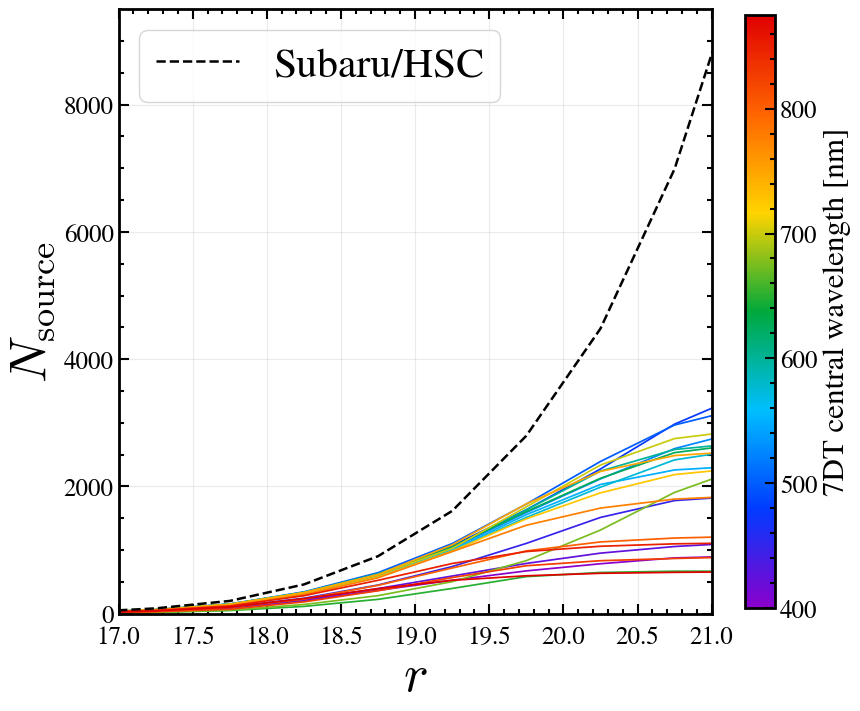

In [2]:
# Reproduce the cumulative-count panel of Proposal Figure 1.
# Preserve the original 0.5-mag threshold/bin-center display convention,
# wavelength colors, reference label, linear count scale, and 17-21 range.
with plt.rc_context():
    scl_plt.default()
    fig, ax = plt.subplots(figsize=(8.5, 7), layout='constrained')
    ax.plot(CUM_BIN_CENTERS, CUM_REFERENCE_COUNTS[1:],
            color='black', linestyle='--', linewidth=1.8,
            label='Subaru/HSC', zorder=4)
    for band, wavelength in zip(CUM_BANDS, CUM_WAVELENGTH):
        ax.plot(CUM_BIN_CENTERS, CUM_BAND_COUNTS[band][1:],
                linewidth=1.25, color=CUM_CMAP(CUM_NORM(wavelength)))
    ax.set_xlabel(r'$r$', fontsize=22 * 1.7)
    ax.set_ylabel(r'$N_{\mathrm{source}}$', fontsize=22 * 1.7)
    ax.tick_params(axis='both', labelsize=18)
    ax.set_xlim(17, 21)
    ax.set_xticks(np.arange(17, 21.1, 0.5))
    visible = (CUM_BIN_CENTERS >= 17) & (CUM_BIN_CENTERS <= 21)
    boundary = np.interp([17, 21], CUM_BIN_CENTERS, CUM_REFERENCE_COUNTS[1:])
    visible_max = max(1, np.max(CUM_REFERENCE_COUNTS[1:][visible]), np.max(boundary))
    ax.set_ylim(0, visible_max * 1.08)
    ax.grid(alpha=0.25)
    ax.legend(loc='upper left', fontsize=30)
    mappable = plt.cm.ScalarMappable(norm=CUM_NORM, cmap=CUM_CMAP)
    colorbar = fig.colorbar(mappable, ax=ax, orientation='vertical', pad=0.02, fraction=0.05)
    colorbar.set_label('7DT central wavelength [nm]', fontsize=22.4)
    colorbar.ax.tick_params(labelsize=18)
    plt.show()
    plt.close(fig)


FINALCAT RM < 21 in COSMOS1 mask: 3,066/6,991 (43.86%).


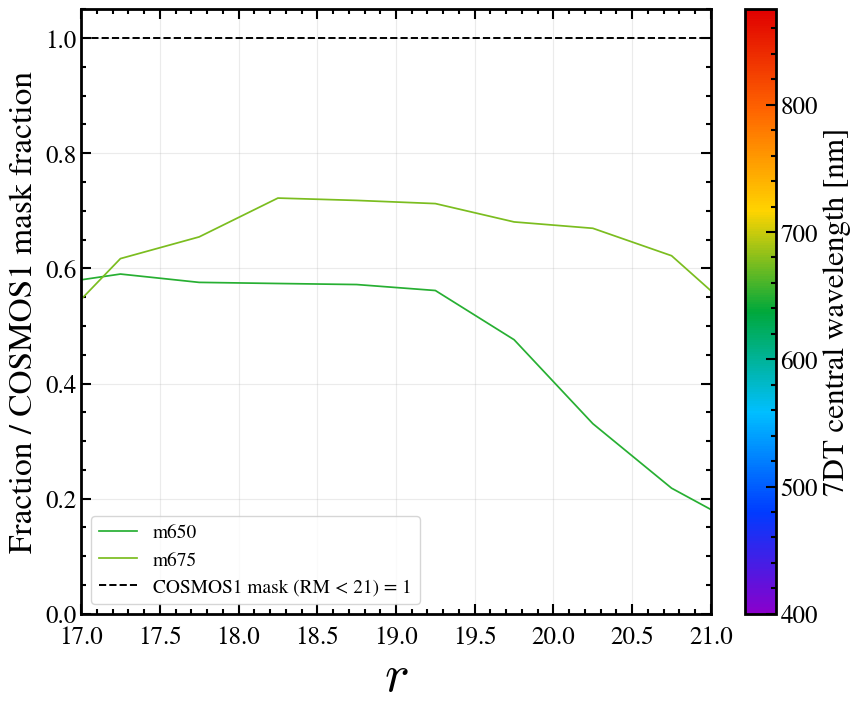

In [2]:
# Cumulative detection fraction relative to the Subaru/HSC reference counts.
# Use the same threshold counts, wavelength colors, and magnitude range as
# the Proposal-style source-count panel immediately above.
CUM_FRACTIONS = {
    band: np.divide(CUM_BAND_COUNTS[band][1:], CUM_REFERENCE_COUNTS[1:],
                    out=np.full(len(CUM_BIN_CENTERS), np.nan, dtype=float),
                    where=CUM_REFERENCE_COUNTS[1:] > 0)
    for band in CUM_BANDS
}
# Compute the geometric reference-population fraction at RM < 21.
# Both numerator and denominator use the same valid FINALCAT RM selection;
# the numerator additionally requires membership in the COSMOS1 valid mask.
# No 7DT detection or catalog matching condition enters this reference line.
from astropy.io import fits
from astropy.wcs import WCS
mask_path = CUM_ROOT / 'COSMOS_data/COSMOS1/COSMOS1_validmask.fits'
with fits.open(mask_path, memmap=True) as hdus:
    valid_mask = np.asarray(hdus[0].data, dtype=bool)
    mask_wcs = WCS(hdus[0].header)
reference_ra = np.asarray(np.ma.asarray(CUM_REFERENCE['RA'], dtype=float).filled(np.nan))
reference_dec = np.asarray(np.ma.asarray(CUM_REFERENCE['DEC'], dtype=float).filled(np.nan))
pixel_x, pixel_y = mask_wcs.world_to_pixel_values(reference_ra, reference_dec)
finite_position = np.isfinite(pixel_x) & np.isfinite(pixel_y)
pixel_ix = np.zeros(len(CUM_REFERENCE), dtype=int)
pixel_iy = np.zeros(len(CUM_REFERENCE), dtype=int)
pixel_ix[finite_position] = np.rint(pixel_x[finite_position]).astype(int)
pixel_iy[finite_position] = np.rint(pixel_y[finite_position]).astype(int)
in_image = (finite_position & (pixel_ix >= 0) & (pixel_ix < valid_mask.shape[1])
            & (pixel_iy >= 0) & (pixel_iy < valid_mask.shape[0]))
in_cosmos1_mask = np.zeros(len(CUM_REFERENCE), dtype=bool)
in_cosmos1_mask[in_image] = valid_mask[pixel_iy[in_image], pixel_ix[in_image]]
# Exclude missing/sentinel magnitudes using the same valid-RM convention
# as the Proposal count plot, then apply the requested strict RM < 21 cut.
bright_reference = CUM_REF_VALID & (CUM_REF_RM < 21)
cosmos1_mask_denominator = int(bright_reference.sum())
cosmos1_mask_n_reference = int((bright_reference & in_cosmos1_mask).sum())
cosmos1_mask_fraction = cosmos1_mask_n_reference / cosmos1_mask_denominator
print(f'FINALCAT RM < 21 in COSMOS1 mask: '
      f'{cosmos1_mask_n_reference:,}/{cosmos1_mask_denominator:,} '
      f'({cosmos1_mask_fraction:.2%}).')

# Normalize the existing cumulative fractions by the fixed COSMOS1 mask
# fraction at RM < 21, so the reference dashed line is exactly one.
# This is a fixed rescaling of the previous curves, not a magnitude-dependent
# in-mask recovery estimate (which would require a new denominator per bin).
CUM_MASK_NORMALIZED = {
    band: CUM_FRACTIONS[band] / cosmos1_mask_fraction
    for band in ('m650', 'm675')
}

with plt.rc_context():
    scl_plt.default()
    fig, ax = plt.subplots(figsize=(8.5, 7), layout='constrained')
    PLOT_BANDS = ('m650', 'm675')
    plot_wavelengths = np.array([int(band[1:]) for band in PLOT_BANDS], dtype=float)
    for band, wavelength in zip(PLOT_BANDS, plot_wavelengths):
        ax.plot(CUM_BIN_CENTERS, CUM_MASK_NORMALIZED[band], linewidth=1.25,
                color=CUM_CMAP(CUM_NORM(wavelength)), label=band)
    ax.axhline(1.0, color='black', linestyle='--', linewidth=1.4,
               label='COSMOS1 mask (RM < 21) = 1')
    ax.legend(loc='best', fontsize=14)
    ax.set_xlabel(r'$r$', fontsize=22 * 1.7)
    ax.set_ylabel('Fraction / COSMOS1 mask fraction', fontsize=24)
    ax.tick_params(axis='both', labelsize=18)
    ax.set_xlim(17, 21)
    ax.set_xticks(np.arange(17, 21.1, 0.5))
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.25)
    mappable = plt.cm.ScalarMappable(norm=CUM_NORM, cmap=CUM_CMAP)
    colorbar = fig.colorbar(mappable, ax=ax, orientation='vertical', pad=0.02, fraction=0.05)
    colorbar.set_label('7DT central wavelength [nm]', fontsize=22.4)
    colorbar.ax.tick_params(labelsize=18)
    plt.show()
    plt.close(fig)


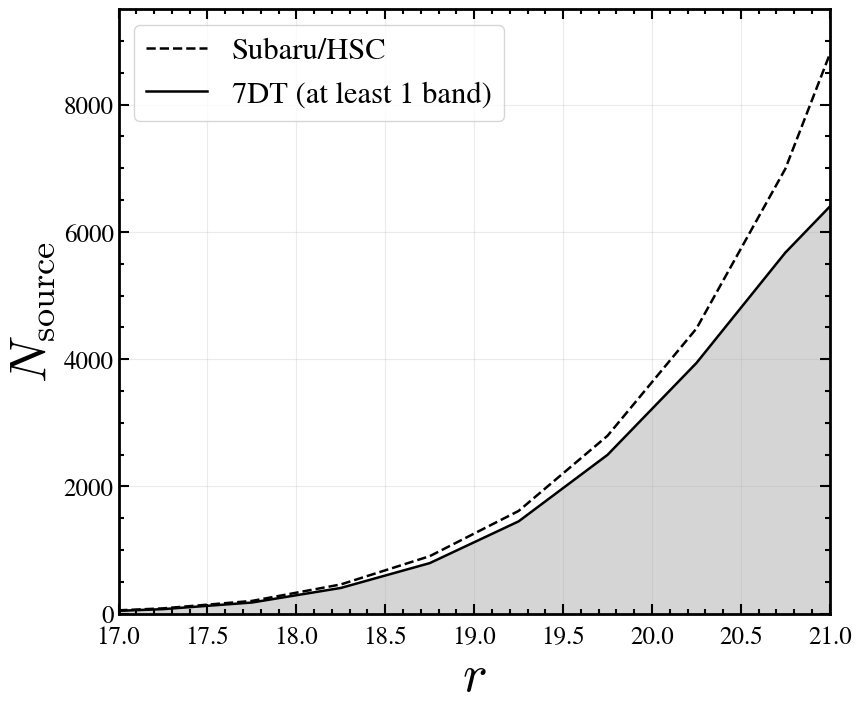

In [4]:
# Count a FINALCAT object once if any field has a retained detection in
# at least one band. Field-local source IDs are never compared across fields;
# the combined baseline already has one row per unique finalcat_idx.
# Restore packed masks before reading source IDs, including absent bands.
ANY_DETECTED = np.zeros(len(CUM_CATALOG), dtype=bool)
for field in CUM_FIELDS:
    prefix = f'7dt_cosmos{field}_'
    matched = cumulative_catalog_values(prefix + 'matched', fill=0).astype(bool)
    for band in CUM_BANDS:
        source_id = cumulative_catalog_values(prefix + band + '_source_id', fill=-1)
        ANY_DETECTED |= matched & (source_id >= 0)

# Preserve the Proposal's 0.5-mag cumulative thresholds and bin-center
# display. Include brighter sources before cropping the displayed r range.
# Require valid FINALCAT RM for both curves; impose no extra 7DT S/N cut.
ANY_DETECTED_COUNTS = cumulative_rm_counts(CUM_RM[ANY_DETECTED & CUM_VALID])
with plt.rc_context():
    scl_plt.default()
    fig, ax = plt.subplots(figsize=(8.5, 7), layout='constrained')
    ax.fill_between(CUM_BIN_CENTERS, 0, ANY_DETECTED_COUNTS[1:],
                    color='0.75', alpha=0.65, linewidth=0, zorder=1)
    ax.plot(CUM_BIN_CENTERS, CUM_REFERENCE_COUNTS[1:],
            color='black', linestyle='--', linewidth=1.8,
            label='Subaru/HSC', zorder=3)
    ax.plot(CUM_BIN_CENTERS, ANY_DETECTED_COUNTS[1:],
            color='black', linestyle='-', linewidth=1.8,
            label='7DT (at least 1 band)', zorder=4)
    ax.set_xlabel(r'$r$', fontsize=22 * 1.7)
    ax.set_ylabel(r'$N_{\mathrm{source}}$', fontsize=22 * 1.7)
    ax.tick_params(axis='both', labelsize=18)
    ax.set_xlim(17, 21)
    ax.set_xticks(np.arange(17, 21.1, 0.5))
    visible = (CUM_BIN_CENTERS >= 17) & (CUM_BIN_CENTERS <= 21)
    boundary = np.interp([17, 21], CUM_BIN_CENTERS, CUM_REFERENCE_COUNTS[1:])
    visible_max = max(1, np.max(CUM_REFERENCE_COUNTS[1:][visible]), np.max(boundary))
    ax.set_ylim(0, visible_max * 1.08)
    ax.grid(alpha=0.25)
    ax.legend(loc='upper left', fontsize=22)
    plt.show()
    plt.close(fig)


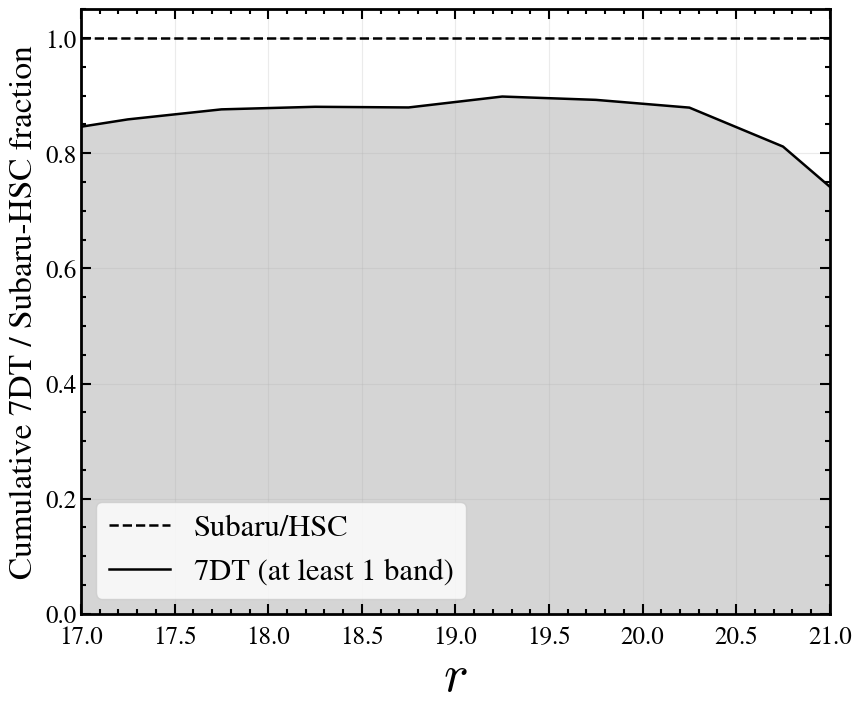

In [5]:
# Fraction of the Subaru/HSC cumulative reference count detected in at
# least one 7DT band, using the union from the preceding count comparison.
# Both counts use identical RM thresholds; empty reference bins remain NaN.
ANY_DETECTED_FRACTION = np.divide(
    ANY_DETECTED_COUNTS[1:], CUM_REFERENCE_COUNTS[1:],
    out=np.full(len(CUM_BIN_CENTERS), np.nan, dtype=float),
    where=CUM_REFERENCE_COUNTS[1:] > 0,
)
with plt.rc_context():
    scl_plt.default()
    fig, ax = plt.subplots(figsize=(8.5, 7), layout='constrained')
    ax.fill_between(CUM_BIN_CENTERS, 0, ANY_DETECTED_FRACTION,
                    color='0.75', alpha=0.65, linewidth=0, zorder=1)
    ax.axhline(1.0, color='black', linestyle='--', linewidth=1.8,
               label='Subaru/HSC', zorder=3)
    ax.plot(CUM_BIN_CENTERS, ANY_DETECTED_FRACTION,
            color='black', linestyle='-', linewidth=1.8,
            label='7DT (at least 1 band)', zorder=4)
    ax.set_xlabel(r'$r$', fontsize=22 * 1.7)
    ax.set_ylabel('Cumulative 7DT / Subaru-HSC fraction', fontsize=24)
    ax.tick_params(axis='both', labelsize=18)
    ax.set_xlim(17, 21)
    ax.set_xticks(np.arange(17, 21.1, 0.5))
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.25)
    ax.legend(loc='lower left', fontsize=22)
    plt.show()
    plt.close(fig)


COSMOS1 baseline master_id=9559, finalcat_idx=93462, RM=18.385
Detected bands: m475, m500, m525, m575, m625, m675, m725, m875


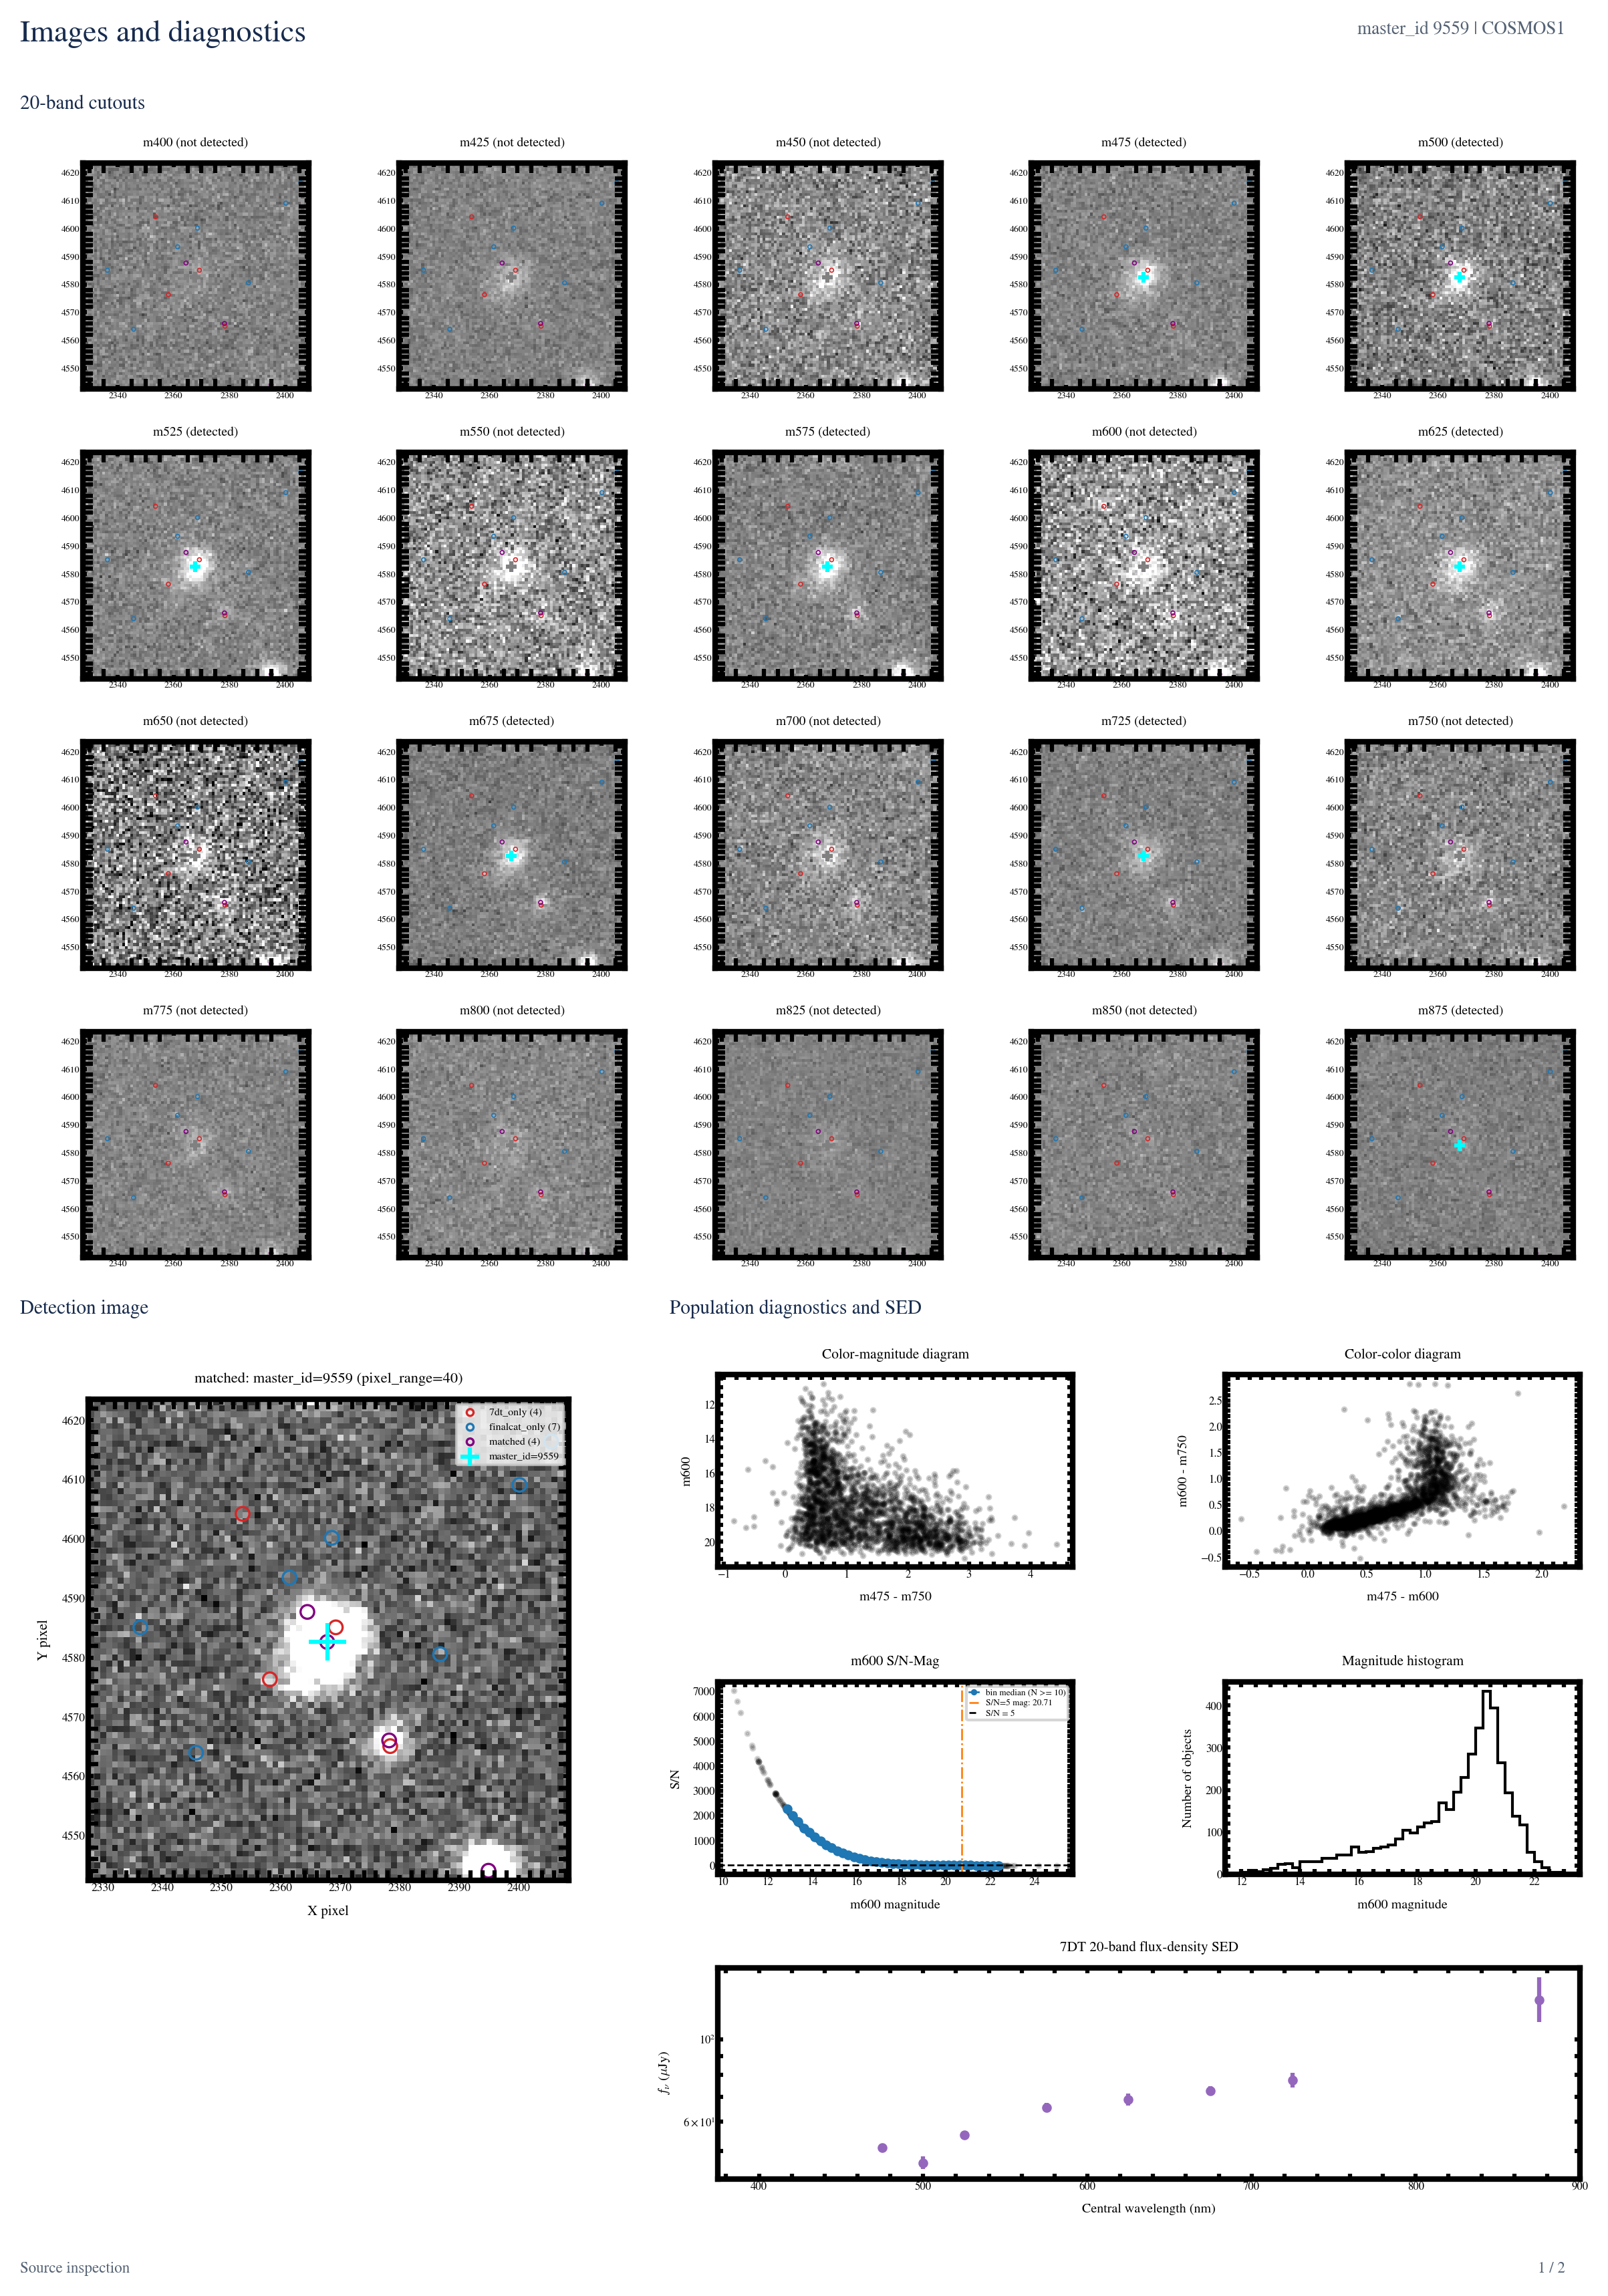

In [6]:
import sys
from IPython.display import display
from matplotlib_inline.backend_inline import set_matplotlib_formats
# Keep a sharp vector representation for notebook zoom, plus an inline PNG
# fallback. These formats are embedded in notebook output, not figure files.
set_matplotlib_formats('png')
if str(CUM_ROOT / 'Notebooks') not in sys.path:
    sys.path.insert(0, str(CUM_ROOT / 'Notebooks'))
# This is the same shared implementation called by plot_SourceInfoFromCatalog
# in notebooks 2.2 and 2.3; preserve its image cutouts and source annotations.
from sourceinfo_report import plot_source_info

example_field = 1  # COSMOS1 has science images in all 20 bands.
example_population = Table.read(BASELINE / 'cosmos1_master_catalog.fits')
example_bands = str(example_population.meta['ACTBANDS']).split(',')
example_detected = np.column_stack([
    np.asarray(np.ma.filled(example_population[band + '_source_id'], -1)) >= 0
    for band in example_bands
])
example_valid_photometry = np.column_stack([
    np.asarray(np.isfinite(np.ma.filled(example_population[band + '_mag'], np.nan)))
    & np.asarray(np.isfinite(np.ma.filled(example_population[band + '_mag_err'], np.nan)))
    & (np.asarray(np.ma.filled(example_population[band + '_mag_err'], np.nan)) > 0)
    for band in example_bands
])
example_rm = np.asarray(np.ma.filled(example_population['finalcat_RM'], np.nan), dtype=float)
# Require exactly eight detections with usable magnitude uncertainties. Choose
# one reference match with 18 <= RM < 18.5, closest to RM = 18.25,
# for a deterministic example in the requested magnitude interval;
# this is an illustrative example, not an extra cut on the recovery plots.
example_candidates = np.flatnonzero(
    (example_detected.sum(axis=1) == 8)
    & ((example_detected & example_valid_photometry).sum(axis=1) == 8)
    & np.asarray(example_population['has_finalcat'], dtype=bool)
    & np.isfinite(example_rm) & (example_rm >= 18) & (example_rm < 18.5)
)
if not len(example_candidates):
    raise ValueError('No eight-band example with 18 <= RM < 18.5 in COSMOS1.')
example_indices = [example_candidates[np.argmin(np.abs(example_rm[example_candidates] - 18.25))]]
for example_index in example_indices:
    example_id = int(example_population['master_id'][example_index])
    print(f'COSMOS1 baseline master_id={example_id}, '
          f'finalcat_idx={int(example_population["finalcat_idx"][example_index])}, '
          f'RM={example_rm[example_index]:.3f}')
    print('Detected bands:', ', '.join(np.asarray(example_bands)[example_detected[example_index]]))
    
    scl_plt.default()
    # Reuse the original report method without exporting a PDF. The first report
    # page contains the detection image and all 20 band cutouts, including bands
    # without catalog detections; show that page directly in the notebook.
    example_report = plot_source_info(
        example_population, source_id=example_id, pixel_range=40,
        population_catalog=example_population, project_root=CUM_ROOT,
        field=example_field, show=False, save_pdf=False,
    )
    
    # Preserve the shared method's complete report, including its embedded SED.
    report_figure = example_report['report_figures'][0]
    # High-resolution PNG fallback and SVG are embedded in notebook output.
    report_figure.set_dpi(300)
    display(report_figure)


COSMOS1 flagcut removed: master_id=7085, finalcat_idx=93462, detected bands=19


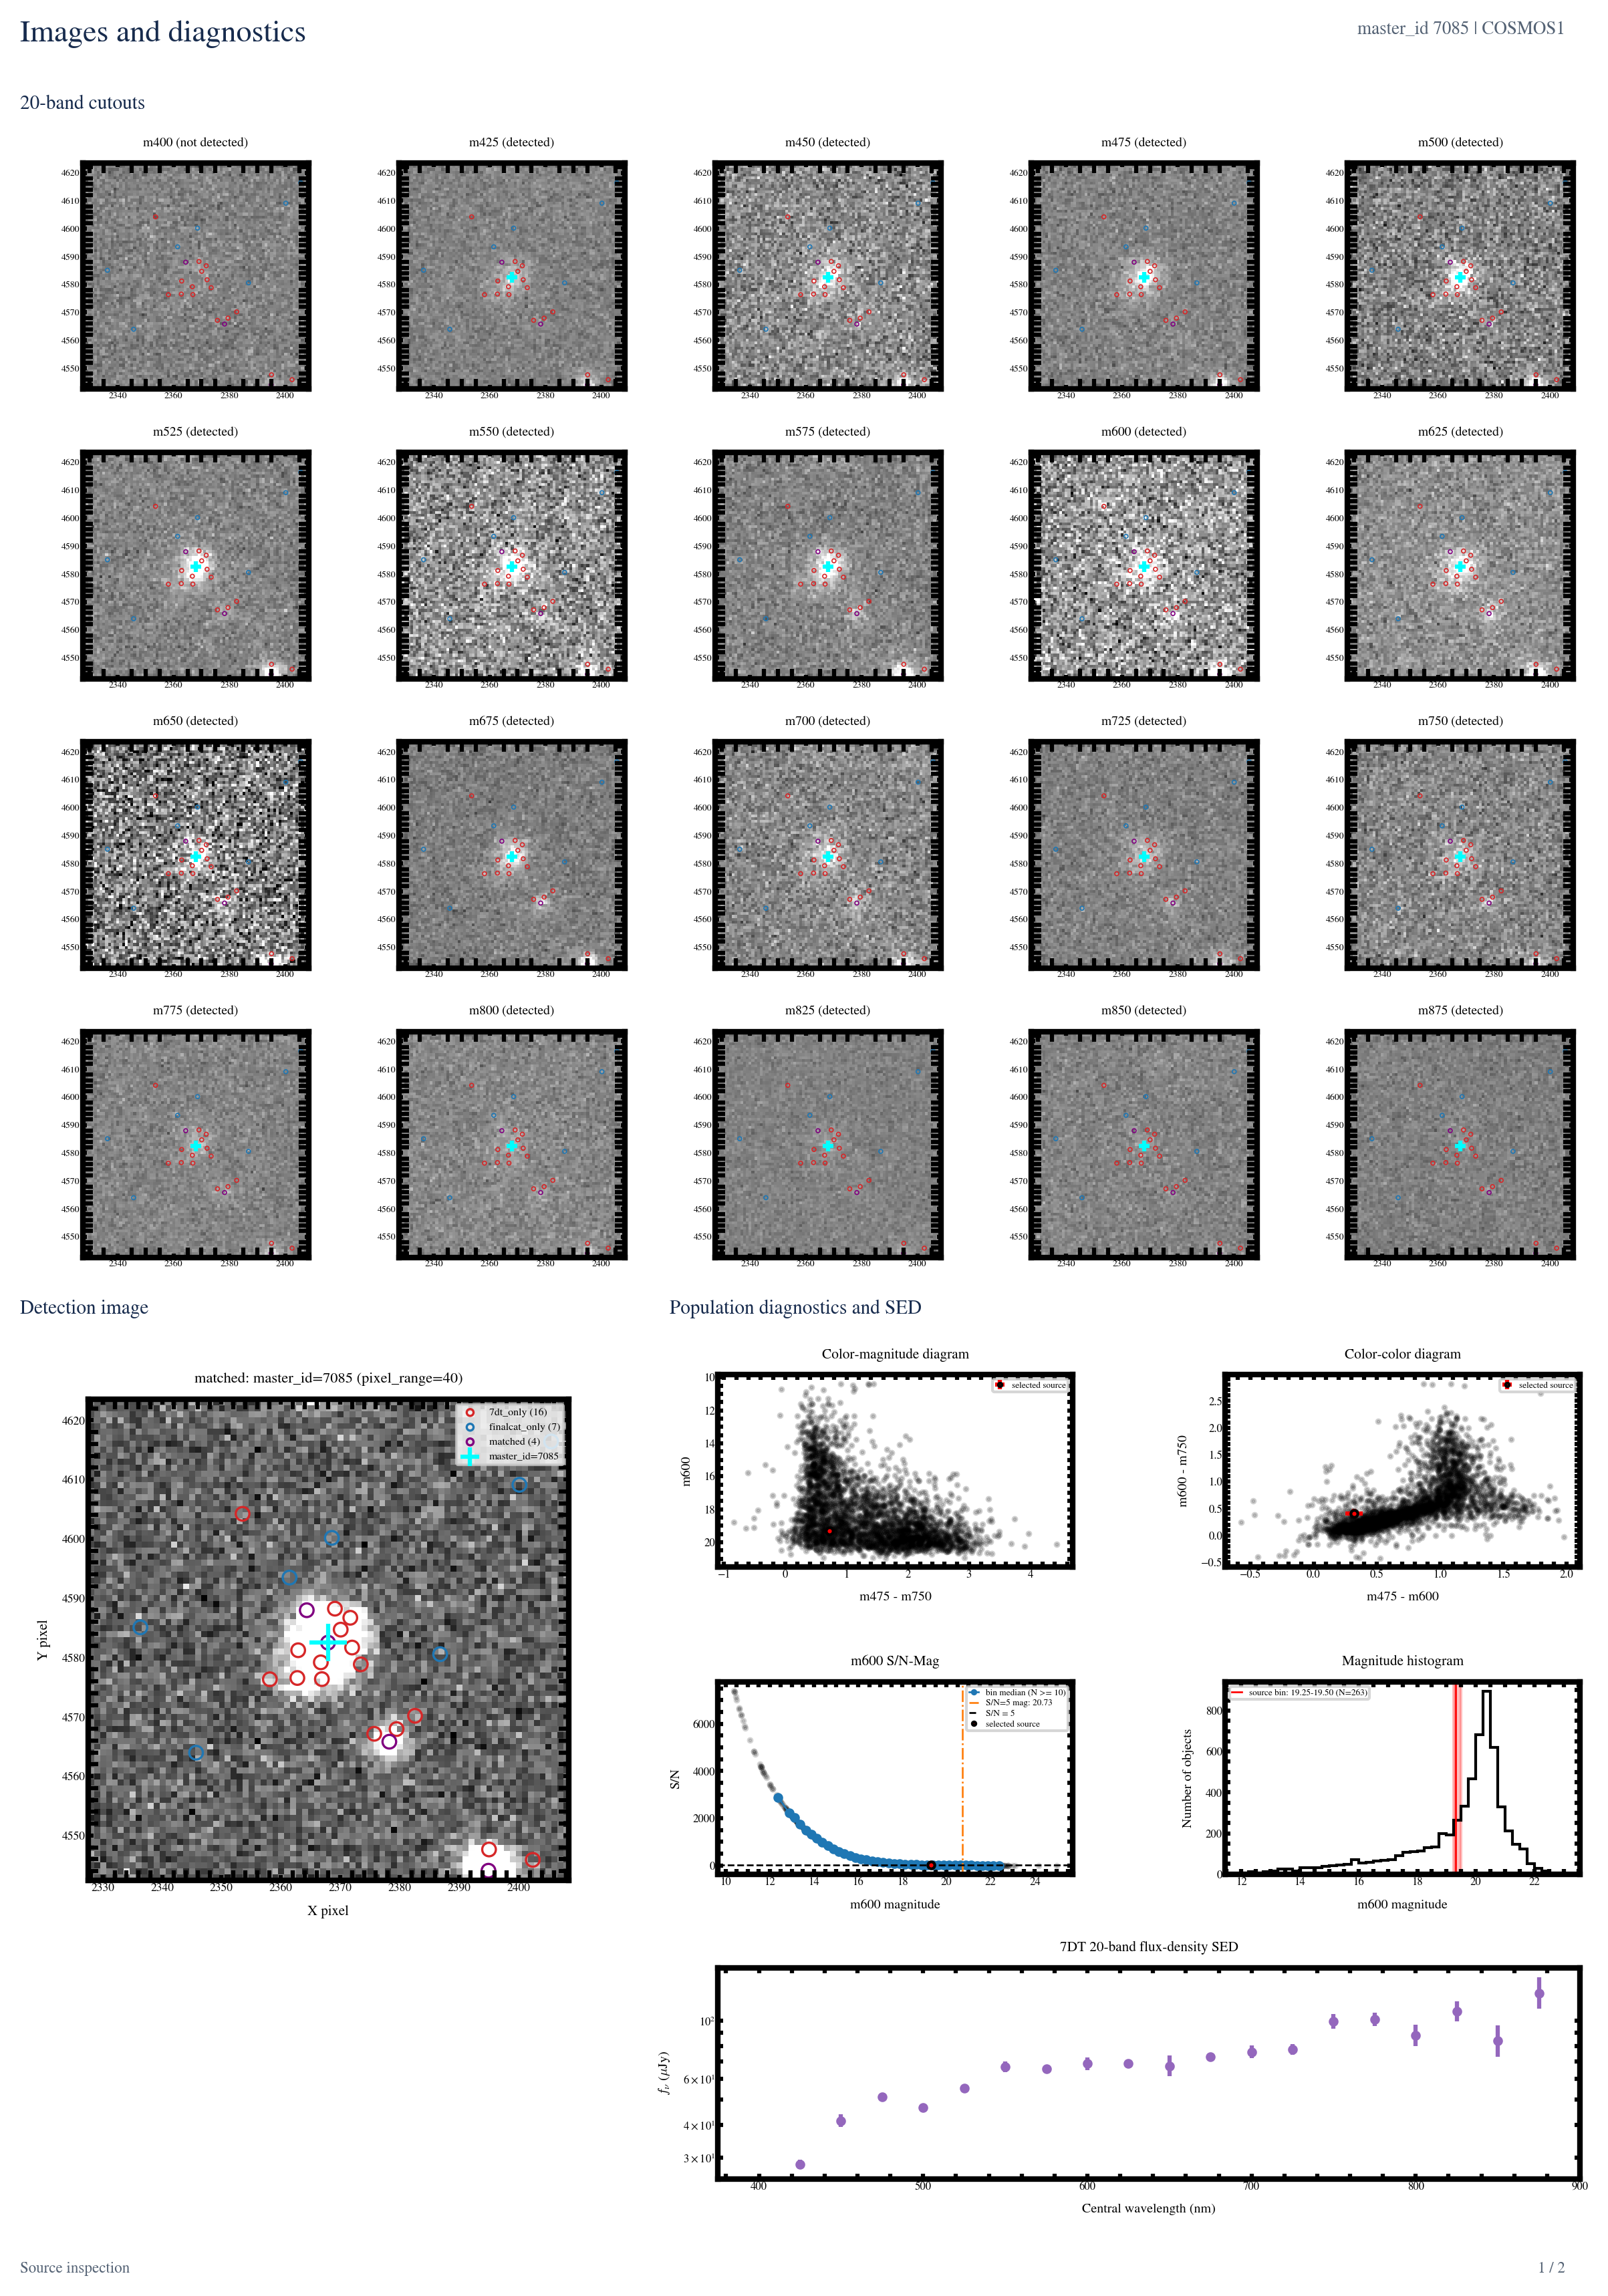

In [7]:
# Inspect the same FINALCAT object in the current flag-cut-removed master.
# Field-local master IDs change when catalogs are rebuilt; finalcat_idx is the
# stable reference-row key. Check all eight original raw detections as well.
no_flagcut_population = Table.read(
    CUM_ROOT / 'output/COSMOS1/singlephot/cosmos1_master_catalog.fits'
)
no_flagcut_reference_indices = np.asarray(
    np.ma.filled(no_flagcut_population['finalcat_idx'], -1), dtype=int
)
no_flagcut_matches = np.flatnonzero(no_flagcut_reference_indices == 93462)
if len(no_flagcut_matches) != 1:
    raise ValueError('Expected exactly one COSMOS1 row for finalcat_idx=93462.')
no_flagcut_row = no_flagcut_population[int(no_flagcut_matches[0])]
no_flagcut_id = int(no_flagcut_row['master_id'])
baseline_row = example_population[np.flatnonzero(np.asarray(example_population['master_id']) == 9559)[0]]
for band in example_bands:
    old_id = baseline_row[band + '_source_id']
    if not np.ma.is_masked(old_id) and int(old_id) >= 0:
        if (np.ma.is_masked(no_flagcut_row[band + '_source_id'])
                or int(no_flagcut_row[band + '_source_id']) != int(old_id)):
            raise ValueError(f'{band}: the original raw detection was not retained.')
print(f'COSMOS1 flagcut removed: master_id={no_flagcut_id}, '
      f'finalcat_idx=93462, detected bands={int(no_flagcut_row["n_7dt_bands"])}')

scl_plt.default()
no_flagcut_report = plot_source_info(
    no_flagcut_population, source_id=no_flagcut_id, pixel_range=40,
    population_catalog=no_flagcut_population, project_root=CUM_ROOT,
    field=1, show=False, save_pdf=False,
)
# Reuse the complete original image/diagnostics page, including its embedded
# SED. Only the separate standalone SED plot is omitted.
no_flagcut_figure = no_flagcut_report['report_figures'][0]
no_flagcut_figure.set_dpi(300)
display(no_flagcut_figure)


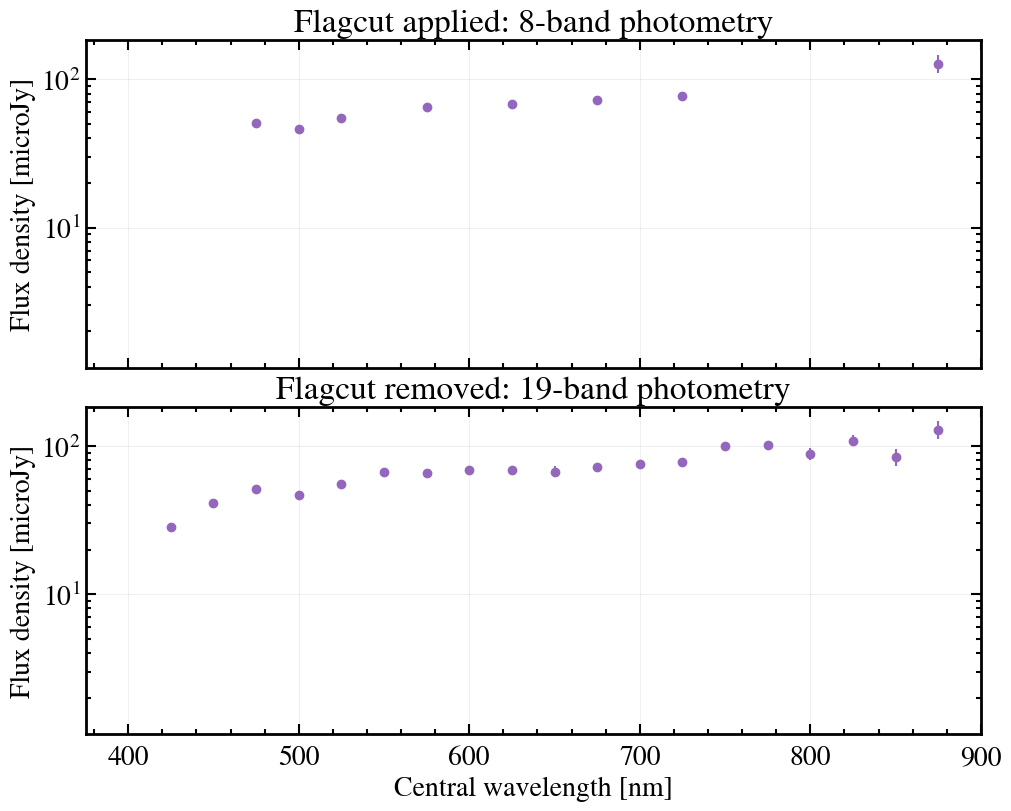

In [8]:
# Compare the same FINALCAT source before and after removing the aperture flag cut.
# Reuse the SED flux conversion and asymmetric magnitude-error propagation
# from sourceinfo_report; keep identical axes for a direct visual comparison.
before_sed_table = example_report['band_table']
after_sed_table = no_flagcut_report['band_table']
before_mags = np.asarray(before_sed_table['mag'], dtype=float)
before_errors = np.asarray(before_sed_table['mag_err'], dtype=float)
after_mags = np.asarray(after_sed_table['mag'], dtype=float)
after_errors = np.asarray(after_sed_table['mag_err'], dtype=float)
before_flux = 3631.0e6 * 10.0 ** (-0.4 * before_mags)
before_faint_flux = 3631.0e6 * 10.0 ** (-0.4 * (before_mags + before_errors))
before_bright_flux = 3631.0e6 * 10.0 ** (-0.4 * (before_mags - before_errors))
after_flux = 3631.0e6 * 10.0 ** (-0.4 * after_mags)
after_faint_flux = 3631.0e6 * 10.0 ** (-0.4 * (after_mags + after_errors))
after_bright_flux = 3631.0e6 * 10.0 ** (-0.4 * (after_mags - after_errors))
before_detected = (np.asarray(before_sed_table['detected'], dtype=bool)
                   & np.isfinite(before_mags) & np.isfinite(before_errors) & (before_errors > 0))
after_detected = (np.asarray(after_sed_table['detected'], dtype=bool)
                  & np.isfinite(after_mags) & np.isfinite(after_errors) & (after_errors > 0))
sed_wavelengths = np.asarray(before_sed_table['wavelength_nm'], dtype=float)
with plt.rc_context():
    scl_plt.default()
    fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True, sharey=True,
                             layout='constrained')
    for ax, values, faint, bright, selected, panel_label in (
        (axes[0], before_flux, before_faint_flux, before_bright_flux,
         before_detected, 'Flagcut applied'),
        (axes[1], after_flux, after_faint_flux, after_bright_flux,
         after_detected, 'Flagcut removed'),
    ):
        errors = np.vstack((values - faint, bright - values))
        ax.errorbar(sed_wavelengths[selected], values[selected],
                    yerr=errors[:, selected], fmt='o', color='tab:purple')
        ax.set_yscale('log')
        ax.set_xlim(375, 900)
        ax.set_ylabel('Flux density [microJy]')
        ax.set_title(f'{panel_label}: {int(selected.sum())}-band photometry')
        ax.grid(alpha=0.2)
    axes[1].set_xlabel('Central wavelength [nm]')
    plt.show()
    plt.close(fig)


In [2]:
# Compare the promoted no-flag-cut product with the archived Flagcut baseline.
# Preserve the reference population, saved per-band success definition, field
# union, RM thresholds, and Proposal bin-center display convention above.
from matplotlib_inline.backend_inline import set_matplotlib_formats
from matplotlib.lines import Line2D
set_matplotlib_formats('png')
NOFLAG_PATH = CUM_ROOT / 'output/singlephot/master_catalog_MatchedWithFianlcat_OverallCosmosField.fits'
NOFLAG_CATALOG = Table.read(NOFLAG_PATH, hdu='CATALOG')
with fits.open(NOFLAG_PATH, memmap=False) as hdus:
    NOFLAG_PACKED_MASKS = np.array(hdus['COLUMN_MASKS'].data, copy=True)
    NOFLAG_BITORDER = hdus['COLUMN_MASKS'].header['BITORDER']
NOFLAG_COLUMN_INDEX = {name: i for i, name in enumerate(NOFLAG_CATALOG.colnames)}


def noflag_catalog_values(name, fill=np.nan):
    """Restore the exact production mask, including masked Boolean columns."""
    index = NOFLAG_COLUMN_INDEX[name]
    bit = index % 8 if NOFLAG_BITORDER == 'little' else 7 - index % 8
    masked = ((NOFLAG_PACKED_MASKS[:, index // 8] >> bit) & 1).astype(bool)
    values = np.asarray(NOFLAG_CATALOG[name], dtype=float).copy()
    values[masked | np.ma.getmaskarray(NOFLAG_CATALOG[name])] = fill
    return values


NOFLAG_RM = noflag_catalog_values('finalcat_RM')
NOFLAG_VALID = np.isfinite(NOFLAG_RM) & (NOFLAG_RM > 0) & (NOFLAG_RM < 50)
# Join/check by stable FINALCAT row index; rebuilt field/master IDs can change.
BASELINE_REFERENCE_IDS = cumulative_catalog_values('finalcat_idx', fill=-1).astype(int)
NOFLAG_REFERENCE_IDS = noflag_catalog_values('finalcat_idx', fill=-1).astype(int)
assert np.all(BASELINE_REFERENCE_IDS >= 0) and np.all(NOFLAG_REFERENCE_IDS >= 0)
assert len(np.unique(BASELINE_REFERENCE_IDS)) == len(BASELINE_REFERENCE_IDS)
assert len(np.unique(NOFLAG_REFERENCE_IDS)) == len(NOFLAG_REFERENCE_IDS)
# Rebuilt matching can change reference assignments; do not assume a superset.
REMOVED_REFERENCE_IDS = np.setdiff1d(BASELINE_REFERENCE_IDS, NOFLAG_REFERENCE_IDS)
print(f'Baseline reference IDs absent from rebuilt current catalog: {len(REMOVED_REFERENCE_IDS)}')
np.testing.assert_allclose(NOFLAG_RM, CUM_REF_RM[NOFLAG_REFERENCE_IDS], equal_nan=True)
np.testing.assert_allclose(CUM_RM, CUM_REF_RM[BASELINE_REFERENCE_IDS], equal_nan=True)
NOFLAG_BAND_COUNTS = {}
NOFLAG_BAND_SUCCESS = {}
BASELINE_BAND_SUCCESS = {}
for band in CUM_BANDS:
    current_success = np.zeros(len(NOFLAG_CATALOG), dtype=bool)
    baseline_success = np.zeros(len(CUM_CATALOG), dtype=bool)
    for field in CUM_FIELDS:
        prefix = f'7dt_cosmos{field}_'
        # A successful retained measurement has source_id >= 0, valid magnitude,
        # and finite positive magnitude uncertainty, exactly as in the baseline.
        current_success |= (noflag_catalog_values(prefix + 'matched', fill=0).astype(bool)
                            & noflag_catalog_values(prefix + band + '_success', fill=0).astype(bool))
        baseline_success |= (cumulative_catalog_values(prefix + 'matched', fill=0).astype(bool)
                             & cumulative_catalog_values(prefix + band + '_success', fill=0).astype(bool))
    # Compare the saved catalog versions directly. Rebuilding associations can
    # lose old reference matches as well as gain newly retained measurements.
    NOFLAG_BAND_SUCCESS[band] = current_success
    BASELINE_BAND_SUCCESS[band] = baseline_success
    NOFLAG_BAND_COUNTS[band] = cumulative_rm_counts(NOFLAG_RM[current_success & NOFLAG_VALID])

NOFLAG_FRACTIONS = {
    band: np.divide(NOFLAG_BAND_COUNTS[band][1:], CUM_REFERENCE_COUNTS[1:],
                    out=np.full(len(CUM_BIN_CENTERS), np.nan),
                    where=CUM_REFERENCE_COUNTS[1:] > 0)
    for band in CUM_BANDS
}
# Rank by absolute coverage-fraction gain at strict RM < 21, using a common
# reference denominator. Percentage-point gain avoids selecting bands merely
# because they started from a very small baseline. Report relative gain too.
GAIN_REFERENCE_N = int((CUM_REF_VALID & (CUM_REF_RM < 21)).sum())
GAIN_ROWS = []
for band in CUM_BANDS:
    old_n = int((BASELINE_BAND_SUCCESS[band] & CUM_VALID & (CUM_RM < 21)).sum())
    new_n = int((NOFLAG_BAND_SUCCESS[band] & NOFLAG_VALID & (NOFLAG_RM < 21)).sum())
    old_fraction, new_fraction = old_n / GAIN_REFERENCE_N, new_n / GAIN_REFERENCE_N
    GAIN_ROWS.append((band, old_n, new_n, old_fraction, new_fraction,
                      100 * (new_fraction - old_fraction),
                      100 * (new_n / old_n - 1) if old_n else np.nan))
COVERAGE_GAIN_TABLE = Table(rows=GAIN_ROWS, names=[
    'band', 'N_Flagcut', 'N_no_Flagcut', 'fraction_Flagcut',
    'fraction_no_Flagcut', 'gain_percentage_points', 'relative_gain_percent'])
COVERAGE_GAIN_TABLE.sort('gain_percentage_points', reverse=True)
GAIN_BANDS = tuple(str(band) for band in COVERAGE_GAIN_TABLE['band'][:2])
print(f'RM < 21 reference denominator: {GAIN_REFERENCE_N:,}; '
      'top two bands ranked by coverage gain in percentage points:')
for row in COVERAGE_GAIN_TABLE[:2]:
    print(f"{row['band']}: {row['fraction_Flagcut']:.2%} -> "
          f"{row['fraction_no_Flagcut']:.2%}; "
          f"+{row['gain_percentage_points']:.2f} percentage points "
          f"(+{row['relative_gain_percent']:.1f}% relative)")


Baseline reference IDs absent from rebuilt current catalog: 197
RM < 21 reference denominator: 6,991; top two bands ranked by coverage gain in percentage points:
m475: 42.63% -> 61.26%; +18.64 percentage points (+43.7% relative)
m575: 34.59% -> 51.81%; +17.22 percentage points (+49.8% relative)


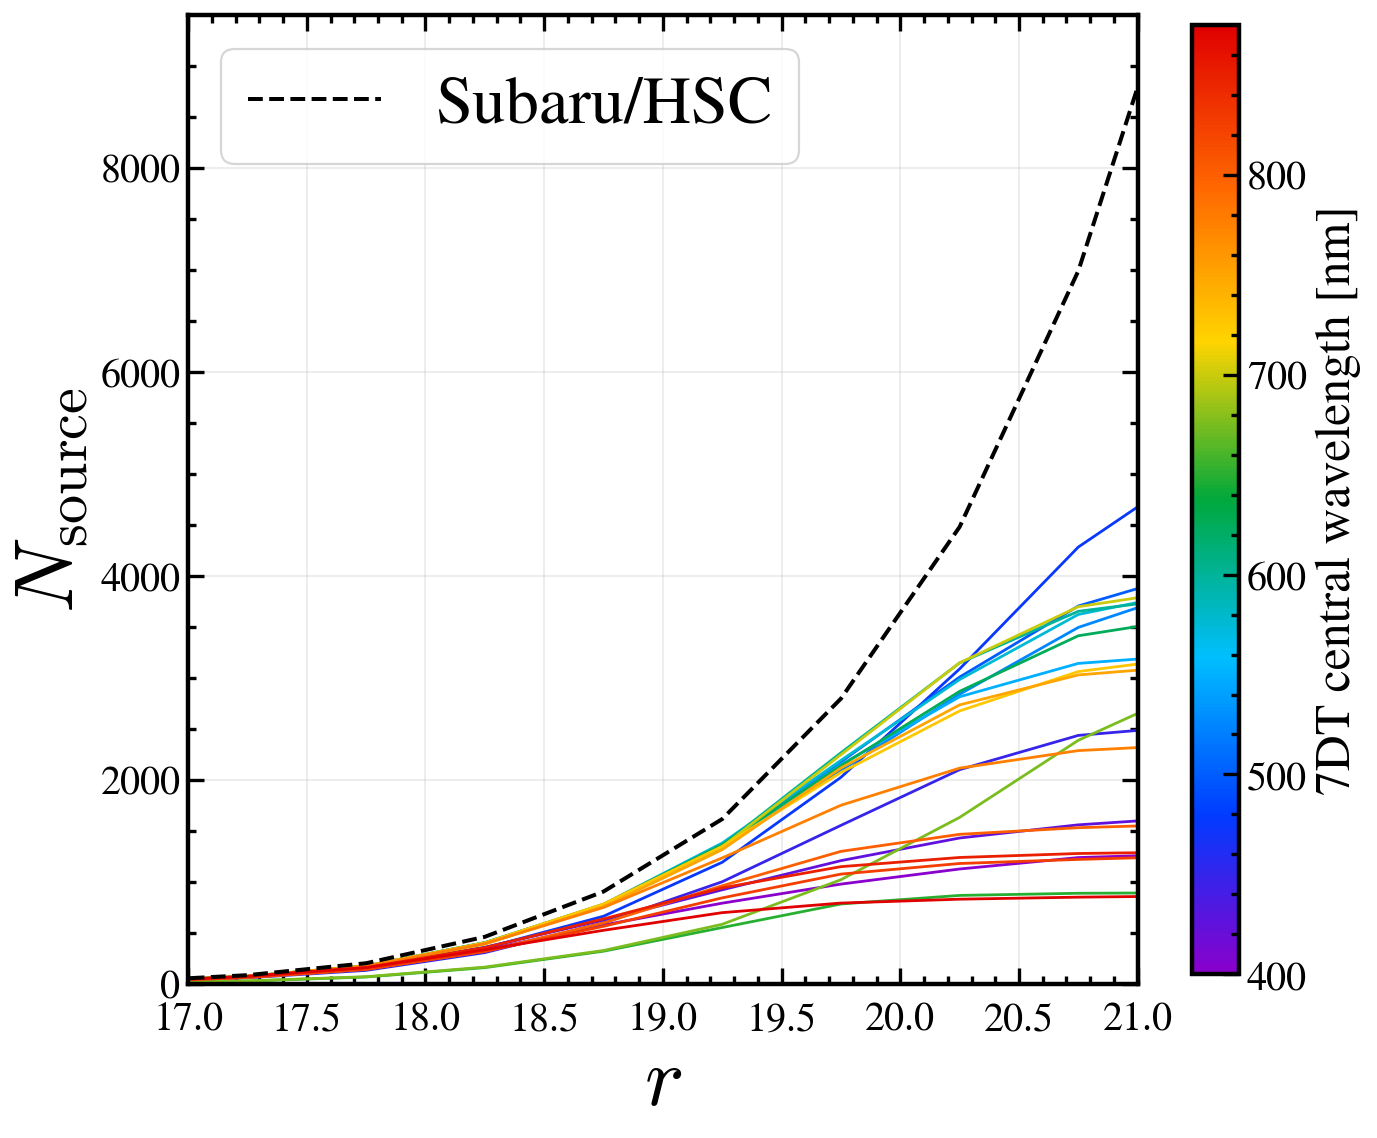

In [10]:
# Current no-Flagcut 20-band counts in the same Proposal format.
# Preserve the original 0.5-mag threshold/bin-center display convention,
# wavelength colors, reference label, linear count scale, and 17-21 range.
with plt.rc_context():
    scl_plt.default()
    plt.rcParams['figure.dpi'] = 160
    fig, ax = plt.subplots(figsize=(8.5, 7), layout='constrained')
    ax.plot(CUM_BIN_CENTERS, CUM_REFERENCE_COUNTS[1:],
            color='black', linestyle='--', linewidth=1.8,
            label='Subaru/HSC', zorder=4)
    for band, wavelength in zip(CUM_BANDS, CUM_WAVELENGTH):
        ax.plot(CUM_BIN_CENTERS, NOFLAG_BAND_COUNTS[band][1:],
                linewidth=1.25, color=CUM_CMAP(CUM_NORM(wavelength)))
    ax.set_xlabel(r'$r$', fontsize=22 * 1.7)
    ax.set_ylabel(r'$N_{\mathrm{source}}$', fontsize=22 * 1.7)
    ax.tick_params(axis='both', labelsize=18)
    ax.set_xlim(17, 21)
    ax.set_xticks(np.arange(17, 21.1, 0.5))
    visible = (CUM_BIN_CENTERS >= 17) & (CUM_BIN_CENTERS <= 21)
    boundary = np.interp([17, 21], CUM_BIN_CENTERS, CUM_REFERENCE_COUNTS[1:])
    visible_max = max(1, np.max(CUM_REFERENCE_COUNTS[1:][visible]), np.max(boundary))
    ax.set_ylim(0, visible_max * 1.08)
    ax.grid(alpha=0.25)
    ax.legend(loc='upper left', fontsize=30)
    mappable = plt.cm.ScalarMappable(norm=CUM_NORM, cmap=CUM_CMAP)
    colorbar = fig.colorbar(mappable, ax=ax, orientation='vertical', pad=0.02, fraction=0.05)
    colorbar.set_label('7DT central wavelength [nm]', fontsize=22.4)
    colorbar.ax.tick_params(labelsize=18)
    plt.show()
    plt.close(fig)


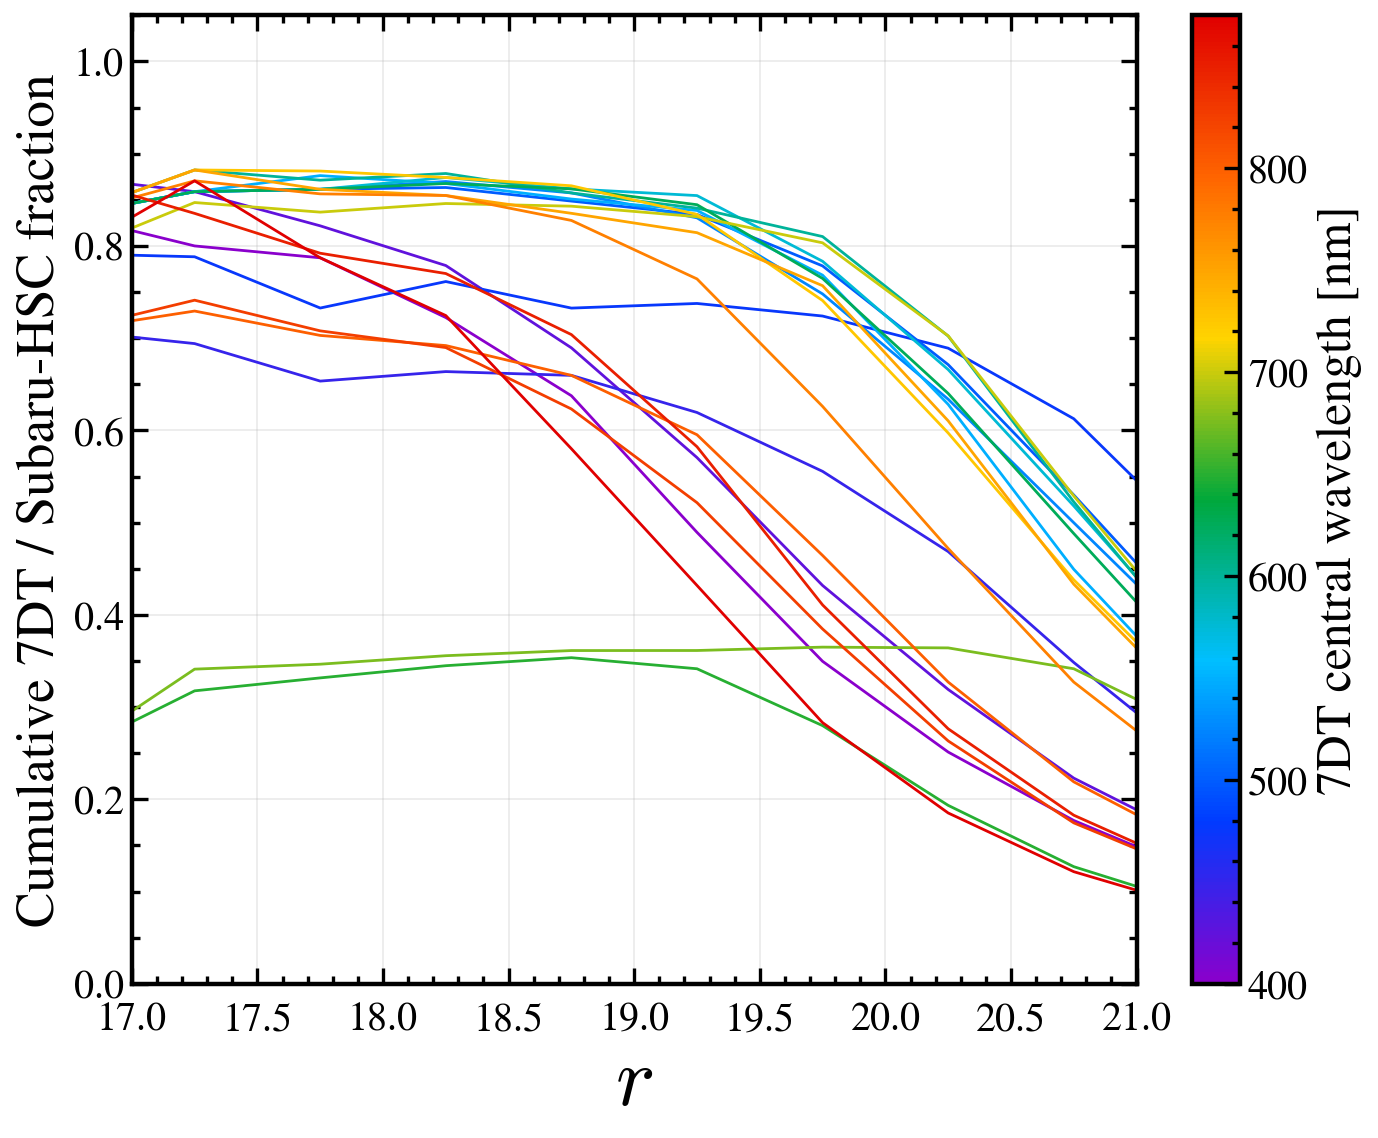

In [11]:
# All 20 current coverage fractions share the original Subaru/HSC denominator.
# The fixed COSMOS1 mask normalization used earlier is not applied here.
with plt.rc_context():
    scl_plt.default()
    plt.rcParams['figure.dpi'] = 160
    fig, ax = plt.subplots(figsize=(8.5, 7), layout='constrained')
    for band, wavelength in zip(CUM_BANDS, CUM_WAVELENGTH):
        ax.plot(CUM_BIN_CENTERS, NOFLAG_FRACTIONS[band],
                linewidth=1.25, color=CUM_CMAP(CUM_NORM(wavelength)))
    ax.set_xlabel(r'$r$', fontsize=22 * 1.7)
    ax.set_ylabel('Cumulative 7DT / Subaru-HSC fraction', fontsize=24)
    ax.tick_params(axis='both', labelsize=18)
    ax.set_xlim(17, 21)
    ax.set_xticks(np.arange(17, 21.1, 0.5))
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.25)
    mappable = plt.cm.ScalarMappable(norm=CUM_NORM, cmap=CUM_CMAP)
    colorbar = fig.colorbar(mappable, ax=ax, orientation='vertical', pad=0.02, fraction=0.05)
    colorbar.set_label('7DT central wavelength [nm]', fontsize=22.4)
    colorbar.ax.tick_params(labelsize=18)
    plt.show()
    plt.close(fig)


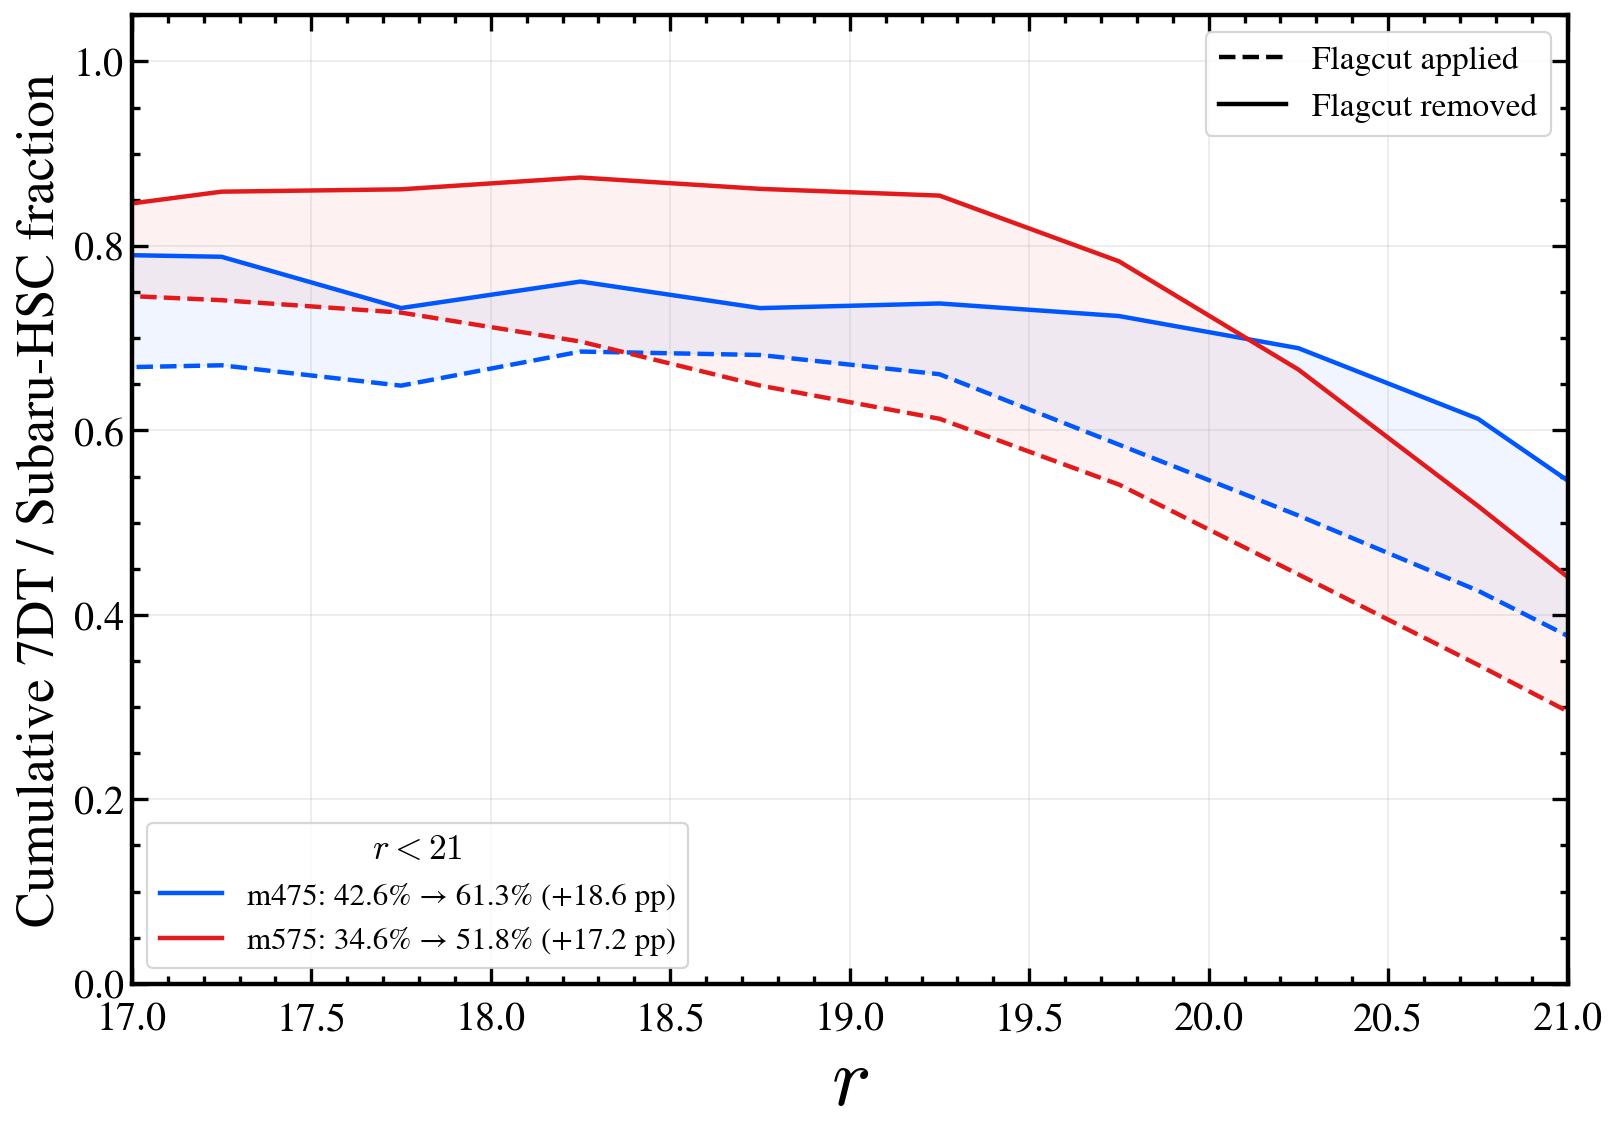

In [4]:
# Show the top two gains: dashed = Flagcut applied; solid = cut removed.
# Use contrasting blue/red colors for clarity; preserve each color across versions.
# Numerical labels use exact RM < 21 counts; plotted curves deliberately keep
# the older threshold-at-bin-center convention for direct visual comparison.
with plt.rc_context():
    scl_plt.default()
    plt.rcParams['figure.dpi'] = 160
    fig, ax = plt.subplots(figsize=(10, 7), layout='constrained')
    band_handles = []
    for band, color in zip(GAIN_BANDS, ('#0057FF', '#E31A1C')):
        old_fraction = CUM_FRACTIONS[band]
        new_fraction = NOFLAG_FRACTIONS[band]
        ax.plot(CUM_BIN_CENTERS, old_fraction, color=color, linestyle='--', linewidth=2)
        ax.plot(CUM_BIN_CENTERS, new_fraction, color=color, linestyle='-', linewidth=2)
        ax.fill_between(CUM_BIN_CENTERS, old_fraction, new_fraction, color=color, alpha=0.06)
        row = COVERAGE_GAIN_TABLE[np.asarray(COVERAGE_GAIN_TABLE['band']) == band][0]
        label = (f"{band}: {row['fraction_Flagcut']:.1%} → "
                 f"{row['fraction_no_Flagcut']:.1%} "
                 f"(+{row['gain_percentage_points']:.1f} pp)")
        band_handles.append(Line2D([0], [0], color=color, linewidth=2, label=label))
    bands_legend = ax.legend(handles=band_handles, loc='lower left', fontsize=14,
                             title=r'$r < 21$', title_fontsize=16)
    ax.add_artist(bands_legend)
    ax.legend(handles=[Line2D([0], [0], color='black', linestyle='--', linewidth=2,
                             label='Flagcut applied'),
                       Line2D([0], [0], color='black', linestyle='-', linewidth=2,
                             label='Flagcut removed')], loc='upper right', fontsize=15)
    ax.set_xlabel(r'$r$', fontsize=22 * 1.7)
    ax.set_ylabel('Cumulative 7DT / Subaru-HSC fraction', fontsize=24)
    ax.tick_params(axis='both', labelsize=18)
    ax.set_xlim(17, 21)
    ax.set_xticks(np.arange(17, 21.1, 0.5))
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.25)
    plt.show()
    plt.close(fig)


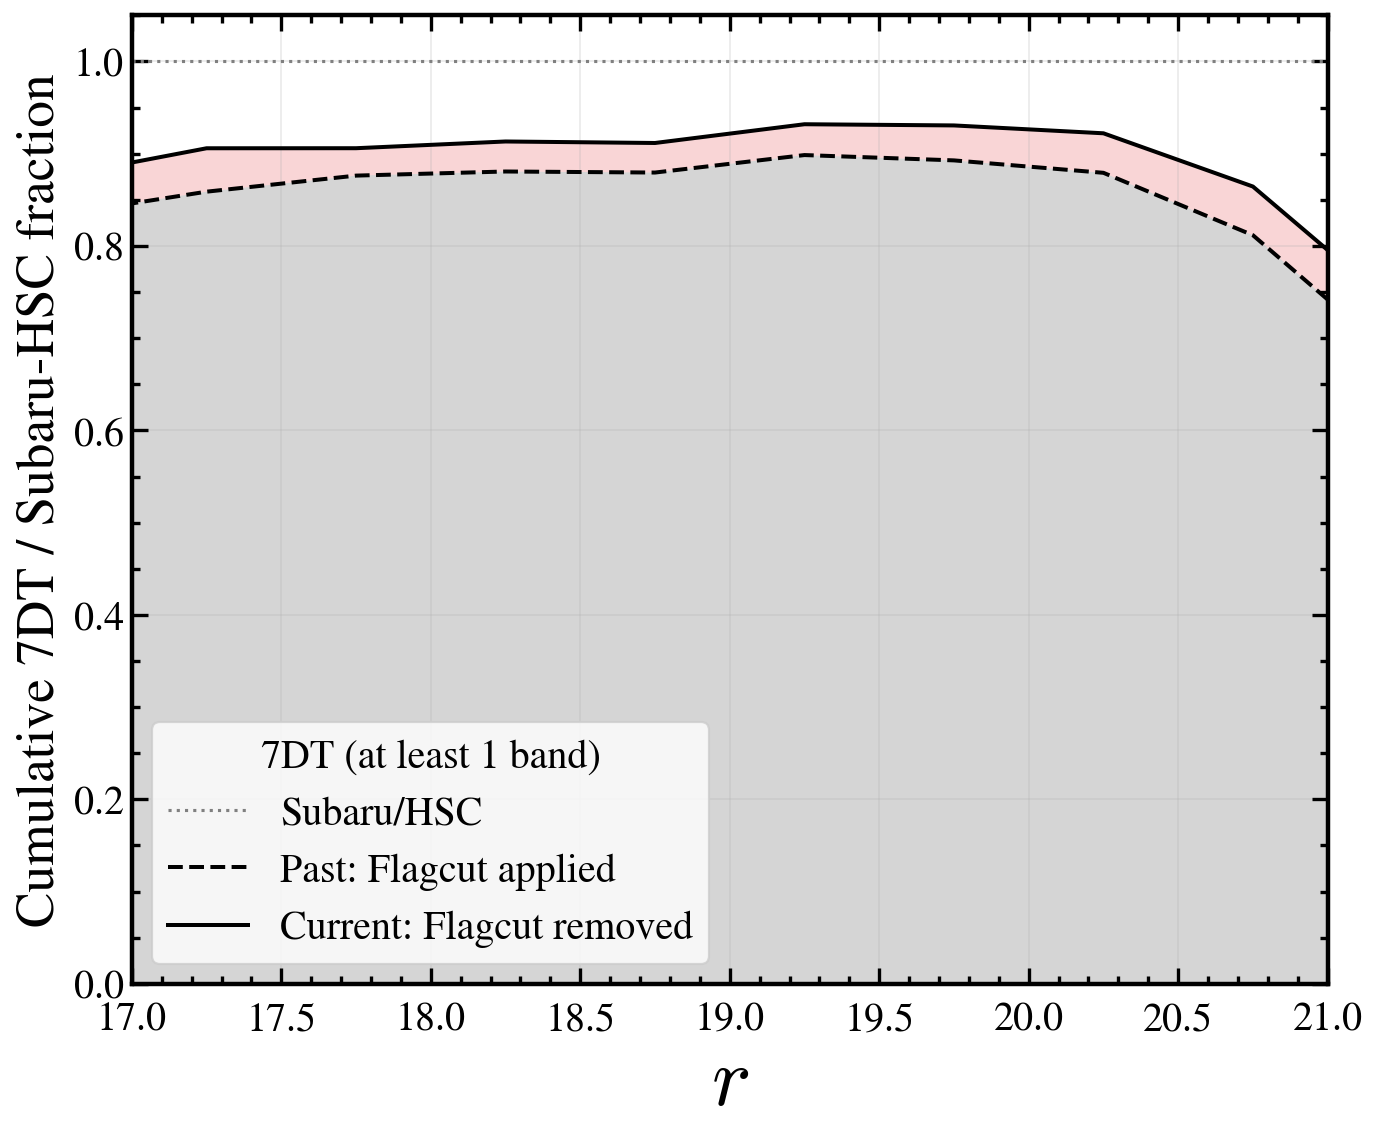

In [3]:
# Compare unique FINALCAT detections in at least one band, before and after
# removing Flagcut. Use retained source IDs, without an extra S/N or success
# requirement, exactly as in the earlier any-band fraction plot.
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('png')
PAST_ANY_DETECTED = np.zeros(len(CUM_CATALOG), dtype=bool)
CURRENT_ANY_DETECTED = np.zeros(len(NOFLAG_CATALOG), dtype=bool)
for field in CUM_FIELDS:
    prefix = f'7dt_cosmos{field}_'
    past_matched = cumulative_catalog_values(prefix + 'matched', fill=0).astype(bool)
    current_matched = noflag_catalog_values(prefix + 'matched', fill=0).astype(bool)
    for band in CUM_BANDS:
        PAST_ANY_DETECTED |= past_matched & (
            cumulative_catalog_values(prefix + band + '_source_id', fill=-1) >= 0)
        CURRENT_ANY_DETECTED |= current_matched & (
            noflag_catalog_values(prefix + band + '_source_id', fill=-1) >= 0)
# Each catalog has one row per FINALCAT index (checked above). Unioning fields
# and bands before counting prevents repeated detections from being counted twice.
PAST_ANY_COUNTS = cumulative_rm_counts(CUM_RM[PAST_ANY_DETECTED & CUM_VALID])
CURRENT_ANY_COUNTS = cumulative_rm_counts(NOFLAG_RM[CURRENT_ANY_DETECTED & NOFLAG_VALID])
PAST_ANY_FRACTION = np.divide(
    PAST_ANY_COUNTS[1:], CUM_REFERENCE_COUNTS[1:],
    out=np.full(len(CUM_BIN_CENTERS), np.nan), where=CUM_REFERENCE_COUNTS[1:] > 0)
CURRENT_ANY_FRACTION = np.divide(
    CURRENT_ANY_COUNTS[1:], CUM_REFERENCE_COUNTS[1:],
    out=np.full(len(CUM_BIN_CENTERS), np.nan), where=CUM_REFERENCE_COUNTS[1:] > 0)
# Preserve the Proposal threshold-at-bin-center convention and common reference.
with plt.rc_context():
    scl_plt.default()
    plt.rcParams['figure.dpi'] = 160
    fig, ax = plt.subplots(figsize=(8.5, 7), layout='constrained')
    # Keep the original gray fill below the past curve; highlight the
    # difference between past and current with a translucent red fill.
    ax.fill_between(CUM_BIN_CENTERS, 0, PAST_ANY_FRACTION,
                    color='0.75', alpha=0.65, linewidth=0, zorder=1)
    ax.fill_between(CUM_BIN_CENTERS, PAST_ANY_FRACTION, CURRENT_ANY_FRACTION,
                    color='#E31A1C', alpha=0.18, linewidth=0, zorder=1)
    ax.axhline(1.0, color='0.5', linestyle=':', linewidth=1.4,
               label='Subaru/HSC', zorder=2)
    ax.plot(CUM_BIN_CENTERS, PAST_ANY_FRACTION,
            color='black', linestyle='--', linewidth=1.8,
            label='Past: Flagcut applied', zorder=3)
    ax.plot(CUM_BIN_CENTERS, CURRENT_ANY_FRACTION,
            color='black', linestyle='-', linewidth=1.8,
            label='Current: Flagcut removed', zorder=4)
    ax.set_xlabel(r'$r$', fontsize=22 * 1.7)
    ax.set_ylabel('Cumulative 7DT / Subaru-HSC fraction', fontsize=24)
    ax.tick_params(axis='both', labelsize=18)
    ax.set_xlim(17, 21)
    ax.set_xticks(np.arange(17, 21.1, 0.5))
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.25)
    ax.legend(loc='lower left', fontsize=18, title='7DT (at least 1 band)', title_fontsize=18)
    plt.show()
    plt.close(fig)


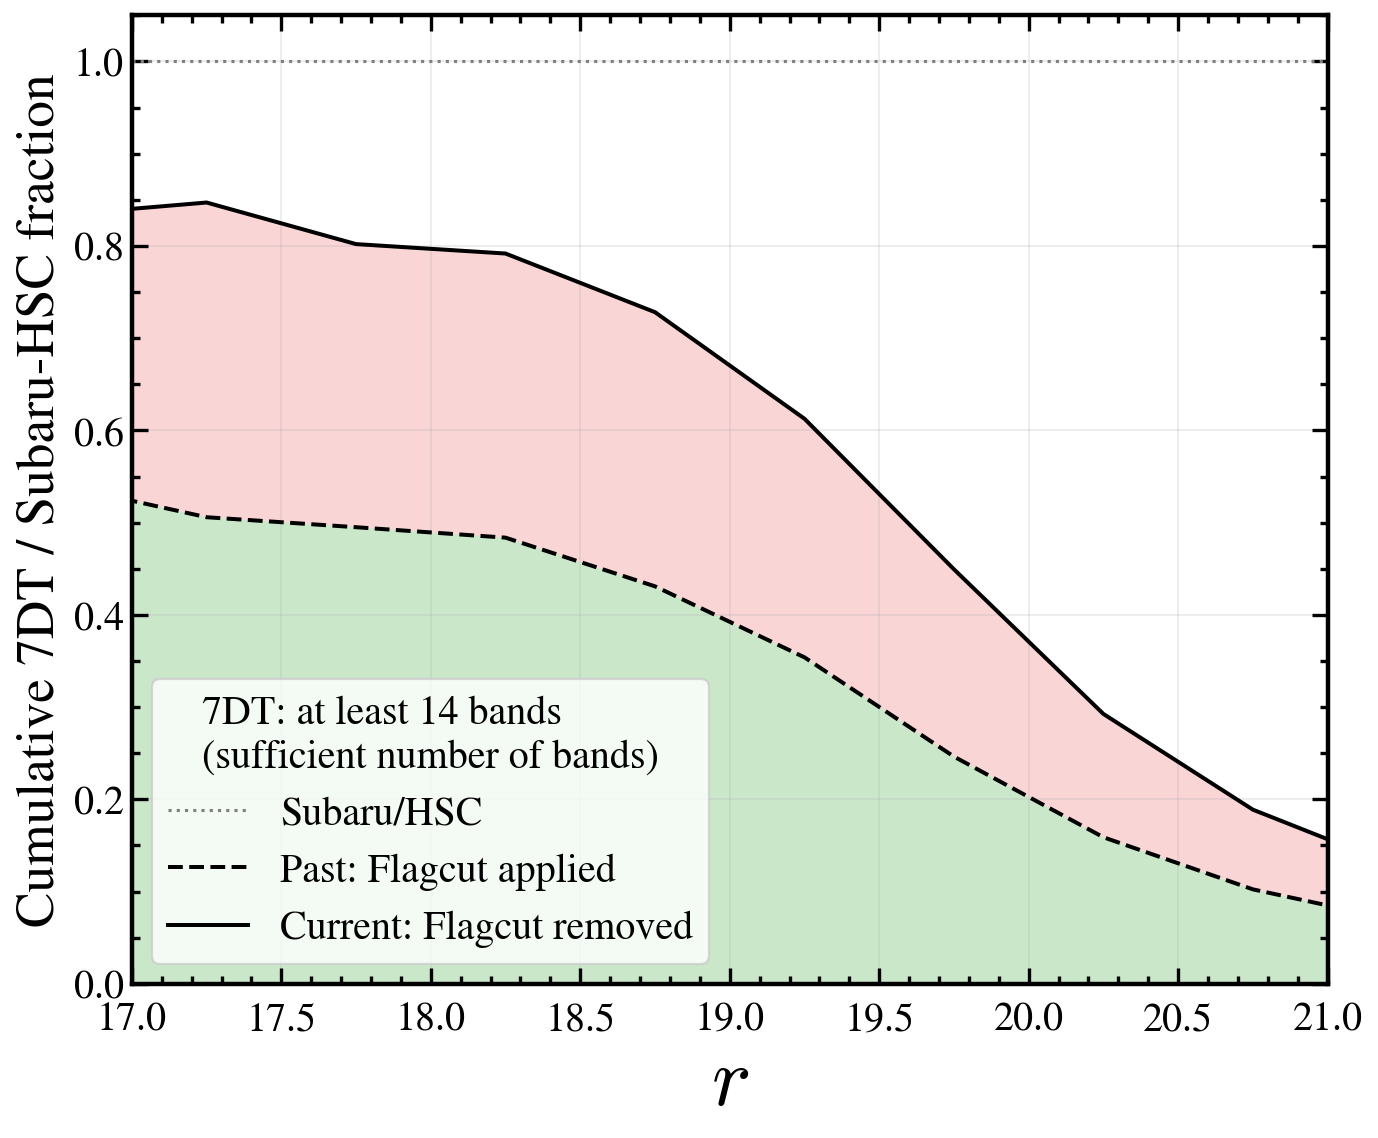

In [3]:
# Count distinct detected bands for each FINALCAT source in each version.
# A retained source_id >= 0 is a detection, matching the at-least-one-band plot;
# no additional S/N or finite-photometry success requirement is introduced.
# Union repeated detections across fields within each band before counting bands.
# Fourteen bands is a user-selected sufficient-band threshold; it does not
# establish that every band available at the source position was detected.
PAST_N_DETECTED_BANDS = np.zeros(len(CUM_CATALOG), dtype=int)
CURRENT_N_DETECTED_BANDS = np.zeros(len(NOFLAG_CATALOG), dtype=int)
for band in CUM_BANDS:
    past_band_detected = np.zeros(len(CUM_CATALOG), dtype=bool)
    current_band_detected = np.zeros(len(NOFLAG_CATALOG), dtype=bool)
    for field in CUM_FIELDS:
        prefix = f'7dt_cosmos{field}_'
        past_band_detected |= (
            cumulative_catalog_values(prefix + 'matched', fill=0).astype(bool)
            & (cumulative_catalog_values(prefix + band + '_source_id', fill=-1) >= 0))
        current_band_detected |= (
            noflag_catalog_values(prefix + 'matched', fill=0).astype(bool)
            & (noflag_catalog_values(prefix + band + '_source_id', fill=-1) >= 0))
    PAST_N_DETECTED_BANDS += past_band_detected
    CURRENT_N_DETECTED_BANDS += current_band_detected
assert np.all((PAST_N_DETECTED_BANDS >= 0) & (PAST_N_DETECTED_BANDS <= len(CUM_BANDS)))
assert np.all((CURRENT_N_DETECTED_BANDS >= 0) & (CURRENT_N_DETECTED_BANDS <= len(CUM_BANDS)))
MIN_DETECTED_BANDS = 14
PAST_14_COUNTS = cumulative_rm_counts(
    CUM_RM[CUM_VALID & (PAST_N_DETECTED_BANDS >= MIN_DETECTED_BANDS)])
CURRENT_14_COUNTS = cumulative_rm_counts(
    NOFLAG_RM[NOFLAG_VALID & (CURRENT_N_DETECTED_BANDS >= MIN_DETECTED_BANDS)])
# Keep the same reference denominator and cumulative thresholds as all earlier
# plots. These fractions are relative to all reference sources, not just detections.
PAST_14_FRACTION = np.divide(
    PAST_14_COUNTS[1:], CUM_REFERENCE_COUNTS[1:],
    out=np.full(len(CUM_BIN_CENTERS), np.nan), where=CUM_REFERENCE_COUNTS[1:] > 0)
CURRENT_14_FRACTION = np.divide(
    CURRENT_14_COUNTS[1:], CUM_REFERENCE_COUNTS[1:],
    out=np.full(len(CUM_BIN_CENTERS), np.nan), where=CUM_REFERENCE_COUNTS[1:] > 0)
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('png')
with plt.rc_context():
    scl_plt.default()
    plt.rcParams['figure.dpi'] = 160
    fig, ax = plt.subplots(figsize=(8.5, 7), layout='constrained')
    ax.fill_between(CUM_BIN_CENTERS, 0, PAST_14_FRACTION,
                    color='#2CA02C', alpha=0.25, linewidth=0, zorder=1)
    ax.fill_between(CUM_BIN_CENTERS, PAST_14_FRACTION, CURRENT_14_FRACTION,
                    color='#E31A1C', alpha=0.18, linewidth=0, zorder=1)
    ax.axhline(1.0, color='0.5', linestyle=':', linewidth=1.4,
               label='Subaru/HSC', zorder=2)
    ax.plot(CUM_BIN_CENTERS, PAST_14_FRACTION,
            color='black', linestyle='--', linewidth=1.8,
            label='Past: Flagcut applied', zorder=3)
    ax.plot(CUM_BIN_CENTERS, CURRENT_14_FRACTION,
            color='black', linestyle='-', linewidth=1.8,
            label='Current: Flagcut removed', zorder=4)
    ax.set_xlabel(r'$r$', fontsize=22 * 1.7)
    ax.set_ylabel('Cumulative 7DT / Subaru-HSC fraction', fontsize=24)
    ax.tick_params(axis='both', labelsize=18)
    ax.set_xlim(17, 21)
    ax.set_xticks(np.arange(17, 21.1, 0.5))
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.25)
    ax.legend(loc='lower left', fontsize=18,
              title='7DT: at least 14 bands\n(sufficient number of bands)', title_fontsize=18)
    plt.show()
    plt.close(fig)


In [3]:
# Audit reference rows without any assigned 7DT detection in the CURRENT
# catalogs. Catalog non-recovery is not necessarily absence of light: matching
# conflicts and the 0.7-arcsec matching radius can also produce zero-band rows.
import sys
import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.wcs import WCS
from IPython.display import display
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('png')
if str(CUM_ROOT / 'Notebooks') not in sys.path:
    sys.path.insert(0, str(CUM_ROOT / 'Notebooks'))
from sourceinfo_report import plot_source_info

REFERENCE_ANY_DETECTED = np.zeros(len(CUM_REFERENCE), dtype=bool)
current_union = np.zeros(len(NOFLAG_CATALOG), dtype=bool)
for field in CUM_FIELDS:
    prefix = f'7dt_cosmos{field}_'
    matched = noflag_catalog_values(prefix + 'matched', fill=0).astype(bool)
    for band in CUM_BANDS:
        current_union |= matched & (noflag_catalog_values(prefix + band + '_source_id', fill=-1) >= 0)
REFERENCE_ANY_DETECTED[NOFLAG_REFERENCE_IDS[current_union]] = True
reference_missing = CUM_REF_VALID & ~REFERENCE_ANY_DETECTED
# Use COSMOS1 deliberately: all 20 image bands are available. Require the
# reference center to lie in its valid mask, so examples are not outside images.
NONDETECTION_MASTER = Table.read(CUM_ROOT / 'output/COSMOS1/singlephot/cosmos1_master_catalog.fits')
nd_ref_idx = np.asarray(np.ma.filled(NONDETECTION_MASTER['finalcat_idx'], -1), dtype=int)
nd_linked = np.asarray(NONDETECTION_MASTER['has_finalcat'], dtype=bool) & (nd_ref_idx >= 0)
nd_covered = np.zeros(len(CUM_REFERENCE), dtype=bool)
nd_covered[nd_ref_idx[nd_linked]] = True
with fits.open(CUM_ROOT / 'COSMOS_data/COSMOS1/COSMOS1_validmask.fits', memmap=True) as hdus:
    nd_mask = hdus[0].data
    nd_wcs = WCS(hdus[0].header)
    xx, yy = nd_wcs.world_to_pixel_values(CUM_REFERENCE['RA'], CUM_REFERENCE['DEC'])
    finite = np.isfinite(xx) & np.isfinite(yy)
    ix = np.zeros(len(xx), dtype=int); iy = np.zeros(len(yy), dtype=int)
    ix[finite] = np.rint(xx[finite]).astype(int); iy[finite] = np.rint(yy[finite]).astype(int)
    in_image = finite & (ix >= 0) & (iy >= 0) & (ix < nd_mask.shape[1]) & (iy < nd_mask.shape[0])
    nd_in_mask = np.zeros(len(CUM_REFERENCE), dtype=bool)
    nd_in_mask[in_image] = nd_mask[iy[in_image], ix[in_image]] > 0
candidates = np.flatnonzero(reference_missing & nd_in_mask & nd_covered)
assert len(candidates) > 0
nd_nbands = np.zeros(len(NONDETECTION_MASTER), dtype=int)
for band in CUM_BANDS:
    nd_nbands += np.asarray(np.ma.filled(NONDETECTION_MASTER[band + '_source_id'], -1)) >= 0
nd_detected_rows = np.flatnonzero(nd_nbands > 0)
nd_detected_coords = SkyCoord(NONDETECTION_MASTER['master_ra'][nd_detected_rows],
                              NONDETECTION_MASTER['master_dec'][nd_detected_rows], unit='deg')
NONDETECTION_SAMPLE_ROWS = []
for target_rm in (17, 18, 19, 21):
    ref_idx = int(candidates[np.argmin(abs(CUM_REF_RM[candidates] - target_rm))])
    master_rows = np.flatnonzero(nd_linked & (nd_ref_idx == ref_idx))
    assert len(master_rows) == 1
    master_row = int(master_rows[0]); row = NONDETECTION_MASTER[master_row]
    assert nd_nbands[master_row] == 0 and not REFERENCE_ANY_DETECTED[ref_idx]
    coord = SkyCoord(float(CUM_REFERENCE['RA'][ref_idx]), float(CUM_REFERENCE['DEC'][ref_idx]), unit='deg')
    nearest, separation, _ = coord.match_to_catalog_sky(nd_detected_coords)
    near_row = NONDETECTION_MASTER[nd_detected_rows[int(nearest)]]
    # The nearest neighbor is diagnostic only; do not assign its photometry to
    # this reference source or change the original production matching.
    NONDETECTION_SAMPLE_ROWS.append((target_rm, ref_idx, float(CUM_REF_RM[ref_idx]),
        float(coord.ra.deg), float(coord.dec.deg), int(row['master_id']),
        str(row['finalcat_match_status']), float(separation.arcsec),
        int(near_row['master_id']), int(nd_nbands[nd_detected_rows[int(nearest)]]),
        int(near_row['finalcat_idx']) if not np.ma.is_masked(near_row['finalcat_idx']) else -1))
NONDETECTION_SAMPLES = Table(rows=NONDETECTION_SAMPLE_ROWS, names=[
    'target_RM', 'finalcat_idx', 'RM', 'RA', 'DEC', 'field_master_id',
    'match_status', 'nearest_7dt_sep_arcsec', 'nearest_7dt_master_id',
    'nearest_7dt_nbands', 'nearest_7dt_finalcat_idx'])
for col in ('RM', 'nearest_7dt_sep_arcsec'):
    NONDETECTION_SAMPLES[col].format = '.3f'
for col in ('RA', 'DEC'):
    NONDETECTION_SAMPLES[col].format = '.7f'
display(NONDETECTION_SAMPLES)


def show_nondetection_at_radec(ra, dec, pixel_range=40):
    """Reuse the existing source-info 20-image method at a reference position.

    Coordinates identify an existing FINALCAT-only field-master row to numerical
    precision; this is not a new match to a nearby detected source. The shared
    source-info method retains its SED/report implementation. Only this local
    returned figure is rearranged into a larger image-only 4-by-5 display.
    """
    coords = SkyCoord(NONDETECTION_MASTER['master_ra'], NONDETECTION_MASTER['master_dec'], unit='deg')
    target = SkyCoord(float(ra), float(dec), unit='deg')
    separations = target.separation(coords).arcsec
    selected = int(np.nanargmin(separations))
    if separations[selected] > 0.001 or nd_nbands[selected] != 0:
        raise ValueError('Coordinates must identify an existing zero-band reference row within 0.001 arcsec.')
    row = NONDETECTION_MASTER[selected]
    with plt.rc_context():
        scl_plt.default()
        result = plot_source_info(NONDETECTION_MASTER, source_id=int(row['master_id']),
            pixel_range=pixel_range, project_root=CUM_ROOT, field=1,
            population_catalog=NONDETECTION_MASTER, show=False, save_pdf=False)
        fig = result['report_figures'][0]
        # _image_page creates the 20 band axes first, in wavelength order.
        band_axes = fig.axes[:20]
        assert len(band_axes) == 20
        # Display just the existing method's cutout axes, enlarged for legibility.
        # Do not remove SED support from sourceinfo_report.py.
        for ax in list(fig.axes):
            if ax not in band_axes:
                ax.remove()
        for text in list(fig.texts):
            text.remove()
        fig.set_size_inches(15, 12)
        fig.set_dpi(180)
        grid = fig.add_gridspec(4, 5, left=.05, right=.985, bottom=.045, top=.91,
                               hspace=.28, wspace=.25)
        for j, ax in enumerate(band_axes):
            ax.set_subplotspec(grid[j // 5, j % 5])
            ax.set_title('', loc='left'); ax.set_title('', loc='right')
            ax.set_title(f'{CUM_BANDS[j]} (no assigned detection)', fontsize=11, loc='center')
            ax.tick_params(labelsize=8)
            ax.scatter(float(row['master_x']), float(row['master_y']), marker='+',
                       s=90, color='cyan', linewidths=1.2, zorder=10)
        fig.suptitle(f"COSMOS1 | FINALCAT row {int(row['finalcat_idx'])} | "
                     f"r = {float(row['finalcat_RM']):.3f} | 0 assigned bands\n"
                     f"RA = {ra:.7f}, Dec = {dec:.7f} | {row['finalcat_match_status']}", fontsize=16)
        display(fig)
        plt.close(fig)
    return result


/var/folders/fd/sr9dc9td6rnc8xmntjxzpjh80000gn/T/ipykernel_26495/731445087.py:63: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  str(row['finalcat_match_status']), float(separation.arcsec),


target_RM,finalcat_idx,RM,RA,DEC,field_master_id,match_status,nearest_7dt_sep_arcsec,nearest_7dt_master_id,nearest_7dt_nbands,nearest_7dt_finalcat_idx
int64,int64,float64,float64,float64,int64,str23,float64,int64,int64,int64
17,124434,17.356,149.5924500,1.7567600,103393,new_master_conflict,0.119,1167,20,116298
18,116858,17.986,149.7769470,1.9394160,100442,new_master_conflict,0.155,2054,20,119601
19,120489,18.984,149.9615784,1.7106249,101721,new_master_no_candidate,0.772,4954,19,-1
21,115943,21.000,149.4299700,2.1457484,100158,new_master_no_candidate,1.217,20060,11,-1


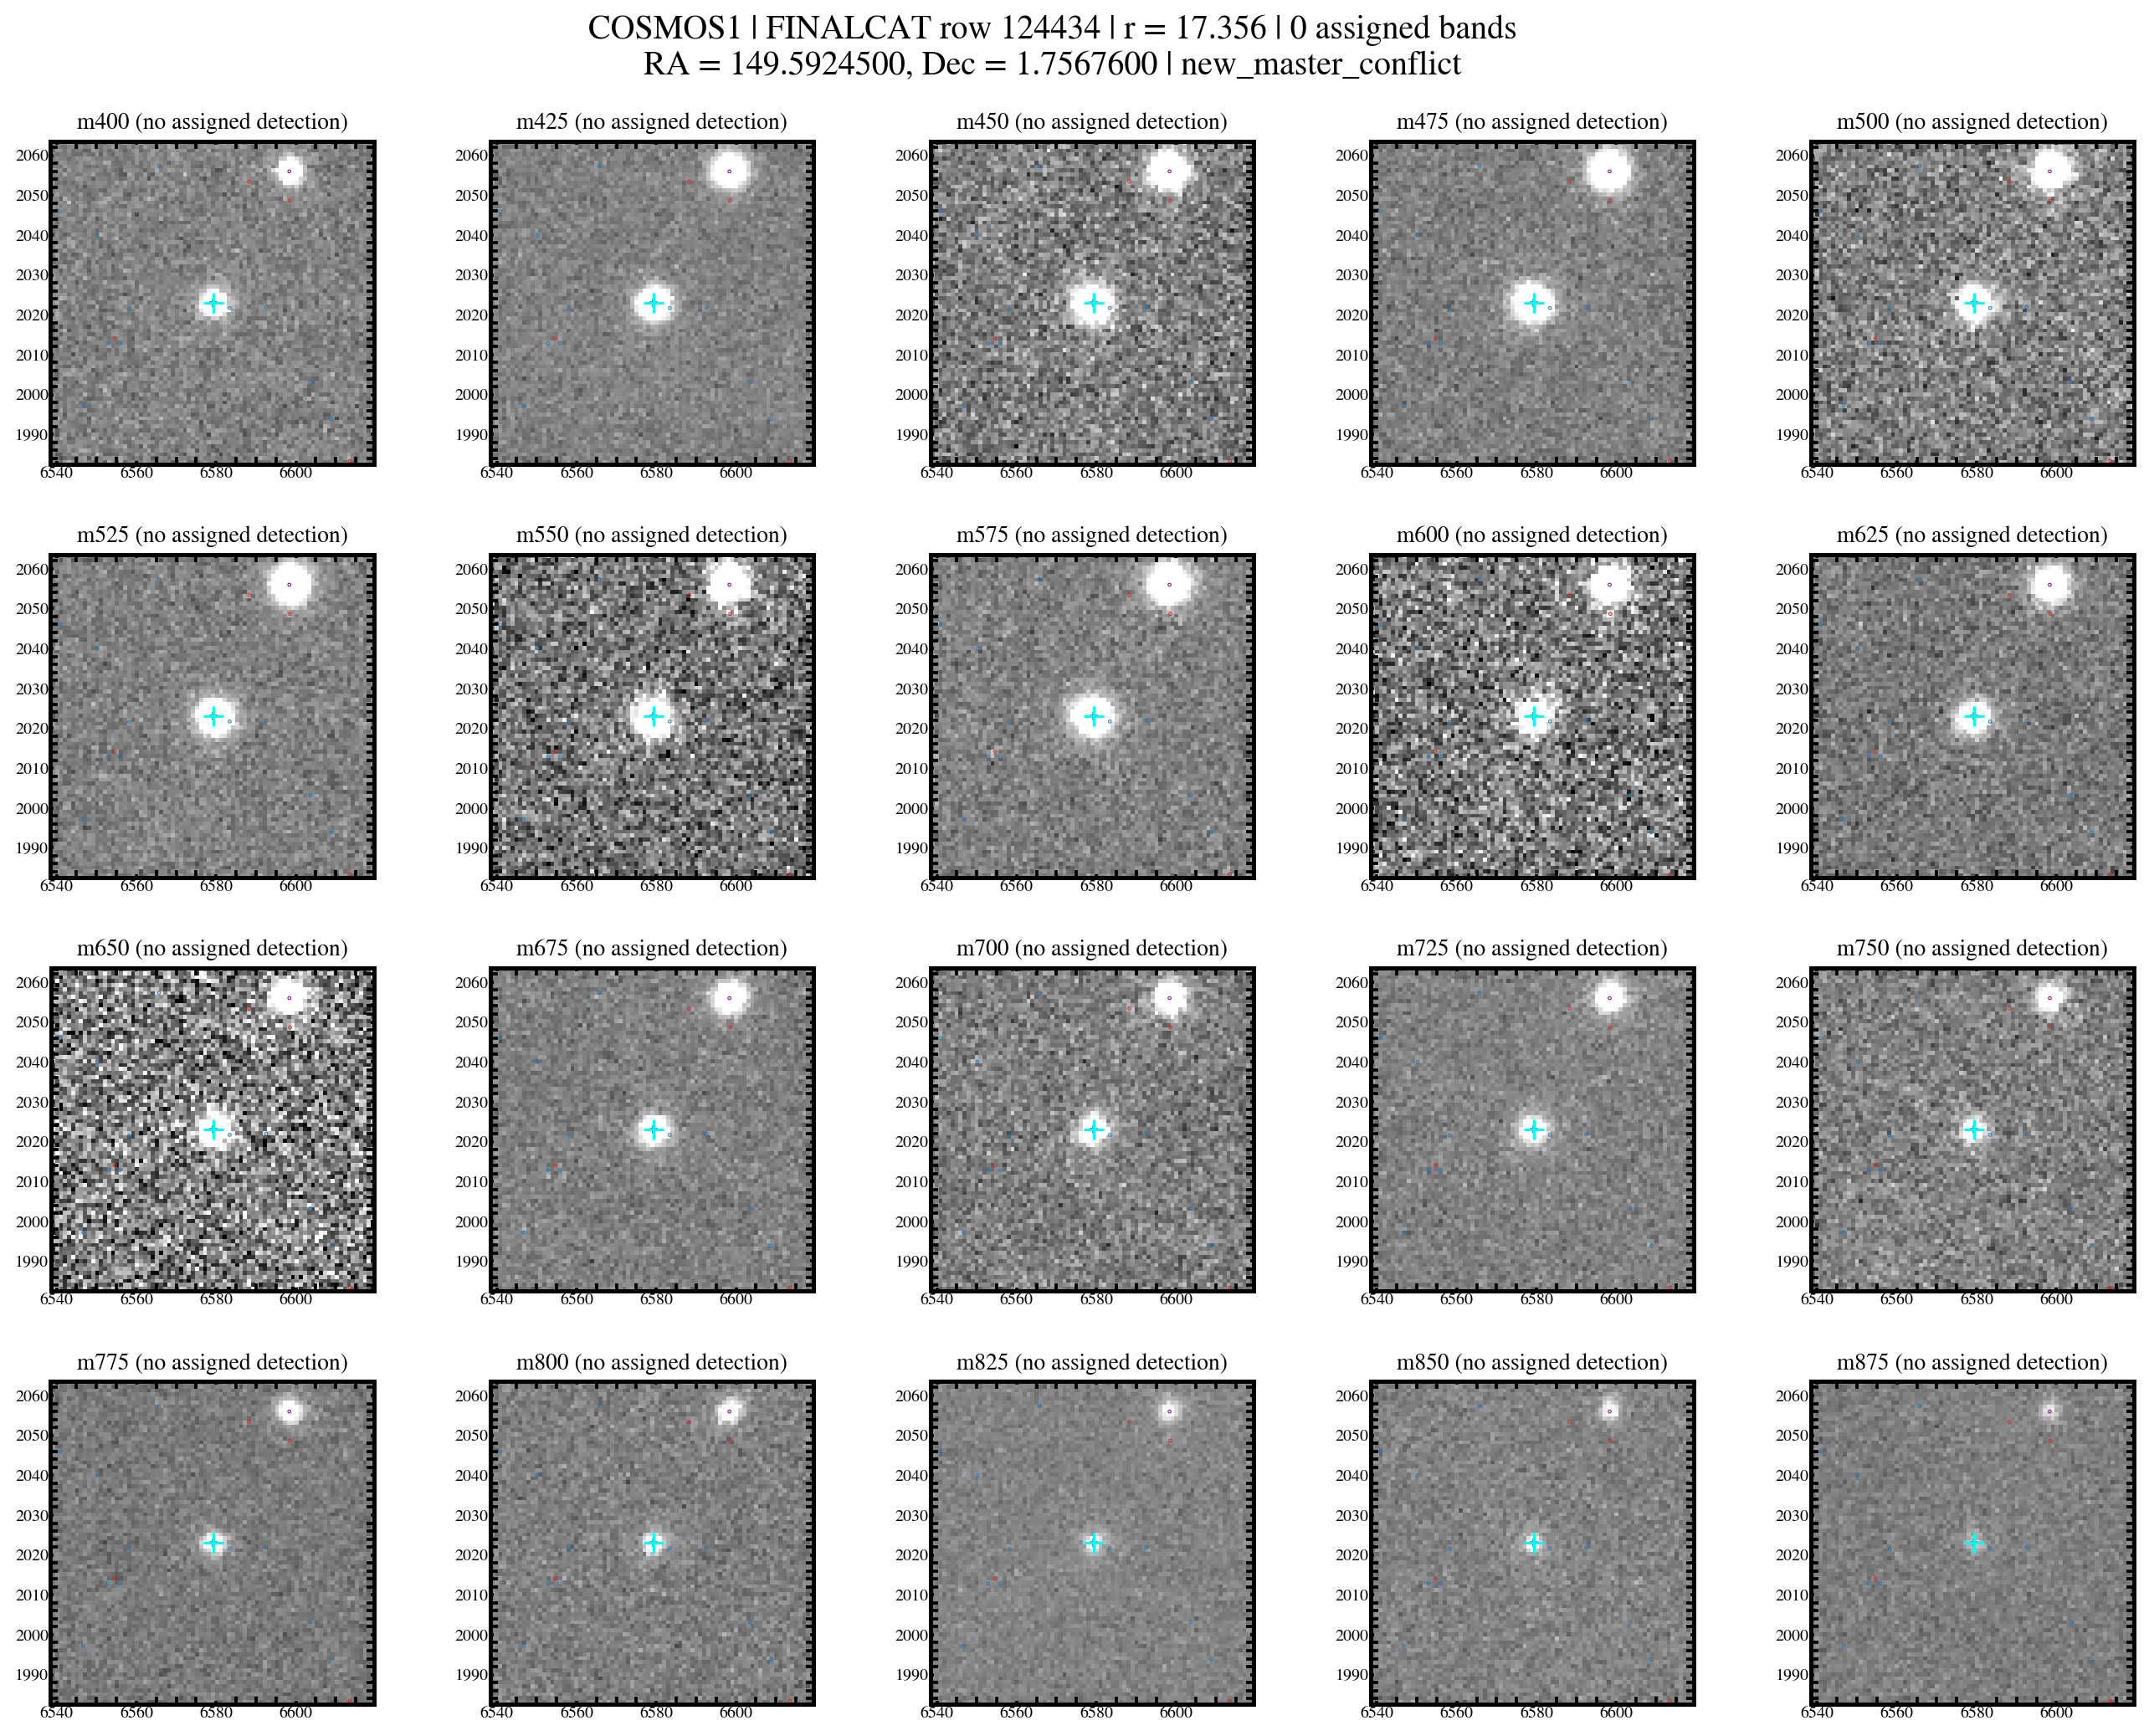

In [4]:
# Coordinate-driven inspection of the 17-mag sample using the existing method.
nd_sample = NONDETECTION_SAMPLES[0]
nd_report_0 = show_nondetection_at_radec(float(nd_sample['RA']), float(nd_sample['DEC']), pixel_range=40)

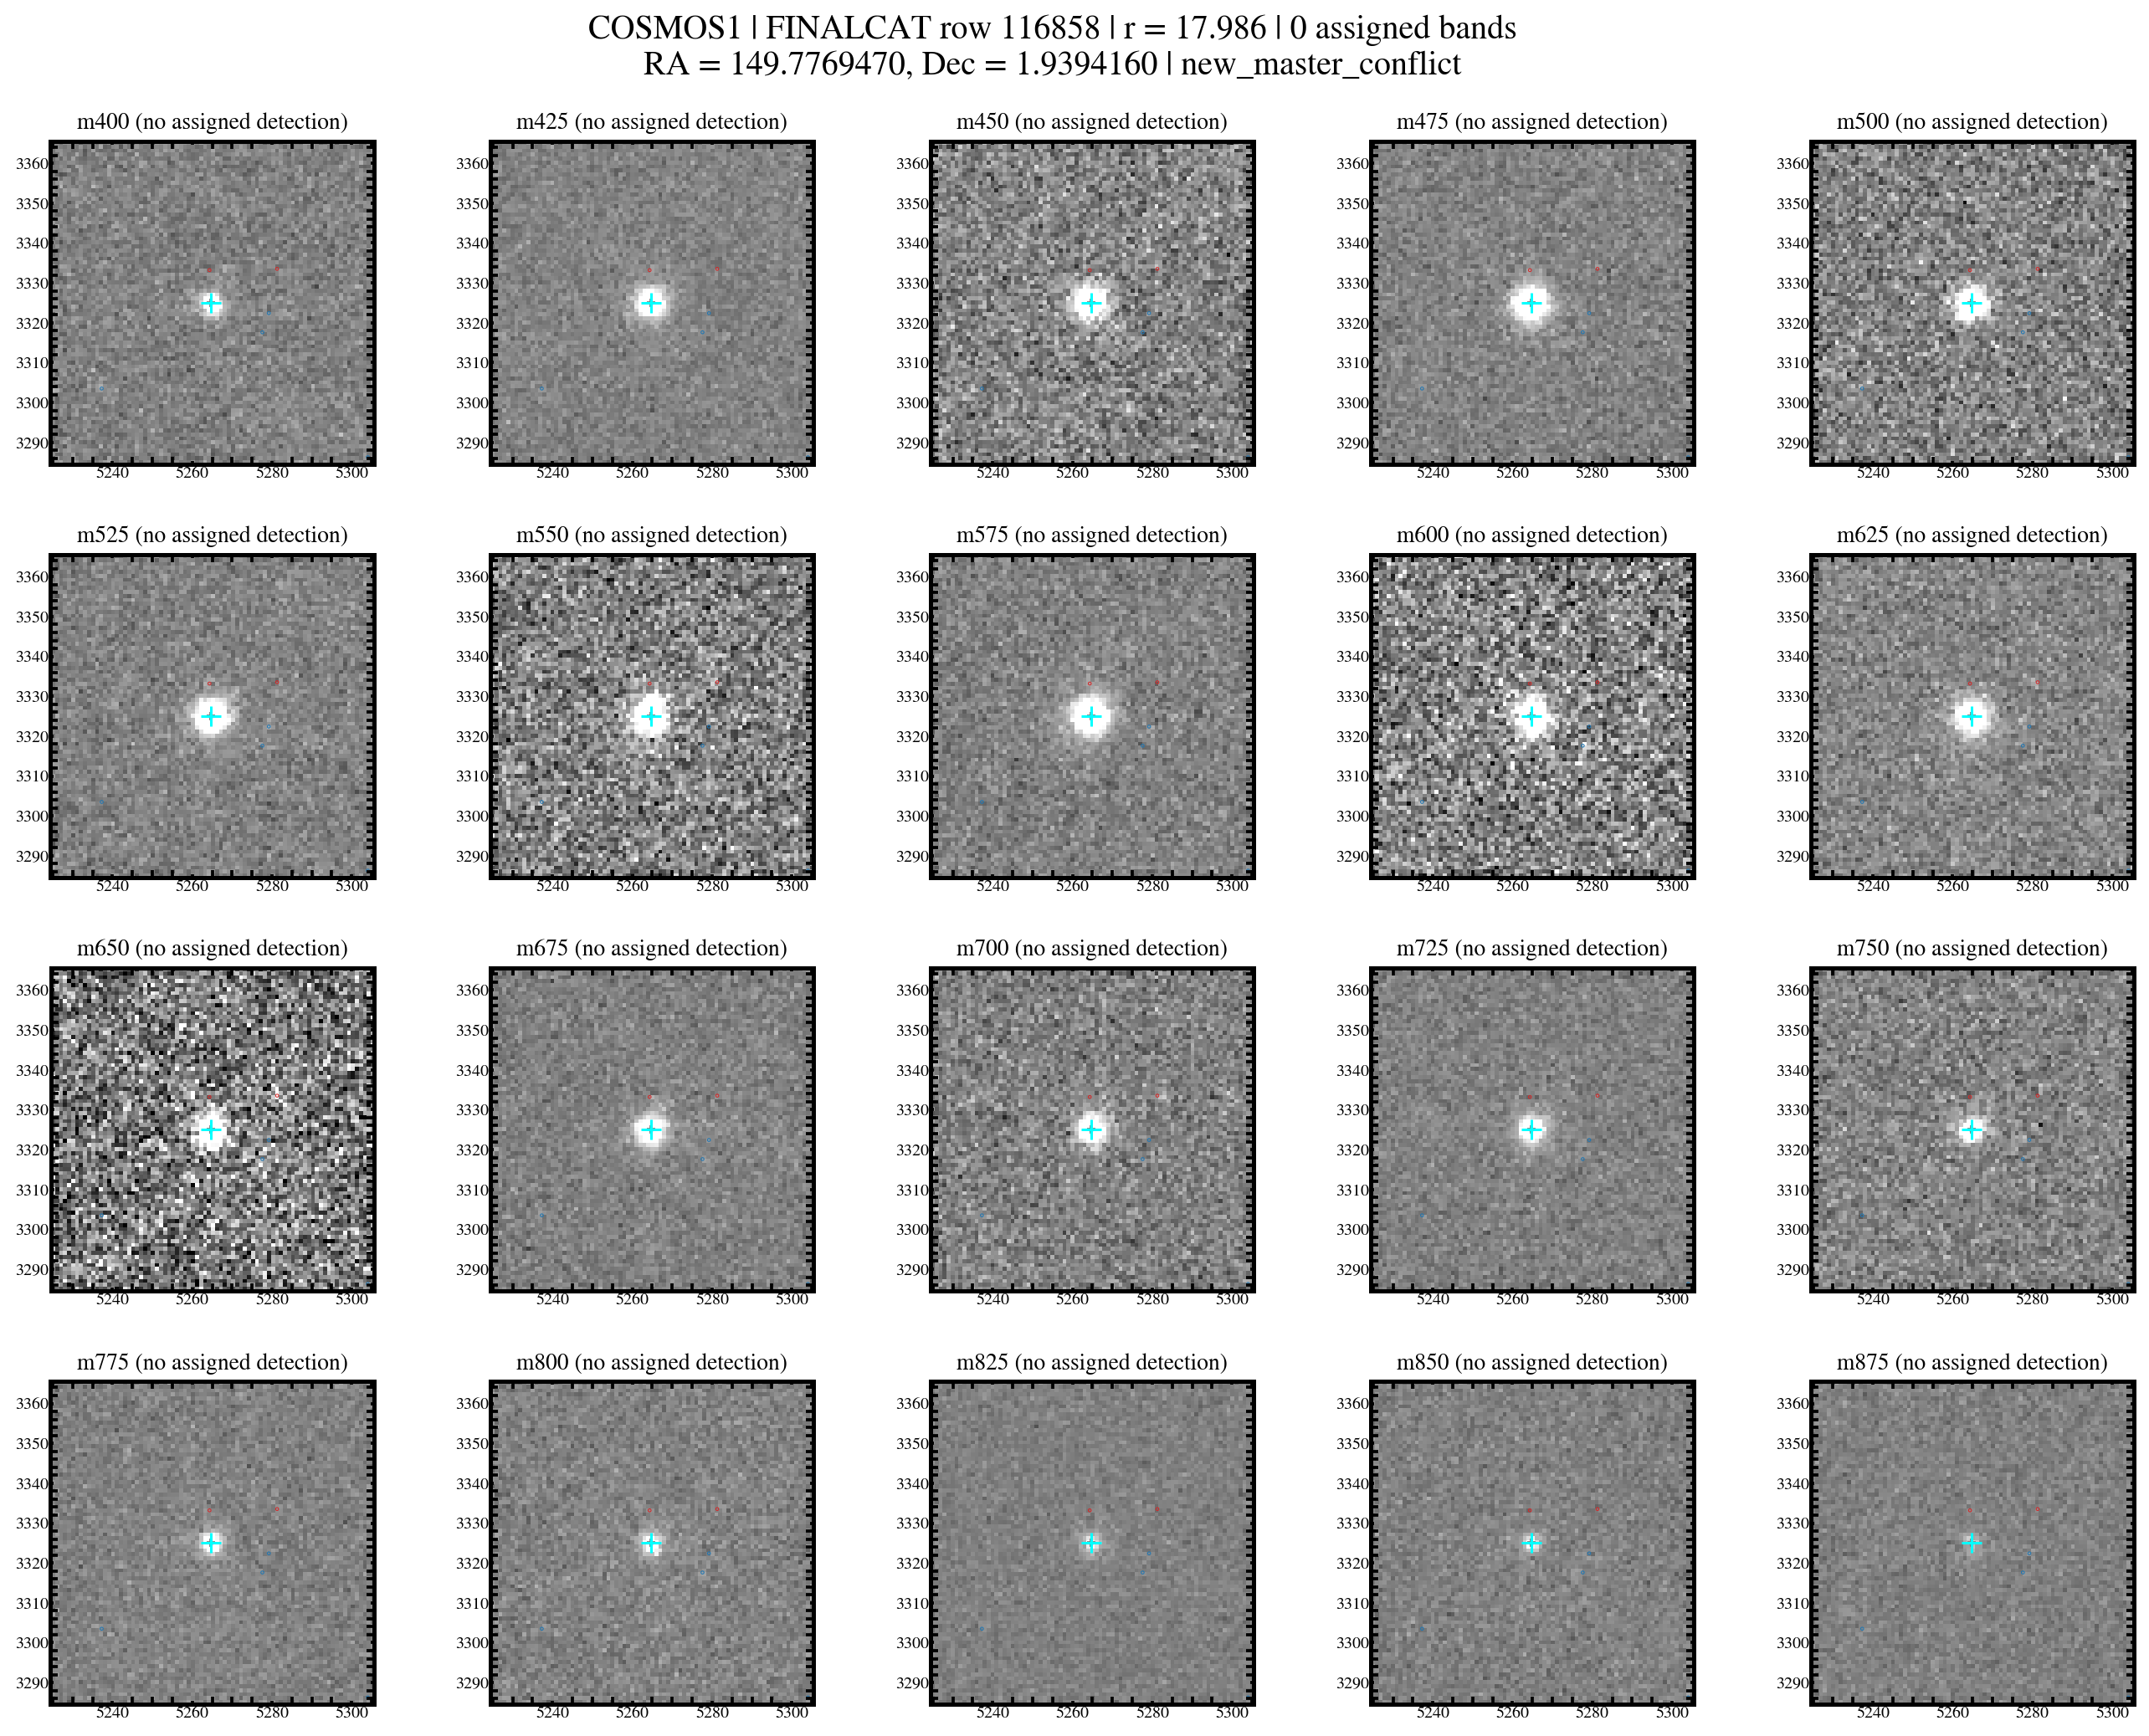

In [5]:
# Coordinate-driven inspection of the 18-mag sample using the existing method.
nd_sample = NONDETECTION_SAMPLES[1]
nd_report_1 = show_nondetection_at_radec(float(nd_sample['RA']), float(nd_sample['DEC']), pixel_range=40)

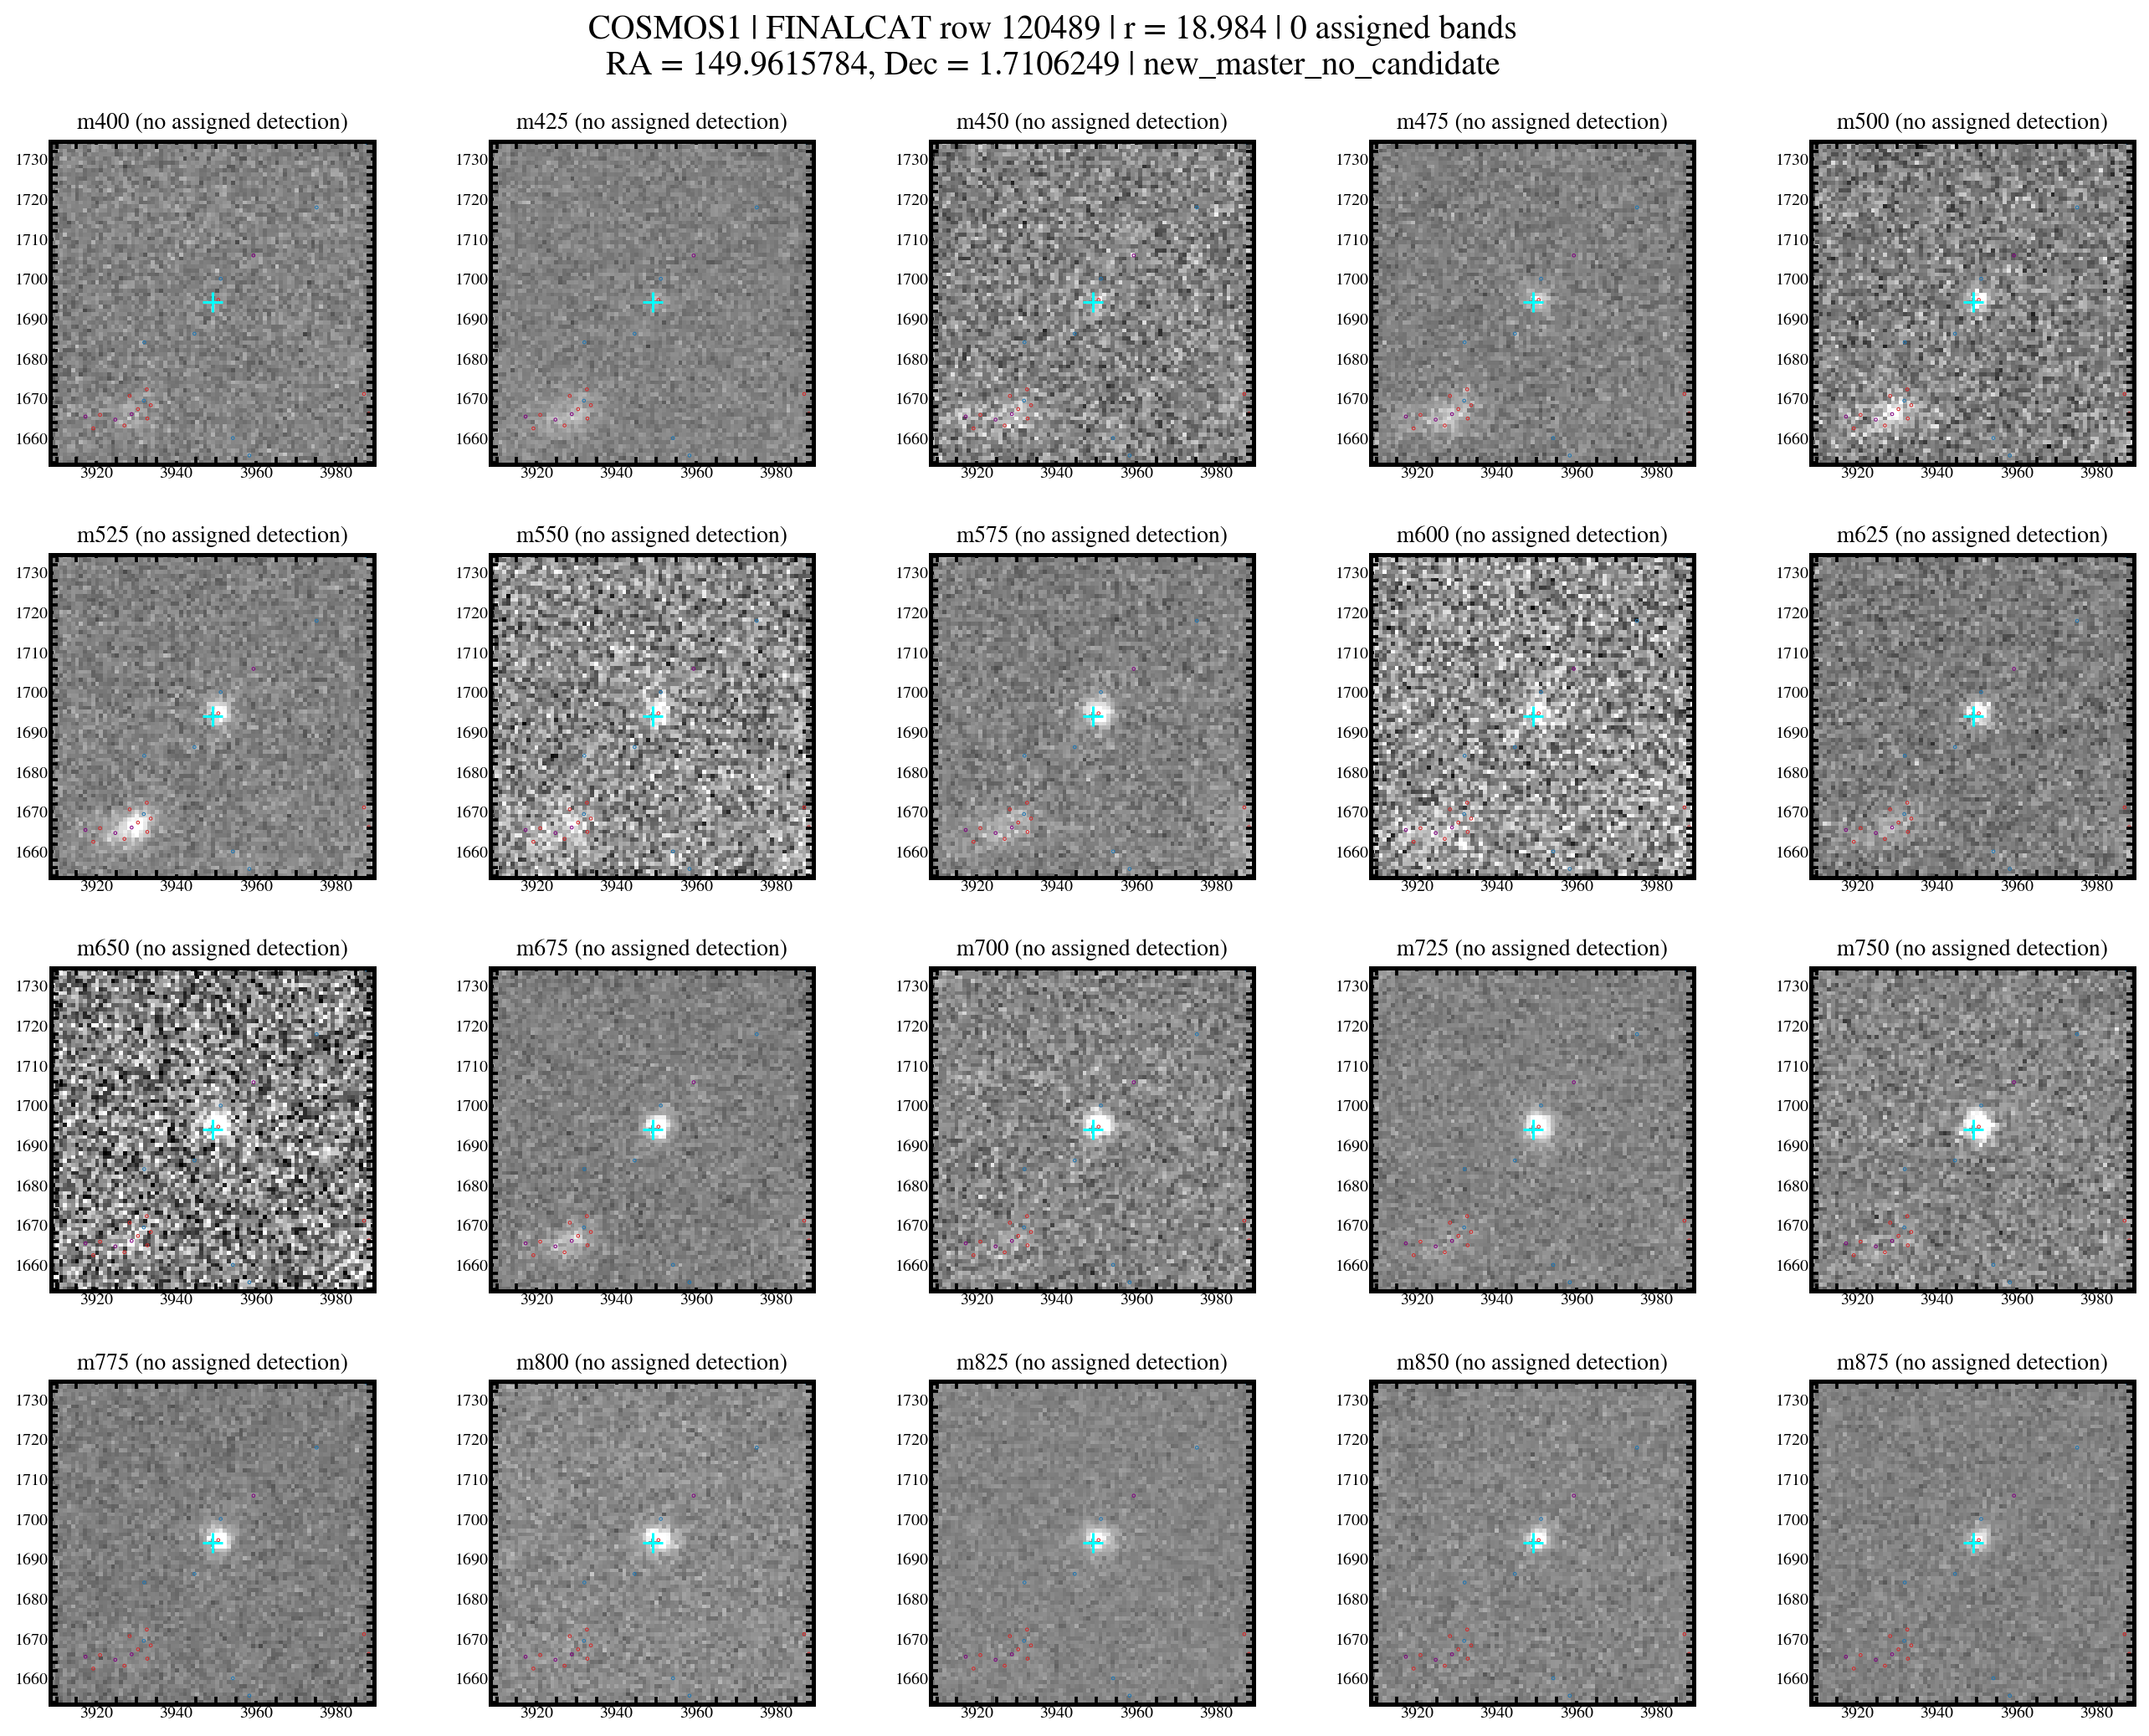

In [6]:
# Coordinate-driven inspection of the 19-mag sample using the existing method.
nd_sample = NONDETECTION_SAMPLES[2]
nd_report_2 = show_nondetection_at_radec(float(nd_sample['RA']), float(nd_sample['DEC']), pixel_range=40)

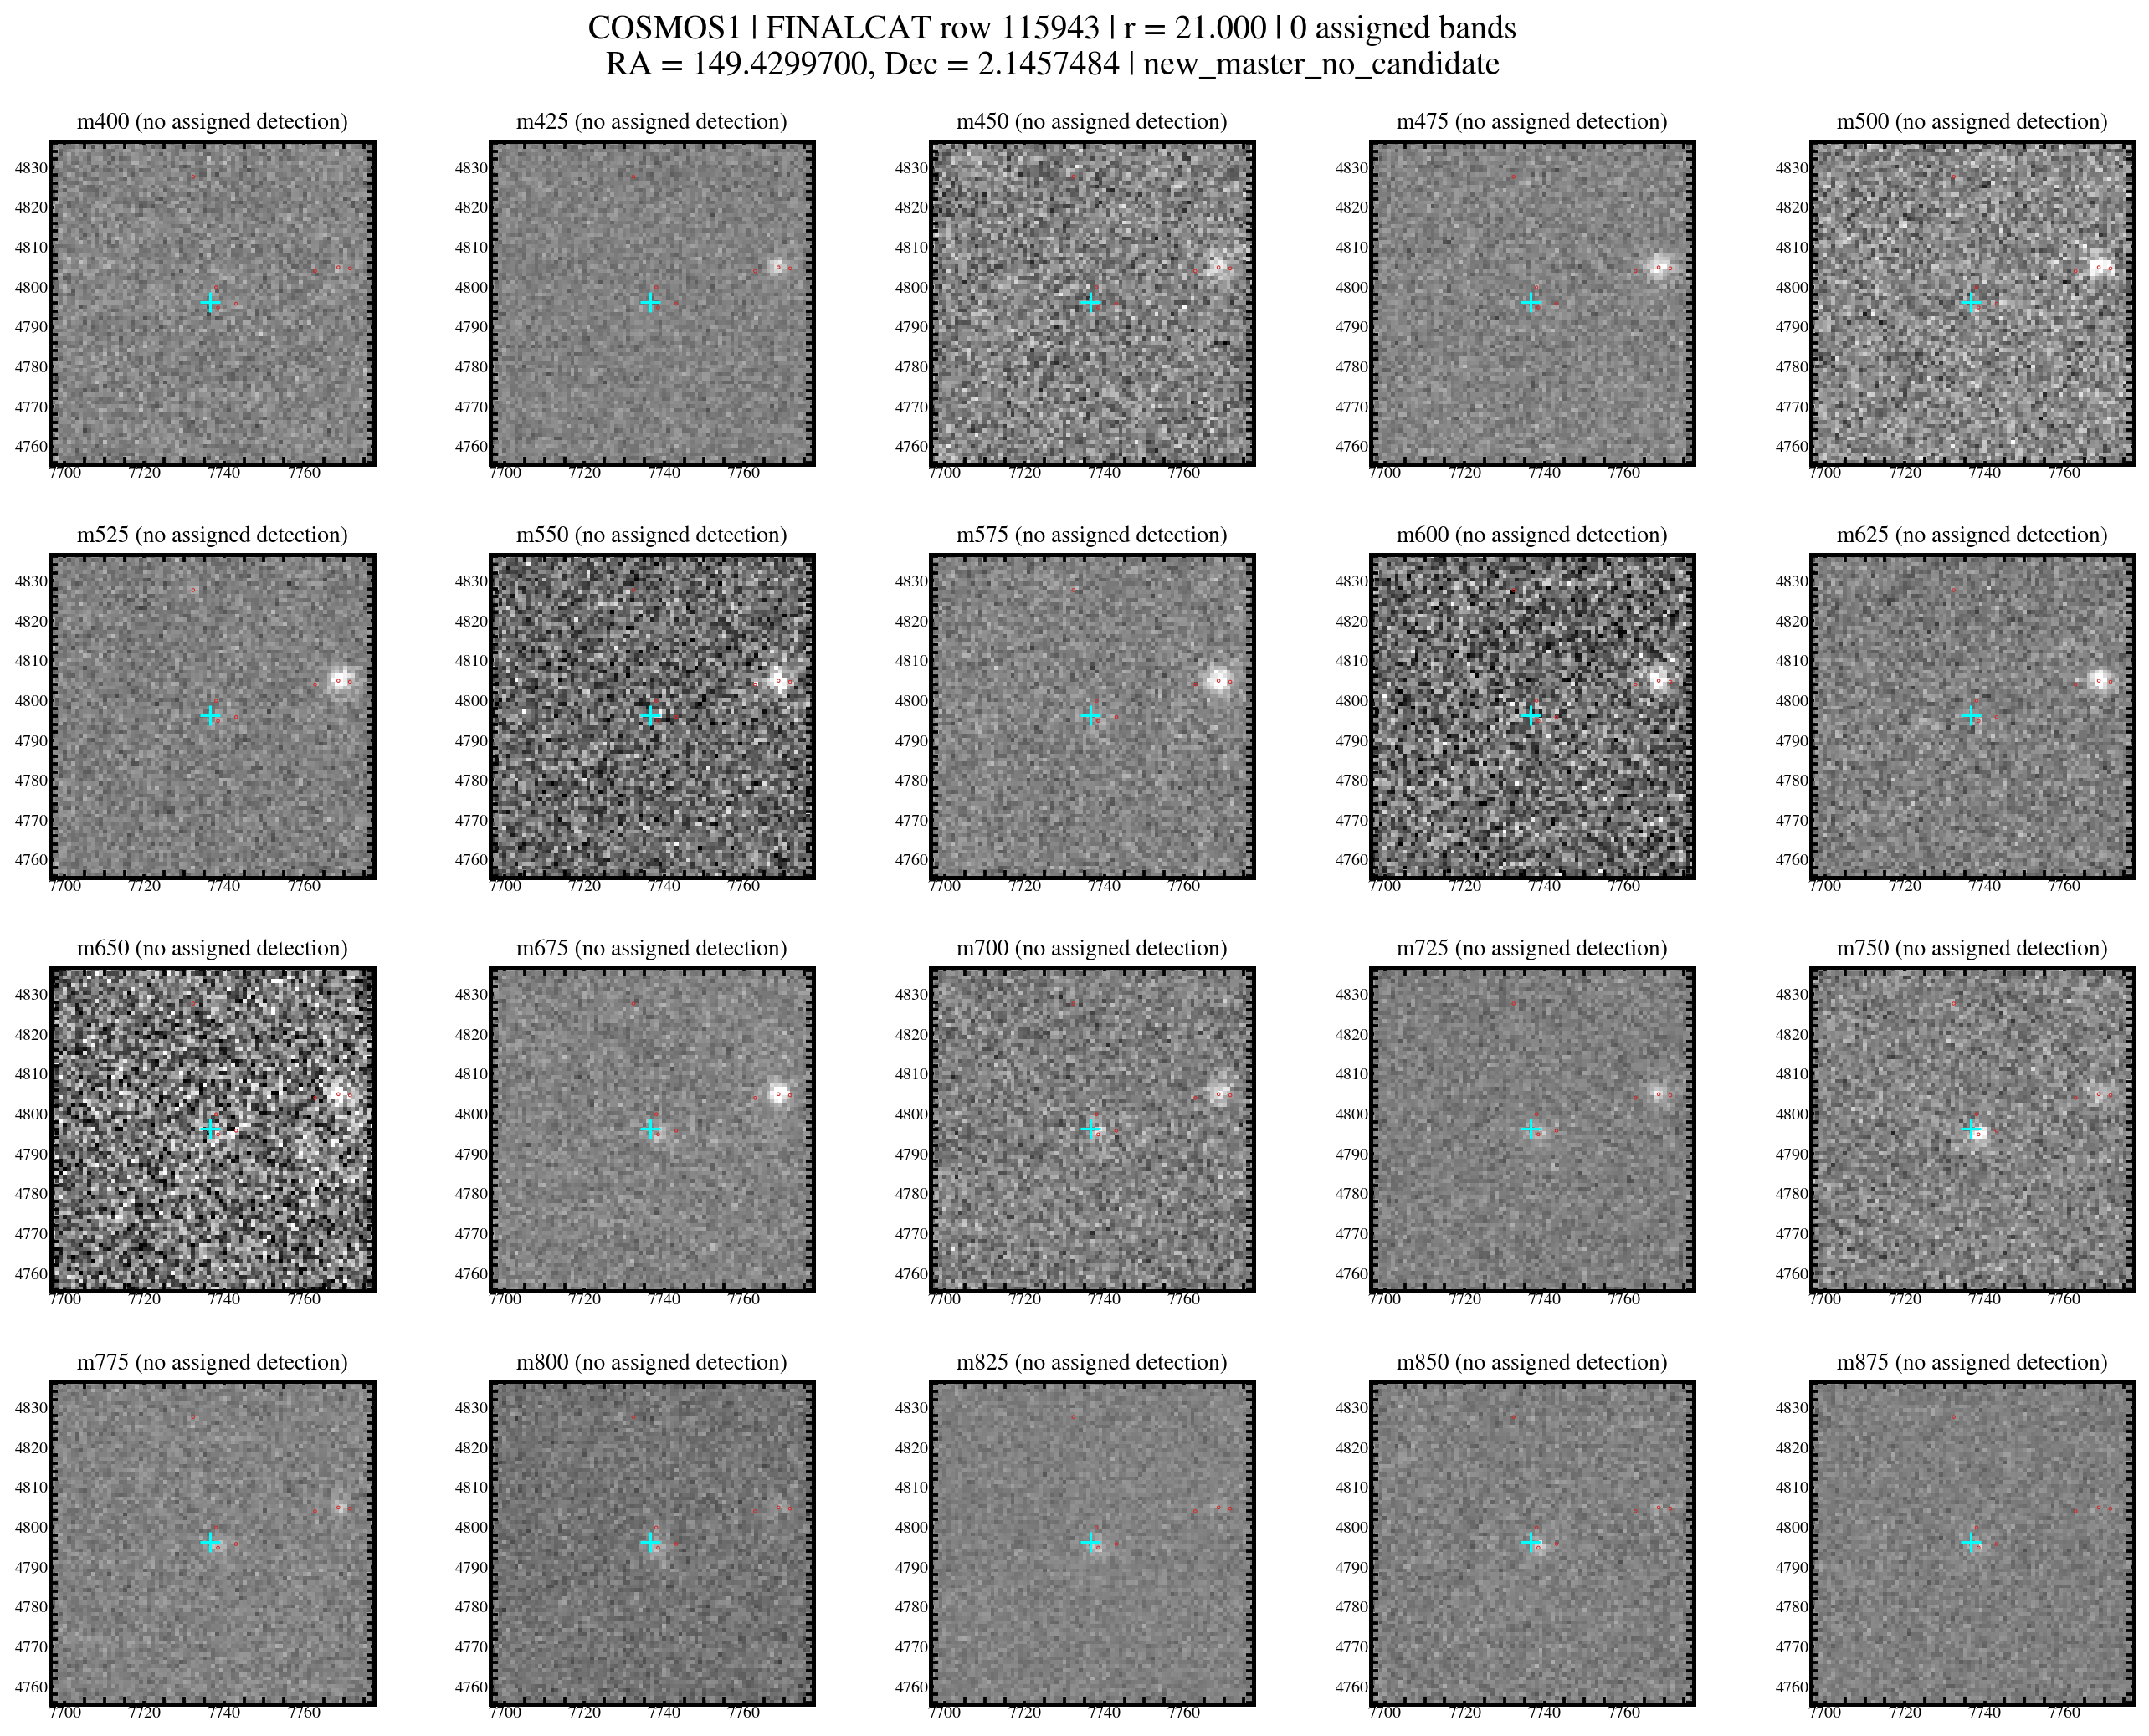

In [7]:
# Coordinate-driven inspection of the 21-mag sample using the existing method.
nd_sample = NONDETECTION_SAMPLES[3]
nd_report_3 = show_nondetection_at_radec(float(nd_sample['RA']), float(nd_sample['DEC']), pixel_range=40)

In [4]:
# Provenance: Gaia DR3 gaiadr3.gaia_source, queried from the ESA TAP sync
# endpoint https://gea.esac.esa.int/tap-server/tap/sync with 4.32-arcsec cones
# around the four reference coordinates. Embed the exact returned CSV so this
# analysis remains reproducible without another network request or data file.
# No catalog associations are changed by this diagnostic analysis.
from astropy.time import Time
from astropy.wcs.utils import proj_plane_pixel_scales
from matplotlib.patches import Circle
GAIA_AUDIT_CSV = 'source_id,ra,dec,ref_epoch,pmra,pmdec,parallax,phot_g_mean_mag,ruwe,duplicated_source\n3834720387267657856,149.59243724726483,1.756714314425469,2016.0,-0.08852588073725774,0.1471554695090361,-0.23824116927887978,17.532457,1.0778879,false\n3836293273011172352,149.42976897949035,2.1456140209480514,2016.0,-46.93417090603974,-33.227466344420755,4.266116553740585,19.93194,0.9564411,false\n3836226104017245824,149.77694402983346,1.939349774691329,2016.0,-1.8257520262322007,-0.6574187616962173,-1.5979546275872871,18.097157,2.1586154,false\n3836029768177533696,149.96145219877025,1.7107211501098816,2016.0,-33.57372271217328,1.957996575207786,3.38989676819023,18.377178,1.0388725,false\n'

GAIA_AUDIT = Table.read(GAIA_AUDIT_CSV, format='ascii.csv')
AUDIT_REF_INDICES = (124434, 116858, 120489, 115943)
AUDIT_NEAR_IDS = (1167, 2054, 4954, 20060)
AUDIT_OTHER_REFS = (116298, 119601, None, None)
audit_master = Table.read(CUM_ROOT / 'output/COSMOS1/singlephot/cosmos1_master_catalog.fits')
image_path = next((CUM_ROOT / 'COSMOS_data/COSMOS1').glob('*m600*.com.fits'))
audit_header = fits.getheader(image_path)
# A coadd spans multiple exposures; use DATE-OBS as a representative epoch,
# rather than interpreting the coadd header as an exact single exposure time.
audit_epoch = Time(audit_header['DATE-OBS'])
audit_scale = float(proj_plane_pixel_scales(WCS(audit_header))[0] * 3600)
widths = Table.read(CUM_ROOT / 'output/COSMOS1/singlephot/diagnostics/cosmos1_7dt_singleband_band_uncertainty.fits')
print(f"7DT representative epoch: {audit_epoch.jyear:.4f}; matching radius: {audit_master.meta['RADIUS']} arcsec")
print(f"Saved 2*r50 image-width proxy: {min(widths['fwhm_pix'])*audit_scale:.2f}--{max(widths['fwhm_pix'])*audit_scale:.2f} arcsec (not an independently fitted PSF).")
audit_rows = []; provenance_rows = []; audit_points = []
gaia_coords = SkyCoord(GAIA_AUDIT['ra'], GAIA_AUDIT['dec'], unit='deg')
for ref_idx, master_id, other_idx in zip(AUDIT_REF_INDICES, AUDIT_NEAR_IDS, AUDIT_OTHER_REFS):
    ref = CUM_REFERENCE[ref_idx]
    target = SkyCoord(float(ref['RA']), float(ref['DEC']), unit='deg')
    near = audit_master[np.asarray(audit_master['master_id']) == master_id][0]
    coord7 = SkyCoord(float(near['master_ra']), float(near['master_dec']), unit='deg')
    gi = int(np.argmin(coord7.separation(gaia_coords))); gaia = GAIA_AUDIT[gi]
    g2016 = SkyCoord(ra=gaia['ra']*u.deg, dec=gaia['dec']*u.deg,
        pm_ra_cosdec=gaia['pmra']*u.mas/u.yr, pm_dec=gaia['pmdec']*u.mas/u.yr,
        obstime=Time(gaia['ref_epoch'], format='jyear'))
    # Propagate mean barycentric position using proper motion only. Annual
    # parallax and radial-velocity perspective acceleration are not modelled.
    gnow = g2016.apply_space_motion(new_obstime=audit_epoch)
    points = [('Reference', target), ('7DT', coord7), ('Gaia 2016', g2016), ('Gaia at 7DT epoch', gnow)]
    m13_sep = np.nan
    if float(ref['M13_RA']) > 0:
        m13 = SkyCoord(float(ref['M13_RA']), float(ref['M13_DEC']), unit='deg')
        m13_sep = m13.separation(coord7).arcsec
        points.append(('M13 position', m13))
    if other_idx is not None:
        other = CUM_REFERENCE[other_idx]
        points.append(('Other reference row', SkyCoord(float(other['RA']), float(other['DEC']), unit='deg')))
    audit_points.append((ref_idx, target, points))
    audit_rows.append((ref_idx, float(ref['RM']), int(gaia['source_id']),
        target.separation(coord7).arcsec, m13_sep, float(gaia['pmra']),float(gaia['pmdec']),
        coord7.separation(gnow).arcsec,float(gaia['ruwe'])))
    for j in ([ref_idx, other_idx] if other_idx is not None else [ref_idx]):
        row = CUM_REFERENCE[j]
        provenance_rows.append((j,str(row['M13_ID']).strip(),str(row['C07_ID']).strip(),
            str(row['SDSS_OBJID']).strip(),str(row['ZCOS_ID']).strip(),str(row['DCOS_ID']).strip(),
            float(row['RM']),float(row['C07_RM']),float(row['Z_TOT_Z']),str(row['Z_TOT_ZSOURCE']).strip()))
HYPOTHESIS_ASTROMETRY = Table(rows=audit_rows,names=['finalcat_idx','RM','Gaia_source_id',
    'reference_to_7dt_arcsec','M13_to_7dt_arcsec','pmRA_mas_yr','pmDEC_mas_yr','propagated_Gaia_to_7dt_arcsec','RUWE'])
for name in HYPOTHESIS_ASTROMETRY.colnames:
    if name not in ('finalcat_idx','Gaia_source_id'): HYPOTHESIS_ASTROMETRY[name].format='.3f'
display(HYPOTHESIS_ASTROMETRY)
HYPOTHESIS_PROVENANCE=Table(rows=provenance_rows,names=['finalcat_idx','M13_ID','C07_ID','SDSS_OBJID','zCOS_ID','dCOS_ID','RM','C07_RM','Z_TOT_Z','Z_SOURCE'])
display(HYPOTHESIS_PROVENANCE)
# Inspect independent raw band detections near the reference location, rather
# than treating a failed FINALCAT association as a failed image detection.
raw_near_counts = {i: [] for i in AUDIT_REF_INDICES}
for band in CUM_BANDS:
    raw=Table.read(CUM_ROOT / f'output/COSMOS1/singlephot/cat_cosmos1_{band}.fits')
    ra=np.asarray(raw['world_centroid_alpha'],float); dec=np.asarray(raw['world_centroid_delta'],float)
    finite=np.isfinite(ra)&np.isfinite(dec)
    rawcoords=SkyCoord(ra[finite],dec[finite],unit='deg')
    for i in AUDIT_REF_INDICES:
        target=SkyCoord(float(CUM_REFERENCE['RA'][i]),float(CUM_REFERENCE['DEC'][i]),unit='deg')
        sep=target.separation(rawcoords).arcsec
        raw_near_counts[i].append((int((sep<1).sum()),int((sep<2).sum()),float(sep.min())))
RAW_NEIGHBOR_AUDIT=Table(rows=[(i,sum(x[0]>0 for x in vals),sum(x[1]>0 for x in vals),
    sum(x[1]>1 for x in vals)) for i,vals in raw_near_counts.items()],names=[
    'finalcat_idx','bands_with_raw_source_within_1arcsec','bands_with_raw_source_within_2arcsec',
    'bands_with_multiple_raw_sources_within_2arcsec'])
display(RAW_NEIGHBOR_AUDIT)
print('HST ACS cutouts obtained through the IRSA SIA/Subimage fallback; see the image-check cell below.')


WARNING

7DT representative epoch: 2024.3381; matching radius: 0.7 arcsec
Saved 2*r50 image-width proxy: 2.57--3.63 arcsec (not an independently fitted PSF).


: FITSFixedWarning: 'datfix' made the change 'Invalid parameter values: MJD-OBS and DATE-OBS are inconsistent'. [astropy.wcs.wcs]
/opt/anaconda3/envs/photoz/lib/python3.11/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "pmsafe" yielded 1 of "distance overridden (Note 6)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


finalcat_idx,RM,Gaia_source_id,reference_to_7dt_arcsec,M13_to_7dt_arcsec,pmRA_mas_yr,pmDEC_mas_yr,propagated_Gaia_to_7dt_arcsec,RUWE
int64,float64,int64,float64,float64,float64,float64,float64,float64
124434,17.356,3834720387267657856,0.119,nan,-0.089,0.147,0.096,1.078
116858,17.986,3836226104017245824,0.155,0.123,-1.826,-0.657,0.098,2.159
120489,18.984,3836029768177533696,0.772,0.539,-33.574,1.958,0.053,1.039
115943,21.000,3836293273011172352,1.217,0.748,-46.934,-33.227,0.141,0.956


finalcat_idx,M13_ID,C07_ID,SDSS_OBJID,zCOS_ID,dCOS_ID,RM,C07_RM,Z_TOT_Z,Z_SOURCE
int64,str10,str11,str19,str10,str7,float64,float64,float64,str7
124434,NN,C07_648196,NN,NN,NN,17.35602569580078,18.275699615478516,1.9611999988555908,T09
116298,M13_53489,NN,1237651753460170766,NN,NN,18.047100067138672,-99.0,1.9655771255493164,SDSS
116858,M13_68564,NN,NN,zCOS813472,NN,17.985992431640625,-99.0,0.0,zCOSMOS
119601,NN,C07_963955,NN,NN,L424556,17.271223068237305,18.19930076599121,-99.0,NN
120489,M13_22700,C07_579564,NN,NN,L280534,18.983909606933594,19.26300048828125,0.0,dCOSMOS
115943,M13_154481,C07_1795775,1237651753996976444,NN,NN,21.000308990478516,21.247600555419922,9.17838333407417e-05,SDSS


finalcat_idx,bands_with_raw_source_within_1arcsec,bands_with_raw_source_within_2arcsec,bands_with_multiple_raw_sources_within_2arcsec
int64,int64,int64,int64
124434,20,20,0
116858,20,20,0
120489,19,19,0
115943,1,11,1


HST ACS cutouts obtained through the IRSA SIA/Subimage fallback; see the image-check cell below.


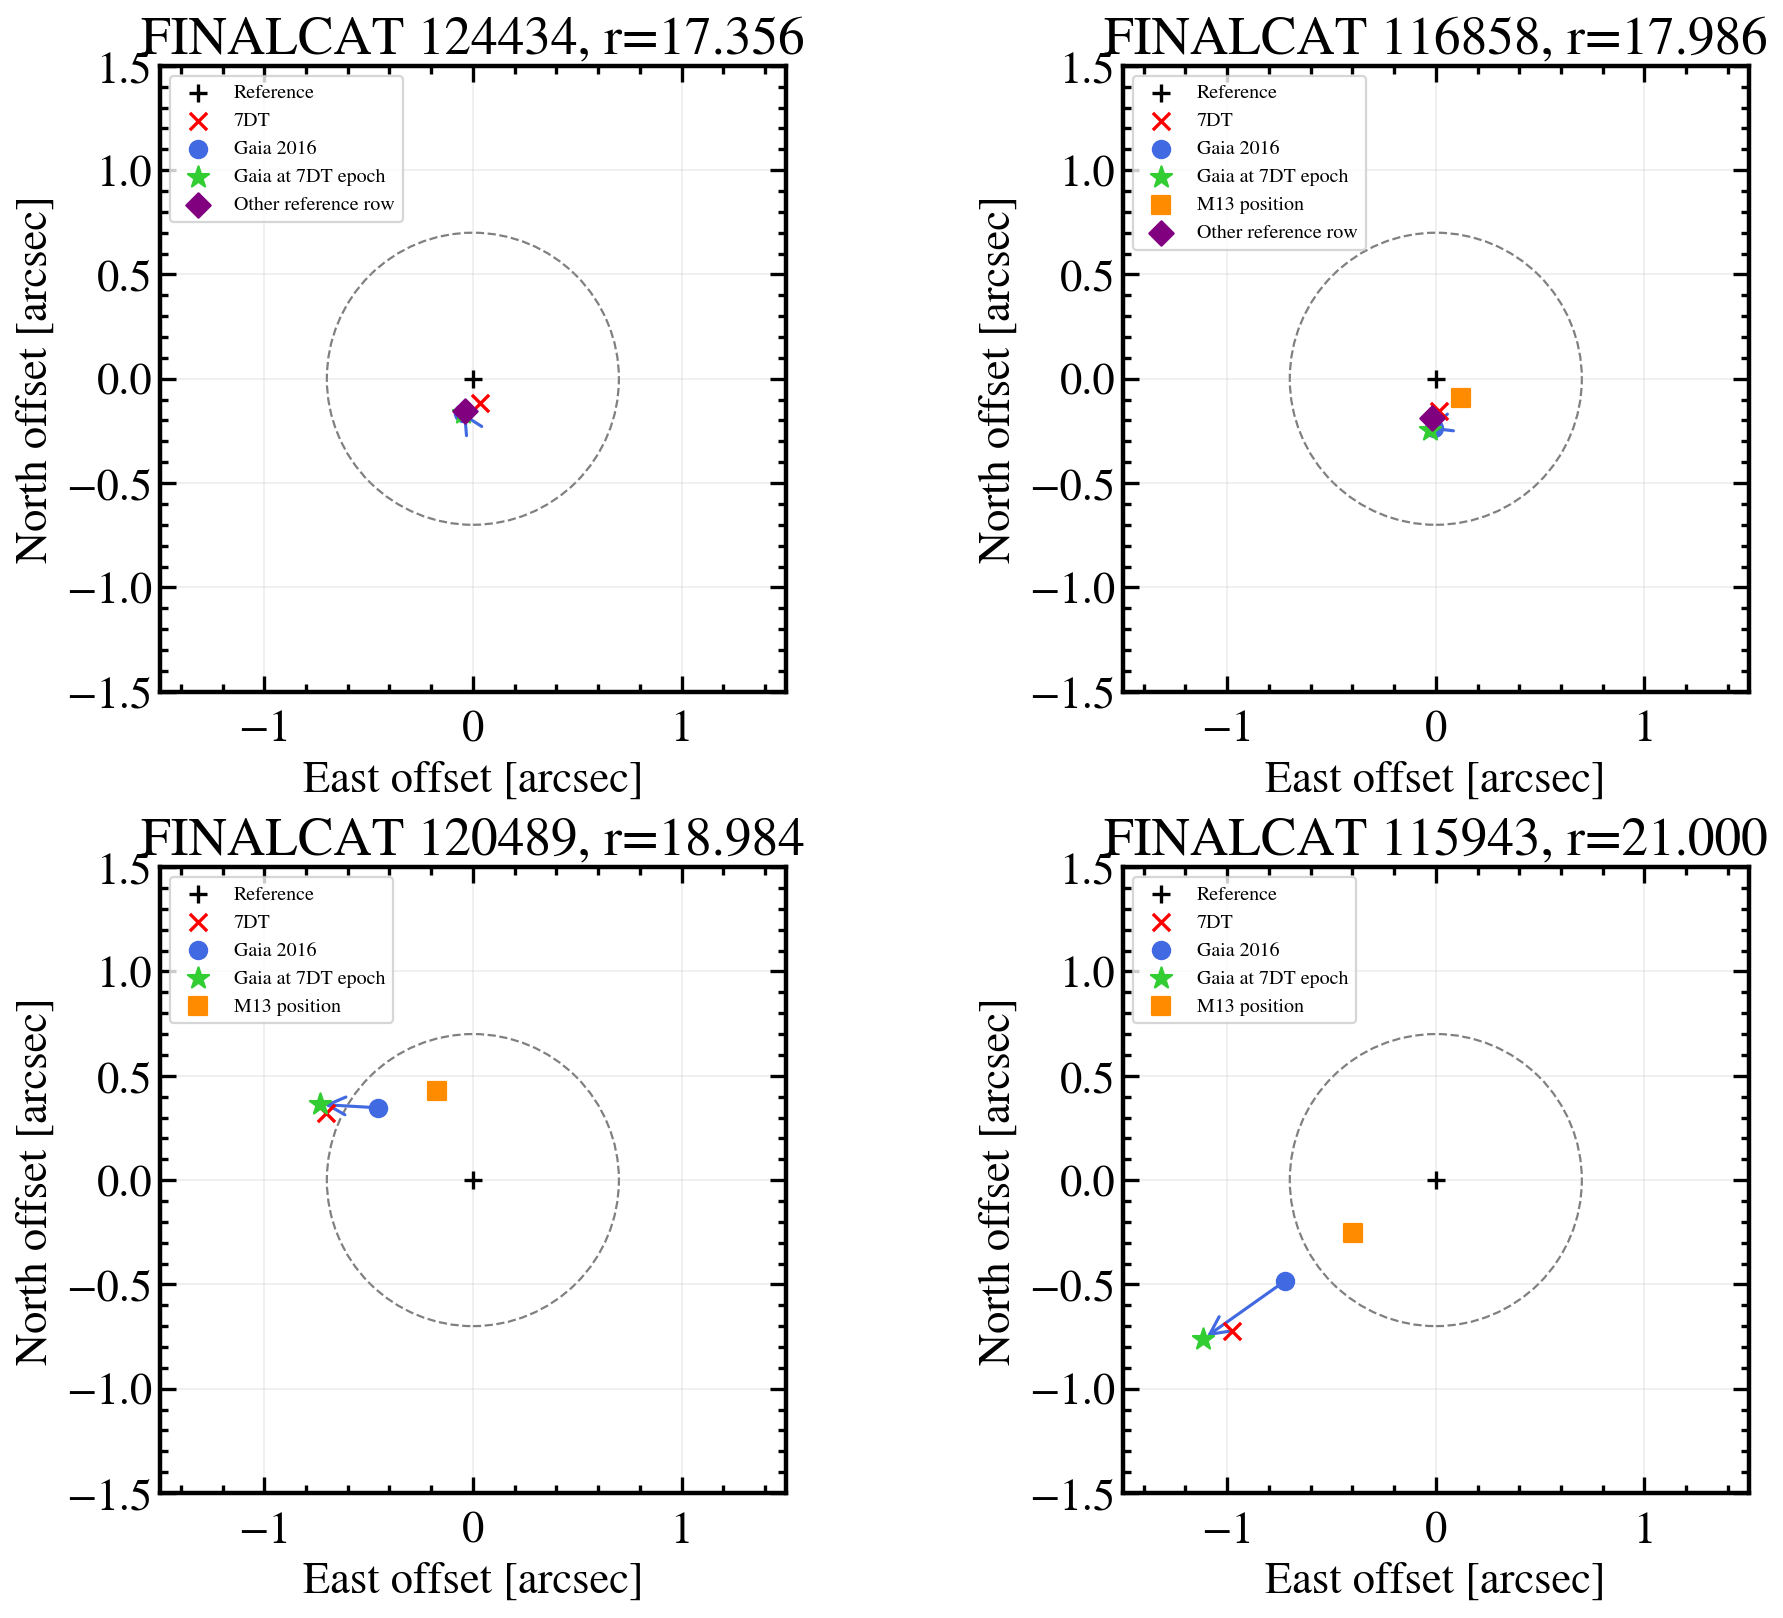

In [5]:
# Compare reference positions, original-survey positions, and Gaia motion.
# Offsets are east/north relative to each selected reference; no image or catalog
# is re-registered. The 0.7-arcsec circle is the production matching radius.
with plt.rc_context():
    scl_plt.default()
    fig, axes=plt.subplots(2,2,figsize=(12,10),layout='constrained',dpi=160)
    styles={'Reference':('black','+'),'7DT':('red','x'),'Gaia 2016':('royalblue','o'),
            'Gaia at 7DT epoch':('limegreen','*'),'M13 position':('darkorange','s'),
            'Other reference row':('purple','D')}
    for ax,(ref_idx,origin,points) in zip(axes.flat,audit_points):
        positions={}
        for label,coord in points:
            dx,dy=origin.spherical_offsets_to(SkyCoord(coord.ra, coord.dec)); x,y=dx.arcsec,dy.arcsec
            positions[label]=(x,y)
            color,marker=styles[label]
            ax.scatter(x,y,c=color,marker=marker,s=100 if marker=='*' else 60,label=label,zorder=5)
        ax.annotate('',xy=positions['Gaia at 7DT epoch'],xytext=positions['Gaia 2016'],
                    arrowprops=dict(arrowstyle='->',color='royalblue',lw=1.4))
        ax.add_patch(Circle((0,0),.7,fill=False,color='gray',ls='--'))
        ax.set(xlim=(-1.5,1.5),ylim=(-1.5,1.5),xlabel='East offset [arcsec]',ylabel='North offset [arcsec]',
               title=f"FINALCAT {ref_idx}, r={float(CUM_REFERENCE['RM'][ref_idx]):.3f}")
        ax.set_aspect('equal');ax.grid(alpha=.2)
        ax.legend(fontsize=9,loc='upper left')
    plt.show();plt.close(fig)


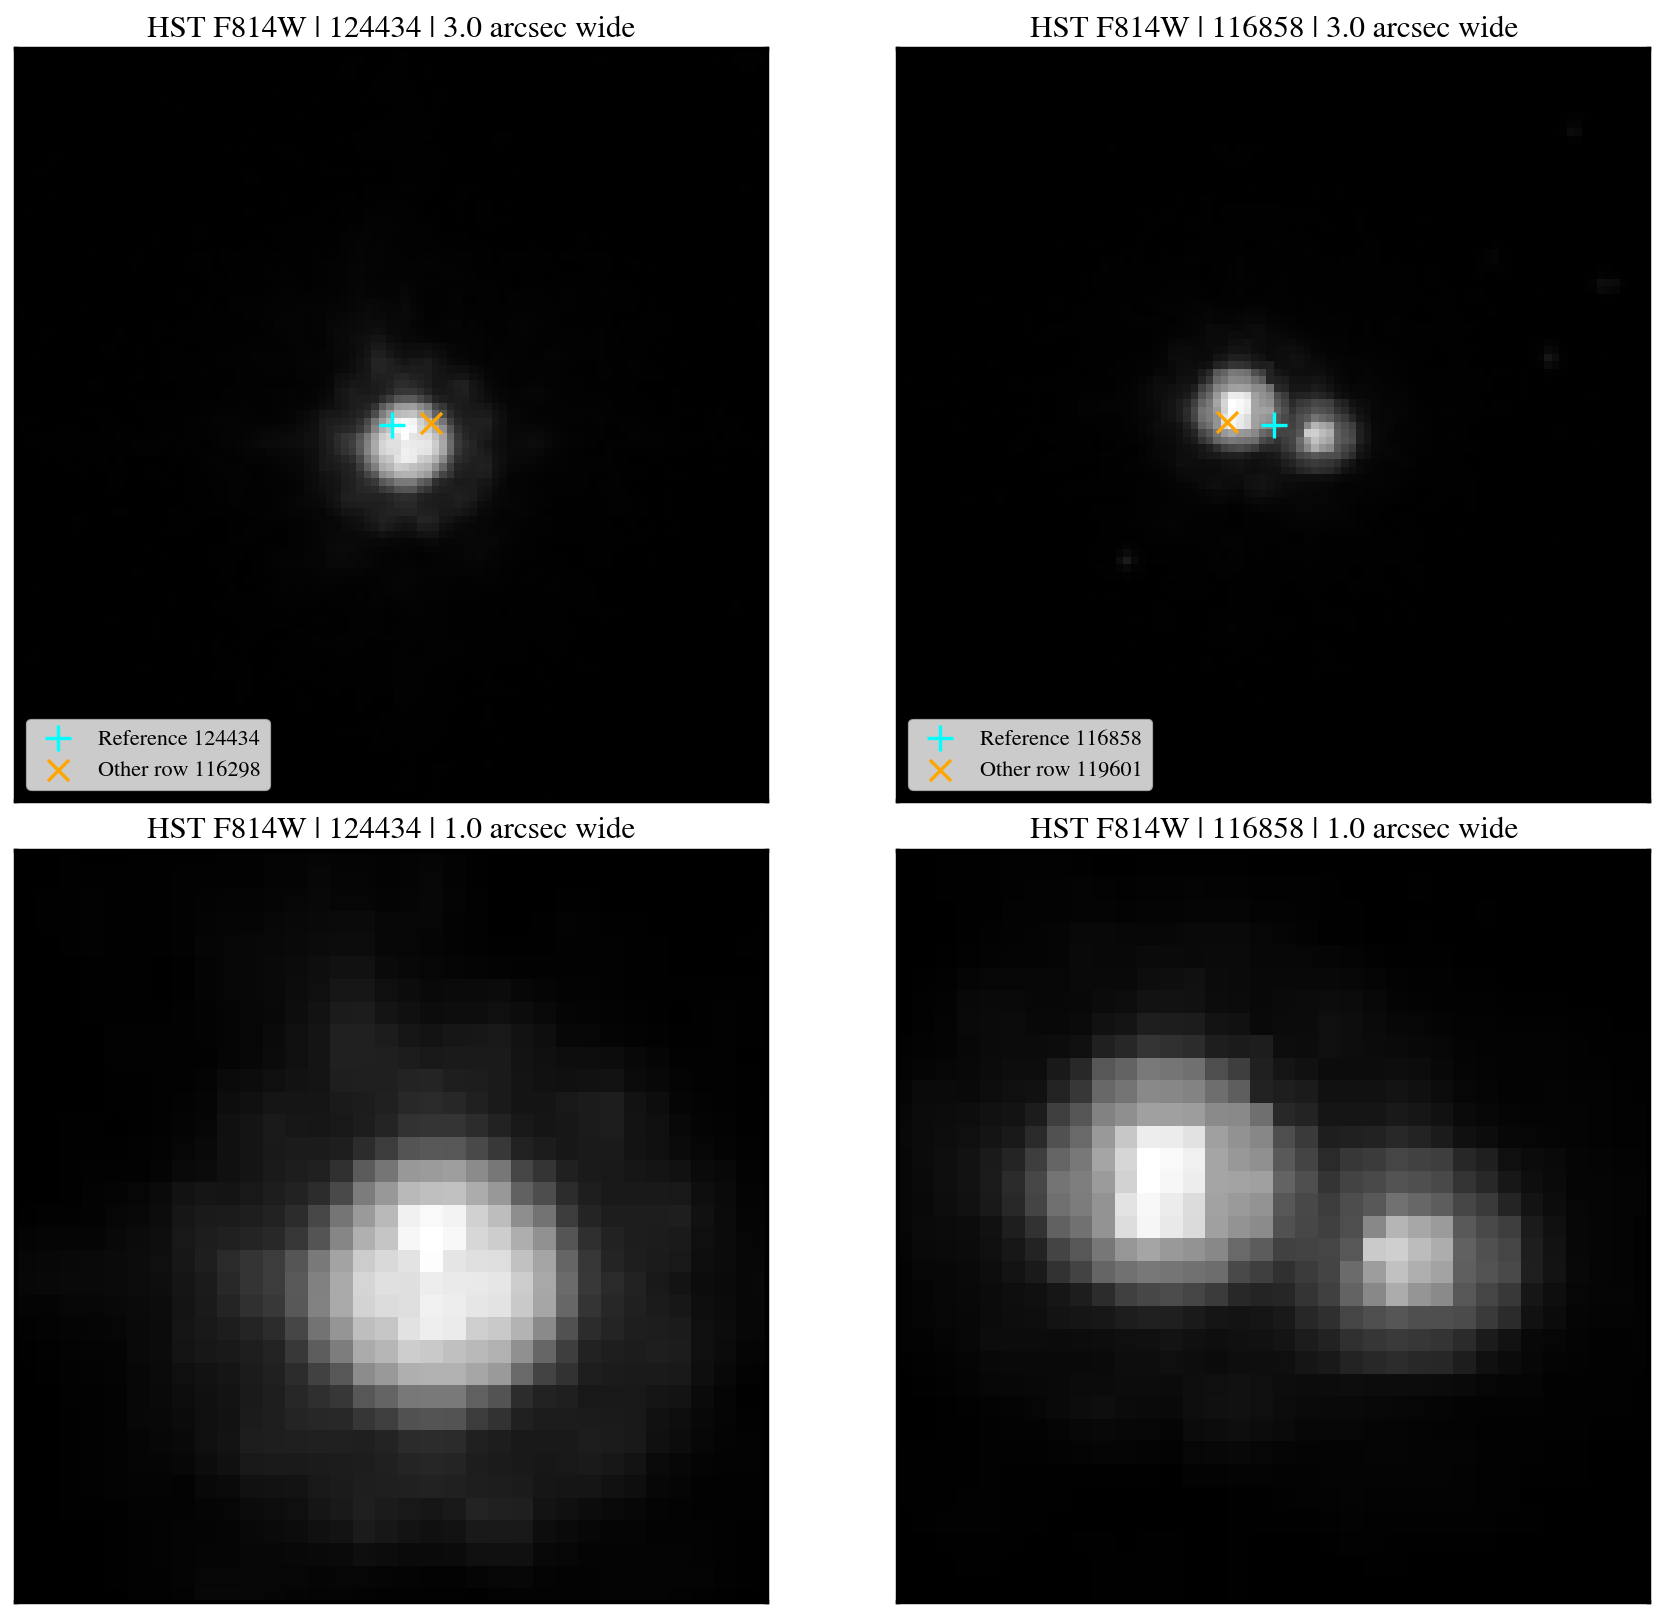

124434, ACS tile: 1 bright local peak(s)
116858, ACS tile 1: 2 bright local peak(s); two strongest peaks separated by approximately 0.313 arcsec
116858, ACS tile 2: 2 bright local peak(s); two strongest peaks separated by approximately 0.351 arcsec


In [2]:
# HST ACS F814W science cutouts from NASA/IPAC IRSA, native ~0.03 arcsec/pixel.
# Dataset DOI: 10.26131/IRSA178. URLs were returned by the official COSMOS SIA
# service. Read the FITS response in memory; write no figure or FITS files.
import io
import requests
from astropy.visualization import ImageNormalize, AsinhStretch
from astropy.wcs import WCS
from astropy.wcs.utils import proj_plane_pixel_scales
HST_AUDIT_URLS = {124434: 'https://irsa.ipac.caltech.edu:443/cgi-bin/Subimage/nph-subimage?origfile=/irsadata/COSMOS//images%2Facs_2.0%2FI%2Facs_I_095825%2B0145_unrot_sci_20.fits&ra=149.592450&dec=1.756760&xsize=0.003333', 116858: 'https://irsa.ipac.caltech.edu:443/cgi-bin/Subimage/nph-subimage?origfile=/irsadata/COSMOS//images%2Facs_2.0%2FI%2Facs_I_095859%2B0156_unrot_sci_20.fits&ra=149.776950&dec=1.939420&xsize=0.003333'}

HST_AUDIT_IMAGES = {}
for idx,url in HST_AUDIT_URLS.items():
    response = requests.get(url, timeout=60)
    response.raise_for_status()
    with fits.open(io.BytesIO(response.content)) as hdus:
        hdu = next(h for h in hdus if h.data is not None and h.data.ndim == 2)
        HST_AUDIT_IMAGES[idx] = (np.array(hdu.data,copy=True),hdu.header.copy())
with plt.rc_context():
    scl_plt.default()
    fig,axes=plt.subplots(2,2,figsize=(11,10),layout='constrained',dpi=160)
    for col,(idx,other_idx) in enumerate(((124434,116298),(116858,119601))):
        data,header=HST_AUDIT_IMAGES[idx];w=WCS(header)
        scale=float(proj_plane_pixel_scales(w)[0]*3600)
        ref=CUM_REFERENCE[idx];x,y=w.world_to_pixel_values(ref['RA'],ref['DEC'])
        other=CUM_REFERENCE[other_idx];ox,oy=w.world_to_pixel_values(other['RA'],other['DEC'])
        for row,halfsize in enumerate((1.5,.5)):
            ax=axes[row,col];h=halfsize/scale
            crop=data[max(0,int(y-h)):int(y+h)+1,max(0,int(x-h)):int(x+h)+1]
            good=crop[np.isfinite(crop)]
            assert good.size>0
            norm=ImageNormalize(vmin=np.percentile(good,5),vmax=np.max(good),stretch=AsinhStretch(.03))
            ax.imshow(data,origin='lower',cmap='gray',norm=norm,interpolation='nearest')
            if row==0:
                ax.scatter([x],[y],marker='+',s=140,color='cyan',label=f'Reference {idx}')
                ax.scatter([ox],[oy],marker='x',s=90,color='orange',label=f'Other row {other_idx}')
                ax.legend(fontsize=10,loc='lower left')
            ax.set_xlim(x-h,x+h);ax.set_ylim(y-h,y+h)
            ax.set_xticks([]);ax.set_yticks([])
            ax.set_title(f"HST F814W | {idx} | {2*halfsize:.1f} arcsec wide",fontsize=14)
    plt.show();plt.close(fig)

# A second overlapping ACS tile checks whether the double peak persists.
# This is a simple morphology diagnostic, not a two-PSF fit or a multiplicity
# completeness test. A single peak cannot exclude a much fainter companion.
from scipy.ndimage import gaussian_filter, maximum_filter
HST_SECOND_TILE_URL = 'https://irsa.ipac.caltech.edu:443/cgi-bin/Subimage/nph-subimage?origfile=/irsadata/COSMOS//images%2Facs_2.0%2FI%2Facs_I_095912%2B0156_unrot_sci_20.fits&ra=149.776950&dec=1.939420&xsize=0.003333'

second_response=requests.get(HST_SECOND_TILE_URL,timeout=60)
second_response.raise_for_status()
with fits.open(io.BytesIO(second_response.content)) as hdus:
    second_image=(np.array(hdus[0].data,copy=True),hdus[0].header.copy())
for idx,label,(data,header) in [(124434,'ACS tile',HST_AUDIT_IMAGES[124434]),
                               (116858,'ACS tile 1',HST_AUDIT_IMAGES[116858]),
                               (116858,'ACS tile 2',second_image)]:
    w=WCS(header);ref=CUM_REFERENCE[idx]
    cx,cy=w.world_to_pixel_values(ref['RA'],ref['DEC'])
    scale=float(proj_plane_pixel_scales(w)[0]*3600);rad=int(.8/scale)
    crop=data[int(cy)-rad:int(cy)+rad+1,int(cx)-rad:int(cx)+rad+1]
    smoothed=gaussian_filter(crop,.8)
    py,px=np.where((smoothed==maximum_filter(smoothed,size=7)) & (smoothed>.2*np.nanmax(smoothed)))
    order=np.argsort(smoothed[py,px])[::-1]
    message=f'{idx}, {label}: {len(order)} bright local peak(s)'
    if len(order)>1:
        sep=np.hypot(px[order[0]]-px[order[1]],py[order[0]]-py[order[1]])*scale
        message+=f'; two strongest peaks separated by approximately {sep:.3f} arcsec'
    print(message)


## fraction change test : remove binary source

Use the current `cosmos1-4_7dt_finalcat_matching_coverage_catalog.fits`. Remove only sources with `has_7dt_any == False` that have **another FINALCAT row with `has_7dt_any == True` at separation strictly less than 1.843 arcsec**. Thus the target is not detected by 7DT and at least one nearby reference source is detected. Search all detected FINALCAT rows without a neighbor magnitude cut; a non-detected nearest neighbor does not hide a farther detected neighbor inside the threshold. Detection means an assigned detection in any COSMOS field, not necessarily the same field. This test does not require an isolated pair and can flag crowded groups. Preserve distinct reference rows even at identical coordinates. This is a projected-neighbor sensitivity test, not a classification of physical binaries.

`BINARY_TEST_CATALOG` and `BINARY_REMOVED_CATALOG` are defined in memory only. All detected rows are retained. Fraction = sources detected in at least one 7DT field / reference sources remaining in the selected population. Compare both the full-reference denominator used above and the denominator restricted to `n_COSMOS_coverage > 0`; each denominator is recomputed after removal. Thus any increase measures the effect of excluding non-detections, not new detections. Invalid positions are retained and flagged as unassessable. Use the original 0.5-mag thresholds and bin-center plotting convention; summary rows use strict RM limits. No catalog or figure files are exported.


In [1]:
# Standalone in-memory neighbor test using the current coverage catalog.
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.table import Table
from IPython.display import display

BINARY_ROOT = next(path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                   if (path / 'Notebooks').is_dir() and (path / 'output').is_dir())
BINARY_RADIUS_ARCSEC = 1.843
BINARY_COVERAGE = Table.read(BINARY_ROOT / 'output/singlephot/cosmos1-4_7dt_finalcat_matching_coverage_catalog.fits')
binary_idx = np.asarray(BINARY_COVERAGE['finalcat_idx'], dtype=int)
assert len(np.unique(binary_idx)) == len(binary_idx)
binary_ra = np.asarray(np.ma.asarray(BINARY_COVERAGE['RA'], dtype=float).filled(np.nan))
binary_dec = np.asarray(np.ma.asarray(BINARY_COVERAGE['DEC'], dtype=float).filled(np.nan))
binary_position_valid = np.isfinite(binary_ra) & np.isfinite(binary_dec) & (np.abs(binary_dec) <= 90)
binary_position_rows = np.flatnonzero(binary_position_valid)
if len(binary_position_rows) < 2:
    raise ValueError('At least two valid reference positions are required.')
binary_coords = SkyCoord(binary_ra[binary_position_valid] * u.deg,
                         binary_dec[binary_position_valid] * u.deg)
# Query two neighbors on the unit sphere and exclude self by row identity.
# Explicit index handling also retains distinct rows at identical coordinates.
from scipy.spatial import cKDTree
binary_xyz = binary_coords.cartesian.xyz.value.T
_, binary_pair_indices = cKDTree(binary_xyz).query(binary_xyz, k=2)
binary_local_rows = np.arange(len(binary_coords))
binary_nearest_local = np.where(binary_pair_indices[:, 0] != binary_local_rows,
                                binary_pair_indices[:, 0], binary_pair_indices[:, 1])
assert np.all(binary_nearest_local != binary_local_rows)
binary_separation = binary_coords.separation(binary_coords[binary_nearest_local])
binary_nearest_sep = np.full(len(BINARY_COVERAGE), np.nan)
binary_nearest_idx = np.full(len(BINARY_COVERAGE), -1, dtype=int)
binary_nearest_sep[binary_position_rows] = binary_separation.arcsec
binary_nearest_idx[binary_position_rows] = binary_idx[binary_position_rows[binary_nearest_local]]
binary_detected = np.asarray(BINARY_COVERAGE['has_7dt_any'], dtype=bool)
binary_in_coverage = np.asarray(BINARY_COVERAGE['n_COSMOS_coverage'], dtype=int) > 0
# Revised condition: the target must be non-detected, while the nearby
# FINALCAT neighbor must have an assigned 7DT detection. Query the detected
# subset directly so an even closer non-detected neighbor cannot hide a match.
binary_detected_rows = np.flatnonzero(binary_position_valid & binary_detected)
binary_target_rows = np.flatnonzero(binary_position_valid & ~binary_detected)
binary_nearest_detected_sep = np.full(len(BINARY_COVERAGE), np.nan)
binary_nearest_detected_idx = np.full(len(BINARY_COVERAGE), -1, dtype=int)
if len(binary_detected_rows) and len(binary_target_rows):
    binary_detected_coords = SkyCoord(binary_ra[binary_detected_rows]*u.deg,
                                      binary_dec[binary_detected_rows]*u.deg)
    binary_target_coords = SkyCoord(binary_ra[binary_target_rows]*u.deg,
                                    binary_dec[binary_target_rows]*u.deg)
    _, binary_detected_nearest = cKDTree(binary_detected_coords.cartesian.xyz.value.T).query(
        binary_target_coords.cartesian.xyz.value.T)
    binary_neighbor_rows = binary_detected_rows[binary_detected_nearest]
    binary_detected_separation = binary_target_coords.separation(
        binary_detected_coords[binary_detected_nearest]).arcsec
    binary_nearest_detected_sep[binary_target_rows] = binary_detected_separation
    binary_nearest_detected_idx[binary_target_rows] = binary_idx[binary_neighbor_rows]
    assert np.all(binary_detected[binary_neighbor_rows])
    assert np.all(binary_target_rows != binary_neighbor_rows)
BINARY_REMOVE = (~binary_detected & binary_position_valid
                 & (binary_nearest_detected_sep < BINARY_RADIUS_ARCSEC))
# The revised exclusions must be a subset of the original all-neighbor cut.
binary_previous_broad_remove = (~binary_detected & binary_position_valid
                                & (binary_nearest_sep <= BINARY_RADIUS_ARCSEC))
assert np.all(~BINARY_REMOVE | binary_previous_broad_remove)
# Copy before adding diagnostic columns so the input table is unchanged.
BINARY_ANNOTATED = BINARY_COVERAGE.copy()
BINARY_ANNOTATED['nearest_other_finalcat_idx'] = binary_nearest_idx
BINARY_ANNOTATED['nearest_other_sep_arcsec'] = binary_nearest_sep
BINARY_ANNOTATED['neighbor_position_valid'] = binary_position_valid
# These neighbor columns are defined for non-detected targets only; NaN/-1
# indicate a missing association (including detected rows that were not queried).
BINARY_ANNOTATED['nearest_detected_finalcat_idx'] = binary_nearest_detected_idx
BINARY_ANNOTATED['nearest_detected_sep_arcsec'] = binary_nearest_detected_sep
BINARY_TEST_CATALOG = BINARY_ANNOTATED[~BINARY_REMOVE].copy()
BINARY_REMOVED_CATALOG = BINARY_ANNOTATED[BINARY_REMOVE].copy()
assert not np.any(BINARY_REMOVE & binary_detected)
assert len(BINARY_TEST_CATALOG) + len(BINARY_REMOVED_CATALOG) == len(BINARY_COVERAGE)
binary_rm = np.asarray(np.ma.asarray(BINARY_COVERAGE['RM'], dtype=float).filled(np.nan))
binary_valid_rm = np.isfinite(binary_rm) & (binary_rm > 0) & (binary_rm < 50)
# Reuse the notebook's exact threshold array when available; otherwise reconstruct it.
if 'CUM_THRESHOLDS' in globals():
    BINARY_THRESHOLDS = np.asarray(CUM_THRESHOLDS).copy()
else:
    binary_valid_values = binary_rm[binary_valid_rm]
    BINARY_THRESHOLDS = np.arange(np.floor(binary_valid_values.min()*2)/2,
                                 np.ceil(binary_valid_values.max()*2)/2 + 0.5, 0.5)
BINARY_BIN_CENTERS = (BINARY_THRESHOLDS[:-1] + BINARY_THRESHOLDS[1:]) / 2


def binary_cumulative_counts(selection):
    """Count reference rows at RM <= threshold, before cropping the plot."""
    return np.searchsorted(np.sort(binary_rm[selection & binary_valid_rm]),
                           BINARY_THRESHOLDS, side='right')


BINARY_FRACTION_CURVES = {}
binary_summary_rows = []
for population, population_mask in (
        ('All FINALCAT', np.ones(len(BINARY_COVERAGE), dtype=bool)),
        ('Inside >=1 coverage', binary_in_coverage)):
    denominator_before = binary_cumulative_counts(population_mask)
    denominator_after = binary_cumulative_counts(population_mask & ~BINARY_REMOVE)
    numerator = binary_cumulative_counts(population_mask & binary_detected)
    fraction_before = np.divide(numerator, denominator_before,
        out=np.full(len(numerator), np.nan), where=denominator_before > 0)
    fraction_after = np.divide(numerator, denominator_after,
        out=np.full(len(numerator), np.nan), where=denominator_after > 0)
    BINARY_FRACTION_CURVES[population] = (fraction_before, fraction_after)
    for limit in (18., 19., 20., 21., np.inf):
        selected = population_mask & binary_valid_rm & (binary_rm < limit)
        n_before = int(selected.sum())
        n_removed = int((selected & BINARY_REMOVE).sum())
        n_after = n_before - n_removed
        n_detected = int((selected & binary_detected).sum())
        before = n_detected / n_before if n_before else np.nan
        after = n_detected / n_after if n_after else np.nan
        binary_summary_rows.append((population, limit, n_before, n_removed,
                                    n_after, n_detected, before, after, 100*(after-before)))
BINARY_FRACTION_CHANGE = Table(rows=binary_summary_rows, names=[
    'population', 'RM_upper_exclusive', 'N_before', 'N_removed', 'N_after',
    'N_detected', 'fraction_before', 'fraction_after', 'change_percentage_points'])
for name in ('fraction_before', 'fraction_after'):
    BINARY_FRACTION_CHANGE[name].format = '.5f'
BINARY_FRACTION_CHANGE['change_percentage_points'].format = '.3f'
print(f'Detected-neighbor threshold: separation < {BINARY_RADIUS_ARCSEC:.3f} arcsec')
print(f'Previous all-neighbor exclusions: {binary_previous_broad_remove.sum():,}; '
      f'revised detected-neighbor exclusions: {BINARY_REMOVE.sum():,}')
print(f'All rows: {len(BINARY_COVERAGE):,}; removed: {BINARY_REMOVE.sum():,}; '
      f'test catalog: {len(BINARY_TEST_CATALOG):,}')
print(f'Invalid positions retained: {(~binary_position_valid).sum():,}')
print('RM_upper_exclusive = inf includes all valid RM values (0 < RM < 50).')
print('\n'.join(BINARY_FRACTION_CHANGE.pformat(max_lines=-1, max_width=-1)))


Detected-neighbor threshold: separation < 1.843 arcsec
Previous all-neighbor exclusions: 5,284; revised detected-neighbor exclusions: 584
All rows: 126,280; removed: 584; test catalog: 125,696
Invalid positions retained: 0
RM_upper_exclusive = inf includes all valid RM values (0 < RM < 50).
     population     RM_upper_exclusive N_before N_removed N_after N_detected fraction_before fraction_after change_percentage_points
------------------- ------------------ -------- --------- ------- ---------- --------------- -------------- ------------------------
       All FINALCAT               18.0      202        13     189        183         0.90594        0.96825                    6.231
       All FINALCAT               19.0      905        50     855        825         0.91160        0.96491                    5.331
       All FINALCAT               20.0     2797        90    2707       2603         0.93064        0.96158                    3.094
       All FINALCAT               21.0     

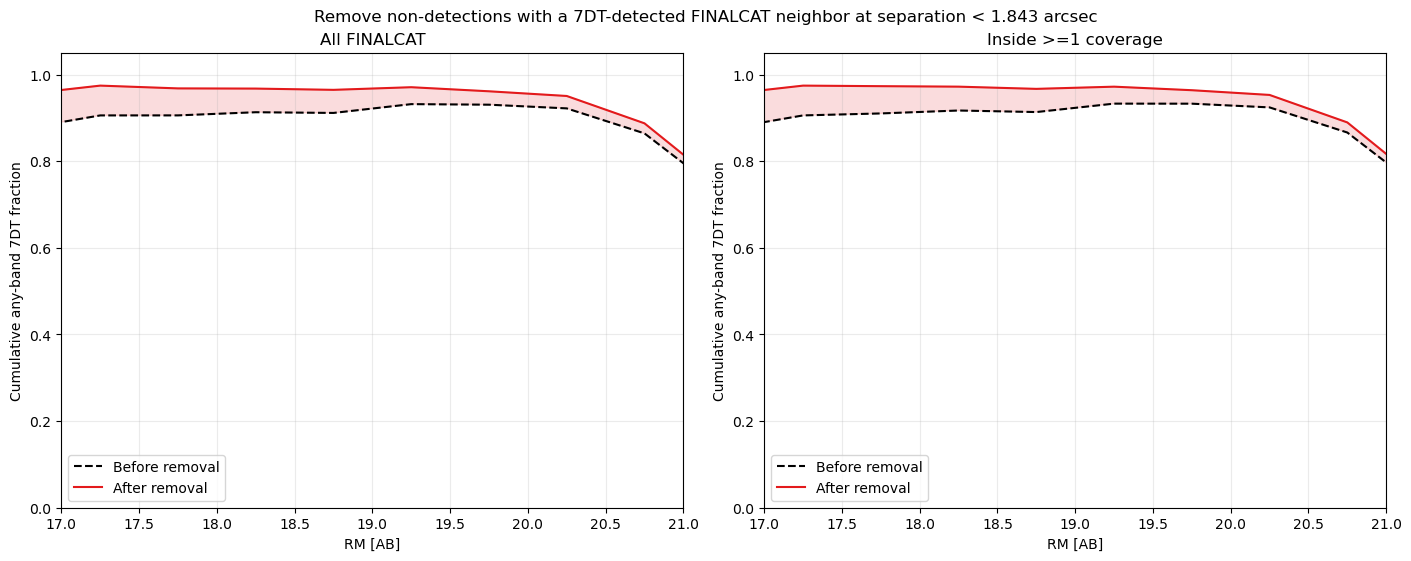

In [2]:
# Display-only comparison: changing the denominator retains every detection.
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), layout='constrained')
for ax, (population, (before, after)) in zip(axes, BINARY_FRACTION_CURVES.items()):
    ax.plot(BINARY_BIN_CENTERS, before[1:], color='black', ls='--',
            label='Before removal')
    ax.plot(BINARY_BIN_CENTERS, after[1:], color='#E31A1C',
            label='After removal')
    ax.fill_between(BINARY_BIN_CENTERS, before[1:], after[1:], color='#E31A1C', alpha=.15)
    ax.set(xlim=(17, 21), ylim=(0, 1.05), xlabel='RM [AB]',
           ylabel='Cumulative any-band 7DT fraction', title=population)
    ax.set_xticks(np.arange(17, 21.1, .5))
    ax.grid(alpha=.25)
    ax.legend(loc='lower left')
fig.suptitle('Remove non-detections with a 7DT-detected FINALCAT neighbor at separation < 1.843 arcsec')
plt.show()
plt.close(fig)


## test : remove proper motion sources

Independent of the binary-removal test: start again from the **original coverage catalog**. Gaia DR3 proper motions are in mas/yr and its reference epoch is J2016.0. Use a fixed **20-year FINALCAT-to-7DT baseline**, as requested, and read the production matching radius from the field master metadata. Displacement is `hypot(pmra, pmdec) * 20 / 1000` arcsec; Gaia `pmra` already includes cos(dec). The 20 years are an approximate observational baseline, not the interval from Gaia's J2016.0 reference epoch. The 0.7-arcsec production radius corresponds to a strict proper-motion cut of **35 mas/yr**.

For this exploratory association, select the nearest Gaia DR3 position at its native reference epoch within **1.843 arcsec** of each non-detected FINALCAT position, requiring a unique Gaia candidate within that radius and a unique FINALCAT counterpart within that radius. This association radius is separate from the production 0.7-arcsec matching radius. The FINALCAT combines surveys with different position epochs: no common FINALCAT epoch is assumed. Missing/ambiguous Gaia associations remain in the catalog; larger displacements can move stars outside the association radius. The association is therefore provisional, and the estimated 20-year displacement alone does not establish why the FINALCAT match failed. No RUWE or significance cut is imposed; diagnostics retain those measurements.

Remove only original non-detections with an unambiguous Gaia association whose predicted displacement exceeds the matching radius **in every field covering that reference source**. For sources outside all footprints use the same fixed 20-year baseline and the common production radius; these removals affect only the full-reference comparison. Store Gaia data, test catalogs, summary tables, and figures inside this notebook; export no catalog/figure files. Recompute both the full-reference and in-coverage fractions as in the independent binary test.

Gaia provenance: ESA TAP `gaiadr3.gaia_source`; exact ADQL and returned CSV are embedded below. Query bounds extend beyond the complete FINALCAT footprint. Documentation: [Gaia DR3 astrometric solution](https://arxiv.org/abs/2012.03380).


In [3]:
# Exact Gaia DR3 query response embedded for reproducible, offline re-execution.
PM_GAIA_ADQL = 'SELECT source_id,ra,dec,ref_epoch,pmra,pmdec,pmra_error,pmdec_error,phot_g_mean_mag,ruwe,duplicated_source FROM gaiadr3.gaia_source WHERE ra BETWEEN 149.33 AND 150.86 AND dec BETWEEN 1.45 AND 2.97 AND pmra IS NOT NULL AND pmdec IS NOT NULL'
PM_GAIA_CSV = 'source_id,ra,dec,ref_epoch,pmra,pmdec,pmra_error,pmdec_error,phot_g_mean_mag,ruwe,duplicated_source\n3834462929747979904,150.1388350118077,1.4697376895867038,2016.0,-7.735676868380102,3.4643620417724867,0.59615225,0.7912993,18.64442,1.5645367,false\n3834498045400586112,149.44653165410082,1.4551042788006545,2016.0,-0.90967360090228,-0.5133776645242081,0.36995918,0.4380478,19.189512,1.0771768,false\n3834509349754233088,149.9239327124383,1.471994425170801,2016.0,25.260950091888706,-9.224110132932736,0.022658078,0.020806443,13.216457,1.2287148,false\n3834510483626072832,150.0694402773333,1.5172767318466889,2016.0,9.189547597550852,-35.23011391495501,0.17792208,0.18180588,18.030241,1.0568949,false\n3834510792863533696,149.96399981811288,1.4904509864112712,2016.0,0.15663963226073782,-5.318028007977417,0.98707634,1.4410149,20.158724,0.9862658,false\n3834514538075211392,150.02379055189485,1.563277241950536,2016.0,-27.0105263804099,-1.2294257126610906,0.9268327,0.9297788,20.249031,1.0755879,false\n3834514675514165888,149.98103528158717,1.5656064210405167,2016.0,-7.695918676266178,-1.0375544087182753,0.3257495,0.28923953,19.16927,1.0332326,false\n3834514847312864768,149.9718821342156,1.5895706705933714,2016.0,-16.616549829330577,-16.61142128016644,0.38598374,0.3359018,19.442703,0.9839483,false\n3834515298284177664,149.87385231538903,1.5722541841511093,2016.0,-4.074701342878631,-5.196046731461781,0.36972755,0.39465654,19.366213,0.9712131,false\n3834523991297974912,149.5297001389415,1.5589661210367278,2016.0,-10.118148586065294,-4.984979528024615,0.025147643,0.026199155,14.474006,1.0985129,false\n3834524300535619456,149.59565173712443,1.583411263698691,2016.0,-8.225145590896773,-2.113287677361962,0.047381774,0.049130857,15.903658,1.0426915,false\n3834524506694048896,149.62057247260975,1.614808457608511,2016.0,1.171504057482703,-0.7883457404236962,0.4135961,0.4633367,19.503286,1.0520893,false\n3834524708557785088,149.59676465866656,1.628229506492401,2016.0,0.4075605375870808,-11.905906187211182,0.72537243,0.8615317,20.031946,0.99883044,false\n3834525086514950272,149.73963093780893,1.5197095433451386,2016.0,-6.756042270978115,-12.984227518293476,1.1513698,1.446967,20.270575,1.0362564,false\n3834526082947305728,149.75600543444816,1.5705305407191008,2016.0,-10.026732048378989,-0.9694515733773923,0.39859858,0.4446049,19.506699,0.9551371,false\n3834526667062867712,149.78195185485697,1.605927508861937,2016.0,-2.384632106047619,-4.428410642243164,0.2921402,0.42988276,18.692621,0.9236677,false\n3834528453769293312,149.76952849758567,1.6408667861366841,2016.0,-11.51091179415661,-0.3046254364783873,0.9098278,1.1093591,19.986883,1.0626361,false\n3834528900445873664,149.87775982183587,1.6811156664277476,2016.0,0.34542814625608487,-0.6747249093007214,0.10684875,0.099798575,17.620777,1.0131545,false\n3834529351417158272,149.70349737090044,1.5897628992008497,2016.0,-50.23288397446797,-6.141167728753814,0.044317223,0.043345045,16.040802,1.0273811,false\n3834529420136635264,149.685593927856,1.6047875354849188,2016.0,-3.476490457563993,-6.305613280829074,0.04070341,0.038486827,15.805967,0.9486905,false\n3834530107331402112,149.69411392052967,1.6390052949436371,2016.0,-7.043187638840607,-9.070787163420851,0.10184115,0.09714952,17.48792,1.0497475,false\n3834530240475689088,149.71716430146824,1.6573406744507946,2016.0,-0.2783150778554247,-4.706159953642993,1.1659441,1.3929771,20.4898,1.0080063,false\n3834531099469130112,149.6991245948773,1.6915922276706092,2016.0,-4.22025567316878,0.5074407978266259,0.09675265,0.096150234,17.137003,1.0944368,false\n3834532748736575488,149.7378373040322,1.7261823595209045,2016.0,-10.596658347997407,4.356829658075788,0.1105834,0.10174347,17.510122,0.9503454,false\n3834709701388937728,149.45114941500313,1.528158955849023,2016.0,-12.430015794963849,7.552428693888072,0.44726476,0.5422866,19.395868,1.0289193,false\n3834710903979793024,149.3529161615979,1.5609700915748521,2016.0,1.6169231387093443,-12.895344343089759,0.31992176,0.33360878,18.778948,0.9383566,false\n3834711831692743296,149.5047845770051,1.5968128566268396,2016.0,-9.072583232737966,0.3049542864723197,0.20099756,0.23470214,18.23769,1.1084795,false\n3834711934771962496,149.51433874387692,1.6074419296394138,2016.0,-13.238615662173615,-1.6991097727638882,0.18350224,0.21226174,18.235249,0.9331133,false\n3834712003491434624,149.47581580004888,1.5954384165614375,2016.0,2.2848580746895966,-26.081565606955753,0.19860592,0.23258123,18.267357,0.9717339,false\n3834712282664213120,149.54174588037947,1.6129309122360986,2016.0,-1.810411466501847,-0.09352386698637424,0.034465905,0.034999214,15.27312,0.9788609,false\n3834712896844644352,149.45166754985556,1.6241386321656597,2016.0,-3.9396773552343762,-22.48386758411756,0.5471747,0.53541315,19.469797,0.92228603,false\n3834713828852487424,149.51609604813277,1.6997620323486404,2016.0,-2.117123093460712,-2.0365557570391672,1.2618188,1.0498672,20.416718,0.94746006,false\n3834713961996516736,149.33912588701804,1.5842312613252134,2016.0,-2.8010934276317854,-8.060085986150872,0.2141592,0.22123115,17.946943,1.0801735,false\n3834714614831564800,149.3964256468625,1.6279802834545563,2016.0,-1.5415929753427031,-5.158921185953787,0.21583569,0.22260013,18.032211,0.9305069,false\n3834716367178241408,149.43396734216532,1.6821046846771628,2016.0,-17.802094828317102,-10.917964812877969,0.32201684,0.32703647,18.479542,0.98043793,false\n3834716710775631488,149.47688576312837,1.6993375434663298,2016.0,-4.213490862414557,-1.5165658081357734,0.15900335,0.14601241,17.815712,0.96387583,false\n3834717913366715264,149.43145430744872,1.7462281822202055,2016.0,-16.822162365249053,3.7263902431094498,1.009874,1.1423488,20.305738,0.9776223,false\n3834718158179475072,149.3921689256695,1.7595571736977766,2016.0,23.687014232937855,-11.86389202925889,0.081543334,0.083674386,16.586382,1.0061195,false\n3834719120251772416,149.6564465410757,1.7333174021100164,2016.0,-13.34207484325785,4.3710845427278135,0.36085925,0.3170473,18.944567,0.98455375,false\n3834719532569005952,149.5449847537333,1.7052317502588856,2016.0,-8.166588401741166,6.631620579141415,0.03420334,0.030137973,14.832256,0.91761166,false\n3834720971383216512,149.68122318873637,1.7728223167915305,2016.0,-2.2751368111170738,-6.511064552518027,0.2726621,0.35529134,18.371143,1.0259458,false\n3834721521139041280,149.72805324682278,1.8082675694205788,2016.0,-3.250530878674515,-0.4320308892676655,0.36731008,0.30653054,19.209076,1.0596452,false\n3834722036535112448,149.62740576197825,1.7960354324854697,2016.0,5.257150629182451,-12.45528174973249,0.33445394,0.34462723,18.699614,1.0954221,false\n3834722448851981696,149.65661941297654,1.8169449044568164,2016.0,-15.348094757609088,2.1806183579717873,0.13874006,0.13665183,17.664795,1.0562913,false\n3834722865463627264,149.52309111655015,1.7477035482910133,2016.0,-5.1532160091094195,-4.866768606628713,0.06571929,0.061650146,16.13272,1.002186,false\n3834723136046730752,149.49616991211468,1.7642262762139072,2016.0,-1.3815155025112509,-4.045931472012807,0.16274516,0.16707566,17.941143,0.9536396,false\n3834723204766424704,149.48961737262042,1.7708778280358057,2016.0,-1.3146148781331541,-5.665815249173517,1.1357334,1.2572991,20.31626,1.1017151,false\n3834723788881923840,149.55122115980888,1.8151423872232464,2016.0,0.605965176096239,-9.192641721348613,1.3348154,1.6402545,20.310543,0.861042,false\n3834725747386877184,149.6183359386181,1.8588990517408672,2016.0,-4.552062252283653,2.227781055313028,0.36769277,0.3126332,19.26041,1.0311667,false\n3834727057351702144,149.58392928294032,1.9232471486384328,2016.0,-8.67945090635985,5.282504134557018,0.01666976,0.014164586,12.342524,1.1267097,false\n3834735986588896640,149.39941123778044,1.8142440448683177,2016.0,5.555765781892879,-11.299097489390107,0.88790256,1.1616744,20.264992,1.0010421,false\n3834736639423944192,149.49010215909368,1.871337056737776,2016.0,-13.978739036251602,-5.0487490384642015,0.060833383,0.061353453,16.194735,1.0336859,false\n3834737945094015232,149.39725971500644,1.9161889525650655,2016.0,0.522011351277016,-10.172511594919635,1.434013,1.7329072,20.53751,1.0443376,false\n3834738941526433280,149.51511776309394,1.9294899955828722,2016.0,8.517053479018086,-9.827736831046474,0.6287623,0.712189,19.884653,1.1012747,false\n3834739701735425280,149.45055953168327,1.960141391360872,2016.0,15.568143200447206,-18.747715228951506,0.043420624,0.043400962,15.218522,1.2292913,false\n3834740079692545408,149.48752868314446,1.9764589514583422,2016.0,-7.841732260214151,-1.9426896242598775,0.07314867,0.0682723,16.75719,1.0402262,false\n3834740453355088384,149.350463111513,1.8872349708707181,2016.0,-19.86070263753505,7.555630075134386,1.7775185,1.4631222,20.408432,1.1955093,false\n3834743515666128384,149.46506105075375,2.033512013128763,2016.0,-20.71078743370372,1.1578076318978354,1.3527472,1.4655538,20.569937,1.0350288,false\n3834743648810606720,149.3816878012206,1.99185289158575,2016.0,-6.500888693361218,-19.74778942670452,0.22032666,0.25819507,18.385183,0.94884026,false\n3834791580645644032,149.3921499385027,2.076355848752453,2016.0,17.63562728750587,-39.151306439592425,0.68137074,0.8072561,19.975233,1.008857,false\n3834791894177960192,149.3827294104703,2.1058513893360202,2016.0,1.2847099059021045,-4.102047632491517,0.04127951,0.03147348,14.980066,0.94797844,false\n3835201767202065664,150.82870189581865,1.450964256829377,2016.0,-7.835917239694293,-14.32131749729125,0.9515549,1.1686879,20.180254,1.039888,false\n3835202007720008192,150.82627859170088,1.4720917435114669,2016.0,-1.727199305093982,-5.831442689162536,0.028347213,0.027959026,14.710989,1.1012788,false\n3835949606907545600,150.4402600458057,1.4633775747049156,2016.0,-1.4272644951752111,-8.560800569426481,0.5104131,0.60366535,19.685833,1.0191114,false\n3835949744346504832,150.47337103836114,1.4827134912446724,2016.0,-18.684082268982973,10.983793669977835,0.20372972,0.23377118,17.958658,1.1784586,false\n3835958540439180416,150.63969849354453,1.6323837994851909,2016.0,-3.5361769320803846,-8.072052742968122,0.44662437,0.53544694,19.266298,1.154739,false\n3835964106717477888,150.1745189084562,1.4797548823480864,2016.0,-10.796728340529661,-22.285495162564914,0.123485334,0.11519197,16.68685,1.6136757,false\n3835967478266512640,150.46477472800623,1.5255596571952488,2016.0,-12.926880257033533,0.5532779848470348,0.079815455,0.091169566,15.476093,1.810926,false\n3835968401684073088,150.4985150495459,1.5843300099256457,2016.0,-6.495164322119797,1.0282987239753174,0.15998055,0.19737944,17.755192,0.94021165,false\n3835968573482754944,150.42780564775987,1.5602056888550446,2016.0,-7.572050666844977,-2.3729726564533618,0.3189,0.39613408,18.783854,1.088308,false\n3835969333692079744,150.45593792723378,1.602533758095815,2016.0,-40.32838570374465,-77.33607478009087,0.6140369,0.6276434,19.79986,0.99249023,false\n3835969879152796032,150.55075215972144,1.603989693607896,2016.0,-7.164478310839258,-9.004024012977652,0.021439487,0.025372403,12.539172,0.99525607,false\n3835970742441349888,150.50119167356561,1.6162707140984327,2016.0,3.5687425345482198,-6.3389583081466006,0.28283477,0.303325,18.156792,1.0496054,false\n3835970742441653632,150.50347252075736,1.6186738941697956,2016.0,7.871094998399988,-6.0239553384633915,0.029326465,0.037233546,14.165022,1.0028232,false\n3835971562780036736,150.52543298235503,1.6815180388935194,2016.0,-6.300198759017675,-2.2317075268945867,0.35668364,0.42693964,19.051256,0.9763425,false\n3835972627931914880,150.41363408206243,1.6466151654713312,2016.0,-3.153046863944266,-10.933980077558749,1.0776423,1.0741831,20.412333,1.0280702,false\n3835974247134929280,150.44976697129854,1.6640491018434067,2016.0,1.164147435934368,-13.851352199669828,0.09820786,0.098212406,16.623993,1.0561548,false\n3835974448998199296,150.44917269872872,1.6978761035331984,2016.0,-0.6475820672272431,-4.743986505833145,0.97422826,1.1605161,20.383793,0.9816778,false\n3835974517717538944,150.51283328841373,1.6900114535963684,2016.0,5.695318881101247,-14.167041459672163,0.4219795,0.50656277,19.323156,0.8984084,false\n3835975071768650752,150.41645976076833,1.689892926327693,2016.0,-1.220095893762032,-1.3936401908813487,0.11784318,0.13656363,16.80131,1.2314653,false\n3835975827682890752,150.48360199042378,1.7505609580168204,2016.0,-44.404846463757075,-10.379245975316039,0.020611443,0.025700666,13.237621,0.9853725,false\n3835975892108673664,150.44258653989468,1.7467428893025259,2016.0,-4.872099878890084,-1.125042237636467,0.63304263,0.78693134,19.76417,1.1545502,false\n3835976407503095168,150.84748069649456,1.536134004975597,2016.0,-0.24670919731989563,-5.02269801986856,0.54099464,0.6585042,19.974976,0.99048924,false\n3835977266496557568,150.77930366621186,1.5451654906689558,2016.0,1.1179711836319062,-2.058920836565948,0.25037217,0.27912784,18.67768,1.0547497,false\n3835978056770566272,150.83925595641603,1.6148893150287784,2016.0,-8.132248689094503,-2.0361293041243678,0.43242496,0.48254928,19.543818,1.0454054,false\n3835978297288736640,150.81248968626232,1.619556903146725,2016.0,-17.880573116346287,12.963134172610868,0.38961062,0.3751209,19.201227,0.98249435,false\n3835980908629002368,150.69297769109434,1.6077571261026788,2016.0,-2.469482238754791,-3.155026606082122,0.870337,1.0835868,20.277157,1.0370032,false\n3835981114787280512,150.77265545748452,1.6141445261908742,2016.0,3.3373736996542362,-11.05244921710426,0.43193138,0.536033,19.330414,1.0678487,false\n3835982420457362176,150.74112977243132,1.686160203338063,2016.0,-5.781315237581876,0.26549053896101327,1.0067667,1.1877521,20.463093,1.0687975,false\n3835983176371853312,150.8209425256375,1.6908559936350982,2016.0,-30.680503714489753,17.32492193027875,1.2968823,1.2003462,20.487915,1.1046897,false\n3835983657407954048,150.8299815893048,1.7188727451801222,2016.0,-0.01415258302421198,-0.8992148791057636,0.3488561,0.36902955,19.216303,0.96263796,false\n3835984104084555264,150.79915016059132,1.7257050242304741,2016.0,8.31981254719852,-36.065840253804105,0.25511009,0.21977429,18.593647,0.95896304,false\n3835990774169109888,150.85891192382107,1.788588727468292,2016.0,-8.255928238052896,-5.176680010438275,0.42137516,0.46767566,19.426186,0.9345591,false\n3835994549445020032,150.71622424203406,1.7290676027848417,2016.0,-3.740761215728526,-0.3145173472864277,0.2793624,0.30178574,18.701578,1.0438126,false\n3835995305359264640,150.61237901660633,1.7324873158935812,2016.0,-5.073623652153366,0.21499010962640722,0.5522809,0.8424503,19.405207,0.94723475,false\n3835999565966839936,150.50013386932852,1.7852436350314755,2016.0,-9.288647150045657,2.62353830105379,0.24810198,0.30812654,18.656298,1.0570868,false\n3836002830141998336,150.8025301822028,1.8156819514579534,2016.0,-8.526479313059738,-1.77238898521473,0.49073467,0.54410845,19.608112,0.99041027,false\n3836003693430737280,150.7901311277799,1.853354953552839,2016.0,-12.908050025446789,-0.4327633441478814,0.04901355,0.042745378,15.825898,0.94013876,false\n3836004582488688384,150.80332577535134,1.9107502731725325,2016.0,-24.38649500184966,6.732006093143993,0.48799068,0.50763965,19.3156,1.1997187,false\n3836005922518486656,150.84970187582834,1.9177083447226289,2016.0,-0.2565738683979567,-0.17561479736746155,0.38758707,0.40946627,19.38984,0.9663257,false\n3836009465866735744,150.80466870896663,1.9753930751621962,2016.0,-12.011989109552228,-63.16815212027289,0.07565504,0.072890565,16.737432,0.9189928,false\n3836009672024810496,150.81221155074635,2.0042165809074857,2016.0,-3.9278830021304447,-9.026609274977478,0.58681154,0.5914013,19.660452,1.0147042,false\n3834506983227500288,149.74575626629158,1.4565820843106139,2016.0,25.731429097269796,5.4305203218725655,0.11020181,0.097419925,17.447401,1.015371,false\n3834510865877927680,149.95143375797005,1.4854340040792064,2016.0,-0.3524372903279349,-19.034987199323776,0.08178148,0.06646226,16.78874,0.9641037,false\n3834511273900126592,150.04146557396615,1.5277115963469414,2016.0,-12.703252860668785,-0.1348631003720707,0.7978398,0.8427842,20.01466,0.9561398,false\n3834514920327056128,149.89563644065927,1.5320226175371696,2016.0,0.5965317283381184,-7.591715180871952,0.2775812,0.41545177,18.391191,0.987074,false\n3834515225269978496,149.89001404492302,1.562685072536081,2016.0,-11.26973964883476,-12.732566993719885,0.29391575,0.31978023,18.96561,1.0050379,false\n3834518493740088704,149.65723903789598,1.4532493074630226,2016.0,-2.0796551700283943,0.9037868306636894,1.0095817,1.3783431,20.481195,0.9749014,false\n3834521616181118464,149.45400643042476,1.486706138178046,2016.0,-3.7778544586007077,1.273515866945415,0.49517584,0.5810215,19.484459,1.1023445,false\n3834522887491625472,149.5686546613707,1.5239994866049595,2016.0,-5.742051604171154,-8.427870765111265,0.7127324,0.81843716,20.072878,0.9776788,false\n3834527186753651968,149.88299977752536,1.6060834266798036,2016.0,-42.07709560086674,-28.715321553958375,0.029277302,0.026740357,14.910015,1.0129653,false\n3834527766574501632,149.9014977666343,1.6425844268300318,2016.0,-3.4103150412688468,-22.967005011728503,0.31553108,0.45430169,18.64993,0.98085904,false\n3834529110898998400,149.86155528542244,1.6976028472713907,2016.0,-2.0274698107617075,2.6688010037749077,0.08087231,0.07671802,17.114079,1.0055426,false\n3834530721512002816,149.64086139032395,1.6520175430943396,2016.0,-21.39624826360239,-6.902402801303374,0.38450226,0.35422075,19.399479,0.8959393,false\n3834687230120050944,149.34697987511097,1.544672731666725,2016.0,-0.7017496404631356,1.1689206488400714,0.2791854,0.31630933,18.761639,1.0208058,false\n3834712244009902080,149.4989180165817,1.6344542802738635,2016.0,-13.05010704771118,-11.390852821684833,1.3771719,1.4180874,20.483265,1.1435033,false\n3834712450168054400,149.57932085159416,1.6486856834308705,2016.0,-7.578252882009184,-5.4528631289405025,0.7334789,0.8062073,20.192263,0.987483,false\n3834712518887533440,149.5669881292353,1.6566065212965664,2016.0,-24.265252036589466,24.530452014209576,0.3324971,0.3796594,18.649601,1.1336243,false\n3834713824557856640,149.51273851183336,1.704287965041838,2016.0,-4.3406824094874965,-1.2625486611148484,1.6466472,1.8649791,20.551418,1.059987,false\n3834715817422428672,149.3404118895429,1.6857403732413785,2016.0,-12.96265523286576,1.8058252735690985,0.12101041,0.12983909,17.134563,1.057355,false\n3834716916934072064,149.4809444499323,1.7290044733567385,2016.0,-4.422595549283059,-0.16656630025198807,0.19165818,0.17922951,18.016901,1.0881569,false\n3834718394402795392,149.5760807249231,1.6586822200306155,2016.0,-7.577908458635858,-6.175885295974334,0.068421125,0.069281146,16.55051,0.92399794,false\n3834718806719669248,149.58029201456,1.6924789237801274,2016.0,-3.476136744572728,1.5348030797050718,0.49241298,0.47914192,19.520947,1.0081861,false\n3834718806719669504,149.57765407690115,1.692764702483768,2016.0,-1.4048793926719492,0.2739791329279254,0.34960565,0.37174347,18.874445,1.0921861,false\n3834719081598728704,149.6440583676765,1.7152565552245647,2016.0,0.3201443154961997,-0.6140111849826538,1.4635957,2.0341804,20.47806,1.0609463,false\n3834721761657201152,149.65039193506266,1.7816463591953984,2016.0,-4.989744265875894,-2.0682942533043134,0.61141205,0.5539026,19.860765,1.0627261,false\n3834722208333812096,149.69031628838306,1.8156362093828868,2016.0,-16.523641596487487,-5.219351720937812,0.5978954,0.48007157,19.835974,1.0174756,false\n3834723067327249152,149.46949623809743,1.752247077069772,2016.0,-30.422783270151307,-21.496650697368615,0.97653484,0.92155397,19.938953,1.3614937,false\n3834723067327251584,149.4713435394502,1.7591839634370552,2016.0,-4.089316158725547,1.9085686639320665,0.10272599,0.0986162,17.185396,0.92172474,false\n3834724132479272576,149.4435070745591,1.7964515482213939,2016.0,1.9039667490073937,-5.4014690166477815,0.8735695,0.8978033,20.2224,0.9653042,false\n3834729355159361536,149.33350247761723,1.7308026319838228,2016.0,-1.6404750647501554,-3.8375834531674142,0.4314646,0.48120704,19.094557,1.0730633,false\n3834730252807381120,149.34340688234747,1.8009928625846066,2016.0,-14.251874378170518,8.587133820572477,0.04130765,0.041276973,15.394108,0.96346104,false\n3834736742503290240,149.4309106053847,1.8513490591438624,2016.0,-3.5889925298855467,1.175447824073618,0.8208372,0.92405206,20.335577,0.9704241,false\n3834736776862897792,149.44443980817397,1.872600676229262,2016.0,1.2762703730743885,0.28774619908919724,0.40361676,0.43094918,19.173689,1.0632516,false\n3834738018108246272,149.43029647217475,1.9234906257300841,2016.0,-41.40137016166519,-5.56630840888805,0.017295487,0.016210278,12.478889,1.0804511,false\n3834738529209566592,149.49407776566213,1.9140881148613018,2016.0,-1.3166427151409905,3.0941296782346077,0.6408638,0.6754739,19.921371,1.0643835,false\n3834741346708126464,149.36122649057378,1.9530992270926062,2016.0,-3.8768409609334307,-1.3515349208332685,0.2128232,0.23754033,18.309849,1.0161345,false\n3834742136982115072,149.3543148374157,1.980757115989171,2016.0,-5.58430864514688,-3.610578132710959,0.090133555,0.09208305,17.026918,0.99045,false\n3834742171342629504,149.33124121582966,1.9768935790452833,2016.0,1.7635851677400507,-2.8430290160593388,0.46393064,0.5412477,19.649656,1.0042098,false\n3834742205702392320,149.3475804322366,1.9873425102646036,2016.0,3.2661206929421738,-14.166439193992787,0.6248473,0.7135808,19.796925,1.0415734,false\n3834742686737928320,149.45088806747253,1.9781421232459235,2016.0,-7.48263382008426,-2.667442342607131,0.43493408,0.49803627,19.427654,0.9566404,false\n3834742927256098816,149.40734052849845,1.9865277304536288,2016.0,-13.829265597750094,6.77531267776883,0.27105543,0.32746807,18.731743,0.98327625,false\n3834743614450866304,149.36007889016506,1.9866948633507182,2016.0,1.0521536626529304,-5.77156195568456,0.455383,0.5874472,19.475416,1.0681726,false\n3834791546285904768,149.3691797938146,2.0715307441507327,2016.0,-0.36206967010749225,1.4157983202035644,0.32432285,0.3522423,18.925467,0.95870864,false\n3835952424406095488,150.74531816415004,1.4773549788592029,2016.0,-5.768125787404229,-6.158752731715196,0.18991657,0.20964514,18.197893,0.9878642,false\n3835952428701314944,150.74443857039532,1.4764562623869746,2016.0,-5.736212918375006,-7.64170036427085,0.6154222,0.67793846,19.892067,1.0478203,false\n3835953592636815360,150.68521186895978,1.5243711652614447,2016.0,-6.16206715418048,-0.047896717102974974,0.46858025,0.5604195,19.504948,1.0557774,false\n3835953867514725120,150.7570338131765,1.5329433428345283,2016.0,-9.217558218531796,0.9044497863873211,0.3903366,0.47841185,19.10979,1.0833175,false\n3835955035746214912,150.58775893083705,1.4867315699644268,2016.0,-2.781285094301797,-8.67577141918086,0.55892485,0.6767082,19.828701,0.96879107,false\n3835955452358081664,150.5398598839321,1.4909152090796558,2016.0,-25.044135190334597,-24.086859208208573,0.023774462,0.031262416,13.714097,1.0840993,false\n3835963350802842752,150.18326188237072,1.471089154771144,2016.0,-2.806120597419646,2.407936083675223,0.29055002,0.38158476,18.322306,0.99758446,false\n3835964141077215616,150.1530533307964,1.471387713370851,2016.0,-9.960857850154483,-19.135156007062008,0.37461576,0.51100945,18.58852,0.8698164,false\n3835964553394077440,150.1447781926962,1.5083132177724223,2016.0,-1.3377398820909407,1.9838613955751414,0.40133688,0.5317122,18.745823,0.99020064,false\n3835964759551781120,150.22887122849616,1.5162979084462131,2016.0,0.38742175825964814,5.144793699990617,0.019589553,0.018760867,12.741996,1.1116887,false\n3835966206956156928,150.3236537664217,1.5788240527355353,2016.0,-14.632315760437951,2.8154513941631687,0.06407345,0.07206122,15.973108,0.9955839,false\n3835967199093667456,150.2647613295425,1.6162722654297323,2016.0,-7.615723903099843,-0.3343204239576784,0.05845807,0.05325104,16.160206,0.9799338,false\n3835967542690596352,150.50435632567957,1.5356173209071369,2016.0,11.855914848024664,-25.241210050535873,0.11547944,0.1332846,17.217525,0.9578844,false\n3835968229885372160,150.5061230162895,1.5625434676730185,2016.0,-3.8894635133685163,-42.667506773219635,0.36591554,0.4436313,19.041775,0.9749747,false\n3835969638634655360,150.5393606130102,1.5872458188944154,2016.0,-12.77006610155883,-7.921060279493253,0.9457573,1.3751221,20.257875,1.0040051,false\n3835970085311271552,150.55013394189615,1.6308994054613486,2016.0,2.8560834646672224,-15.331022248206406,0.064493045,0.07486775,15.751224,0.93187994,false\n3835972181255303168,150.3802379021335,1.6108927965907123,2016.0,-8.54864528289974,4.1303146695821775,0.09556899,0.10408155,16.656355,1.111035,false\n3835972799730610304,150.4152540481531,1.6550053779279752,2016.0,-1.255852731413759,-5.621848765176314,0.13718808,0.14901112,17.492746,0.89139205,false\n3835973250702520832,150.3221151866611,1.647896894497903,2016.0,-4.652221921044157,3.1605218325137425,0.058935735,0.06719331,15.836025,1.0609293,false\n3835975376711008640,150.4132252049914,1.7219339532748381,2016.0,1.9974453606720572,-5.42652736155318,0.56489366,0.66245234,19.763739,1.0943619,false\n3835975754668139520,150.49226156095634,1.7490270190729496,2016.0,0.4044631981617809,-14.690253660452694,0.29894334,0.34941226,18.72224,0.9992094,false\n3835976583597168896,150.82636983019756,1.5416971782626874,2016.0,-4.524472641340332,-1.6783150767313406,0.23262046,0.27592292,18.575811,1.112276,false\n3835980839909369088,150.70945766932473,1.6031965157320631,2016.0,-21.364112205394797,-8.645399587902501,0.11516479,0.14085136,17.173407,1.0245427,false\n3835980981643681408,150.72911963226937,1.610333741344801,2016.0,-1.8824227415987738,-5.295153588565152,0.07646162,0.081163146,16.659779,1.051477,false\n3835981252226243840,150.7987403880592,1.6409091547143526,2016.0,-0.7064550444149995,-3.781243569673658,0.4946476,0.5609356,19.534027,1.0977186,false\n3835981561463897472,150.78201557152852,1.6648946018845856,2016.0,4.860342581225468,-12.867565736131601,0.07741519,0.06811878,16.76014,1.043985,false\n3835981905061275648,150.70267990947707,1.649658409169806,2016.0,-9.339475285498363,-2.070614779351529,0.7273943,0.713538,19.650558,1.045362,false\n3835994824325010176,150.69386085719793,1.7412297630446432,2016.0,-4.59160324615861,8.336826787163295,0.57444245,0.67768383,19.749893,1.0861092,false\n3835994897337721984,150.6062959422641,1.6936584422432153,2016.0,-2.3558212907451535,-6.040489156087888,0.041270148,0.040470798,15.467053,0.98208576,false\n3835996198712474624,150.75050063222534,1.7682059186655779,2016.0,-0.9141770525577243,-3.494868782769797,0.5032156,0.5859394,19.616463,1.000139,false\n3835996301793764864,150.69685192435728,1.7594374946855662,2016.0,-6.62168591455609,0.3012628593194286,1.2142254,1.1426334,20.353712,0.91104287,false\n3836001627551175680,150.635493469135,1.8678231020641565,2016.0,-13.62023338099364,-17.437953136920115,0.1951145,0.20931731,18.36846,0.97924215,false\n3836002490839853696,150.6289053301532,1.9223075401584617,2016.0,2.488172460710984,-18.86260025302573,0.088158265,0.09880367,17.07933,1.0108434,false\n3836003865229428864,150.78638495263067,1.8625511536282375,2016.0,-2.938412370465456,-0.1309501912542633,0.12977704,0.118620865,17.661263,0.91926384,false\n3836004651208340864,150.83314006885755,1.9251226434154263,2016.0,-22.437992517258014,3.1952105576505843,0.8800122,0.96887666,20.262688,1.0707062,false\n3836008533858612096,150.6813143712711,1.9598324423154154,2016.0,-2.9466730663386316,-4.657036256774589,0.3295351,0.38784316,19.211617,0.8914789,false\n3836008602578085120,150.73069762166693,1.946874627235586,2016.0,-13.109173776309373,-4.113101648131128,0.73996377,1.0983689,19.818995,1.0362501,false\n3836008843096262144,150.75754881554985,1.9867680610444511,2016.0,8.559352424470976,-3.2633281799349234,0.40096796,0.4685707,19.287468,1.0387039,false\n3836012283365315072,150.14533664581282,1.5733611676152597,2016.0,-2.53940794152933,-0.35490145228171,0.27120003,0.25031394,18.907982,0.9628704,false\n3836012347790161920,150.16539601426857,1.5847085265652108,2016.0,1.6958581843742555,-2.3096947574397473,0.28979293,0.2503157,18.922419,1.1306498,false\n3836013722180202496,150.2363399200051,1.6075744230049183,2016.0,-1.492296873756802,-4.584011851544635,1.6146209,1.8759872,20.507158,1.0969182,false\n3836013756539155328,150.21701645042575,1.6063316487154014,2016.0,-8.267414372195061,2.06322395363169,0.082842596,0.078667045,16.679085,1.1193745,false\n3836014718612113536,150.149924407386,1.620578515185502,2016.0,-24.989795788988857,8.044489271380478,0.12215545,0.11213075,17.7956,0.95869577,false\n3836015032144382592,150.13853415162927,1.6566684266213916,2016.0,-14.800834167013429,3.6500441442187896,0.035880115,0.03498606,15.10469,1.0981554,false\n3836015788058632448,150.04132573128214,1.585899338832236,2016.0,-2.486786630797772,-2.8254333214929965,0.04741404,0.044784904,15.69387,1.0971128,false\n3836016406533920640,150.0716092623465,1.6372217848265507,2016.0,-5.896135958762608,12.969687461247617,0.06436133,0.057334363,16.010525,1.164022,false\n3836017364311976064,149.9828914846262,1.6720141026127417,2016.0,-3.2966952499541016,-0.3768071527902471,0.30789962,0.29516098,19.129082,1.045401,false\n3836018532543085440,150.17071437390868,1.6975210716928484,2016.0,-3.786714525249959,1.9428212354480958,0.2822745,0.28336236,19.084675,0.97673386,false\n3836022866164778368,150.38950198870427,1.779698067485775,2016.0,-6.698479340133748,-4.741274523365669,0.86577755,1.0959917,20.334146,0.9787763,false\n3836023518999750784,150.32509661976613,1.7689816365699829,2016.0,-1.0212386404608622,-2.9666141028866666,0.036113415,0.046275407,15.192479,0.9914406,false\n3836023892662123776,150.33853721845838,1.8090022812831406,2016.0,-0.1864051070376,-4.583562504977164,0.77674186,0.81478477,20.155392,0.9751511,false\n3836025370130740736,150.23110391371395,1.7780081697367436,2016.0,0.03149681650362756,-2.0063323586293516,0.31093514,0.38042274,18.933588,0.94968593,false\n3836029458939886976,149.9375142086354,1.7041799484093123,2016.0,-1.1187434843488628,-2.0473207659407016,0.035098426,0.03563677,15.318646,1.0653348,false\n3836029733817990272,150.00521719419015,1.7304280850452665,2016.0,-3.8845378265411057,-2.285213043993763,0.31642818,0.482418,18.150019,1.0466461,false\n3836030386652824192,149.86154409783413,1.7096807016467057,2016.0,-2.1893201568451395,-1.8851549345371552,0.50740975,0.4864799,19.910086,0.87912476,false\n3836031073847602304,149.9340880461463,1.7714901380206267,2016.0,-4.854561392556032,2.8258024087124647,0.31754678,0.2956146,19.209661,1.0389613,false\n3836034136158879872,149.92071998423847,1.7992780852317738,2016.0,-13.061815345077536,-24.01040388795176,0.053390782,0.051942624,16.217424,1.0000281,false\n3836034441101960448,149.80815900846866,1.7593527590204303,2016.0,-0.8675332890338497,-0.2696377035255668,0.0859083,0.07789423,17.183153,0.92353207,false\n3836035201310769664,149.86400217698986,1.820364412981361,2016.0,-11.104641567219849,-5.936263021032653,0.052856885,0.040394917,15.76097,1.0098963,false\n3836037499118700160,149.9351969514876,1.902609947704108,2016.0,5.879775291560949,-5.0195229371593015,0.61030424,0.46781957,19.802038,1.0910782,false\n3834507120666451584,149.77793442292122,1.4773266244764534,2016.0,-0.963346669073386,-5.416341825086043,0.5062086,0.49564147,19.818258,0.85487664,false\n3834510552345356160,149.9957032341536,1.4660215564853152,2016.0,-36.80420483285028,-21.98370489504952,0.32042742,0.27805415,19.04058,1.0613656,false\n3834511273900057984,150.042739740043,1.5290263177433814,2016.0,-13.98519829933436,0.05047188860339934,0.5628619,0.5510869,19.604239,1.0144942,false\n3834511587432429184,150.0302724076941,1.558266674352666,2016.0,-5.992373771469209,-8.86731864493448,0.088122934,0.08121383,16.95414,1.0458323,false\n3834512717008874496,149.8086521934762,1.4681155113006534,2016.0,-0.831673916305662,0.7059727436267575,0.4147106,0.3671685,19.509165,1.031315,false\n3834515362708940928,149.90660196778734,1.591045879241262,2016.0,-10.131049211403505,9.160362538664181,0.35554692,0.49244854,18.771637,0.9983225,false\n3834518833042461056,149.71665061477174,1.4741194953280208,2016.0,-8.741603328817963,1.5423714973251264,0.93468946,1.1677659,20.335455,0.93460363,false\n3834518867402199808,149.7247671027028,1.480413026605038,2016.0,-1.559590016424367,-8.840122854681976,1.1736101,1.4538609,20.560987,1.0758945,false\n3834519765050176640,149.63806160763693,1.5136652879987231,2016.0,3.5623832753154883,-0.4625606796820142,0.07225652,0.08201782,16.789175,0.97031516,false\n3834519971208604800,149.67943702652173,1.5131565765841903,2016.0,-13.177852145789789,-5.950903002818368,0.021746952,0.021358928,14.387885,1.0189391,false\n3834520001273644672,149.70911225464405,1.5206270244167193,2016.0,7.54897973077192,-1.5855661166212165,1.0406357,1.1133512,20.501097,0.9724644,false\n3834521375662953600,149.55268220149486,1.4990909515461406,2016.0,-4.0025866476186955,0.5236059106576886,0.3961021,0.40688613,19.470467,0.9737596,false\n3834522887491667456,149.5626951667323,1.5186537360851917,2016.0,-0.9446638722382743,-5.990365460163726,1.3699489,1.7988744,20.703468,0.96366423,false\n3834523578981113600,149.6351726824524,1.5693096488611105,2016.0,-12.246377940960238,2.9497010766030987,0.03640998,0.038439143,15.330437,1.0529602,false\n3834524163096666368,149.56194695898168,1.5811614517978334,2016.0,-7.595819196161294,-28.656773269093176,0.033563506,0.03491905,15.245217,1.0355474,false\n3834527972732933120,149.90563990397553,1.6500948058965477,2016.0,-11.923897537644047,-6.152971928189952,0.28400674,0.2541525,19.152754,1.0446281,false\n3834530657087216640,149.60189705977587,1.6427696442866144,2016.0,-0.8513306871958943,-4.189667763775257,0.017698746,0.018355815,12.125857,1.2028403,false\n3834530893311330432,149.68044884253203,1.6626204581587247,2016.0,-29.27992418954071,4.7126200642838585,1.3591763,1.8319967,20.344528,1.0836254,false\n3834531786663896320,149.74346571126438,1.6804631081248296,2016.0,-7.895344308577955,-10.361270730542145,0.3193017,0.46300372,18.647959,1.0150472,false\n3834686409781228800,149.36064914284012,1.5198351208484602,2016.0,-9.03590067532209,-2.024432546596243,0.09634746,0.12296915,16.972757,1.0097938,false\n3834710251145053696,149.49440364948026,1.5697532566430252,2016.0,-0.7897345175508594,-0.4775433381447916,1.0670029,1.3941727,20.359957,1.1024938,false\n3834712140930395776,149.510261449332,1.6136644381165821,2016.0,-11.5241361821401,-5.519649082877252,0.13251634,0.1401741,17.80727,1.0234368,false\n3834712488822641792,149.54790031698096,1.642361314992839,2016.0,-3.587426421845688,-2.755890690418133,0.07330452,0.07106207,16.614944,0.96326715,false\n3834713553974530560,149.53659916201337,1.6728737667375089,2016.0,-5.281623877365558,-0.7332174101509223,0.113915,0.11407913,17.08358,0.98094696,false\n3834713588334269824,149.5133006515271,1.6839336900666826,2016.0,-16.550960626828946,2.873080788227484,0.026088677,0.02209929,14.120661,1.0450269,false\n3834716607696415872,149.4091333607685,1.6979869296172432,2016.0,-4.319077848536641,1.2521110255516783,0.3402287,0.3713541,18.84908,0.9422092,false\n3834716985653544448,149.4525103904837,1.7152035400931387,2016.0,4.239482324794347,-22.972395237170275,0.3716789,0.35866526,18.799932,1.0050831,false\n3834718497483168640,149.6249977607322,1.67205480463496,2016.0,-0.37975291194845945,-4.546587123674759,0.9535887,1.1292679,20.400036,0.96273226,false\n3834719047237843072,149.6666154585544,1.7075133153713993,2016.0,-21.97824995162403,-5.760971384728753,0.07762619,0.06500665,16.704914,1.077004,false\n3834719768792351872,149.51630718380372,1.7142376611206103,2016.0,-6.536063658658739,-6.186613374204275,0.35690925,0.36156645,18.907934,0.93727934,false\n3834719944885865728,149.54474209743344,1.7390776189420638,2016.0,2.8714589597509224,-8.015563333045288,0.09450484,0.08774537,16.848288,1.027218,false\n3834722345772768768,149.70681880690418,1.8236474940073255,2016.0,0.524275459134719,-5.889198368962598,0.13435397,0.10099643,17.507086,1.0081989,false\n3834724308572639616,149.44980755907807,1.80588320249982,2016.0,-25.753407570631165,-7.922745246163295,0.06412907,0.0596868,13.919169,2.9397318,false\n3834724544796025088,149.54356298823592,1.8285966167124876,2016.0,-0.016024396295007057,1.9616887620690007,0.17824122,0.17810047,17.999138,0.8933137,false\n3834736089668114944,149.44670521735404,1.82161837707416,2016.0,-63.5641557806928,0.10838392212390072,0.73840123,0.6289974,19.695269,1.1422623,false\n3834737017381055488,149.36556684747381,1.8393814784166111,2016.0,-24.213571841325052,1.2681554874031309,0.42562827,0.47284907,19.412123,1.0069945,false\n3834737120460276480,149.3680587461995,1.8574393414147188,2016.0,-0.5837418442245109,-5.749156705941244,0.20151252,0.22978005,18.235651,0.94612294,false\n3834739250764073600,149.46448939623767,1.9169398339561343,2016.0,2.0532275724448787,-6.813688727645494,0.6671902,0.7514031,19.980347,1.0512849,false\n3834742205701593344,149.3475623334792,1.9865026760403544,2016.0,-0.7687625257531892,-4.938307416803841,0.101816826,0.112652466,17.253803,1.0745276,false\n3834742686737928576,149.43781514006125,1.9786258204841414,2016.0,-12.811889979420435,10.853889408759649,0.06765679,0.06813366,16.47475,0.9178854,false\n3834742691032296704,149.44204615882614,1.9732374703415763,2016.0,-12.736666026691188,-3.023063983038091,0.5881987,0.6367937,19.653303,1.1735032,false\n3834743923688518656,149.36385131078103,2.0127661208959347,2016.0,1.4107039521227478,-5.102417668601902,0.3194868,0.3665342,18.962507,1.0069197,false\n3834744232926167424,149.40332089455134,2.0332827572953667,2016.0,-5.110715385260628,1.9449038239150231,0.4790974,0.52940583,19.655737,0.94988376,false\n3834791516220839168,149.3609386056253,2.073689924583679,2016.0,-1.906243923223848,0.335258738209961,0.0386575,0.035895508,15.117947,0.9333564,false\n3835949709986714624,150.45594853238222,1.4694087955256023,2016.0,21.250612018545286,-14.821093444380107,0.11706407,0.14078204,11.626632,4.671783,false\n3835955070105958272,150.5678462359317,1.497315791114893,2016.0,-6.6757717061791695,-8.276920977219284,0.41531524,0.51231176,19.307697,1.0228738,false\n3835962388731276544,150.34174536416072,1.524901507840184,2016.0,1.438429679359036,2.70424568157485,1.0923834,1.4090275,20.467659,1.0755968,false\n3835964862631455616,150.23095507973684,1.5373269595497403,2016.0,-12.921526838441974,-2.6394473917524754,0.15030713,0.14068913,18.011034,1.0174958,false\n3835965137509641216,150.20400974230176,1.5631931753275197,2016.0,-3.7862064942963665,0.08162801406216645,0.30397302,0.27958325,19.119892,1.0252311,false\n3835965790343942400,150.33199783216725,1.5444173834877295,2016.0,0.8761409658707578,-10.95932578805839,0.24583061,0.2652774,18.324497,0.99522024,false\n3835966958575035008,150.3101208136958,1.5953083925680274,2016.0,-12.684129360544658,7.29182961551402,0.028998712,0.033659123,13.944769,0.8941686,false\n3835967370892295296,150.4702362910931,1.5005295445272413,2016.0,-14.857658826499959,-2.4196434591696976,0.69121087,0.78145045,19.99534,1.0502222,false\n3835968165461275904,150.5357158504015,1.5797382245864702,2016.0,3.073292363933537,-42.661580663363864,0.08087987,0.09089297,16.161549,1.0849108,false\n3835968371619706496,150.5217761350743,1.5797480705102966,2016.0,-9.916686908314242,-7.352518116356138,0.2945463,0.3540791,18.718586,1.0398523,false\n3835968539123014016,150.42181591095084,1.5488193575618816,2016.0,-11.091575392458486,3.933108341891937,0.24325301,0.26808664,18.515265,0.9173747,false\n3835969157598319744,150.4878116136738,1.591909603558927,2016.0,0.7994979790345779,4.614080968700689,0.6676656,0.8113317,19.749458,1.0871938,false\n3835969535557150080,150.47297788889722,1.635939508771487,2016.0,-0.17400387769291878,-8.92413261353336,1.4114902,1.8179488,20.680826,0.93425673,false\n3835971219182643328,150.55851400432852,1.6493661673525908,2016.0,-1.5285439699523584,-1.9512626803169608,0.2276677,0.2715969,18.340385,1.0709597,false\n3835972353053958272,150.43755278773673,1.6184757250725552,2016.0,9.65316022792939,-1.9598679682442262,0.023488682,0.027128456,13.695001,0.9761385,false\n3835972460428573184,150.45166729445825,1.634253641498582,2016.0,-9.475957332143837,-3.016653575830551,0.027139312,0.032248516,12.741845,1.260952,false\n3835973972257060736,150.46587142418468,1.644402259283476,2016.0,-34.253896732395816,8.261583317300035,0.044141877,0.050079342,14.735887,1.113949,false\n3835977438295257344,150.80784136848808,1.567021901193145,2016.0,-0.4057686917562702,-3.1030649545815687,0.45239368,0.56391686,19.370842,1.0315678,false\n3835977472655262976,150.79281516505307,1.5652146085175487,2016.0,-9.948575151008708,-26.796438360639403,1.5112592,2.2795355,20.690512,0.9370782,false\n3835981217866503680,150.78004560356393,1.632937927496729,2016.0,-2.276399158373618,-8.850343089473393,0.18808988,0.20955376,18.18194,0.968899,false\n3835981939421007872,150.65938979568188,1.6296023174957859,2016.0,-0.36851194792302444,-0.1784904905335514,0.40716848,0.43322274,19.06991,0.9090229,false\n3835983004572916096,150.8439447890629,1.690277804447858,2016.0,-9.602717084746171,-5.975161302243592,0.11762929,0.10995809,17.446524,1.0679672,false\n3835993827892504960,150.636578418212,1.6598957179677902,2016.0,-14.677929906973814,-10.743078691610291,1.283652,1.8388689,20.578068,1.0525649,false\n3835994480725538176,150.71397696360174,1.7144811894255527,2016.0,1.137328969767684,-3.8385795966036658,0.56346685,0.6987639,19.644396,0.94337267,false\n3835994549445018624,150.71862597016198,1.7256588445705638,2016.0,0.7814675117727956,-2.6152000231841126,0.7573697,0.89895046,20.078691,1.0064281,false\n3835994622459500672,150.67709807505497,1.7109671874127261,2016.0,-3.9754672071269095,-10.141704540782818,1.079857,1.2909329,20.428406,1.0690541,false\n3835994858682652672,150.60452511622893,1.6892371454336679,2016.0,20.924954668117774,-59.39953302523948,0.16221033,0.168915,17.94376,0.99202734,false\n3835995786395610624,150.62077496612974,1.7555445482853322,2016.0,-1.5927358592145944,-0.8766024227028032,0.058153298,0.055536628,16.051079,0.99218374,false\n3835997882339673472,150.704837462833,1.815628354285731,2016.0,-13.413919891564518,-2.4790915066222463,0.1979235,0.20768996,18.087008,1.0089123,false\n3835998844412332160,150.62252884249637,1.7781259470663158,2016.0,3.965933139060336,-3.108870377409488,0.65502304,0.7011383,19.98142,0.9464761,false\n3836000356240723840,150.64375248538013,1.8062870576376762,2016.0,-0.6892799046652098,-2.5575278937480337,0.030442713,0.027577965,14.444411,1.1008956,false\n3836000802917447680,150.66614933757083,1.8464899579071017,2016.0,0.8678610424771243,-5.278843371985147,0.32946754,0.33848673,19.01722,1.0050087,false\n3836001043435622272,150.70798639190028,1.8627070960320318,2016.0,-9.306063200852797,-3.486701091772841,0.4173289,0.45493537,19.461077,1.0020227,false\n3836001490112215680,150.60507083458117,1.8482324861753034,2016.0,3.601471208463857,-1.1971516031173461,0.45802796,0.49702224,19.358507,0.92109823,false\n3836003418553051136,150.8545006575564,1.8580663117396636,2016.0,-1.861208694136816,-2.3499627982867395,0.7412822,0.8241822,20.17549,0.9580017,false\n3836007846663840128,150.7429316984983,1.9424608870352014,2016.0,2.0012656377693823,-1.5101273655263885,0.33330944,0.3680156,19.130836,1.005113,false\n3836009633370248320,150.81005314580062,2.0001965554536247,2016.0,-4.433557621064686,-7.858843799555099,0.16190502,0.15086932,18.078938,0.9585239,false\n3836012313430422784,150.15078243096988,1.5763488937388919,2016.0,-16.97809231772495,-6.187062200312642,0.40935302,0.39720967,18.832375,1.3376873,false\n3836013004919821568,150.11710684445256,1.5797684477248022,2016.0,-17.62543091234277,-1.0875937935294884,0.121542655,0.110607855,17.569237,1.0117784,false\n3836013241143362816,150.14675646661652,1.6124378098154228,2016.0,-13.281134386525277,-6.32040783888429,0.6359216,0.7955043,18.342815,2.715784,false\n3836017158153540224,149.98014264315518,1.6421061496817022,2016.0,-10.320639300065558,-0.5557066052598301,0.092726916,0.092179716,17.124914,1.0678217,false\n3836018910500212608,150.15967094173192,1.72971570347765,2016.0,-6.921338032011571,-1.4055845644018754,0.408382,0.39805144,19.608912,0.98056847,false\n3836019430190895104,150.051091360381,1.7316901513996332,2016.0,-13.62296059213456,11.291318489092317,0.04365771,0.042461406,15.686601,0.9775629,false\n3836022346473280768,150.38857163363429,1.7245633863086567,2016.0,-2.070223127450613,-4.411801354199355,0.035088718,0.044074528,14.8787985,1.0666337,false\n3836022483912316800,150.40267045935758,1.7418525614034632,2016.0,-13.720214775413195,2.127679947740721,0.93917185,1.1228678,20.288582,1.0330251,false\n3836023278481579136,150.4024088893885,1.7937057270550198,2016.0,14.024430522285067,-19.97002024896928,0.64768237,0.72843105,20.019718,1.0201099,false\n3836023927021861632,150.33336132435718,1.8082476875587001,2016.0,-24.348936648146868,3.633066742476525,0.49571368,0.6461435,19.526154,1.0611792,false\n3836024377993207168,150.3510783315263,1.8385247795209778,2016.0,3.5323134925192496,-0.5084305141995261,0.050141044,0.061243128,15.645572,1.0435724,false\n3836026572721593088,150.18758794089192,1.832446036611159,2016.0,-2.9754597016446187,-1.9565910558626927,0.62421834,0.7392363,19.880604,0.9478958,false\n3836027539089136512,150.35914442672765,1.8764587092061025,2016.0,-3.9544722758878534,-4.655460615274071,0.04636389,0.05926872,15.689314,0.9913163,false\n3836028325068376320,150.23843522278645,1.8820294395445625,2016.0,-2.4057236746737924,-5.27026601096745,0.5543795,0.6570788,19.872694,0.9374249,false\n3836028466802074752,150.27733114834143,1.8805323158528127,2016.0,-6.211198752103836,-4.798718980788997,0.37074518,0.43178576,19.308262,0.97781605,false\n3836030322227922304,149.86623583755988,1.70738409364804,2016.0,-12.984335772844094,-2.154957435039478,0.2758631,0.38732377,18.41442,1.0153502,false\n3836032791834526080,150.02898858108134,1.8022995969991769,2016.0,6.613247927700433,-9.094592907505609,0.3548688,0.33787936,19.349464,1.0118381,false\n3836033071006989312,150.00295094857742,1.8182985911936178,2016.0,-26.747897578605347,-14.532443086023825,0.050272092,0.05205634,15.295917,1.4045968,false\n3836035540613594880,149.93657166466727,1.8002854164297466,2016.0,-14.460773647095985,-3.860116777109186,0.11238513,0.10712445,17.59099,1.0602554,false\n3836036571405761408,149.97358479587967,1.8805300637592028,2016.0,-12.068917287846563,0.9578296641631472,0.048876163,0.0430508,15.683992,0.96292704,false\n3836037572132715648,149.9202078846431,1.9164709641961954,2016.0,-5.117314723627132,-2.3449127267500813,0.14017597,0.11562416,17.645798,1.0115361,false\n3834498251559023104,149.391966008708,1.4722165790568773,2016.0,-12.934781829919917,-1.9038062901942558,0.11292909,0.13624622,17.28534,1.059654,false\n3834511995454367360,149.82495315027603,1.4651613835269248,2016.0,-0.730816329880773,-8.115254742718342,0.5296095,0.4828394,19.94864,1.0339452,false\n3834512545210193408,149.88062856332238,1.5003759674026667,2016.0,-0.7618834765648661,-2.380803320453534,0.99496824,1.4641924,19.98252,1.1040554,false\n3834513786455781376,149.85010010241274,1.5617740323121796,2016.0,-0.6819754647960047,-4.809488402314927,0.016388768,0.017858662,13.320827,0.9374287,false\n3834515397068676992,149.8850740615787,1.5835137975750633,2016.0,7.056532365781276,-27.984865228115574,0.085145846,0.07532206,15.76478,1.6820402,false\n3834519696330909824,149.62091817682716,1.5029972898515958,2016.0,-6.430420252038296,-0.44066882351978004,0.14444582,0.16728799,17.861347,1.1708918,false\n3834523024930581888,149.59231469653437,1.5371248205037884,2016.0,-4.000539309928337,-3.3783130896083553,0.32883665,0.35034743,19.235865,0.95013624,false\n3834526701422608256,149.791135895302,1.6185020999143405,2016.0,1.0648644128562803,-3.5877420949235583,0.05900272,0.057815354,16.472755,1.0230703,false\n3834527564710773760,149.89194817500095,1.609857373149058,2016.0,-6.168738536538548,1.8503554368173272,0.045845065,0.043478955,15.962614,1.048047,false\n3834528041452411136,149.8951727810071,1.6584982898263445,2016.0,-33.66346971203719,6.790980519306516,0.30689627,0.4365436,18.47986,1.0532039,false\n3834529656360077440,149.69423437574662,1.6259996523442415,2016.0,-6.358983113784854,-3.197030113522556,0.018865969,0.017247777,12.375695,1.3926989,false\n3834529793799063680,149.72905149133678,1.6288444956712849,2016.0,-2.4277565641114864,2.168436530316483,0.9492476,1.2276512,20.241365,1.2071772,false\n3834531408706769024,149.76164324336088,1.6464133480089234,2016.0,25.359510052876114,-70.18527684904251,0.14224112,0.15612713,18.045284,0.96912724,false\n3834533504650822272,149.7826127827499,1.771726233766414,2016.0,-11.500376443698045,3.8161791373230733,0.4061174,0.56145877,18.724684,0.9867396,false\n3834685550787421184,149.33857023344106,1.4540536701098699,2016.0,119.92530449934512,-33.31191611342659,0.31496945,0.37463674,19.059143,0.98006374,false\n3834709701388938496,149.4430958734902,1.529439547582664,2016.0,-0.8899120277332841,-9.8622319443147,0.22256127,0.27011836,18.564234,1.0307386,false\n3834713377880991872,149.49680247792045,1.6533540076036914,2016.0,3.0668587385244774,-8.686265389115785,0.051238783,0.04738765,15.610127,1.1037987,false\n3834716848214592384,149.4892823670792,1.719250754052858,2016.0,-0.23560915241674338,-1.9785603182566933,0.33448374,0.35499626,18.767197,1.0868351,false\n3834717505344448768,149.35520753374695,1.707585224861509,2016.0,-8.657242743298712,-9.619126129849358,0.034631733,0.04005013,13.201771,1.6568949,false\n3834717913369754624,149.43699801650786,1.7392056923304908,2016.0,-12.973570218159352,-20.805080598021693,0.5212587,0.55832034,19.577734,1.0274003,false\n3834720391562462592,149.58975965388674,1.7613937346646555,2016.0,2.9357827464042328,-10.182558646767106,0.12934685,0.100857355,17.413584,1.0890954,false\n3834720559066343296,149.692158940738,1.740859393413357,2016.0,0.7356522292291027,-12.224057378248965,0.49792552,0.4179508,19.724625,0.9995206,false\n3834720765224783744,149.70667804313553,1.765174931455051,2016.0,-11.871541141832315,-0.0905768289271643,0.49389964,0.48983005,19.60386,0.89285564,false\n3834720868303992704,149.6447726176333,1.7506500850299194,2016.0,-0.595781099373515,0.4010087438752966,0.3744628,0.30756631,19.340582,0.9918213,false\n3834723032967507840,149.4911440582577,1.7453532110871401,2016.0,-2.9351396609323013,-11.668169622193414,0.7739666,0.8600958,20.134054,1.0152879,false\n3834723032967510016,149.49820318990487,1.750888148165892,2016.0,-2.1070806736704495,-2.457339850722353,1.0304232,0.98815805,20.270596,1.0505652,false\n3834723685802556800,149.5392374592789,1.8031811786659013,2016.0,-12.061783549561593,-3.082034233021162,0.3488521,0.3974297,18.819086,1.1135619,false\n3834725197631052928,149.56459158950932,1.8230603958753508,2016.0,-0.29995622572465724,1.2749205044177894,0.7656743,0.76860267,20.171062,0.99098545,false\n3834731008721625088,149.3351818132492,1.814678754305041,2016.0,-0.3279729314188977,-6.121878880326544,0.059157647,0.06032483,15.98212,1.17078,false\n3834735952229155200,149.41802434411338,1.8076937864809792,2016.0,-1.3839121502674236,-2.2136733839168494,0.5761933,0.48640746,19.528505,0.95452935,false\n3834736948661446272,149.45287225187369,1.8808736267087223,2016.0,-76.08983709655152,-37.39571991527636,0.018974727,0.01751846,13.474622,1.0070686,false\n3834737120460412800,149.36266105456494,1.8587620469366302,2016.0,-1.997276115410652,-0.8700555401198433,0.80256015,0.97972196,20.295874,0.97473973,false\n3834737189179755904,149.3951661305566,1.8655486707848536,2016.0,-13.958351446835994,0.6498159261416689,0.08864087,0.09093941,16.959417,1.0420754,false\n3834737674510864000,149.41170633342352,1.8996681114037495,2016.0,3.7572374280999954,-7.513200215797178,0.051866625,0.052195176,15.983458,1.0441799,false\n3834738151252437888,149.51257326557422,1.8900510171964295,2016.0,-2.409305651694206,-4.5650682117432515,0.17494106,0.18054806,17.601572,1.446475,false\n3834739495576995584,149.44185408064865,1.9330139264182413,2016.0,0.6757345070992207,-47.48445761122467,0.050556462,0.049287263,15.776721,1.0571513,false\n3834739942253590656,149.53733590187744,1.9758233273925327,2016.0,-5.049312352105206,-0.32551572721430555,0.25032416,0.30174938,18.659586,0.9375197,false\n3834743172068998784,149.45578907484165,2.003391533942683,2016.0,-1.2455247740352386,-3.2153050194700774,0.5897272,0.6363294,19.90613,1.0608015,false\n3834791584940106112,149.39391520372922,2.0805200015322782,2016.0,-6.08205128406446,-26.564045408481817,0.84245026,0.97403324,20.14851,0.9820987,false\n3835201870281284608,150.80683789327,1.459472798460548,2016.0,-2.9385809008909023,-5.084035671424629,0.7000078,0.78680366,19.957771,1.0970951,false\n3835951840292224384,150.6403281091374,1.4669320749575188,2016.0,-17.744942777438204,-13.603113397019511,1.4666859,1.4002577,20.475525,1.1590728,false\n3835955314919129344,150.5233917325563,1.4688603882966347,2016.0,-6.6665040803033895,0.23105705485689626,0.028520666,0.0342712,14.359089,1.0085229,false\n3835957097330143232,150.72977994961835,1.5667309311478281,2016.0,-11.551260716943172,-1.9309847708513728,0.31551516,0.32989305,18.82976,1.091854,false\n3835957239064471808,150.67377939696215,1.5716249316464421,2016.0,-0.4722573115384181,-3.657973694077241,0.053661723,0.05531668,15.974113,0.9887938,false\n3835957269128838272,150.65638241092083,1.5752533077461799,2016.0,1.4865326230878513,-3.3980240985423578,0.2700593,0.29743993,18.890202,1.0367125,false\n3835960567664083072,150.2602492377523,1.4543804410499044,2016.0,2.0227690095848705,-1.859248931264477,1.4148285,2.077129,20.477459,1.0306442,false\n3835961534031777536,150.42994357742825,1.4889534901461297,2016.0,5.867388400946026,-6.747861849635798,0.026276924,0.031359114,14.223764,1.0577997,false\n3835961671470731648,150.39518746403462,1.4886233461305756,2016.0,-23.621160564138123,3.7096410203823313,0.16784184,0.19082521,17.845644,1.0319889,false\n3835962560528528384,150.39455689799084,1.5222456728308615,2016.0,-22.692894031421815,13.531895139133931,0.15870485,0.18220405,17.739695,0.9892194,false\n3835963595615794432,150.24038145930456,1.4782523691437874,2016.0,-5.752138606058041,2.0746941022680394,1.0458729,1.2522151,20.44346,1.000852,false\n3835964454609509120,150.13862517431497,1.5039550155233492,2016.0,-3.0834578510228496,-1.9928438543064144,0.0243652,0.021597119,14.0439005,1.0520449,false\n3835966065222141056,150.30788789973306,1.5628607347714236,2016.0,-18.422573891842937,13.5157301009753,0.8415766,0.9948904,20.171543,1.0256402,false\n3835966477538717184,150.26681162720965,1.5664933446179572,2016.0,-8.510497907804268,1.3039623942222982,0.2663071,0.30672878,18.600195,0.9966542,false\n3835967748849027968,150.44508896219034,1.5408421505397147,2016.0,-7.977621586033376,-8.302314412687064,0.4231436,0.45628574,19.146687,1.0915414,false\n3835969226317799680,150.47966770188592,1.6001759726302291,2016.0,-13.581876475666386,3.6704506062492745,0.19307151,0.20940657,17.903263,1.1328278,false\n3835969501195714816,150.45620617030337,1.6202817429478813,2016.0,-6.3063737946983816,-0.7991729355019073,0.1810554,0.20017098,17.928911,1.0347418,false\n3835970531988132736,150.59720860495034,1.6495709221021346,2016.0,2.4749464664449574,-6.472440826379161,1.4081725,1.2122377,20.643284,1.1246743,false\n3835970566347617024,150.60987104284513,1.6578595939268739,2016.0,-22.76104916297226,-0.4391313876967662,0.45780465,0.5249538,19.507751,0.89232075,false\n3835971768938428672,150.38401708622226,1.5724528084580822,2016.0,0.7869870884406174,0.5923407051326389,0.49997622,0.53540534,19.528149,1.0450002,false\n3835972868450070656,150.3374210346239,1.6111635500389923,2016.0,6.746544857500415,-18.351828670543647,0.41703072,0.4075645,19.123064,1.0341713,false\n3835972937169836032,150.32136422900157,1.61916046432073,2016.0,39.26770234589311,-58.14352399860509,1.0163025,1.1705453,20.31262,1.1495278,false\n3835973143327986048,150.31964000011817,1.6305660664179324,2016.0,-1.0381995720815813,-1.5160509175720784,0.3614851,0.39682975,19.178297,1.0154548,false\n3835973933602233216,150.38117147601983,1.7062922487576133,2016.0,-11.26856104291808,-7.316440508039518,0.9289221,1.1091958,20.422297,1.0554724,false\n3835975376711007744,150.41697655334553,1.72003697842953,2016.0,-0.23368382002976962,-2.434347807352506,0.3451903,0.4111122,18.898487,1.0381092,false\n3835977610096152960,150.74021522228156,1.5621508358359812,2016.0,9.952354471151642,-8.333408729989234,0.7823388,0.8501387,20.281942,1.0265841,false\n3835981664543091968,150.68432740257515,1.6092351042853354,2016.0,-3.288643915952119,-2.307491196783736,0.039165422,0.039366495,15.432308,0.98636,false\n3835982424752690688,150.74119815615535,1.6752072954977306,2016.0,5.404101169568783,-21.857643645064254,0.62184477,0.7489647,19.853128,1.0394361,false\n3835983627343530752,150.85485236855928,1.711595031927354,2016.0,33.07998893672314,-8.597492902901294,0.22673924,0.21570404,18.398516,1.0220485,false\n3835983691767693312,150.84273829899698,1.7212378615029609,2016.0,2.114909713720607,-1.7397097768909313,0.53067833,0.60893655,19.690153,0.98407316,false\n3835997813620200704,150.7422028649316,1.8258306790391199,2016.0,-10.200826583958222,-1.5515203488769673,0.8838282,0.9092126,20.181713,1.0152992,false\n3835998470750472832,150.55244413384168,1.7502036329343427,2016.0,-1.6354739553021749,-2.742879138409271,0.097163014,0.09293625,17.100616,0.9837496,false\n3835999531608783488,150.4897200163919,1.7876948820994547,2016.0,0.007994980107460331,-16.179650558500256,1.1089551,1.4029809,20.487776,1.0449121,false\n3836000321881113856,150.56538442423079,1.8548770310895533,2016.0,-5.359849576983507,1.9178091146384637,0.3470458,0.4207434,19.119791,0.991586,false\n3836000356240830336,150.64540616546478,1.8051110567968374,2016.0,-0.7130455001331887,-2.2529484839893614,0.44105703,0.5051831,19.080214,1.142126,false\n3836000734197969152,150.61860035647433,1.8400400100186136,2016.0,-6.430707420933762,-1.4278202551833723,0.10775397,0.11010655,17.272911,0.9619003,false\n3836000837277184128,150.6298103952663,1.8411856172425467,2016.0,-5.418448541056896,-0.578029436317373,0.7863162,0.83306843,20.22217,0.9867261,false\n3836000871636928128,150.6399293691342,1.8561674858189885,2016.0,-2.073023476880468,-2.589856163872717,0.42850196,0.48253077,19.420115,0.95685714,false\n3836001941084042880,150.593133663057,1.8797382461096384,2016.0,-21.141740425278005,2.496495674358055,0.024694348,0.025137607,14.524713,0.9753935,false\n3836002319041162112,150.6401233572954,1.8994829263620758,2016.0,-0.5502789016050673,0.35838537372738105,0.050413392,0.05284543,16.085226,0.9828463,false\n3836002830144169472,150.78831100208296,1.818856049693001,2016.0,-0.24466110396581048,-1.1544478886012892,0.449973,0.4848523,19.492895,1.0264704,false\n3836004032732864640,150.7593778178467,1.878693533516422,2016.0,-20.187800308177415,6.378704962476267,0.39206713,0.44720027,19.329456,0.91641843,false\n3836004479409468160,150.799805727245,1.8924454372798578,2016.0,11.420531219269057,-12.637563080036404,0.26082113,0.26454356,18.672514,0.968007,false\n3836004724222841088,150.82673755086768,1.9339252710080805,2016.0,-5.416655380103874,3.6500573258759763,0.8592522,0.8865586,20.390343,1.0160319,false\n3836007812304101504,150.75751639098175,1.942379107757784,2016.0,-5.340067217303938,-2.09974499831397,0.8928574,1.3175149,19.91527,0.94430983,false\n3836007915383319296,150.7724637685142,1.9506258583855947,2016.0,-2.506815922787177,0.4878715330242484,0.43106887,0.47140127,19.391296,1.007743,false\n3836008052822264448,150.68505967874373,1.915407267996739,2016.0,1.6535584507344967,1.3918582515361515,0.6654641,0.757984,19.851816,1.0562929,false\n3836008499498872832,150.70072947337567,1.9571918743499892,2016.0,-2.358722322679341,-4.296877633769124,0.5884112,0.6170027,19.977406,0.96929634,false\n3836008641233017728,150.74768061883972,1.962459291529916,2016.0,1.582065831158485,-8.229877233267175,0.056023188,0.057684157,16.137981,1.0275583,false\n3836009397147257728,150.8424036687755,1.9776314240657227,2016.0,-12.837723241719818,0.5339333578454896,0.98515093,1.1139199,20.395977,1.0197787,false\n3836009530291030016,150.79026888183134,1.9877011627556285,2016.0,-0.8231887982895001,-4.471162081880639,0.67269194,0.7379005,20.04671,1.0004278,false\n3836010251847643648,150.7758686055399,1.9936207414239384,2016.0,-4.996947134735783,0.3178250526870412,1.0312808,1.1930149,20.45619,1.0088507,false\n3836010904682734336,150.8270107685899,2.0443362610285827,2016.0,-24.460414416299383,-9.30190026917709,0.45994413,0.51335585,19.451477,1.11759,false\n3836011527450819968,150.14751851265135,1.5332510744873826,2016.0,-18.226734963282162,-2.0654150027392566,1.1690191,1.651831,20.12932,0.9615881,false\n3836011871048456192,150.12495341061614,1.5574858805728569,2016.0,17.34742777673589,-46.01069080699271,0.06895202,0.062307842,16.540405,0.9792244,false\n3836012966265443712,150.07753924768124,1.5944384954686863,2016.0,-11.553802767544944,-23.741671098641806,0.020813957,0.016797397,12.361293,1.1515547,false\n3836013241143363072,150.14287149405737,1.6135403943524713,2016.0,-9.011456303217846,-6.377164290458263,0.2187556,0.27295202,18.39168,0.9879758,false\n3836013275503099264,150.09171159888083,1.5943564194248574,2016.0,-0.4189737786005506,-12.440833287975908,0.14860871,0.13851443,17.848099,1.0128852,false\n3836013825259316608,150.17645480709595,1.5983392291864624,2016.0,-11.265112145386087,2.4718543777665705,1.4134465,1.6496199,20.666842,1.1390795,false\n3836014070071706112,150.19964353501297,1.634800506323562,2016.0,-4.827029307035558,1.1454388200463157,0.16024628,0.1582847,16.87951,2.2023296,false\n3836015478820978944,150.18184530481864,1.669220316801758,2016.0,-0.22734361197526687,0.37553381966852034,0.688093,0.85154694,20.068846,0.9453485,false\n3836016715771564928,150.08085902623878,1.653109225900925,2016.0,-10.130070782062452,-7.28642423426451,0.034570694,0.03469925,15.263734,0.93996316,false\n3836018360744393088,150.11911329409224,1.6950904726522245,2016.0,0.999213983106849,-15.402347113965096,0.28989682,0.27123222,18.997126,1.036512,false\n3834509796431269632,150.01210347929347,1.464798469817947,2016.0,10.516041635795617,-20.04996538632222,1.4057148,1.9709221,20.516073,1.0982318,false\n3834510556640280832,150.00175215648477,1.4742521246446698,2016.0,-15.299790923303211,8.85193120949304,0.23726189,0.31511518,18.120617,0.9710306,false\n3834518111487983232,149.60699290462102,1.473728365235574,2016.0,-13.520588207342152,-0.22430499242612628,0.984666,1.1426145,20.373262,0.84855336,false\n3834519588956648576,149.6070050656646,1.4777958403839457,2016.0,-0.7070459834513937,-8.036489380134526,1.675564,1.5151116,20.635517,0.97833014,false\n3834523402887714944,149.65089709875792,1.5772030344709262,2016.0,0.116708612692312,-8.46404647726745,0.25185832,0.30585346,18.630041,1.0141983,false\n3834524055722793344,149.51070729357477,1.574372024578148,2016.0,-8.257975193200734,-1.0766505577699952,1.0772401,1.4477904,20.524693,1.0803783,false\n3834524712852479616,149.60013340462115,1.6301287745616635,2016.0,-1.589151613018339,-0.9452528746592991,0.533758,0.57216203,19.621403,1.1099635,false\n3834524914716232064,149.76684914869756,1.5237488599140208,2016.0,-11.099439823507442,-4.2220940789482695,0.9384377,1.1473104,20.30428,0.93808204,false\n3834526014228567552,149.7164046815432,1.5620675204538375,2016.0,0.07240615560749386,-5.2726783327868905,1.5367632,1.850036,20.66193,1.0331111,false\n3834527835293976960,149.8699853474933,1.629945476890181,2016.0,11.384922155671049,-16.532802965361746,0.52520597,0.5006259,19.885866,1.1159183,false\n3834528148826327936,149.82343877713632,1.6273780040041659,2016.0,-31.212035390398775,-6.100976887683189,0.018093212,0.016762074,13.757489,0.9994388,false\n3834531305627560448,149.6844392974379,1.691757090186422,2016.0,-3.5405902869460153,0.22712950126935189,0.33201158,0.3015445,19.273247,1.0616639,false\n3834532027182066816,149.805279002684,1.6979740383358768,2016.0,-3.0113005712916427,-3.062445818812932,0.2988146,0.31388354,19.183142,0.95215935,false\n3834532164620977152,149.82633081768122,1.7171585340471218,2016.0,37.02591694788609,-13.852627223031437,0.013822759,0.013606369,12.043992,0.98841333,false\n3834532546872825472,149.73656300442067,1.6982829235571586,2016.0,6.382505173011758,-9.188273910449631,0.03870214,0.033702854,15.157022,1.1231894,false\n3834686130608358528,149.39236844903442,1.5099921674433245,2016.0,-20.581770825165243,12.065315578187644,0.23417409,0.27853855,18.65804,0.9448069,false\n3834686302407047040,149.36441019272934,1.5010405542835599,2016.0,4.590863006109898,-30.782792679222688,0.2391739,0.28664917,18.525515,0.94506854,false\n3834711801627877632,149.49752399260555,1.5878400839701876,2016.0,-11.09419230788944,-12.350184998880813,0.015021713,0.015297783,13.21157,0.9621166,false\n3834714614831563392,149.39391623232916,1.6245721286372294,2016.0,-2.303323723128559,-0.5878555445170405,1.1537777,1.1015973,20.226929,1.0813831,false\n3834716264099022080,149.43087322464342,1.6720128357871265,2016.0,-15.324850713714453,-12.82073386053026,0.38736552,0.39441958,18.695393,1.0417466,false\n3834717088732762752,149.4578925062222,1.7268805238904865,2016.0,-8.841206510106716,-5.034815931873722,0.3837526,0.41460302,19.02976,1.0826524,false\n3834717436624971136,149.37711724640948,1.713322126540752,2016.0,-0.8251067071555012,-2.245894575429834,0.060310297,0.06917956,15.706313,0.93031263,false\n3834718016445608320,149.43741609597444,1.7662531601516414,2016.0,5.819812452522811,-2.6987968692290014,0.021741638,0.019209705,13.73518,0.9523319,false\n3834718295618427392,149.41832917328065,1.7867805022561198,2016.0,-21.02940782421543,-13.058212941331536,0.033864193,0.031933624,14.868279,0.9442972,false\n3834719356475672064,149.62079385360153,1.7384027846999581,2016.0,-3.8356544018212477,-44.488132450309045,0.5958812,0.4905767,19.816072,1.0172151,false\n3834719528275272704,149.54596448874028,1.7048035880548769,2016.0,-2.0164708366002277,-0.47831167556820386,0.07320763,0.06814457,16.478178,1.0029132,false\n3834721834671471232,149.64646591913473,1.7839520550932242,2016.0,-7.7629019966804025,-2.0343281944019282,0.57601345,0.49173194,19.75055,0.98917925,false\n3834722689370160896,149.6737340510811,1.8539757144074553,2016.0,-10.919006809913293,-13.689044051844034,0.41344836,0.35548782,19.448214,1.0638523,false\n3834724342932377728,149.4589779662959,1.8127505421899308,2016.0,-4.464993399011813,-9.849080473624996,0.12491524,0.1195921,17.456244,0.91705304,false\n3834724991472617984,149.58022234532004,1.8126564742014346,2016.0,-7.959446340950553,-0.975210563742105,0.49844593,0.47855633,19.69438,1.0702125,false\n3834726915617995648,149.55897584163918,1.9011416854520091,2016.0,-3.0247682369526085,-4.342782532048109,0.39898223,0.37369573,19.344404,1.0589807,false\n3834736673783681664,149.4655552503175,1.8700639301536035,2016.0,3.0261095755159966,-9.19763587994899,0.5881849,0.589557,19.847511,1.0224053,false\n3834737017381054848,149.37384391019413,1.834528013955746,2016.0,-2.8183599631373477,-0.3285350460996673,0.24082503,0.29840684,18.466145,1.0242745,false\n3834738670943271808,149.54789130376506,1.912637949014781,2016.0,2.7692091588478753,-11.701501471887086,0.91635627,1.0592346,20.445541,0.9836494,false\n3834740144117291648,149.47701184987486,1.9882898845809824,2016.0,0.2117236314216133,-7.245197963162713,0.27298734,0.28990152,18.91912,1.0049746,false\n3834740212836770176,149.50679586643037,1.9931250191511665,2016.0,12.245004283163842,-14.763873836195932,0.44414464,0.4264458,19.675222,0.9708477,false\n3834740560728888832,149.35107286013277,1.9064766414122283,2016.0,-16.897580116738794,-2.283377366583255,0.03942152,0.040420625,15.440949,0.98645467,false\n3834740934391257344,149.356381208283,1.9264325853681366,2016.0,1.2133689500971496,-5.442851745420096,0.36072046,0.3678229,19.11897,1.1180586,false\n3834742102622372864,149.35280615209996,1.9654979238442245,2016.0,-4.094072374379635,0.2074176380539503,0.7996568,0.98442864,20.094797,1.1383986,false\n3834791924242832768,149.36017741441225,2.1069592322319877,2016.0,-45.99483543428563,1.7419542000090324,0.024146864,0.021032976,8.74284,0.9686454,false\n3835949714281991296,150.45492890373757,1.4797282633713982,2016.0,-7.9872327411169985,-0.37323506586302746,0.3095903,0.34351692,18.959158,1.0185951,false\n3835951874650279680,150.653589034868,1.4712384900299964,2016.0,-3.1582137691879266,-6.892208706792946,0.45807642,0.49372414,19.68523,0.99741226,false\n3835953833154984576,150.7432125177805,1.5273838047369201,2016.0,6.961463007643282,-7.262269351661182,0.32974455,0.39628962,19.030363,0.9992296,false\n3835955688581250816,150.50440453765685,1.5019763829320572,2016.0,-10.516119639632935,8.556027704660854,0.47841012,0.5366134,19.464067,1.0272897,false\n3835956208272348288,150.53947512300712,1.540366892017015,2016.0,3.1548774767020014,-4.214828448207387,0.039447363,0.06851072,14.524328,1.0370265,false\n3835964072357738624,150.15344469973755,1.4659757365604655,2016.0,-2.4115840594166844,-6.122884187220287,0.33123344,0.30550927,19.12017,1.1158284,false\n3835965549825772800,150.2720781766561,1.541166566627573,2016.0,2.0508086330656417,-12.382377544223433,0.17705435,0.20169894,17.965326,0.98383933,false\n3835966030862099712,150.3242222320147,1.5601901203988506,2016.0,-30.07255406693274,-15.76245547923855,0.033425923,0.037745368,14.568573,1.0278502,false\n3835967409547056768,150.47937333904497,1.5044860735905912,2016.0,3.4899893069821477,-14.326668771663694,0.2774465,0.32189533,18.754965,0.93480194,false\n3835968229885375232,150.50576944025724,1.569979145287234,2016.0,-1.332407173186376,-0.9410776466000432,0.42551714,0.5276876,19.376684,0.9776782,false\n3835970978664471424,150.50085673455857,1.638068897944487,2016.0,-19.617278566925137,-2.489132228141798,0.5756214,0.6827196,19.687536,1.0084003,false\n3835974139760662272,150.5090473211412,1.6807466553399069,2016.0,-4.963133153373817,-5.266914180527995,1.6852161,1.7013594,20.447018,1.1480298,false\n3835974968689430784,150.52291694676975,1.7284919845721227,2016.0,0.253973976593221,-5.522737409513808,0.21467763,0.22837587,18.202393,1.008009,false\n3835975415366034944,150.38768443887784,1.714297253311151,2016.0,-3.569499180838121,-3.8465886794703374,0.048406005,0.057684187,15.594064,0.9830746,false\n3835975754668368896,150.49920627748432,1.744414067759307,2016.0,-7.992564889380848,-4.797609071204498,0.6316702,0.75146604,19.810234,0.9178388,false\n3835977403935516672,150.79571177768318,1.5634496940278695,2016.0,-8.597686517801767,-3.3882661843222666,0.26464295,0.29794607,18.805468,0.99622,false\n3835993896609972224,150.6589510042535,1.6677291909432677,2016.0,-3.6439840956076957,-8.751932550126643,0.14091991,0.14874984,17.739662,1.0368454,false\n3835993935265046272,150.67831097789175,1.6748741046810343,2016.0,5.800973622956132,-8.952806242053628,0.16142955,0.16860858,17.98422,1.003852,false\n3835995515813010688,150.64537063631917,1.7426794637993364,2016.0,-3.6478680930687855,-4.634295578421229,0.046158817,0.056658447,15.305452,0.9802735,false\n3835996095633250944,150.74704813365702,1.7428382535599045,2016.0,-0.4032942174597429,-2.5881572071647567,0.45254755,0.4882182,19.412098,1.0915864,false\n3835997543037256320,150.67985957274877,1.8101957147061338,2016.0,-7.302948660423516,-3.199767976230475,1.1600574,1.2475301,20.489225,0.9512235,false\n3835997710540984192,150.73234042462167,1.8209441775382338,2016.0,-12.272843713027568,-6.861645815936194,0.11482964,0.095261395,17.315037,0.9310532,false\n3835999291088928128,150.52637587911718,1.7692413254407475,2016.0,-16.451082610431545,14.000724398755288,0.17772695,0.17524424,18.140707,0.90617806,false\n3836000115722671872,150.54563545071971,1.8261202896132944,2016.0,-13.623580733922013,-9.027108470675113,0.04705618,0.050067928,15.884206,1.035653,false\n3836000429255281920,150.6336245555531,1.8163729146323886,2016.0,-12.125666555009381,2.535375434763759,1.209803,1.3374304,20.525164,0.8672487,false\n3836002623983566976,150.80710734082598,1.8135587930993038,2016.0,2.9559816594178416,-6.361317171293869,0.702127,0.7236278,20.146374,0.97351485,false\n3836003689135471616,150.77961599401533,1.84937023933933,2016.0,-6.80041802219314,-0.3862654452821041,0.41173866,0.43882456,19.330559,0.99253213,false\n3836003968308600832,150.76830331182322,1.8720773858751032,2016.0,-4.250049576210344,0.47817814311122886,0.068526864,0.05890322,16.564514,0.9485834,false\n3836007881023579264,150.75482929414275,1.946298827049883,2016.0,-1.797400693574465,-2.8096187049401995,0.79496986,0.90185857,20.248375,0.99977916,false\n3836009976967632128,150.84068632756893,2.000566393143895,2016.0,-9.659677059971354,1.163351262875091,0.16766064,0.17282568,18.157764,0.9463234,false\n3836011252573173120,150.8279083402433,2.0742758062144353,2016.0,-0.2350796727371433,-0.3363967173321614,0.77601516,0.7509409,20.351423,0.9201816,false\n3836011424371859456,150.1104689655946,1.5124078795806097,2016.0,-12.580553459314395,-3.9014999242784474,0.0548709,0.052605648,15.813859,1.0916388,false\n3836011591875912320,150.1355441206814,1.5408107706352305,2016.0,-2.6657903698313854,-7.651747488283644,0.29896638,0.30195764,18.923878,0.9552081,false\n3836013073639298560,150.11018646215445,1.5853906463174012,2016.0,-12.651768109244951,-3.0650851748174817,0.07278391,0.06746076,16.610813,1.0085324,false\n3836013241143362432,150.1437305780156,1.6113498930556542,2016.0,-9.467034315205671,-4.989108366898445,0.2722149,0.27121642,19.017475,1.0091718,false\n3836014173150920064,150.24287435914712,1.6274372104882102,2016.0,-8.067193379355313,-8.265834381562819,0.19642685,0.22404936,18.092442,0.95524824,false\n3836014615532621184,150.25555925155209,1.6728567625957367,2016.0,-11.045901416526407,-2.9462222963178624,0.047769193,0.056872997,15.4970665,0.9895379,false\n3836015032144382720,150.13667236669662,1.6545635047323326,2016.0,-7.868761741668298,-13.442792752574901,0.037789315,0.034227677,15.44806,0.98442084,false\n3836018017147001984,150.10435635019698,1.6566236236164982,2016.0,-61.45969850542885,-60.29030508586858,0.06882783,0.064443395,16.40823,1.0623785,false\n3836019670709060992,150.11356304842303,1.737838577022842,2016.0,-0.4594569860839819,-4.520381871985652,0.14544255,0.1518268,17.983635,0.8797819,false\n3836020319249191424,150.33072216442517,1.6814795544470842,2016.0,-2.668089296247056,-12.038413501688654,0.045834083,0.052945882,15.3673315,1.0509233,false\n3836020903364985472,150.34294258198477,1.7178993457861353,2016.0,-8.76016783181887,-10.159002464175929,1.1344888,1.1547496,20.631586,1.0026071,false\n3836022483912317184,150.39422375318586,1.7426702533347158,2016.0,-6.173501059998491,2.0392878062826685,0.13181871,0.15259965,17.5809,0.91693515,false\n3836024240554252416,150.4026387233134,1.836981327071366,2016.0,-10.188394642890634,-5.04181468566607,0.3781294,0.50156885,19.180426,0.9983942,false\n3836027401650427648,150.34100012151796,1.8546259356935755,2016.0,-3.732205305766616,-3.9621830965541465,0.47580123,0.57434267,19.411703,1.0714355,false\n3836030081709795072,149.91317283174868,1.6958030321743263,2016.0,-38.413172197008514,-44.49546439771511,0.016634034,0.017205888,13.399137,1.0382795,false\n3836030867689167104,149.92101093183976,1.740581164980854,2016.0,-1.623487411529901,0.3936533644519661,0.34637254,0.308567,19.372192,1.0148572,false\n3836031112501903360,149.94297800249677,1.7740640446160594,2016.0,-6.070356939437996,-4.7942331190231195,0.015890552,0.015985921,13.221999,1.1748135,false\n3836035128296737024,149.86905352604452,1.8165009894344548,2016.0,-20.86078182033873,-22.543996122169283,0.50096506,0.41370386,19.599676,0.99619704,false\n3836035922864986752,149.91872052775653,1.8430238451013286,2016.0,8.76227600466034,-11.063425416211324,0.86999065,0.70359063,20.018187,1.0709686,false\n3836036365247328000,149.96458674162034,1.8620557859320515,2016.0,1.7833724297386238,12.87525014460963,0.1928708,0.19297455,18.042208,1.0915347,false\n3836036983722618368,149.86196958493937,1.8612221793390207,2016.0,-1.1918441389747843,-2.11445936696174,0.52549994,0.37688947,19.763384,0.8779378,false\n3836038293687251840,150.1601453610081,1.8379220454042564,2016.0,-0.2342201224717111,0.8403805957920649,0.024470905,0.025456347,14.306717,1.1190455,false\n3836038358115756800,150.1431076295957,1.8452802463763347,2016.0,-4.701181960908247,-7.2922963184114575,0.8222689,0.8482491,20.190006,1.0552242,false\n3836038942227703552,150.07057195047872,1.8505110953687924,2016.0,-0.8458199154020678,-5.475162637039062,0.30151212,0.3752879,18.860579,0.99675006,false\n3836042103323368064,150.206049753298,2.0006298694499822,2016.0,-16.272658020457666,-5.340117562716556,0.15984862,0.16357353,17.702799,0.9303711,false\n3836044714663766144,150.08910230293105,1.9847775564660126,2016.0,-7.379767715689572,-25.769687964799594,0.44645956,0.3585502,19.339632,1.0200152,false\n3836045470578011136,150.0902582455329,1.9920962703349463,2016.0,-8.309160094951388,8.779542539772523,0.58364064,0.43681026,19.649559,0.9973146,false\n3836045814175397632,150.0471662025586,2.0184811881529603,2016.0,-3.1745988320714105,0.7592264330930701,0.12836963,0.111150585,17.331043,1.0698788,false\n3836046054693567360,150.11084593052817,2.0340680776212654,2016.0,-16.319912672517436,-0.6561115273514411,0.17116724,0.19150448,17.810623,0.95205873,false\n3836046192132417664,150.12232128207745,2.05000431710772,2016.0,-8.824783763300422,4.260380245137563,0.9149722,1.0313622,20.21638,1.0061677,false\n3836048391155470464,150.48224700238237,1.909315108640479,2016.0,-0.46061871776796726,-4.656005197050944,0.2779558,0.32208857,18.995255,1.012982,false\n3834462895388235904,150.1297714183576,1.4552416667794883,2016.0,7.652272714294133,-13.547087674802697,0.33233452,0.31078553,19.188503,1.0019144,false\n3834507150731259392,149.7540072934996,1.469380370945279,2016.0,-6.906017191190892,3.5253944282980396,0.2855005,0.32922292,18.962503,0.9409905,false\n3834510109963679104,150.09225296616316,1.480392259278867,2016.0,-8.626998828641366,-2.252277474526908,0.08650575,0.0791957,16.959364,0.9217618,false\n3834510449266332416,150.05726559080978,1.5128908334984619,2016.0,-10.5983787920461,2.2357287892111333,0.344012,0.31641504,19.063643,1.063854,false\n3834511175115569280,150.02416452355126,1.5241567691529272,2016.0,6.232351427232382,-3.7807104265257943,0.016755432,0.014754956,13.144474,0.9447875,false\n3834513404203835520,149.86755560153884,1.5212996910918017,2016.0,-6.380744307541564,-4.818079565258511,0.8233512,0.9326926,20.084278,0.89271104,false\n3834514611089405824,150.0057235849994,1.5766433308998464,2016.0,-9.657119802692518,-2.9828444955204216,0.053269986,0.04750591,15.776744,1.098262,false\n3834515538801875456,149.93951544441737,1.5867662668191775,2016.0,-22.622080572247377,8.655802224262732,1.4599487,1.9765283,20.55855,0.9492207,false\n3834519520237857536,149.64447051786763,1.4958671450262309,2016.0,-16.236164198920576,3.248230751159208,1.8477418,1.801332,20.736101,1.1793718,false\n3834519726395514240,149.63506367841657,1.5086269725836117,2016.0,6.617220448859892,-12.579158248240054,0.28343987,0.358236,18.848034,0.98577785,false\n3834520654108435968,149.53257754037668,1.4649156776809162,2016.0,-1.3370531809998614,-2.8058793564752578,0.48563713,0.5438964,19.703205,1.067488,false\n3834521581821376640,149.44358282899574,1.4778206723535197,2016.0,-8.131804062512767,-7.290483366753742,0.15928017,0.180124,17.825079,0.942972,false\n3834523231089014528,149.62005875442196,1.545512811295002,2016.0,-13.50355011021338,2.0375184491931235,0.18610579,0.23657884,18.165789,1.0132375,false\n3834523235383958272,149.62107683838198,1.548789231848053,2016.0,-2.5207139182229246,12.064665974989142,0.6250836,0.72315973,19.812853,1.1267409,false\n3834524880356270592,149.7478368124132,1.511485044645323,2016.0,-3.107569026501702,-5.9982969059404265,0.07986273,0.078338765,17.069288,1.046197,false\n3834525155234358144,149.72686553492125,1.5260382720550283,2016.0,-12.523662030979981,0.372632602285769,0.07574383,0.07865399,16.763847,1.0730995,false\n3834526598343385856,149.78899448038212,1.587514834917275,2016.0,-5.017069736642041,-2.784827778832393,0.33830062,0.50769615,18.799826,1.0328429,false\n3834529385776418816,149.71337162688152,1.5988203489293746,2016.0,-27.094843049087704,-3.5493199843028966,0.25810707,0.31578633,18.725714,1.0302243,false\n3834529484561456384,149.65561470099527,1.5891270478752344,2016.0,-3.4950678969568987,-8.905895128825174,0.6966197,0.774466,19.953623,0.9613432,false\n3834530176051108352,149.72864102903202,1.6521380663610543,2016.0,-8.190779403430742,4.150784485699195,0.16802205,0.18268669,15.404741,4.5749755,false\n3834531855383376128,149.78026456076756,1.7022089570858434,2016.0,2.48040564411174,-7.5104163947108535,0.33915734,0.50478214,18.614313,1.007398,false\n3834532959189685632,149.73805446303652,1.737365482934642,2016.0,2.7277202599385157,-9.118992240540688,0.046881665,0.03961765,15.786045,1.0098981,false\n3834685512133082496,149.3634486484023,1.4533399786094618,2016.0,-1.427205844532488,-7.714513421840866,0.47248623,0.5522717,19.704132,0.9993988,false\n3834712484527792512,149.55455245246665,1.6465403006694679,2016.0,4.61662737423198,-2.8487004336175623,0.33858797,0.35499677,19.186062,0.98981225,false\n3834713446600469760,149.49194921035135,1.6572371035388662,2016.0,3.979828382698215,-7.265788075790292,0.53475267,0.4917559,19.594913,0.9931798,false\n3834717123092636032,149.4649934755985,1.7358259182329314,2016.0,-3.4527738269041994,-1.7147872392693218,0.74474996,0.81885093,20.071562,0.88539624,false\n3834718497481949824,149.62410451053185,1.6751486025943567,2016.0,6.485384826444455,-3.5239043917618136,0.02244472,0.020274136,13.543709,1.4667817,false\n3834719326410571904,149.64246661274936,1.7336858823058114,2016.0,-48.02697163352925,-8.865869141352233,0.017313678,0.013261507,13.078706,0.95339537,false\n3834719395130048384,149.63709021790834,1.74474914058337,2016.0,0.6528440444237961,-1.3974069831927303,0.038713846,0.030009927,15.178723,1.0090604,false\n3834721422354609536,149.69165399072037,1.7940143618051985,2016.0,-5.882647756811832,0.6073097284810886,0.07339524,0.058453113,16.59236,0.9118215,false\n3834726434581505792,149.54051372487635,1.8771165710219713,2016.0,-17.068031785616252,0.8784656808927828,0.018840557,0.016044186,13.547336,1.0219755,false\n3834726675099825152,149.5930808653175,1.8939057320688002,2016.0,-5.608219541013805,-6.511149894035657,0.40829843,0.3448065,19.360636,1.0043265,false\n3834726709459688192,149.6058505299778,1.8977963313724786,2016.0,-22.5287971394964,-3.4388086475764728,1.2332219,1.6049939,20.343416,0.9989374,false\n3834731111800876160,149.3491811733271,1.818465364503919,2016.0,-4.553743281606593,-2.3635101830299634,0.06063387,0.063802965,16.15821,1.0248759,false\n3834736781157665664,149.45511335226442,1.8668347573541881,2016.0,-12.86877280013346,4.995610890979057,0.04454719,0.043249805,15.45377,1.0721701,false\n3834737567136881152,149.41856849743485,1.8726086784241378,2016.0,2.978876381477169,-7.1052188267595735,0.05248062,0.045459725,15.5834055,1.0948418,false\n3834738460490088192,149.46128506219057,1.904810408617035,2016.0,-9.665167832546775,-10.004376246454122,0.37842715,0.422008,19.344547,0.9567911,false\n3834738907166702208,149.56877191965415,1.9509957356091545,2016.0,-32.40335192330542,-51.4728133062364,0.26852727,0.31813264,18.576323,0.99281704,false\n3834739594361470080,149.43301766160207,1.9545183376481425,2016.0,-4.246039188371314,1.382178113871042,0.34526035,0.37841013,19.04961,1.088229,false\n3834743172068998912,149.45332237883613,2.0008929371841293,2016.0,4.693939210330562,8.580121134698922,0.057650357,0.049477488,16.199331,0.97428197,false\n3834744232926168064,149.39873196694435,2.0346740571364648,2016.0,-2.049224612004285,3.0026871651752036,0.13890971,0.14041458,17.734272,1.0411246,false\n3834791447501362048,149.3702933338212,2.070285985218136,2016.0,3.6261403993703034,-12.372114194625361,0.21117356,0.23047906,18.218266,0.92619026,false\n3834791580645644288,149.3953037144733,2.0786324341460474,2016.0,-6.980602855370972,0.9144270612593807,0.48976162,0.5273836,19.639467,0.9489343,false\n3835225514076162048,150.85029513614754,1.48922295672932,2016.0,-9.196724351478922,6.571679207622219,0.32770276,0.3124143,12.822581,19.108568,false\n3835953562572467456,150.67790758637452,1.5076660114041585,2016.0,-2.536591711334598,-3.4490523350500224,0.10532883,0.11811744,17.31957,1.008312,false\n3835953803090632704,150.76665264487218,1.5308968414792867,2016.0,-10.885962968437838,1.468667492076142,0.037905943,0.040297065,15.356159,0.9984703,false\n3835954932667004544,150.6121483172948,1.4963850066206716,2016.0,-12.804767893080381,0.43234926613750685,0.5255316,0.6378713,19.132437,0.98257226,false\n3835955143120434176,150.59961250495002,1.5055092256188285,2016.0,-15.160387263874131,-6.41136489915846,1.3791738,1.280688,20.575348,1.075906,false\n3835955314919129728,150.51872645060962,1.4691041752651635,2016.0,-96.43338532325478,16.20258981497378,0.022917507,0.031261656,10.166557,1.1100626,false\n3835955688582678400,150.51086566033942,1.498681831000188,2016.0,-21.08289742539401,3.7628141152029855,0.24457799,0.27982837,18.492893,1.0126796,false\n3835958506079439488,150.62859864225106,1.6253325524600628,2016.0,-4.3212471991518075,-4.362885735123503,0.77175957,0.8234101,20.27996,1.0597291,false\n3835961976414412416,150.33927604028247,1.476435525704299,2016.0,-20.671705961411703,14.960810793050216,0.39871308,0.35151395,19.35503,1.122675,false\n3835962526168788608,150.38659968594246,1.5162378875368505,2016.0,-9.439992988889685,3.0697564001994317,0.3936904,0.43627584,19.308693,0.9823057,false\n3835966928510663424,150.29758580272212,1.5986411987861167,2016.0,-3.901225657157683,-2.857721588137656,0.10030815,0.11503393,16.951384,0.95847064,false\n3835968332966419712,150.52138972003644,1.5761190668620624,2016.0,-1.4156245087413635,0.29472720654745865,1.2458607,1.6520745,20.610188,1.0853719,false\n3835969398116764928,150.4434364046429,1.615764614629357,2016.0,2.333597086067919,1.1620006155158134,1.0533872,1.1497536,20.433413,1.0676019,false\n3835971390981342848,150.5816058898804,1.6764654085624235,2016.0,-20.07103119554393,-25.378437253208862,0.5621869,0.5831141,19.860767,0.96450835,false\n3835971906377389696,150.39927024932712,1.5936898722846706,2016.0,-0.990395252648592,-2.0183746863241496,0.8113943,0.9380717,20.2196,0.9158058,false\n3835972391709059968,150.42161530091585,1.625037683348708,2016.0,-13.605586567821433,-41.81491912600713,0.022751264,0.023897957,13.19022,0.9243238,false\n3835973353781477120,150.33241143263342,1.6599719771453274,2016.0,-4.760580143802093,-4.867524447683307,1.0445135,1.2094846,20.325611,1.1555713,false\n3835974105400671360,150.49053243977588,1.6645073118626106,2016.0,-1.392426223083407,-4.439483343615643,0.282128,0.335055,18.62724,0.99135566,false\n3835981973780751360,150.67965985614183,1.6463513612286345,2016.0,-1.8497841659067862,-8.28736432464664,0.03987466,0.038418822,15.377349,0.9605139,false\n3835994038344262656,150.6230784346268,1.6744442095325112,2016.0,-0.27916502434882007,-6.331208941853938,0.096850306,0.09378555,16.945576,1.1308986,false\n3835994652524230272,150.65098296798385,1.7145408287702981,2016.0,-3.9842820317341454,-1.261781592494922,0.19216208,0.21894105,18.215555,1.0890497,false\n3835995752035873664,150.61147056174138,1.7606189726612556,2016.0,10.594998370833583,-9.728131647100946,0.21010247,0.22093497,18.34287,0.99196666,false\n3835996611029337088,150.77435243406995,1.773849327095666,2016.0,-8.514541066883744,7.496515809101124,0.084384315,0.07640909,16.943453,0.9692273,false\n3835997130720397696,150.67180150998496,1.7730327539355062,2016.0,-15.206199784694439,10.856865052340744,1.0240098,1.014715,20.299232,1.0802191,false\n3835997847979945344,150.74898030714255,1.8381419042285319,2016.0,-11.14470598080544,-1.66857449357148,0.07155983,0.07083821,16.546686,0.947802,false\n3835998432095457920,150.53279447682175,1.736457841267609,2016.0,-3.098512758662827,-0.1924961977750013,0.17673875,0.19661503,17.949627,0.94512415,false\n3836000704133462400,150.6159417381013,1.8263175843792379,2016.0,-4.758560859026648,-7.838346684216841,0.5338626,0.61320823,19.62381,1.031989,false\n3836001597486658176,150.63244090234068,1.8567866227974645,2016.0,-5.027036152113379,-9.244359856040244,0.07558952,0.07864068,16.772293,0.99288595,false\n3836001975443779968,150.6013443021974,1.9006425324075362,2016.0,-4.388302871128965,-0.8003098940160293,0.09132667,0.100479506,17.11958,0.9959075,false\n3836011110839162368,150.81183681702842,2.0496454100940147,2016.0,-5.055485051660505,-5.280907234118062,0.7541241,0.7827467,20.249487,1.0181539,false\n3836012244710944512,150.1371958843503,1.5675741559010201,2016.0,-0.22347123725632112,-9.108652165424642,0.07175014,0.06936561,16.364862,1.0871252,false\n3836012657031390592,150.07901984524844,1.5674728382703773,2016.0,-7.41560335814242,7.588087469994971,0.42435667,0.39432785,19.342617,0.9073432,false\n3836013279797729664,150.08550326136992,1.5939559291277912,2016.0,-24.253344053103362,-5.561932416337325,0.046357293,0.047887836,14.889468,1.4276589,false\n3836015337087125120,150.22554634628878,1.6616891224248918,2016.0,-9.714444781143271,-3.1390475200813848,1.0162822,1.4576249,20.088232,0.912726,false\n3836016299160076800,150.07351036067325,1.6057223268634522,2016.0,-2.7230145263679675,0.6277193154706991,0.44535866,0.4238779,19.601871,0.9937122,false\n3836017707909361152,150.01915314532545,1.678445752312381,2016.0,-4.050448295103372,-1.0759135833768987,0.5021827,0.7722038,18.756441,1.0599416,false\n3836020800285667840,150.34105281012825,1.7056915699886772,2016.0,1.4226747242795041,-4.2126635565149115,1.6696261,2.1856985,20.585695,1.0722609,false\n3836023549064607360,150.33673900335728,1.7778235261954258,2016.0,-0.8554386775268188,-2.8948193764846133,0.20967439,0.24393308,18.462029,0.93201476,false\n3836024481072084096,150.37123580309233,1.846746676563619,2016.0,-66.5842077382331,-56.23997634970688,0.15062189,0.17793705,17.75081,0.98354656,false\n3836025129612571136,150.25662935019724,1.7682975578662044,2016.0,-4.186954997149053,-1.0227804903837658,0.31779003,0.36556306,19.04821,1.0199797,false\n3836026263483943168,150.191329051296,1.8053863703359014,2016.0,0.861056605363431,-1.3476435327773797,0.15839364,0.22330897,16.946302,1.5581892,false\n3836027672233228800,150.3230578608216,1.8725491428474603,2016.0,-4.84525753480432,-2.2487439820098065,0.25021073,0.30057266,18.611788,1.0096587,false\n3836028153269683840,150.2430766186535,1.869076585748051,2016.0,-2.3046049256187424,1.1768621924545042,1.4600911,1.3004154,20.543526,0.9662401,false\n3836029184061977600,149.96880419406745,1.6875804031320747,2016.0,-41.108823048092155,-15.543174335289523,0.38013795,0.3637531,19.390188,1.00166,false\n3836031726682592000,150.086890286701,1.7782285629444592,2016.0,-37.17248050782227,18.97564882258367,0.018327832,0.018147755,11.764628,1.0401932,false\n3836032173359236480,150.05729760913985,1.8102070387552607,2016.0,2.28959158634506,-8.78388829352177,0.2162822,0.28952324,18.302898,1.0488628,false\n3836032448237139840,149.98729938016663,1.7893025664909583,2016.0,-7.620197889630482,-6.214010936714236,0.39411974,0.36575618,19.441576,1.0715026,false\n3836032486891474560,150.01277453925704,1.79827770523629,2016.0,-13.44232332571443,9.24562321320729,0.022503663,0.022760343,14.1030445,1.0866026,false\n3836032894913742848,150.0306002612728,1.8148108882756095,2016.0,-17.55350870320011,1.8324054287521194,0.3099101,0.302907,19.100462,1.014128,false\n3836032967927808768,150.06214018834672,1.8217642127299118,2016.0,-8.049567965555653,0.6179439280505217,0.03345472,0.032866847,14.73835,1.3625628,false\n3836035368814910208,149.82573505148585,1.83930788978579,2016.0,-4.474560327329144,4.312118190008448,0.3992358,0.2917932,19.295027,1.0242156,false\n3836037365974285184,149.9638811785735,1.9024700335434643,2016.0,-5.213365483664355,9.372001462462679,0.07892574,0.06649564,16.583479,1.0328431,false\n3836040110458522368,150.2451735898019,1.900064108829653,2016.0,-0.8850774879770792,1.3679892708107313,0.7302574,0.8006761,20.143377,0.9665557,false\n3836040316616955392,150.17522049731883,1.9139404874947414,2016.0,-9.707035060721704,-3.9253830723147356,0.3025685,0.35271305,18.768261,1.036599,false\n3836040488415647744,150.24910883705377,1.9166154864127503,2016.0,-17.27369406849912,-3.491831739726733,0.385711,0.4660736,19.025,1.2027959,false\n3836042550000243072,150.02835979029516,1.9185845449227779,2016.0,-4.737371001647925,-2.6522851859066305,0.14469689,0.12364735,17.80447,0.9618475,false\n3836043821310567040,150.0351595382603,1.9604179043372485,2016.0,-5.764678288968376,-3.8162291455287365,1.2333782,1.1930044,20.241886,1.0232314,false\n3836046127707565952,150.13369263294953,2.0405965553311582,2016.0,-7.458992865065085,-18.78122987346588,0.45967555,0.47744423,19.304861,1.0923597,false\n3836047600881122048,150.51303972748698,1.8981718596153996,2016.0,-5.960930855888345,-4.415786512390134,0.13880083,0.16274038,17.81508,1.0245986,false\n3834507013293280512,149.72992825428744,1.4517665650057412,2016.0,-25.011033651112996,13.761898216321093,0.9181053,1.1291858,20.368248,0.98443764,false\n3834509384114383104,149.94335599036054,1.4798998412472661,2016.0,2.9407236321279964,-4.835160695574594,1.229805,1.8886781,20.365002,1.0284928,false\n3834509830790849024,150.02837288061585,1.4617170265416002,2016.0,-25.3053215829418,-16.377640497445675,0.49454987,0.4087488,17.066113,5.5446544,false\n3834510625359757824,149.98803454674575,1.481730401415365,2016.0,-14.262355316366898,0.8821445891953404,0.10659439,0.0928022,17.409563,1.0131762,false\n3834514125758342272,149.93073862447633,1.5285527055448644,2016.0,-4.387380163262824,-3.3139281783728674,0.25445253,0.36304095,18.370668,1.0076506,false\n3834514606794692352,150.00891688098156,1.5756655724699478,2016.0,-8.60638787736249,-2.0979623885287273,0.41210034,0.61832803,18.642067,0.9624435,false\n3834521100785676416,149.5673434971916,1.48545285656085,2016.0,-6.519988108276913,1.7014864256489315,1.631468,1.6865426,20.69422,0.97819877,false\n3834521375663552640,149.54656525012152,1.5051025178057682,2016.0,-23.68530785338052,-13.862211885126452,1.381122,1.5300318,20.67292,1.0307866,false\n3834522342030533760,149.4767961819313,1.5181414410463405,2016.0,-18.945857064107603,-6.183684513333983,0.04067402,0.04714763,14.457333,1.3367014,false\n3834522509534565888,149.50760735701863,1.5464104061697326,2016.0,-10.746726548842842,-22.08517630549548,0.70356673,0.811011,20.118158,1.0312421,false\n3834523304103206400,149.65571997866542,1.5571875329828406,2016.0,-2.676038458526765,1.4282551703126256,0.014375501,0.013982085,13.29266,1.053707,false\n3834525636270703744,149.78287847907612,1.5616078146641335,2016.0,-6.78756293189465,-2.159111131632827,0.13594382,0.12842044,17.870977,1.068137,false\n3834526087242029952,149.75484173757792,1.5616253767425308,2016.0,4.524670137774677,-6.906813705862445,0.44788086,0.42053154,19.759907,0.99537426,false\n3834527526056332416,149.85002295312168,1.637036739525323,2016.0,-11.432346145207697,-17.861337735836443,0.4029021,0.37248942,19.569025,1.0347724,false\n3834528183186066688,149.80218165583372,1.6287973809063103,2016.0,0.3898362209787767,-35.36888392049081,0.02641156,0.026154794,14.81506,0.9215377,false\n3834528694287440640,149.8677181946238,1.6604516041402435,2016.0,7.353731181594149,-13.81905026062906,0.13062592,0.12632534,17.78983,1.1147878,false\n3834529244043239424,149.69566896182894,1.584412942386492,2016.0,-8.850647920124489,-3.2083624998619786,0.107606426,0.10838014,17.691212,1.0159819,false\n3834529622000367488,149.6804271162334,1.6069322029168855,2016.0,54.966405006217656,-10.399790927437346,0.08795463,0.087637044,17.268867,0.95362115,false\n3834532989254744832,149.70673664476598,1.739372861110896,2016.0,-7.826438838308644,8.690528480785375,0.77853984,0.6722326,20.061502,1.0386596,false\n3834533234067592192,149.79408058539897,1.7514666916423536,2016.0,-22.500702171944283,-2.449921118186723,0.1072203,0.11171207,17.061298,1.13623,false\n3834533508945498880,149.78329992757887,1.7744381665607318,2016.0,-9.211677975204317,1.2080617123144355,0.031925023,0.029730316,14.786555,0.93538254,false\n3834710148066610688,149.44658407044784,1.5417407178098026,2016.0,-0.0020973823284651666,-10.177964578675478,1.6525881,1.9976838,20.641695,1.0482476,false\n3834710182425288832,149.45823993744006,1.5650346715731742,2016.0,0.9099407546851936,0.025716327268660934,0.59186083,0.6465798,19.893728,1.0252157,false\n3834710358518868992,149.43404676494234,1.5616003209417946,2016.0,-22.894216809942336,1.9362667078949032,0.040090416,0.049527027,15.171045,1.050383,false\n3834714924069223040,149.3805696283268,1.6664025558767706,2016.0,-7.991446471141272,-3.013826031919765,0.30806288,0.2947595,18.410118,0.98672366,false\n3834716886868856064,149.45906279853563,1.7160841551044415,2016.0,-18.1191646274077,2.5925816657503464,1.3289771,1.3382095,20.398481,0.89678055,false\n3834718016445713280,149.44256578035777,1.7633617926382659,2016.0,-5.902601929906688,-6.84580408438685,0.8879156,0.9143034,20.1613,1.0794525,false\n3834718497482015872,149.62415062967858,1.671263159992879,2016.0,-10.584161706639652,1.9095684075030948,0.4627291,0.45786408,19.772682,0.992004,false\n3834719287756017920,149.63849187268178,1.725823630746963,2016.0,-1.3121137343165736,-4.290746075267925,0.60259354,0.5688292,19.862856,0.9904679,false\n3834719596993575808,149.57344140355437,1.7173882136473928,2016.0,1.3602096262196504,-17.907857295349267,0.030035364,0.025688495,14.466789,1.0485295,false\n3834720765224781312,149.69833204935065,1.7600008598278984,2016.0,-5.403411765476311,-4.685100847887135,0.13395144,0.107985474,17.731646,0.9937619,false\n3834722689370160768,149.67783264335307,1.8531154121139795,2016.0,-21.46659200482783,11.971394073573055,0.2450076,0.22154287,17.312195,2.1572218,false\n3834723002902582016,149.47798376664116,1.748368813739611,2016.0,-4.703108800037853,-11.677329979076797,0.029181592,0.027657727,12.678922,1.6457961,false\n3834724166839108352,149.43331992034018,1.7922589069084234,2016.0,-38.653726605620854,-5.629770954334684,1.3953036,1.5530097,20.573067,1.2334101,false\n3834724510436286080,149.52322154555065,1.8246644300888542,2016.0,-3.787229486708016,-5.140346754647258,0.509307,0.5095779,19.407003,1.0507692,false\n3834724750954457856,149.47283042320575,1.836028844337471,2016.0,3.7374062956200564,-7.102262911382557,0.57225996,0.55230933,19.748547,0.9750195,false\n3834725816106355328,149.60162715361747,1.8645480127312912,2016.0,0.9402536505407968,-6.56260163942927,0.37318513,0.35418534,19.342539,0.88428944,false\n3834738533504320128,149.50599925891592,1.9066788853363776,2016.0,-5.4420468387882845,0.36281206016293543,0.034428533,0.032168493,14.8622875,0.9065461,false\n3834738838447222400,149.58153515320703,1.9400438535146964,2016.0,-5.809313367134445,-8.11918764100084,0.042143658,0.036345515,15.584339,0.9986631,false\n3834739250765033728,149.47229486323718,1.9186278159979595,2016.0,2.575263031703918,8.389492154902234,0.12240089,0.13023108,17.543066,1.0222713,false\n3834739392497779072,149.4919972398539,1.9318550347001167,2016.0,-4.924420531751022,-3.922060114183082,0.07123633,0.07201183,16.627178,0.98179203,false\n3834742618018449280,149.4076285495058,1.96960194502537,2016.0,-15.76982426068564,-3.1584580890949416,0.31952038,0.3487173,19.076433,0.9363647,false\n3834743408292443392,149.41591348548354,2.0139737847616,2016.0,-2.425412208067185,-2.797096413118705,0.34077424,0.4040393,19.27075,0.9705012,false\n3834744129846954368,149.37465870274255,2.0465549836678916,2016.0,-1.8423538105921873,-5.424217988395078,0.5542453,0.6164905,19.825563,0.9903623,false\n3834744232926166784,149.4025549268578,2.0316854937722604,2016.0,-2.3930093408931405,-4.878032653885262,0.10303434,0.10591298,17.285954,0.927109,false\n3834744473444339328,149.40536268463964,2.058586162094989,2016.0,-2.2766012444503967,-6.07839701618749,0.37214404,0.41339803,19.259794,1.0334483,false\n3835953249039766144,150.7216202359954,1.4858238052367339,2016.0,-44.850822174434505,-3.794071297845202,0.14345694,0.15059584,8.592489,7.4096174,false\n3835953700011419648,150.72156679378918,1.5095835823955333,2016.0,2.7766188129220475,-9.510839700560611,0.8602803,1.0829144,20.317905,1.0401666,false\n3835957578366475648,150.60472616606438,1.551999033299775,2016.0,12.359338123776412,-7.9924035298410026,0.69527453,0.8467363,19.973295,1.0217305,false\n3835957578366475776,150.59773047853292,1.5525973449165715,2016.0,-3.892147799967949,1.4718571219017307,0.4330929,0.54341817,19.428782,1.0537529,false\n3835957681445676032,150.61420949366507,1.5689877653475894,2016.0,-25.64748109419988,-0.09978702480486841,0.024449972,0.028944008,14.072979,0.9374292,false\n3835961392297809920,150.41348331913963,1.47695651821478,2016.0,16.149924697524412,-3.7401391489238587,0.039180774,0.047830347,15.024796,0.9932555,false\n3835961426657550208,150.41808222925954,1.4835518388027804,2016.0,-5.168477246982966,-11.218599909672728,0.42112,0.51054907,19.25425,0.89647627,false\n3835961980708378752,150.341876394518,1.4856498433495182,2016.0,1.3118870439139028,-14.387076082903652,0.70325786,0.68739605,19.818132,1.0179744,false\n3835965790343945856,150.32187158844314,1.553471130225546,2016.0,-4.084942180248591,3.676048261028478,0.7526762,0.9738117,19.920826,1.0023943,false\n3835966030862099584,150.3288988959798,1.5626818396787445,2016.0,0.8472665377989835,-14.013780465974104,0.02582486,0.029252833,13.8917,0.9447346,false\n3835968062382061312,150.5337571689186,1.5531874080191335,2016.0,4.881945396659549,-6.5121796979235205,0.02425099,0.03103777,13.762993,0.8874626,false\n3835968573482754560,150.42249569857796,1.5582131178440977,2016.0,-6.2228323041128295,-3.359063615396462,0.3774098,0.40996152,19.020016,1.1292224,false\n3835970325831429504,150.61629601772307,1.6453204408696311,2016.0,-28.284642823362066,-0.7261402291443801,0.2964384,0.30378738,18.795137,1.0719135,false\n3835970738146255104,150.50157803877437,1.6160589080282317,2016.0,5.487807444713893,-16.1239675424481,0.023011317,0.028867364,13.533768,1.0314267,false\n3835971047383950464,150.49159148266608,1.6469071094272971,2016.0,0.5870141462112679,-13.795243540267283,0.2601226,0.33722967,18.445862,0.8448362,false\n3835971945032461440,150.40844591440492,1.6074937822457114,2016.0,-0.7982912908422767,3.3041835206593673,0.083466664,0.1000218,16.417936,1.0287278,false\n3835972731011131264,150.4220043236324,1.6489343694585434,2016.0,-3.6399455721508263,0.19627721516801444,0.109250724,0.10908377,16.771467,1.002867,false\n3835972731011132032,150.41767713916852,1.6501754330632186,2016.0,0.14835855776140094,-3.8559017951593657,0.54769254,0.5150845,19.541391,0.98696864,false\n3835972799730611840,150.41449714448115,1.6599834635986164,2016.0,14.013774752460439,-22.97802442828883,0.102917045,0.11327544,16.8887,0.96083194,false\n3835975484085509632,150.43281799598955,1.7249381842006735,2016.0,-17.472376616470953,1.710095555452065,0.0402502,0.04911599,14.595654,1.2750579,false\n3835976063905791104,150.48106622313384,1.7684464762562262,2016.0,-11.533389919055937,-0.8164832409918239,0.6768716,0.8260536,20.024517,0.95704824,false\n3835978091130294400,150.79402838898636,1.5897158676820442,2016.0,-4.237991700619435,-4.119992594317806,0.3738468,0.44734985,19.173967,1.0741721,false\n3835978262929000064,150.8302714044553,1.6229206706353472,2016.0,1.9750617461703015,-1.820641505763866,0.13109434,0.124772996,17.777637,0.90321803,false\n3835979534239583872,150.85449562972724,1.629385107776809,2016.0,-5.806862922122919,-2.808085469720507,0.8835924,0.9182174,20.246778,1.090959,false\n3835981080427547008,150.732887968023,1.625123783742813,2016.0,-0.9890516802429477,1.6426839290367603,0.9359268,1.1568198,20.395184,0.9304087,false\n3835981733262575104,150.67069631864362,1.6228823755959738,2016.0,-0.981658303122918,-8.440001878969456,0.36240697,0.35907876,19.007715,1.0873715,false\n3835984280178560896,150.77285197808197,1.726268222444282,2016.0,-3.1639148163086603,-7.8844064698792,0.039106105,0.034830008,15.420834,1.0696102,false\n3835993862250175232,150.6453828884227,1.6620105384507904,2016.0,2.3123742325563477,-1.9700890363463928,0.017185872,0.01660082,12.31276,1.0479435,false\n3835996129992993408,150.77452209512128,1.7530341615724792,2016.0,-11.094417745910922,-3.5918448277315287,0.26246455,0.25930026,18.806345,1.0401504,false\n3835998951786806016,150.62514363992375,1.802880620688639,2016.0,-0.6112444163716104,1.2232743075473413,1.5561588,1.8283066,20.580248,0.96599686,false\n3835999462887853056,150.52059445689787,1.7882395218333453,2016.0,7.974464497218161,-5.584754224802271,1.5627942,1.758156,20.611155,1.0668035,false\n3836000223097377280,150.5549324786798,1.8446081085544146,2016.0,-6.06948034307983,-4.072335083098815,0.052454863,0.05424201,15.950628,1.0335093,false\n3836002280386212864,150.61862136841194,1.8939765027186624,2016.0,-3.626966931734575,24.665943436770508,0.32543415,0.3674634,19.052305,1.0544437,false\n3836002765717800064,150.840363212063,1.8291836556867267,2016.0,-10.291151041231705,-18.28707360820979,0.67736816,0.62228525,19.684982,0.98322326,false\n3836004307610774656,150.8214528403528,1.8890145776430531,2016.0,-2.4982835814926614,-2.2970564201527752,0.5130716,0.5660965,19.654036,0.9015917,false\n3836007954038248960,150.78121948440517,1.9575840119746561,2016.0,-2.698299938487427,-1.9156418227253944,0.12184212,0.11244716,17.609945,0.9364402,false\n3836008808736523264,150.74374660213516,1.9836469066207971,2016.0,31.56880167877881,-24.523631513577772,0.17318714,0.17855422,18.265184,1.0328317,false\n3836009603305411328,150.82680039686716,2.000908740009933,2016.0,-14.300204251483214,0.4666804711205266,1.315,1.0368514,20.595606,1.0333642,false\n3836009633370246912,150.80870796548768,1.9949012068514211,2016.0,1.1438750118779992,-8.678394587155433,0.2135904,0.20052417,18.551342,0.9603698,false\n3836010183126065408,150.85360500077857,2.025880824034605,2016.0,-8.367169623808492,5.894477924001436,0.07968609,0.071566805,16.856152,1.028413,false\n3836010664162403072,150.77567787512882,2.028042250102659,2016.0,8.584265290784192,-4.760222675638032,0.30048874,0.35059157,19.052608,1.0246463,false\n3836010904680653312,150.82264909707547,2.046542290186499,2016.0,-4.384406170426948,-7.630168086518294,1.2336845,1.1128827,20.583328,0.8984307,false\n3836011488796695808,150.1376759419459,1.5246842241011205,2016.0,-6.843814531001788,-1.8816457173567158,0.55461955,0.5093703,19.764025,1.0934082,false\n3836011557516172672,150.11997257780678,1.5273764250875101,2016.0,-2.4475186062063536,-0.5207295392447298,0.27696642,0.36518398,18.133896,0.98797095,false\n3836011664890027648,150.10768757082505,1.5276476464900135,2016.0,-23.488561973302705,-4.66742066416685,0.08991645,0.080043525,16.74921,1.1538497,false\n3836012210351206912,150.15166081066351,1.5725100050821317,2016.0,-0.9939930530233908,-0.35169832136719714,0.50978374,0.4571158,19.750856,0.9628387,false\n3836012386444762496,150.1557627192401,1.5863396222075388,2016.0,-4.390311269684781,-0.7957027421684963,0.27324784,0.23500459,18.994764,0.9030634,false\n3836014478093888256,150.22522280400483,1.65611213372632,2016.0,-2.8254055110371024,-4.820451307232558,0.9502526,1.1127347,20.3893,1.0719229,false\n3836015680684514176,150.1910135043635,1.7016900228122092,2016.0,-16.97843924697537,-6.838557939703522,0.2340171,0.28592986,18.47001,1.0124481,false\n3836016677117308416,150.04742165410613,1.6495130191054905,2016.0,-19.99870048020968,0.30589930244061936,1.2924913,1.8812293,20.21254,1.0614552,false\n3836017776628839296,150.00379725569664,1.6859271403276757,2016.0,-13.996354409610387,12.030344290768372,0.09863352,0.10090599,17.264107,0.9859045,false\n3836019288457332480,150.0947064394855,1.7175317407641137,2016.0,-15.870260419002545,-8.872716534043358,0.111443564,0.10890176,17.183495,1.3344684,false\n3836020804580420864,150.33921087865787,1.701529669050173,2016.0,-2.0179935369489095,-2.658080685973963,0.15901689,0.20351319,17.938217,0.9984859,false\n3836020869004606208,150.3765547002218,1.7178572547102038,2016.0,-0.326234856755694,1.0884521804775193,0.75453603,0.80113596,20.087738,1.0620927,false\n3836021216897280256,150.3390404990972,1.7495077683054487,2016.0,-17.408144117923012,-4.187741026516626,0.14424784,0.16502136,17.676575,1.0431246,false\n3836021384401082368,150.2703841828435,1.6983794330811943,2016.0,-18.883792572419992,-4.360045060109322,0.46023697,0.5986045,19.427053,0.8887755,false\n3834510140028654848,150.11196532031894,1.488138438060074,2016.0,-1.6904472955649952,-5.217683577754555,1.2258192,1.8407503,20.200983,0.9833958,false\n3834512545210193792,149.8687911491433,1.5016585861147016,2016.0,-0.5126369121772084,-10.240179581071285,1.0367832,1.6833665,20.180452,1.0474404,false\n3834513301124617856,149.86968223425163,1.514988085425821,2016.0,-22.45896123220771,-12.325215985302313,0.40264338,0.38669008,19.481268,0.95718426,false\n3834515431428419328,149.88935077454502,1.5968024846562803,2016.0,-3.306549495244049,-6.778110043926883,0.47003457,0.41449037,19.738512,1.0376756,false\n3834519588956553088,149.60905899607698,1.4822771748366739,2016.0,-33.741782578845225,13.089987052566986,0.3830955,0.43222475,19.340006,1.0849153,false\n3834519898193911808,149.6845552421527,1.5111488931043906,2016.0,2.9474779954309036,-4.269974587701566,0.016091974,0.016819986,11.984045,0.94456553,false\n3834520207432033280,149.64201478133072,1.5268977292615131,2016.0,-5.4798115436728745,-9.389221132323833,0.11014101,0.12661193,17.546822,0.9081306,false\n3834520761482568960,149.47531024953662,1.4563942163173755,2016.0,-4.257785820932501,0.6832536325945524,0.2743118,0.31991836,18.82254,0.9556379,false\n3834521650540854528,149.47272036111144,1.4816292360142036,2016.0,-3.6307890997262926,-1.0340415310906812,0.6856147,0.9691818,19.9026,1.0255595,false\n3834522956211103744,149.56352600624908,1.5319795007349175,2016.0,-11.445035497925717,-12.029770476242826,0.23365873,0.27244645,18.590637,1.0257854,false\n3834523402887760384,149.65545525932495,1.571500497359986,2016.0,-4.414963393982946,2.46984693318058,1.0805261,1.2693981,20.434467,1.1330361,false\n3834525881083596544,149.80710080383386,1.5935091334610945,2016.0,-4.4493641656179905,-2.1572451553791314,0.049156096,0.0483092,16.13755,1.0201143,false\n3834526877516010496,149.76980607080208,1.6088464860843261,2016.0,-0.5196858411636209,-11.949619688165821,0.29257134,0.2791341,19.131336,0.9729944,false\n3834527564710773120,149.90192725108437,1.6109419204546773,2016.0,-3.5599040704470957,-6.578812338793396,0.0508944,0.04941845,16.26535,0.96436936,false\n3834528453769268864,149.7835208306308,1.641430241690147,2016.0,-0.24757883389174845,-2.8455806386430202,0.103371,0.095134564,17.40188,1.0218724,false\n3834531168188625792,149.6562228253468,1.6784839506820595,2016.0,2.4845068667465955,-6.335300392896834,0.9065431,0.9723322,20.353271,0.94984967,false\n3834532989254745472,149.71074950793204,1.7432294173820488,2016.0,-13.079741756557109,-1.993396412627659,0.14509524,0.11640348,17.83586,1.0204291,false\n3834533539010560512,149.7451168922622,1.7713782169812418,2016.0,-4.547834823918804,2.6955412251908792,0.44422805,0.3485484,19.489569,0.9910971,false\n3834709873187631360,149.37544056484052,1.532883653217575,2016.0,-6.931712493649581,-8.843268724628752,0.10583445,0.12424535,17.047367,1.1353521,false\n3834712072210913920,149.47726114911475,1.6036451714575748,2016.0,-23.79919813340841,-9.731318475585555,0.42126027,0.4421958,19.366259,1.0211896,false\n3834712518887533312,149.57183702040876,1.6557847182402694,2016.0,-7.593091255614421,3.171313614600201,0.5066035,0.5384255,19.678747,1.0173615,false\n3834712965564125312,149.48471660447808,1.633228046636048,2016.0,-3.8286626474994967,-7.792940903902693,0.51329505,0.4891273,19.340794,0.9325965,false\n3834713274801978112,149.47280170983393,1.65878764630213,2016.0,-17.330056923496436,7.2460371265847066,0.021123955,0.018068466,12.8525305,1.0401232,false\n3834716852509415040,149.4869223548435,1.71247270996815,2016.0,5.057034396173554,-10.056281968489886,0.45950606,0.44717535,18.931976,1.1600343,false\n3834716951294802560,149.44066461431615,1.7105021139108258,2016.0,5.024865363733878,-2.82623551506468,1.3848375,1.2854688,20.407719,1.0708514,false\n3834716989948012288,149.44898337118786,1.7147644352073674,2016.0,1.0346490675194688,-5.92342219149606,0.33968505,0.3361069,18.677942,1.0945245,false\n3834719459554697984,149.55284027051061,1.69228694129922,2016.0,-3.7860045190319953,2.2692034559750356,1.0469779,1.0338602,20.153883,1.0245811,false\n3834719906231220224,149.52947314827654,1.7325372685082472,2016.0,-17.050912021217513,-3.7611492220935907,0.020292243,0.017134607,12.151797,1.1024618,false\n3834721662872780032,149.64052784535812,1.7701662945550376,2016.0,-27.682067259963336,1.9968313857300934,0.02049537,0.015832648,13.6689005,0.9383635,false\n3834723995040198400,149.4836054635837,1.7918601324374939,2016.0,3.771535737897663,-23.254857614915522,0.7996616,0.7949928,19.953926,0.94042814,false\n3834725201925833600,149.56662392231516,1.8124891893192288,2016.0,-81.37552776907259,61.32804011992955,0.271696,0.31349686,18.434107,1.034689,false\n3834726090984259840,149.53527568586867,1.8548686824370149,2016.0,-7.6470390613297985,-51.656676307082144,0.19236505,0.17669323,18.035618,1.0026277,false\n3834726125343860736,149.5475150601238,1.85248707089811,2016.0,-35.60081571974856,36.94829810455697,0.026502134,0.022471055,12.799696,1.616298,false\n3834735922164209664,149.41484212112238,1.8056351055574975,2016.0,-29.298219019252944,-7.143165623796497,0.0285428,0.02367936,14.1771755,1.0527989,false\n3834736261466811264,149.381276736377,1.836347422156886,2016.0,-4.209825824931851,-3.4681087471450516,0.55424595,0.6137438,19.754942,0.9456042,false\n3834737429697927936,149.3746851721868,1.8739194843694607,2016.0,-1.4963173808003425,-5.2094127102355205,0.67828053,0.844969,20.03052,0.9364534,true\n3834739285123813760,149.45396504259858,1.9221497679213504,2016.0,3.718497591239007,-1.3565991310445604,0.20735088,0.25485772,18.3044,0.9413004,false\n3834740010972697984,149.52401869019016,1.995458368757653,2016.0,-3.017601667794351,-9.445272010747441,0.23137087,0.28382468,18.326479,1.0728115,false\n3834741174909430400,149.35615085849656,1.9388985170766353,2016.0,-10.605539595114866,9.243520280705999,1.5848329,2.1799989,20.444075,1.0426732,false\n3834742858536701312,149.3794741422304,1.9714387278939516,2016.0,-19.957187514634647,-4.109494832463804,0.7431488,0.7819157,20.022247,1.0829012,false\n3834742862831356544,149.3777038139281,1.9826544197447407,2016.0,5.001968759195071,6.667534763404677,0.024319611,0.026220903,10.501505,1.0903665,false\n3834743545731399936,149.44239642301767,2.033205371189757,2016.0,-8.0736842728483,-2.463500998033626,0.11683706,0.111946456,17.620577,1.018275,false\n3834743653105084416,149.37370770499692,1.9985843539923653,2016.0,8.229735398050458,-19.175289823457955,0.27346462,0.33739236,18.822441,0.9764862,false\n3834743751889825664,149.39763880878206,2.0065169356300503,2016.0,33.10656599960003,-12.814524500961774,0.8707671,1.0862811,20.27028,1.1237057,false\n3834744129846954112,149.3701156989598,2.044008977368889,2016.0,-0.14013758626396278,-0.2926993106562045,0.37786767,0.4160308,19.29187,1.0201153,false\n3834791344422147968,149.33591659498205,2.0787960434018293,2016.0,-12.395196304422964,-0.06790562346083645,0.04220933,0.036767766,15.313878,1.0040959,false\n3835952085103717376,150.73391869531434,1.4531932135343137,2016.0,-10.116399270267115,-8.052235076642285,0.93955827,1.3071089,20.37159,0.9279132,false\n3835952836722960640,150.76824756175412,1.4891959803490074,2016.0,-2.7883944667886764,-2.260738892486029,0.14262713,0.15287004,17.772701,0.95020604,false\n3835952939802181632,150.7692300525063,1.5022129353955187,2016.0,-0.06565348111753153,-6.9727806087650785,0.4805594,0.6317663,19.600058,0.9585894,false\n3835956066539934464,150.57554020385479,1.5358043613520707,2016.0,-10.985111130097621,-19.842189281825135,1.5336434,1.6444353,20.733143,1.0561974,false\n3835956719373007232,150.60691838445103,1.5259340367591683,2016.0,-6.254469303872827,-4.845317027203098,0.9005227,0.98888254,20.318209,1.0262692,false\n3835956788092488320,150.65162684013836,1.5406540663700938,2016.0,-0.23131844859722808,0.9748948454713174,0.35765094,0.38190114,18.954666,1.0406623,false\n3835957715805437184,150.62030572360618,1.575067879480557,2016.0,2.478974990976452,-3.274579626148037,0.48904693,0.577203,19.669546,1.0118033,false\n3835961220499115904,150.39482108344077,1.4709100838856777,2016.0,-2.8454089487921603,-6.178417632129199,0.101233564,0.117081486,17.113419,0.96384215,false\n3835961598456240256,150.4001826710845,1.4784364925589353,2016.0,-5.305421006247551,-0.40519945288347736,0.5045368,0.58529204,19.643553,0.93809515,false\n3835961838974021632,150.42439367657207,1.5172749101863148,2016.0,-13.840134349127425,5.2279761358299695,0.32029223,0.36087328,18.962257,0.9398387,false\n3835962113852323968,150.35330437889192,1.497939716125741,2016.0,-2.490232685011639,-7.365610878255212,0.711758,0.84303087,19.737024,1.1504595,false\n3835962526168787328,150.3790862027638,1.5141162030419733,2016.0,-9.57783583574605,-9.753420626378471,0.02273204,0.026255855,12.338545,1.2809685,false\n3835962594888268544,150.4184419688165,1.5274388882469911,2016.0,-7.236928075143079,0.3013819638247588,0.40456262,0.43836322,19.187843,1.0700946,false\n3835964347235646720,150.1404738018077,1.4831779185210145,2016.0,-6.005706501721356,1.323003434480622,0.30648518,0.31197977,19.01233,0.9384803,false\n3835965004365320576,150.17559465240132,1.5377683253450019,2016.0,1.8791294636970182,1.2246743741629642,0.28898638,0.33852816,18.71498,0.97535783,false\n3835966103877179904,150.3181255605043,1.574097824807382,2016.0,-16.169178941253023,3.452123413941026,0.22498195,0.24547847,18.088718,0.89769864,false\n3835967130377569280,150.28012618583853,1.605128922316268,2016.0,-1.1176130538706919,-6.6998879775734,0.8709537,1.0388027,20.244677,1.041631,false\n3835967856223634176,150.4611417792135,1.547192646811566,2016.0,-8.146048350557,-1.8238710263728608,0.24632253,0.2742342,18.568218,0.9581137,false\n3835967886287985792,150.46967197141223,1.5507169510424506,2016.0,-3.6222587082677675,0.7345295722286211,1.4831067,1.4220726,20.560728,1.092332,false\n3835969226317799808,150.4797825736994,1.6015981996927346,2016.0,4.304022818528255,-3.2176180688665714,0.50732857,0.5831372,19.515635,1.0379158,false\n3835970600707356672,150.58122917569284,1.6610936831913505,2016.0,-0.5598503430389111,-11.402906760189826,0.65618336,0.6655054,20.148901,1.0442256,false\n3835973147623305984,150.31792567962742,1.6321564536004995,2016.0,-9.25187185928251,6.299498590432533,0.15033428,0.16684236,17.728886,1.0391535,false\n3835975411072209152,150.3862764315046,1.7136254657891485,2016.0,-5.0614550045525215,0.2901891834819283,0.7690322,0.9154261,20.14747,1.0787666,false\n3835975892111441280,150.44429549241173,1.7474259488135342,2016.0,-1.3909703628038812,1.8579243824069138,0.1575333,0.19486189,17.838606,0.93084055,false\n3835976682381008128,150.8223662996385,1.5512131597268746,2016.0,-2.931073198294202,-2.6096965056574626,0.21519215,0.24667923,18.522541,0.9648208,false\n3835977953691342848,150.84193827232608,1.5961103330169697,2016.0,-0.22977090120708654,0.6710659285229673,0.62623835,0.67093235,20.076447,0.9727163,false\n3835978232864608512,150.82860374515673,1.6151162363992344,2016.0,0.5128690261193141,-1.0769782691893106,0.8727571,1.0699712,20.324575,0.93784094,false\n3835981458384674816,150.73874541959995,1.6444042931937704,2016.0,-2.4954533433724855,-1.983285349317073,0.45024338,0.5499459,19.384068,1.0135723,false\n3835982179939188352,150.69279799856102,1.6662415604444516,2016.0,10.174203809281593,-41.325347554364484,0.27071634,0.27880764,18.701069,1.0301982,false\n3835982356032899328,150.7475045302408,1.6726679210299316,2016.0,-0.24845877341814904,-5.360119381516519,1.4998791,1.5653572,20.557241,0.88308084,false\n3835982527831907072,150.7199035923968,1.675197127973849,2016.0,-41.39680280956792,-7.03703254055043,0.06734254,0.06877336,16.330372,1.0193999,false\n3835984001005333120,150.80103326848848,1.7050901065969946,2016.0,-16.796054991523555,3.964742549838173,0.45375022,0.4837127,19.445017,1.0854095,false\n3835994789963190016,150.68074898062295,1.733194833867633,2016.0,-12.489554476306969,-29.156088806839193,0.33188686,0.3155877,17.483574,2.77277,false\n3835996954626736384,150.7831251515671,1.8131188053286553,2016.0,-3.5513344177346555,-0.9048369912977353,0.06341994,0.05503683,16.403755,0.97468007,false\n3835996988986474880,150.7634095722148,1.813803278026081,2016.0,-12.078890437999906,-22.201243647842613,0.6254922,0.6324297,20.019043,0.99805725,false\n3835998539469950336,150.53243793402785,1.7610843091101562,2016.0,-22.14138006377724,-15.874871098101478,1.0471247,0.95418537,20.537329,0.97220063,false\n3835998878772072832,150.63774338329497,1.7864779683229084,2016.0,-1.236020482266793,1.8876872188996678,0.12476007,0.1265467,17.546024,0.9858223,false\n3835999634686320896,150.4855123786726,1.7985585230658667,2016.0,-19.53539217133676,0.8609278670957532,0.74272424,0.9359857,20.19867,0.9972955,false\n3835999978283716224,150.59008790572335,1.8211621559435796,2016.0,-1.071733283919695,-5.989272311465289,0.6926585,0.75068414,19.97813,1.1402086,false\n3836001283955788288,150.67331015402206,1.877585414860477,2016.0,-6.5111890647423545,2.0635349851447344,2.2999616,1.9468771,20.663103,1.0476116,false\n3836001391327877248,150.68518133165475,1.8858609650461966,2016.0,-9.947820088977611,-4.440475871096453,1.4037602,1.9138396,20.567678,0.9756371,false\n3836007095044792192,150.75544352162822,1.8903057497076488,2016.0,7.374054656335929,-5.181028143640459,0.10888597,0.097032204,17.128925,1.1906111,false\n3836008125836987392,150.6820591709903,1.92563172730326,2016.0,7.752099227674788,-4.883862097199184,0.031819854,0.030423842,15.015305,0.98591727,false\n3836010908976004736,150.82303295879058,2.0489550850309968,2016.0,-18.13802098992862,-3.5916218602899286,0.08549515,0.08549058,17.118826,0.9950253,false\n3836012145926360448,150.18174959666322,1.5682356113927727,2016.0,-1.3550591374969483,-16.097262091924442,0.038667917,0.033341423,15.160252,1.1232064,false\n3836013344222577792,150.08328046987603,1.6121100735509153,2016.0,-4.28596064076854,-2.3459138361570364,0.31454614,0.29382378,19.06714,0.86050385,false\n3836013520315895936,150.11998836604155,1.6287792806494539,2016.0,3.5322369824105535,1.9471514012127478,0.03586964,0.033804204,14.026228,1.6618819,false\n3836014993490023424,150.13084984920346,1.6442179300480064,2016.0,5.499205712916593,3.492740875138934,0.11654584,0.10666946,17.54248,1.0444793,false\n3836015268367647616,150.1922328395309,1.6565352523491719,2016.0,-0.7568717840323592,-4.758944713263098,0.38385582,0.37187022,19.523571,1.0172204,false\n3836015680684512512,150.19418728501702,1.6938832130605217,2016.0,-3.120083113864398,2.6648914199414833,0.95450354,1.0372849,20.251022,0.95274836,false\n3836016200375491840,150.0449011515096,1.6224131296748188,2016.0,-7.729260468851489,-2.9616116465284015,0.08669942,0.0811643,16.775068,0.95596135,false\n3836016440893329536,150.09413022604326,1.6348110733518395,2016.0,-16.906481863127492,6.372116290313502,0.8214387,0.7716501,19.933386,1.1408997,false\n3836018021441621760,150.10460642505814,1.6677340650194186,2016.0,8.135491877147487,-38.37326190746757,0.019403161,0.02065046,13.646344,1.0893406,false\n3836021457415451264,150.2672288078087,1.715198838213683,2016.0,8.91385078561035,-8.410132571430314,0.10780794,0.13145964,17.228851,0.9210039,false\n3836022075890741248,150.26955963889574,1.7513984410608896,2016.0,-5.672274831357743,-3.4464023302351054,0.0683192,0.08644971,16.51973,0.9910415,false\n3836022316408908800,150.2909609594564,1.786707776075714,2016.0,27.38193138247612,-31.244943766875732,0.02475933,0.030940576,13.992729,1.0681086,false\n3834511514418231808,150.03605693128438,1.5490208660001406,2016.0,-1.9217217998643226,5.366251678443395,0.44635466,0.6423774,18.467333,1.0957288,false\n3834515848039988736,149.92347610524578,1.6089537479825229,2016.0,-36.58047379503704,11.475310067603173,0.1564773,0.15475959,15.42388,4.2546053,false\n3834520757187648640,149.47413595744274,1.456973264237615,2016.0,-11.905490438668538,-4.2478848050361195,0.32094222,0.37364548,19.049995,1.0424335,false\n3834520757187648768,149.46773956405212,1.457269643990838,2016.0,-0.942668626086375,-2.215746545419432,0.65550154,0.71386653,19.98774,0.84735423,false\n3834521925419235840,149.4527686030009,1.5013475341400369,2016.0,-4.999275900800098,-6.010101867486756,0.9672794,1.1832329,20.31053,0.9602012,false\n3834523510261160448,149.60297822790204,1.5733266015745568,2016.0,-3.597418233331109,-7.838837560725498,0.452583,0.49841538,19.631048,0.99948865,false\n3834523609046148352,149.64388411620638,1.588978228685431,2016.0,-1.537594086029806,-7.142900577841434,0.21721041,0.3162745,18.145119,0.9914487,false\n3834524708557784576,149.60528322994233,1.6237777954299657,2016.0,-12.488294922477557,-1.8548762199682747,0.31901956,0.39016908,18.885107,1.0690933,false\n3834525567551231360,149.8188139830089,1.5740223790527936,2016.0,-4.247815405538628,-4.45735457399006,0.051779646,0.049792174,16.198889,0.9984005,false\n3834526155961506048,149.75152662629026,1.5762530840685116,2016.0,-13.481295211959775,-3.501699758001663,0.18111852,0.23642193,18.127045,0.9512208,false\n3834526911875748352,149.7753999485045,1.6192476067338684,2016.0,-8.737890582906276,4.733334820019835,0.2442264,0.37022614,18.352741,0.9728561,false\n3834527938373194240,149.87411664330253,1.6487192913637543,2016.0,-0.6112970745480688,-29.86789030046447,0.27430344,0.3948606,18.440119,0.96529746,false\n3834528041452412288,149.88576833703897,1.666204545425345,2016.0,-0.6527179132122736,-4.4148821111943946,0.25328702,0.23096186,19.011837,0.9224632,false\n3834529484561441792,149.65458225926938,1.5990096004647014,2016.0,0.5255190535498658,-2.179508297176621,0.8019196,1.0057601,20.235165,1.0136576,false\n3834529896878245632,149.74510906808084,1.629439543371748,2016.0,-9.38304230817265,4.79296493501338,0.01961507,0.017967697,11.109255,0.90696126,false\n3834531133828866560,149.65776474037793,1.675349038150836,2016.0,-18.910791880501222,7.332464897873092,0.08733774,0.08202573,17.044407,1.0524665,false\n3834531236908083968,149.65608262040985,1.694585898237086,2016.0,-6.127945487727004,0.02234974040544076,0.27674705,0.2609749,18.930853,1.0343307,false\n3834531928397534720,149.7637226467003,1.7001653699881543,2016.0,-55.03457844124696,2.924748471349241,0.034068413,0.03270088,15.365452,1.0403876,false\n3834532851815789696,149.68978382800876,1.7110986257272542,2016.0,-4.037980425243075,2.204200332398662,0.14557464,0.13545421,17.807947,1.016141,false\n3834533234067592064,149.79902925044837,1.7477738284772908,2016.0,-19.312035233735592,-21.225440990865607,0.09441435,0.0938546,17.14087,1.0003161,false\n3834686203622994560,149.36386546694513,1.486943226661165,2016.0,-7.04995904193431,6.895922953177052,0.85041803,1.1182206,20.332909,0.93710124,false\n3834709808763056384,149.38830235993618,1.5220263603699704,2016.0,-4.373259256687572,-1.3150979442199353,0.022632865,0.028536433,13.802638,0.9509842,false\n3834711178857707136,149.41071830191598,1.5798758750028072,2016.0,-0.2290011888543418,-1.7547575605681007,0.3812881,0.418261,19.115875,1.0708592,false\n3834711316297702528,149.43471384164428,1.5891317087922763,2016.0,-17.666351460763266,-10.104117962632346,2.0960014,2.1253974,20.742579,1.1582148,false\n3834711385016310912,149.42925224511254,1.6085569380988178,2016.0,-1.1292993379056324,-1.1812942529974555,1.1567256,1.2392555,20.05082,1.0263842,false\n3834711866052482688,149.51978310578528,1.6000121846814954,2016.0,-6.19962207220442,-0.7183423168625559,0.649005,0.7489473,19.945852,1.0950998,false\n3834712244010703616,149.5019730884256,1.6259380903878198,2016.0,7.297487332898304,-15.462823875333735,1.1102518,1.3564492,20.610554,1.0752424,false\n3834712278369350272,149.54181411757042,1.6172004831436095,2016.0,-4.160263416352169,4.31926159976214,0.49113435,0.5387818,19.703514,1.0281752,false\n3834712931204541184,149.45729436461107,1.636774911258822,2016.0,-5.073649165381447,-5.6326031123956986,1.2550958,1.2824204,20.215097,0.9757918,false\n3834713519614793600,149.51507127674785,1.6681020133511908,2016.0,-34.89251385613347,9.550892585011324,0.11519223,0.09785835,16.593742,1.3980101,false\n3834713755838127104,149.4878350813763,1.6869196511834514,2016.0,-1.4107740696838116,-1.9122399826861498,0.34324908,0.31897795,18.798574,1.0128359,false\n3834715714343206272,149.35147933927271,1.6672343779176917,2016.0,-7.622529100496346,7.926411502559665,0.14041497,0.14183886,17.231493,0.95627856,false\n3834716745135367680,149.44891900489094,1.692708911539631,2016.0,-24.909745780690788,-1.4477515943801826,0.07711176,0.07043301,16.479023,0.9007013,false\n3834719188971619456,149.6260899744095,1.7188030701258605,2016.0,-8.20792242279056,-3.3583298872684835,0.017377675,0.013807282,13.047128,1.0182276,false\n3834722964248037632,149.52921267618495,1.7616602983789822,2016.0,22.109813337356737,-17.123147178103874,0.26160276,0.29680738,18.530514,1.0264112,false\n3834724132479149696,149.4475184314051,1.7855930247313112,2016.0,2.6717183931403286,-2.195815741827288,0.26829964,0.28361213,18.565979,1.0362412,false\n3834724476076547456,149.50396176576754,1.8234798043791849,2016.0,-8.735102179686967,1.7381175209256043,0.4924105,0.52193916,19.40357,1.0981433,false\n3834724819673936000,149.51612110193724,1.8445654982639634,2016.0,-0.051738872694146454,-4.189299061400777,0.5934695,0.56120485,19.74666,1.001652,false\n3834725476803737856,149.63034009593522,1.8337133822682206,2016.0,-17.251893914425683,-1.5829873621156354,0.08140311,0.06922696,16.84086,1.0447551,false\n3834725678667402368,149.64993276034585,1.8658538851503348,2016.0,0.0012107456172838248,-0.5047596630890615,0.50483084,0.39727885,19.645477,1.0710018,false\n3834726090984255744,149.54055422507463,1.844285808362435,2016.0,1.5814029633905302,-43.69671999624425,0.33474326,0.2964612,19.09638,0.9608711,false\n3834736506279758592,149.46883649814367,1.8499091431692027,2016.0,-23.911293542233885,13.402306951527612,0.10458314,0.10597203,17.2384,1.0106716,false\n3834736708143424000,149.48159891823585,1.8807934613610298,2016.0,0.46967539576084344,-7.698494979540349,0.16457576,0.16689004,17.909094,0.99938923,false\n3834737532777150848,149.37076814823268,1.8997534560113636,2016.0,-30.17500623416402,-0.7232227228761863,0.4739784,0.48793277,19.56073,0.9976514,false\n3834738357410875008,149.5179188264572,1.9140982075311819,2016.0,-3.5550506393839365,1.6518418571370852,0.14363207,0.12479578,17.789923,1.002034,false\n3834739456922515712,149.49068207514767,1.949349321605791,2016.0,-2.5324032538308345,-0.6174653224112566,0.08174146,0.0722925,16.87636,1.0047538,false\n3834742175636545152,149.33254349146443,1.9769870024703513,2016.0,-52.33951630845781,-18.908748168089012,0.017019764,0.016774336,13.266978,1.1051201,false\n3834742205701672960,149.35479393707755,1.9867608965482035,2016.0,-5.887849738684519,0.015693853540754074,0.6073198,0.7576453,20.036617,0.99079055,false\n3834791752444337152,149.35795454429297,2.0834111156515673,2016.0,-0.49185714320243046,-1.2218751423691099,0.32507887,0.34130782,19.008795,1.0465596,false\n3834792680157277184,149.35356454520783,2.1177537855055175,2016.0,-13.105448322692144,-11.534926403201458,0.29217932,0.3242223,18.70573,0.9680992,false\n3835953901874460416,150.70788830863418,1.5233835461533356,2016.0,-13.499549186629958,1.9578977198302765,0.113126576,0.12373011,17.458855,0.968618,false\n3835953936234495872,150.72084615717458,1.5293922382896403,2016.0,-5.624534747211744,-8.605030438547587,0.59711015,0.73557544,19.90273,0.9600236,false\n3835954692148829696,150.5565643071122,1.4820122760344574,2016.0,-19.849427865044422,6.150312393576972,0.10582736,0.13272649,17.06471,0.91540694,false\n3835956066537980800,150.57944647920507,1.5332128046586928,2016.0,-18.60323625205679,-22.70811031617586,0.106064335,0.13711976,16.837467,1.1331028,false\n3835957131689880704,150.70193313180417,1.565557131306537,2016.0,-14.033338153881829,-0.9248869992140614,0.081949495,0.07704232,16.533434,1.0122514,false\n3835958269856621440,150.6678998564235,1.6186516310179264,2016.0,-6.6738199189366,-2.402414924852669,0.0498054,0.050812293,15.794462,1.0122421,false\n3835958476015052416,150.6506091785851,1.618254206224562,2016.0,-14.10862422642342,-12.981441103315294,0.035312682,0.03549343,15.056335,0.9867732,false\n3835960464584869760,150.30945402793233,1.4627855053944798,2016.0,0.43124872604970965,-10.111901812777079,0.27378199,0.31742677,18.63901,0.9642065,false\n3835962388729837824,150.34149347739364,1.5254381927406253,2016.0,-2.180162904396938,-2.697354400288085,0.73332626,0.84079903,19.989946,1.0680094,false\n3835964214091339904,150.1819308990153,1.476898102679209,2016.0,-10.862638387140088,-4.704015247706376,0.058283117,0.05315054,16.218231,1.0694865,false\n3835965584185510272,150.30100442881036,1.539670349663138,2016.0,9.409748424085615,-6.5252835304661785,0.19474424,0.22017011,18.09169,0.9749758,false\n3835966065222141696,150.30314600686506,1.573165986208759,2016.0,-1.508926007992487,-1.497832834492366,0.8428919,0.9944443,20.210945,0.9287307,false\n3835966443178977920,150.284071988217,1.5652233269588613,2016.0,-6.957083953300971,-6.478663082985496,0.3676038,0.4464028,19.06924,0.9068276,false\n3835967302172883200,150.28339852109684,1.6305858515622416,2016.0,-9.08508143209406,7.578304208670197,0.5462282,0.610496,19.396639,1.1453019,false\n3835967783210471808,150.4633686294081,1.535899228265909,2016.0,-2.0394014295382803,-6.0159209700467215,2.2192237,1.7245924,20.718279,1.0824046,false\n3835972731011133056,150.4247855186288,1.6526970017905052,2016.0,-9.252140330786075,-20.242837797659018,0.18473041,0.18000393,17.792665,0.9781993,false\n3835976407503097216,150.83841303476248,1.541147440011916,2016.0,-14.45514403562446,-1.586110898019737,0.15207334,0.15978335,18.115902,1.0189602,false\n3835979534239319424,150.8549813992985,1.6229724493822442,2016.0,-3.4946911384440162,1.1947118821997182,0.49310213,0.5351354,19.68032,0.94962615,false\n3835980839909366272,150.71301198368974,1.5969907301151414,2016.0,0.5282044280528938,-9.509891586971131,0.64513785,0.7452842,19.651125,1.1225406,false\n3835993832185832192,150.63871657461058,1.6630665612696753,2016.0,-0.22226913224870454,-14.247814709330715,0.03204909,0.031093678,14.8420725,1.0524524,false\n3835993930969713920,150.67125318139807,1.6813208320899384,2016.0,5.56721057253234,-15.576628531041102,0.26412737,0.31196937,18.623919,0.99111825,false\n3835995752035873792,150.6128739258465,1.7605464890460414,2016.0,-7.7825459836518265,-0.6913933341717264,0.4119317,0.47352043,19.28727,1.0385267,false\n3835996443525943296,150.72899285192975,1.7723731271365324,2016.0,-34.776399232376214,-14.28679192409099,0.05936795,0.053342965,15.940727,0.9433135,false\n3835996851547508992,150.74064706201665,1.785891125968316,2016.0,-7.697916653718208,2.851424333211512,0.14408231,0.1307794,17.811153,0.9464987,false\n3835997195144891904,150.70357853609562,1.7817139566774487,2016.0,-2.5751116588253233,-1.7731150154461468,0.17088263,0.18258162,18.022808,1.0509268,false\n3835997916699413632,150.7212958524622,1.8190701099398996,2016.0,-5.654751953767248,-3.470963102700081,0.11687047,0.09842952,17.350954,1.0469583,false\n3835998986146206080,150.58550253463196,1.783271989983623,2016.0,-1.7237601140392131,-7.581635433360525,1.3132282,1.6139474,20.58966,1.0310606,false\n3835999295384194560,150.52042830523826,1.7757917995417627,2016.0,0.46870616369496965,-3.773998436327831,0.032563884,0.03996079,14.451183,1.1213914,false\n3835999806485013760,150.56606429677984,1.800367727961727,2016.0,-0.12261479083615383,-1.504668010105259,0.21291849,0.2203265,18.482716,0.9532827,false\n3836001013371103232,150.6845207066418,1.8615181310143516,2016.0,-21.430223810443923,0.40705083505244866,0.10552968,0.11619819,16.818056,1.0505238,false\n3836002593919108608,150.84071812033395,1.8105395614844604,2016.0,-11.720760628308938,-1.8645295845836691,0.039580487,0.035095993,15.409306,1.0247278,false\n3836002830142000128,150.7890024305032,1.8189030446971328,2016.0,-13.935151673300906,6.564425574714596,0.08960406,0.0788908,17.026157,0.99465793,false\n3836007262548279552,150.72835838291977,1.9049223144536374,2016.0,-6.477885976256816,-3.477812525402939,0.21022516,0.21116942,18.47646,0.9568259,false\n3836007606145783552,150.7763998572383,1.9227860436456248,2016.0,-5.70275718225254,-9.43991889415315,1.1428983,1.3779079,20.52031,0.98471636,false\n3836011042119532160,150.85247811552784,2.0616746562036976,2016.0,-9.181433325139656,0.3140605648551774,0.106029995,0.098196685,17.4752,1.0409648,false\n3836011046414957568,150.84272308955468,2.054990055813903,2016.0,-47.047297174853476,-9.094357622965035,0.4121386,0.3956178,11.4952345,7.2648296,false\n3836011115134175616,150.81424382418902,2.0518693204133798,2016.0,-18.37079853654034,-3.297006494114674,0.19612908,0.22329761,18.346672,0.961498,false\n3836012008487407872,150.16618098827857,1.560799658868022,2016.0,-18.59232108468605,4.7552064868503106,0.039362893,0.03417785,15.181763,1.1618117,false\n3836012966265454720,150.06880462831717,1.6002826789514026,2016.0,4.042890887929119,-5.956338994997389,0.12095093,0.12583688,17.37971,1.0059046,false\n3836013069344668928,150.10670659501974,1.5923167034011643,2016.0,-11.314825239488007,-2.4924462157705904,0.3314475,0.45605567,18.421694,1.0598823,false\n3836013073639298688,150.1102124561344,1.58599696516902,2016.0,-12.60681481355189,-3.1818492261397027,0.016783282,0.015129216,13.233734,0.9444906,false\n3836013279797729536,150.08947119453327,1.5910097252029154,2016.0,1.8103317460714974,2.5591310876429425,0.08615477,0.07926469,16.972271,0.94618475,false\n3836014615532620416,150.23978982687942,1.6710218457244153,2016.0,-15.17801133021876,-8.150136764226197,0.29311886,0.26007453,19.033442,1.0045367,false\n3836016578332613632,150.04194876767238,1.631380701257239,2016.0,15.686532762685973,-14.228144151934046,0.043110214,0.049756568,14.800786,1.6386501,false\n3836017639189886464,150.05441767460277,1.6906630395782984,2016.0,3.1423838341959724,-5.316360364332816,0.35181823,0.3143608,19.18439,0.98814243,false\n3836020078731413120,150.10839524648628,1.7780478459107056,2016.0,-2.9482799857912214,-5.763793715735419,1.46846,2.0717237,20.47641,1.0163128,false\n3836020319249191040,150.31785932206816,1.6803931478823595,2016.0,-5.874375071393288,-9.53467089455332,0.4877111,0.57394594,19.593641,1.0053451,false\n3836020697206314112,150.33171118796204,1.6884282578307954,2016.0,-19.248817770435746,-14.79213912297471,0.43559328,0.4499289,19.34735,1.0091923,false\n3836021315681606656,150.23579126387727,1.7043626899966822,2016.0,-2.4601422228134417,-2.8515617300480374,0.2922457,0.3622497,18.756334,1.0717312,false\n3836025576289176832,150.23552989863654,1.8122832472781985,2016.0,-1.5433985907758776,-5.013562174532338,0.6954794,0.77828395,20.02561,1.0986415,false\n3836026400922900608,150.2159773000758,1.8281775510929152,2016.0,2.3912194494525245,4.61347701641458,0.56340945,0.72114134,19.774933,0.9242322,false\n3836034372382605056,149.89041618444384,1.8124001967245447,2016.0,-16.493489941681055,-35.808573309046885,0.09996331,0.08867966,16.850744,1.0945296,false\n3834509349754614272,149.93758188007254,1.4746520861796995,2016.0,-1.8578572041249681,1.4327940143117712,1.622161,2.360797,20.707508,0.88628644,false\n3834509796431110912,150.01501157394804,1.4627134066594913,2016.0,-3.255734391617369,-2.689848973395324,0.27762175,0.2401091,19.022778,1.0012218,false\n3834510552345358976,149.98844231754757,1.4724148926836222,2016.0,-2.767664458420777,-2.111014833345308,0.38747102,0.34017563,19.523432,0.97662824,false\n3834513679081744896,149.84882011495284,1.5333978051908268,2016.0,-11.355205335379006,-1.5528199013727488,0.41804975,0.60854673,18.841114,1.0217324,false\n3834514091398604032,149.91895548434397,1.5285158525584894,2016.0,-11.314259743093704,-4.142396771385632,0.30091536,0.427605,18.615665,0.9298936,false\n3834515534508849664,149.9403619373215,1.58597633751032,2016.0,-5.065692894258262,4.2445589642147485,0.4386696,0.39243966,19.591793,1.0826377,false\n3834515843745253632,149.92021817837517,1.6121445372141823,2016.0,-16.14724437938233,-13.517959623322925,0.017177824,0.015810914,13.463968,1.058183,false\n3834518833042306176,149.71402013982765,1.4735955039609139,2016.0,2.1670103820431934,-19.63937056625074,0.06563534,0.06609462,16.737093,1.0239868,false\n3834519284013834624,149.72487078074303,1.5189151846622801,2016.0,-1.5280237782632653,-3.1656653349251145,0.19802158,0.2511858,18.363575,0.9698755,false\n3834520825907129728,149.49900979014492,1.469146432105429,2016.0,-8.04569609116316,-6.342247777339778,0.8167448,0.94002914,20.316555,0.9805279,false\n3834521787979809408,149.44466436558145,1.4838287167239665,2016.0,0.7194552353711277,-3.3856505717159826,0.16585058,0.20509732,17.992395,1.0098286,false\n3834524261881174528,149.58819096698045,1.5785097909879133,2016.0,-30.284102550128722,2.4708362834770154,0.2630491,0.31904638,18.743319,0.97585666,false\n3834524811636791680,149.7649194306764,1.5028606819110228,2016.0,11.999300941412962,-3.3660024252423675,0.527184,0.54241806,19.8484,1.0676256,false\n3834524880356448640,149.75240640041912,1.5173916993572019,2016.0,-8.086001796380858,-8.105300115403708,0.4583292,0.418427,19.64571,1.070088,false\n3834526838861559808,149.74708532591362,1.6072689815418038,2016.0,-2.918083627511278,-3.5143455738482863,0.2771378,0.408741,18.430262,1.1528661,false\n3834527251178421504,149.8789308405639,1.6166350185505844,2016.0,6.880600502944166,-4.731026974403953,0.26983315,0.25206655,19.032341,0.9523163,false\n3834528866086135424,149.8638366334127,1.6830674279486353,2016.0,1.770836238356229,-4.715529767491512,0.700602,0.6351193,20.081123,0.9992324,false\n3834529622000368640,149.67638502406726,1.612580863561099,2016.0,-12.02446485770967,4.575761847708157,0.083270125,0.080560565,17.059427,1.0458802,false\n3834530824591220480,149.6408534996486,1.670743951191308,2016.0,-4.001572806976186,-19.779788161151473,1.0797147,1.633693,20.292023,1.0627505,false\n3834531035044337920,149.70750151214733,1.6797982969439527,2016.0,-11.391178404069592,1.6177339456151822,0.4647012,0.44233558,19.772556,0.9782901,false\n3834531133828865664,149.65897814531547,1.6676002134497667,2016.0,-8.430473395596344,-1.4926308657961787,0.36089993,0.3348641,19.350199,0.8941242,false\n3834531580505465728,149.8074036672324,1.6790740016910672,2016.0,-16.31673846458751,-8.555814048381448,0.11635107,0.108198,17.6683,0.97713584,false\n3834687023961556992,149.33575520582352,1.5127256338149453,2016.0,-1.0017909378112801,-13.144670311875908,0.07352077,0.09147573,16.50221,1.0659503,false\n3834710732181097344,149.3700838341633,1.5515139959288027,2016.0,-2.996248821241696,-12.158825423012482,0.58130985,0.6698337,18.795387,1.9218103,false\n3834711007059016320,149.34620698050082,1.5826553343557115,2016.0,-11.555644500208196,-6.067962979528108,0.35573557,0.3514194,18.936556,0.9624823,false\n3834711556814843904,149.38648052566657,1.6149285053545852,2016.0,7.162234279456846,-8.375530749897774,0.12253207,0.13065377,15.805334,1.9504268,false\n3834711625534323840,149.42620054506088,1.6230848312117752,2016.0,0.8891795162130975,-4.0752433308124445,1.3605247,1.3326725,20.312994,1.0457518,false\n3834712106570656768,149.4787396423971,1.6134835958716793,2016.0,-8.105001368745121,1.6558771108040724,0.39058068,0.41451517,19.358828,1.0439951,false\n3834712553247547520,149.52496042494002,1.6352246242752637,2016.0,-8.897377927719639,-3.598613160682884,1.3272702,1.5816172,20.443796,1.1556029,false\n3834712901139696128,149.4412613528836,1.6207018443397023,2016.0,0.21386388735965187,-7.370457325991714,0.6834596,0.73134905,18.897125,1.7068505,false\n3834713549679939968,149.5347571204042,1.6826827034442586,2016.0,5.139374544453812,-11.020527978893755,1.5187588,1.3493156,20.38439,1.0653414,false\n3834714584766688384,149.36397105365597,1.6335033518990458,2016.0,-4.017321527155447,-5.085286975523531,0.047979794,0.050369877,15.150463,0.996953,false\n3834716229739283200,149.41949480899348,1.6713078832983221,2016.0,-14.56951955546111,1.871015760312502,0.36497578,0.40816584,18.528711,0.9962695,false\n3834717638488488320,149.36386994500293,1.7252540622649175,2016.0,-1.090830469482494,-2.4486517240335393,0.03712297,0.041861117,14.749026,0.9992409,false\n3834720151044292608,149.62293726377297,1.7625206486873488,2016.0,-1.3978045460489565,-0.6480456353982171,0.14528355,0.11830109,17.600496,1.0196606,false\n3834721692937719936,149.62221742960827,1.766104721427071,2016.0,-2.811913663900138,-1.26183297250722,0.60383487,0.5026268,19.613096,1.0940267,false\n3834723514003863296,149.56234857004563,1.8006586191184415,2016.0,-13.657191300369337,-15.77465160019396,0.3873677,0.36396295,19.322962,1.0664546,false\n3834725025832361216,149.59200275832762,1.8231985204667045,2016.0,-2.6748619227309303,-3.2736582867680317,0.30639383,0.29561958,18.934134,1.0965627,false\n3834725094551840128,149.62677683180294,1.832168424529232,2016.0,-0.6604332585846235,-19.487662223981875,0.27189428,0.3041169,18.632025,0.9871198,false\n3834726885553011072,149.57762401348222,1.897879971556485,2016.0,-3.0320995126746113,-5.2055125370926785,0.0312695,0.02698331,14.908293,0.9781818,false\n3834736231401494656,149.41126332438955,1.8295106897423645,2016.0,-42.553945212949166,-120.34497470263511,0.4627113,0.5032044,19.58227,0.8942493,false\n3834737154820012032,149.3946500735673,1.8504901019833029,2016.0,7.301480706622755,-18.341094301042773,0.44127804,0.46645677,19.456894,1.0233943,false\n3834737605791023232,149.4263709075936,1.888857154037983,2016.0,3.6078129094601454,-7.098012846575171,1.4513396,1.9085593,20.616446,1.1615089,false\n3834737811949815808,149.44287304209087,1.9119886997972741,2016.0,-8.262843940919304,-0.3307510834175988,0.27152267,0.31223434,18.76919,0.9295439,false\n3834740968750997760,149.37928574072757,1.9302116007619383,2016.0,-9.259527527421861,2.8505516393822865,0.12627073,0.13613452,17.627468,0.98973787,false\n3834740973045747712,149.37614706829726,1.934711872368904,2016.0,-11.214210103783255,-21.43648324777935,0.11090139,0.114976786,16.91592,1.3195881,false\n3834743683170346112,149.36410224897233,1.996484339867439,2016.0,-18.447378190412763,6.812864550966086,0.09960287,0.10532147,17.046148,1.1209228,false\n3834791133969043840,149.34648709211493,2.0655420499420614,2016.0,-2.848773002366449,-0.6739932250128726,0.26845053,0.2934427,18.62179,0.91815525,false\n3834792581372959872,149.33691457266,2.1099782938150495,2016.0,-24.263322470669127,3.963249794025432,0.34894267,0.38452655,18.651478,1.2238929,false\n3834792645797538944,149.3320398694577,2.118510679337369,2016.0,0.14615512460978697,-4.0113998436470375,0.38605005,0.41125536,19.335554,0.96414053,false\n3835953008521259904,150.772314718728,1.5129857820849122,2016.0,-15.003414895935734,9.519094710599596,0.18023378,0.21345517,18.25633,1.0090303,false\n3835956925531442176,150.69456962051183,1.5409303579466145,2016.0,0.9377366539946597,-5.358265778051332,0.22264008,0.24299939,18.496628,0.9676079,false\n3835956994250921856,150.67164419577716,1.5480406165477651,2016.0,-27.791612699888283,-3.4079225102594135,0.20699672,0.22158906,18.306856,0.9657129,false\n3835960636383620864,150.29305255985193,1.4689855876743434,2016.0,-16.814899251288082,-15.408440858667463,1.4622462,1.8350971,20.413557,0.955898,false\n3835961911988901632,150.35546002169818,1.4723175841567107,2016.0,1.4999931936391768,-1.5556360625679801,0.8445733,1.1189228,20.133396,1.0773656,false\n3835961942053624576,150.3249043008451,1.4799450670159853,2016.0,-2.8734087480152883,-4.9625496335440475,0.2001199,0.22842088,18.000767,1.1027209,false\n3835963213363939072,150.22456516653372,1.4605824529117157,2016.0,-7.627339297018077,-2.026913730167669,0.30290878,0.24286412,19.016018,0.9056034,false\n3835964347235646592,150.1336575055977,1.4815078799478956,2016.0,-1.0092070263694337,-2.028023272629012,0.35182145,0.42822906,18.294619,1.0631428,false\n3835964729487413120,150.20757514005035,1.5201182750253877,2016.0,-25.560900058188107,-29.495538645666578,0.05044499,0.04246428,14.480214,1.9772443,false\n3835965412388213248,150.32047079837395,1.5371866247343857,2016.0,-18.136308918343765,9.117663121756014,1.7855917,2.4254327,20.821814,0.9386356,false\n3835966516193804288,150.27404336614185,1.570062366596975,2016.0,-9.404153412643794,-1.8013342195264017,0.050873708,0.0465602,15.90986,1.0305606,false\n3835967577050332032,150.48147081410434,1.528234855348138,2016.0,-0.8391966402891526,-4.19136142298745,0.68381536,0.7734235,19.99457,1.0659105,false\n3835970463268655232,150.5654668334432,1.6372107587574798,2016.0,18.456227480142942,-11.833664717516113,0.9358312,0.9686964,20.196499,1.1218944,false\n3835971734578736384,150.55045035549233,1.7089467511588547,2016.0,0.9155418509580022,-0.38855752309223257,1.1574033,1.0385722,20.546263,1.0505115,false\n3835973212048136192,150.30630601257081,1.6456788336128922,2016.0,0.8039009362009564,1.367571925452969,1.1483791,1.2468189,20.37612,0.95404506,false\n3835974895674672000,150.49558363765811,1.7242617262047475,2016.0,-3.263898091772036,-1.9128405125100798,0.4594597,0.5406397,19.374016,0.9910702,false\n3835975617229178112,150.46889819909757,1.7257099833749507,2016.0,-9.593517928353307,-7.993334661611691,0.77267784,0.99829465,19.908148,0.98481274,false\n3835975758963413760,150.49405186278995,1.744908656563186,2016.0,-3.467116393492837,-2.4949951821076692,0.18153192,0.21403381,17.891045,0.9995469,false\n3835981046067765120,150.72106054234885,1.6197592610499125,2016.0,1.9462676905160992,-6.321221420626708,0.015773462,0.015061293,13.128589,0.9530847,false\n3835981080427548544,150.73416026647632,1.6292536293001432,2016.0,-3.695005474898468,-3.2623573074796717,0.43311518,0.54786193,19.386438,0.953357,false\n3835981080429716864,150.73126246773055,1.633793764205718,2016.0,-6.107099559227276,-19.542118951299674,1.1666352,1.3873461,20.399391,1.0950966,false\n3835981325241062144,150.78699285873873,1.6487379709136545,2016.0,-6.174853487987564,-1.6460276406498608,0.054453712,0.048586745,16.123844,1.0318054,false\n3835990941672517248,150.85783609852402,1.8074299723686151,2016.0,-2.5502159518465066,-10.90135277603034,0.8837575,0.9132616,20.2408,1.0314317,false\n3835990941672519680,150.8553479633202,1.8108018635507874,2016.0,-47.08521326067484,-50.238975976903006,0.72994787,0.71316713,20.151836,1.0278678,false\n3835994102768405888,150.6030337240261,1.6809877097208246,2016.0,-15.308752470861126,-1.3371313985153375,0.065371774,0.06444001,16.338757,1.0415002,false\n3835995545877436928,150.66925602109916,1.7428296994386863,2016.0,-5.794693139673057,-6.312446717338929,0.3705185,0.32572395,18.95421,0.9050847,false\n3835995992554032512,150.73906049635966,1.733031705023638,2016.0,-0.9039902921649081,-3.470384788018767,0.27400723,0.29827192,18.806026,1.009298,false\n3835997543037530240,150.67842151309273,1.8121718158356404,2016.0,4.3424087094286286,-14.968422518151506,0.112193875,0.11212435,17.342476,0.9808196,false\n3835997676181239040,150.7149111672614,1.80958150982357,2016.0,13.471020423799578,-15.38387252894979,0.09739241,0.09086904,17.110909,0.9180855,false\n3835998019778638848,150.73090808214658,1.8438820518744659,2016.0,1.9283752837045927,-8.709102768375859,0.9699351,1.170159,20.178288,1.0172484,false\n3835998603894160000,150.56915884388357,1.7677397052823285,2016.0,3.053870472560119,-17.63180940392136,0.485643,0.5256784,19.543987,1.0211861,false\n3836000429255281280,150.64091017582754,1.8108075136997386,2016.0,-11.332152605164115,-2.5549833294739854,1.1139933,1.314986,20.542728,0.9858236,false\n3836000940356402304,150.69633625533228,1.8487829326882808,2016.0,-17.56640018484946,6.170227623302977,0.09890666,0.09835951,17.140968,1.0499595,false\n3836001494407444608,150.6123501677872,1.8413290799526765,2016.0,2.1878660349349075,-2.384565972533554,0.07831193,0.08359781,16.730658,0.99191326,false\n3836001593191436544,150.62259323871996,1.8647371026027297,2016.0,-4.595452710682485,-3.2948791028476467,0.4292419,0.51410043,19.441755,0.98856443,false\n3836002074227778944,150.63935801338891,1.8839492836369591,2016.0,-23.52899485300241,-4.067823520946394,0.56791544,0.67806923,19.69439,1.0707651,false\n3836002520904390272,150.64932364700863,1.9279553904084612,2016.0,-5.372655362025858,-6.037575653904929,0.5283975,0.6082793,19.906038,1.0128804,false\n3836003379897828864,150.84700935840988,1.8553964022365754,2016.0,-6.770506345212079,-11.907121341770916,0.13646278,0.12086732,17.712097,1.01248,false\n3836003964013487488,150.77114949231182,1.8656727898928231,2016.0,-0.6262153477838449,1.5406338433372138,1.3600614,1.1724707,20.45164,1.2065421,false\n3836004548128947200,150.79031640483186,1.899624497715999,2016.0,0.933303316558147,-1.5941250568363237,0.56970555,0.6194238,19.723452,1.075951,false\n3836008774376784512,150.77017397256705,1.9795486478196416,2016.0,-7.953590957907409,-2.864301658865361,0.809461,0.80514866,20.248768,1.074116,false\n3836010080046849408,150.84418340518596,2.0193509910623595,2016.0,-10.842007007797521,-2.2097471895963334,0.038117174,0.037660893,15.233261,1.0699812,false\n3836012691387545344,150.09922402579502,1.5802819090737519,2016.0,-23.785637256667815,8.794426723434546,0.12217036,0.11514899,17.556402,0.9673879,false\n3836013034984929920,150.13220354608663,1.5888150727916697,2016.0,-2.3091693477238695,-5.123378204078726,0.41743422,0.40598777,19.269579,1.0464249,false\n3836014821691047040,150.19300991331218,1.638722870765463,2016.0,-24.62692621363624,-11.764995004501603,0.32345915,0.40132722,18.923191,1.0302342,false\n3836014993490022784,150.13138899825438,1.6397242559495544,2016.0,-9.953204621687682,3.3253862613738256,0.07781156,0.071353026,16.855322,1.0842723,false\n3836016436599033856,150.09419194140085,1.6350582043276833,2016.0,-18.873355141515557,7.015715136730404,0.079255655,0.07461035,16.67223,1.0420892,false\n3836017196807907328,149.94852786337088,1.641058379033094,2016.0,-14.781866909819598,-1.9486480166965985,0.023229487,0.021347485,14.053367,1.0344722,false\n3836018463823609088,150.12499604086904,1.7052177150345917,2016.0,-6.91344381481221,-0.04978211315402936,0.26618436,0.23992613,18.941452,0.99600625,false\n3836019597694978816,150.11990770423057,1.7218178994837816,2016.0,-13.47037710059004,6.26566688918436,0.5696315,0.5629476,19.834593,1.0268842,false\n3836019735133936896,150.13623696141056,1.7495102907834827,2016.0,7.0794722000237975,-6.673231876979543,0.28564593,0.28009287,19.10155,0.9772464,false\n3836020353608928000,150.30368348596113,1.6714504161462291,2016.0,-14.8747447595783,-1.5842115858214527,0.110242486,0.12761396,17.297691,0.92670614,false\n3834510968957139968,149.99598236603092,1.5168534032443421,2016.0,7.506835142180434,3.7232040212420205,0.0446777,0.0418458,15.531373,0.9586848,false\n3834513060606266112,149.77181954819872,1.4901050757828156,2016.0,5.92672479950281,-15.540311597450366,0.123774365,0.11542256,17.667744,1.092438,false\n3834514473650453248,149.98393540384404,1.5532712600447485,2016.0,3.463487885304762,-4.745592627180976,0.03078207,0.032937784,14.645137,1.1380899,false\n3834514606794690048,150.00737282700916,1.5673768199379494,2016.0,-12.935189279093654,5.6357864842011125,0.10663252,0.09508882,17.144897,1.0940514,false\n3834515053471284992,149.9133100002178,1.5547062063982533,2016.0,-0.5126267476107129,-0.9173301856993146,0.44451442,0.37434453,19.729767,0.97226214,false\n3834518042768319616,149.56349033707073,1.4633891815869036,2016.0,2.2310168771547607,-5.093135560123912,0.27746087,0.358515,18.622202,1.0834755,false\n3834518871696975744,149.7274291000475,1.4809835482071794,2016.0,-14.30978261063008,3.6277677870758405,0.043839034,0.04287788,15.225018,1.489053,false\n3834519284013835136,149.7190197783004,1.514167326018898,2016.0,-35.28126822519924,-13.961536336964334,0.0955955,0.09493671,17.362589,1.0287719,false\n3834519524532008704,149.64165554895985,1.493914537274173,2016.0,-13.050901713410493,9.060601372571883,0.78480124,0.89903146,19.305893,2.8508978,false\n3834519623316292736,149.62175100013633,1.4856573035585023,2016.0,2.8828220379131824,-8.322640703115859,0.27007324,0.34106082,18.74351,0.9486475,false\n3834519795115169664,149.61829380201314,1.5151242018413746,2016.0,7.290935108700879,-14.77712398814124,0.3165682,0.34858435,18.977179,0.98053026,false\n3834519863834465664,149.68116496417863,1.4999225617988488,2016.0,-25.264446568961564,1.9451407776739513,0.24013214,0.30992863,18.615355,0.89842737,false\n3834520894626608896,149.49050525542384,1.4765419621921292,2016.0,-6.314361243306337,-0.6787650377703977,0.66178876,0.6727124,19.925123,1.0048345,false\n3834521375662954240,149.54121262276576,1.5012549704142635,2016.0,-5.3576346583201255,-13.971108211228525,0.116059996,0.12494662,17.45422,1.0116069,false\n3834521753620076544,149.48334129169479,1.5023166067404594,2016.0,-10.633431619863172,-4.078851764787209,0.33927068,0.37150636,19.207436,0.91438186,false\n3834522612613533696,149.58833932932217,1.4949631602117368,2016.0,-10.657422168376439,-3.7418143111230577,0.044093143,0.049022287,15.524513,1.0987406,false\n3834522956211103232,149.55838553278517,1.5294041502703741,2016.0,-10.913403213852076,2.066327117495708,0.20966005,0.25820115,18.33796,1.0289505,false\n3834524330600654208,149.58002345997204,1.5895895154929647,2016.0,21.124701354055688,5.9987146793897015,0.36693037,0.4216074,19.152515,1.1364485,false\n3834524708557810048,149.60678685518445,1.6207106231401505,2016.0,1.9927395074897414,-5.724965215446125,1.2259893,1.4951327,20.642153,1.0562761,false\n3834525331327785728,149.76254120017387,1.5522618836360005,2016.0,-0.612262256073883,-2.807386950204315,0.12937798,0.14550065,17.751904,1.0548733,false\n3834525365687522816,149.80819309580406,1.5346700841073802,2016.0,-15.239912326822369,10.11813788154042,0.017812632,0.017610343,12.150116,1.275174,false\n3834526465199151232,149.76403832557986,1.5694154537619116,2016.0,37.62581445938762,-24.3243639646133,0.06341239,0.061789405,14.950706,2.3692994,false\n3834527148099203456,149.87318595550147,1.5992455800541938,2016.0,-12.623563906195015,-28.25863836985855,0.3611575,0.32860065,19.412054,1.063237,false\n3834528664222401664,149.8517520040509,1.6580290825127342,2016.0,7.758738989931961,0.6655811538491643,0.044541616,0.04235323,15.112057,1.5229498,false\n3834530446634092288,149.6547858252077,1.6256237277152745,2016.0,-4.441206007373336,-5.518116947805879,0.20718302,0.2570843,18.358047,0.91974574,false\n3834533573370299136,149.76966033635995,1.777827692888144,2016.0,7.08450168750045,-4.711919384829435,0.49494126,0.42798984,19.519846,1.0628232,false\n3834685963104631168,149.3533286020727,1.4748774831698142,2016.0,-12.321431218733098,-1.8883072304501929,0.03943523,0.04861414,15.361021,1.0372459,false\n3834709667029499904,149.44036691915358,1.5188633564460898,2016.0,5.86280360160683,-5.564710378156785,0.93191767,1.1507589,20.1931,1.1190817,false\n3834710839554854400,149.37871262461394,1.5600495626637025,2016.0,-5.606240115913033,3.1999019275048646,0.5664099,0.6091665,19.617659,0.99147964,false\n3834710938339535616,149.36227629149863,1.5730261353689414,2016.0,-12.984341444892873,3.6318601244089033,0.20305955,0.19630429,17.901114,0.92508626,false\n3834711007059015552,149.34974217337057,1.581649124889753,2016.0,-9.727001356246278,-13.361070314929478,0.963865,0.98451465,19.932087,0.9776742,false\n3834714649191253376,149.40767272134318,1.6394947073692014,2016.0,-18.099120697181338,16.62149818596139,0.02526356,0.026080145,8.836525,0.98738104,false\n3834717088732763136,149.45504205241554,1.7281572107118788,2016.0,-6.3687081858299655,-4.368448863902109,0.5395028,0.53410566,19.693672,0.97505486,false\n3834718222604038400,149.42601727685073,1.769229022431466,2016.0,-5.828747535234589,-15.88955861983915,0.020819446,0.016552193,13.314065,1.0509677,false\n3834718360043206784,149.59313537578782,1.6590809491686571,2016.0,-5.933197307043857,-3.265392748256427,0.60418206,0.65143454,19.802753,1.1361984,false\n3834719395129680512,149.63672799330718,1.7448782840191326,2016.0,0.8744172590800255,-1.4068446838863302,0.036782894,0.029657742,14.990606,1.0732077,false\n3834721387994870784,149.71074944273207,1.790035056609581,2016.0,60.097647131092,-2.498457575262822,0.056372788,0.046434987,15.70473,1.0421253,false\n3834722826808980992,149.5041911090576,1.7392733052126126,2016.0,-16.305406826304576,12.570435324128315,0.019903744,0.016639553,12.573448,1.1047019,false\n3834723032967512704,149.4918615736383,1.7582889594253612,2016.0,-4.129813587112531,4.420069630810306,0.17337386,0.1720053,17.896791,1.033806,false\n3834723445284385792,149.57789537836402,1.7971554367250773,2016.0,-0.13847942938668806,-4.205497029389559,0.32657728,0.2913189,19.179121,0.9774323,false\n3834724269917989888,149.47573444028046,1.811907919035811,2016.0,-13.899347714270473,-21.12140358947817,0.02962672,0.027490683,13.40216,1.9083462,false\n3834725408084262400,149.57613924156453,1.848531859592716,2016.0,-5.031991674718265,-0.6674137752124518,0.045016993,0.041436613,15.525032,1.1107517,false\n3834726159703737344,149.57623424887143,1.8581600225596953,2016.0,-3.7088624709595637,-1.3796910572691863,0.53554416,0.4658841,19.723936,1.0109266,false\n3834726881258354816,149.57757049938374,1.9108176572844136,2016.0,0.33673078251010125,-5.2572566802843195,0.87358606,1.0600313,20.211689,0.99960506,false\n3834730042354360576,149.40691064139526,1.7931975015492059,2016.0,12.923077905484638,-37.33588344336261,0.6543713,0.6593684,19.825556,1.0556695,false\n3834730111073629824,149.39948173059318,1.8000038253899793,2016.0,-32.030328008410635,-11.538158466525786,0.36392674,0.34832102,18.691963,0.90001845,false\n3834735986588896128,149.39793646047508,1.8134438021739905,2016.0,2.559765637240022,0.5648167260059964,0.3451531,0.41057163,18.793987,1.1676295,false\n3834737395338190976,149.3497768167171,1.8795130422556117,2016.0,-6.287224286491785,-1.7787376528265921,0.4260751,0.47745845,19.395647,1.0603527,false\n3834742686737928704,149.4556113212956,1.9791165048102712,2016.0,-7.079298432098913,-1.9119348625176413,0.13173404,0.13928504,17.639797,1.1012132,false\n3834743442652183552,149.44329634455832,2.0272058421854875,2016.0,-0.5914090323411226,-1.401485887606484,0.6489671,0.84007347,20.010578,1.0739143,false\n3834743958048256896,149.34275326559074,2.0116293736688697,2016.0,-5.971673104200492,1.5432351958478534,0.316815,0.37540555,18.790716,1.0552317,false\n3834744198566429824,149.42838143666793,2.035574103228376,2016.0,-3.966195854882388,-0.15148947046681843,0.15176342,0.15372115,17.8301,0.9065489,false\n3835951909010018816,150.63617532163332,1.473167201966273,2016.0,-4.418506635178126,-4.40105918351382,0.6046979,0.74507195,19.950573,0.97032976,false\n3835952149528183296,150.7757670752018,1.455114728284042,2016.0,6.620192304686823,-29.23680081757113,0.7893137,0.8710774,20.082327,0.9800699,false\n3835952149530043136,150.7595901791343,1.4566671134230222,2016.0,-0.14111774987351902,-0.8583411426006055,0.7451324,0.8003951,20.133106,0.9913292,false\n3835953592636815488,150.68381406456524,1.5248055009868389,2016.0,-3.9343402756543533,-1.5087127774499027,0.5679391,0.683017,19.868088,1.0281007,false\n3835954108032899200,150.72836177793084,1.5479339814185296,2016.0,-1.0336013560151585,-4.29049035882904,0.20283398,0.22111589,18.457216,1.0040259,false\n3835956444495097216,150.63290331818638,1.515810899913489,2016.0,-20.66153200695193,-2.3649002185537813,0.52344865,0.5397843,19.761988,1.0014597,false\n3835956547574318976,150.6783530011699,1.5368400052473312,2016.0,11.817686927762841,-23.58079645145741,1.2136552,1.6205094,20.50844,1.0411955,false\n3835957956323582720,150.59039846164148,1.5814269244582029,2016.0,-8.83252695029044,-7.5440873834375095,0.018619223,0.023203833,12.513155,1.0006734,false\n3835958128122305280,150.6432487607679,1.5976233161522813,2016.0,-14.366175790210468,-9.189341428802635,0.35204998,0.4100282,19.105257,1.032104,false\n3835958265561264512,150.6588995243174,1.611977714105491,2016.0,1.0967596560505037,-3.1942228030761437,0.50147724,0.59943897,19.672256,0.94619197,false\n3835960400160415104,150.3231082835902,1.4537045350699118,2016.0,-10.018987021274269,-33.25854931918218,0.08453377,0.07866477,16.931366,0.94513535,false\n3835961259153872256,150.37057856633115,1.4712995805273883,2016.0,-63.96465514172615,44.15432368736003,0.065544784,0.07655397,16.05089,1.0058606,false\n3835961327873347712,150.4314532314458,1.4664624877935761,2016.0,-8.602043646242057,3.845926180547702,0.072958626,0.08592398,16.337528,1.0569363,false\n3835961529736712320,150.43816201837217,1.4976979532252725,2016.0,-5.352925135359482,1.4597880421254898,0.029167797,0.0331995,12.920656,1.1989007,false\n3835962079492583040,150.34326957642895,1.493356176532092,2016.0,-5.06631996431545,1.8631768961731459,0.98061574,1.2684556,20.251066,1.0137132,false\n3835962770982359808,150.35617354375785,1.5313935041340663,2016.0,-5.78495540608226,2.103389668717148,0.039798878,0.0451312,14.9003105,1.056644,false\n3835963419522319360,150.21364336124222,1.4694943424477118,2016.0,-6.4000247460898345,-7.580292544765955,0.25681785,0.3165512,18.307037,1.0815309,false\n3835964106717478912,150.1648004582367,1.4708198766342955,2016.0,-2.7475025567714066,1.0966415695035359,1.277851,1.88073,20.328337,0.8288762,false\n3835968917080150656,150.4333797688573,1.5907636834985057,2016.0,-1.4392297291198144,-1.4672552913761494,0.28156686,0.3048499,18.726044,0.91791993,false\n3835969363756755584,150.439635320549,1.608026460628039,2016.0,-8.684075454763075,-3.460768695447092,0.2683387,0.29125026,18.665213,0.92179394,false\n3835970463268396416,150.5582809093119,1.6409369225763113,2016.0,-23.838156157684462,-47.65584050953216,0.091645524,0.122804955,14.656442,2.4998145,false\n3835971803298172032,150.39005438615612,1.5854694886159253,2016.0,-3.835984615973895,2.859451925052833,0.63455606,0.694606,19.937624,0.9326603,false\n3835972146895567360,150.36645099196747,1.6152463765412122,2016.0,-81.85080438460942,-14.604258604887708,0.18048544,0.19165216,17.950012,0.97532576,false\n3835972971529293440,150.33391077873574,1.6288420792485478,2016.0,3.9633472416863427,-7.743019325680705,0.6333444,0.7066302,19.936998,0.9839345,false\n3835973693083812608,150.3619137529182,1.6726848177364904,2016.0,2.1233315281380496,-4.037788201244171,0.1297042,0.14347234,17.422539,1.0535737,false\n3835975892107091072,150.44137377098045,1.7438773651679704,2016.0,10.94985795575002,-4.489691026170866,0.2763045,0.30977803,18.553314,1.0022817,false\n3835976373143352576,150.82967431057912,1.522791932419218,2016.0,-4.245309130930467,-0.8974766529556045,0.8054986,0.96062374,20.025356,1.0842376,false\n3835976514877693440,150.79169764503087,1.5319917660900544,2016.0,-2.910410327117137,-4.151516856016184,0.064178,0.07335065,16.304201,1.104602,false\n3835980569326821504,150.7334029669141,1.5728082644081178,2016.0,-17.714111162844006,-14.628926302489397,0.030117491,0.029578827,14.790826,0.9918824,false\n3835982008140439040,150.6541845761859,1.636732840266824,2016.0,-17.545654050703032,3.9329329780256947,0.018439826,0.018109327,13.376766,1.1137216,false\n3835982145579447296,150.67216233666122,1.658648167211262,2016.0,8.07309242434235,-8.705108740257279,1.1472341,1.519389,20.488283,0.91539806,false\n3835982592256243456,150.7168216259853,1.6893655203421754,2016.0,-8.165998145729048,-7.7817337941730695,0.9727094,1.1365691,20.2925,1.0632248,false\n3835993759171011456,150.6403701530678,1.646982839895684,2016.0,-15.418049247562172,-4.2734744546524635,0.25396118,0.27619833,18.462961,1.0588151,false\n3835994102768406016,150.60354520733574,1.6788067347994193,2016.0,-5.860547581075947,-0.2688604180032124,0.07969568,0.08183313,16.75519,0.99309486,false\n3835994171488151936,150.65181890235152,1.6883369612592494,2016.0,-16.24009632950082,-7.202736203643903,1.1272644,1.3751957,20.450863,0.94667935,false\n3835994308926839680,150.69345581602988,1.6919857129541325,2016.0,-26.531740159481192,-24.01220348854133,0.25204718,0.2668565,18.643261,0.9568711,false\n3835994897337721344,150.61371863879413,1.7029898478367052,2016.0,-1.7063467175211626,-2.5576647470585163,0.061557647,0.065146,16.184055,1.0103564,false\n3835998092793341440,150.71479010781295,1.8458233881122839,2016.0,-1.3344381570079777,-2.929948262033511,0.08747794,0.07831017,16.921375,1.0822871,false\n3835998367671257216,150.57060209098543,1.7474717673011482,2016.0,-8.228302153090135,-5.577713926000285,0.01690957,0.015426434,13.217351,0.8288397,false\n3835999737765541248,150.50727444313188,1.8102234151327092,2016.0,-0.3423819733094442,-2.7446591058606917,0.4158098,0.5012581,19.489054,1.0045763,false\n3836000669773723520,150.63121507294554,1.8236069205066536,2016.0,6.47724092328538,-0.982023655502846,0.035761386,0.03278538,8.139753,0.9859527,false\n3836002589623823872,150.83353588665204,1.8068001610903481,2016.0,-19.74206447497683,-1.626384133125322,0.5683831,0.63547987,19.658648,0.9956222,false\n3836003040595707776,150.80213567935968,1.849708416475066,2016.0,-0.11185278107103129,-2.1466303608089117,0.12503268,0.12248249,17.46726,0.9179079,false\n3836003414257568640,150.8535350870226,1.8607071548493017,2016.0,0.3855333701303004,-11.055529037407853,0.42083088,0.41247118,19.22315,1.0083549,false\n3836004449344978432,150.8407730989532,1.9098716930826822,2016.0,-6.7628823598363645,-7.386513033221528,0.09067562,0.080597416,17.033815,0.9530747,false\n3836006197396398976,150.831187816219,1.9445415820608647,2016.0,-2.0109767742439466,-8.237658027409726,0.09200031,0.08498811,17.19371,0.9507199,false\n3836012519588848384,150.06318215911858,1.5418863771152764,2016.0,-0.11170450218871972,-3.221978559552147,0.49249044,0.48170787,19.610077,0.9971033,false\n3836012622668065664,150.10633918242272,1.5620984415981378,2016.0,-0.41595393414816745,-0.7079238235044049,0.5919333,0.55667347,19.923126,1.0470532,false\n3836013275503099904,150.09775242588637,1.5999916119444861,2016.0,7.11745771774959,-8.81220863335257,0.7789481,0.8397533,20.033676,0.9302263,false\n3836015199648169728,150.20307836748893,1.6503198576980984,2016.0,-0.36501209376887744,-0.3834077942181622,0.44479224,0.42023808,19.732405,1.0395997,false\n3834511480058483072,150.02609875143176,1.5407994233225966,2016.0,-10.912196661464835,-10.239392730991137,0.023378657,0.019109583,13.782115,0.984299,false\n3834514778594674944,149.98141600924458,1.5734120519109018,2016.0,-20.320193810250608,-9.017670589698376,1.5293456,2.3911605,20.55958,0.87408274,false\n3834515431428419712,149.89352986687493,1.5984741089392251,2016.0,5.116524480807121,-9.296418901186104,0.2802416,0.30987898,18.970911,0.97880834,false\n3834515912464762240,149.94609428290727,1.6234278364549937,2016.0,-21.951837060571087,-9.397608841073378,0.39845136,0.34601316,19.14153,1.1385205,false\n3834518077128157184,149.5866371804418,1.4586420806712226,2016.0,-2.7401038140946863,-1.1579480688101509,1.5277066,1.9373065,20.583687,1.0781939,false\n3834518798682566784,149.73425561314812,1.4713458845810272,2016.0,-0.9302778528559779,1.941931903008019,1.0296714,1.1303146,20.423922,1.0506314,false\n3834518936121527936,149.7546819426289,1.4946616523891887,2016.0,-3.421271275453958,-3.4161359523319392,0.2431263,0.32394508,18.472935,1.0305295,false\n3834519451517601408,149.6568866358543,1.4876191092820334,2016.0,-4.655012483554387,-10.592051643040795,0.43312028,0.49109808,19.538717,0.9997776,false\n3834520379230787456,149.67868877216023,1.5612582686181498,2016.0,2.560887880823347,-15.838964772784799,0.8311342,0.93089,20.203264,1.0232614,false\n3834521513101893760,149.45587335676188,1.460806440519786,2016.0,-4.975717540006239,-7.822273397454678,0.860876,1.0946392,20.0188,1.1920011,false\n3834522646973454080,149.6037685745476,1.5144017551470388,2016.0,5.150368887239853,-11.94049951441023,0.20159058,0.25361475,18.197454,1.0479239,false\n3834523613340851456,149.6444034075045,1.5809186349989839,2016.0,4.975216301502467,-12.449669989910776,0.03703837,0.036574602,15.4848385,1.0716392,false\n3834525155235132928,149.7268704150832,1.5253501969056964,2016.0,-1.7734136089150974,0.5554717491720828,0.41978112,0.4147582,19.653217,0.9505291,false\n3834525709284906624,149.78120247179146,1.5672103023375965,2016.0,2.201651728507362,-2.5729494285048773,0.10022786,0.09911721,17.371532,1.1111025,false\n3834526568278365952,149.75941402799933,1.596265167758893,2016.0,-14.840104152342779,-2.199037474980156,0.35144645,0.5277054,18.734352,0.89879876,false\n3834527526056332032,149.84617818502863,1.6327225643503542,2016.0,-4.184539617609987,-0.8562654948935667,0.25424436,0.3805909,18.228645,0.9584352,false\n3834527800934240256,149.91897744246057,1.6457019366574028,2016.0,22.01705007582279,-19.547885480363274,0.42055178,0.4319238,19.529137,0.9850332,false\n3834528831726396032,149.89197499050061,1.6761121548045146,2016.0,-8.472326517075565,0.9269649096716779,0.044153415,0.042165574,15.936478,0.98821056,false\n3834529140964043648,149.83986425088494,1.6952842553781458,2016.0,0.7666601450721684,-5.152573012520097,0.46504453,0.39749888,19.79171,0.9601818,false\n3834530858950956160,149.67583642299823,1.6511888929187812,2016.0,-3.734251785414637,1.5958065628194658,0.5418503,0.5307163,19.864273,0.94970757,false\n3834532130261284480,149.84820695316478,1.7204642264029537,2016.0,8.91972358237507,-33.0099911999451,0.14736472,0.1528085,18.037043,0.945689,false\n3834532473858670080,149.8141957641704,1.7481060896493137,2016.0,-3.823236261149696,-5.195952360937859,0.31921774,0.46454507,18.59329,0.9492094,false\n3834685580852530944,149.35145586262416,1.4698705689474603,2016.0,2.574730942146137,-3.594302034162493,0.5316157,0.59364927,19.848568,1.0115584,false\n3834686405486323584,149.37180874004247,1.526628744957324,2016.0,-2.527816295425056,-5.3959212260520895,0.21153784,0.25132132,18.496908,0.9839524,false\n3834710118000343808,149.46861209803586,1.5506789222517057,2016.0,-135.38460185735357,-63.912850818161544,0.14445817,0.16298358,17.944008,0.93908846,false\n3834714958428959744,149.3517768949147,1.6623630553014586,2016.0,-8.0854720667076,-14.760639510226321,0.38858315,0.39068276,18.753004,1.0142431,false\n3834716023581103232,149.33968589794725,1.6988076027483965,2016.0,-10.5162221604922,-0.4979443853704322,0.8069049,0.8951464,20.13756,0.99988383,false\n3834717677143139328,149.37215931501095,1.7333550479622934,2016.0,-18.129202119344214,6.116217254830042,0.07264354,0.06423143,16.188488,1.008986,false\n3834718497481949568,149.62643572661554,1.6792680878797202,2016.0,-2.8878526400084787,0.47304268555170215,0.018217081,0.015793204,12.761671,1.1612084,false\n3834719360770310656,149.6301905818885,1.7364544673814029,2016.0,-2.547127391623914,-7.33476011938783,0.0632249,0.051165856,16.141733,1.0909928,false\n3834723930615517824,149.45328973175918,1.7844511991926062,2016.0,-2.666667314379906,-39.77106253895751,0.031073995,0.034958012,14.246863,1.0805677,false\n3834726404516676608,149.51832879082357,1.8711755159807433,2016.0,-1.3486478953149255,-5.613870541516969,0.079405725,0.07539484,15.948446,1.592366,false\n3834726846898516608,149.5659141970978,1.8930028411649429,2016.0,3.2728712671474636,-2.447355473378726,0.27011257,0.32288265,18.62024,1.0394036,false\n3834736364546028544,149.41721697168495,1.8478953912718052,2016.0,-15.722613064718683,-3.98856729981193,0.53257406,0.55730766,19.746162,1.005251,false\n3834737159114789760,149.39892522624058,1.8574298400891747,2016.0,-1.4719392870573624,-4.612241429727708,0.46962783,0.5056924,19.610926,1.0645479,false\n3834737773295503104,149.42474470779587,1.893918197649934,2016.0,-11.296802140688719,4.426133503236844,1.1362273,1.2548357,20.453861,0.9652585,false\n3834739255058826752,149.47259438912812,1.9177889997189903,2016.0,-16.435221098599467,-24.382195492087984,0.09516664,0.11187827,15.548086,2.2543674,false\n3834739804814638208,149.50923265665654,1.9537461553212725,2016.0,-14.673486947800564,6.6751049397207876,0.018937254,0.016804783,12.686645,1.1339586,false\n3834740453354910592,149.35079092702404,1.8935987344199667,2016.0,0.7061088578843553,-5.923003837041519,0.2861491,0.33011705,18.78759,1.0342999,false\n3834742411860176512,149.33518265079357,1.9943834272070782,2016.0,-0.5015178638856382,-10.941327388983142,0.98364604,0.98788834,20.343761,0.9963856,false\n3834744164206688384,149.41165426861411,2.019498069250207,2016.0,-9.350134902610694,-1.0279187503262173,0.13629869,0.15206163,17.827522,0.97588444,false\n3834790927810610560,149.3355287826172,2.0373583315034076,2016.0,-7.872485854916054,-9.398930051581408,0.2645813,0.31247112,18.52384,0.9787193,false\n3834791722379269632,149.34406996964813,2.084153032368796,2016.0,-8.8619481663687,-3.858300811876814,0.1570658,0.14222498,17.575413,0.8866433,false\n3834792718811681280,149.34938879858922,2.126454636771132,2016.0,-16.49474322468482,3.906162624635011,0.79330885,0.99433017,19.579569,1.0883611,false\n3835949641267285632,150.46874708842242,1.4704410841191862,2016.0,-15.712899661061947,0.15795697889544538,0.5940932,0.6532897,19.881565,1.0470324,false\n3835953218975083392,150.71207656390135,1.4828336181324213,2016.0,-17.83730755156007,-10.602758059916173,0.03206331,0.034435455,15.174741,1.0204777,false\n3835954765163129600,150.61142432199196,1.4803509710274052,2016.0,-3.656613940388427,2.5159670938842607,0.63372445,0.78967446,19.932125,0.95145786,false\n3835954863947523456,150.6186244589004,1.4880845848436055,2016.0,-16.101030075175874,-1.2470334554464555,0.5758615,0.70807225,19.809439,1.0153302,false\n3835955452358081408,150.5434685054429,1.494809094162356,2016.0,-7.578730514913928,-4.784454078533075,0.74742883,0.9527292,20.185877,1.005234,false\n3835956203976933376,150.53550574453757,1.530370133571679,2016.0,7.971110969923786,-13.386411789879412,0.050453164,0.06617203,15.485367,1.0484579,false\n3835957582661857920,150.59213653205197,1.5568528569281288,2016.0,-4.00889400632246,0.24815036225452225,0.2706435,0.34656602,16.686071,3.4273202,false\n3835958437359955456,150.6480318270082,1.610034170237728,2016.0,0.13190024455851124,-4.125118964624767,0.18445398,0.20154619,18.175829,0.95710343,false\n3835960739462782208,150.28957173278957,1.4814501504740751,2016.0,-7.565939090623396,-2.526114574415082,0.32142043,0.2858666,19.097752,1.0615519,false\n3835961735895204608,150.42659899989843,1.5046628864843243,2016.0,0.13865061856129113,-2.7643033349040653,1.1037654,1.1027378,20.498665,1.010049,false\n3835963488241796736,150.20714102101576,1.480711436828659,2016.0,0.034808526672583814,-1.951943189975608,0.3148611,0.25536597,19.17185,0.9648618,false\n3835963488241797120,150.2058473269174,1.487805759534241,2016.0,2.6562462661841746,-4.890458231845124,0.51589704,0.49792603,19.850496,0.9586716,false\n3835963664335560704,150.27615579301633,1.480594766720372,2016.0,1.1803672730063435,-19.82489927100491,0.03069665,0.029046334,14.645475,1.0535854,false\n3835963797479498240,150.22812463136236,1.4856540925612052,2016.0,-2.216842773707057,-1.053800669241912,0.5133624,0.4574568,19.750444,1.0754794,false\n3835965176164048384,150.28580675301393,1.5008738898992635,2016.0,5.039377069083431,-19.284168748217066,0.0268196,0.023719342,13.950161,1.2219976,false\n3835966580618374528,150.2394602159918,1.566872451353959,2016.0,-4.231260422241295,-5.464405170717287,0.4084062,0.39104006,19.527912,0.95538086,false\n3835967027294545664,150.31108909720194,1.6049821958188286,2016.0,-1.5512025188345002,-3.6172101843910087,0.085651085,0.097429685,16.650452,0.86804175,false\n3835967199093667072,150.26361711304926,1.6112415311216677,2016.0,-10.501050384338008,-2.938592223418776,0.11486109,0.100497946,17.352886,1.0397873,false\n3835969161893689600,150.48646878570267,1.5979082431412015,2016.0,-3.590817833139956,3.1325704556409852,0.06726941,0.08293088,16.085663,0.97143906,false\n3835969260677540352,150.48763859866222,1.6078423469913097,2016.0,-4.292399005050943,-4.689168721865261,1.0868593,1.4361795,20.441916,1.0540311,false\n3835969402411557120,150.4382901666732,1.6123344762102485,2016.0,-12.912657412618714,-1.3045655301043202,0.56131434,0.60047483,19.765146,1.0582745,false\n3835970119671004288,150.59911156888697,1.6170421348416537,2016.0,-0.8026530376522563,-3.122864659213699,0.4392932,0.48084053,19.58414,1.0237746,false\n3835970978664471552,150.5064769739251,1.6388157221539785,2016.0,-1.5369893691700485,-3.576998601898419,0.8341328,1.0088773,20.282274,0.98091704,false\n3835971975096872064,150.3932905535461,1.609154947023697,2016.0,1.7008640783038131,-3.5064070599615937,0.2717922,0.26384026,18.531199,1.0213498,false\n3835975552804986880,150.4137296811608,1.7386992800617007,2016.0,-2.0710707359078353,-4.358900934229021,0.03313787,0.04055624,14.812758,1.0297823,false\n3835975892107092352,150.44361257063818,1.7455850444962795,2016.0,11.71041647582418,-5.048703768803818,0.4845059,0.5929166,15.305969,10.227569,false\n3835975930762146176,150.45127970077405,1.7552769206847647,2016.0,-10.993830329897122,-8.740050843119468,0.086559065,0.113185756,16.66436,1.0193201,false\n3835976308719281920,150.83901555724862,1.5256793354345124,2016.0,-7.666878969347893,-1.2169715848606901,0.029776888,0.030986931,12.117394,1.8550448,false\n3835977953691341824,150.84019860034638,1.5916211241727614,2016.0,-8.268880811594316,-0.8508696878111341,0.5739958,0.64961594,19.937849,1.0225564,false\n3835981600118969344,150.76345513654783,1.6666627695983605,2016.0,-3.612223916534579,-1.4272992855738906,0.02362688,0.02318975,12.873539,1.1413343,false\n3835982626616059904,150.73377766337734,1.6814461015659372,2016.0,-17.964418719629784,10.13019774947536,0.9191284,1.114998,20.298244,1.0281947,false\n3835982630911121152,150.72794393107907,1.6853860806130048,2016.0,2.1247693892648334,-20.744792668547383,0.016893502,0.015974676,13.05288,1.0244623,false\n3835982695335516544,150.72104981424457,1.6945499918735523,2016.0,-11.32608195561405,2.0026933301656986,1.5139426,1.5679982,20.42935,1.1588401,false\n3835984585120899968,150.85784581904517,1.7487782072821803,2016.0,2.3973481550768887,-5.108546976776576,0.6269685,0.7182216,19.996939,0.922382,false\n3835993930969851520,150.6751367715254,1.6835776269922127,2016.0,2.777140956545354,-6.4262874943777195,1.0626602,1.3095683,20.405584,0.9726847,false\n3835994244502692224,150.6284181619387,1.6971374990646921,2016.0,-5.900135032333678,-9.488654734782587,0.036756285,0.03557979,15.15015,1.0170186,false\n3835994446365726336,150.7181495522345,1.7053025941353,2016.0,-0.9112837460193162,-6.483483232284325,0.023274286,0.022497142,14.086951,1.0262754,false\n3835995133560493568,150.58621615564275,1.705648222274181,2016.0,45.87879867704903,-81.63217341013699,0.052253574,0.04796963,12.74565,2.9830804,false\n3835995855115091456,150.66188157477683,1.7692025680844197,2016.0,-6.508189072953301,-5.339538632292264,0.23934242,0.22265159,18.417109,0.97251797,false\n3835998947491556736,150.6203322961255,1.8066029331492326,2016.0,-0.6076413475643377,-1.2948309090299108,0.32827625,0.33259362,18.97314,0.99872684,false\n3836001730632223616,150.575076064761,1.8589122179778688,2016.0,-1.199314757197387,0.14750686474208718,1.3808119,1.6651481,20.645706,0.99366903,false\n3836002555264199808,150.81090920829155,1.8008767482427213,2016.0,-8.813952518669186,-12.83298135702391,0.9865633,1.0805824,20.427702,0.97699404,false\n3836003727790475904,150.76457153387992,1.8535036206671145,2016.0,-14.14262640935936,-2.1952000589991454,0.018304061,0.015502711,13.565439,0.95235574,false\n3836008263275897344,150.69415913823343,1.9378623397424368,2016.0,11.179788850471542,-7.294305248555805,0.06359378,0.058662143,16.162859,1.2700436,false\n3836010183126067840,150.84850469416278,2.0345169927182574,2016.0,-9.836800165769,-1.2526179825819155,0.27659634,0.26959404,19.08469,0.9286352,false\n3836010904680399360,150.82568942077089,2.0446272400374403,2016.0,-92.2774921846685,-3.108812022972346,0.019380715,0.01882324,13.619583,1.2369533,false\n3836013344222576256,150.0863269648802,1.5970546426669234,2016.0,0.31115520778746825,-11.008937318036018,0.12844735,0.11387774,17.598845,1.0448428,false\n3836015238302809856,150.21632375201102,1.654099871969579,2016.0,-8.678637659656012,-4.0325896372607,0.964478,1.2758857,20.142689,0.9625057,false\n3836015307022286720,150.20085132524804,1.6746001805654152,2016.0,-37.36691952265646,1.7670058884779536,0.027180169,0.027656931,14.670617,1.0069207,false\n3836017334246898944,149.97445348317206,1.651821251000973,2016.0,4.302587071653981,-4.288836528294969,0.039472267,0.03668283,15.333536,0.9802107,false\n3836017536110667520,150.0584675601132,1.6707156376600396,2016.0,-15.776496250522595,-11.96103792962735,0.4327448,0.42900756,19.387829,1.0260727,false\n3836018399398741760,150.1259182943824,1.697328436812485,2016.0,-3.3223898515588415,-3.4821989725117457,0.1260535,0.11994048,17.850592,0.9975842,false\n3836018708636384896,150.174679681918,1.7121164155690802,2016.0,-2.104420583710475,3.8115896478276583,0.05101428,0.053111188,16.028797,1.0571363,false\n3836019666414456832,150.10606802194627,1.7301263754985852,2016.0,-4.430947050245948,-2.585370417798635,0.17874652,0.23082791,18.04924,0.95644283,false\n3836019941292368768,150.0844698332379,1.7572100140882139,2016.0,-9.341376217917741,-5.184111670534713,0.25652373,0.31995818,18.54155,0.9695294,false\n3836022277755128448,150.2768544004149,1.7767896904778475,2016.0,-2.599702457533238,-5.200484130873724,1.4440424,1.6668695,20.453983,1.1311588,false\n3836023411625787264,150.42113986204043,1.819431013452309,2016.0,-1.4431078366454526,-4.046880595372064,1.0380659,1.2945741,20.412636,0.97517157,false\n3836024511137295104,150.3777563611701,1.8513309846559578,2016.0,-8.354057745537732,-2.0689698547553763,0.05769353,0.072108835,15.983321,0.9090763,false\n3834498354638237568,149.40638204972132,1.471225477072073,2016.0,-1.1747677929520157,-12.08659226908284,0.6172895,0.7399898,19.795294,1.0819176,false\n3834510071309024768,150.06396443717185,1.4819802839471028,2016.0,-2.1305701841373144,-3.6398317526375688,0.39243585,0.36316386,19.387318,1.0202863,false\n3834510350481848320,150.04944806711472,1.5090591926514243,2016.0,-5.322274244938883,2.9785381390245407,0.06991243,0.06758464,16.330767,1.0494094,false\n3834511140755831296,150.02518760192405,1.5108181156511857,2016.0,-5.86258692981505,-4.932418866810746,0.019190213,0.017062586,13.54363,0.9804942,false\n3834512510850452992,149.8697449925843,1.4945589851974581,2016.0,-2.933200544264165,-1.381506245188859,0.3705628,0.3365884,19.440008,1.0629786,false\n3834512991886785664,149.78381187398725,1.480989282541789,2016.0,-3.975418602545761,-2.192862522480002,0.12099205,0.10900092,17.707367,1.0108545,false\n3834515848039988480,149.92398185675162,1.6110109910916055,2016.0,-37.917000560272015,6.613247470828143,0.089806326,0.091209315,17.134249,1.0351392,false\n3834518523804653568,149.67393812302623,1.455368619025171,2016.0,-0.7650187818218059,0.06864592425016311,0.55876285,0.6157241,19.868399,0.9982478,false\n3834518626883873024,149.6846272956064,1.4668442633593806,2016.0,-0.12459444936649561,-3.124668209955683,0.43848774,0.5066299,19.612682,0.9825605,false\n3834520241791773952,149.64973224083363,1.5355364868929628,2016.0,1.2812137489179296,-5.54972497221764,0.40626475,0.46225396,19.472658,1.0573051,false\n3834521066425303808,149.54462876294386,1.4841143090319322,2016.0,-6.995180570931455,-1.3727419674569972,0.56387085,0.6361959,19.815012,1.1074579,false\n3834521410022873216,149.55419404883745,1.5158994618650674,2016.0,-30.12160219171964,-12.536951384769528,0.043837808,0.045919225,15.825284,1.039277,false\n3834523574686439936,149.6309792376015,1.570548077671661,2016.0,4.25339959810174,-10.760688486313784,1.3229169,1.2711891,20.513565,0.93188614,false\n3834523716419827200,149.55255402312525,1.537571500938392,2016.0,3.269918534554972,-30.972431868131707,1.0944706,1.1003374,20.210827,1.1303103,false\n3834523780845208064,149.52887811533475,1.5463610943119517,2016.0,3.725024279831902,-12.28379183769162,1.3287314,1.3376358,20.499264,1.0954559,false\n3834524468039655808,149.60289845671244,1.6028298152068021,2016.0,-18.050027582818107,-9.679081278858899,0.7589769,0.8304089,19.998795,1.0391562,false\n3834526495264170112,149.77702483447482,1.5846942829900035,2016.0,9.78086030593059,-8.468699883808613,0.12817389,0.12457476,17.919573,0.98249215,false\n3834526563983649024,149.76166707489188,1.5907562186323534,2016.0,-0.8786506667480718,-19.98072899544808,0.08222776,0.081055894,17.060753,0.98623854,false\n3834526667062866560,149.7830996422914,1.600423348649903,2016.0,-1.7525529236031112,-31.569038408748227,0.29350463,0.43939468,18.599092,0.8956878,false\n3834528281970576640,149.84849693787078,1.6388657422718997,2016.0,-6.947274066029655,-1.4099304372639896,0.44141036,0.42218024,19.596561,1.0161225,false\n3834529828158801792,149.71060939411933,1.6262635511022479,2016.0,0.07614121410967065,5.313083758861006,0.3609615,0.34744686,19.447786,1.0257262,false\n3834529866813339776,149.7236793155549,1.6284002533838464,2016.0,-10.552818014501012,-5.325688553559178,0.92670083,1.1317034,20.330414,0.96335477,false\n3834530927670434304,149.6702407913193,1.6594459712320389,2016.0,-10.420026372796913,-4.04445201753952,0.13686912,0.14537063,17.924484,1.0370272,false\n3834531236908083328,149.65261541461737,1.6883074958413344,2016.0,-0.2008727786110676,-4.26391184183115,0.26650697,0.2687653,18.92154,1.0773448,false\n3834531477426289792,149.7528657838648,1.6533803221817165,2016.0,3.0228289808376374,4.951304367029708,1.4549747,2.0990672,20.438063,1.0971113,false\n3834532095901544832,149.83627701250978,1.7028741366678122,2016.0,-18.2532605843369,-1.9631918680880598,0.43026108,0.64386547,18.808458,1.037189,false\n3834532581232115840,149.71685445481046,1.699474565923309,2016.0,-6.5954687754706685,3.3652785041526734,1.4938319,2.1513195,20.484692,0.94632,false\n3834532753031014272,149.7417989247189,1.7270988372566103,2016.0,-10.60851800531083,-1.4447153255126357,1.4340378,2.0959444,20.455978,0.9652605,false\n3834533165348115712,149.77046151705082,1.741462702553489,2016.0,-6.635811251884843,-15.680907486550556,0.13973193,0.1281017,17.95029,0.927482,false\n3834686027529133952,149.39657278009136,1.4839768304607635,2016.0,-0.8723594863773418,-25.618829086768425,0.84481263,1.0729063,20.344315,1.0680584,false\n3834686341061751680,149.38282278333992,1.5076596519561514,2016.0,-3.600848732822417,7.285288745709953,0.06199083,0.077952474,13.913014,2.9290214,false\n3834687230121003648,149.3476758407628,1.5301926868918427,2016.0,0.7640471676056889,-1.8513632257350834,0.34354383,0.40522674,19.059727,1.0327752,false\n3834709838827890176,149.40404225655888,1.526273885495661,2016.0,0.501870892360785,-0.022144888759183995,0.904656,1.099439,20.341461,0.92458826,false\n3834710736475992064,149.37449044291893,1.5541950389488175,2016.0,0.44995016601286164,-18.033572533814514,0.50569814,0.65082073,15.069599,7.8308277,false\n3834712488822641664,149.55813481090405,1.6334600839068438,2016.0,-3.133346901670569,-3.1422403712108964,0.085005865,0.105056465,16.494738,1.095996,false\n3834716337113342720,149.4171874264244,1.6781995705725894,2016.0,2.832280413014777,-2.7313704227139692,0.036113285,0.029605364,14.7365,0.93788713,false\n3834716985653545984,149.44177520114835,1.7203509894205025,2016.0,-3.9241415001817836,-10.582834818487028,0.29115394,0.32341653,18.705458,1.035363,false\n3834717986380819840,149.43039672669764,1.7545823841637693,2016.0,-0.857055788893037,-0.7293820657342314,0.5843913,0.5194841,18.380219,1.9243985,false\n3834718394403926912,149.57588813901955,1.6581770259921416,2016.0,-7.563383373948115,-5.406837477189502,0.2356162,0.2758489,18.431416,1.0044352,false\n3834718944158625280,149.62817659480257,1.6988217993081798,2016.0,-22.330357176719634,-7.78427910215548,0.6189932,0.6195775,19.787481,1.0709807,false\n3834721692937724032,149.62499859547177,1.7785339304442658,2016.0,-3.2164253134190064,-14.100770471710128,1.1014762,1.0830852,20.119406,1.077172,false\n3834723720162295808,149.5573855459065,1.806420092245288,2016.0,-13.043809808567994,-0.9664851268924172,0.2659298,0.3001432,18.534567,1.008018,false\n3834723926320720128,149.45859062930975,1.7882300124978967,2016.0,0.41103808536541947,-0.5312492341441971,0.25988743,0.2727235,18.54894,0.96666783,false\n3834724544796023808,149.53868512875678,1.822518791029194,2016.0,-4.591387279510606,-1.8462604348746332,0.5160362,0.5827335,18.480425,1.9589247,false\n3834725511163475456,149.63805612771932,1.8493926170616282,2016.0,-1.0513738550281593,-6.415947169148288,0.43851903,0.40890604,19.518837,1.033503,false\n3834725884825838208,149.63701452443203,1.8812011277310152,2016.0,-17.457422970656918,0.9572496885820738,0.29733276,0.28128076,18.913422,1.0197947,false\n3834729870555450496,149.36743101336518,1.7632985042091254,2016.0,2.85805403283973,-29.88419511125388,0.2576061,0.3071436,18.407003,0.91781837,false\n3834737296553745792,149.34233225440244,1.8523566593348526,2016.0,-9.043777895644231,3.9964336285991338,0.035761174,0.03575661,15.15084,1.033633,false\n3834737326618709760,149.36228850042178,1.8676875724725128,2016.0,-9.076968901045074,4.08634176286265,0.3281053,0.36019412,18.994074,1.0802116,false\n3834737738936524928,149.4505794188644,1.9042594712104617,2016.0,-6.855700637573607,-16.52003353249905,2.6208487,1.87959,20.654531,1.1803921,false\n3834738666648521216,149.54117781273044,1.9167069240986965,2016.0,-2.0035858873277492,-4.129581597087579,0.37467766,0.34495822,19.296,1.0681605,false\n3834739078965394304,149.54244484097245,1.9533794846031889,2016.0,10.479184099756113,-12.560356978713516,0.24145967,0.287148,18.486368,1.0012366,false\n3834741003110737792,149.39514622341295,1.936315987306612,2016.0,0.588880557369036,-10.505018560024801,0.5430763,0.5993181,19.83893,0.9205033,false\n3834742686738849408,149.44937419302195,1.9797785395039038,2016.0,-6.766701798780003,-4.580872433314471,1.7773466,2.4140708,20.530497,1.0259793,false\n3834742965910617344,149.4234066102125,2.0034408355345783,2016.0,-9.139699721870198,-17.294599074096492,0.80332047,0.9985438,20.147657,1.0519904,true\n3834743034630047360,149.41055545608538,2.0022956264759397,2016.0,-6.884610258034522,-2.1455188269148935,0.047206275,0.046207983,15.781935,0.89053226,false\n3834744237220844544,149.3944162615542,2.034221054516848,2016.0,-15.320314823027264,4.268247297752437,0.2728231,0.30165052,18.679287,0.98677534,false\n3834791718084598912,149.35276386023435,2.0837963715388654,2016.0,-15.2543654514529,0.03203893375197372,0.9178331,1.1112864,20.073652,1.1011851,false\n3834791894177960320,149.37953631805058,2.1009303274121804,2016.0,13.83727814387997,-3.699171610628726,0.074952245,0.07424356,15.973729,1.0847292,false\n3835951599772369664,150.67476259716645,1.4557896556816756,2016.0,-7.582142978678845,-0.2341164609842573,0.11204747,0.123132646,17.553226,0.9537851,false\n3835953901874636416,150.7094244733268,1.5254885800703295,2016.0,-1.8095551613164926,-3.718841432242325,0.8544567,1.0592427,20.268362,1.0508178,false\n3835955138825435136,150.59719592629438,1.4977668586868331,2016.0,3.1963377852760617,-4.240999264011803,0.90879023,1.1276913,20.399883,0.875498,false\n3835955555437299328,150.48989606878743,1.474572038354838,2016.0,-6.681074135048831,-1.0552299165275614,0.06704159,0.082889676,13.968059,3.1743002,false\n3835955654221512192,150.48896772951906,1.5005809984836074,2016.0,-6.3419879014218425,-3.499904946122337,0.12332731,0.1445637,17.368626,1.0276172,false\n3835956238336673536,150.55743223233716,1.5366859909204933,2016.0,-0.1240638264088201,-3.825521483837097,0.49534452,0.6174168,19.667994,1.0376197,false\n3835956238336675584,150.5518489343047,1.5419643933983862,2016.0,-9.744615515295997,-1.824570285035067,0.37443435,0.45744687,19.173798,0.91901124,false\n3835957166049623040,150.71953699816004,1.5754153376817606,2016.0,-8.00645082026278,-8.099676172388829,0.951531,1.0565203,20.2741,0.99031186,false\n3835957818884648192,150.56172358267696,1.5664094698341846,2016.0,5.429192649023958,8.144179239345199,0.45492095,0.5745608,19.200054,1.0420645,false\n3835958093762565376,150.63522581859098,1.5924767861178741,2016.0,-10.090936421370959,-8.226111070102782,0.12799218,0.13290259,17.629389,0.9443507,false\n3835958403002213504,150.61482282001015,1.6136322072069471,2016.0,-11.390227896179365,7.467866110303196,0.88484675,1.0083295,20.461926,1.0019997,false\n3835960533304405248,150.27997964623336,1.456807263731961,2016.0,-1.0556329763792638,-4.451760348143601,0.77098835,0.60151327,19.997744,1.056159,false\n3835961392297809408,150.41903227933713,1.4772439261433483,2016.0,-5.958898004527468,-5.421774804949557,0.28976724,0.3287418,18.794685,1.026708,false\n3835961701535462784,150.40380565260858,1.4968899006488523,2016.0,1.4168744259471397,-12.655954620109936,1.1222347,1.4711095,20.321127,1.0603981,false\n3835961907693882496,150.3428937295761,1.4694436065797698,2016.0,-28.988125150827745,18.386869904603085,0.49097943,0.4673749,19.814972,0.99422383,false\n3835961907693884672,150.33976282676898,1.4758158462510218,2016.0,-1.1817974485523048,-6.543404126968333,0.26737458,0.27314737,18.447535,1.0008774,false\n3835962118147331072,150.36769076026476,1.4998307595062264,2016.0,-10.72180208067543,-2.0809162666966574,0.21103889,0.24291286,18.263975,0.9637476,false\n3835962285651019136,150.33262958181115,1.506825671889862,2016.0,0.32406220865379565,-3.933274704088787,0.42658022,0.4888298,19.35904,0.96538836,false\n3835962766686963328,150.34634896869602,1.5364439839163742,2016.0,-20.32607835407402,8.67078148865459,0.5296498,0.6332843,19.591642,0.96384454,false\n3835964106717477376,150.16263358753056,1.4723934938212675,2016.0,-2.170973019370019,-3.2846766456153103,1.3053031,1.9230229,20.359158,0.9550815,false\n3835964896991467520,150.17893150740124,1.5216334176207114,2016.0,-33.79589453082842,-1.7789713220012313,0.018300314,0.016033664,13.558749,1.0985248,false\n3835968470403524352,150.42102699913877,1.535171558785754,2016.0,-80.55878739533927,8.929368968779423,0.0228341,0.026400937,12.005995,1.1866857,false\n3835968642202235520,150.4642887662005,1.5683078967528858,2016.0,-16.036224354070697,-7.131961381060636,0.08341077,0.094917975,16.60342,0.97516465,false\n3835968951441442304,150.4079065531935,1.5884617203132678,2016.0,-12.323945394967367,-10.009096510556628,1.482779,1.771503,20.575378,1.1611643,false\n3835969088878839424,150.45912745353206,1.5797747169172425,2016.0,-4.646666588271926,0.39450684063790864,0.16172571,0.18537253,17.818443,1.0189542,false\n3835970330124790144,150.61690692828606,1.6451316681078243,2016.0,-28.24018032212781,-0.7022567502663484,0.05001464,0.049184464,15.679011,1.1186832,false\n3835970330124790272,150.61086724505154,1.644953302901152,2016.0,-3.0145719219401403,-8.521548514200656,0.8387484,0.8083938,20.344015,0.9696831,false\n3835973246407622656,150.31071170701796,1.6532072252303158,2016.0,22.3959348480781,-9.292176031207225,0.086877726,0.09797041,16.585064,1.036731,false\n3835973903537548032,150.36669591580116,1.7010442202052607,2016.0,15.523744605114576,-22.010501806726605,0.03080411,0.036669932,12.999786,1.4387417,false\n3835978297288735616,150.80750586025746,1.6160823823366535,2016.0,-2.8917178423082435,-4.877797568433576,0.62770677,0.6209926,19.95356,0.98562837,false\n3835980565031453568,150.7337421637639,1.577712093401781,2016.0,-1.7482571385405437,-0.5979705779679885,0.11987039,0.12556061,17.504795,0.94622505,false\n3835982111219708800,150.70454587811957,1.6578867659345071,2016.0,-3.4461688813927296,-15.578869365151128,0.46850565,0.5678141,19.286905,1.108946,false\n3835982321673476480,150.73352661049822,1.6668257604779766,2016.0,1.4837466722978379,-6.254101318979446,0.06748346,0.06386785,16.234682,0.9558513,false\n3835993793532792960,150.65218300413432,1.6584601222012365,2016.0,-17.01403509386671,3.0242287994974304,1.5933096,1.867568,20.598528,1.101584,false\n3835994210142953344,150.6559961962565,1.6919955968743112,2016.0,-2.698894751630481,0.5012069235903522,0.11432348,0.11814379,17.337585,1.0122422,false\n3835998844412333696,150.6250496229113,1.7816899716743313,2016.0,-16.397304829432105,-23.982884261527577,0.26214272,0.35180572,18.45722,0.95539546,false\n3835999084930507520,150.587671207067,1.7995955489040114,2016.0,9.619942796430792,-12.6846077567568,0.3829897,0.44040832,19.239155,0.93650275,false\n3835999462887628416,150.51966120301756,1.7965838826268754,2016.0,-18.42951906331855,2.5050400063043177,0.3140144,0.358028,19.117487,0.9596614,false\n3835999943923976704,150.5687284895048,1.8183188204439753,2016.0,-7.302221055787063,3.859532736194988,0.04678401,0.042961944,15.536791,0.9746037,false\n3835999982578957440,150.58680511015433,1.827073090306071,2016.0,-3.9058859034570332,-0.6588924704227905,0.073342584,0.07933569,16.55682,1.0066867,false\n3836001185169449088,150.66773498082702,1.8619292061079582,2016.0,0.3242450851756685,-5.108026861141861,1.3914596,1.6160096,20.514133,1.1906894,false\n3836001764990128512,150.59299474796242,1.8647289508732232,2016.0,-27.32004645283277,-3.9844620787486322,0.2393258,0.29161787,18.719194,1.02642,false\n3836002108587521664,150.63979468581138,1.8950989593934282,2016.0,-2.643995774692373,-13.338033785750255,0.048554152,0.049647518,15.872337,1.0312065,false\n3834510380546824320,150.0796794897761,1.5045230862150263,2016.0,-12.94072608248785,2.295782400239151,0.71672237,0.71465075,19.964321,1.0038859,false\n3834512029814107392,149.85773430542991,1.4688524331918622,2016.0,-8.347624547165442,-10.61522682905397,0.34968692,0.3212039,19.205563,1.1097333,false\n3834512339051762048,149.93469798582643,1.4971801830011406,2016.0,-17.84794088266308,1.7518013005519988,0.19187254,0.16310461,18.070507,1.0490454,false\n3834518184502215680,149.5934654857431,1.4813004955931368,2016.0,-2.0725256132459338,-4.993559722311319,0.053613923,0.059700426,16.171032,1.0632402,false\n3834519833769653120,149.63825561361617,1.5222909940639526,2016.0,-11.723152685538311,-2.4371571630108906,0.050326176,0.057994965,16.092949,0.9465899,false\n3834519936848867328,149.66648794950223,1.5138171920345247,2016.0,-4.602638034260417,-1.4585841155084065,0.10942473,0.12145795,17.43788,1.0053993,false\n3834520791547392256,149.4804859739765,1.4707763894638077,2016.0,-19.095831880640716,-1.829002760485625,0.18351953,0.22118014,18.186651,1.03087,false\n3834523265448817792,149.62949011929112,1.5617376195851296,2016.0,-7.117118975145387,-6.285172431961182,0.99535835,1.1571174,20.441824,0.9399389,false\n3834523643406418176,149.62377059335844,1.5816445286163856,2016.0,10.780020310408949,13.246702418475314,0.7898631,0.8880495,20.186266,1.047907,false\n3834524055722742400,149.5140155998177,1.571172877776068,2016.0,14.495377524168601,-28.297113922098507,0.47778323,0.54615086,19.71247,0.96563274,false\n3834524124442219008,149.54980774949638,1.5710055384285304,2016.0,7.9664896732761,-14.436315883158352,0.4730217,0.5243397,19.617266,1.055863,false\n3834524437974572416,149.62731090439726,1.6037820011131156,2016.0,-13.995886040912541,-8.722725204287308,0.06486028,0.07085776,16.592825,0.8785042,false\n3834526426544696192,149.72110730745055,1.5939799707900095,2016.0,-7.040104620246959,1.5349911272680057,0.41649792,0.40861672,19.660145,0.965414,false\n3834527285538155648,149.82811910551519,1.5944571250532407,2016.0,-3.4856620947816026,-3.417521194405366,0.4318693,0.4213488,19.6821,0.9599805,false\n3834528488129009536,149.79298119402483,1.6550455148071759,2016.0,-6.245810939911924,-3.1858139791908404,0.282631,0.26750207,19.132448,0.91180414,false\n3834528556848486528,149.8151817608563,1.6583079666404827,2016.0,-1.3702621803164075,-6.050791963500437,0.45378724,0.4305396,19.611017,0.9319732,false\n3834528659927663872,149.85141012668745,1.6583036900580808,2016.0,7.9836736893330755,0.5431066240905402,0.017511819,0.016836328,13.774202,0.9684461,false\n3834529209683498112,149.67110545318866,1.5732903129554026,2016.0,-5.510119735810539,-6.429073218760097,0.11221669,0.112074226,17.724468,0.97427744,false\n3834530824591219968,149.63193243100517,1.6652849550470394,2016.0,-25.821342996015787,-3.626807368263738,0.2602795,0.26384482,18.852722,0.9581008,false\n3834530927670433280,149.66814013834465,1.6526235479033589,2016.0,-8.105105304299414,-8.615376891457835,0.43150073,0.40791428,19.6689,1.037752,false\n3834530996389912576,149.6938091475904,1.671557364408087,2016.0,-5.754976642118269,0.24095175190619916,0.046425093,0.042117372,15.944216,1.0360433,false\n3834687127040824832,149.34884402340407,1.5163775885415018,2016.0,-12.183243568947216,0.22805547588780695,0.29663724,0.34881997,19.055182,0.98506975,false\n3834709873187627776,149.3853247266594,1.5243072693757271,2016.0,-1.864820901405252,-2.9690026110140315,0.5712424,0.6756501,19.931627,0.91219175,false\n3834710079346064896,149.46142836994045,1.542618939949312,2016.0,-5.5288840567903375,3.952176167922934,0.52767,0.6038869,19.707615,1.0737392,false\n3834712793765445248,149.54533246896582,1.668100277073547,2016.0,0.017391312965715576,-1.0469866062525437,0.80460846,0.6984153,19.970802,1.0023359,false\n3834717501049615872,149.34278972350918,1.7061361369282602,2016.0,-5.726073734828999,-13.704106065053923,0.27857324,0.31269336,18.571247,1.0438389,false\n3834717677143138688,149.37816835533184,1.7363165551188275,2016.0,-6.164604417455278,-10.834782592720538,0.06413831,0.065535136,16.156303,0.9741031,false\n3834720765224782848,149.70711811771318,1.7636086657365333,2016.0,10.548157846938837,-6.60261337855407,0.43025583,0.34985802,19.514603,1.0078737,false\n3834720906958535168,149.65666386228372,1.7711619286157037,2016.0,-8.892561927816452,-4.783190915684021,0.036425028,0.026015893,14.792219,1.1515007,false\n3834722002175493376,149.61526738513606,1.7948505073268488,2016.0,-3.6480612214141326,-2.069815289308258,1.1452807,1.2187053,20.172913,1.1675402,false\n3834722242693548032,149.6747768883215,1.8108725425259555,2016.0,-6.614150904842015,-9.264535812274161,0.34102723,0.41443658,18.630257,0.97903585,false\n3834726297142688896,149.52202488589234,1.852251626171931,2016.0,-0.40506886780151546,-11.787898790578213,0.23106706,0.26072583,18.27315,1.0049565,false\n3834729428173662336,149.33059279260794,1.7463605665527169,2016.0,-9.84989223196702,0.7787596671423196,0.062838025,0.072043896,15.938432,1.0229875,false\n3834738391770608000,149.48785795546564,1.8935185794110645,2016.0,-7.357230347135316,-6.192153449586631,0.5922789,0.64854604,19.864752,0.99154913,false\n3834739250764077440,149.46476780838776,1.9268356529081865,2016.0,-0.366663506772534,-6.633412541869783,0.2634918,0.3200213,18.650515,1.0827547,false\n3834742691032662784,149.44589962201024,1.9855025027926438,2016.0,-33.288992836518766,3.296405306025188,0.027935697,0.02737276,14.468741,1.0741203,false\n3834743717529902720,149.3729853103376,1.9987561766560562,2016.0,8.278438994157376,-19.546087551266933,0.019245202,0.019389985,13.643208,1.1067033,false\n3834743786249565696,149.40706236533694,2.0163320339857727,2016.0,-30.243430644022077,19.80307772302469,0.20233808,0.25058964,18.243782,1.0088668,false\n3834743996702677120,149.35451148800394,2.0269353184825047,2016.0,-11.16294852175496,-13.548674095438649,0.39240724,0.43410853,19.279816,0.98504597,false\n3834744512098514560,149.3882434549694,2.0548330323867026,2016.0,0.8342744230027075,-4.244062895494262,0.9080209,0.82778794,20.166706,1.0298637,false\n3834791516220629888,149.35976912787876,2.074418611555419,2016.0,-1.1843724968642526,-0.7408143508183532,0.8039589,0.8286318,20.022392,0.9564899,false\n3834792718811278976,149.349184224682,2.1262339137050206,2016.0,-17.54380044105072,6.366699443878305,0.3705769,0.40198413,19.16133,1.0232809,false\n3835202080734595456,150.82006789739907,1.484590575472538,2016.0,7.68525625634876,-8.80440696218882,0.028824996,0.028295502,14.79609,1.023124,false\n3835951810225812608,150.62816321600243,1.463651154749862,2016.0,-7.866062145413346,1.1668374521189309,0.09272942,0.11505805,16.66514,1.110851,false\n3835954692148889216,150.55363706878313,1.478253817174164,2016.0,-2.525649109712322,0.2173308252620872,0.74660635,0.9174052,20.208126,0.97722256,false\n3835955585502029696,150.49466267298277,1.4892774105543343,2016.0,-7.198205071116795,0.5410966852271528,0.38000605,0.42846495,19.192255,0.99765134,false\n3835955688581251200,150.5080057142684,1.5024852837988683,2016.0,-9.3932180002384,-1.9894975617801898,0.38363013,0.42534167,19.033216,1.0212542,false\n3835957509646995584,150.61198150203649,1.5437864333170708,2016.0,-6.275191031886051,-7.373957123443128,0.4623083,0.5639406,19.678291,0.97101533,false\n3835957818884649088,150.55751279948782,1.5671983760896073,2016.0,0.4081962464935045,-1.5802945959397892,0.92813885,1.1853852,20.38199,0.93759495,false\n3835961018635703168,150.40481004502672,1.4627662843782208,2016.0,12.303110069902754,-25.922674678514984,0.08682393,0.10030745,16.739199,1.000342,false\n3835962285651018240,150.33599545833007,1.5035072120937867,2016.0,3.926287361205714,-5.757618921615649,0.25646117,0.29410017,18.469767,1.0749148,false\n3835962526168966272,150.37788176101472,1.5232500910124394,2016.0,0.16396863927371175,0.6839566887509116,1.0492908,1.2719734,20.252254,1.0789878,false\n3835962766687256832,150.3482799196306,1.5370672233592189,2016.0,-13.906231452990342,8.942585890599712,0.97129965,1.1319174,20.32633,1.0377996,false\n3835965721624465280,150.33095120106034,1.5426770197811956,2016.0,-4.69994057087866,1.5359938206520711,0.14624278,0.15788771,17.433441,0.91122246,false\n3835965790343943808,150.31881524006408,1.5474665040780167,2016.0,-6.45144225206352,2.5859806603038225,0.0896544,0.10183579,16.425047,1.2613807,false\n3835966000797727744,150.31390026930072,1.5642532548005894,2016.0,6.052747303658551,-3.999744106529403,0.04820119,0.0552648,15.182091,1.143307,false\n3835966099582973568,150.31671126103612,1.57531597052372,2016.0,-5.403649738752676,-5.762313592775343,1.0860461,1.137043,20.16411,1.0511091,false\n3835966511898461312,150.27800268715234,1.57803377759074,2016.0,-14.834870798021992,-4.310663631135461,0.26372567,0.23218893,18.845486,0.98510456,false\n3835967096014451200,150.26367306546683,1.595792604863798,2016.0,-10.380600148619635,0.7182616295184368,0.9692715,1.1281046,20.404781,1.0406134,false\n3835967443906474496,150.4575946026596,1.512602040659642,2016.0,0.4508058716828466,1.4129104415011302,0.7812652,0.8754229,20.291256,0.9952066,false\n3835968887015785856,150.42196238072046,1.5775383780124175,2016.0,-18.34740945486951,6.745216076766369,0.12107157,0.1444234,17.21087,1.0045516,false\n3835970119671003008,150.59305068862162,1.614409754295196,2016.0,-4.70653483995876,-0.5654780382024076,0.26129034,0.2820217,18.736519,1.0173831,false\n3835970463268638080,150.56739592196845,1.6407815192119901,2016.0,-7.665710106559105,-9.376115025712991,0.8893999,1.0018501,20.423124,1.0263461,false\n3835970982959517440,150.49776950934336,1.6450646258678616,2016.0,-16.39606734450725,3.7640313606405096,0.93408525,1.1810652,20.335114,0.994555,false\n3835971803298174464,150.39233795394475,1.592981563274686,2016.0,8.706960710251613,-6.2476317093375,0.15618728,0.16776226,17.68562,1.0639914,false\n3835975449725772544,150.40094200286308,1.7259671717107123,2016.0,-26.972069982578013,3.9292802962531566,0.025649363,0.030799666,14.1411705,0.9948973,false\n3835976338783618176,150.85181017829066,1.534044535330148,2016.0,1.7538394011790672,-4.031018892151132,0.15664344,0.16568768,18.219704,1.037576,false\n3835976338783935104,150.85849268951242,1.5276630079286717,2016.0,-9.850157414816337,-0.8618801359442425,0.76930094,0.82352483,20.327078,1.0636317,false\n3835976411798162176,150.83859840630345,1.5407533298581189,2016.0,-14.57658863065213,-3.2218488130952947,1.4772928,1.8714937,20.524137,1.4306225,false\n3835976579301787776,150.82565866871386,1.5376376446927094,2016.0,-1.6169179711954673,-1.709417935500266,0.6285725,0.8191542,20.025143,0.9922337,false\n3835981634478707200,150.7798805048972,1.66409321973304,2016.0,-6.96039141052254,-1.0754346912753172,0.82980233,0.8666219,20.396654,1.0212637,false\n3835983691767695872,150.8437073389102,1.7294487982705131,2016.0,-28.454535842976664,-2.879926762243468,0.114428066,0.102243975,17.396381,0.9801673,false\n3835984859998814976,150.83790528221675,1.7745187599277783,2016.0,-1.9316250499330707,-2.415018859982565,0.62527615,0.69372433,19.752739,1.1176631,false\n3835990533650941952,150.85166475843124,1.7773752571752814,2016.0,61.24584086014046,-46.767940157825876,0.07913204,0.07164584,16.697021,0.9401833,false\n3835994858682898304,150.59537203706722,1.6884486270794044,2016.0,-5.4698937533680425,-10.547332884205355,1.1274294,1.0473752,20.32235,1.1412234,false\n3835995030481353344,150.63524837049704,1.717861185828414,2016.0,0.7065820091495617,-5.272428675768862,0.773272,0.85786366,20.230604,0.9086649,false\n3835995614596916736,150.65925242972182,1.751076830669686,2016.0,-2.549774939922826,-2.9601564630710593,1.6544075,2.2134871,20.768152,0.7514481,false\n3835996336151428992,150.70898973200903,1.7709332791704364,2016.0,-16.04121026837638,-2.4871863112388626,0.33341277,0.38657415,18.914835,0.960561,false\n3835996851547510528,150.7360068051084,1.7916541285362444,2016.0,-8.145572131475923,-8.086147642675325,0.45883343,0.48244736,19.412968,1.1160687,false\n3835997847979943168,150.75809455837083,1.835753044807833,2016.0,-0.8878230411909922,-5.710094635666023,0.8221871,0.7732979,20.226725,1.0262555,false\n3835998951786806272,150.61576080824312,1.7969363865097843,2016.0,-4.791736783926923,-0.4406654563671672,0.22001597,0.22782059,18.331163,1.1050075,false\n3836000905996659840,150.69144634208902,1.8370868218908936,2016.0,-5.778778726918977,-3.4884152634335286,0.2745086,0.30569634,18.642271,0.97928715,false\n3836001391328225152,150.67533919693443,1.8797873075267593,2016.0,-9.414318300533893,-4.0618385865281175,0.09944354,0.10169577,17.251326,0.98615986,false\n3836003487272304384,150.83954757196227,1.879031978348018,2016.0,-30.689557638227285,32.557778719461076,0.018247504,0.0154304365,12.501583,1.0951511,false\n3836003860934169088,150.78795670264478,1.8646823325345943,2016.0,-3.8500080429047205,-5.010390639973563,0.13884991,0.12483952,17.736681,1.021636,false\n3836007125109324032,150.7612348840333,1.8972502733685697,2016.0,-0.4603021435377603,-14.871863119994481,0.36487272,0.36138016,19.195808,0.9319887,false\n3836010835961095424,150.8318922257409,2.0312203858032127,2016.0,0.41110261403888787,-5.628891419059748,0.39055827,0.44187203,19.339779,1.0755507,false\n3836012553948588544,150.07985100317586,1.5609702570152728,2016.0,-5.05963601314582,-8.643692198576122,0.357192,0.46669593,18.426685,1.1030267,false\n3836016131656017280,150.00578791796673,1.6073298044098407,2016.0,-6.241809793144417,-15.199709172499611,0.12424691,0.11266711,17.654633,0.94128406,false\n3836016406533920512,150.07215952243843,1.6368783466539205,2016.0,-5.597055555147887,12.759687675091872,0.018710835,0.016934136,13.417394,0.8932778,false\n3836017364311976448,149.98933793568287,1.6738284805806858,2016.0,-3.68526175813398,-6.089667834491997,0.13596463,0.13068573,17.888,0.9541163,false\n3836018326384652928,150.09344166837832,1.6839330909470165,2016.0,-6.054994173445383,0.06594902660385746,0.115213506,0.11113318,17.515043,0.98745406,false\n3836018841780733952,150.12209087389846,1.7189753410303636,2016.0,-4.960623242991691,0.9755966929054023,0.042830177,0.04656263,15.68401,1.0205048,false\n3836019185378115456,150.08430927802618,1.7067106790981335,2016.0,-3.315237144868484,0.4394469300439325,0.16344577,0.173026,18.003029,0.97972435,false\n3836021315681605248,150.24415562751975,1.696901076945201,2016.0,-3.4225769328059927,-2.1975721371223678,0.32682115,0.39818808,19.014502,1.0133781,false\n3836021899797162368,150.2900708240856,1.7449632754410689,2016.0,-33.69188095869771,-3.7883082802680503,0.045395542,0.057396475,15.420776,1.0090523,false\n3836022277754418944,150.27211902287507,1.7715946127239395,2016.0,-3.555374230569151,1.0040554222297353,2.0336773,2.4534152,20.762869,0.8550347,false\n3836023377267031168,150.41337959359876,1.8062360581878576,2016.0,-28.004279332317267,15.621850159045895,0.3540276,0.4405625,19.00671,0.9741679,false\n3836023381560793728,150.41391622216898,1.8053302676567997,2016.0,-33.86456352348331,-9.488748303596616,0.1023595,0.13170803,16.950586,1.0811936,false\n3836025129612571904,150.26793740421994,1.7743793646305899,2016.0,-5.313886277720549,-1.104238639772694,0.25647962,0.30030188,18.708727,0.9576641,false\n3836025370130741504,150.2174784043027,1.7808452487799964,2016.0,1.2587732517934391,-3.3165505822639827,0.8230163,0.9706024,20.203806,0.9750058,false\n3836026435282640768,150.2318966705722,1.838919785752904,2016.0,-5.803678963455495,5.031321731145405,0.5390217,0.6399256,19.817648,0.9982084,false\n3834462861028497152,150.14810854403518,1.4549035318429064,2016.0,1.7211223645924272,14.291981387165903,0.354572,0.36995503,19.09533,1.0362452,false\n3834498320278683520,149.42707227217315,1.4746687713813766,2016.0,5.154019417573979,2.4770788470318865,0.8783676,1.0564758,20.377455,0.9846119,false\n3834509315394778496,149.94828461409375,1.4749869870442731,2016.0,-16.41480601795501,0.9353094541170943,0.08980822,0.08011643,16.998394,0.9737308,false\n3834509624632416512,150.05007198822076,1.4548442925800897,2016.0,-8.534301065994308,13.984539158879686,0.056134697,0.05060912,15.738049,1.238539,false\n3834510694079232896,150.01467644430403,1.4954600143215275,2016.0,-41.60701305283516,6.36789103925503,0.02067126,0.01799107,12.734988,1.2317951,false\n3834510797158450688,149.95945901655534,1.4812675512341598,2016.0,-8.851704503881411,-2.5901513653138055,0.07667121,0.06530938,16.827456,0.96836776,false\n3834512339051759488,149.92895235494422,1.4875660664271304,2016.0,0.48838863883059946,-2.17500470516785,0.057465922,0.047335383,16.124876,0.9258005,false\n3834513094966008704,149.79335720989204,1.50419099456088,2016.0,-5.997228767981536,-0.9826444134205039,0.11116676,0.10172036,17.64197,1.0226793,false\n3834513747801224448,149.84166217648126,1.5441260531706604,2016.0,0.8383597791490186,-10.405800923817836,1.4181362,2.301587,20.57002,1.1421742,false\n3834515160844755328,149.92292969372215,1.5778456829975265,2016.0,-6.048814519315594,0.39022885272837543,1.3727823,1.9924679,20.425627,0.9930615,false\n3834515607521818880,149.96255578308865,1.6034488954101296,2016.0,-2.409281836311214,-4.003469700033752,0.08167687,0.079878844,17.051357,1.0427538,false\n3834518837336781824,149.70887642416105,1.48120146555392,2016.0,-25.33706673226106,6.5514405821066575,0.66533923,0.78507763,20.014877,1.0698653,false\n3834520757187646848,149.47277935895815,1.4524465161858264,2016.0,-4.3222207417863014,-0.599238276039059,0.12135619,0.14958717,17.551182,0.93474895,false\n3834521753620077056,149.48721924387158,1.5028253223234802,2016.0,-3.8940430533785957,-1.4992182461913428,0.1405801,0.15188475,17.879547,1.0137031,false\n3834522994865561984,149.574339530321,1.5355497864901013,2016.0,-1.2329518899476195,4.571045001013786,0.028936714,0.030417928,14.980378,0.95269907,false\n3834524197456404992,149.52767963436392,1.5841627948479782,2016.0,-8.542578053791338,0.632736433699217,0.026071247,0.028407205,14.75056,0.9697702,false\n3834524227521825024,149.53919516253544,1.5923127942789252,2016.0,0.19452211496485886,-1.2348886290001915,1.5030196,1.7229412,20.639565,1.1151646,false\n3834525533191489920,149.8363743185114,1.5651523443503614,2016.0,-4.993732003460653,-1.19646071875984,0.56801426,0.63181335,19.923653,0.9462128,false\n3834526632703128448,149.79540680843053,1.6030034176680377,2016.0,-4.464878646239221,-0.019954820859654453,0.27659172,0.26691404,19.06105,0.9230859,false\n3834531374347038848,149.67301114723003,1.7023695570956305,2016.0,-0.10457786239354677,-1.2884530508716696,0.76139903,0.66092455,20.032036,1.0701683,false\n3834531992822328960,149.82374859319575,1.6993210237255494,2016.0,-1.8547552881312162,-9.783844331468513,0.101719745,0.10116323,17.350555,1.1195929,false\n3834686199327830272,149.35362415300253,1.4958655759728139,2016.0,-3.115891659821198,5.268598899310326,0.14741603,0.17828828,17.710125,1.1137456,false\n3834709632669457536,149.4138470083299,1.5201833154176745,2016.0,-0.8384674941415745,-4.0424045801079025,0.5176998,0.6206509,19.786781,0.9862574,false\n3834709667029195008,149.42837862509643,1.5176027280488245,2016.0,-4.239649922844132,-3.5075738015540128,0.33646008,0.40236422,19.17688,0.91225696,false\n3834710732181081344,149.37070628014598,1.5644445137032654,2016.0,-28.013995115151026,-8.737762891784703,0.23799933,0.2848254,11.637991,9.016968,false\n3834710800900579840,149.39444935317022,1.5659454396776014,2016.0,-4.969866289839311,2.3795698434744375,0.10814597,0.121595874,16.969728,1.0676011,false\n3834711213217615616,149.41821608412417,1.5827834060049628,2016.0,-0.7587055941655052,-1.755388294731659,1.3538246,1.5165249,20.594126,1.0862275,false\n3834711728613520000,149.4990332627226,1.5781945240019737,2016.0,-4.249013637354707,-3.348382551459306,0.14517264,0.16718893,18.000437,0.9934816,false\n3834712007786308096,149.47697856171706,1.5963365334235764,2016.0,2.7020430520342105,-26.3770324038046,0.11819607,0.13987006,17.317387,1.080948,false\n3834712037851177856,149.4933295652881,1.6080099788573325,2016.0,-3.350069369800892,-0.4717415872005063,0.1410722,0.15233149,17.902088,0.99917114,false\n3834712312729249536,149.55626894073532,1.6279579243542548,2016.0,1.794642355792733,-3.907860611287087,0.9206936,1.0382516,20.433977,0.9970591,false\n3834712725046218752,149.55989656652108,1.663105989195226,2016.0,-19.069724884407336,-2.327796513397577,1.1295319,1.1046226,20.329361,0.9979108,false\n3834713103003079552,149.43403943292066,1.6339684117076636,2016.0,-3.2174399262826086,-2.053265355682302,0.17194195,0.15958187,17.658615,1.0564727,false\n3834720181109225728,149.60491870761123,1.7507122241159743,2016.0,-21.90989541707463,-9.886161837897665,0.23497745,0.24325052,18.241203,0.9823056,false\n3834720387267657856,149.59243724726483,1.756714314425469,2016.0,-0.08852588073725774,0.1471554695090361,0.13934949,0.117096975,17.532457,1.0778879,false\n3834721967815634816,149.6058537964124,1.7924649973491422,2016.0,-8.16917817492933,-8.836947190275373,0.41953477,0.38257617,19.536558,0.97682345,false\n3834722173974185984,149.67029983259604,1.7985458344484313,2016.0,2.5503183980714947,-9.829499078869132,0.8746875,0.6713505,20.043718,1.0574667,false\n3834722934183104256,149.51160530578184,1.7528493971421442,2016.0,-8.516418696958791,-11.068900732047096,0.01907169,0.0176893,11.7716,1.0121819,false\n3834723140341727488,149.4983839175859,1.756577678665254,2016.0,-5.43813045284325,2.0332888586737043,0.14446123,0.14431494,17.71792,0.90366465,false\n3834724854033674752,149.49303476753295,1.8467864461640588,2016.0,-38.58901659031825,20.996844768461898,0.49122193,0.521879,19.4625,1.0440611,false\n3834726159703734016,149.57070769704197,1.8506916746394648,2016.0,-2.7877634102310314,-0.8337494214865436,1.0046455,1.0572904,20.28312,1.0156428,false\n3834726228423217024,149.5497472041092,1.8675804983955995,2016.0,-14.049231959461416,4.416174254598622,0.25348985,0.2545872,18.239006,1.0107031,false\n3834726267077720832,149.5729095926119,1.8784519101719415,2016.0,-2.7277301854426277,-1.9164517034733446,0.08371229,0.06473808,16.691484,0.9779147,false\n3834736712438187904,149.47591102159134,1.8720170573471668,2016.0,-3.187221951509652,1.178274874272431,0.038345467,0.038159538,15.2172985,1.0073881,false\n3834737743230084096,149.44010614699707,1.9004643561149543,2016.0,-3.895201928783136,-3.9874556535102874,1.1874435,1.4636698,20.514381,1.1333206,false\n3834737846309556480,149.3920391374559,1.8877232675838747,2016.0,-17.6257196340489,6.6722066338867965,0.18397239,0.18397403,14.519438,7.589751,false\n3834738563569478528,149.5097714015989,1.924110826046177,2016.0,-16.714029385196643,-14.176357903442824,0.816497,0.87167954,20.138388,1.0920017,false\n3834740010973067264,149.52423349531534,1.9957898005498487,2016.0,-3.2381082314619216,-9.919371791743147,0.106615335,0.101662844,15.933874,2.458566,false\n3834740281556251392,149.50243742845706,2.011695533308946,2016.0,-1.5860016418954204,-5.893904766132203,0.80327797,0.9699631,20.178164,0.98336536,false\n3834740487714649600,149.36010323388888,1.8990404282971531,2016.0,-12.29115043905345,7.779807995991374,0.41731405,0.50308335,19.3799,1.0289896,false\n3834742141276488192,149.35696677099244,1.9760095566184954,2016.0,-1.487562317027772,-1.7760632471819406,0.56202096,0.6187248,19.863224,1.005703,false\n3834742965910617600,149.42390158935686,1.9959518751653307,2016.0,-11.355306891506771,-2.1638516145214632,0.73862314,0.8889008,20.154062,0.95879364,false\n3834792718811278720,149.35954926898205,2.1232882038854717,2016.0,-9.084075163793027,8.683258687560839,0.737173,0.83691144,19.896334,1.1264179,false\n3835951810225508480,150.62860736532232,1.4638863794041053,2016.0,-7.913226408570136,1.0553283505931925,0.081299365,0.10180831,16.412052,1.1141424,false\n3835954932667000320,150.61371752031886,1.488539431120747,2016.0,-8.541922977578361,1.4169668696118412,0.41338173,0.5237723,19.274143,1.0362772,false\n3835954932667001984,150.61453743247517,1.491716277571817,2016.0,-9.863721749780435,4.813648968824488,0.2842495,0.35376588,18.786003,0.9758093,false\n3835956483150228992,150.6388041519191,1.5240855525220676,2016.0,-2.9771212772530404,-3.9948733892094035,0.11102366,0.1091555,17.27917,1.0561943,false\n3835961117419898112,150.35065134436365,1.4597450517524613,2016.0,-17.585856755333932,-5.936612194291803,1.7685537,1.9174347,20.595806,1.0735134,false\n3835961499672057856,150.4664665315489,1.4936148830376876,2016.0,-15.106491287895873,-5.396953927389491,0.05847536,0.07162719,9.656225,2.9305582,false\n3835962216931537792,150.30111489844913,1.4959259030090475,2016.0,-2.4419331137839206,-2.1826051440353442,0.49377286,0.43811408,19.6307,1.0022876,false\n3835965343667332992,150.32334872378476,1.5284204595702684,2016.0,-5.688432954212352,-10.211863727368609,0.029592289,0.033463676,11.9970455,1.115172,false\n3835967508330853120,150.4982144920906,1.5210994124130979,2016.0,-9.026210505137183,6.184089185555873,0.2036425,0.24087684,18.253426,1.013268,false\n3835968332964593792,150.51077000643534,1.5763579939821242,2016.0,-4.729408952909069,5.736854061247236,0.05435976,0.06490337,15.558532,0.9581782,false\n3835969879152828928,150.5402357013112,1.602300832918013,2016.0,-6.848180644802193,0.82666232706651,0.851111,1.0422099,20.1942,1.1191516,false\n3835969986527408256,150.5591176702248,1.6161926287927346,2016.0,0.21847063916800558,-4.332306457114367,0.14243224,0.16584487,17.29396,1.1425836,false\n3835970570642649472,150.6156931179025,1.6569708958633873,2016.0,-14.75968351565606,-8.24067116051989,0.6944304,0.75709474,20.08824,1.0081377,false\n3835971150463169024,150.49588716049539,1.6571439830514147,2016.0,1.6078162466498291,-6.063533014890565,0.3743142,0.581167,18.65585,0.8313513,false\n3835971253542384896,150.57515664144273,1.659744417170352,2016.0,-0.5193900994554796,-1.7486593168357711,0.49520743,0.52885807,19.73519,0.95764554,false\n3835971287902123520,150.5488032902251,1.659560973070933,2016.0,-25.642367096864582,-3.644826757167006,0.36837167,0.44265625,19.10903,0.9386492,false\n3835972112536115072,150.34363560784377,1.601260955802111,2016.0,31.672420766130113,-24.84915921437789,1.198677,1.4210546,20.590103,1.0467585,false\n3835973074608771328,150.35102668238557,1.6431782719477603,2016.0,-15.393010219656997,-11.374495836997875,0.8157773,0.98591554,20.093382,1.0404822,false\n3835974552077279616,150.52552938195402,1.6972906969251123,2016.0,-0.4843276095644098,-3.622973351870637,0.7554435,0.8904006,20.13463,0.97208697,false\n3835974964394153088,150.51794532805323,1.7377213175379826,2016.0,-2.880060592533913,-2.966614019523163,0.11919628,0.13792105,17.212547,0.9523588,false\n3835977438295540480,150.807654712821,1.5627372507361805,2016.0,1.8585714218301206,-4.307788095969211,0.8164272,1.0048304,20.253075,0.99698734,false\n3835978022410821248,150.8334525341106,1.6000209715085272,2016.0,-15.368242846258044,0.74514112577195,1.5034087,1.4100928,20.52295,1.0685391,false\n3835978164145133696,150.78539384319186,1.601980164228121,2016.0,-12.298414467493497,-8.03001048663522,0.023134317,0.022435596,14.211237,0.9851366,false\n3835981978076094720,150.67441111254567,1.6426738429587375,2016.0,0.026449168435606202,-3.197756192959178,0.023562962,0.022833109,14.200713,1.0275205,false\n3835982351738152448,150.75376408105384,1.6622855762005742,2016.0,-4.349272675728459,-11.578236350688297,1.6236885,2.090728,20.567791,1.1596907,false\n3835982527831906816,150.71947315452576,1.6854944845883997,2016.0,-11.926846480740984,-11.0262625679827,0.035587683,0.031987406,14.773466,1.1335856,false\n3835982562191645824,150.69889263252762,1.6807108503933672,2016.0,1.1464056436873578,-4.1028793294091495,0.06214523,0.058910556,13.373999,3.5138974,false\n3835983279450825600,150.81851744628773,1.6989769498728688,2016.0,-12.843642380038883,-3.058654404629821,0.049714856,0.042653248,15.889005,0.9901304,false\n3835983382530040448,150.84892239471134,1.698835318697727,2016.0,-10.521790019772265,-8.273363017035862,0.5021716,0.555066,19.564049,1.1158024,false\n3835984280178584704,150.77871618165642,1.7269323263160556,2016.0,-11.089606047107742,12.359159142320891,0.028352201,0.024165424,14.568367,0.9407474,false\n3835993797826093696,150.64535566379985,1.6599958283673384,2016.0,-23.494858991403625,-0.08094686491817091,0.120649055,0.1289144,17.411621,1.007011,false\n3835994824322930304,150.69427298018974,1.7416479915953047,2016.0,-0.16629028055976627,-3.4257983363749873,0.28740805,0.32130158,18.850166,1.0028334,false\n3835995030481351296,150.6331541420279,1.7134499732413353,2016.0,-5.921938822993525,-9.297307345891454,0.59283626,0.7213771,19.682547,1.0621372,false\n3835996404870907264,150.73855821116325,1.7758549650753017,2016.0,-7.074021714747342,-9.28435394897271,0.81114346,0.7970312,19.762333,1.182596,false\n3835997263864370048,150.69896676077497,1.7888915326984263,2016.0,-0.23947284718396442,-4.886392642966027,0.261924,0.27856895,18.574,0.9854045,false\n3836000184442150528,150.5342460777431,1.8310107647645304,2016.0,-1.3447716045284184,0.3425433796195994,0.031208819,0.03230655,15.076866,0.9977766,false\n3836000394895815808,150.65608842559445,1.8053380377357284,2016.0,-4.386674977576764,-6.494459528158906,0.2580266,0.26912093,18.717443,0.9753124,false\n3836000631123075584,150.62180258856813,1.8265546190633046,2016.0,-6.233105379759484,4.020079364824043,0.15689082,0.15637901,17.849756,0.977745,false\n3836000905996659968,150.68396575459096,1.8375754682439704,2016.0,-1.508389581505949,-5.725943546624619,0.29466462,0.311959,18.889189,0.9728846,false\n3836002211666739584,150.64915051437103,1.9052287213360752,2016.0,4.406834411010898,-3.3736055594111636,0.65197027,0.8887067,19.88634,1.0450091,false\n3836002520904390400,150.6447363271737,1.9274524749727664,2016.0,0.5441663807338268,-13.705248044242083,0.19767962,0.22632214,18.451843,0.95335907,false\n3836003654775726720,150.77225290663029,1.8334675191032803,2016.0,-10.957845766142343,-11.035373502287845,0.15078112,0.1385997,17.877165,0.97887284,false\n3836003929653642368,150.74533599664196,1.8547273349051796,2016.0,-8.73575685332735,-15.97681218609257,0.3041482,0.282627,18.971666,1.0753037,false\n3836003964013384960,150.76218461965544,1.8690405439865931,2016.0,1.224150858195307,-0.7366381748116821,0.7173856,0.766831,20.044022,0.9263309,false\n3836008224620962432,150.7186781496935,1.9427378456039632,2016.0,-12.842101563356623,-6.572440304295225,0.11489031,0.106000796,17.1577,1.2861869,false\n3836008877456083200,150.71723839388684,1.9699983085325397,2016.0,-3.8894912737873564,-1.4151103910669702,1.3985778,2.0964572,20.515072,1.0673783,false\n3836010835961096192,150.82942889863392,2.033137243675462,2016.0,-1.5312495497783605,-1.035042363336089,0.6776533,0.68290186,20.158705,1.0285915,false\n3836011042119352576,150.84006940393496,2.0575503593444076,2016.0,-48.26788082308617,-18.43154082328354,0.054489188,0.055023536,8.828306,2.968313,false\n3836012145926360576,150.17499351850938,1.5772963937843727,2016.0,-13.723436070893268,-4.574709596102796,0.021206232,0.018374251,14.023093,0.9818571,false\n3834509315394778112,149.96319985602975,1.473477640307807,2016.0,12.30986771152633,-41.15902520570032,0.37299418,0.30614907,19.44689,0.96513665,false\n3834510140028506240,150.10477781099902,1.4957505743046688,2016.0,-0.8788771334654357,-5.8316339025489725,1.4371653,1.929061,20.286596,1.0219632,false\n3834510311827196416,150.03930744689512,1.489844624538746,2016.0,-2.4686192309081485,-4.487695790369375,0.10708872,0.09538082,17.345736,1.0436372,false\n3834511793590866560,149.8906613930514,1.4568966582734524,2016.0,-2.6619636435342597,-31.32321448549681,0.0782667,0.0659812,16.758942,0.9761045,false\n3834512339051762432,149.93005402750867,1.4984964328550818,2016.0,-12.008763052050572,4.5853126862651115,0.48193982,0.37625042,19.409014,1.1182168,false\n3834512996181252736,149.78655808210706,1.4797984263950617,2016.0,7.340939780929418,-0.5806103569300959,0.57269436,0.5621133,19.942413,0.9664932,false\n3834515671946562048,149.94748719359222,1.6021485760112844,2016.0,-9.762556194741512,2.3261328541794324,0.018346984,0.017509788,10.592721,1.2677588,false\n3834518833042307328,149.71532405176615,1.4780240558941558,2016.0,-5.823489538453693,1.3269485102411605,0.07878695,0.079234056,17.086634,1.0041766,false\n3834519421452795008,149.62950637580917,1.485850061197692,2016.0,-5.528183980429473,-4.212054007802902,0.24103509,0.3076612,18.600042,1.0116677,false\n3834521203864262912,149.5648009947016,1.5027894047822592,2016.0,-29.882786723064317,4.208618915816762,0.39650175,0.40324116,19.362993,0.9663153,false\n3834522410750038656,149.46401650740785,1.532785836998169,2016.0,-4.831264249634889,-15.5950984369586,0.07360555,0.08689979,16.692158,0.992221,false\n3834522509534510208,149.51271625346524,1.5503458424644105,2016.0,-2.501281997477697,-1.981437074695512,0.24422354,0.2878487,18.675165,1.0054972,false\n3834523368527973376,149.63711526151909,1.5668406752578443,2016.0,-8.431691066592046,-2.227035164444094,0.110088624,0.12327036,17.581476,1.0074127,false\n3834526495264170240,149.7822284539699,1.5854515010617183,2016.0,16.073316837097394,-20.221068910074415,0.21509697,0.3179365,18.135778,1.0016148,false\n3834527045019982720,149.86143940759962,1.5809097409704223,2016.0,42.2584347262205,-20.69652994842822,0.36109132,0.54099095,18.734625,0.9987866,false\n3834528625567965312,149.80567819741123,1.6740067104598741,2016.0,-10.33120746156868,4.642918069004898,0.35205358,0.3324873,19.492819,0.9885123,false\n3834529312762719232,149.68390530034927,1.5937560450947943,2016.0,3.6624077860505864,-22.946965477259504,0.111884564,0.11194245,17.632412,1.0080272,false\n3834530485288630528,149.666893063258,1.641737009888302,2016.0,-17.68846097316043,-0.8714170103379165,1.3986835,1.5852529,20.706831,0.9807196,false\n3834530858950994048,149.6781940634346,1.6490108439369568,2016.0,-13.148773421371855,-16.841532289457952,0.7362468,0.76566625,20.106401,1.0702626,false\n3834531786663896832,149.74492739479737,1.6852276320556878,2016.0,1.4162810639558567,-8.636814340700939,0.25231612,0.35670337,18.434065,1.0166613,false\n3834709667029199616,149.4366724964939,1.5278783358361634,2016.0,-5.700776704418242,-0.4313474609794727,0.13856152,0.17400627,17.673111,1.0833716,false\n3834711866052480640,149.52732092283,1.596158103891649,2016.0,-0.14879577517571094,-6.353355311669655,0.31640348,0.3369548,19.162828,0.96423775,false\n3834714477392603776,149.37739039823128,1.6128846698725932,2016.0,8.94965114617327,-7.984870317258363,0.9768262,0.980425,20.021852,0.94060165,false\n3834714683550991616,149.37729652094797,1.641168862505271,2016.0,-0.16502564408980486,-4.982816035368401,0.03770158,0.039244127,13.636967,1.3775272,false\n3834718188244404224,149.4101677213162,1.7610763339463238,2016.0,-7.997001994583627,-4.838214881952466,0.25235116,0.28718278,18.300817,0.9293607,false\n3834719528275271808,149.54499416804177,1.7046278943269997,2016.0,-7.686457065964099,6.576286489998842,0.20991191,0.1999685,18.079786,1.0586842,false\n3834723823241496192,149.45573173667475,1.760557899932906,2016.0,1.3549628376054725,-7.7027816451901865,0.14518355,0.13879499,17.671545,1.112898,false\n3834726159704795264,149.57076415615268,1.852853731776278,2016.0,-5.356959914427813,-11.492181924948381,2.253498,2.0828855,20.818487,1.1210192,false\n3834729870555575552,149.36264468384212,1.761270036289423,2016.0,1.0177479609076565,-2.225757933238944,1.3783513,1.4933143,20.40975,1.0798491,false\n3834736055308375296,149.44196479356373,1.8165891398238978,2016.0,6.4948145840901494,-12.785969815479445,0.11197915,0.107604235,17.155113,1.0389546,false\n3834737296553388288,149.3421310356821,1.8519231098963616,2016.0,-9.28582988876206,5.391875228265517,0.7392694,0.9013365,19.959305,1.0831136,false\n3834740968750999552,149.37331999340253,1.9369873250790723,2016.0,-11.030644463019042,-7.390406005374611,0.38915384,0.42530552,19.398571,0.97374994,false\n3834743751889823744,149.3918282872134,2.0012147444328474,2016.0,0.16661077661675872,-6.2089186792086135,0.05848689,0.06114486,16.329578,0.8609122,false\n3835201874575775488,150.80630559106456,1.4518927315129813,2016.0,-56.39651085336236,-1.5874495370707646,0.28067857,0.29631725,18.814137,0.9779606,false\n3835952909737125760,150.76058719682678,1.5027922225666257,2016.0,26.217405202065493,-50.9428340610909,0.8823224,1.023628,20.358635,1.044489,false\n3835953287694560384,150.70506029408924,1.4891110203668005,2016.0,-9.304239803542178,5.607142329717397,0.04771306,0.052042477,15.789605,1.0909597,false\n3835955727235988480,150.52534886039254,1.514322130843736,2016.0,0.9246621568985155,-1.9465775833722743,0.8493807,1.0888352,20.28062,0.93027955,false\n3835957853244390144,150.57557793104692,1.5748229490526318,2016.0,-10.13323096474936,-3.08239839265195,0.38161245,0.48267218,19.156313,0.95459974,false\n3835963591321120768,150.23988637290012,1.4757153618280359,2016.0,8.475905294890289,-6.989761331362427,1.0933781,1.0921522,20.131155,1.0407363,false\n3835963625680805888,150.24508012951804,1.4842369912613405,2016.0,0.8308699513971681,-22.56322507370185,0.36932328,0.45946008,18.830355,1.0807911,false\n3835964244156433408,150.1905300375678,1.4900454447743747,2016.0,-6.733040643734535,-1.5049100549576189,1.1786075,1.6668545,20.261528,0.94757575,false\n3835964828271716992,150.2188070449468,1.532783271534604,2016.0,-0.230235596938646,-8.459967277953947,0.056128655,0.050983764,16.030903,1.0727644,false\n3835965378027077376,150.29973381609406,1.529640718276967,2016.0,-5.2933701728248765,-7.114561724460235,0.5292447,0.48439595,19.836546,1.0544311,false\n3835965446746551808,150.27353612135917,1.5234927565611827,2016.0,-5.0716403669276735,2.5739277462948014,0.70873797,0.7858944,20.009735,0.9926251,false\n3835966206956156800,150.32412000317197,1.5790414342997952,2016.0,-14.628112049963878,3.2739589120207793,0.17312585,0.20227781,17.36471,1.1599114,false\n3835970222750223744,150.5950363257359,1.6283916151730113,2016.0,8.051452320415432,-5.470539626077382,0.19955802,0.19975185,18.357012,0.932681,false\n3835970944304732416,150.4856653710159,1.6362199050226485,2016.0,-26.652358268754135,-9.033019755134571,0.19885008,0.23962855,18.02108,0.92356825,false\n3835971219182644736,150.5622506942348,1.6524515852966897,2016.0,0.3301831527407415,-6.2250377420338685,0.5998212,0.64941275,19.775316,0.90377814,false\n3835973418205900032,150.37944174468475,1.6517708035356722,2016.0,7.935068069195635,-13.179683718656609,0.08885503,0.0991168,16.423084,1.2043864,false\n3835976102560798592,150.4532248572834,1.7745420169323642,2016.0,-3.50162343099527,0.12753647830153375,0.2624549,0.39801723,18.333479,0.9672281,false\n3835977683108797440,150.77692697099195,1.5808257464027666,2016.0,2.3759983164866454,-0.9808235484960088,0.10744608,0.113414764,17.22489,1.0342975,false\n3835982111219710720,150.69571010077104,1.663640649042203,2016.0,3.403199644595981,-6.387073078291948,0.39300743,0.4726766,19.229544,0.9348822,false\n3835983111947456640,150.79225089435633,1.6780550915336037,2016.0,-2.0222476690061577,-3.519623648175411,0.16716073,0.15686259,18.11985,1.0064046,false\n3835983180666617216,150.82261932811886,1.6863647698924007,2016.0,-3.747154924980341,-7.534480854254506,0.95710415,0.9850138,20.285538,0.90363747,false\n3835994450660807936,150.702225140152,1.7048335782414936,2016.0,-3.2778724604423353,-7.385720310882557,0.13066265,0.13480692,17.62429,0.9370185,false\n3835994450661119616,150.71753004434134,1.7048083804158625,2016.0,-25.79679309826835,-6.073227243160032,0.30763948,0.29761964,18.548218,1.0051789,false\n3835994652524231040,150.65413472292602,1.7164786438536064,2016.0,-1.4063578438246729,-2.1555648570422745,0.1282975,0.1444649,17.467838,1.0651059,false\n3835995408438477952,150.65234018551283,1.7258464058710612,2016.0,13.176719832570438,-5.912775716784173,0.8085838,0.98530346,20.172747,1.0173938,false\n3835999089225761408,150.5740255221161,1.804912204319863,2016.0,-1.5959872678546385,23.77443028290188,0.042935304,0.042216398,15.534924,1.0588962,false\n3836002142947260928,150.66544496135668,1.8982517011638844,2016.0,-0.6038320119207693,-15.64353496373087,1.0272716,1.0560436,20.299791,1.1568878,false\n3836002898861480832,150.7963337973733,1.8292898529183275,2016.0,-1.0371237539875242,-6.8508091093949,0.6464379,0.7014436,19.933859,0.8951042,false\n3836006957605490176,150.7334078897054,1.8803470133783624,2016.0,-0.010099299382771938,-2.945658594224299,0.5870262,0.64301854,19.907085,1.0446292,false\n3836007399987237376,150.73671631846727,1.9225161852768535,2016.0,-2.2911238483125453,-0.386350927326388,0.46834806,0.5095819,19.639872,1.0221118,false\n3836007571785926784,150.76665491130268,1.9138056398760308,2016.0,-3.2154215552285144,1.695263017628097,0.47766182,0.5506038,19.555416,0.9285115,false\n3836010080046851072,150.83979350107035,2.0302995966395088,2016.0,-7.433281118188315,-3.33112912781404,0.11751178,0.13036804,17.6456,1.0117228,false\n3836011523156434560,150.14547715983073,1.5285308973081557,2016.0,8.707053799448914,-8.918140872089456,0.36462438,0.48683128,18.307976,0.9429578,false\n3836011626235648896,150.08735127554544,1.5211206248712645,2016.0,-25.28894666643174,-0.35661171129107305,0.11714778,0.10659466,17.450682,0.9790718,false\n3836015199648169600,150.20224222140197,1.6488672591331113,2016.0,-41.76070941012942,-2.6832221426672858,0.066571705,0.066678755,16.60406,1.0123011,false\n3836015341382024448,150.22869833264826,1.662184009187629,2016.0,-1.103318233159294,-2.0843482156714535,0.04296428,0.043407064,15.706495,1.0578271,false\n3836018635622252928,150.1820680617215,1.7069722748442953,2016.0,-20.314465557648255,14.617701723799811,1.5439383,1.9845144,20.5843,0.99706143,false\n3836020078731324288,150.09793644783946,1.7705876829063913,2016.0,-4.258832790555406,-2.936346561854819,0.29590765,0.30524573,19.110188,0.9503503,false\n3836020701501206016,150.33933240743056,1.6950924791215605,2016.0,-6.9465288282378745,5.157245739049743,0.021577077,0.02457674,13.348778,1.0374197,false\n3836021143882917376,150.34880532941213,1.7390522838701774,2016.0,-18.39383067512843,12.705214607182056,0.46917325,0.5370451,19.674559,0.91024303,false\n3836023068027886976,150.4590806654797,1.7957047312261905,2016.0,-5.819159417274089,-9.538508803637258,0.37513873,0.47684783,19.222973,1.0570396,false\n3836025958541180032,150.14549551472882,1.7913700649508082,2016.0,-9.083082752398193,-1.954089837149978,0.038634706,0.04089001,15.542261,0.99343216,false\n3836026229124333184,150.21773617680017,1.8168576274939308,2016.0,-8.413692616605049,-1.2598411209842184,0.67716765,0.8294706,20.055851,0.9880184,false\n3836027191196887168,150.31156086584656,1.849373062440371,2016.0,-3.5532955089710123,-3.75602930386239,0.67303324,0.77884376,19.981453,1.0730124,false\n3836027436009584000,150.35688060682594,1.857455854811987,2016.0,9.17565594079932,-74.8819332389055,0.30349064,0.3623697,19.020863,0.9368881,false\n3836028187629302912,150.20727739598541,1.8645474575993024,2016.0,-10.345495721435631,-2.7086024672823528,0.20794865,0.28008893,18.313986,0.9452281,false\n3836028810399121152,150.28957350862945,1.9129217499984499,2016.0,-41.338724521124114,-244.5978495268719,0.2880711,0.3617721,18.825645,0.9715867,false\n3836029527659362048,149.99601292448006,1.69189157030114,2016.0,-5.60688328537484,-3.9966077946134035,0.45844513,0.4844845,19.507334,1.0739744,false\n3836029806831885440,149.97903517581867,1.7161941017839955,2016.0,2.4943989386015026,-7.893779907236049,0.023201406,0.023416413,14.350289,0.96427006,false\n3836034445396810368,149.8145769957513,1.758653905080221,2016.0,2.9231807107076975,-5.053528766317974,0.66434807,0.59355295,20.052004,0.9930736,false\n3836037464762357120,149.91330885910787,1.8971391327985823,2016.0,-15.691572790923676,3.0921943558411247,1.6871333,0.9038562,20.35757,0.95274657,false\n3836038392471597056,150.1635617806517,1.8576489788641046,2016.0,-10.466794652107058,-2.1608173000959967,0.09222977,0.09250822,17.225,1.0279161,false\n3836038770429016704,150.14710636282578,1.8804887985944254,2016.0,-11.386116987041877,-4.136930313507289,0.2627896,0.3379332,18.731344,0.971,false\n3836039083961201920,150.09277038618868,1.8816504485059815,2016.0,-18.844479089952532,-8.211622790043666,0.11070777,0.1136576,17.540375,1.0083965,false\n3836039629422480256,150.13626051066217,1.9093351088959856,2016.0,2.5857444012323163,-7.687147991673638,0.4364345,0.4072902,19.724266,1.0379704,false\n3836040935092255232,150.26726332461908,1.9570648216955546,2016.0,-4.904883151702232,1.2446669180550132,0.1434119,0.1679965,17.608488,1.0308979,false\n3836041725366239104,150.23053244910753,1.968207501031386,2016.0,-22.320579540982436,0.7596133173147375,0.51019716,0.5547737,19.54776,0.9477582,false\n3836042309482120704,150.06492869650359,1.8961725149106456,2016.0,-5.2602105299622135,6.70783876754607,1.9370531,1.726067,20.550768,1.0717592,false\n3836043512072918144,149.96544586532545,1.9255228779517923,2016.0,-4.198264191923778,-26.056798008071823,0.38853917,0.47703874,18.45073,1.0335722,false\n3836045161340219648,150.12957160600178,2.0047381628393923,2016.0,-0.03032664313348498,3.7112810045508944,1.3111557,1.2507166,20.348877,1.0189623,false\n3836047467737384448,150.50010022230387,1.8739809883785288,2016.0,-3.517532370855934,-7.944198643970131,0.03643444,0.0408321,15.44522,1.0276512,false\n3836048597314100096,150.47512350051903,1.9143789060468495,2016.0,-38.53218753032902,9.526975828329743,0.7325594,0.7812227,20.15986,1.0530727,false\n3836048837831701632,150.54750147503546,1.8939367178974431,2016.0,-0.12024132808064891,-13.086887825206368,0.40423256,0.50453454,19.39427,0.9968395,false\n3836049284508306944,150.60404513347032,1.917748884203901,2016.0,-2.9615578778321234,-7.118677463099998,0.5410585,0.66595435,19.864243,1.007701,false\n3836049971703168384,150.53641694125898,1.9318989689956658,2016.0,-1.8200231661290387,-2.774237457221368,1.4321755,1.5113496,20.689302,1.0451833,false\n3836050487099523072,150.55917185214577,1.9698674665676021,2016.0,-2.157527484364056,2.159832834694256,0.45024765,0.56256956,19.551548,0.9310087,false\n3836050761978801792,150.53926401803872,1.9899048231681133,2016.0,-1.8185534337319056,1.655024311182323,1.0997132,1.2891978,20.612942,0.9766911,false\n3836050766272513408,150.5279824819483,1.986953500251146,2016.0,-22.943843244422567,-8.964599504720796,0.28467116,0.29364282,15.085579,8.544838,false\n3836051350387823232,150.38222842818755,1.9121379056448329,2016.0,-4.347033363261862,-12.648604850953307,0.24199015,0.34102458,16.545662,3.071135,false\n3834462861028500096,150.1491446064109,1.461745843461503,2016.0,2.12262910046479,-16.63053140824714,0.094111174,0.085738115,16.966604,1.0694981,false\n3834498388997980672,149.41760079685204,1.482913823616079,2016.0,-3.7046593389055693,0.5060884939699541,0.14398034,0.16904683,17.822168,0.9617518,false\n3834510036949282816,150.06184971702478,1.4703842313881619,2016.0,-10.39063862901718,-22.722908212646473,0.1425535,0.12674643,17.717005,1.0446862,false\n3834511102101362944,150.0380398732093,1.5173113788179804,2016.0,-3.0037319204815063,-7.9231882234690625,0.72625756,0.65906423,20.106243,0.9110805,false\n3834511518712952576,150.04081538345125,1.5428447134586798,2016.0,-1.471290143208887,-5.42720592534458,0.06115093,0.058478862,15.971672,1.1504817,false\n3834511999749030144,149.82761969574997,1.468057026697619,2016.0,-21.68881454087706,-13.320296745081006,0.68801844,0.7122361,20.095203,0.95283145,false\n3834513404203834496,149.8682862317558,1.5176319630510813,2016.0,-3.3955282545323584,-1.9042234152099886,0.13216507,0.12361543,17.746105,1.0399604,false\n3834513816520515072,149.94003350617783,1.508945664887148,2016.0,1.4678923237295378,-1.21038496136825,0.9620606,1.422288,20.098783,1.0129983,false\n3834515263924170496,149.86096191104997,1.570029356226136,2016.0,15.84274102954842,-91.53475658308004,0.13537441,0.13534887,17.652851,0.8575726,false\n3834515401363484544,149.882632285742,1.5870859072960797,2016.0,-4.979626334550506,4.891776516393556,0.045447487,0.043549005,15.742167,1.1253393,false\n3834515538802343552,149.93930230188877,1.5859722607007019,2016.0,-20.408147469742246,6.223397408455604,0.041964214,0.03939049,15.633754,1.0716034,false\n3834519279719166208,149.71906168723044,1.520149881186843,2016.0,-6.6954379661845325,-6.55689517588466,1.3713284,2.0513766,20.43,0.9772823,false\n3834519623316292608,149.62191967701312,1.4842160653708243,2016.0,5.533873527466184,-2.774041117687723,0.20348403,0.26288503,18.348927,0.95791787,false\n3834519765050176128,149.64887788357882,1.5093804960396238,2016.0,-6.15519553274388,-1.5756534226177592,0.058757816,0.06647976,16.379126,1.0083845,false\n3834520654108437120,149.52879741715,1.4676405468430025,2016.0,-1.4254973416837347,-5.844023083503612,0.13718832,0.15367946,17.93516,1.0141352,false\n3834523505966926592,149.60647537463302,1.5664023506218767,2016.0,-8.862176913508442,1.5190939626326456,0.3135879,0.33644256,19.04568,1.0130963,false\n3834523574686406144,149.64125129719088,1.57497157352115,2016.0,-9.2475537997355,-4.898981964560649,0.25053683,0.28954208,18.51481,0.9058169,false\n3834523574686440192,149.63652605762135,1.5718130563434434,2016.0,-2.3722039870978135,-4.458846965742241,1.8778498,2.2914956,20.8206,0.90369946,false\n3834524815931797632,149.76095649461527,1.4982896953920029,2016.0,-1.9248079932153497,-12.32121709413509,0.034352902,0.033479422,15.210904,1.1373293,false\n3834524914716185984,149.7676086338382,1.5148770013344746,2016.0,-12.103620301081687,7.650401122473411,0.5017594,0.49944344,19.79318,1.1529999,false\n3834525155234357504,149.73139617550765,1.5232564646374738,2016.0,-1.3172745629693987,-0.9903871153334666,0.6262187,0.65440375,20.036272,1.0945483,false\n3834526323465476480,149.7264326896257,1.5779922930706793,2016.0,-6.228329040169525,-7.936121942351921,0.08047972,0.078208946,17.159973,0.9658532,false\n3834526602638103424,149.78262966492028,1.5921249614346809,2016.0,2.018512773441193,-0.21689282121609485,0.055856228,0.05518561,16.248756,1.1475685,false\n3834529007819773056,149.82221877301413,1.6796480250862034,2016.0,-9.54713864845333,-2.8756557113330463,0.022901457,0.022764513,14.55237,0.9944386,false\n3834531374347070848,149.6827534426113,1.709234843656094,2016.0,-0.32601921780671006,-8.617627024268645,1.1636757,1.2310137,20.529528,0.9981464,false\n3834531614865204608,149.77275431455632,1.6805719243325987,2016.0,-5.204832785830734,-4.007799210241067,0.09173515,0.08958093,17.349926,1.0025516,false\n3834531855383374464,149.7776433788169,1.6945749760014066,2016.0,2.1220183948386886,-5.509336301943827,0.33656496,0.4921334,18.619373,1.1085835,false\n3834532615592302336,149.7248535062523,1.7058263621693364,2016.0,-4.098535578397552,-4.169889572974792,0.09556425,0.08677287,17.385788,0.98978686,false\n3834533435931345280,149.74241291474158,1.7711620405891433,2016.0,-6.501436193104394,-0.3123695111081664,0.43054447,0.32416812,19.420477,0.94951075,false\n3834711866052480768,149.53227442686767,1.596506129339921,2016.0,-4.393580305013297,-0.5141701526081954,0.36258665,0.39311647,19.361465,0.9416323,false\n3834711904707091200,149.53730682892336,1.6092047931459361,2016.0,-3.574221583246368,-6.04211132564479,0.07769591,0.08369869,16.827078,1.0176753,false\n3834714138090090624,149.3303007373085,1.6023956288602885,2016.0,-3.141978455362563,-4.575106634540739,0.2540989,0.2451892,18.34141,0.9140669,false\n3834714614831565184,149.39216684281735,1.6287360705616472,2016.0,-10.279539961767957,0.2281815285496224,0.14883395,0.15694022,17.306328,1.08244,false\n3834715576904246912,149.3316901090012,1.6526017078496744,2016.0,-2.0591252499002577,-2.183656370958285,0.561673,0.50597525,19.439337,1.0485371,false\n3834716985654549888,149.44937350800296,1.7155369672313572,2016.0,7.277618079922863,8.084934115064755,0.59778035,0.5320777,19.606838,0.9313272,false\n3834718261258689792,149.4044185495518,1.7678257462298865,2016.0,-6.397961829983372,-5.1529352868813785,0.0703762,0.06740145,15.909199,1.3061366,false\n3834718566201499392,149.60474745433814,1.6901107122260104,2016.0,0.41701937796038907,-15.986397612809254,1.4271188,1.8470114,20.50254,1.1424582,false\n3834719047237844352,149.67017011709862,1.7113941283604919,2016.0,-18.855469011658172,-10.345942889662192,0.20060875,0.23037519,18.074762,0.9918601,false\n3834719081597585664,149.63938603965363,1.7174888872665028,2016.0,1.7873819326238662,-2.388750830206183,0.07966318,0.06497504,16.758083,1.0165317,false\n3834719287756017024,149.6374892613186,1.7210583242631146,2016.0,-1.3028315983766627,-2.897798680366142,0.46578175,0.39671472,19.643642,0.9693495,false\n3834719596993659520,149.58143249928898,1.7138351097557996,2016.0,-0.6034252749812856,-9.292947140672277,0.8956017,0.9534724,20.141472,0.8464345,false\n3834720868303993216,149.64935871527786,1.7511726030559456,2016.0,-5.0531103595795965,-4.181239552439926,0.48154163,0.39681202,19.574661,0.9144784,false\n3834724377292156160,149.5025651134949,1.8088317055920289,2016.0,-3.3855797918793167,0.874051458504978,0.52771455,0.5338096,19.540915,0.82728,false\n3834725060192097152,149.6191011296067,1.8166182668429967,2016.0,-10.417390261751779,-12.552442314068141,0.60347515,0.57003754,19.86659,1.0476378,false\n3834725403789628288,149.5800351445566,1.8391389186750509,2016.0,0.13753270212590402,-8.88669929373684,1.2319261,1.3631587,20.359884,1.0961357,false\n3834725781746617344,149.62093793540106,1.8653218444704394,2016.0,-4.568765666502134,-2.5959569057659984,0.46823227,0.4609272,19.516592,0.9986906,false\n3834730042354151040,149.41097993311578,1.7915369569214146,2016.0,-10.221967650770239,4.315382300584187,0.1449429,0.13977851,17.622028,0.97573465,false\n3834736605064202624,149.4774747362427,1.8629111101011742,2016.0,-11.057545921559235,3.119986266791706,0.37088996,0.44815734,18.972956,1.1398039,false\n3834737670216101248,149.41073216711033,1.8918315401782602,2016.0,0.4130984046761927,-4.090175560035612,0.4477604,0.49582028,19.584831,0.95048004,false\n3834737777590078592,149.42710037336153,1.9031273945464553,2016.0,-12.984998668049506,-1.4140203464951975,0.04495001,0.044331208,15.697626,0.9438527,false\n3834739182044612992,149.55046842822026,1.9728172587385133,2016.0,-4.945443610623186,-2.5690241052649103,0.6222031,0.5783378,19.887348,1.0643331,false\n3834739388203037568,149.49688368166625,1.9441340361856074,2016.0,-5.919072537943034,2.9415373699418605,0.19902359,0.24109654,18.197575,0.99380195,false\n3834739426857263360,149.46548842734353,1.9420679906646208,2016.0,-13.35578234031875,-4.348048079894087,0.89151454,1.1228119,20.342484,1.089426,false\n3834743958048257792,149.3405750310754,2.0175054491257263,2016.0,-21.074795995679374,12.820931346942627,0.24645597,0.29045227,18.31359,1.0395437,false\n3834744370365123200,149.43204884485166,2.0492179336281033,2016.0,-3.960175634094935,-2.993518755291576,0.13241065,0.119839445,17.66259,1.0662614,false\n3834791030889825920,149.3502422049214,2.0418421023258273,2016.0,-1.3612492014395534,-1.0210268196774677,0.4697163,0.5008087,19.54328,1.0640293,false\n3835951737211322112,150.63416706921413,1.45016934662789,2016.0,-14.551889351311791,-2.5629642467705143,0.17834492,0.22986689,17.982307,1.0683064,false\n3835951947664765440,150.64827285754922,1.4841260692104012,2016.0,3.6571472568790995,-11.95468015613003,0.09822895,0.11723139,15.984029,1.792761,false\n3835952699284011520,150.80972195920373,1.4994331107468122,2016.0,0.5319024012021604,-3.947314507999237,0.49243072,0.6284511,19.46504,0.94342875,false\n3835952768003488128,150.7956643379359,1.4985409125988387,2016.0,-20.727933806441026,5.947513966640113,0.5094533,0.6041608,19.631437,0.9803306,false\n3835953631291942656,150.73566531721627,1.4977765057292316,2016.0,-9.023171647021858,-0.9666608271187889,0.025670031,0.026889414,14.577728,0.9781718,false\n3835954623429348864,150.5738829966938,1.469825909792185,2016.0,-0.9838223198040594,-3.0322272048653858,0.6161012,0.75347495,19.857458,1.0507538,false\n3835955207546501248,150.5908477242716,1.5086587633535222,2016.0,-1.3414721521604918,-1.6932964638491768,1.2998458,1.3634514,20.471003,1.0906626,false\n3835955482422817408,150.52166850489613,1.4948705918332406,2016.0,-2.082423203737024,-8.668143568805066,0.13325453,0.16997333,17.484835,0.95562965,false\n3835958231203571200,150.64615078178204,1.6034584337296791,2016.0,-13.652419334251954,-6.619696051337162,1.0744001,1.1574479,20.512716,1.1381005,false\n3835958407295576832,150.6246710727238,1.6060369088025777,2016.0,-2.0065071723112893,0.6405479586397002,0.7304746,0.8249839,20.195356,0.9367161,false\n3835962491809226752,150.36578168128068,1.5142448310882466,2016.0,-20.51051199652337,12.61408392725587,0.77455723,0.8131007,19.828707,1.0676328,false\n3835962904125921280,150.3703273446681,1.5484686991052907,2016.0,-0.855638316511957,-4.383391436986728,0.45786282,0.47389662,19.270258,1.0192213,false\n3835964347235646848,150.13793734265855,1.4851415505087362,2016.0,0.7524852932377117,-41.86885839709868,0.63481325,0.5088089,19.713701,1.1775017,false\n3835965927783069056,150.34245566032035,1.562888090199498,2016.0,-6.206166104287046,0.009421792460831925,2.322175,1.8859977,20.725584,1.0770359,false\n3835966168301079040,150.3561113463641,1.5839379248036753,2016.0,-0.6850369307937395,-3.0392431439363334,0.22387852,0.24859378,18.366724,1.0314745,false\n3835966477539159552,150.25583352771113,1.5725111256856807,2016.0,-0.21070171945340332,-3.5996458530946644,0.48178193,0.45728347,19.80346,0.9489411,false\n3835966614978112640,150.2156381028826,1.5601202408908468,2016.0,7.284503055572488,-9.206233957845111,0.09019187,0.08497499,16.954931,1.0609244,false\n3835967748849029888,150.44793806855841,1.5452354523931844,2016.0,-68.11875908883341,3.6377977076473984,0.13149107,0.14509004,17.421663,1.0229483,false\n3835969947872314240,150.53435063664458,1.6221770731324725,2016.0,-1.5634858051178264,-3.1415507751491667,0.55640376,0.6892539,19.748825,0.9535066,false\n3835970360189186304,150.61835067631625,1.655953492728927,2016.0,-45.973008926223116,18.221822994884572,0.10929246,0.109081976,16.96266,1.3275617,false\n3835970703786555648,150.52482643246208,1.614825697771014,2016.0,-9.598120934467751,-5.780346611677287,0.20817508,0.25649217,18.211464,0.9849107,false\n3835975724603676672,150.46961992312714,1.7493401356486373,2016.0,-3.0247467664345056,-0.33264111821162834,0.1256083,0.15917361,17.155544,1.118392,false\n3835977098993243008,150.83504727404005,1.5742470454800381,2016.0,-2.3278946376098077,-4.191710856136977,0.053619713,0.05116824,16.276827,0.9059899,false\n3835977300856293888,150.788733231522,1.5403010630270948,2016.0,-8.118552680883912,-8.65956431008087,0.25885686,0.30640876,18.621214,1.0418639,false\n3835977678813428096,150.77473477476664,1.572939367962438,2016.0,-27.23738477760659,11.923351393677228,0.17555746,0.19811712,18.001299,1.0464123,false\n3835980565031453952,150.73757810250092,1.5793529142996732,2016.0,-16.030658202210457,-5.586296027838557,0.65095454,0.7015844,20.027273,0.99787784,false\n3835983661703269888,150.83029331433343,1.7109804158226114,2016.0,-2.5370155300859336,-4.105295576424781,1.0271378,0.82882667,20.136362,1.1288487,false\n3835990941672516864,150.8521470379003,1.8066457960332423,2016.0,4.467376328867768,-18.923033021837938,0.55167043,0.61682177,19.765139,0.95358974,false\n3835994622459812736,150.68395190914234,1.713159784993257,2016.0,-22.58873927692385,7.872505817037607,0.16828814,0.1765961,17.985838,0.9628896,false\n3835995928129870464,150.65024401695828,1.7770866280629019,2016.0,-23.480907493956877,3.9282262273348336,0.15106872,0.14972687,17.64464,1.1056037,false\n3835996301791596928,150.69444926612195,1.7565499826569921,2016.0,-10.041592756866134,1.461085699263045,0.026084794,0.021009112,9.712414,1.0029421,false\n3835998088498328832,150.72459647794435,1.840557958982997,2016.0,-0.6931391261353279,-13.185631823803897,1.8111414,1.4833562,20.58575,1.0556746,false\n3835999119290248192,150.59823130018415,1.8059605082189778,2016.0,-18.622754781585318,-9.374103462027493,0.19117972,0.20039949,18.231916,1.0690644,false\n3835999535902363776,150.49072520753234,1.7889181663500264,2016.0,-0.5356877587936868,-2.963892480151301,0.080438755,0.103471175,16.619661,0.9596024,false\n3836000768557705344,150.64304799499467,1.8364408946158102,2016.0,0.10947384910672825,0.08617244754099056,0.25437963,0.26711237,18.779722,0.9936908,false\n3836002147242469632,150.66214310171299,1.89065744637957,2016.0,4.933844448701978,-8.8801058604564,0.05622596,0.057948742,16.205942,0.94653577,false\n3836007090749707520,150.7644947982634,1.89365297277852,2016.0,0.16635673189165845,-1.6136758518107999,1.5429305,1.9795364,20.70089,1.0512422,false\n3836008400714851328,150.6568152302225,1.9477920146759329,2016.0,-25.460019217083776,13.957606934674084,0.14750661,0.15656155,18.112988,0.9805882,false\n3836010732881880448,150.76633701151857,2.031106663977422,2016.0,-6.307090595468726,1.922142399907377,0.30494073,0.3585642,19.048784,0.9126972,false\n3836010939040312320,150.84445147321335,2.036666834814707,2016.0,-9.649590156887985,3.6073975066091504,0.3278818,0.36087364,19.185371,0.92073315,false\n3836011767969241600,150.11368706970757,1.5449678712867703,2016.0,-7.8247697565916114,-8.3981629572657,0.03524689,0.031087345,15.036431,1.0140502,false\n3836011832397700224,150.10748420842913,1.5428170633423948,2016.0,7.703203364351933,-11.677287204947849,1.2161715,1.7579292,20.16905,0.9865995,false\n3836012038552508288,150.1837170488378,1.5634559776545103,2016.0,-14.429873266396484,3.978451109389482,0.018493637,0.016078116,13.489662,1.1287751,false\n3836012279070684544,150.14188017207948,1.5765635950123842,2016.0,-13.463337875263802,0.3435177950458914,0.2910738,0.26469144,18.965221,0.914071,false\n3836012485229110656,150.09304095338962,1.5497457994827575,2016.0,-9.232756609992443,-3.0611444273681223,0.41692513,0.42563447,19.309813,0.99370104,false\n3836012725747280256,150.0488827467603,1.5600043015656146,2016.0,-7.9953549004148226,1.557596213557697,0.12112997,0.11784562,17.62792,1.0181588,false\n3834498354638335360,149.40279166788852,1.4683243923409577,2016.0,-2.229738537310738,-4.49788844239279,1.0291431,1.2363112,20.378773,1.0406039,false\n3834510449266155264,150.05707576051913,1.5096342033535177,2016.0,-0.4505426882239191,-0.14257507656995413,0.9385257,1.0284712,20.229187,0.9804744,false\n3834513129325746944,149.81674101594706,1.5046452907112795,2016.0,-17.972800078797416,0.012364723047777842,1.3427744,1.4378618,19.912386,2.5874352,false\n3834514267492024320,149.95407658671502,1.54153474339981,2016.0,-7.26232626770825,-7.445844859818873,0.036337662,0.032398857,15.161772,1.0886936,false\n3834520074287819008,149.68953425065197,1.5248734845134304,2016.0,-11.979006185670578,3.251741480331165,0.031760737,0.032640498,14.109917,1.8443799,false\n3834524850291449088,149.77216291351303,1.512047838409869,2016.0,-28.67821146973813,19.113425918537164,0.039358154,0.04225691,15.651033,0.9872333,false\n3834525327033059200,149.76198087454557,1.5634146039379015,2016.0,-3.946000733509236,1.119626481222073,0.11185093,0.11243019,17.684885,0.87183297,false\n3834527594775832832,149.912451163913,1.619326383439413,2016.0,-0.3438782075094839,-5.324592855092295,1.3523825,1.8144715,20.453873,0.93020487,false\n3834529244043241856,149.69107560442737,1.5915316247988653,2016.0,-23.946487409057724,-7.680661770111099,0.11600183,0.113598965,17.806675,1.0318382,false\n3834529312762717056,149.67980981177345,1.5874921091662288,2016.0,-1.9023300836019787,-2.27713544031417,0.3113765,0.3091226,19.32774,0.8790815,false\n3834529935532709760,149.7574611505672,1.6438586623777056,2016.0,10.888730655751003,-11.07726811499217,0.020400839,0.019826401,14.336321,1.0139257,false\n3834530446634093184,149.6533367251526,1.630905249217759,2016.0,-23.390438962945897,-4.937856860445904,0.0596074,0.057383534,16.530506,0.9974236,false\n3834530554008001280,149.65794754187232,1.6488844744594886,2016.0,-1.9527113244816046,-5.487575769938914,0.028975494,0.02828631,15.026262,1.009521,false\n3834532645657358080,149.74267021631863,1.7003580022586227,2016.0,-3.82042326362911,1.7204323473516445,0.5166449,0.45621827,19.738045,1.0666206,false\n3834532851815806592,149.68725376959722,1.7191680737556414,2016.0,-0.6183179341855392,-0.12100886994103406,0.9066988,0.910843,20.22936,0.98796314,false\n3834711625534326528,149.42935025880587,1.6282359586857238,2016.0,-2.200801402488592,-1.180704823049803,1.6545696,1.7574561,20.491188,0.96452713,false\n3834712965564126592,149.4798010305016,1.6357743014242119,2016.0,2.4200269512846027,-7.561276628800798,1.2180893,1.2537647,20.107037,1.0648358,false\n3834717088732762112,149.4521936474183,1.7236443408696032,2016.0,-0.44227595356177174,-4.583340390176204,0.3594953,0.37164524,19.170506,1.0159448,false\n3834717741567799552,149.36782286559463,1.7471184513451463,2016.0,-1.1129087508824806,1.1769926079917206,0.45503873,0.45775312,19.406864,1.005991,false\n3834718531841758464,149.59700051411843,1.681615280603558,2016.0,-3.6754897268877826,-3.980597686184682,0.13542233,0.12127654,17.780684,1.0430123,false\n3834718738000189568,149.5909471238784,1.6837585055388253,2016.0,-4.731371986968517,-3.3759239210086722,0.32626045,0.34555766,18.832594,0.980637,false\n3834718914093419520,149.64931212864332,1.6987997343292989,2016.0,15.716623577611408,-8.375160590532088,1.2051393,1.2257366,20.484514,1.0589454,false\n3834718978518366592,149.63784218017824,1.7084544928636958,2016.0,-1.1750205603101223,-0.2840224176586185,0.097468734,0.07924749,17.162996,1.0507988,false\n3834719356475499264,149.62843606811347,1.7378996002289184,2016.0,-2.501606243920442,-7.507049255353662,0.43956634,0.36437106,19.372274,1.1566857,false\n3834724372997323520,149.50670310414168,1.8022414784897338,2016.0,-7.7720038998593886,-0.2338440715168909,0.06843918,0.065176144,16.3232,1.0640861,false\n3834725816106356864,149.5978427459029,1.8680745357203983,2016.0,13.609677799727747,-16.076105495504535,0.30661547,0.29477534,18.93533,1.0492927,false\n3834725850466095616,149.60801404743705,1.869896407179561,2016.0,0.7341508729096616,-3.9867536127957317,0.22569679,0.2534503,18.350817,1.0363942,false\n3834725992199812224,149.63222468154322,1.8862199946110378,2016.0,2.2349397783637825,-10.584794151305166,0.21280698,0.23380712,18.203535,1.0142479,false\n3834729561317804416,149.34800732858434,1.7628612644220296,2016.0,-4.221435244092901,-3.79628737433095,0.9112845,1.0702827,20.176918,0.8296055,false\n3834730282872320896,149.37168971092808,1.796577725629783,2016.0,-22.077435816463467,-17.175876502297186,0.102205046,0.107653186,17.106346,0.99823385,false\n3834736605064200576,149.4800382578501,1.8569522360034187,2016.0,-5.247373797606009,-1.5090339555159453,0.11562657,0.11869308,17.279951,1.1152532,false\n3834736849876779008,149.4367645231816,1.8782449639330423,2016.0,29.26220836970425,-35.02903633389834,0.26688033,0.27038378,17.870018,1.3321235,false\n3834739216404333824,149.45905277359128,1.912994870413059,2016.0,5.4330136289862,-5.93489750299506,1.1521025,1.4962571,20.557562,0.92084587,false\n3834741144844484224,149.3491708575211,1.9375697162925094,2016.0,-0.48310334039413183,-1.0903630938022473,0.76828563,0.94121176,20.128677,0.9998274,false\n3834742755457408000,149.43624478279466,1.9885777333858092,2016.0,-17.880665573549745,-25.140058035548723,0.30654842,0.3416696,18.991428,1.0079167,false\n3834743343867745408,149.43262745267185,2.0088858559321987,2016.0,4.518965521014449,-2.5701860119752946,2.3129337,1.757922,20.654964,0.9992751,false\n3834743614450867968,149.37251725633212,1.9908834776298299,2016.0,17.019665404951702,-19.94304054321795,0.51452196,0.5760723,19.773575,0.9671623,false\n3835201801561810304,150.84216315221252,1.4649285457024332,2016.0,-6.249845637748541,3.8259945704377207,0.3335769,0.35656244,19.008036,1.072508,false\n3835954455925670272,150.53529464981656,1.4524136028207402,2016.0,-13.02416017673787,5.206168233554855,0.10717983,0.13078249,17.109425,0.9199553,false\n3835961770254944512,150.44288048998624,1.510718148148647,2016.0,-3.9128005022121934,5.083826433105301,1.754108,2.0117452,20.474764,1.6075141,false\n3835961838974022272,150.42903169319183,1.5209418463900939,2016.0,0.26956595089875207,-2.9484495419126664,0.36430404,0.41405177,19.218687,0.9313452,false\n3835961843269422464,150.41696281767486,1.5209344298922671,2016.0,-3.75191338202169,-14.88910272821832,0.030074408,0.034473803,14.431284,0.96325976,false\n3835963492536833152,150.19814750483485,1.4801855063022114,2016.0,-15.672180696658023,0.03746155579382484,0.37682304,0.3115231,19.43879,0.91622365,false\n3835963831839241216,150.23754151738837,1.4957156003307526,2016.0,-15.651882589498028,4.841383543600347,0.19705017,0.22831506,18.081038,0.94614506,false\n3835964381595385344,150.1489311822165,1.4922567417657748,2016.0,-4.518068833097645,-5.881008922547778,0.07702521,0.0659727,16.661978,1.0151571,false\n3835965652904977792,150.2815656293036,1.5538482787684098,2016.0,-4.301417627852981,0.27711701676934186,0.021501837,0.01898269,13.031885,1.141758,false\n3835966172596084352,150.35645925579064,1.583793397476705,2016.0,-6.292338895721294,-1.8501053578085593,1.1607578,1.3715287,20.552551,1.0206273,false\n3835966580618374400,150.23803659904286,1.563685744672973,2016.0,-4.495365271796935,-5.490133918884618,0.06607809,0.06411801,16.341463,1.0491067,false\n3835966687992496768,150.24541132340897,1.5707342903048438,2016.0,-22.6990508115573,-2.9198784563638274,0.028011004,0.02643394,14.33137,1.2052397,false\n3835969123238582144,150.46219822470826,1.5940096821029437,2016.0,-3.9606233644194813,-1.298450734890241,0.3275271,0.3390522,18.919561,1.0150374,false\n3835969642930025344,150.5494483778619,1.5850108517731172,2016.0,-11.58388500651988,7.476865010660537,0.066937044,0.08523501,15.940852,1.0523978,false\n3835971700218996480,150.54028429504814,1.7021460968058457,2016.0,-0.19171544846676497,-1.4857786354159848,0.11925721,0.13908507,17.297157,0.9993321,false\n3835973078903828224,150.349314128459,1.646043232206105,2016.0,-3.413339471726026,-10.086833747994362,0.03827474,0.043703776,12.965966,1.6177853,false\n3835973590004599552,150.41158482325505,1.679909595904408,2016.0,-1.288929078152821,-2.696119262113038,0.4731784,0.49898484,19.452616,0.98884386,false\n3835974517717538176,150.50696291079788,1.6872841605622775,2016.0,-7.0691060793925935,-4.986142869583836,0.5623491,0.67298037,19.535086,1.0183394,false\n3835974826955190400,150.50494632579904,1.711967869264153,2016.0,1.33995149359215,-3.83082198432212,1.0854268,1.2669764,20.40431,0.9657563,false\n3835977472654995840,150.79565208074243,1.5679405760974578,2016.0,-3.2204747747826956,-2.1817234809328325,0.85446304,1.0564162,20.320368,0.9911856,false\n3835977541374468352,150.75241241185748,1.5569326187512544,2016.0,-4.207506560589509,-1.677932656576608,1.1048893,1.2564108,20.381237,0.87046224,false\n3835983004572916864,150.83814077547217,1.6935148345008069,2016.0,2.358205959905245,-5.339235764604043,0.32795882,0.35408348,19.049328,1.058068,false\n3835983279450829184,150.81786402146523,1.7129293235801863,2016.0,-15.273994419363436,-37.50383120989472,0.2871628,0.29239863,18.742899,0.98665214,false\n3835984516401419776,150.8271897226271,1.7411835303648862,2016.0,2.028401322708496,-3.5360538018719723,0.11807115,0.107116185,17.570122,0.8787449,false\n3835994450661120000,150.70733849987064,1.7113324347395777,2016.0,-10.138851669030014,-6.61272306678211,0.41724822,0.4861254,19.371391,1.0248396,false\n3835994828618241920,150.6850393797736,1.7426511699391665,2016.0,-118.1849185287951,9.173938701036011,0.059897143,0.059385575,16.16928,0.9514142,false\n3835995790690959232,150.6222049435853,1.757790831741984,2016.0,2.6034196060477397,-1.3100094159179647,2.159612,2.1843233,20.537926,1.1409396,false\n3835998638253899520,150.53781825767268,1.770379150999642,2016.0,-4.7657111604514375,6.764925522486058,0.22628419,0.22190173,18.510818,1.031698,false\n3836001455752474496,150.60416382871927,1.8394240107887017,2016.0,27.967351404985934,-7.351559713002855,0.117284596,0.1296854,17.33681,1.1178535,false\n3836002520904391296,150.64707950764205,1.9337891236093026,2016.0,-18.01396649285023,-28.933773109491877,0.55002254,0.6603942,19.695114,1.0257902,false\n3836002589623827712,150.83315367824974,1.8119078123700563,2016.0,5.438112074680751,-11.713358957887017,0.22536856,0.22145656,18.509743,1.0083455,false\n3836003173739393408,150.85712985694371,1.8411070642337302,2016.0,-0.8103872778120937,-2.690934035115798,0.10730813,0.09591767,17.335777,1.0161343,false\n3836009294068043008,150.836172864045,1.9667596854555638,2016.0,2.2204082048711484,-11.428724547442004,0.16022307,0.15342295,18.165298,1.0637468,false\n3836011115134175872,150.80678977157865,2.0510443833978824,2016.0,-3.2932701627520866,-0.016615925957508625,0.030934736,0.03043318,15.1934395,0.87310654,false\n3836012730041918336,150.0529878048312,1.5606438580767557,2016.0,-5.552938366865154,-12.179089886969237,0.062942095,0.05994762,16.416952,0.8918938,false\n3836014134497097088,150.25490500859402,1.6204095255655195,2016.0,-3.8635705193571948,-6.9091692888179335,0.8962487,0.98093116,20.262459,1.0633148,false\n3836014375014448128,150.2230601482012,1.6378734293616404,2016.0,-3.413457542580116,1.6542285415209124,0.20722088,0.23858576,18.1449,1.0150517,false\n3836015337087126656,150.22356640704822,1.6724160157827868,2016.0,-0.5384453386009663,-1.7683109656644156,1.0823649,1.5044769,20.34808,0.96849895,false\n3836015611965174016,150.19483737816446,1.6884659698349793,2016.0,-1.8008441302704985,-1.5566941311962217,0.79408544,0.9733325,20.142864,1.058738,false\n3836015680684513664,150.1955857216499,1.7001066729123746,2016.0,-0.3830972969678358,-2.214053928914246,0.62420225,0.5740467,20.092989,1.1189855,false\n3836016784491041792,150.06498193284,1.6645710926941328,2016.0,-6.079834176974455,3.9528153444339766,0.05229363,0.05114041,15.9204645,1.0347832,false\n3836017226873017600,149.95866852847527,1.646824540396145,2016.0,0.7314354755671342,-26.639959696377613,0.4606487,0.69074744,18.794064,0.97268295,false\n3836018910500213376,150.15934241185232,1.7330631412623292,2016.0,-1.7653250320162346,2.5915111016505015,0.25303364,0.25460875,18.854298,1.0497637,false\n3836020181810234112,150.30614793897516,1.6565486373556224,2016.0,-5.109213324449802,-1.4985663542450305,0.77119577,0.8695049,20.158014,1.0034331,false\n3836020216169973632,150.27407127403833,1.6626261596744571,2016.0,-3.919955145888537,-5.115102354306171,0.16544403,0.1856306,17.438505,1.2061532,false\n3836020250529712384,150.28521678359144,1.6667486899436113,2016.0,-2.8037458345027133,-11.518307233680087,0.037158888,0.041664403,14.815577,1.0280966,false\n3836020319249191296,150.31994130196702,1.6815473955871687,2016.0,-0.8784348008480872,0.813202686358209,0.5274129,0.6020128,19.734735,1.0163304,false\n3836020598421991808,150.30188672191315,1.6945926087858396,2016.0,-20.044839858662748,1.2157563546598207,0.11137003,0.13322785,16.227179,1.8748659,false\n3836021075163440256,150.31366458001244,1.7275286050164893,2016.0,-10.649568352810835,-0.6775681382716847,0.20648637,0.23173772,18.383568,1.0206692,false\n3836021659278992640,150.25453314959123,1.7291045676173484,2016.0,-2.0147245743555717,-0.6504114792468092,0.33477858,0.40408024,19.093359,1.013278,false\n3836023484640011904,150.34389189616738,1.7705953783072215,2016.0,-0.7769062029476844,7.900908126137044,0.03788531,0.04552342,15.224656,1.012027,false\n3836023892661996416,150.33793321313323,1.810105617671628,2016.0,-8.409700540211169,1.5813647297631983,0.20582077,0.25424528,18.354923,1.0039083,false\n3836024236259384448,150.40194086454449,1.8342084366542613,2016.0,-8.264954417930305,-5.195770093465802,0.3491286,0.4472254,18.995195,1.0217947,false\n3836024240554252544,150.4052034146409,1.8326713391497809,2016.0,2.0808519245782664,-4.547310536220118,0.03891735,0.055171236,15.091586,1.0625844,false\n3836026229124204416,150.21202724183303,1.8043440608108683,2016.0,9.67885183945497,-7.072123426822311,0.33588156,0.4006924,19.01345,1.0253843,false\n3836027539089136640,150.35205238193296,1.8745933249107911,2016.0,-3.2667147278359203,-7.424976308854234,0.34270504,0.4034925,19.201712,1.0360394,false\n3836027912751393920,150.23898311227063,1.8529744885783968,2016.0,-15.655838909346034,2.5786667045113356,0.9788402,1.0448445,20.36074,1.0365756,false\n3836029218421711232,149.91869649978864,1.6622438932385364,2016.0,5.293326694238469,-17.85413741203831,0.22274157,0.32158387,18.118868,1.0239788,false\n3836029630738578944,150.01663537452214,1.7055469453268703,2016.0,-1.3438879035528162,-2.511841558139262,0.3857035,0.3753275,19.440956,0.9926736,false\n3836030249213839744,149.91320801740184,1.7144280931348237,2016.0,-14.88408896716198,1.925882341014019,0.03513851,0.03418589,11.592566,2.2888746,false\n3836030425306992000,149.87596540654837,1.7187220956859066,2016.0,-2.0617826015218736,-1.5484821724579048,0.97570485,1.4461554,20.18544,0.9906132,false\n3836034715979871744,149.78608853352384,1.786743981375172,2016.0,3.356728823946534,-11.8350160782833,0.062041465,0.04966915,16.247759,0.9891184,false\n3836036060304227584,149.9416802460594,1.8612089112095869,2016.0,-8.924958207226855,-7.516063534873942,0.05783856,0.047589246,15.96568,0.997946,false\n3836036949362880384,149.8802750600967,1.8629536882153621,2016.0,-10.707910924288033,-7.405595022378758,0.5045993,0.3674495,19.625753,0.98691016,false\n3836037155521314944,149.89608297499376,1.8867119492555395,2016.0,4.91553952033612,-12.599586088471286,0.13078669,0.090955615,17.446526,1.0193341,false\n3836037877075807360,150.13903116607915,1.8184175751636493,2016.0,20.01549942073745,-6.196653993041504,0.03558777,0.034271296,15.143585,1.0065559,false\n3836038151953717760,150.1087768495406,1.837264276027407,2016.0,-9.254831669727334,-8.876189437742921,0.40337265,0.37970224,19.385214,1.0380661,false\n3836039457623783936,150.10188156916536,1.8799800060284841,2016.0,-18.031747992886217,-38.562021695604024,0.2865612,0.2749316,19.125895,0.9657631,false\n3836040595789718784,150.23939299277785,1.9301609250886975,2016.0,-3.481099198731257,-0.8837325857650428,0.03724172,0.045866366,11.5749655,1.4253889,false\n3836043546432658048,149.97717055543674,1.9406674648403457,2016.0,-2.683358018970659,-14.411889426818039,0.7505577,0.6339527,19.866766,0.99289644,false\n3836043855670305664,150.01390505662877,1.9607165758012408,2016.0,-11.62817713850831,-1.3894211347855585,0.16051646,0.1407326,17.834211,0.9297711,false\n3836045028195790848,150.18594888393866,2.010992222683985,2016.0,1.8922747425899589,-6.435001323006215,1.7018383,1.5417072,20.677382,0.86529446,false\n3836047089780262912,150.50912406571481,1.8391578447579608,2016.0,-5.697674665647676,-3.5488670521306065,0.27805117,0.27997267,18.820684,1.0749052,false\n3836047605176336512,150.52081777014482,1.8951782324000819,2016.0,-7.2872624433476325,-14.401388764927644,0.10290974,0.11574335,17.399338,0.9528568,false\n3836048322435991040,150.4888882074149,1.8937972176850355,2016.0,-2.7911040582208204,-6.768372153438147,0.13516437,0.14967027,17.909584,0.856514,false\n3836048842126916480,150.55051286818323,1.8944905046209117,2016.0,-5.607687689029282,-9.47539331331347,0.07985164,0.09189565,16.927774,1.0382111,false\n3836050830696914176,150.56679498208862,2.0040005323197803,2016.0,-0.8844685815739819,-1.2180893197832006,0.7389251,0.7842364,20.23079,0.9848167,false\n3836051689690360832,150.43053979596303,1.9428161007837843,2016.0,0.011978976948107734,-5.256456967657437,0.062161453,0.07982005,16.035078,1.1005188,false\n3836053923073372800,150.54049903240428,2.022472452422263,2016.0,-7.317896330704021,0.8930470906144824,0.36706412,0.4433244,19.260666,0.95636165,false\n3836054610268271488,150.40410332347568,2.0221323612718836,2016.0,-10.001904932339041,5.571063229436344,0.84849423,0.9547644,20.212328,0.9705786,false\n3836054850786312448,150.4512154008385,2.0316326885902205,2016.0,-4.007072669348613,2.2450113976296064,0.35939857,0.41010725,19.094446,1.088791,false\n3836055331822265344,150.64663025711062,1.9461727074314024,2016.0,0.8680102588681028,-6.317610585677492,0.57712054,0.7141954,19.84022,1.0349723,false\n3836057015449463040,150.66299598091584,2.033287190298605,2016.0,-1.2880735583142646,-6.830184123356411,0.7353364,0.8948986,20.099205,0.954203,false\n3836058600292245120,150.77453187372623,2.118284797421929,2016.0,-5.338426185418922,-13.518826917027754,0.4819757,0.56482285,19.662004,1.0511372,false\n3836058669011726976,150.69905261806508,2.073871783071726,2016.0,-0.147818310658228,5.872857569307042,1.136534,1.203947,20.447212,1.0222898,false\n3836059386271507840,150.73346624807073,2.1271115633291195,2016.0,-4.721088134914206,1.5723039421860618,1.0448294,1.1856223,20.499756,0.92997193,false\n3836061207337835264,150.48899272831875,2.0989449164862193,2016.0,-6.992589411390361,-2.1100097941168348,0.020288577,0.017153278,11.566635,1.0236025,false\n3836062959684612352,150.67819666540942,2.187041116462376,2016.0,-0.31609129665406727,-1.494982768551986,0.71496654,0.635308,19.97619,1.0609812,false\n3836065025563693440,150.3109908891655,2.013311440584868,2016.0,-7.041796782031471,-3.3034153948625016,0.48567387,0.46135032,18.93683,1.1775097,false\n3836066567457021568,150.398863795463,2.0596043940833915,2016.0,-37.250043496653596,2.593279394134767,0.02256742,0.017101374,13.31798,0.9976095,false\n3836068633335836032,150.20642826538182,2.0488296569512263,2016.0,-2.53482488882126,-5.899716121355759,1.5422797,1.5613097,20.385025,1.1770741,false\n3836069419315563776,150.22565437862693,2.0890182812760725,2016.0,3.759897153076664,-9.14451335375792,1.4231982,1.7244804,20.487324,1.1557719,false\n3836069453675043456,150.22368620234158,2.100275575702664,2016.0,-3.4304524224437594,-3.205772332444954,0.041268107,0.0516799,14.641966,1.1658267,false\n3836071618338743424,150.30258387185597,2.1610678602149465,2016.0,0.8303566619679579,-1.567211757050882,1.1796238,1.2302438,20.369438,1.1235213,false\n3836071897511339648,150.24132967428494,2.140465125553861,2016.0,-13.779404100440766,2.1850891205926395,0.30859917,0.3370748,18.78038,1.0317974,false\n3836072236813970304,150.2466788364035,2.178149423165061,2016.0,-0.13474129307549226,-3.3497572546676864,0.26029953,0.27126387,18.588116,0.89972657,false\n3836072752210052352,150.26419454790846,2.2104004635839725,2016.0,-0.8158231786778514,-5.295326010790695,0.3993695,0.45365572,19.131437,1.0341065,false\n3836073718577138560,150.5319420115002,2.1785104827100508,2016.0,-5.300658496197287,-3.927178558735068,1.2095214,1.26653,20.48339,1.0387651,false\n3836075127326760576,150.55728047747127,2.1748420670436848,2016.0,-2.8568062973758668,-1.157743951308318,0.09849786,0.08349449,16.906546,1.0287877,false\n3836075294830690048,150.58266402559983,2.2014932111555625,2016.0,-4.923520431614413,-10.826814398520405,0.3869595,0.34692913,19.108364,0.9523294,false\n3836076501715913600,150.48822648219547,2.235102161993001,2016.0,-15.642949807975668,14.069760086636276,0.9617109,0.9692237,20.440802,1.0108428,false\n3836076669220236800,150.52582770181505,2.2593061572082047,2016.0,-2.949609419706926,-3.406811566838846,0.13924025,0.12765281,17.834036,1.0415254,false\n3836079417999313792,150.38489807699372,2.2945163128540917,2016.0,-31.437017699831415,-2.7353667863859754,0.7256676,0.81990993,19.455212,1.4802777,false\n3836079864675908736,150.42639785618508,2.2769116261365507,2016.0,-1.1538969137734327,-17.36578192626368,0.362324,0.40531933,19.11448,1.0321149,false\n3836080311352623232,150.54297897117485,2.322217091412754,2016.0,-6.081855308056843,-4.542597537857186,1.1754551,1.2884713,20.482635,1.0675393,false\n3836080727964096384,150.41990081456652,2.3039393640694965,2016.0,-5.306863661639696,-11.957818228812856,0.045479238,0.042693105,15.646605,0.9904052,false\n3836080826748589184,150.42612864901793,2.314391505306279,2016.0,-32.88615333980141,6.686945844612717,0.54483443,0.57222515,19.68456,0.9292991,false\n3836081067266758912,150.43686371623414,2.3244866550197183,2016.0,0.6809233889185975,-5.171654192637633,0.2311025,0.23954423,18.615667,1.0666355,false\n3836081410864144768,150.4896661882361,2.3619351097746866,2016.0,-21.311082323201155,-1.9924634504680376,0.8362048,0.8161276,20.395405,1.0113877,false\n3836152398083088896,150.8085979755449,2.119298263273476,2016.0,-10.776847574042808,0.7492717612877048,0.12889852,0.13143753,17.887135,0.9626779,false\n3836152501162310784,150.81479573626535,2.137286663799507,2016.0,-39.12131662070987,-13.836260764900784,0.72081774,0.7898119,20.188591,0.9641992,false\n3836156899209236352,150.73042977417307,2.214391846022078,2016.0,-3.468642544014161,-0.22639897207477533,0.5216652,0.69761795,19.153362,1.0252068,false\n3836156903504229376,150.7329716215871,2.2087791961296492,2016.0,-2.311976780232248,-7.49074950200525,0.22071688,0.18803662,18.42034,0.9458324,false\n3836158273598775168,150.75387905631004,2.2709345684434843,2016.0,-2.647709252348333,-1.9352523768648386,0.9505955,0.5873601,19.979517,1.0090837,false\n3836160614355927552,150.79622366613683,2.3419202605367944,2016.0,1.0078268528795822,-9.998214240022985,0.074194595,0.07089421,16.36257,0.9563944,false\n3836170505665636864,150.666772186598,2.3008186759240457,2016.0,-12.357942020829508,-2.8619315226477546,0.039902292,0.033092912,15.282717,0.96467334,false\n3836170853557927168,150.59005294028069,2.2882843279336584,2016.0,7.440769533314434,-21.246307503786653,0.01880815,0.014615897,13.365324,0.94409645,false\n3836171575112430464,150.66704067948083,2.3671700420515016,2016.0,-5.518466711373524,-3.0834472943944258,0.042600155,0.03790412,15.6227045,0.9869328,false\n3836171884350115840,150.72587509870078,2.318939879466185,2016.0,-13.303904055835334,-14.157206533502167,0.14776628,0.12542075,17.782146,0.9063496,false\n3836172051853871232,150.76425798892672,2.3455627859365116,2016.0,-16.58899990659386,-4.569583462126765,0.2396988,0.20013891,18.437698,0.966213,false\n3836172120573351168,150.74667273034265,2.3625438880117953,2016.0,-12.002918137331692,-4.154607460557653,0.54753715,0.5391315,19.692316,0.93468666,false\n3836172532890214400,150.77062545005987,2.3760522050863244,2016.0,10.069231431836934,-23.305749373944142,0.21897952,0.18883295,18.522146,0.96931076,false\n3836174972431643520,150.5670239506112,2.3939186528443286,2016.0,-1.4340755371184386,-3.0327486148161014,0.24105984,0.23247385,18.725405,1.0620074,false\n3836174972431843584,150.56373236233034,2.385142283277421,2016.0,-2.570498686001792,0.9370945167022282,1.5534031,1.7018007,20.625542,1.6612132,false\n3836175320323914752,150.53245231712424,2.3763819657802654,2016.0,-72.18950493891204,17.613384196381148,0.334408,0.29299635,15.057325,10.294355,false\n3836175693986155904,150.51387011911368,2.4232951155721243,2016.0,-0.9599161693523315,-2.795970426489952,0.6928734,0.62308186,19.92535,1.0575225,false\n3836177824289949568,150.61484363555115,2.4875334529565465,2016.0,-6.418918380750437,2.2485724027525023,1.0226531,1.158872,20.322685,1.0373197,false\n3836177858649684736,150.58753102578737,2.4753321927472167,2016.0,-1.6850274498574977,-3.323821773256585,1.3030753,1.4468938,20.460728,0.94916713,false\n3836179095600260480,150.84353072945626,2.444538220411223,2016.0,-8.317546483829426,0.5296091716730078,0.46827993,0.4411861,19.480797,1.0496063,false\n3836179507917309184,150.85240808543452,2.480614632505678,2016.0,-7.7719553593462365,-0.08489085547335352,0.9932223,0.8915089,20.383602,1.0674216,false\n3836179954593723008,150.75365692240226,2.4635080889006433,2016.0,-5.428536510261909,-0.6802528898674662,0.4295806,0.42956066,19.402548,0.9874448,false\n3836179988953463424,150.768592782887,2.4746560296717797,2016.0,-0.8081940587881081,-3.198350106603225,0.44268772,0.42907447,19.460146,1.0216233,false\n3836184627518160128,150.72640595685337,2.565308223051681,2016.0,-3.0084225844548333,-5.4204345267804195,0.17778908,0.16318648,18.273659,1.0309266,false\n3836186895260909824,150.84735006173597,2.646124008072534,2016.0,3.4743134351255343,-13.069188475651927,0.32638383,0.3014951,19.282738,1.0299114,false\n3836187204498560640,150.8097002387581,2.667671870089521,2016.0,-0.8117525564857718,-3.8662698685741166,0.09460607,0.07777395,17.119583,1.0640999,false\n3836224622253437312,149.7651109280289,1.9391175913196415,2016.0,-15.59359303437152,0.01429982309332962,0.018814133,0.015926683,12.8224,1.0757724,false\n3836224759692402688,149.85316673107502,1.890442264053264,2016.0,-12.607495881099547,3.5241174451224357,0.4853588,0.6760631,18.722557,0.91686034,false\n3836225378167702144,149.93567650801674,1.9451836644081677,2016.0,-3.2708631423039196,-1.4286903979664027,0.17536393,0.14315039,18.02244,0.9937214,false\n3836227061794875136,149.69037691939715,1.9096485580094504,2016.0,0.17931213229980214,-3.7745651043098336,0.35997948,0.49935493,18.612823,0.964501,false\n3836227130514350208,149.66567630343545,1.8930091542381882,2016.0,-10.914330317527462,-17.9766096282388,0.15470515,0.13515377,17.889685,1.1215578,false\n3836227375327569536,149.67504500325632,1.9266530853587172,2016.0,-12.064458436204625,3.736459256871464,0.0780138,0.059598796,16.473894,1.0405899,false\n3836228779781804928,149.66517772921074,1.9679263840620447,2016.0,-3.964070422356005,-1.493612982475353,0.13558257,0.117633425,17.750185,1.032257,false\n3836230635207693696,149.70748727730535,2.0302226049511427,2016.0,-10.868197239384477,-5.253319841760522,0.34615204,0.28693688,19.192698,1.0733687,false\n3836231631640094208,149.92016443456154,1.986114153719934,2016.0,-3.9623261251289645,-6.86350047237993,0.35340828,0.45516798,18.495922,0.9815183,false\n3836234041116793216,150.09167407619395,2.0708609285689374,2016.0,-17.13435504922036,7.830154773359754,0.064155295,0.07799611,15.103858,1.3994238,false\n3836234827097435648,149.97018309633378,2.0827508355136892,2016.0,-21.993277316915005,18.74879441132794,0.2845334,0.32589698,18.479614,1.1064076,false\n3836235140628228992,150.04199932334768,2.1153566492580937,2016.0,-6.391355662139214,-2.273983608163433,0.94803435,1.2115302,20.275848,1.0381625,false\n3836236308859203328,149.9053184595723,2.0790725075536987,2016.0,-4.8800947009698845,-11.925194621201737,0.9733726,1.3277425,20.047138,1.0366963,false\n3836237610234616704,149.83896581364738,2.120266420680285,2016.0,-1.4536527031815072,-3.893522073550224,0.6300083,0.50308746,20.036184,1.0717341,false\n3836237782033321728,149.84519596282163,2.147438178847461,2016.0,-29.458104389177684,-8.366101282874132,0.46558338,0.7095113,18.911623,0.98880947,false\n3836239676113886336,149.9804616347915,2.201485604288559,2016.0,-1.3906104185412995,-4.7460391937060225,0.18774408,0.2254567,18.012386,1.0467955,false\n3836241011849644160,149.6280624643836,2.0234536465899007,2016.0,-9.649377314999061,-1.8728165783722428,0.3384752,0.29874712,19.18929,0.91950965,false\n3836241080568159488,149.6175351638187,2.0338527830540407,2016.0,2.2599180475820235,-3.9555418751294256,0.14925322,0.120382614,17.806513,1.0374396,false\n3836241664684545152,149.54510637993755,2.0393873880743802,2016.0,-5.051834417554678,-5.359952298308487,0.31694478,0.28633752,19.227594,0.95863897,false\n3836241668978731904,149.54375539620034,2.038596057492445,2016.0,-1.971321871934221,-1.9905929618645795,0.030126905,0.026612194,14.913824,1.1020024,false\n3836241973921360000,149.5717792199355,2.0400260931582572,2016.0,-2.7938528485979273,-16.1031987262383,0.089230366,0.079066485,17.133368,0.9706029,false\n3836242764195354368,149.68173972315503,2.0772092884383015,2016.0,-2.085349602707352,-0.5026524869430543,0.3464901,0.28664553,19.341019,0.9967789,false\n3836243215166949888,149.72935223264165,2.098807203188188,2016.0,-6.735120147079062,-35.38788798139086,0.05228031,0.05208404,15.916123,0.96349585,false\n3836248811509372928,149.59217514668845,2.2246160330671856,2016.0,0.2616157880189822,-3.1207090457382276,0.3377376,0.30413216,19.334827,1.0260482,false\n3836249640437689856,149.83576035423965,2.1766444589031284,2016.0,-6.184099969017874,-5.378686895596634,0.52060056,0.40176693,19.875309,1.0439931,false\n3836249739222280448,149.77807966536318,2.161198992695488,2016.0,-3.93351472092427,-1.5010099233547272,0.54417324,0.3920263,19.657515,1.0447345,false\n3836250911748340608,149.7647476396267,2.2105736078792257,2016.0,-1.9748222543046703,-10.096734170195878,0.50061,0.75524735,18.676785,1.0823967,false\n3836253106476932480,149.8474053329413,2.2818254638772117,2016.0,-11.9565851004767,-5.970662097488088,0.63709015,0.587576,19.985615,1.0641165,false\n3836253415714304512,149.70267199242176,2.2024930371085194,2016.0,-9.592426422809298,-27.79230063105645,0.23959607,0.22157079,16.26684,3.8588467,false\n3836253587512995328,149.6501726494865,2.2002794559455827,2016.0,-33.96010026205439,23.323286213419365,0.27498624,0.39824855,18.206411,0.96057945,false\n3836253724951954688,149.66173408955402,2.215118383665613,2016.0,-0.48858575665503867,-0.03081706823169705,0.15553436,0.14940427,17.995022,1.0254368,false\n3836258196012860544,150.16894141498543,2.1340779114509516,2016.0,-0.9984382380130457,-3.876352076555119,1.0619454,1.0363349,20.297531,1.0458122,false\n3836259673481273600,150.08958464706106,2.2148627503853318,2016.0,-13.426228897326673,1.5797903557266912,0.106921576,0.12490332,17.231945,1.0143595,false\n3836260218942008832,150.18304718625527,2.2062824888548738,2016.0,-19.907406243048065,5.153138164814789,0.70684516,0.93522173,19.916206,1.0505402,false\n3836260906136768000,150.24787139457814,2.2598716500976144,2016.0,-2.4916828401414195,2.260819863116511,0.027154643,0.034020547,14.131194,1.0128281,false\n3836261627691288064,150.2270146817859,2.2681132142725113,2016.0,-23.07397537519617,4.521541208280649,0.34971675,0.42248908,19.090525,0.9284281,false\n3836262044303562752,150.03064749478685,2.1725661769431266,2016.0,-1.1761927174031355,-7.909582894541758,0.117471926,0.13274765,17.10475,1.0292811,false\n3836262108728104960,150.01307196797305,2.1870462271966993,2016.0,-10.93097273669349,-35.09512022975,0.16069447,0.14288926,17.949644,0.96012735,false\n3836262521044981632,150.0200808322397,2.2244163460138338,2016.0,-2.0609945944615116,-1.181048960172742,0.606771,0.70735437,19.812752,1.0048424,false\n3836264376470357120,150.14086704686116,2.261033556384724,2016.0,31.046409169859224,-74.83755061197495,0.1902614,0.21755826,18.23298,0.91849214,false\n3836265407263031680,150.06178591702036,2.293323208521369,2016.0,-33.5303411229017,-2.3189314845615625,0.303605,0.35710204,18.108818,1.6442598,false\n3836267060825350528,150.32968171338393,2.289753990953753,2016.0,-3.1314947690668813,0.3482788308667097,0.38363528,0.33461457,18.438354,1.9249033,false\n3836267434487081472,150.34815843763977,2.3269638341356984,2016.0,-4.09790373646914,-4.853594456979492,0.13724318,0.13084407,17.581347,0.9844239,false\n3836268843236360704,150.39081372301453,2.3531391059433115,2016.0,-0.7965209280585784,-12.500289973268512,0.55052483,0.6240947,19.670164,1.1306586,false\n3836269083754534784,150.39533732897146,2.3754541690776816,2016.0,-12.201042073442721,1.865784723969303,0.1262028,0.13320656,17.604612,0.97622114,false\n3836271351497267328,150.19564695598132,2.378067270933135,2016.0,-8.589338946825272,-8.801505444079552,0.16555883,0.19849376,17.759165,0.9485925,false\n3836272279210206848,150.13276787591644,2.3920528363944764,2016.0,-17.19254046823799,-11.557725553556677,0.20664181,0.2067917,18.030945,0.988975,false\n3836273486096422784,150.30067681072978,2.4472013497277403,2016.0,-9.547184683887071,-4.442131238672947,0.10884381,0.116197154,17.414614,0.93843675,false\n3836273791038713088,150.3553055179007,2.460280891777242,2016.0,4.322929572258499,-2.3599603478523754,0.12770739,0.12811628,17.46806,1.0339059,false\n3836274272075046528,150.2714117235054,2.4492595630989906,2016.0,0.077547663939868,-1.9448088740633764,0.7158052,0.7293353,20.049206,1.0258623,false\n3836275410241786240,149.97756985347664,2.2800032317598955,2016.0,-18.645639895428992,-0.6528218522344292,0.46026888,0.5558,14.553109,15.969074,false\n3836276161861152768,149.9578681446167,2.326766032775097,2016.0,-0.5966247361637876,-2.7603759632057896,0.4679377,0.5530149,19.367638,0.95915437,false\n3836277123937425920,149.96618806147038,2.3661666722010395,2016.0,-14.773542584811178,-16.087768180875006,0.106368676,0.11812799,16.887764,0.9318399,false\n3836277501890953088,150.02167455603387,2.3370931671757043,2016.0,0.9792755461922714,-1.0294169086863525,0.1378542,0.15323941,17.498356,0.9882156,false\n3836279155453263616,150.01159238385364,2.4065625250448925,2016.0,4.326408869987425,-13.34401400568616,0.1605206,0.17572251,17.558357,1.0793513,false\n3836279975792125056,149.81979578117864,2.359220723942823,2016.0,-1.3833898996501504,-4.642543126098039,0.27015862,0.23523627,18.964788,1.0193942,false\n3836280594267427840,149.89295028040263,2.392890489406516,2016.0,-2.125726165812913,-0.8418480684921545,0.42870533,0.41913182,19.5908,1.0394661,false\n3836280903505072128,149.84191948763015,2.39058441509894,2016.0,-2.4385819102337294,2.184324165192224,0.061954346,0.05951828,16.353378,0.9658992,false\n3836281281461995136,149.85544052372808,2.400045853849181,2016.0,-8.199250008383533,4.992418613067849,0.10498069,0.09927102,12.856177,6.156728,false\n3836286023105579264,150.09308432189238,2.501058932898034,2016.0,-1.156183296168014,-3.2566245241322003,0.3314502,0.38772273,18.963436,1.0433569,false\n3836287569293811840,150.18319865551166,2.5460797178050765,2016.0,-2.4567328202041394,-1.5743887939524828,1.1026154,1.290163,20.591331,0.9807733,false\n3836288015970413184,150.2176138506659,2.565207929934301,2016.0,6.6127070879417,-4.890148455509429,1.0062083,1.0660131,20.296257,1.1478202,false\n3836288600085957120,150.06039709495906,2.5027703611694583,2016.0,5.623010756620955,-12.134060710019952,0.49941865,0.5831762,19.52627,1.1055477,false\n3836289115482036608,150.1026768637004,2.5303029889646047,2016.0,-0.6008431154637248,0.2941059078940345,0.33889708,0.3861637,18.957212,1.0501472,false\n3836290352433176704,150.01131609697353,2.5666716604411874,2016.0,-8.800014553631858,7.2179883911900795,0.082384385,0.097583234,16.626144,1.0155183,false\n3836293032492840448,149.4169040016828,2.1257987864678087,2016.0,0.054118733844973205,-6.809993789178992,1.3705901,1.8131362,20.619558,0.9499122,false\n3836293960205550080,149.37818736998113,2.143182883731949,2016.0,-15.4600822231338,-4.189538481346382,0.59383863,0.6610371,19.86319,1.0337718,false\n3836294273738132224,149.33257254290982,2.16377750815216,2016.0,-2.2733075352928713,-3.1821291479283835,0.25324237,0.26250416,18.433838,1.0147803,false\n3836295884350942720,149.53263251540048,2.241231442817603,2016.0,-11.233120427759314,1.8534876628982748,0.5393268,0.4987787,19.676315,1.143009,false\n3836304066263547136,149.698854327524,2.3577232646525697,2016.0,-3.5630619695883006,-0.7724329680612453,0.4445975,0.37483513,19.522417,1.0841861,false\n3836308910986656128,149.66278170427847,2.456653333280685,2016.0,-25.507657527974143,-8.972603170771436,0.022189133,0.019771708,13.7963505,1.0961107,false\n3836309392022998656,149.54051597265328,2.439464899610348,2016.0,-11.928016898894798,-1.0153369089535587,0.03929157,0.03611484,15.374358,1.0548263,false\n3836309456447678080,149.56628939222935,2.450964683944095,2016.0,-28.667016871559163,2.1401056052982876,0.27520275,0.37671882,18.324638,0.9544067,false\n3836310251016454144,149.575774565571,2.5077637950738247,2016.0,3.092919430332484,-3.9831188786678444,0.04668273,0.04268238,15.824607,0.9261947,false\n3836313613975615488,149.38206847898832,2.410963418864758,2016.0,-3.2675836226247403,-4.770231205483334,0.1658965,0.16278015,17.841848,1.0359436,false\n3836320829520690048,149.37029426693934,2.4886077939443636,2016.0,-31.77535376414025,-3.6911778142314455,0.22140312,0.27609897,18.372591,0.93482786,false\n3836320936895095552,149.39950640463846,2.486327657735356,2016.0,-15.873528430369568,8.922723132980272,0.015603868,0.014191188,10.610498,0.8588152,false\n3836322444428408832,149.52886025144903,2.55850588520694,2016.0,0.18135296359203362,-3.0294449825811887,0.3837573,0.3312546,19.421223,1.0220473,false\n3836322994184223104,149.44230137429636,2.560169306148084,2016.0,-5.403975140071372,-1.8131419464542535,0.5405119,0.4653177,19.910444,0.902927,false\n3836323131623175168,149.49236268621212,2.5556249266741204,2016.0,1.509879321153884,-1.4728898216658632,0.58407265,0.51888484,19.87541,1.1322298,false\n3836328079425856512,149.75212861676542,2.401263410096601,2016.0,-2.9985417132728864,2.9690620122921922,0.08096066,0.07103149,16.870562,1.0801957,false\n3836329350736202496,149.73980334341647,2.4773994756981086,2016.0,0.5254637198254044,-13.100898191059702,0.26830736,0.21520123,19.039654,0.9743168,false\n3836331137442614912,149.8784109862997,2.5442707569238734,2016.0,-18.737379337577522,1.289181502261782,0.0727182,0.08633824,16.156334,1.0887094,false\n3836334848294369920,149.7839590333165,2.5895900217732337,2016.0,-1.1580145896094702,-3.079541710933316,0.2947237,0.27762705,19.152046,0.96867865,false\n3836336119604696960,149.72174978974752,2.617141179382326,2016.0,-2.5467030510419577,-5.961081312205426,0.5254747,0.47087175,19.76961,1.1277702,false\n3836336291403392384,149.77056460261792,2.6317225412200163,2016.0,0.16947633161068218,-2.5169396372161343,0.38045064,0.3585168,19.360897,1.0023228,false\n3836336708015212032,149.78078606047418,2.6627409593318734,2016.0,-0.7246604171170375,-3.2111527098394426,0.3054836,0.39705634,18.777626,0.915124,false\n3836338215548738048,149.88347800960437,2.6182995800276556,2016.0,-3.0301477357183386,-4.9182924478652845,0.5929339,0.7527607,19.5577,1.0766895,false\n3836338765304559232,149.9292157195842,2.6538508414477127,2016.0,-15.123156949632513,-8.950526660152892,0.43645814,0.5202244,19.315075,1.1205118,false\n3836338937103253632,149.92290335166186,2.6708878906679203,2016.0,-3.2162913724835427,-5.663772247827598,0.48907092,0.60227835,19.356007,1.0403885,false\n3836339250635319040,150.05500780173733,2.660206879530495,2016.0,-6.498945651615863,-1.089833484747063,1.0294172,1.1944604,20.377485,1.0173374,false\n3836339693016929792,150.0938810991462,2.679334142435006,2016.0,-2.8286354433748815,1.3279436328087335,1.1222961,1.4430692,20.430948,0.9605777,false\n3836339834751168512,150.055464892805,2.673484253294829,2016.0,-15.256677476756993,17.21381113123981,0.112028174,0.13836063,17.203941,1.0677371,false\n3836340723809083008,150.02254209891848,2.7093296904251987,2016.0,-5.19487729592718,-0.3317288229205223,0.36276367,0.40581325,18.939592,1.0945225,false\n3836343919265328768,149.94051274841334,2.7573437067960933,2016.0,2.9610787512910344,-6.484298969060353,0.29283178,0.35432285,18.836683,1.0519725,false\n3836345293654871552,149.96774516170817,2.8127665602820544,2016.0,12.057225455010634,-8.61336200654335,0.19184317,0.23970763,18.279354,0.90262425,false\n3836346324446989952,149.6647696645875,2.6083471400783886,2016.0,-7.383622182028817,-2.0804844034373526,0.4366823,0.39403275,19.609882,0.9970665,false\n3836348905722181376,149.6302605454538,2.664517059022967,2016.0,-0.7958171812953057,-2.9258892908027923,0.08640973,0.075084,16.922968,0.8898624,false\n3836349485542530688,149.68556275223602,2.7059516308789866,2016.0,-10.608110966857774,-6.0373591323642515,0.3071675,0.28830808,19.125397,0.96424,false\n3836349764715548160,149.66990746831203,2.7202667864477132,2016.0,-3.6336258421787315,-4.233289049633222,0.07635932,0.06835933,16.97406,0.9754829,false\n3836351310903776512,149.46823598798684,2.689421705046815,2016.0,-24.761439119600674,6.816290954016208,0.23321334,0.23348296,13.260836,14.663513,false\n3836351650206047232,149.4919855338855,2.6966539694839478,2016.0,-0.10267952780873449,-12.868707445353168,0.57224,0.7972593,18.827003,1.1054617,false\n3836352680998205952,149.57491268747404,2.748324105044523,2016.0,1.1171552214541522,-12.090551198826248,0.31586018,0.28186566,18.98538,1.0064431,false\n3836353746150098688,149.55107032840039,2.780837049668518,2016.0,-2.500315949508635,-16.186284647258734,0.03922271,0.036455803,15.251253,1.1315836,false\n3836354845662128128,149.78248233397352,2.745070734349761,2016.0,-3.8851776250621666,-5.931381108113376,0.2346726,0.30026355,18.53403,0.9960945,false\n3836355498496749696,149.71230618060798,2.733419362776211,2016.0,-1.362321236334348,-2.9627978627832956,0.1313651,0.12429464,17.808706,1.024344,false\n3836355807734399104,149.70857673990957,2.7660131420559324,2016.0,-4.475631165176671,-3.015832152971297,0.052738182,0.053487208,15.962562,1.0606283,false\n3836357079045132288,149.84929583300982,2.8183318158906108,2016.0,1.0767912185474597,-8.565804473452904,0.12769267,0.15443875,17.441885,1.0608658,false\n3836361099134120448,149.76573958986774,2.8563948295322206,2016.0,-8.67077058182057,-6.254212879978274,0.12120858,0.14005366,17.423216,0.9675732,false\n3836362409099264896,149.70838856458838,2.9160476638501915,2016.0,-4.502983527412991,-0.608148547251417,0.21671884,0.252257,18.02271,1.197327,false\n3836364775626159360,150.41887161342427,2.4860635418216543,2016.0,-10.207971726995558,-19.487608030774453,0.018758664,0.015622754,13.161649,1.2321361,false\n3836364848640745472,150.4680718498165,2.4705757049050034,2016.0,7.91893644346923,-4.05446308166543,0.48100984,0.5377545,19.709904,0.97811276,false\n3836366253094944000,150.59083056225103,2.5311848010963933,2016.0,4.681068304224488,-21.553279643858968,0.11218998,0.100758806,17.405857,1.023331,false\n3836366699771544960,150.51912109380484,2.5404740106814145,2016.0,-2.208617588929766,-4.05625087742426,0.6768578,0.62515235,19.909416,1.000148,false\n3836366768491017856,150.48660132851595,2.526056286715882,2016.0,1.513376760176166,-4.459209668654777,0.4826957,0.51916796,19.617748,0.9875109,false\n3836366871570217472,150.48771621462836,2.5428802150561434,2016.0,-4.175321355419783,-4.2925715041103505,0.019357022,0.016953178,13.667192,0.95953393,false\n3836367283887108864,150.57569652130414,2.5857678240750728,2016.0,-21.6559030174082,-3.522323415052949,0.40263978,0.43370986,19.224096,1.0630987,false\n3836367730563685888,150.41049480009207,2.488037892069774,2016.0,1.097320967843436,-6.006560147097609,0.4876768,0.4961879,19.613188,1.0250822,false\n3836367730563686656,150.4042040963933,2.4922693305503696,2016.0,-1.1417540983481638,-12.140607406017212,0.7398283,0.70369655,20.217663,1.0412872,false\n3836368147175629184,150.42828269091623,2.5072734422029117,2016.0,-9.288706717489806,-1.485232609234034,0.20452519,0.1889974,18.463787,1.0324821,false\n3836370582422004864,150.53427925171667,2.627219094650118,2016.0,-2.4178388569249787,-4.96179712854925,0.20426112,0.19269481,18.292643,0.93877053,false\n3836371338336202880,150.43152586263813,2.627349191991895,2016.0,-6.498260594430135,2.6916487561961744,0.025987633,0.022062346,11.416706,1.078133,false\n3836371785012853504,150.43173993945038,2.6438429044479315,2016.0,-2.8754984822378358,-8.853308851786725,0.08377964,0.07444851,16.949686,0.9916969,false\n3836373026258468096,150.68169943678967,2.6292147747626493,2016.0,6.292955066521432,-36.24521457771758,0.1685593,0.15997776,18.115608,1.0369781,false\n3836373262481591040,150.6355861108043,2.6082919398925064,2016.0,-5.861434413342612,-7.125932136944237,0.6706426,0.76385105,19.877161,1.0581838,false\n3836373915317012736,150.61914515572118,2.6394189843322846,2016.0,-9.702270104076458,-2.299374471628222,0.99687254,0.95974386,20.271622,1.0460547,false\n3836374847324822272,150.78275317592144,2.678261029213273,2016.0,-5.088888319051928,-2.469983720539995,1.4464985,1.5048252,20.097788,1.525713,false\n3836375014828272128,150.75691730319826,2.6752321485435346,2016.0,5.7066167851432725,-5.2490585964953995,0.78699505,0.6721465,20.373966,0.9345971,false\n3836376148700008064,150.71682608833856,2.723460737837302,2016.0,-15.072615301539399,0.0053451343852110944,0.7663409,0.72797346,20.304544,0.97530425,false\n3836376737110438912,150.5207609089667,2.6466195256683775,2016.0,-1.631553541282013,-2.477359765433297,1.7373279,1.4675528,20.165949,1.6190662,false\n3836377797967088640,150.5022148502158,2.693293169309987,2016.0,-5.009643554381684,-2.849465438150649,0.121266454,0.10752558,17.469982,1.0442696,false\n3836378592536083456,150.6397224230104,2.6913199283442566,2016.0,-5.6672624303287,-0.40647817389385926,0.06773834,0.06261167,16.23672,1.0253259,false\n3836380752904657408,150.64133251751895,2.8251623822827363,2016.0,-6.96936073722034,-5.694448044531235,0.15156962,0.12148883,17.725798,0.9422842,false\n3836380894638566016,150.28812473574305,2.562690796898413,2016.0,6.413504656811122,-4.5572132945317705,0.09529879,0.09570573,16.99595,0.961744,false\n3836381749336972544,150.34181452393187,2.6216263011184835,2016.0,-10.481130926602649,0.5717746131971916,0.32384095,0.27699888,18.89117,1.0690125,false\n3836382677049923840,150.317016437758,2.6644893438797532,2016.0,-10.558074412032905,-6.216587617429871,0.4494541,0.49160632,19.149382,1.1229982,false\n3836383643417630080,150.41958448055726,2.6786051969967746,2016.0,-17.982740325444798,7.53459875319287,0.09938272,0.09300145,16.340185,1.6425841,false\n3836385528908595072,150.17386804014626,2.64456729232963,2016.0,-4.851491614879787,2.8418690530580006,0.75278354,0.8478241,20.266104,0.9846662,false\n3836385739361643392,150.2448105150323,2.6632775480429927,2016.0,-2.4106533300795605,3.8577251633356067,0.031416442,0.028834278,14.812476,0.8979044,false\n3836386387901671808,150.1534904329794,2.6748593647524057,2016.0,-0.7712205833692097,-3.9339210680849837,0.25059295,0.27741855,18.577356,0.9252593,false\n3836386937657507584,150.2117583437833,2.7176166238050223,2016.0,-6.974381182347953,-11.414566771696068,0.36450514,0.4414698,19.161736,1.0034025,false\n3836387487413322496,150.29239851725498,2.7194450312908023,2016.0,-17.28252607339233,2.308249318053978,0.7645853,0.69780576,20.080286,1.0270456,false\n3836387590493470208,150.3128092799306,2.722614495140508,2016.0,-11.577596433395252,-6.765728795159713,0.86742795,1.0190047,20.330915,1.0738387,false\n3836388827443140480,150.20750370840886,2.760710843661793,2016.0,-2.8880122791904626,0.680251472011966,0.7705506,0.7613722,20.174805,0.9529399,false\n3836388999241851008,150.2485796018007,2.79423168873389,2016.0,-90.91157586513935,-25.331712878245195,0.17944902,0.18989064,18.165201,1.0615438,false\n3836389072256258944,150.30491542923622,2.7776729987044155,2016.0,-8.378314014741736,-1.9390328112504556,0.14448978,0.13334475,17.800062,1.2299378,false\n3836389140975735424,150.29675187968638,2.7952005002860187,2016.0,-94.22699250901644,-25.657955029956447,0.3284041,0.340743,19.286993,1.0359924,false\n3836390824602946176,150.44108201562136,2.7525455537079853,2016.0,-2.2347219107053684,0.4349113663629603,0.03298627,0.027576013,14.857191,0.9452155,false\n3836391095185875840,150.42764489442877,2.766297899403571,2016.0,-4.492691670779991,-2.1883838608362405,0.11550863,0.10056176,17.435455,0.9516761,false\n3836391988539089792,150.56393562466877,2.7955310539919873,2016.0,8.465790034045575,-17.22548160048248,0.36958578,0.33308345,19.071737,0.9567826,false\n3836393809605271808,150.54078445493826,2.8838545640922852,2016.0,0.49102162984800757,-6.190273501634734,0.2773422,0.2650238,18.922832,1.0129871,false\n3836396352226109952,150.501291649952,2.8681074950511456,2016.0,-0.21460407595475312,-0.9548336776095996,1.6730009,1.5341356,20.64038,0.86693037,false\n3836396390880522624,150.48777267061567,2.8718350734126203,2016.0,-11.717998608320906,-15.005209297650318,0.22618692,0.21512383,18.624481,1.0044144,false\n3836396764542775040,150.51565143799775,2.890280724698322,2016.0,-7.902325429837733,-0.7296134868762049,0.26600143,0.25152567,18.768927,1.0095495,false\n3836397176859445248,150.5210899631507,2.924611618338405,2016.0,-204.47773442944808,-16.07629426492989,0.022264466,0.020620506,14.102104,1.044113,false\n3836398723047906176,150.78572541327682,2.7230651020268315,2016.0,0.8524630999120818,0.5458949159223172,1.6672629,1.2414646,20.611502,1.1584474,false\n3836399685120352000,150.77966455065166,2.7638225452964207,2016.0,-25.69063844727578,1.255487149362049,0.05165453,0.042504545,13.291987,2.732277,false\n3836399788199682304,150.76798181267336,2.765446350256918,2016.0,-4.0751350449039245,-4.621430236982761,0.58627033,0.4736534,20.094887,1.0480465,false\n3836399925638644736,150.78425927221278,2.781733150728461,2016.0,-0.7874895317814766,-4.114074439901107,0.73159206,0.59090185,20.305641,0.9583097,false\n3836403155454065664,150.71447057055505,2.808480944790258,2016.0,1.5121148666007673,1.4484035262697188,0.13708149,0.12020908,17.656132,0.9770592,false\n3836404602858022144,150.76703501668612,2.877118288578353,2016.0,-41.312071294181074,17.182504248365884,0.028639365,0.02703178,14.449558,1.0383337,false\n3836406076031868416,150.77693776565403,2.8825345413787655,2016.0,-8.171047252946117,-1.7571614284873411,0.25089043,0.2344116,18.845764,0.9365063,false\n3836406385269529600,150.76728153236317,2.906611668197504,2016.0,-10.883362840448843,-5.475640436134016,0.3651924,0.31431022,19.269194,0.8549487,false\n3836416143435472384,150.6745515145858,2.872778585688914,2016.0,-17.087023856957423,-4.465854426526401,1.4833504,1.003318,20.522282,1.0401462,false\n3836418445537779968,150.70098150699857,2.939698201323972,2016.0,-2.045637517665228,-8.796905336326924,0.19784546,0.17627072,18.468527,0.9672501,false\n3836433769981251584,150.12717389651604,2.724965821833001,2016.0,-2.65478699249113,-6.655359692375953,1.1776792,1.4937345,20.39833,1.0481234,false\n3836433838700978944,150.09884852457324,2.717120912417809,2016.0,2.67390389667123,-20.250724479191664,0.096844964,0.106599495,17.205814,0.99696875,false\n3836434251017260288,150.1821436205175,2.756288504839565,2016.0,-13.310286398522289,-1.1930441152374485,0.33251286,0.37018722,19.12487,0.95042205,false\n3836434903852295424,150.08946463406647,2.766711810607016,2016.0,-9.09533563946229,-2.135544364098271,0.248789,0.27283955,18.534224,1.094418,false\n3836437240314546304,150.13174364831136,2.846499301124956,2016.0,-11.572693611947123,-0.21269759021795137,0.5956379,0.64867014,19.808945,1.0521325,false\n3836437961869015808,150.02908781524187,2.77758608194543,2016.0,-1.141372405723733,-1.6878267180577715,0.47292238,0.5574391,19.572315,0.962915,false\n3836439267539102592,150.00133169994004,2.8325662755367875,2016.0,-63.4649682416943,3.750420962141013,0.4215791,0.51810914,19.367125,0.9994632,false\n3836439679856403200,150.01020329818988,2.8536283260705324,2016.0,-6.522472090078325,-6.575500928216499,0.8579596,1.0435727,20.34652,1.0064111,false\n3836440577504328576,150.11974182608793,2.8797930065525894,2016.0,-6.711957285851788,-3.309698143122009,0.8635489,0.8603851,20.264456,0.9492972,false\n3836441917533872512,150.12185560748952,2.938303968029765,2016.0,-2.145394150627931,-0.15934932839128035,0.051269695,0.054410066,16.04593,0.9694932,false\n3836441951893610240,150.13965957553947,2.932169549325901,2016.0,-5.732109220897477,-7.066128518267391,0.036912654,0.039395597,15.350027,1.1018002,false\n3836443253268797952,150.30891308310896,2.9064836997245984,2016.0,-0.32309533068508095,-3.956371361090047,0.600251,0.51343423,19.88175,0.95854336,false\n3836443910398691200,150.2607640621376,2.9340417935499596,2016.0,-1.0819842037660274,-2.2129959494161278,1.519682,2.1506076,20.53099,1.032435,false\n3836444387140260224,150.26695093485307,2.9585861583558994,2016.0,-23.306791555136208,-13.456988663095894,0.3767264,0.37815455,19.304579,1.0752273,false\n3836444425794764800,150.29261403059925,2.9599679242763064,2016.0,1.9937409041255985,-9.188670574429603,0.08312549,0.088858016,16.999275,0.9653156,false\n3836451190368640384,149.9527924833258,2.8466457314696068,2016.0,-1.710790331031027,-3.255168179179131,0.15471223,0.20102993,17.95474,1.0188882,false\n3836451224728378880,149.93275946542812,2.847542084566793,2016.0,-30.2220002820885,-17.827160164870584,0.09682851,0.119286984,16.907393,1.061616,false\n3836451400821668096,149.96804973431344,2.8795301053607454,2016.0,2.823217294374799,-11.800740462259817,0.04323152,0.053668726,15.37729,0.9760838,false\n3836453629909871872,150.00978437666774,2.944437860936038,2016.0,-11.316662320798564,-7.28727592194421,0.20792413,0.21613988,18.30384,1.0637319,false\n3848337426460557696,149.36998751953476,2.66287281762218,2016.0,-1.053827562758689,0.3236072552386103,0.40218335,0.3499077,19.501106,0.93493533,false\n3848366323000603264,149.35247695393372,2.8398018361871076,2016.0,-48.954521101179154,-30.567178459228433,0.30160984,0.30082387,18.86548,1.007713,false\n3848367358087385088,149.3459048997709,2.8834445236992265,2016.0,-3.281877622861707,0.048383838128429876,0.53981024,0.468409,19.806906,1.1050432,false\n3848369797629361664,149.40990764903808,2.9665238694410556,2016.0,-8.94278946320801,-30.698358122086905,0.38691595,0.299698,19.362701,0.94226927,false\n3848370961565308928,149.551315760623,2.8824357070306235,2016.0,2.2562910241287395,-14.875595968462424,0.3452561,0.25721315,19.17598,1.0817631,false\n3848374676712016896,149.493677689371,2.9580107747790585,2016.0,-5.530317649219228,-0.18280289603276145,0.10515293,0.08024738,16.950485,1.0443741,false\n3836048150637258496,150.42569533551742,1.8888314372997623,2016.0,-18.127900285179336,0.9856649332970449,0.022111012,0.03231529,11.246215,0.9759523,false\n3836048494234683648,150.45830927951118,1.8970358783362862,2016.0,-7.221271199604907,-3.740647013851922,0.3113155,0.39273784,19.052584,0.9495948,false\n3836049387587714304,150.60250169412166,1.9334691790059617,2016.0,0.4301860338681396,1.3493958426715975,0.93156934,1.0905485,20.269651,1.0465176,false\n3836050865056649472,150.54305709504837,1.9892593703526122,2016.0,-9.626438362951303,-7.226486729402924,0.1034565,0.11931765,17.42862,0.95803756,false\n3836054026152584960,150.4821881879921,2.0123324287023685,2016.0,0.13595376734452794,-22.93984228343105,0.421048,0.5081867,19.372715,1.0218416,false\n3836054197951287936,150.51626734326868,2.048932893587801,2016.0,-0.7782657732556629,-2.5179689576876108,0.52988535,0.58715606,19.617529,1.015682,false\n3836054511483749632,150.41054875651085,2.0070395627090902,2016.0,-12.982665039278741,-6.959542413812947,0.27580714,0.33078438,18.7324,1.0499525,false\n3836054644627878400,150.42014513813172,2.0221793514309043,2016.0,0.09361200454994888,-3.971968280738654,0.6476148,0.6763157,20.028534,1.088614,false\n3836057530845536000,150.73292675890295,2.0233263128769097,2016.0,-0.11786901574807901,-12.960212687608863,0.112202905,0.12367923,17.503222,0.99973696,false\n3836057844378359040,150.71463054453085,2.0527613936081197,2016.0,-3.7245456429976147,-1.727702031803951,0.52266693,0.5311323,19.8551,0.92630243,false\n3836058355479267584,150.75819244078016,2.0823002246442575,2016.0,-6.925959680039448,-9.00875525595872,0.40164533,0.49614203,19.154936,1.0116221,false\n3836059974682141568,150.5834723128513,2.0593595302306773,2016.0,-4.854000102091042,-2.0494240838087223,0.043074377,0.04523833,15.621517,0.9409347,false\n3836061447856102016,150.5501812967366,2.1091011807374915,2016.0,-7.180057732382169,1.3824713699774418,0.27094093,0.26202327,18.650312,1.0541561,false\n3836061791453497088,150.55354642094076,2.14252178002646,2016.0,0.23644004111855924,-3.8641402554111335,0.7048269,0.65936756,19.93294,1.0143455,false\n3836063646879379968,150.63599634029012,2.1880485108997143,2016.0,2.8062656471121237,-32.08511210193318,1.5128396,1.237426,20.39727,0.9991408,false\n3836064127915650560,150.29783137620583,1.9450213927068458,2016.0,-12.863480414999401,-1.3640831238589335,0.47933304,0.5542452,19.666548,1.0190299,false\n3836064643311741184,150.29336250356963,2.0140010586951385,2016.0,-1.2562398877818002,-2.4221679103260505,0.6479039,0.6575822,19.743095,0.9642338,false\n3836064883829908736,150.35106222966934,2.0103136017059082,2016.0,-7.972072171573177,0.7708406694685253,0.15591636,0.20066433,17.624971,1.0825992,false\n3836066807975189888,150.36290960389948,2.074277512437745,2016.0,-24.580172257241074,-1.7837655887208028,0.041991636,0.04681483,13.521774,1.8764701,false\n3836070248244163456,150.19497971773092,2.110737941242507,2016.0,-7.830121814299789,0.9409715935313953,0.5426131,0.56441385,19.712238,0.9523229,false\n3836073439404807680,150.46951819402608,2.1568001317047445,2016.0,-3.347301456528372,-4.872825806955915,0.29385012,0.28480205,18.774683,1.0555755,false\n3836074092239982464,150.4133227097966,2.1495612892485423,2016.0,-7.0852581419995,-6.9235128376613115,1.6194605,1.4423859,20.670446,1.007029,false\n3836074676355273728,150.46732460212147,2.19942250113829,2016.0,-12.15716095736531,-24.06838473435277,0.22616713,0.22406614,12.934913,16.176859,false\n3836074813794355328,150.4955258786317,2.2127694540100653,2016.0,-1.777168444720616,-8.866277000732984,0.24969006,0.25286895,18.734121,1.0518821,false\n3836076153824161024,150.59469463122616,2.258379203390204,2016.0,-1.9664476524460732,-1.4321895998797316,0.5098093,0.50907904,19.641565,1.1176732,false\n3836078455926621696,150.34638696038076,2.2119984220444358,2016.0,-3.27997547001306,-0.6731473791509467,0.90016925,0.9519334,20.4148,1.025286,false\n3836078559005841408,150.35410279816307,2.2343720316168385,2016.0,-14.045150076348467,-17.09309087457029,0.12323317,0.1100492,17.351656,0.999028,false\n3836078597660318720,150.364194327671,2.237475389389372,2016.0,-5.912031321933465,-1.2814773038369707,0.028040562,0.02511504,14.405025,0.9942046,false\n3836078872538031232,150.34744606733713,2.254874438150873,2016.0,-9.13631698836817,-12.524946452116119,1.0078897,0.8523029,20.18993,1.0436242,false\n3836078902604053888,150.3264874029907,2.2629185207562563,2016.0,-19.050423625060585,14.736660474833354,1.6837798,1.5379136,20.6748,1.0774084,false\n3836080517510945280,150.52138156809795,2.3278506322917027,2016.0,0.8954998549373021,-9.756946890771134,0.10979128,0.09961892,17.4587,1.0383751,false\n3836080517510946048,150.52708059447633,2.3356772236359826,2016.0,-6.32606942487554,-9.80266061649317,0.07292088,0.065748304,16.786606,0.97482085,false\n3836080693604358144,150.4119973747896,2.2950605045767825,2016.0,-6.160693923517256,-5.981068747288529,0.11267057,0.1130352,17.354225,0.99775785,false\n3836105123378468096,150.84771899599897,2.0869722281587575,2016.0,-8.122246233758261,4.099266093703609,0.07524726,0.0727388,16.776524,1.1058743,false\n3836152264939508096,150.85143273469208,2.1265039119915863,2016.0,1.1762981685693599,-2.6626974273842006,0.36724904,0.41437945,19.338469,1.0286242,false\n3836152363723714432,150.79891458998202,2.1099937586826667,2016.0,5.011672230891591,8.984439310356379,1.0508705,1.099745,20.407635,1.144522,false\n3836152432442832128,150.78360015912003,2.131429906569467,2016.0,-6.644286137443743,-42.28940993314817,0.4140326,0.4540257,19.453772,1.0473806,false\n3836153119637512448,150.85346660136582,2.19143933099015,2016.0,-5.348331369523528,6.702368210159635,0.019072551,0.018435156,11.780822,0.9716258,false\n3836153227012410112,150.78390434682117,2.1436729164697836,2016.0,-5.16265108721274,0.08041578373002012,0.97645885,1.0092527,20.389557,1.0172861,false\n3836156521251715200,150.75248388701417,2.1830889558488553,2016.0,4.432049447901369,-6.233496089331479,0.45558584,0.51281536,19.5136,1.0357484,false\n3836159549204036736,150.85235545983042,2.3087044069869895,2016.0,0.0023371598903777577,-0.09167825807962025,0.2371767,0.1803507,18.483091,0.9685579,false\n3836160472621680512,150.84049173227254,2.3347200773527352,2016.0,-4.260198102573685,-11.975160339456314,0.87549037,0.5733307,20.107449,0.9751379,false\n3836160678780471808,150.78754713675744,2.348079311253498,2016.0,0.07554628585461004,-7.879725385136577,0.8319617,0.666264,20.184084,0.97864497,false\n3836169681031910272,150.63766048916082,2.2469036994673166,2016.0,-2.765816195284943,-1.625450476430726,0.864295,0.73585314,19.960941,1.0610408,false\n3836169749751388544,150.62838430503882,2.256655490642899,2016.0,-0.44822172103059826,-7.999857439756587,0.66717565,0.6758665,19.701141,1.1428113,false\n3836169955909819904,150.62703057952203,2.2673233311367693,2016.0,-0.7392633213574423,-3.2586381148239494,0.16213037,0.1443012,18.018984,0.99574184,false\n3836170162068252544,150.63143631570577,2.288615914607475,2016.0,16.961770949081078,-36.76030176688398,0.20518932,0.19403313,18.385767,1.0030047,false\n3836170162068688128,150.63261998314547,2.2895726364430717,2016.0,-3.441725236812979,-3.0230992691913317,0.38207933,0.4148926,19.221827,0.954191,false\n3836170402586424064,150.72207531200823,2.317092552976618,2016.0,-35.31360590611592,-2.4414951912154734,0.43280923,0.43808106,19.258068,1.0546519,false\n3836170509960784768,150.67415527815393,2.3021208904074233,2016.0,-6.6617538809725385,3.6467667982975414,0.6697193,0.69908905,19.896578,0.96335363,false\n3836171639537011968,150.62878350382672,2.349788961738858,2016.0,-3.024799753271864,-3.8948825931969373,0.4798239,0.51225716,19.567938,0.96898377,false\n3836172567249953408,150.7900862433401,2.377576056357073,2016.0,3.273538576078452,-12.74788393935675,0.6894726,0.6457996,19.879206,1.0318037,false\n3836173190020133248,150.7055470142617,2.387740260824113,2016.0,-10.693845502695112,1.5236428624146807,0.038894646,0.0354172,15.149572,1.0900054,false\n3836173563682374528,150.74126357495575,2.4121786907609315,2016.0,9.385599189716473,-5.571589174859949,0.46417046,0.46768576,19.51105,0.9616876,false\n3836173941639503360,150.74113112473322,2.4363456506690957,2016.0,4.422858207409728,-33.6820116744693,0.0746135,0.066940516,16.651981,1.0342747,false\n3836177171455331712,150.65237721868243,2.4661782392865277,2016.0,8.923414610757407,-2.267192438935906,1.1967579,0.94368684,20.50278,1.0571479,false\n3836178167887513088,150.66432905030194,2.508387681739336,2016.0,-17.15173469138241,4.18076832967666,1.3322419,1.2229933,20.477928,1.1175847,false\n3836180607428764672,150.81454610014376,2.52330049695955,2016.0,-9.76178579236819,6.633794434500762,0.15181212,0.13893177,18.055626,0.9429597,false\n3836184971115548800,150.7522272799822,2.5922826173950693,2016.0,-23.545151693424636,-3.973264561208823,0.2710181,0.24515714,18.797674,1.0214332,false\n3836186448584299008,150.75390089421325,2.5945828303362086,2016.0,-7.676632194544178,0.4571690660622084,0.27478373,0.25232366,18.864141,0.9151892,false\n3836222633683672704,149.80056302432232,1.8324859962987803,2016.0,-5.166435654609464,-27.87381935077066,0.10911864,0.08719022,17.37833,1.0053914,false\n3836222869906789120,149.76638151186305,1.840873961098695,2016.0,-6.455933083527306,-7.644499686178924,0.3845416,0.53494674,18.645483,1.033712,false\n3836225000210572288,149.8197195177374,1.9022279302264822,2016.0,-23.453364820896823,-8.047929537751244,0.07937345,0.07441792,16.76578,0.90224737,false\n3836226963010728960,149.67416185131734,1.888355679914725,2016.0,0.36638546278833184,0.155985097407111,1.0056272,1.330295,19.999708,1.0743768,false\n3836227611550693760,149.7251863356193,1.9370455832312012,2016.0,-6.383860078504808,-4.924974750205797,0.3318525,0.45900968,18.471464,1.0215977,false\n3836228852796494976,149.64532867247974,1.9816545842552336,2016.0,1.653749024974803,0.7450430847157132,0.34699902,0.30876878,19.261759,0.991816,false\n3836228921515794304,149.6855110189968,1.9851297338370508,2016.0,-17.763168115318457,10.618909624925465,0.07444619,0.07394846,16.625725,0.8945064,false\n3836229466976576256,149.77016580505904,1.9845931867159556,2016.0,2.9631593065430963,5.037558729813353,0.32681483,0.27749676,19.155722,1.0011096,false\n3836230880020875008,149.79539890750175,2.0486158530060568,2016.0,4.373646406686458,-6.352717831406813,0.04962359,0.04519124,15.785387,1.0759398,false\n3836234865750518272,149.97044897542608,2.0835222150611465,2016.0,-22.076607294673813,18.902642318275795,0.022940025,0.021083629,13.983394,1.0584924,false\n3836238714041213056,149.96982973538925,2.161218650973637,2016.0,5.004523120862441,21.736429959329072,0.11134848,0.10969203,17.355131,1.1044977,false\n3836239087703285632,149.9142655379425,2.158124367434708,2016.0,-0.7486213487452762,-2.481989807977926,0.018605055,0.016890895,12.863873,1.1101799,false\n3836240462092854272,149.5830996205633,1.9848568685693684,2016.0,-0.5666657554114161,-1.005674799169903,1.0615898,1.3153863,20.41195,1.0769931,false\n3836242283159003392,149.68332178014776,2.03573781605331,2016.0,3.7428736800180262,-1.8889218373691967,0.5382905,0.398164,19.731375,0.9768054,false\n3836244482182259072,149.5049319030357,2.035610345253339,2016.0,-12.26053546733499,-10.614123726446618,0.28268743,0.2631029,18.978495,0.9671312,false\n3836246303248426624,149.5083653351066,2.1250224822709765,2016.0,-27.0559502327827,-0.19824998970562066,0.38940126,0.36736292,19.504236,0.9594547,false\n3836246475047121280,149.48379377311656,2.1323386098119923,2016.0,-3.3846594755337294,6.19257984987623,0.27007118,0.26884708,18.87535,1.0019444,false\n3836247299680855808,149.6327085050236,2.158225904021591,2016.0,-15.33689112283646,-5.859518388532764,0.3603287,0.31444377,15.653742,6.7197547,false\n3836249880956188928,149.79693377452662,2.1896016888365666,2016.0,-5.6056657600334034,-4.440070850334529,0.10450708,0.10020167,17.254267,1.0001185,false\n3836249984035407488,149.7330677222477,2.1440553468675376,2016.0,-1.2132867098047684,1.5507773212113,0.1190825,0.09944786,17.526306,0.9803354,false\n3836250666935233664,149.8051003381269,2.2000036993032803,2016.0,-10.468905446890718,-0.04476896655229908,0.6498797,0.5452542,19.986574,0.9994022,false\n3836251869526090496,149.88145086243313,2.2320533400649785,2016.0,-5.090941758480663,0.01217089598347444,0.98407984,1.3521454,20.146252,0.9950276,false\n3836252767174208640,149.83342205881274,2.2586890595290376,2016.0,-6.237807168432181,0.24839839936261823,0.13643993,0.124770075,16.759699,1.7701912,false\n3836253140836433664,149.86937128416042,2.2922350909904883,2016.0,-2.2186949144363837,-6.095591496612123,0.12251026,0.10608989,17.684162,0.95220923,false\n3836253175196170368,149.84168698277426,2.287722994106525,2016.0,-9.677510784995544,2.150885274738403,0.14307894,0.12090296,17.840954,1.0302646,false\n3836255202420729856,149.6650123878969,2.2755361865520047,2016.0,2.9903236247490037,-7.6776555954592025,0.3176632,0.45508656,18.225836,0.99186736,false\n3836255236780820352,149.64872571713283,2.275061194187794,2016.0,5.8842812530567725,-10.547736203298102,1.7013375,2.3603044,20.570026,1.0555636,true\n3836255481593542272,149.7770905501759,2.2610060099846483,2016.0,-23.76776911443494,9.739109984109104,0.036629394,0.036897376,15.085058,0.99833494,false\n3836255752176543488,149.76374572682272,2.275327347870832,2016.0,-6.201263630995525,1.5143185141350093,0.322556,0.25856313,19.185371,1.0232245,false\n3836257298364796672,149.76983592518434,2.3484334751482763,2016.0,-11.138126173724796,-1.8072076967332504,0.46747255,0.39734238,19.810005,1.0066596,false\n3836257405738841600,149.750442143673,2.34850413120228,2016.0,-21.240323602139263,8.662717838284888,0.025906425,0.023179533,13.09837,1.4821769,false\n3836258157360015872,150.11241465018685,2.1543179463911843,2016.0,-17.495643412320483,-9.475435506201595,0.2271724,0.26621008,18.3594,0.9641471,false\n3836261009215992320,150.15023064467,2.2123754068534547,2016.0,-0.7914861381441123,-4.015164725253645,0.29052722,0.33971372,18.865137,0.94870263,false\n3836261009216073728,150.1444262269634,2.215796542040235,2016.0,0.3651616201359017,-3.7401355164297643,1.2941492,1.4332869,20.647585,0.9840555,false\n3836262074368363648,150.04707133286817,2.180451098140652,2016.0,-7.750303692432511,-3.2207936801173083,0.20684764,0.25277036,18.03064,1.053623,false\n3836262933361849088,150.03718402864402,2.244618856165573,2016.0,0.1089451481200108,-0.4163737385617368,0.5310414,0.63479364,19.691376,1.0520098,false\n3836266098752681600,150.13275345153048,2.34796281072304,2016.0,-2.9747091318506915,3.265377479284306,0.043460123,0.05050848,15.292619,0.977797,false\n3836266231896246144,150.08093369225998,2.355981520917774,2016.0,-5.385330148042995,-6.127559882489346,0.51045895,0.58967835,19.590506,1.0697887,false\n3836268018602635904,150.24258894312797,2.33672001636989,2016.0,-35.61663488903346,7.779427606226466,0.17661011,0.20948501,17.977266,1.0370396,false\n3836269083754618240,150.38809409858345,2.375142931968045,2016.0,-5.8305578492802965,1.576552434402887,0.97795206,1.0009363,20.472057,0.96921945,false\n3836269530431135360,150.3927704133242,2.3866861239892088,2016.0,-2.934991732027358,-1.4735846517746627,0.67739516,0.8649291,19.92218,1.0184877,false\n3836270045827321600,150.32421717482748,2.3859272999514354,2016.0,6.757514321583824,-8.116350401155012,0.5797047,0.7074778,19.720978,0.99501956,false\n3836272519728377472,150.2192454117113,2.4032507139158614,2016.0,-9.571476637158769,2.7840578312475195,0.21566728,0.2516217,18.31223,1.003928,false\n3836273314297732864,150.26770100404667,2.42115712092152,2016.0,46.56653864188654,-65.53248811571272,0.021831563,0.020406008,10.203979,1.1715349,false\n3836274924910088320,150.31457414966795,2.5119826311158198,2016.0,-7.269448197215507,-12.582584139246629,1.0104735,1.0915165,20.512148,1.0857122,false\n3836275337227405952,149.94283531027332,2.2594535868111305,2016.0,-9.70842076392971,1.009877061151188,0.36204788,0.48055476,18.59582,1.0143585,false\n3836275612105324416,149.91404401516144,2.2874512105124993,2016.0,-0.26509303086323033,-5.2290305096798875,0.21599585,0.25328118,18.196035,1.0137258,false\n3836276441033940352,149.901588928666,2.303772750331931,2016.0,-16.312518576842184,-1.0266113570753315,0.036089383,0.034601577,15.104726,1.0359619,false\n3836276887710536320,149.9404062588055,2.328645284201069,2016.0,-15.499756640743847,-20.21484672137321,0.38254657,0.3545919,19.39091,1.0328192,false\n3836277948567567104,150.02557044942637,2.374877336623516,2016.0,-5.205487552843533,-8.8123541406879,0.24185595,0.27408752,18.460041,1.0128537,false\n3836279907073914752,149.83960413481833,2.339867968292475,2016.0,-14.668853625510208,2.2922239321953284,1.4772815,1.6988282,20.249842,1.5131118,false\n3836280147590823040,149.86009824788815,2.3769107373128193,2016.0,-0.6179812057769619,-4.028704703994548,0.44462174,0.41701603,19.73697,0.9890262,false\n3836280353749258880,149.93100480658413,2.3921932173937686,2016.0,1.225523805647252,-1.516305681139921,0.07148756,0.082779974,16.138384,0.9777549,false\n3836280800426153472,149.80487207357947,2.366205120684765,2016.0,-8.338075841216824,-12.101181251263759,1.329369,1.9919325,20.29849,1.0426244,false\n3836282621495594752,150.00446226823837,2.4765917212529835,2016.0,-17.03417481287617,8.03807522602601,0.5438855,0.63944614,19.549982,1.0671715,false\n3836283239967306752,149.88029615782344,2.460199360285447,2016.0,0.4286150612099259,-5.5402058291826615,0.87938404,1.1475186,20.154873,0.96598035,false\n3836283927162092672,149.94953754325508,2.522299275196874,2016.0,0.3377759774235898,-6.069107427668428,0.76964027,0.81769556,20.077587,0.97314,false\n3836286332345590016,150.20490082282896,2.4943217526375907,2016.0,1.0253285799040959,-12.260044621118288,1.171172,1.3303136,20.655487,0.9582325,false\n3836286886394386048,150.2488418993481,2.52306837344512,2016.0,-10.77493120576051,-6.979026769692414,0.3166503,0.3104508,18.947432,1.0263227,false\n3836287431854856064,150.16584916682874,2.5244105142255737,2016.0,3.061757355458573,-21.723877626765766,0.1550111,0.21066579,17.484137,0.9033148,false\n3836288359567800192,150.1919863398402,2.592195032433881,2016.0,4.776089197298864,-14.819235953678563,0.15722777,0.16778186,17.859385,0.9838281,false\n3836288668805519232,150.04631126058905,2.5109669701494086,2016.0,5.994121028421925,-4.50838146652355,0.93363696,1.1106882,20.18314,1.0880883,false\n3836289424719685248,150.08788079817626,2.5542304393968718,2016.0,-4.948851482953082,-2.514996366856329,0.59898293,0.6978954,19.82386,1.0270497,false\n3836289424719685504,150.07753242110465,2.5579059045102217,2016.0,-0.6890297150504945,-2.828320486100126,0.70695657,0.8111816,20.007126,0.9711625,false\n3836289527799703040,149.9836053304855,2.5162544066421932,2016.0,38.174553829145395,-10.775032641196978,0.8441448,1.0158359,20.147818,1.0669348,false\n3836291662397974912,150.15522125915635,2.633316226736338,2016.0,-3.935711762264564,0.42477709947236564,0.08785359,0.09207206,16.894503,1.0656959,false\n3836292414016932480,150.1406634136279,2.6420410998498367,2016.0,-2.105250519201637,-4.104766590903105,0.36884424,0.4427967,19.23019,0.90772146,false\n3836293273010785536,149.42544405530543,2.1469705073269147,2016.0,-0.5348361930335929,-5.86594040977205,0.5058781,0.44681764,19.621952,1.0140861,false\n3836293719687396480,149.42438640834345,2.171596729028189,2016.0,-0.6781409666348676,-6.152730904551025,0.32774535,0.44014025,18.567629,1.0648787,false\n3836294372522432384,149.37536120645726,2.186715026594391,2016.0,-7.410453755247603,3.1527040949250966,0.36861926,0.4114076,19.092306,1.0597749,false\n3836294681760085760,149.42850828390922,2.2060431723315648,2016.0,-7.492709246269152,1.4872944576652811,0.5106027,0.5266856,19.824009,0.9864609,false\n3836295682487396352,149.5446327448948,2.2257736873570444,2016.0,-13.287257492614863,-3.3970082457752873,0.01783806,0.015440889,13.422915,0.98328704,false\n3836296438401854976,149.44831556533822,2.236161629549263,2016.0,0.29926890027530545,-1.3494468774054005,1.0079175,1.2135229,20.459469,0.922358,false\n3836296537185834624,149.46073234461608,2.2434394372375044,2016.0,1.705645284006697,-5.586831745595782,0.037327763,0.034480285,14.68897,1.484954,false\n3836296781999024384,149.49683975662194,2.270660736048757,2016.0,-11.521162673803257,2.625635762228679,0.06713298,0.053238913,16.328045,0.97029597,false\n3836299049741760896,149.36288868471578,2.2802335408732683,2016.0,-0.4772174943412139,-7.832628014895471,0.046483804,0.042333916,15.820561,0.96651477,false\n3836299457763739008,149.4219010240417,2.2555065324077748,2016.0,51.48721179161111,-48.85448232821064,0.37352112,0.3127122,19.2283,1.0262729,false\n3836300080533968128,149.44872279158335,2.3033825565305763,2016.0,3.0215635740632987,-6.385208661579249,0.9356388,1.1537493,20.174355,0.9936199,false\n3836302893737600128,149.58466551267264,2.313975886776573,2016.0,-4.838413527085965,-5.29099534150983,0.4223845,0.5858292,18.74703,0.9947119,false\n3836304302486892544,149.66965669461277,2.368553350161784,2016.0,-13.406120152322151,-4.980519320379629,0.38757086,0.3009744,19.35698,0.99750406,false\n3836305401998534400,149.62311826480106,2.402993281073393,2016.0,-8.099032346610645,-6.6886474917849865,0.13959552,0.12318003,17.956371,0.8986885,false\n3836306467150408320,149.51006364613477,2.3639031126290564,2016.0,-8.13242544351402,-0.8974946616083737,0.089353874,0.0941387,16.79914,1.0986955,false\n3836313205954017792,149.37767066990529,2.3632300849127033,2016.0,-3.5135958746900955,2.1462807371322077,0.28847837,0.2707059,18.981031,0.9470188,false\n3836313339097706368,149.39805986396743,2.3919490166944346,2016.0,-0.055329862001622314,-3.9458368438757923,0.6584122,0.6935738,20.03438,1.2835805,false\n3836319798728529408,149.47553775032034,2.4407666564079795,2016.0,-10.839689194651562,3.359486142956853,0.33958125,0.37480038,19.147951,1.006622,false\n3836320249700326144,149.44561635776532,2.481780691095502,2016.0,-5.161827963246926,-7.257845314497603,0.1346006,0.13351959,17.692343,1.0019164,false\n3836321795888611456,149.48219170559338,2.5044201764366822,2016.0,1.0432531448103055,-5.010034674691325,1.0323082,0.9420864,20.16256,1.1439668,false\n3836325438020786432,149.36440102265604,2.5780187681215105,2016.0,-6.6521046173005125,-17.649706916679914,0.10695272,0.10988718,17.381596,1.0054677,false\n3836326430158068352,149.44491588575863,2.595513222453235,2016.0,-36.48186825186748,16.16882818782133,0.11917722,0.11592728,17.045918,1.5062802,false\n3836327289151532416,149.35132573129917,2.6227045592497378,2016.0,-2.6599117241843673,-2.065098281028812,0.46171027,0.43396485,19.748888,1.050486,false\n3836329488175153408,149.70251595176038,2.470487270843089,2016.0,-8.49891623820155,-5.305398364801835,0.17046815,0.16501671,18.075403,0.96942955,false\n3836330725125750528,149.8478284704383,2.528775311838564,2016.0,2.492023525647563,16.04295860993492,0.32584944,0.3074397,19.246065,0.97326785,false\n3836330828204964352,149.89236444748886,2.519583101592444,2016.0,-21.11675609504264,-9.850428267796321,0.13525145,0.16463105,17.457035,1.0022018,false\n3836331588413971968,149.79313250571892,2.5261122477697695,2016.0,-1.697009654691501,1.9880243965553044,0.039274685,0.03396992,14.9365835,1.042283,false\n3836332035090567168,149.89367261887023,2.574951022470688,2016.0,-19.07678906493861,-2.6328065292059843,0.17080697,0.17765425,17.740404,1.040767,false\n3836334951373581184,149.73855085421545,2.5788857342806644,2016.0,-18.049302448657762,14.320911330482256,0.3076547,0.2971281,19.070757,1.0974178,false\n3836336433137079296,149.7991908357082,2.6529466725372126,2016.0,-10.926199848035562,2.6009944172707535,0.031043198,0.032437764,14.844124,1.0158631,false\n3836336738079734272,149.75035659958397,2.663848721401673,2016.0,-21.89046833514585,9.021307027698958,0.02347849,0.023416903,12.75325,1.2999284,false\n3836337120331844352,149.93569835452536,2.5776963609194627,2016.0,-11.42948724529515,3.2586761899225607,0.10620461,0.12868159,16.994463,0.97090447,false\n3836337803231878912,149.9977238888255,2.625250715998061,2016.0,-19.389333667017418,10.617680036978193,0.71066517,0.7598276,19.852612,1.0359792,false\n3836340139694096256,149.98648940411243,2.668787815999827,2016.0,0.9094777247965562,16.288873553998542,0.24448758,0.28910336,18.434473,1.0461271,false\n3836341101766206720,150.0486137590137,2.741125280536279,2016.0,9.990177454251251,6.097290030497579,0.3096006,0.38634166,18.662151,1.094555,false\n3836341582803105664,149.832825560429,2.6555689019776207,2016.0,-6.817097055934001,-10.435196100592062,0.14466316,0.17096266,17.486961,0.96822864,false\n3836341685882322944,149.83345055824017,2.669212506100302,2016.0,-4.233904306182231,0.5862536080780385,0.7848487,0.9665948,20.158806,1.0044461,false\n3836342751034449536,149.8211192301822,2.7096927974336302,2016.0,8.334031931259823,-41.28939971004229,1.7206618,1.9817566,20.762733,1.0547407,false\n3836342854113431552,149.8497292243181,2.696905298887639,2016.0,-7.7965572305221835,-3.2435714402862215,0.94083,1.171195,20.16332,0.9721366,false\n3836342991552387456,149.87290587916,2.71326933805035,2016.0,-34.69772543753465,5.310990176403525,0.4458407,0.5301589,19.416882,1.0477931,false\n3836343305084977408,149.86322649471632,2.741907833408298,2016.0,5.415120848082423,-1.6721722354381026,0.44595167,0.54326034,19.267084,1.0884919,false\n3836344331582192256,149.9636410601941,2.7744033530224534,2016.0,-10.379671959848036,-1.7481411583438724,0.35525268,0.44500542,19.197193,1.0148568,false\n3836348282951754368,149.67391659033078,2.668903021832548,2016.0,4.8472673089075835,-4.428501683073608,0.5479203,0.487452,19.93519,1.047542,false\n3836349245024359168,149.59478001866307,2.6829385983377056,2016.0,0.7860842346650896,-4.909167794682831,0.53153783,0.44136155,19.943727,0.99533993,false\n3836352268681339008,149.58157066079448,2.7097446503650366,2016.0,-3.572149205630261,-2.2452656989291513,0.82017344,0.6276637,20.179398,1.03846,false\n3836353475567292288,149.57776996880426,2.753114540727293,2016.0,20.10811550884222,7.772428475863597,0.056665532,0.04899926,16.083721,1.0128549,false\n3836353475567314304,149.58157675410467,2.7617423563100014,2016.0,-3.833636353203273,-3.632815909201372,0.08190048,0.07117414,16.841717,0.9867426,false\n3836353849229312768,149.59021065228274,2.7744952005948296,2016.0,-0.03866260812849906,0.22220301260778064,0.29231897,0.2433369,19.099005,1.0545455,false\n3836354536424479872,149.78465941082516,2.7193357528363413,2016.0,0.07283494730254307,0.058580178068700084,0.2300103,0.30560234,18.447954,1.0366113,false\n3836356769807485312,149.88055008843318,2.8013081149099883,2016.0,-10.04873294753396,-1.8493199621909358,0.69199455,0.9843949,20.024761,0.95205903,false\n3836356941606177280,149.81858937806106,2.800633600931119,2016.0,-1.487428990487825,-4.542374477179423,0.063589,0.08049948,16.146488,0.98165506,false\n3836357491361993984,149.8618171174447,2.8320942878441833,2016.0,-21.821259434703943,3.1939990896204296,0.64924026,0.80846775,19.818857,1.0112331,false\n3836358144197025280,149.82689045498716,2.8555372995805386,2016.0,-24.73277629287746,-7.1001163242964545,0.31978285,0.3755089,18.981817,0.98467803,false\n3836362267365322880,149.74607293162043,2.90958388522363,2016.0,-2.773030448672113,-2.762883087220149,1.1034456,1.1689235,20.318209,1.000418,false\n3836362645322353664,149.76574003137526,2.9224728360740304,2016.0,-4.786464881066228,-4.450149610067615,0.5580853,0.6559246,19.730326,0.96037525,false\n3836363302452228352,150.47463782168882,2.415833277711883,2016.0,1.8833064336598073,-3.212948544718322,0.88381416,0.94451827,20.314976,1.0374775,false\n3836364741266447488,150.4355396955305,2.4823315842303004,2016.0,-4.924775748865018,-2.308358882759958,0.08437479,0.07260977,16.817268,1.0845203,false\n3836364913065138816,150.45411398368418,2.476044750888021,2016.0,10.150538659570762,0.4129121318419491,0.14413784,0.13939695,17.957989,0.98914385,false\n3836365291023656960,150.48050001207054,2.5228360845704,2016.0,1.5141618851938765,2.0231965549586453,1.2983465,1.3177613,20.505127,0.92569697,false\n3836365325382006656,150.45958068426637,2.5261091960394575,2016.0,-1.3096850496837353,-2.5944185440615914,0.22954744,0.21498685,18.64663,1.0957654,false\n3836365570195246592,150.5882095043161,2.499976805333107,2016.0,-8.05946136333014,5.968421790448393,0.03462306,0.031780656,11.30914,1.5572714,false\n3836366631052064256,150.52921558207893,2.5257772381689336,2016.0,-3.644984757281968,-3.212804217316469,0.26893952,0.22822993,18.772972,1.0097399,false\n3836366910225054848,150.5132647178839,2.542649427127334,2016.0,-6.4768510532605355,-3.0882686463830415,0.056940734,0.04917197,16.008226,1.0015434,false\n3836367386966323072,150.5238697191701,2.5811718709706284,2016.0,-89.65150141343172,-58.68141858573351,0.11287032,0.10386797,16.999338,0.83350337,false\n3836370238824575744,150.47785019104123,2.5999806562266077,2016.0,5.0751612267125426,-11.725337590472972,0.018749425,0.016224124,13.575387,1.0453619,false\n3836371132177819008,150.44686615453793,2.628742982398391,2016.0,-5.936697512225295,-10.576219220102512,0.4904879,0.53814024,19.646393,0.9504848,false\n3836371445710509184,150.47222928591444,2.618398064216136,2016.0,-10.701110328037839,-44.56878312267634,0.10620397,0.092810735,17.209028,1.0278078,false\n3836371681933803648,150.49759184620493,2.659904726389067,2016.0,0.10862373602025882,-0.10266175901477183,0.5741503,0.62556106,19.94887,1.0166236,false\n3836371754948154368,150.4598095685509,2.64220223308367,2016.0,-6.782988280180297,-0.9712066055711268,0.08590329,0.07728726,16.848667,1.0664084,false\n3836374361993235328,150.76189086114678,2.6527700729975154,2016.0,1.634517247021301,-11.347211870618121,0.42606154,0.38592905,19.485056,0.94027495,false\n3836376011260618368,150.75810326328713,2.7248456962056915,2016.0,-28.43957361716066,6.096510616747138,0.021262303,0.018237125,11.725046,1.0889206,false\n3836376629735970432,150.57779239981284,2.662561478043676,2016.0,37.74544588168953,-58.28445813975722,0.6080067,0.6373676,19.890774,0.99516875,false\n3836377797967082752,150.50594753263027,2.6816522236093987,2016.0,-6.834889841672957,-1.2253063255116317,0.14672215,0.12809426,17.471378,1.2802482,false\n3836378347724420480,150.548336689856,2.725768273056396,2016.0,-8.968493483608153,-3.5685915012987297,1.2475741,0.93921417,20.496502,0.9719889,false\n3836380138724309504,150.61512701530557,2.7753100139480313,2016.0,-2.9638348863390584,-15.081992879085348,0.5410708,0.5484558,19.654343,0.95485747,false\n3836380718544915712,150.6310887038511,2.8184827188749515,2016.0,-2.867958291221376,-3.5044033282285705,0.7284266,0.71614575,20.10264,0.96184385,false\n3836381130861670400,150.25987225425266,2.5827307783441475,2016.0,-7.0203311604469825,0.12263343649296507,0.8628146,0.9921861,20.103455,1.1117338,false\n3836381646257753216,150.3284764811808,2.609657812185311,2016.0,-14.304829758397615,-0.5651586318355627,0.3882903,0.4361367,19.077965,0.9875176,false\n3836382470891480832,150.29967082691067,2.628961407487099,2016.0,-5.249431232772308,-7.978787064990306,0.28340828,0.3009113,18.711998,1.0212209,false\n3836382951927834240,150.294264412148,2.674487081949577,2016.0,14.071138040705945,-20.50867895126575,0.8082712,0.8376413,20.118553,1.0977502,false\n3836383914000522880,150.40396814210112,2.701860412151838,2016.0,-8.098065641517335,-0.7274355974817354,0.37396395,0.38965112,19.211454,0.94221455,false\n3836384841713737984,150.3920157033703,2.718816322146403,2016.0,-8.922781374062613,-4.91501062219981,0.7850279,0.73204064,20.25122,0.9910827,false\n3836385219670550016,150.21459412220446,2.6285869356577853,2016.0,-23.65891982329149,2.9044762635660573,0.08454707,0.08474411,16.896425,0.931724,false\n3836385494548465408,150.18807255004148,2.6495829485278897,2016.0,-4.6668878077396325,-1.909055836537629,1.0037618,1.0379057,20.383455,1.0051507,false\n3836388071528895360,150.36070678469133,2.759081046760602,2016.0,-2.6631929383891757,-7.376084705921958,1.3473572,1.3543094,20.671535,0.9655941,false\n3836389072256292864,150.30665600080502,2.784777253732954,2016.0,-12.493199719858035,-0.8090485855583129,0.37887394,0.39035466,19.424685,0.9513407,false\n3836390201832663680,150.49888840648268,2.7378702542951276,2016.0,-1.6728920893573642,-3.726234557533858,0.77344984,0.7945031,20.113508,0.98230374,false\n3836391610582076032,150.45410978093489,2.8060282130665275,2016.0,0.7875282636759864,0.4267045528142562,1.1923851,1.46782,20.429737,0.89311796,false\n3836392435215819136,150.60011213125273,2.818352017643949,2016.0,-7.376319111627206,-6.085890657397088,1.1256078,1.0822511,20.553862,1.0746096,false\n3836392984971517440,150.5042268565093,2.8276074423552355,2016.0,-9.45423402053468,1.372303413797325,0.7084796,0.7228084,19.902378,1.1820046,false\n3836393191129954560,150.50088021802395,2.8389726457098314,2016.0,-6.736738710988128,-6.598968925428606,0.26581156,0.24065094,18.782543,1.0526251,false\n3836393229784593536,150.47984807407164,2.8415121807169523,2016.0,-34.53445864146845,-1.8529025311031548,0.28689668,0.27249104,18.691658,1.0934097,false\n3836395016490990336,150.4157330480449,2.847284564112937,2016.0,-15.537776764766239,4.822817675340528,0.031253237,0.029047104,15.081287,0.95689225,false\n3836397176859445120,150.52748090058256,2.9284363762926535,2016.0,-5.303864581917324,-28.057742275023404,0.023100862,0.021993628,12.456837,1.428457,false\n3836397864054491904,150.47682985039643,2.9295664712581098,2016.0,2.1987008160324235,-3.1578428919385284,0.073367774,0.06853323,16.653006,0.9372303,false\n3836398379450372736,150.81864343125616,2.6968915126223596,2016.0,1.6848891778008501,-4.062361624552495,0.2790739,0.2628629,19.08603,0.96883786,false\n3836398486824593792,150.81964171374278,2.722594574135343,2016.0,-6.585096589033925,-4.837274412139384,0.07850335,0.06816487,16.819326,1.0992804,false\n3836398997925684224,150.85331736210574,2.733920676855667,2016.0,3.0757900800008393,-3.776398544458509,0.3749406,0.3420111,19.501036,1.0351334,false\n3836404087461948672,150.6975606096809,2.8412976854775494,2016.0,-7.767533390739011,-1.8793115140048733,0.18021089,0.15364166,18.30248,1.0068496,false\n3836404976520057472,150.82254798085376,2.8497832369195097,2016.0,3.6763770887343052,-0.874379094306186,0.02756444,0.025881194,14.407056,0.91892993,false\n3836406282190311936,150.78740558293515,2.9023963086060505,2016.0,-2.498466150882963,-7.891379354497458,0.071004644,0.06598347,16.504988,1.021076,false\n3836416074715549824,150.64865042123546,2.8666750251729027,2016.0,-5.731257334317214,-1.9014778033889654,0.024458682,0.019935735,13.948229,0.9808535,false\n3836416113370115840,150.66641677416368,2.8668158982415357,2016.0,-7.500472159583817,-2.606833515725594,0.7797363,0.7198451,20.153774,1.0329098,false\n3836416422608022912,150.65617838189993,2.8943004656141875,2016.0,-0.9905670959319387,2.04247258286475,0.07868912,0.06777916,16.769836,1.0301498,false\n3836416800565144704,150.66022911835577,2.903064617144078,2016.0,17.19625715204572,-19.11393255685989,0.019381044,0.015027497,13.34284,0.9713782,false\n3836419373250738432,150.68926545705682,2.969269305180219,2016.0,2.918948637413826,-7.833524821523814,0.07648803,0.06857946,16.931215,0.8885436,false\n3836420408337638144,150.56647179825148,2.9237828080240282,2016.0,-7.626829216152356,-5.006722205432558,0.13373893,0.1241632,17.725166,1.0519811,false\n3836433632541946368,150.11000003519234,2.710922550708764,2016.0,-1.5213301815207274,-4.137606264817649,0.44916028,0.54374254,19.442581,0.9866896,false\n3836434186592432000,150.14008844635362,2.7432232116243656,2016.0,-48.19016967962325,8.704664431567354,0.68936557,0.78353053,20.142939,0.95685935,false\n3836434598909602944,150.15375901474388,2.7860711742319744,2016.0,0.12820414849591943,0.3730434525819801,0.24192336,0.25004753,18.675297,1.0099095,false\n3836434732053591168,150.06978127501446,2.7441660386632485,2016.0,-0.4665596343276981,-1.3668551637128132,0.31678885,0.36477375,18.93009,1.048194,false\n3836437313328931712,150.1730100007582,2.8491947856005106,2016.0,2.596270043193723,-12.441775564028497,0.1385773,0.15259512,17.774792,0.98425883,false\n3836439512352192384,149.99400541550884,2.849210204043802,2016.0,-41.35332429264896,-9.223278972092011,0.2927721,0.3865958,16.51223,3.7657928,false\n3836441573936726912,150.0649243628254,2.911154953627278,2016.0,-8.710872542781742,-9.919888498319214,0.19240378,0.2188277,18.054283,1.1905179,false\n3836442772232445824,150.29585581173237,2.883373939254025,2016.0,0.20333028065592595,-6.470334876570431,0.07483262,0.06662129,16.879309,0.9491445,false\n3836443356348022400,150.35186180276483,2.9251666573073907,2016.0,-21.422656169788404,-13.212482587744121,0.24424987,0.2284241,18.724287,1.0209856,false\n3836451293447856384,149.9579784519805,2.866702260970829,2016.0,-8.426220378819515,-1.6485779179391984,0.6953749,0.8369441,19.979107,1.0435675,false\n3836452873995824896,149.9259688706473,2.9251278960290628,2016.0,-6.678467123447288,-10.618877379459715,0.34646696,0.3949106,19.103771,1.0089325,false\n3836455554055391488,149.8574444161961,2.9204367606978257,2016.0,-3.3915152826711066,-11.522869284113924,0.12037793,0.13880946,17.254116,0.98978436,false\n3836455897652776832,149.81830027471466,2.947357382173234,2016.0,-6.110188092678294,-7.595264841066687,0.0651272,0.07578948,16.144373,1.0134723,false\n3848338766490300672,149.34885683176464,2.7361870159426385,2016.0,-5.804196449962163,-13.200689765461235,0.019648435,0.017712317,13.5841255,1.1184967,false\n3848361787515098880,149.48590469216273,2.758581359911316,2016.0,-4.655737566622252,0.3160205129379495,0.50349116,0.6905176,18.626987,0.94020337,false\n3848362921386483072,149.4237837419742,2.7965084128859603,2016.0,-5.126588334287515,7.872682330792022,0.09121306,0.09278642,16.7171,0.99541456,false\n3848363161904995712,149.4348055910955,2.816790512715791,2016.0,-12.018614095188338,-29.11970591726928,0.52098095,0.42104033,19.471773,0.9997618,false\n3848364811172123520,149.4703020134515,2.85465312003602,2016.0,-9.930559158974983,0.7456877329748199,0.4574606,0.35741332,19.597425,1.0355536,false\n3848366013762939264,149.37051130926423,2.803081507157578,2016.0,-4.628111515707893,-3.945549904444298,0.16669212,0.16275194,18.017487,1.0337884,false\n3848366430374846592,149.36320711782332,2.8474338683993614,2016.0,-7.5266671571413735,-17.025447935835444,0.041831706,0.03456848,15.120478,1.1194377,false\n3848367972268061312,149.4044750788412,2.867589175345039,2016.0,2.386217478720501,-3.3672495379940233,0.3026686,0.28820586,18.89721,1.028453,false\n3848370278665503488,149.5900204320049,2.8746157078031565,2016.0,-53.31473937705752,7.181167112443864,0.06405834,0.057682652,16.2628,0.9905316,false\n3836010045687190784,150.8410945832007,2.0154028041277585,2016.0,8.489595185204443,-11.372146912462865,1.1705068,1.2237716,20.51658,1.0588752,false\n3836010492363808512,150.79941034322587,2.0288043390559767,2016.0,-1.0654726085770085,-12.535291188614513,0.50459117,0.5585422,19.67137,0.9706597,false\n3836010565378364032,150.76725316759462,2.008947445176775,2016.0,-9.920783315687556,0.2618245170267368,0.038049113,0.037961088,15.613331,0.95864564,false\n3836011007759794560,150.83521455398895,2.0543200480564745,2016.0,-2.060674465620811,-3.5786502730539174,0.43129435,0.47377753,19.51012,1.0432949,false\n3836012489523748992,150.0838892434579,1.5392248777636905,2016.0,-4.622770685033082,-4.204402073620627,0.17311944,0.17295147,18.02142,1.0684043,false\n3836013653459939584,150.20449928280854,1.5920200449395907,2016.0,-3.44260784805943,-2.896133310909801,0.29178637,0.2644234,19.0874,0.8886334,false\n3836014512453403264,150.24607092775554,1.6551272793086143,2016.0,-15.48406271151026,-2.3434262598098923,0.09452015,0.0936337,17.244066,1.0281571,false\n3836014993490355200,150.1300154134412,1.6450310572834297,2016.0,-1.9452922622998305,-6.287096489555941,1.1977799,1.5908648,20.524664,1.0937157,false\n3836015543245844480,150.17041086004318,1.6805725991740892,2016.0,-0.9542394238772112,-10.217970756466004,0.37723306,0.3531226,19.50202,0.8874678,false\n3836017742269099648,149.99442838295974,1.678652246246238,2016.0,3.323537814946203,-10.76440244138201,0.6742274,0.63614386,19.985132,1.0861799,false\n3836021560494667392,150.23450889454426,1.7146984402462608,2016.0,-5.532530820652755,1.075422780916099,0.07653126,0.096824445,16.504,1.0841745,false\n3836024721590263168,150.24189064992984,1.7538359983849297,2016.0,-7.5581868012114075,-4.936828288184602,0.40938008,0.5132492,19.340017,0.99320585,false\n3836025202626932608,150.25181455556006,1.7767132725444637,2016.0,1.9960766548491402,-15.769496870234397,0.07287113,0.09062932,16.614408,1.0260789,false\n3836026400922899712,150.22123679010906,1.8245799102335907,2016.0,-0.6986787398499252,-4.477838990965239,0.625555,0.7871688,19.850168,0.96590483,false\n3836028050190350336,150.26220375809993,1.8687500136548012,2016.0,-0.5834796410781883,-5.535960678688026,0.18571307,0.22922564,18.115232,1.071907,false\n3836030455372304000,149.9026966571359,1.7264355260523045,2016.0,-8.746811005238282,4.887469651490376,1.0010806,1.4549955,19.986282,1.0045557,false\n3836030558451523200,149.89868614320957,1.7510132957720892,2016.0,-12.635264265196795,1.4001448557289438,0.3383872,0.4871679,18.563917,0.99060345,false\n3836030798969691264,149.9502028915518,1.7485338280085692,2016.0,-5.303808223335871,-8.136628230675651,0.4379194,0.39637145,19.577436,1.0208889,false\n3836033582108500480,149.87460288035714,1.7543346381687916,2016.0,-11.87210528516426,4.279705631284441,0.11161915,0.10489188,17.730288,0.9685458,false\n3836034887778567424,149.82510611110894,1.809593199325694,2016.0,3.24000099074291,-40.21250802259501,0.38475248,0.47905663,18.67317,1.1099218,false\n3836035373109461632,149.83193553948573,1.84583606187987,2016.0,-15.188837907904084,6.02348922416833,0.17578706,0.13975658,16.55952,2.354383,false\n3836036056009681408,149.9415260108601,1.8536604516752533,2016.0,9.67322754439785,-11.959368495851427,0.04640794,0.041265488,15.69682,1.0020899,false\n3836036365247326208,149.95919235031056,1.8513558398849752,2016.0,-34.22287620688121,5.21457399681469,0.57952195,0.8159893,18.867483,1.0610383,false\n3836037842716069632,150.12091122491265,1.8206183476733397,2016.0,-11.405801690649097,8.37565108668721,0.19033876,0.24323955,18.082079,1.0298752,false\n3836038770428723328,150.1572164539133,1.8863688454843037,2016.0,-9.37710415198736,-22.31211879801623,0.38297093,0.4826074,19.282793,0.9501922,false\n3836039187040418048,150.03868234134904,1.859484476101302,2016.0,-31.742517915917258,8.654910300447629,0.015948998,0.014923681,11.828364,0.93309474,false\n3836042691733730432,150.07522587421388,1.9155436533677925,2016.0,-6.152310733407255,-5.396780083677262,0.38473135,0.3175829,18.95004,1.0456063,false\n3836042721798935296,150.08665514831503,1.9228010113711063,2016.0,9.598162243587383,-10.638313205875995,0.11421514,0.10754033,17.388197,1.0015687,false\n3836043271554749056,150.00184453035033,1.9201816004421137,2016.0,-8.190808547682588,7.234529824585529,0.23269464,0.24851172,18.098217,0.9080734,false\n3836043305914487296,149.96829976049224,1.920158683000454,2016.0,-21.546925154675023,-3.546402934794132,0.5487109,0.4222485,19.471779,1.0333978,false\n3836044233627608704,150.0401306147694,2.0035190863510075,2016.0,-7.534729328263648,1.9211893059681897,0.25698164,0.2699482,18.362442,0.871102,false\n3836045612311490816,150.10216731850574,2.0098179202840063,2016.0,-3.6592325120214158,-0.21778511059817152,0.5534419,0.5699724,19.42253,0.96532124,false\n3836047016765926016,150.46295375735866,1.8511050629423424,2016.0,-1.4407021789787253,-0.8887558805800871,0.47286093,0.58928114,19.664167,0.9757722,false\n3836047703960691840,150.413884612644,1.8445235321522298,2016.0,2.7649023358331872,-10.807669738663568,0.32936928,0.42315447,18.86294,1.0608298,false\n3836049563681419520,150.5786353923142,1.9346450333860434,2016.0,-59.46758595382433,-6.196730264732927,0.03592225,0.039865877,15.422421,1.0372119,false\n3836051930208533248,150.4336037795738,1.9584243908989571,2016.0,-6.582151573058951,1.0199888902039311,0.11312884,0.14111975,17.319468,0.97789544,false\n3836052411245746944,150.3131860511905,1.9429433193307537,2016.0,-7.423825624334212,-2.6677949529894964,0.10966508,0.1361683,17.365917,0.9582224,false\n3836053205813691136,150.46277022032558,1.956471750074766,2016.0,-20.25266121861322,-7.444358517832098,0.07175306,0.074930795,16.712574,1.0013907,false\n3836055331822267648,150.6500594522184,1.952258946251842,2016.0,-4.575084536097727,-0.7510185791175911,0.09669751,0.09787927,17.493654,0.9564067,false\n3836055778498873600,150.65509054663366,1.9879061157892912,2016.0,-11.042639012517789,-15.9225758422265,0.70234597,0.805802,20.1152,1.0194408,false\n3836057913097835648,150.71228518787368,2.0577580063668655,2016.0,-1.107867197536439,-3.1944240332556224,0.040029764,0.04057025,15.61258,1.0724329,false\n3836058973954558080,150.65742897343543,2.0823346045687003,2016.0,1.1691931074024233,-0.03865383829994898,0.49756023,0.60449183,19.550415,0.9703128,false\n3836061104258711936,150.49421670727662,2.083192234858015,2016.0,1.0832539004834252,-8.929246668084875,0.63133645,0.69830304,19.892406,0.947148,false\n3836061550935326592,150.5904700903569,2.133946083343287,2016.0,-6.611544744567998,2.3293889500495677,0.4951134,0.48474124,19.65009,0.95233494,false\n3836062036266441216,150.6433262124348,2.1160625117627294,2016.0,-18.233391279512695,1.2121618406556633,0.033067524,0.03205194,15.176247,0.9405105,false\n3836062341209307136,150.6409429675845,2.1297565138502654,2016.0,-6.575779734512302,4.616685545118535,0.17354523,0.175755,18.169258,1.0587994,false\n3836062409928789888,150.63291418801205,2.148786009107057,2016.0,-10.733389510072275,1.5584595983608795,0.13623576,0.12807207,17.660002,0.9677913,false\n3836066537392177536,150.39687170166752,2.0545485413042575,2016.0,0.9638708109718532,-3.2242399810602738,0.53101605,0.5700275,19.450363,0.9753895,false\n3836066773615537408,150.3858623456508,2.0673997967466535,2016.0,-7.534200533403646,-4.231619436420783,0.4859672,0.52626216,19.396667,0.98331165,false\n3836066945414232064,150.40947369143294,2.0752549819629373,2016.0,-9.924076259861824,-3.363005691626787,0.4438012,0.43493068,19.330008,1.0249755,false\n3836067838767435392,150.3362335407536,2.096574141304241,2016.0,-12.673733828622304,-7.051046497820834,0.29262963,0.29964963,18.314306,1.0402457,false\n3836069041358275200,150.2079674615735,2.0833348445800586,2016.0,0.8229589732359889,0.043793866330670166,0.4657958,0.50445664,19.49434,0.8945808,false\n3836069556754359040,150.2358966863954,2.115275633227755,2016.0,0.6439455404734266,-9.243341460324809,0.57503104,0.61454886,19.824408,0.98719656,false\n3836069625473821312,150.15766234428062,2.0648575225573786,2016.0,-4.188256813361994,-1.5728310560741299,0.44562635,0.5014457,19.282753,1.1240425,false\n3836069629768608896,150.1594663467992,2.054872443998593,2016.0,-13.606931796040934,-2.6141358646832513,0.110394046,0.1222132,17.127123,1.0094006,false\n3836069900351642752,150.1364145294107,2.0849521575257004,2016.0,26.617631489105943,-17.005311285399504,0.021024557,0.023007145,12.377479,1.0979128,false\n3836070175229726976,150.2068287715533,2.1051524387843985,2016.0,-2.315319133242231,-1.0417823220757847,1.4755889,1.1419271,20.552658,0.90938747,false\n3836070213884424960,150.22021719376332,2.104518393296935,2016.0,-22.313959296693326,4.09565398262295,0.10009122,0.12216779,16.870682,0.866374,false\n3836071588273693440,150.32287656745325,2.165368012217368,2016.0,-6.3086748887989765,-41.68303580601227,0.62213254,0.72561866,19.820168,1.0613371,false\n3836072030655536512,150.25445156874682,2.1656969029875275,2016.0,-3.0540523646036517,1.187669900255422,0.47280848,0.49591887,19.3486,1.0785546,false\n3836072202454230272,150.2218217161887,2.1720560870179955,2016.0,-10.365953232064083,-9.085616490000065,0.5202814,0.47308233,19.277596,0.96527046,false\n3836073164526897024,150.4887691031884,2.1418716437219247,2016.0,-57.68172698140968,-14.753353396702737,0.10768033,0.09887609,17.000126,0.9304564,false\n3836073473764540416,150.5179322879193,2.13378048042809,2016.0,-23.96037400305424,-6.843583132750394,0.2196145,0.20635614,18.333729,0.9715167,false\n3836073576843760896,150.50517120236813,2.1561214914402558,2016.0,-12.937129886317196,0.5788427915936385,0.39826763,0.41151023,18.976109,0.97327554,false\n3836073645563241472,150.5437115618454,2.1699897090363947,2016.0,-9.954064120253783,-2.3438447574769623,0.122902036,0.11200858,17.22312,0.9394172,false\n3836074023520354688,150.4180172579193,2.1347459425594626,2016.0,-10.454788479341104,-15.243651083695184,0.1203679,0.11234159,17.40853,0.88018346,false\n3836076222543628672,150.51761360733778,2.214002347693064,2016.0,-3.6683200167594605,-5.603030378297236,0.09712184,0.09573893,17.184061,0.9074946,false\n3836078043609767040,150.45190418143287,2.2383959952219312,2016.0,-1.0636263577049527,-15.991261843820487,0.44254094,0.5679013,19.2563,0.8973374,false\n3836080139553820288,150.49608915102738,2.2990988049807664,2016.0,0.013258827253155803,-15.344494942421568,0.38899988,0.3524326,19.25574,1.0283835,false\n3836080758030173696,150.4428739713383,2.3068058025872538,2016.0,-10.41849465175101,-0.7947059239183241,1.3199329,1.1091092,20.6009,0.98951,false\n3836081548303146112,150.44121894237497,2.363569897997941,2016.0,0.23512487349466255,-4.7269635348315235,1.0262171,1.0310692,20.491264,1.0905546,false\n3836081586957553920,150.47569962303285,2.3571174290747567,2016.0,-15.795350976114166,2.2611435622773874,0.020806015,0.017769646,13.986969,1.0283831,false\n3836152741680485504,150.85701769120956,2.152220852030483,2016.0,-0.4401866397144917,-4.284681552917711,0.43665197,0.49612424,19.411455,1.1296303,false\n3836153330091398144,150.8006094184017,2.1574133571221292,2016.0,-8.611974112178652,1.8343102498312536,0.05014963,0.049449403,16.179573,1.0472308,false\n3836157174087089664,150.79153165479875,2.231930105758372,2016.0,-3.2823080929579094,-3.5733296271931985,1.0006613,0.8991618,20.48695,1.02155,false\n3836159583563386624,150.82719518185198,2.313929166541393,2016.0,-213.2312795649741,-46.64673236655671,0.12057546,0.099970736,16.76745,1.1029267,false\n3836160094664913152,150.7624227434862,2.3156892074554865,2016.0,-6.056411186511949,5.912707418976699,0.084543146,0.07188344,16.75589,0.9266878,false\n3836160511276441856,150.85368314693895,2.3520719881874523,2016.0,-20.50297716521556,-10.72904596668696,1.0157083,0.7489458,20.31899,0.9732017,false\n3836169749751388928,150.63338585033281,2.2609446251938894,2016.0,-10.892874449245292,1.746136841631166,0.8672513,0.9399879,20.091318,1.0039675,false\n3836169852830721536,150.67085493143895,2.27944504453831,2016.0,-1.7329834405309308,0.6667212212931307,1.1832427,1.167308,20.487885,0.9134749,false\n3836171399018839808,150.6307135970083,2.3330099499524652,2016.0,-6.615540860275949,-19.682856023441982,0.31577614,0.29511973,18.914934,1.0359489,false\n3836176037583540352,150.5396053152185,2.4252354672083936,2016.0,4.675550978722948,-2.069965907311387,0.7549498,0.65359837,20.119972,0.9692994,false\n3836177313188737024,150.68280082601677,2.4832570122087234,2016.0,-1.6869846770094559,-0.33562481969073416,0.24856906,0.23237956,18.69292,1.0463566,false\n3836178374045937536,150.6536979688927,2.5138998629197626,2016.0,-11.095165432609239,-1.3345444958132844,1.3814106,1.5148749,20.684057,1.1132985,false\n3836178545844435840,150.81452853402618,2.4036083825797845,2016.0,-30.455931585281512,-4.135722853539888,0.5028006,0.45157823,17.927174,3.4136298,false\n3836178580204177024,150.82771850214397,2.4158320979859638,2016.0,-8.630461698400557,-10.654170955349926,0.39812896,0.37940967,19.122541,1.0797482,false\n3836179610996430592,150.78455961012986,2.445608794495605,2016.0,-3.134835736155485,-2.378527167729791,0.70355415,0.62839717,20.01461,0.9602205,false\n3836179817154772096,150.7948132135142,2.4767621136579443,2016.0,2.724871868845745,-3.2477992784179106,0.26993027,0.23891817,18.903982,1.0239861,false\n3836180263831972736,150.84280908089158,2.494685712311995,2016.0,-7.131523329455493,1.348869475887422,0.3735047,0.32903057,19.439873,0.93452895,false\n3836184421359835776,150.69932564079383,2.54754623907714,2016.0,-3.313164281226375,-14.502320362359454,1.0616224,1.5604072,19.750025,0.9648621,false\n3836184833676593280,150.7230805062409,2.5811651401787548,2016.0,-1.2046377859443453,-16.68040122568874,0.41424495,0.4115818,19.436678,0.9664211,false\n3836185181568903552,150.81950474267384,2.5653613228846286,2016.0,-0.6013415847798909,-3.226523757500011,0.6649047,0.54953,20.143982,1.129246,false\n3836185314712930304,150.84877836808178,2.5806302800420813,2016.0,-1.0445742737505745,-5.8037467984100015,0.15933818,0.14541166,18.09714,1.0107331,false\n3836186036267445632,150.8584401319791,2.6233874246525115,2016.0,4.621438887063311,-8.34160557310549,0.1958517,0.17380624,18.528385,0.94347924,false\n3836223179144718976,149.8370699768627,1.867643834862751,2016.0,-11.12229440882503,2.5522825534218434,1.3151981,1.8554933,20.277838,1.0586628,false\n3836223591461294976,149.7315672346513,1.8503394945506153,2016.0,1.2150980216094323,-3.651511990535735,1.2193508,1.7533227,20.103704,1.0962509,false\n3836225073225091840,149.85587427979803,1.9173779887097944,2016.0,-5.879615392069024,3.1202297530393293,0.020419473,0.017933805,13.670437,1.0578462,false\n3836225206369004544,149.89508582412597,1.9177390212549519,2016.0,-3.1314053748234247,-10.598278126418151,0.46032983,0.6279074,18.5992,0.9345797,false\n3836225378169324544,149.9351481787291,1.9448917023609162,2016.0,-3.571852935231325,-1.3221684361035668,0.15881164,0.13294482,17.965696,1.0274602,false\n3836225451182211456,149.9188402375005,1.9440333446735474,2016.0,-2.1420301236241386,-0.38046677769034826,0.46995994,0.3805511,19.710855,0.9973019,false\n3836225618685871872,149.90418561621877,1.948515906229187,2016.0,4.371141904594752,-10.219496595030986,0.41015822,0.33894926,19.450832,1.0047545,false\n3836227650205473536,149.74487368468775,1.9424226116683665,2016.0,-11.11179210912551,6.0148654454344195,0.10099964,0.08647639,17.217043,1.0646969,false\n3836230330265063552,149.75229059110063,2.014162987189475,2016.0,-66.30418133457214,-74.46895533816121,0.032322474,0.028126286,14.976881,1.0479296,false\n3836233315267297664,149.93575096732764,2.0590390310244677,2016.0,-15.11334909807955,-5.721548390182795,0.081507795,0.06855305,16.930233,1.0353537,false\n3836234483498418816,150.06268787936895,2.104071312768862,2016.0,-5.773514910971641,9.09814977749553,0.07203696,0.08316927,16.277657,0.8942636,false\n3836238473522711552,149.98035499037735,2.1450321777606254,2016.0,-0.2299623687325849,-8.103107270051174,0.075256094,0.07355969,16.337273,0.99864966,false\n3836240805690243328,149.64930004686178,2.0095611580768207,2016.0,-17.19147684974725,1.2809295779057175,0.3118011,0.27944508,19.046026,1.0317167,false\n3836241149287623936,149.54313737848483,1.9922824221023046,2016.0,-42.300196946858975,18.94413903071794,0.44891682,0.39727873,19.47618,1.0518245,false\n3836241595964231296,149.55615799724825,2.0262786559025687,2016.0,0.22083127982264383,-0.8165553749217336,0.33314696,0.33971658,19.237852,0.98401904,false\n3836243107792742784,149.71163745504896,2.0894886006111792,2016.0,-8.258131929585492,-11.297848637270297,0.23374082,0.33134335,18.075758,1.0325202,false\n3836246410622402944,149.48604086768384,2.1220512468921946,2016.0,0.08036269285220657,0.21557071404835582,1.0397247,1.3654809,20.31687,1.0007467,false\n3836247024802934528,149.5643823030101,2.1308851463845113,2016.0,-5.612734679274288,-0.048549343882151735,0.313415,0.28083414,19.121977,1.0395,false\n3836248506566616064,149.59493461298797,2.2056477716522007,2016.0,-33.71742758375716,-32.9501545828242,0.07040203,0.052400302,16.191154,1.1148709,false\n3836249223826193024,149.73643185479378,2.1385928971918804,2016.0,-13.522986194837262,6.084081588135476,0.39446968,0.5841875,18.44683,1.0710999,false\n3836249601783328640,149.8224980344619,2.1635566476459913,2016.0,-6.714750536366546,-7.087300653995964,0.097349875,0.09503734,17.013996,1.0147935,false\n3836250014100178688,149.71125011517984,2.145145011865609,2016.0,3.0526888608054628,-2.7834168099019565,1.5587364,2.513516,20.757273,0.9186979,false\n3836251113611713408,149.8484565056441,2.186004223220197,2016.0,-6.441086859587134,0.1672329323563243,0.01765923,0.015911793,13.344819,1.0014665,false\n3836252045619475712,149.90631713378062,2.263447385538762,2016.0,-11.166583378536803,1.6675665941262503,0.88370645,1.0943549,20.25239,0.90195173,false\n3836252664094994816,149.81390847492392,2.262796559383382,2016.0,-1.3308191850788742,-4.895240600669535,0.019109393,0.01731654,13.583496,0.9973063,false\n3836254858823344896,149.63129003418786,2.272960510573652,2016.0,-7.91241699217284,-1.1479083219984996,0.28531533,0.2433729,19.070543,0.92084086,false\n3836255064981774464,149.70909642200152,2.2723514618911103,2016.0,0.4034099492837011,-4.518140948198932,0.30322695,0.29687622,19.163322,0.9262359,false\n3836255580377849088,149.78876156775812,2.2691558692040656,2016.0,-3.495355356512995,-2.086983756571646,0.44461966,0.72017545,18.314089,0.95832264,false\n3836256611170009856,149.70889799483803,2.2951662121847747,2016.0,-11.966903830264469,-5.61460668302663,0.12639776,0.10978456,17.74064,1.0291235,false\n3836257229645316096,149.78334971055642,2.3379714565341567,2016.0,-2.9391465214400867,-0.2930380822605039,0.4626285,0.4015746,19.662434,0.97931427,false\n3836258191717441024,150.16673606976966,2.1342644636450494,2016.0,3.4850781869640226,-16.849990693222704,0.22712359,0.24183472,18.265482,1.1224294,false\n3836258367811550208,150.20404159849426,2.1633046850319335,2016.0,-1.0470764801378563,-3.0781199220440985,0.09218046,0.095249474,16.45873,0.93850917,false\n3836258397875872000,150.16628689179387,2.1600050684171515,2016.0,0.28932479749599593,-2.0388298822510733,1.1082879,1.0968546,20.466232,1.0510542,false\n3836258745768678144,150.08046696501157,2.1330374339746854,2016.0,-25.09651207978321,-30.22604799475753,0.038032074,0.044503797,14.680737,1.0766002,false\n3836260425100521600,150.26696875269556,2.222490692434392,2016.0,-4.072968520073122,-8.856450843975868,1.0174404,0.9572563,20.097538,1.0113428,false\n3836261215374528384,150.13757555994394,2.2286577062311035,2016.0,-12.212182943983962,-0.25209598606630823,1.0783757,1.2344091,20.41651,1.081993,false\n3836261322749049984,150.1447706935164,2.244888185031244,2016.0,-6.695544589460719,-7.871225060152961,0.035666678,0.039898656,14.465629,1.1431631,false\n3836261387173250560,150.16937666701375,2.2636428973766995,2016.0,-23.017229630701106,-45.378560797897194,0.5697028,0.650566,19.879,0.9675814,false\n3836262795922769408,150.08838922296235,2.2435725921617933,2016.0,-5.431039631891399,6.133812964838098,0.033274774,0.03967111,14.856031,1.0327544,false\n3836263418693098112,149.96444093497644,2.2343690288226616,2016.0,-31.24346013774955,-21.24945955316453,0.07986578,0.075708516,16.671337,1.0682642,false\n3836263620556624128,149.97218930329686,2.2626372377513615,2016.0,-14.669755155129355,-1.5418885735646854,0.2902501,0.27209455,18.963966,0.9773816,false\n3836263792355317632,150.02691716371874,2.265179460883209,2016.0,-18.566454303093632,1.7715631965492344,0.3448344,0.4305203,18.959826,1.0872034,false\n3836264415125502592,150.14790336437432,2.2804235374445723,2016.0,-19.98840510267977,-24.28576798263412,0.058886398,0.072200716,16.05364,1.0324955,false\n3836264788787221760,150.1586783296912,2.290349663890105,2016.0,0.08238502025875338,-4.655456275696206,0.531491,0.5988462,19.78186,0.92843944,false\n3836268400855147008,150.27630389392624,2.3526123838901234,2016.0,-3.171731963981204,-2.766336591546672,0.17397158,0.18165593,18.031479,1.0602224,false\n3836268980675312896,150.34585046774478,2.347937469571377,2016.0,-26.23679501014459,-12.166086281642608,0.1491155,0.15770908,17.840881,1.0117507,false\n3836269152474129408,150.38017584508623,2.3760292927954096,2016.0,-23.04567716820932,-0.009980452524528645,1.2761136,1.4292203,20.590603,1.087575,false\n3836269496071397632,150.41347159081116,2.3879439621210143,2016.0,-1.6514949203761853,-3.6505868685547833,0.4689263,0.52897745,19.613308,0.96861356,false\n3836270977835570944,150.23685949587312,2.3412756163670725,2016.0,-19.584613153703884,-7.1506369653143595,0.07445155,0.118024915,16.250616,0.9669933,false\n3836271179698567936,150.17095378631578,2.34669438033285,2016.0,9.291047249429834,-15.1038283704986,0.5266292,0.60848796,19.675716,1.1005319,false\n3836271935612815872,150.15977054747427,2.35825960950235,2016.0,0.007892643350851249,-2.3692765232836464,0.927439,1.0863655,20.489805,1.0103815,false\n3836272352225062272,150.15361333183378,2.399301977452336,2016.0,-42.35717554050404,0.336127816147555,0.061484028,0.06759128,12.5945835,2.9328537,false\n3836273138203727744,150.29638211419604,2.415367604227631,2016.0,-1.5064291120179123,-3.0973045481260435,0.65419215,0.67004764,20.12736,0.98388904,false\n3836273172563412352,150.3193601103928,2.419755035703359,2016.0,-4.473883304333032,-17.624043265562673,0.07269908,0.07852525,16.66537,0.9595068,false\n3836273550522989056,150.29233017687915,2.4499645244715005,2016.0,-3.810584057338084,-4.462861263518753,1.258943,1.728679,20.637722,0.9404317,false\n3836274993629606528,150.284687957106,2.503481761663373,2016.0,-0.40385261358918323,-1.7917462811660227,0.7739054,0.81962514,20.184078,0.98163825,false\n3836276608537741696,149.87678006159996,2.30006715904123,2016.0,-2.2050163232713604,-0.05848896292880971,0.19689962,0.23500408,18.113525,0.99088174,false\n3836279567770123136,150.011897278328,2.4449922505777772,2016.0,-19.2195014062953,2.589995205400151,0.05328486,0.06092081,15.707578,0.9407359,false\n3836279735273770112,149.85366165654088,2.346037230152334,2016.0,-13.97718596424425,0.8468779040825618,0.02927973,0.027926229,14.65251,0.92324716,false\n3836279735273948800,149.8525297173103,2.342585578188471,2016.0,-6.572050242084631,-12.906722766009617,0.26770636,0.31507733,18.505795,1.012757,false\n3836281521980379136,149.86594166595432,2.435691287673689,2016.0,12.948250764662488,-21.824085961109542,0.53240174,0.514411,19.804775,0.9406314,false\n3836282071736193920,149.96156537328565,2.437707274024688,2016.0,-0.9515622429702775,-1.4975293200340327,0.36121747,0.42742252,19.107138,0.9659791,false\n3836283308686921344,149.86868306944882,2.4696827211427674,2016.0,-4.076920496015124,0.9032346246322298,0.99517596,1.4059056,19.865349,0.9686472,false\n3836284098960208896,150.09710419848014,2.4060111286125494,2016.0,-1.8229379926347518,-14.865843917608128,0.2122758,0.23606813,18.177572,1.0574914,false\n3836284339478332672,150.10456985162227,2.4311184499358562,2016.0,-10.53250454522354,0.9281298809560974,0.027099034,0.029792992,14.002743,0.9526784,false\n3836285198471845632,150.0609146637916,2.4413946599672727,2016.0,6.601130599018647,1.063163696691378,0.309201,0.34158444,18.80225,1.0225877,false\n3836285610788760320,150.05869340879153,2.477393837866522,2016.0,-2.793998391839377,1.0168391385533906,1.4591684,1.6751585,20.6058,1.0274179,false\n3836287917186537984,150.21647300448856,2.5495550400348637,2016.0,-21.376491885333735,14.10321471044374,0.04766157,0.044011023,13.548553,2.3165667,false\n3836287981610712576,150.2018722181945,2.5656588073266215,2016.0,-32.444982235704416,19.36360421892473,1.2794225,1.6232799,20.555346,0.92258555,false\n3836288084689891200,150.22298505837568,2.5742284112172253,2016.0,-5.341660145444747,-8.100495508637474,0.49148962,0.5519874,19.315514,1.0558261,false\n3836288604381265792,150.063244975216,2.4951658565009254,2016.0,-3.065874141377617,-0.8816147555860911,0.05940715,0.074714474,15.808532,1.0299948,false\n3836292207858501888,150.06605124329303,2.635946297930128,2016.0,-0.647578194418096,-3.2429942026825183,0.7324171,0.79675925,19.956406,1.086536,false\n3836292826334165888,149.4167490189982,2.1017776566500683,2016.0,0.6131459077215167,-2.747003231531676,0.62055767,0.69787586,19.928814,1.0076814,false\n3836292998132868480,149.44714416941565,2.1243860245374453,2016.0,3.874000183251498,-13.60315610032234,0.46826905,0.5229181,18.838865,1.4675707,false\n3836294647400345344,149.44567664860662,2.200505854839227,2016.0,-5.3450973760428635,5.546628802668254,0.35754207,0.40544868,18.83319,1.2196736,false\n3836294887918518784,149.41131860781925,2.215047089886659,2016.0,-2.9133681549853168,0.4306477011104302,1.0396637,1.5731329,20.34605,0.9625401,false\n3836300110598784640,149.4774142763153,2.2978411434910053,2016.0,-17.437132317346354,-12.550440760321795,0.3069785,0.41495693,18.124386,1.3816015,false\n3836300625994496256,149.36361521137695,2.306164301608493,2016.0,-10.089486134990652,-3.670351301735914,0.9840815,1.2244979,20.31349,0.92619437,false\n3836302309622045568,149.65184293024492,2.3069304479729027,2016.0,6.348402313655178,-8.784256991514969,0.12545542,0.1085939,17.665833,1.0377849,false\n3836303757025545728,149.5775676057913,2.374241193187986,2016.0,2.2754403935398044,-6.168130064934763,0.5537281,0.46518263,19.85206,1.0733577,false\n3836304920962176896,149.6345891567118,2.3524911446558705,2016.0,-2.1969387682772505,-14.72134626841388,0.11235998,0.09263592,17.378328,0.9687484,false\n3836305573797230848,149.68080632899043,2.4162326312852893,2016.0,-3.057889124918954,-2.0470620501529364,0.0807703,0.07118213,16.869902,1.0379715,false\n3836306226632233600,149.51392336423046,2.350293591810959,2016.0,-1.9664577931178167,-4.368425512581282,0.5823171,0.57428795,19.980537,1.0297014,false\n3836308116417879680,149.51598030866722,2.4455653694092025,2016.0,-3.267394757513777,-4.947511859625389,0.354045,0.31105235,19.396078,0.8827059,false\n3836309834405090048,149.5553449596355,2.4912702858565132,2016.0,-11.840123302445502,-20.732632846170453,1.1053652,1.6693947,20.312452,0.99249893,false\n3836309937484023040,149.57957483768834,2.4730296320456433,2016.0,-3.4489936568459347,-5.218836171585552,0.29195616,0.30834746,18.938314,1.0482309,false\n3836319695649315328,149.4055055277663,2.4435323485125413,2016.0,-7.707184235401306,-7.3474306711455375,0.48977843,0.42282367,19.644772,1.0020564,false\n3836324368573752576,149.38878857336076,2.5376907504997317,2016.0,-12.056311736595372,-28.19367149939486,0.068664484,0.068435974,16.752909,1.0527109,false\n3836325296286691712,149.3375106895745,2.554537066325114,2016.0,-1.0962251553865874,-2.1112819858626035,0.2621049,0.27805105,18.86963,0.9619715,false\n3836325399365912832,149.34789530323488,2.5733164033268796,2016.0,-1.547422114341451,-3.7349796703016027,0.29468685,0.27987623,19.141884,1.0105883,false\n3836327770187873024,149.3964486222312,2.649107822261022,2016.0,0.6533658598083971,-3.4233572273093933,0.08207519,0.077220425,17.057993,1.0322765,false\n3836329595549219840,149.71073646877514,2.481713038487559,2016.0,-10.667860412430962,-13.60943866778448,0.08805412,0.07348053,16.880991,0.964534,false\n3836330381528361856,149.8852036114667,2.5071542429450533,2016.0,-6.38277894086308,-2.5807544919038965,0.28866464,0.35544947,18.755392,0.9949089,false\n3836330587686791808,149.82496729460584,2.5067365358076237,2016.0,-17.84081215387444,-4.151318949640579,1.03153,1.4019707,20.208353,1.0046687,false\n3836331206162212352,149.9106441149718,2.5546535072231364,2016.0,0.5317738533736098,-1.1361202415505185,1.5171279,1.6894584,20.556787,1.3598838,false\n3836331481039996544,149.8454174874489,2.535168598149968,2016.0,-4.977838612316443,-0.23531791489600826,0.51034904,0.45675704,19.66914,1.0155312,false\n3836338043750041600,149.92389956912623,2.6031439364955227,2016.0,-16.699115770143212,-24.318780929902456,0.95040965,1.1842464,20.14748,1.0307482,false\n3836338078109784448,149.92944525361844,2.618071872536569,2016.0,-2.033036180780133,-6.7752337533872735,0.8313471,1.0023199,20.028532,0.9064044,false\n3836338696585220224,149.96310202546752,2.6533287943398514,2016.0,-9.460534385908074,-7.815520752261847,1.0738239,1.3454359,20.399445,0.9720376,false\n3836340414572005376,149.97660035583382,2.6870069738273368,2016.0,0.28505290094952107,-6.145224490713475,0.46131423,0.54521215,19.491686,1.0176301,false\n3836340448931743488,149.9467756721315,2.6844519318544813,2016.0,-7.621398762901725,13.501193123902159,0.124795444,0.14668697,17.402597,0.96792424,false\n3836341514083367808,149.84741326457544,2.6467970893846218,2016.0,-17.121912306554606,-13.97792816433388,0.03163436,0.037725016,14.66218,1.0693644,false\n3836342338717487616,149.81686868096196,2.668375221623988,2016.0,-14.954312572547359,2.0154590577915856,1.1613399,1.2779561,20.363361,1.1407954,false\n3836342888473170048,149.86427263273382,2.6986793804773535,2016.0,-5.977718133360804,-9.098711238891966,0.9871771,1.21204,20.253166,0.9731794,false\n3836343678747154304,149.921822934552,2.710819472434663,2016.0,-5.836938718494561,-7.880600683767077,0.8139406,1.0317751,20.220043,0.94508487,false\n3836344469021147520,149.99060641291302,2.7863197572450797,2016.0,13.795581039210052,-2.6514872832975604,0.22865735,0.28472015,18.58341,0.9195477,false\n3836345121856174976,149.92423168041523,2.7760785967463644,2016.0,-3.9326543301529497,-2.3458336652732856,0.080121726,0.11109102,16.647257,0.97017455,false\n3836345912129717376,149.57675123250067,2.56790073783565,2016.0,10.157606097603216,-17.644873386602956,0.50569177,0.76596934,18.87967,1.0053165,false\n3836346844137445248,149.573261829699,2.603431871883363,2016.0,-4.283781023592477,-0.5029514846780571,0.3401781,0.30331105,19.1659,1.1544089,false\n3836347806210483840,149.6759088376764,2.6164567758547186,2016.0,1.3243355897850972,-3.164024788282653,0.08231209,0.07558754,17.0502,0.9901825,false\n3836347870635221248,149.6619075112103,2.627530235316118,2016.0,-5.641864787029503,-10.745963091067285,0.1273155,0.119212,17.762821,1.0362189,false\n3836348287246820096,149.660231745524,2.6680201066777443,2016.0,0.029494242280204246,-1.9778234279098916,0.083385885,0.07360257,17.014488,0.95118624,false\n3836350688133370368,149.57520550872997,2.678661883895464,2016.0,-6.180767093467166,-7.665101820097855,0.36795285,0.3035897,19.380621,1.0194728,false\n3836352337400817280,149.6078508122049,2.7172508508793705,2016.0,2.6811973496128,-9.979946789197685,0.34408885,0.31683522,19.260963,0.85451883,false\n3836354124107222144,149.56571091601376,2.796301393573276,2016.0,-0.3698883073512729,0.7603675844667975,0.3319089,0.45607206,18.158388,1.0051771,false\n3836354639503697408,149.78668380716394,2.7414626609599786,2016.0,-3.4738593232722508,-6.536883060761428,0.24640457,0.31364995,18.479706,0.9461755,false\n3836357834959377152,149.82462699194352,2.8274799837873466,2016.0,-3.6508116586462003,-24.69355369085569,0.50939655,0.60225177,19.684652,1.0214059,false\n3836358663887781760,149.84366998691175,2.8831269663003507,2016.0,-20.995501977699043,5.394524562630033,0.773937,0.9168174,20.02066,1.0325233,false\n3836359346788777216,149.72805742288205,2.810612987245406,2016.0,-14.838448665476133,-3.056473271459746,0.37376943,0.48360294,18.977467,0.9389685,false\n3836359729039673088,149.70127630225366,2.8525044793490304,2016.0,-2.1364447271091893,1.6364963988733157,0.08409474,0.081044436,17.070597,0.9609858,false\n3836361992487324288,149.82053340279663,2.921570376849519,2016.0,-1.7699245989490102,-5.066946167251602,0.57380664,0.6310573,19.650211,0.8570253,false\n3836362645322353792,149.7627562917019,2.9243748103718796,2016.0,-2.7307249143984267,-1.422636016238536,1.8750004,2.073185,20.528944,1.0128897,false\n3836363298157429376,150.46710475822482,2.4199125361224785,2016.0,-5.811893148469551,-1.823824038008811,0.27921742,0.28132284,18.774181,1.0162512,false\n3836363405531948032,150.4787003460355,2.421522017525956,2016.0,-19.6934272377556,-2.6762514324794613,0.07093301,0.06042766,16.417217,1.1129652,false\n3836364844345661312,150.47815523662933,2.472345420236235,2016.0,0.08519127825047706,-9.2495604628107,0.40091607,0.41897398,19.400051,1.0166589,false\n3836367146448147840,150.56052888981807,2.5603773124995355,2016.0,-1.1812949434744453,-3.299835980145796,1.6592402,1.3938006,20.50241,1.135202,false\n3836368349038986112,150.4388933883653,2.5389692402028023,2016.0,0.004775689117964832,-7.144092937482258,0.61684984,0.62778485,19.910769,1.120571,false\n3836368658276639360,150.41744655104924,2.567589203397364,2016.0,0.46238503763898114,-4.989618777211238,0.41579378,0.4139809,19.404612,1.1090778,false\n3836368864435061888,150.3679914707213,2.539764654285055,2016.0,3.4614697922858477,-3.862289667412007,0.4042779,0.46607828,19.346266,0.97470033,false\n3836371578854371072,150.49364857552123,2.637406501353809,2016.0,-15.988238569381565,-22.44210764480251,0.038609218,0.0328979,13.518908,2.0044332,false\n3836372235984486528,150.6700312536959,2.5871922750862746,2016.0,-12.416059022622763,-5.669156391329618,0.020091174,0.017590854,13.670928,0.9690545,false\n3836372472207604992,150.6338652567753,2.5937120453184326,2016.0,0.3471766940396855,-0.7185862440858669,0.46574137,0.4445067,19.439724,0.94401866,false\n3836372815804989568,150.66620085335575,2.5985703251401824,2016.0,-0.379359705579267,0.32251871238517543,0.08898607,0.07731588,16.947203,1.0240891,false\n3836372918884210432,150.66381685983754,2.615223337077628,2016.0,-18.499707841219845,-5.854320098038817,0.15446816,0.1365118,17.848661,0.9361885,false\n3836377007694724736,150.59176227826265,2.672870306905846,2016.0,-12.98781201587915,4.983140129249453,1.0944359,1.2183373,20.486002,1.0140457,false\n3836377316930754304,150.58393740840165,2.6986258123612146,2016.0,-19.009650972870634,2.8912754324314056,0.23223902,0.21999961,18.430565,1.0164963,false\n3836378210283965440,150.5821263010873,2.7223801084157433,2016.0,16.513562173555023,-23.366281366706378,1.0705893,1.0763572,20.488804,0.86471635,false\n3836378931838471808,150.60224659604415,2.7235707458955294,2016.0,-0.21106183943971482,-0.9617387698157324,0.120701924,0.10965288,17.528826,0.9837007,false\n3836379412874715392,150.6730495965314,2.753204997927082,2016.0,-0.6868892658432125,-6.9729921109760555,0.02391469,0.02045871,13.867571,1.0801407,false\n3836379412874821248,150.6637326482056,2.748202434998974,2016.0,0.6256337433611143,-12.213470474825323,0.8786394,0.79098064,20.314789,1.0745883,false\n3836380409307260928,150.6710180167956,2.797624207887191,2016.0,-2.2491069918227207,-4.64565284045056,0.50334585,0.4834491,19.539669,1.0121552,false\n3836381203876210560,150.29429926139844,2.5858790435625103,2016.0,8.150545852878498,-11.382026083462277,0.03873414,0.035784997,15.215383,0.99927014,false\n3836381302660367232,150.3034217611574,2.6024043136290276,2016.0,-2.8031400579960923,-6.402811714163274,0.07059184,0.06724239,16.4404,0.9293537,false\n3836382745769773696,150.2810584971906,2.649393169311914,2016.0,-16.30457448243078,-5.400935030329317,0.750811,0.73136646,19.993376,1.0405672,false\n3836387178175681792,150.16998330644074,2.7280808345639196,2016.0,-1.7227197576810918,-3.849868290379679,0.48173237,0.5150833,19.681622,0.9938738,false\n3836387904025156480,150.28477568449597,2.7504742288201545,2016.0,-10.621388356795462,-1.201549276640966,0.5269938,0.5231307,19.928589,0.98569715,false\n3836388556860187776,150.24473390901713,2.7436709997762567,2016.0,-5.089702063446535,3.0870405326966197,0.020203685,0.01750918,12.657787,1.1365961,false\n3836390339271630464,150.5306107922518,2.7641624172831034,2016.0,-0.626210176994077,-6.9604161292261235,0.5106275,0.5309763,19.689434,0.9749241,false\n3836390579789920768,150.5185171624305,2.7811297394072296,2016.0,-3.118787284824111,-7.97465032041725,0.7603247,0.6959601,19.976067,1.0835876,false\n3836392057258563712,150.54091860972883,2.7897720603409213,2016.0,3.970796045872114,-6.224048823468935,0.31901425,0.2855106,18.826612,1.1142342,false\n3836392091618305536,150.53991564973904,2.7969601380039597,2016.0,-5.939149774314015,-1.1179372242307117,0.4087056,0.39523938,19.133797,1.0338393,false\n3836402159021679104,150.85121783503595,2.8585493152772887,2016.0,-3.652864071656631,-1.2155331331452606,0.67739266,0.52458394,19.999659,1.0370364,false\n3836403395972239872,150.76450187784422,2.8203181873747405,2016.0,-19.322579954097982,-3.2277942676386355,0.08638178,0.07301205,16.924116,1.0003904,false\n3836404942160513792,150.7274496916003,2.901434814804416,2016.0,-42.01615114945109,-17.69355134805762,0.12759899,0.10560445,17.626638,0.97905594,false\n3836405320117711616,150.78998341693315,2.8704034422073614,2016.0,-0.8668473468899887,-2.1310191012327215,0.79941493,0.6288855,20.352213,0.9838983,false\n3836416109075460224,150.6704131545016,2.8650917175589163,2016.0,-8.170696045300083,-6.877634828229287,0.3346014,0.29434958,19.056202,0.9515945,false\n3836417109802754432,150.60148979519548,2.8926405993724518,2016.0,-5.59045434450236,-2.7307048287907834,0.020547202,0.018143095,13.771906,0.98292476,false\n3836420575841559296,150.56728314584336,2.9402118556204684,2016.0,-13.28207022559858,-9.258869247125576,0.15952827,0.15444408,17.929976,0.96096253,false\n3836433598182201216,150.12942548003568,2.6986026654877833,2016.0,4.429667903170296,-38.90848978218523,0.1716369,0.18536335,17.97398,1.082384,false\n3836434805067867776,150.0982701998008,2.7577180231196547,2016.0,-1.882832664203217,-7.796981397919662,1.2461799,1.1728197,20.49759,0.85837865,false\n3836436862357402752,150.1584698831835,2.805438666601562,2016.0,-2.8474552761983762,-5.959737099187778,0.478416,0.5375383,19.533499,0.9309587,false\n3836438752143038464,150.0949822838882,2.852805037607244,2016.0,0.9295936881092852,-5.705242623993657,0.48703286,0.64730036,19.517061,1.031462,false\n3836440573209188864,150.1254018601836,2.8821085179485384,2016.0,-5.163783677447618,-3.9650740525278336,0.833967,0.9109111,20.39132,1.0055784,false\n3836441019885808384,150.14835695766712,2.9127867062697246,2016.0,-3.497213011955777,-4.482504243415816,0.3752042,0.4517884,19.249449,1.090737,false\n3836441363483187840,150.07355877624403,2.906091739571833,2016.0,-11.957743884901447,1.8825493718053128,0.075744025,0.08776167,16.835766,1.0369927,false\n3836441432202666496,150.10863944734203,2.9085316602184657,2016.0,5.514826383042252,-8.21266899226533,0.16262165,0.2023265,17.938171,1.0034841,false\n3836442978390878336,150.3293185555721,2.8883412951512573,2016.0,-5.154029774841965,-3.7839051213102226,0.38502792,0.42092487,19.385036,1.0340183,false\n3836443841679216896,150.22588545601502,2.913467664834123,2016.0,-5.332760011254358,-2.1582476806866753,0.02652585,0.025078861,14.800181,1.0153327,false\n3836444387140260480,150.27821205045868,2.958126662478984,2016.0,6.851940196443855,-14.57010184499912,0.11718665,0.11414447,17.553066,1.0179757,false\n3836445181709005312,150.4125969157648,2.963887444158746,2016.0,-4.4919397802072645,-6.482665614012628,0.036093824,0.037151918,15.1962185,0.99686074,false\n3836451533966026112,149.91832227682198,2.880961563772782,2016.0,-4.108263076119361,-4.6154019468176966,0.39670992,0.5101222,19.23424,1.0572095,false\n3836451843203386496,150.0039992221871,2.9024482107039864,2016.0,-4.554842827205956,0.1306069698432885,1.0699999,1.2646912,20.479197,0.9573568,false\n3836452289880270848,149.90074648156622,2.8932833112527043,2016.0,-0.4467500504982266,-6.09845852333402,0.22754538,0.26087528,18.426249,1.0064359,false\n3836452839636086016,149.9529599212667,2.921035712928309,2016.0,-4.469337930520203,-0.6591044343156445,0.090593785,0.10987062,16.615938,1.0893806,false\n3848337598259261184,149.40740798100762,2.69168771041535,2016.0,-2.471613715176221,-2.476343068236757,0.90397865,0.7109221,20.197613,0.91944563,false\n3848337735698214784,149.35459481836648,2.6914819030947625,2016.0,1.4381751936598648,-12.413204357154191,0.34724754,0.28643996,19.176281,1.035423,false\n3848337907496915456,149.35848814808713,2.7130738178989877,2016.0,-1.7931746763508767,2.13437003841785,0.6796177,0.58688706,19.904306,1.1009678,false\n3848361890594221568,149.42817846273456,2.7503807627506194,2016.0,-34.919657427799706,0.5499757376134223,0.014664695,0.013825902,12.390718,0.9341694,false\n3848362577789088512,149.3737702298644,2.776379589934998,2016.0,4.783241627863234,-33.98081961930716,0.37977883,0.2827986,19.075905,1.095506,false\n3848363986538387840,149.57762002770122,2.8286481649270185,2016.0,-17.521352461875807,-4.10724082847908,0.25271595,0.3206428,18.359936,1.023671,false\n3848364742452643456,149.42955616757632,2.847761992052157,2016.0,-1.030037734230752,0.91771961036923,0.3748226,0.28734604,19.295774,1.0193939,false\n3848365670165554688,149.33949143152117,2.8018141774421745,2016.0,-0.5358466932994874,-3.7140499062090657,0.05033932,0.04209918,15.899056,1.0564854,false\n3848366396015108352,149.35112586146818,2.840780814715482,2016.0,-23.653325962692684,6.552332941108855,0.15611027,0.13091908,17.945442,0.87730294,false\n3848367701684766720,149.42318494696647,2.847232809646995,2016.0,0.6901519235933848,-7.296115366360098,0.56936,0.43738455,19.841177,0.9960458,false\n3848367972268066688,149.40618710079644,2.87613725063216,2016.0,-5.640963145048678,-2.608431703611598,0.117419586,0.09862157,17.449903,0.93051106,false\n3848372232875750528,149.7056202139427,2.94947103842958,2016.0,4.038090529829534,-2.350126961954059,1.2154154,1.5187693,20.517725,1.0002347,false\n3848372237170586624,149.71940176219874,2.947433319972516,2016.0,-1.2497188878605783,-2.381498663991834,0.086034246,0.089777045,16.532196,1.0208883,false\n3836018639916908032,150.18399379444207,1.7052225686279352,2016.0,6.027006753499107,-39.621360903297834,0.07755782,0.08075418,16.892452,1.0095152,false\n3836018880435078016,150.1348379382085,1.721733501984598,2016.0,-2.7041778915846635,-4.403388424866516,0.09900829,0.10216081,17.394472,0.9836958,false\n3836020456688145152,150.2818020902091,1.6855990153441187,2016.0,-0.3708803030108734,-10.341860733601317,0.20537028,0.24582326,18.3421,0.97404575,false\n3836021109523178496,150.34683605533894,1.7256540683535826,2016.0,-3.420312674782269,0.1689593913551929,0.057722807,0.06449397,15.961876,0.9937864,false\n3836022861869840896,150.38566928190858,1.7826029349884447,2016.0,-25.989180595046147,-12.814628358761444,0.1729851,0.20589368,18.05214,0.95012105,false\n3836024786015186944,150.21723815693386,1.763253200217246,2016.0,-0.8599933115528002,-1.1372407758651264,0.14973348,0.1965191,17.795946,0.9558534,false\n3836025541929608064,150.2538639042289,1.8106566644357365,2016.0,-10.033980743916718,-7.766950648740131,1.0424637,1.3333439,20.497623,1.0230356,false\n3836026332203422208,150.21912215248557,1.8174165743565225,2016.0,-10.031274146193391,2.8653918597508596,0.23278932,0.29179716,18.558432,0.9865323,false\n3836026572721595264,150.18186022800595,1.842224935173352,2016.0,-7.682113433425712,-6.711484018580097,0.06226265,0.07949425,15.960589,1.0079947,false\n3836028118909823488,150.2255161360008,1.8508408462018389,2016.0,-7.18757637813483,-24.094740639212908,0.19986142,0.24287146,18.324858,1.0340047,false\n3836028256349540352,150.24104516889616,1.8755390936030523,2016.0,-9.80882416406626,-1.13439466640768,0.51417065,0.622042,19.29743,1.2362628,false\n3836029085277381888,149.95970477824778,1.6708235497122232,2016.0,-4.80946173527639,2.3496820665961553,0.08610131,0.08360461,17.08239,1.0315925,false\n3836031730977228416,150.07834345490727,1.7710228627604145,2016.0,-5.457986785759368,-3.1446997159611776,0.071312696,0.06988593,16.885202,1.015241,false\n3836032830488856448,150.03838023468555,1.813169312183424,2016.0,-9.412084737075302,-8.251452581054174,0.048996087,0.048035365,15.975566,0.9504831,false\n3836033066712610176,150.00352547257663,1.818353015600364,2016.0,-27.862591774668694,-12.90378800266704,0.44265428,0.47999558,19.415548,1.0414292,false\n3836033414604019712,149.83733650334807,1.7379241364140827,2016.0,1.6471070761631963,-8.357853892040566,1.3880379,2.041081,20.37119,0.9820808,false\n3836033723842020608,149.83543316195292,1.7602573154867922,2016.0,-6.495001303589618,-26.465458684557746,0.059452202,0.0543212,16.341278,1.0303267,false\n3836034406742231168,149.89570179844537,1.8159320639391183,2016.0,1.485713670527693,-2.631851828980686,0.4292297,0.3376541,19.50397,1.0764244,false\n3836035506253866368,149.85613354789024,1.8493185555692961,2016.0,-6.077779235993388,-2.2939353552395696,1.0091429,1.3252404,20.02914,0.94800234,false\n3836039290119632256,150.0800864152613,1.8867984359611036,2016.0,-10.683908924620965,-8.53911182461965,0.07547038,0.07607621,16.736818,1.1053125,false\n3836041794085718656,150.2174896290965,1.9828709907909925,2016.0,-3.7762238976123275,-6.245739709792384,0.30296674,0.3235671,18.732433,1.0033871,false\n3836042172043116160,150.03726652961242,1.8826355979171316,2016.0,-5.968351464821672,3.469754937191099,0.054617982,0.045468327,15.989428,1.0431265,false\n3836043477713181952,150.00867231912014,1.9484521885842205,2016.0,-0.42594297956704547,-8.166781635436369,0.080976136,0.064746894,16.72591,0.9535877,false\n3836044199267690496,150.02338830698724,1.983033739367254,2016.0,-62.51852487303009,-9.455929380139091,0.86340475,0.86481494,19.97723,0.9088955,false\n3836044199267691776,150.03114721926158,1.9930194677757282,2016.0,-14.174431017570253,-1.965335126599089,0.25071302,0.28641614,18.269417,1.0486302,false\n3836044508505047168,150.15117203749165,1.970527208494119,2016.0,42.22260156168898,-54.134077945756715,0.18284845,0.19615887,17.823748,0.99456286,false\n3836045126980352896,150.1849532982413,2.0285517867228045,2016.0,-5.459262546691202,-4.754465616958992,0.7062742,0.6736174,19.795279,0.9967384,false\n3836045474872537728,150.0839895353643,1.9896422076529257,2016.0,3.4639900261041383,-10.031840418737271,0.12964581,0.11691052,16.822065,1.5024768,false\n3836045848535136256,150.07128056793357,2.020869610789076,2016.0,-4.394114444743813,6.592088782647064,0.5524704,0.49492434,19.764898,1.0485426,false\n3836046192132521216,150.11913782615298,2.052379676348097,2016.0,-21.794461794329862,-6.894456793973072,1.0107902,1.2233336,20.41348,1.02337,false\n3836046604448672384,150.4567102835898,1.8051437237630321,2016.0,-2.7911726937179777,0.9047253743793815,0.59352404,0.71818596,19.728352,1.1104752,false\n3836046952341311488,150.46128549436966,1.836095276959842,2016.0,-5.39163921352727,-8.3708501178303,0.338929,0.42734605,19.122854,1.0268208,false\n3836048258011431680,150.45938293779668,1.882560335215592,2016.0,7.218067821609911,-5.365085472923401,0.032274377,0.049459882,14.0314,1.3733875,false\n3836049254443775488,150.55690369508162,1.930220604735762,2016.0,-17.0158661597997,-18.187838270458187,0.06582027,0.08748129,16.204943,1.1216134,false\n3836049284508306176,150.60293922993105,1.9150490986925564,2016.0,-18.057481008312568,-39.79650281246444,0.16680485,0.19691838,18.083397,1.0442216,false\n3836051208654015104,150.36167646425915,1.8987428380282032,2016.0,-1.863386978755506,0.7460713086557414,0.61124086,0.70914954,19.95564,1.0451994,false\n3836052273805912704,150.3575580652863,1.9421266609812862,2016.0,-5.062730302690782,-6.387795738333308,0.16924159,0.22710526,18.000063,0.9165767,false\n3836053068374740224,150.36799922979145,1.9933919501968296,2016.0,0.14554716662339634,-3.355304533681876,0.031477895,0.053106297,13.603783,1.0002912,false\n3836056710506997888,150.58042907947126,2.003706872938118,2016.0,3.072962752113956,-4.82232056522477,0.08300875,0.09485445,17.00291,1.0315459,false\n3836057187248158720,150.65423200730848,2.0526149808466028,2016.0,-1.5797771483614957,-9.497412158568109,0.11192869,0.118763916,17.660986,0.95387805,false\n3836058222335123584,150.80246558234367,2.07629535654909,2016.0,-32.299965732968936,-38.94098856343179,0.20365866,0.21323676,18.584435,0.95681095,false\n3836059424926320768,150.7603686177471,2.1363344628487795,2016.0,-19.333532550720985,6.221242317103535,0.044525534,0.046200085,15.873045,0.981943,false\n3836062616086830720,150.7067002077159,2.1519843390194553,2016.0,-9.552177325849886,-1.7622684918819298,1.1139945,1.2329955,20.319006,1.036702,false\n3836066979777957120,150.4273738126253,2.079090622332821,2016.0,-4.473307452042514,-3.670170181671324,0.24488184,0.23577468,18.47379,1.0635153,false\n3836067533824566656,150.33868709767447,2.0799422189500443,2016.0,-13.285168723741837,-1.3019605441342634,0.36046892,0.40776354,18.191336,1.4690949,false\n3836067598249265920,150.36552680944695,2.092204521843757,2016.0,-9.568312346749599,-0.9117457585173149,0.1652718,0.17867424,17.700548,1.0587087,false\n3836068903919315968,150.18753374817265,2.065901349992093,2016.0,8.67506878285484,-23.641464625268068,0.23839302,0.24998957,18.426975,1.0495908,false\n3836069281876443392,150.26259859165125,2.0828608594181595,2016.0,-1.886333223838945,-1.938867474581975,0.7935786,0.7326182,19.77624,1.0181924,false\n3836069316236186624,150.26700756022072,2.103298712579765,2016.0,-1.1436120205287503,-5.431596725764633,0.307464,0.32123724,18.823887,1.0001563,false\n3836069698488358912,150.1495556862764,2.0761598284119347,2016.0,-12.813843936289029,-11.626413641944332,0.7004252,0.7582401,19.99806,0.97632277,false\n3836070862424418048,150.31338447042077,2.1166256640750194,2016.0,1.3785751640887283,-7.770778618077965,0.6562066,0.74025667,19.835926,0.98179954,false\n3836072271173708416,150.2618181532649,2.1774686780612287,2016.0,-3.5980028696685435,-2.8542585305923636,0.43849787,0.47155416,19.224085,1.0397862,false\n3836072271173798272,150.25218499507068,2.1847783712586777,2016.0,-2.4048972371295,5.975293260388285,0.69230455,0.63765746,19.76773,0.88002264,false\n3836072339893189504,150.24734716234266,2.199926021814325,2016.0,-20.358090697638374,9.139652493288398,0.5413041,0.5629412,19.634502,0.9557771,false\n3836072550346367232,150.3184348298732,2.1984833597343933,2016.0,1.445976812263233,-2.7529888985644266,0.08220169,0.09472514,16.5034,1.0369838,false\n3836073886081409408,150.51498665118348,2.1678046214928792,2016.0,-10.888803471276654,-3.4897397091245246,0.124745846,0.10713329,17.191595,1.0416266,false\n3836074745074874752,150.496567580441,2.1987063815970656,2016.0,-3.1686553152863945,-2.8320370844724763,0.14325552,0.14266151,17.848787,0.99688613,false\n3836078112329245568,150.44959077359,2.246419296782089,2016.0,-3.0282953812513504,1.3440132199040031,1.6172237,1.2300775,20.590782,0.9371897,false\n3836078936962969984,150.34210699763324,2.2648495917440816,2016.0,-4.1201370280003715,-5.257568471898281,0.62035173,0.60876817,19.48221,1.2656368,false\n3836080143848542720,150.50292748007976,2.294225103528012,2016.0,-55.97694260048056,-4.528475099429307,0.0717981,0.055541772,16.359001,1.012043,false\n3836081445223882240,150.44157689277685,2.341178133318589,2016.0,2.907197006635448,-36.15507681281839,0.27441332,0.2859811,18.868593,0.90149766,false\n3836081617022575104,150.4750223429038,2.3722775527967253,2016.0,-7.841400846875332,-13.127241167081076,0.060601056,0.05591623,16.131207,1.0863745,false\n3836081685742052096,150.4698532119499,2.3859001374915567,2016.0,-9.83875110020912,1.4630067452870281,0.11990148,0.100999445,17.4844,0.9948654,false\n3836159613628216832,150.84053615974472,2.3172070881339626,2016.0,-6.49257454557421,-2.165078236138393,0.25997126,0.19712219,18.578472,1.016537,false\n3836159785427264640,150.77084217533806,2.2827630174432847,2016.0,4.346819802811068,-21.447694134450924,0.34462,0.26478028,18.939213,0.91085345,false\n3836160305118283264,150.77601585315227,2.339432102030992,2016.0,0.7483556223299443,-4.71668428961745,0.040581387,0.03407289,15.151012,1.084206,false\n3836160408197496704,150.81592136728247,2.3303126966186016,2016.0,-18.62697387060606,-12.14271399672838,0.027348084,0.02126961,11.313006,0.8898021,false\n3836170402586422784,150.72063411257767,2.308325470953916,2016.0,-27.83146497257115,-41.26025537765149,0.41567627,0.40873697,19.201454,0.92270315,false\n3836170608744856064,150.67071877666416,2.326613626207447,2016.0,-29.418301278497786,-0.2952332070166007,0.34420875,0.30732724,18.991156,1.0436643,false\n3836170849263435520,150.5959480514053,2.2943885650346862,2016.0,-5.549992204149433,-1.6918867089670488,1.2970371,1.4690254,20.625025,1.0520331,false\n3836173013926746496,150.6976953560324,2.3765495374669805,2016.0,-14.454355776567933,-16.793824132892997,0.7017062,0.7269593,19.98722,1.0337859,false\n3836174250877126528,150.5914222239474,2.344927897398605,2016.0,-10.743448718358568,-5.3897492548175965,0.5232534,0.5806644,19.568615,0.9705498,false\n3836174800632949888,150.6357188816718,2.3887619736929446,2016.0,-22.711762230640943,-10.712710088316536,0.5331231,0.5751549,19.688435,0.9740116,false\n3836175487827719680,150.5029988197853,2.395925846461621,2016.0,-0.6959404041657826,-1.8208418111154807,0.598313,0.7164909,19.770939,1.0565628,false\n3836175698281077632,150.5091319039004,2.4176251395520456,2016.0,-10.674759116142212,1.9972675417462138,0.020696174,0.017993161,13.976555,1.0380894,false\n3836176484260566912,150.65668255000986,2.4280525306508345,2016.0,-2.759900050314674,-3.6762127734866015,0.47071168,0.4907916,19.547531,1.0526125,false\n3836177691145949696,150.59385950084905,2.457061793091741,2016.0,-57.16075606675454,33.168034472790644,0.5449417,0.5298094,18.6028,0.91751415,false\n3836177858649686528,150.59124432977703,2.4797386312819074,2016.0,-6.946655834108829,-14.053602146713487,0.24773265,0.22210535,18.674881,0.98486054,false\n3836178683283394944,150.83768090299213,2.425215356350899,2016.0,-0.5938957572059465,-2.8187110407817415,0.085073076,0.07728535,16.81922,0.9831974,false\n3836179099895128960,150.856567411574,2.4394217384340666,2016.0,-31.04697086517924,-6.384624915886109,0.024406131,0.022711387,14.026555,1.0620707,false\n3836224351670589568,149.78692061429928,1.9078866556191878,2016.0,-7.03057515628364,3.5003146238226464,0.10033808,0.084907085,17.220062,1.0379227,false\n3836226031002729088,149.7903748174462,1.9374447902554146,2016.0,-14.34397726969627,-2.7985119620387584,0.14380777,0.11561382,17.744028,0.95155257,false\n3836226615118291200,149.83654831110883,1.9811525468137998,2016.0,-2.8405312627894017,-5.469877336116263,0.29982206,0.24540612,19.051863,1.0703833,false\n3836227542831216000,149.7506967767015,1.9306668665809972,2016.0,-6.471035319930033,-0.9493926340066944,0.47888687,0.38445494,19.706528,1.0664332,false\n3836227753284690816,149.68590646156235,1.945369404001673,2016.0,-9.738358595892894,-11.236062944729902,0.053426497,0.046502613,15.924597,1.0481246,false\n3836228333105202688,149.61558048105547,1.9467253829060456,2016.0,21.7188609879532,-12.229463753729128,0.31259793,0.26919314,19.100994,0.9330327,false\n3836230394689524096,149.74450940949697,2.027513053177432,2016.0,-0.2601347548397283,-0.3384103612459326,0.35235196,0.30600217,19.338774,0.9777562,false\n3836231223618258944,149.76399319534502,2.0749544540244664,2016.0,-19.769304685357902,3.581745127820468,0.09182292,0.08060102,16.860823,0.98703724,false\n3836232593712778496,149.92230800142363,2.0252812216463703,2016.0,-5.021634579145639,-2.3717949318734974,0.33543643,0.27441776,19.108202,1.0609647,false\n3836232735446744320,149.88521718337498,2.023649471205516,2016.0,-1.6179414202861575,-2.4909879824125687,0.068248294,0.06892061,16.246778,1.0000792,false\n3836232971669903488,149.92915605457426,2.031487418882143,2016.0,2.9972096315521015,-11.964600652197655,0.500393,0.39253446,19.66067,1.0053538,false\n3836234178555745536,150.10516159269176,2.085632149650468,2016.0,-3.8221342111410803,-2.325245518762188,0.05418589,0.058997054,15.662269,1.0533007,false\n3836234277339979648,150.04433547960102,2.0831418534031942,2016.0,-12.556463622678583,-2.030950880038164,0.045659367,0.04277558,15.648326,1.0380093,false\n3836235067613977088,149.9786032694696,2.119687805871913,2016.0,-4.200154185385915,-13.893867018668317,0.56284493,0.54189646,19.938528,1.1183895,false\n3836237782033319808,149.85166135950723,2.1451335562276457,2016.0,-0.19265767557123226,-2.190331789395338,0.6060589,0.5945654,19.814428,0.9552637,false\n3836239744833029888,149.96866358848413,2.209784203137975,2016.0,-7.997509343314727,1.7030659431798454,0.3447987,0.33216727,19.285517,1.0124829,false\n3836241664683715200,149.53927113117163,2.041853154895402,2016.0,-2.239904383535457,-6.739313118721388,1.7399342,2.0474076,20.514221,0.988926,false\n3836243799282505600,149.64444677554468,2.10511396166775,2016.0,4.018736005526168,4.510797431614236,0.058195762,0.05223088,16.198555,1.1046557,false\n3836244692635708672,149.52427524622033,2.0543522578809807,2016.0,-7.092680370551661,-0.9542478270677727,0.3250132,0.30341744,19.250229,0.8786678,false\n3836245345470513152,149.5071641147255,2.086809757985144,2016.0,-3.3839613824013397,-1.0537094878639712,1.1955054,1.2178297,20.44943,1.0354728,false\n3836245375535476608,149.51914515774598,2.0939222756816753,2016.0,-8.745080027659082,-4.249803370846755,0.48649138,0.43914968,19.754993,1.0090761,false\n3836245929585894656,149.44003615093865,2.1011780234740685,2016.0,-4.3930531659931455,-8.586400782186775,0.2676618,0.24590695,17.832674,2.045522,false\n3836246651140475136,149.5899792817908,2.1024550944472367,2016.0,-3.28568706975364,0.2959864111975858,0.54975927,0.5623094,19.872334,0.98737586,false\n3836246715565276544,149.57599017752415,2.1024435828721915,2016.0,-0.7424118261969519,-2.625294292518924,0.122648284,0.109960906,17.644073,1.0011809,false\n3836246822939662592,149.62095996277105,2.12188231267148,2016.0,-3.4354417091540768,-18.609160872707385,0.5427439,0.5059903,19.883167,0.98447853,false\n3836251525928699904,149.84451226371343,2.217181659965297,2016.0,-13.924042411207306,-1.9085418746375797,0.51879233,0.40866855,19.561447,1.0727774,false\n3836251766446877568,149.93650428910226,2.237918383063635,2016.0,-4.128294166149834,1.0674867775756665,0.41891292,0.36524537,19.516294,0.8555565,false\n3836252659800086272,149.80718810638245,2.264325610706677,2016.0,-8.204822708716783,-1.480647159318475,0.27673557,0.37725377,18.28407,1.0012814,false\n3836253553153259136,149.6657473931718,2.2050635493572233,2016.0,-0.7446996382399864,-1.9229870224916306,0.089818254,0.076650545,17.07397,0.96595234,false\n3836254240348048512,149.73108416882562,2.2599193463254985,2016.0,-3.0335257123910147,-0.37243875031118856,0.34707198,0.501805,18.22007,1.0975761,false\n3836254790103859328,149.642032680819,2.2537933810327444,2016.0,-4.4353177267412915,-0.023113310405390435,0.1495211,0.12301031,17.495092,1.279717,false\n3836255339859688448,149.68836989705176,2.2910167634655885,2016.0,-33.60995827862314,4.513790354238036,0.44984534,0.65894383,18.5433,0.8680787,false\n3836256267572630784,149.78359846606074,2.3050968018237916,2016.0,-2.8402041841094796,10.842538170589133,0.08567132,0.07555916,16.779135,1.1236202,false\n3836256443666211840,149.8252385316032,2.33419240258405,2016.0,-7.966588932672426,-1.5568700096216053,1.273288,1.7575094,20.363445,1.0456674,false\n3836256959062244864,149.72210291329299,2.321582663788036,2016.0,-12.771363808735936,10.89409028754491,0.019761264,0.017947292,12.718532,1.0955235,false\n3836260528179657472,150.26901232757717,2.232067854756542,2016.0,-3.3039502199006936,5.55517547807152,0.57165146,0.65074134,19.66831,1.0364836,false\n3836262181742514432,150.04651566376847,2.188292788664559,2016.0,-1.1718816563712546,-10.551983001213307,0.112536706,0.14497213,17.08312,1.0013393,false\n3836262383606018176,150.0017593362072,2.20172166261237,2016.0,-2.477629474640747,-0.30502520620696294,0.3170917,0.3062604,19.200188,1.0215088,false\n3836262731498324864,150.10397923443404,2.22791267857869,2016.0,-3.8863088244156225,2.4352574033631185,0.088344626,0.09866897,16.77825,0.9979687,false\n3836264754427581824,150.1134309560239,2.300287776301922,2016.0,-6.5246199933613225,3.244287615229849,0.8904215,1.0924746,20.302584,1.0206119,false\n3836266025737811200,150.1369925112183,2.339364763902131,2016.0,-8.665105167604679,-1.7054962693761082,0.17246291,0.19792096,17.988913,0.9452954,false\n3836267228328649472,150.36269752106494,2.3202895578926594,2016.0,0.8055232880104406,-6.979557317790288,0.80831844,0.79289144,20.216042,0.9312081,false\n3836267984242897920,150.25759673703334,2.3384220798775575,2016.0,-14.318839754917311,-3.4825876074686635,0.10471676,0.1268559,17.067734,0.97881037,false\n3836268293480546176,150.3101495644606,2.3517635731229443,2016.0,-1.4373961662560095,-11.884112193879709,0.16677013,0.17604595,18.049582,1.0769739,false\n3836268641373039616,150.3865943338621,2.3267101338553258,2016.0,-4.9583812030163665,-1.8475133351373958,0.704497,0.8523935,19.998114,0.9065883,false\n3836269118114271744,150.36642018652748,2.3683387356485337,2016.0,2.9022123175402426,-7.6317681675837346,0.50730336,0.57820475,19.58113,1.0645665,false\n3836269152474010880,150.37988777455894,2.371506433271631,2016.0,-1.7021037812936402,-4.2374887620117585,0.6267687,0.6797086,19.937862,1.0118852,false\n3836269569086247424,150.40719349057252,2.3940616755918773,2016.0,-6.769501480340264,-6.759663636272846,1.2391006,1.4326954,20.549791,0.96893555,false\n3836269908388368256,150.36141542181352,2.3882063144132433,2016.0,-7.6338375099171945,-4.716122185332548,0.64675975,0.7739237,20.036371,1.0250275,false\n3836270668597875456,150.35840100167192,2.4389276859074194,2016.0,-2.60896730444204,8.828080742107444,0.056896713,0.057617877,16.115435,0.9721357,false\n3836270733021994752,150.3894432521835,2.4492387390784645,2016.0,-2.5994657976239535,-5.9200487541862605,0.6610344,0.84363395,20.006527,1.0758196,false\n3836272627102967040,150.22736856907548,2.413570232052306,2016.0,-18.386887527856057,8.787466962929766,0.0529189,0.063752405,15.6855,1.0170277,false\n3836273035124451712,150.29284350845202,2.3970125072786983,2016.0,-5.504159296461359,2.9011215319942703,0.35363325,0.40444535,19.194555,0.99397177,false\n3836273481801063040,150.29381055478356,2.4438430227886263,2016.0,-18.80368141953232,4.845140093778013,0.5039473,0.53767747,19.539982,0.96507543,false\n3836273825398453632,150.35094275526748,2.4719152243992046,2016.0,-8.226555561734225,-5.2388015635529435,0.24949771,0.27429283,18.766527,0.9551575,false\n3836274478233482112,150.21008940651433,2.4660270655262924,2016.0,-8.461621612989493,-1.9428774251898808,0.2905837,0.31115738,18.899353,0.98803717,false\n3836275337227410048,149.9328987753891,2.2674716804733843,2016.0,17.04481225054733,-23.389751961532305,1.1006857,1.2458344,20.241312,0.9807241,false\n3836275612105322880,149.9238934838668,2.283135776454752,2016.0,-5.620595958807437,-0.8181233147994157,0.7886698,0.98141825,19.9765,0.9799789,false\n3836278017286509696,150.08358027926954,2.3719142674280893,2016.0,-2.383318673085496,-1.8156102249805037,0.86238724,1.0119141,20.175648,1.0249667,false\n3836279224172739328,150.04921414684932,2.4110203601897164,2016.0,8.265616572669789,-12.714661976553323,0.09569268,0.09545256,16.581867,1.0499294,false\n3836279494755815808,150.02857278827875,2.436458526602877,2016.0,-11.760739929210047,-3.2940758434754183,0.30718917,0.33268324,18.45946,1.110663,false\n3836280319389673728,149.91692057452693,2.3851871768863355,2016.0,0.3491093330497348,-0.1890639899659123,1.1946353,1.6710328,19.963877,1.0424955,false\n3836282174815403264,149.90683148628648,2.421270528288031,2016.0,-1.1580070556615678,-5.158669316294791,0.95440346,1.1285945,20.173883,1.0513817,false\n3836282209175145984,149.91411906241038,2.4336356668564845,2016.0,-2.712005173973673,-1.5057698742214365,0.43270114,0.52769923,19.255718,1.0694146,false\n3836282587132278784,149.9938881520875,2.4629291373735938,2016.0,3.4176104092598862,-3.3294926991267646,0.17158741,0.19989611,17.924332,0.95247954,false\n3836283961521829760,149.9337875829859,2.5163279241006697,2016.0,-0.8039447857984335,-3.5830274126509027,0.71923345,0.9021635,19.906424,1.0182773,false\n3836285202767067008,150.0652151983749,2.448861292570917,2016.0,-10.339118950995454,3.3682853080111768,2.4592328,1.8071979,20.790327,0.9949678,false\n3836285301551068416,150.10428909709682,2.466979866464372,2016.0,-4.496587531760346,-1.0772371075381026,0.072145075,0.07732197,16.193798,0.99647814,false\n3836285786882421760,150.12401653375792,2.488192953627389,2016.0,-10.819047868366635,4.106719712779935,1.2628297,1.3641477,19.846851,1.5573568,false\n3836286847739303680,150.24174111493735,2.524633059829174,2016.0,-6.687259649021041,-4.504804161849362,0.4475766,0.47028944,19.332552,1.0742705,false\n3836288325208063232,150.2174106320163,2.6007820491044473,2016.0,-14.019783263283747,2.04931977650276,0.75308394,0.7831541,19.65311,1.2978839,false\n3836290455512395392,150.00458544369556,2.5819992469452693,2016.0,-10.61638776476237,2.5626867102658792,0.13037737,0.15415208,17.446741,1.0086405,false\n3836291073987131520,150.12395873743247,2.5921955352467925,2016.0,-22.734580249032955,5.359423934720823,0.10787417,0.1288392,16.930182,1.0361596,false\n3836294887918786176,149.41817532470625,2.208099884319939,2016.0,2.3019008110467083,-4.136169251820083,0.7932039,0.91241115,20.13795,0.9876028,false\n3836295441969228800,149.50421968227582,2.213877987787167,2016.0,-17.555719689370058,-18.694087614060635,0.18331893,0.22179739,16.374784,1.1323787,false\n3836295918710680064,149.5098356813526,2.237266195345147,2016.0,-6.662071009044464,-6.4706386273434084,0.48556837,0.4531184,19.724554,1.0404593,false\n3836296124869100672,149.45226990639154,2.2148620337700136,2016.0,1.0930754884906544,-7.741937918393568,0.06799917,0.06002402,16.630955,0.9754204,false\n3836301210110427392,149.43738364862153,2.33870707865728,2016.0,-4.8999010452545875,-0.9119920246568582,0.6074607,0.6222156,20.0136,1.0285203,false\n3836301313189271168,149.43056931448925,2.3564615270392895,2016.0,-5.353501051216534,-5.77276592831451,0.40841657,0.38514674,19.516886,0.9516613,false\n3836304611724703872,149.74447052880026,2.4053868174321087,2016.0,1.92776385226726,-5.535867235324751,0.32034194,0.2608153,19.224186,0.9839726,false\n3836306501510150784,149.49271484119606,2.3752997313167246,2016.0,-12.700734438743428,0.010879744086128504,0.88135296,1.3312696,19.874233,1.1096895,false\n3836306810747806336,149.57038078410287,2.4016752344546286,2016.0,-9.29059595961152,-8.197783678219574,0.3012648,0.27274597,19.08732,0.96645516,false\n3836307051265977600,149.54043007083342,2.4073883015271833,2016.0,-15.393056751264062,-0.20908517087537506,0.5909818,0.5157692,19.952984,1.1355045,false\n3836307704101005824,149.51113619663607,2.404365244572673,2016.0,-0.47217022225252897,-22.595902323696404,0.31146422,0.2676197,19.159689,0.96849626,false\n3836312651902929280,149.34667826054965,2.3311013267412206,2016.0,-3.449775923215355,-2.0786196734621325,0.5924724,0.5526583,19.767668,0.9883383,false\n3836312789341885056,149.36265321459345,2.351564328924862,2016.0,-0.8950144387613943,-13.373115362479057,0.49127015,0.44089225,19.638327,0.897966,false\n3836313201658747904,149.38254882323258,2.3699139424128264,2016.0,-6.511391097853586,-0.48576207503474167,0.13077751,0.12129534,17.876337,1.013904,false\n3836313377752439808,149.38045233540183,2.3793511080367895,2016.0,-2.4423822507985586,1.1157042313533956,1.885869,2.2806742,20.554953,1.0342638,false\n3836321344916774144,149.40246870611202,2.5255243939941487,2016.0,-0.5483498490491496,-0.3240430269820133,0.26108137,0.38036364,18.219725,0.92157006,false\n3836321864608024960,149.5155936201443,2.514382643756179,2016.0,-0.8745124485763992,-4.127273100725496,0.048764504,0.04355451,15.679201,1.1954066,false\n3836323097263437440,149.51581227320432,2.557258096042322,2016.0,-4.34990745148289,-4.018309613356548,0.30110562,0.45317125,18.358328,1.0090997,false\n3836324579026943488,149.36437778363725,2.55091425927255,2016.0,-7.790425985213123,-12.266493955561115,0.42775643,0.4194993,19.672205,0.9704259,false\n3836332992868479488,149.7334124345129,2.5111696860631394,2016.0,3.6489630789008496,-17.094862551426086,0.05406443,0.047404125,15.806335,1.1996773,false\n3836334367258028416,149.66155679558372,2.577889793822009,2016.0,-0.5858900501634948,-4.328871919829269,0.113377295,0.10123132,17.589317,0.944464,false\n3836334886948856192,149.7461398184829,2.5609267116068644,2016.0,0.30993493605337247,-11.98280137301907,0.05490362,0.050177623,16.269432,0.8966223,false\n3836335058747546368,149.7819336738603,2.5961342162399332,2016.0,3.7591165156581803,-7.199394646350745,0.13971427,0.1350475,17.944885,0.95030355,false\n3836336085244958208,149.69743171159453,2.6162239203535202,2016.0,0.5123734463957683,-6.947951532654316,0.4012681,0.3017056,19.483412,0.97011656,false\n3836336325763131008,149.75418417458854,2.6333424539140737,2016.0,-1.4525127643549822,-4.396107044597815,0.49838743,0.43788335,19.835524,1.0757998,false\n3836338352987693568,149.9130158169118,2.6285635864139794,2016.0,-4.485977989463271,-2.2679193929518604,0.07824608,0.09438245,16.50568,1.0349324,false\n3836339525513524480,150.02162540747617,2.6789701291940573,2016.0,-8.560397655912034,-2.6716026089935734,0.04147123,0.04963392,15.265563,0.99761695,false\n3836339761736406656,150.08761589887038,2.6815891748823653,2016.0,-10.61688728884641,-24.450921959866246,0.27838716,0.3189793,18.598015,1.0092165,false\n3836341376644674688,149.88381608066007,2.652708744232676,2016.0,-17.732983341247436,-1.566232008572153,0.27639127,0.3289312,18.712885,0.9874717,false\n3836343506948463488,149.94217898674637,2.7182212837880417,2016.0,-3.7768672943112143,-9.982430633846274,0.5031575,0.5852793,19.627338,1.0110139,false\n3836344400301668608,149.99426140543866,2.773874146633837,2016.0,-17.553020101486915,-6.630827599815253,0.5456359,0.63911426,19.695486,1.1160239,false\n3836344915697867008,149.8922472550865,2.7743016192353434,2016.0,-2.0777646450132443,-62.20637729104791,1.0158157,1.2630552,20.355423,0.9938195,false\n3836345705971284864,149.58497351575227,2.5613800634599726,2016.0,6.235236774780538,-10.932467547304192,0.46673667,0.33299592,19.415445,0.9700789,false\n3836346015208936960,149.59010736654187,2.588738036493234,2016.0,9.119904394836588,-6.8807481812933675,0.38383865,0.30372813,19.40279,0.90358573,false\n3836346053863830016,149.60412090877054,2.587536369264338,2016.0,7.617673767274311,-10.41295392204432,0.03599826,0.03314784,15.225145,0.88990337,false\n3836348489110520448,149.73673239175315,2.674598509158111,2016.0,-9.169086863503841,5.082780086109953,0.3981955,0.49928322,18.304941,1.8792468,false\n3836352715357944448,149.589475102533,2.7500926837248496,2016.0,-2.255347676963077,1.949060630584879,0.2809269,0.23221956,19.029451,0.9805405,false\n3836354192826699008,149.56176924544266,2.79646239270112,2016.0,-9.878568700278915,10.619802362554875,0.44589883,0.61741585,18.596165,0.99793303,false\n3836354437639983488,149.7800459254133,2.7108853028205275,2016.0,-19.029277953427858,-3.538342881945033,0.041511737,0.056651283,15.10039,1.0140871,false\n3836355567216136576,149.70666284124297,2.738338452370061,2016.0,-58.923214001946846,27.993419094789914,0.0435129,0.044658553,15.112326,1.2465633,false\n3836356426209696128,149.7443635178981,2.816212511435042,2016.0,-10.60364403308779,-6.735317599259048,0.43890908,0.51719886,19.222416,1.0959651,false\n3836356598008789760,149.85582520483413,2.7747556419272046,2016.0,-0.26929688752994524,-0.14865690918331545,0.22063966,0.27197668,18.37153,0.99858105,false\n3836357457002256896,149.88759847981152,2.84175472281206,2016.0,-51.64368581776717,-45.46432864474198,0.19645543,0.2372708,17.887545,1.1277212,false\n3836361099134121728,149.76806985774832,2.868356883124089,2016.0,-10.29175785489662,-6.7614429679739425,0.08938539,0.10392995,16.729465,0.9113051,false\n3836361408371769088,149.76680058317473,2.8872241278337825,2016.0,-9.663863457221828,5.463015572142927,0.33559442,0.36831784,19.009352,0.9935654,false\n3836361408374781056,149.76654526696532,2.889111383775143,2016.0,-10.108768800426677,6.310421572286477,0.4649403,0.5243102,19.438581,1.0570266,false\n3836361477091134592,149.75469826371722,2.8982160971135174,2016.0,3.6397939996951294,4.188099381526527,0.018852493,0.022182709,12.400116,0.92454505,false\n3836363229437951232,150.47171617819683,2.4058845413802055,2016.0,-14.921150158324856,4.637251192501267,0.9671402,0.90410125,20.43515,1.0636792,false\n3836364260230111360,150.50739030401985,2.492051530459015,2016.0,5.667034717216298,-1.3582210275427717,0.14178199,0.14537156,17.794966,0.9511842,false\n3836365806418340608,150.56504742439765,2.509945736950307,2016.0,5.558919677891087,-5.379030011224966,0.15841578,0.1471477,18.031292,1.0170336,false\n3836366326109490048,150.5799586884149,2.5461563451102114,2016.0,0.8761766365491351,4.261147079901084,0.016905136,0.01482038,12.145155,1.0546529,false\n3836367868002640896,150.35473165435818,2.495705756842856,2016.0,-9.984084448493974,-16.841044209590684,0.5037912,0.5708944,19.659124,1.001917,false\n3836367902362379520,150.3678721447995,2.497622934468818,2016.0,-9.861434593768713,1.9568858931538242,0.18684329,0.1904406,18.210386,0.99752915,false\n3836369929586956416,150.49226122624827,2.5620037795782835,2016.0,-13.618548230162673,-1.071379004745944,0.54945517,0.6108992,19.7826,1.0362787,false\n3836371342631294848,150.42551929652197,2.631030727875899,2016.0,-6.581763584588147,2.6701842860763367,0.06577022,0.056785073,16.33633,1.0472507,false\n3836371613214163968,150.4941968400424,2.648171367119329,2016.0,-24.135866105100327,-20.74833240787281,0.17779765,0.15809342,18.051182,0.9196469,false\n3836372167264771840,150.675291764862,2.5738414663837377,2016.0,-4.886580305242306,-7.373030395862162,0.9395304,0.9520463,20.312214,1.0786437,false\n3836377454369718656,150.5942006475689,2.71841807743722,2016.0,-3.359975989519467,-0.6745125690590237,0.2031488,0.18673895,18.415422,0.87876475,false\n3836378523816608512,150.54227414938316,2.7443016764672583,2016.0,-6.630168928892574,-2.6817999658592475,0.109719016,0.09715093,17.136326,1.1320642,false\n3836378588241069184,150.64227973686624,2.690167017077938,2016.0,-3.3699217597018447,-0.6485291050443438,0.98565894,1.0681762,20.44319,0.9652574,false\n3836379348450325120,150.70646186234038,2.763821016667256,2016.0,-24.611076413708908,-2.0624615651158313,0.96412617,1.4713318,19.59392,0.9894672,false\n3836379584673529344,150.69599283946204,2.7786988100868633,2016.0,-4.838369809081314,-3.639526546796457,0.13965952,0.12256821,17.821047,0.97605747,false\n3836380546746212224,150.63232832313804,2.7939726684198165,2016.0,-15.973247601335984,4.668147641878215,1.0701989,1.0276868,20.597664,1.0887656,false\n3836381959790455680,150.24114102254822,2.5931609924420984,2016.0,-24.845899565515605,-59.53863116178788,0.022798859,0.02032169,10.929378,0.9576728,false\n3836384360677109120,150.3181315782153,2.6753313985522635,2016.0,-7.623772553371103,-2.112831488446925,0.30194175,0.2735124,18.89004,1.0870274,false\n3836384635555022464,150.378095161652,2.6909052973113186,2016.0,-0.6896060600688212,1.203483601466257,0.5828925,0.5620638,19.90369,1.0179336,false\n3836385219670935552,150.21923314212125,2.636267804043543,2016.0,-6.626989064942187,1.7224990091115786,1.5005339,1.4793856,20.683569,1.1394876,false\n3836386456621902848,150.19406612598456,2.678590899957471,2016.0,-5.173490354972404,-0.5423219816319452,0.7020241,0.7688928,20.307543,1.0007637,false\n3836386525340781568,150.18333140066173,2.6881567120097998,2016.0,0.13550059427891947,-1.644857532585359,0.7490797,0.76039034,20.133245,1.024319,false\n3836386937657505792,150.20762994714835,2.7150490469142348,2016.0,1.122022775241823,-5.326903967374823,0.48078033,0.58324414,19.53142,1.0373075,false\n3836387109456199808,150.18143417514193,2.718003372826253,2016.0,-0.8168292442247947,-12.602152384004375,0.38883102,0.42747757,19.340904,0.9800316,false\n3836387216830393600,150.1832131391942,2.7388612667896948,2016.0,-12.297543067626847,-1.5577695624229757,0.06819749,0.071049236,16.660069,1.0310234,false\n3836387865371327872,150.28377435127294,2.7501580001547183,2016.0,-11.79178294503663,-0.2575434548005122,1.579052,1.7113531,20.663326,1.2345198,false\n3836388208967847424,150.30913302139675,2.756091646563185,2016.0,-33.02861372737424,-109.2430711228022,0.17453036,0.16277511,18.317389,0.95707035,false\n3836388621284705536,150.27971885847157,2.752270597149646,2016.0,-6.176886029491086,0.6475166015180227,0.13554469,0.1265857,17.95099,0.9444237,false\n3836388724363930368,150.27171521819773,2.769683115969603,2016.0,-7.57459669125148,-2.6648576562024537,0.84078735,0.8184172,19.940504,1.4668806,false\n3836391748020786688,150.46838418069004,2.8233141833655933,2016.0,-17.63168769868377,-5.361837909676966,0.23100543,0.20279936,12.694735,13.4588995,false\n3836392881892153344,150.5158408818984,2.81305002081625,2016.0,-0.9634161566565986,-21.787956543278792,0.017303001,0.014097501,13.175461,0.9730106,false\n3836393088050738816,150.51449770493306,2.8371977794183993,2016.0,-8.010803596398278,-9.169039182418075,0.20550688,0.18462369,18.372778,1.0256218,false\n3836393294209456896,150.50560975669438,2.845543776418848,2016.0,-2.6954185854748474,-2.265929836561852,0.99757963,0.9710603,20.437672,1.0200168,false\n3836394565519478912,150.4411297531842,2.820091435414162,2016.0,-1.7966418139388216,-2.989036854224258,0.20002356,0.18383288,18.388964,1.1422998,false\n3836394638533544064,150.43307595507127,2.826356997873737,2016.0,-15.616397991764408,-11.422942932517989,1.1115792,1.088406,20.532213,1.1266541,false\n3836395424512946560,150.2993698466819,2.8352937200100414,2016.0,-2.1883659843138616,-6.451448187478187,0.519874,0.5374095,19.735277,1.1337922,false\n3836396455305323392,150.44200118115637,2.8605171215852327,2016.0,-0.15846873572455183,-1.495505664782297,0.8840075,1.0304068,20.361652,0.94815874,false\n3836396798903815168,150.50739191539463,2.8930665531052293,2016.0,-0.7254524793964326,-8.333734148036859,1.744637,2.0431886,20.774406,1.0035689,false\n3836399826854092160,150.74154836821046,2.763729751078479,2016.0,-25.076703990707113,6.159835974811177,0.8270913,0.6985351,20.26429,1.013686,false\n3836400204811510144,150.85278547701984,2.801766661835653,2016.0,-6.3862496960614985,-12.873150952194498,0.11787151,0.11412314,17.28467,1.0091759,false\n3836402159021674880,150.84949064887476,2.8503129470353263,2016.0,0.11292572342290984,-0.6885759368519525,1.134976,1.0374784,20.156616,1.5052421,false\n3836403121094325248,150.69769323832568,2.805503736334894,2016.0,-9.479838233459956,-0.23542547031716135,0.6262815,0.6327,19.937983,0.94965225,false\n3836403297187965440,150.7376376765114,2.830454370288619,2016.0,-5.565484148123415,-9.495855743035902,0.5136161,0.46228585,19.790817,0.9581456,false\n3836406728867000576,150.82173165781398,2.9462116884910863,2016.0,8.013038747552041,-15.966462228635322,0.4170415,0.35505688,19.598804,0.9637595,false\n3836416693191040256,150.7202908743324,2.9074640883644465,2016.0,-0.6342068640218979,0.5387147236932366,0.55694216,0.45489118,19.841568,1.0892228,false\n3836418754775592704,150.79356190351803,2.964364550040375,2016.0,-4.3098298947703295,0.6530290999193282,0.92783016,0.8352604,20.46217,1.0507044,false\n3836433842995361280,150.10017213062173,2.7169634821479356,2016.0,1.9342854272449137,-19.494891409828995,0.048815567,0.051787265,15.92215,0.8759206,false\n3836434285376998528,150.18971237669592,2.755724218293932,2016.0,-0.08738877029389953,-2.4740147584697256,0.47799036,0.5464832,19.529755,1.0587461,false\n3836435075650989312,150.06635554186818,2.7701426881927005,2016.0,-9.396823800208477,-11.522141634879116,0.23731853,0.25331417,18.55933,1.0634763,false\n3836437686991156096,150.18834481047583,2.866692836081338,2016.0,1.366624311628959,-16.380039696006314,0.9547693,0.8344211,20.157572,1.0649419,false\n3836438030588496384,150.0219472940866,2.783941018440113,2016.0,-7.754751875488884,-20.97894009941976,0.9687026,1.1756139,20.282845,0.9438058,false\n3836438034883443328,150.02031003987582,2.78259406951321,2016.0,3.139705359413718,-6.080689364901523,0.045591824,0.052954063,15.495687,0.9805715,false\n3836440401410492928,150.13966742420297,2.8773305135365814,2016.0,-41.05494967122919,-1.6058193102924627,0.34029126,0.4489191,19.022478,0.9971516,false\n3836440848087186688,150.18858112940433,2.9038197518391575,2016.0,-3.0897963438169986,12.873620033008109,0.6528671,0.7711543,19.898804,1.0502101,false\n3836441024180357632,150.1526977032562,2.9040998270261245,2016.0,21.971693373344145,-37.30186552729718,0.37042585,0.44189245,19.279945,0.9519337,false\n3836441466562478208,150.08397908492847,2.91107223050841,2016.0,9.73504508637738,-4.127530332083775,0.94935024,1.0876222,20.369026,1.0369807,false\n3836442772232442368,150.29321220466335,2.8795343253861874,2016.0,0.7479549253615827,1.9854291925148002,0.20746994,0.17759816,18.438578,0.95119387,false\n3836443012750628352,150.3397064476766,2.9041890906409282,2016.0,-7.266163761450716,1.5021982557979252,0.075436294,0.06940126,16.84156,1.0465906,false\n3836444146622832768,150.31786979963073,2.9352840159145708,2016.0,-18.16502370289689,-5.725163685121614,0.712584,0.63387764,20.170376,1.0283582,false\n3836444730737635840,150.40683734499197,2.946323031833966,2016.0,-0.8055311800471286,-4.689100579263567,0.8388767,0.80235803,20.343245,1.0843711,false\n3836447170278769280,150.2034426318187,2.955439996798017,2016.0,0.3165236473005213,-9.7213356682734,0.019748628,0.018338658,12.014994,1.3080367,false\n3836447238998549504,150.19652155771007,2.96057060190486,2016.0,-9.738615153805315,-18.339672713871696,0.2747331,0.29161805,17.785471,2.1158185,false\n3836452049362098304,149.95276124840962,2.9103372995101693,2016.0,-3.396229237988886,-27.056015817605928,0.024058193,0.028272878,13.763032,1.038884,false\n3836453221888021504,149.94024602383968,2.964289943352036,2016.0,-0.4524057007476842,-4.038075165342131,0.23184454,0.26465678,18.265892,1.1327127,false\n3836453526830662144,150.06834834977244,2.950965091077981,2016.0,1.6569199565211665,1.420652845396689,0.4216631,0.50074685,19.274271,1.0399171,false\n3836456039386307584,149.84497328617718,2.9639918626810946,2016.0,-11.127737881366865,-2.5048010093551625,0.037516627,0.047139853,9.074854,1.0958399,false\n3836456653567021184,149.8149172591152,2.9531767000715026,2016.0,-2.0815553700251614,-16.970853860431575,0.55748487,0.65130496,19.701973,0.99742436,false\n3848361546996921344,149.4070328370538,2.738144527212053,2016.0,3.341434549245971,0.7191880013632082,0.56676435,0.5177696,19.896141,0.99128956,false\n3848362616443856640,149.38160737537825,2.7829708524663093,2016.0,-13.464475463940735,-6.972085756550322,0.022383677,0.017782483,13.7353945,0.986789,false\n3848363849099427968,149.55718598405184,2.8176234986244832,2016.0,42.7003411032204,-42.26694121672454,0.42761803,0.5933148,18.421463,0.9300755,false\n3848364055257877376,149.56468150214792,2.8492975380943695,2016.0,-1.0532128636939595,-23.134120578298123,1.1453308,1.4215403,20.230556,1.0881155,false\n3848367147634337792,149.33826713990192,2.8630292253545297,2016.0,-7.687301887299613,-3.002171041576872,0.44188997,0.6663647,18.839415,1.1075779,false\n3848369763269432576,149.41661770049788,2.9657360992437014,2016.0,-8.155874791379837,-5.569917957242466,0.091059014,0.075116836,16.878893,0.94295293,false\n3848370583608200448,149.66919380832582,2.9071055658917864,2016.0,-0.9156689159529798,-2.3382988763162778,0.33005023,0.37342733,18.854546,1.0813738,false\n3848371064644528896,149.54683669551343,2.89344482923318,2016.0,-14.558288579261687,5.742733989006967,0.40965894,0.3158447,19.472643,1.0619255,false\n3848381097688252416,149.35022139390983,2.954223798288519,2016.0,-2.8511490126418586,-3.4843486720793018,0.32989347,0.30113316,18.942595,1.0212921,false\n3834509658992159872,150.05537830528507,1.467968938144623,2016.0,-2.25143014014606,-4.6724188004202185,0.14518869,0.14050885,17.62241,1.0204735,false\n3834510483626073856,150.071941899091,1.5201726839635663,2016.0,-1.6965304322862387,-1.4310897284882238,0.48720136,0.45886788,19.641346,1.022329,false\n3834510865877927808,149.9459042690559,1.4920030385498695,2016.0,18.39276952466897,-17.206675499556503,0.2797135,0.37502316,18.350676,1.0239967,false\n3834511480058489216,150.0297236378521,1.5336336009802343,2016.0,-2.9863787817012932,-1.338484140766642,0.474886,0.41150743,19.677336,1.0366393,false\n3834511514418232576,150.04004817301896,1.5508273626616798,2016.0,-2.5694819382201537,-3.5072072975892477,0.3508682,0.38265684,18.968452,1.0226642,false\n3834512480785633408,149.8763679913308,1.4915125603583985,2016.0,0.9079433092911604,-6.665088932372176,0.1135599,0.104054876,17.458464,1.0058616,false\n3834513477218045440,149.86877192092243,1.5250660963885472,2016.0,-15.368904419316703,-2.2284282410748584,0.29711822,0.4416517,18.355993,0.9087576,false\n3834515500147939968,149.94670070221443,1.5851238509434231,2016.0,-8.471870189045552,-22.420485502896195,1.1999384,2.0361395,20.323572,1.031568,false\n3834518077128158976,149.5893383371119,1.4708358796143417,2016.0,-18.609650912617884,3.133251236475824,0.47700882,0.52395856,19.731361,1.0311372,false\n3834520314805986304,149.68933630213124,1.5549408949782695,2016.0,-10.41153438158704,-0.6834670618525558,0.016141133,0.01523466,12.074881,1.124764,false\n3834521032065744256,149.53809239250583,1.470133794800429,2016.0,-6.203331835668381,-1.7692220330566726,1.0769806,1.2302282,20.53198,0.99572766,false\n3834521448677335808,149.54113863212186,1.507848462200577,2016.0,5.296305636854328,-9.220384011775256,0.026703918,0.029089289,14.745078,0.9551257,false\n3834522273310633344,149.51707984795726,1.527256884937309,2016.0,-1.3568428386624891,-6.821402738129618,0.791817,0.77496874,19.98819,1.0324104,false\n3834523510261637248,149.6006042800538,1.5605024744244431,2016.0,-3.7574967854391508,-22.89045733961238,0.026386404,0.028252903,14.747557,0.9533101,false\n3834524811636790528,149.76585911930906,1.499237827626431,2016.0,-6.130735053138327,-2.7009913551926976,0.13621648,0.15141755,17.891691,0.9365172,false\n3834524914716008704,149.7660461364386,1.511730168653018,2016.0,2.7069769999790543,-5.074713659222571,0.73364085,0.90066415,20.188168,1.0280923,false\n3834524983435710080,149.79308570914648,1.5314546727017382,2016.0,-1.8218346798336142,-1.4915680298716054,1.1478404,1.6670395,20.392721,1.0771228,false\n3834525155234359936,149.73431213731058,1.5334270139175818,2016.0,-3.900535835405935,-0.23113265068999006,0.2643644,0.31807545,18.73875,0.9827142,false\n3834525674925168000,149.79360087996307,1.5630438227387735,2016.0,-8.769023031725204,-0.3031082526384901,0.045363273,0.04177757,15.931468,0.92541224,false\n3834526495264168960,149.7719057387009,1.5813027437855014,2016.0,0.3414700943511169,-3.547267071891617,0.9227922,1.3432317,20.206955,1.0079805,false\n3834529037884827520,149.83735064615402,1.6872687282359495,2016.0,-5.759241138237593,0.20841563134456886,0.42625135,0.4070831,19.700207,1.0246288,false\n3834529828158799360,149.71322990468622,1.6174100079525129,2016.0,-0.642455099401759,-1.9956315843457626,0.0580201,0.054466423,16.509287,1.0029125,false\n3834530171756189440,149.7157145545458,1.6545072285046634,2016.0,-1.1750264446199483,1.0906491542096823,0.27045384,0.33788282,18.675901,1.0242832,false\n3834686302407046784,149.37226814131498,1.4999463583124775,2016.0,-1.496823815326196,-8.94582501656793,0.40010324,0.47713128,19.497597,0.9680704,false\n3834687234414949760,149.34778193616268,1.531771349663482,2016.0,0.8359358602142188,-1.63126291792257,0.029122239,0.03739737,14.474519,0.99614376,false\n3834709980561747200,149.42124354796638,1.5459437718908509,2016.0,-1.5505419606695867,-1.4977503636359142,0.14831443,0.17596382,17.735239,1.0471828,false\n3834711973426568192,149.52836201331831,1.614464098838194,2016.0,-2.2429670237206736,0.4495799506727235,0.097496584,0.12222197,17.04783,1.0485778,false\n3834715752997792640,149.35445768294045,1.673601167542408,2016.0,-7.862152887823674,-15.209209901453852,0.06560243,0.06942743,15.926166,0.93646973,false\n3834716161019799552,149.42286963974823,1.6537830200735508,2016.0,-0.2310145867512695,-5.935515722676367,0.66808534,0.5994103,19.646696,0.99120706,false\n3834716882577628928,149.468579875675,1.7186390943283247,2016.0,-16.40977063276909,-6.567588125471764,1.1740896,1.0526516,20.314114,0.905735,false\n3834716916934071168,149.47541516225277,1.7274386008076579,2016.0,-2.8661891567945057,1.2786930872613353,0.9232091,0.84336036,19.987055,1.104892,false\n3834717157452479872,149.44814866447044,1.7391791521648339,2016.0,-8.722031280788825,3.2049860551997194,1.2448924,1.4544253,20.504105,1.1418413,false\n3834718394402794112,149.58321154589316,1.6545720511374393,2016.0,-2.68939168609124,-26.474535495657793,0.118536614,0.12611812,17.463865,1.0456917,false\n3834718742295022592,149.58518442590739,1.6856002636575604,2016.0,-4.258792091247722,1.1126963470571438,0.030883458,0.027441049,14.658955,0.97816455,false\n3834721864736629504,149.65287834518188,1.802061953256981,2016.0,1.0093997243769604,-6.056348676898063,1.5704418,1.0167304,20.299662,1.087637,false\n3834722040829901824,149.6336435299684,1.7924298651511499,2016.0,-9.984787129885934,-12.98304331542719,0.15844455,0.13184899,17.66003,1.0549777,false\n3834722758089597440,149.51262254406595,1.7369681965672814,2016.0,-13.796438696288648,-17.29662925077151,0.3557921,0.32159382,18.995424,0.91229856,false\n3834723788882826112,149.53935079428362,1.8171213244054474,2016.0,7.2912382947207535,-9.616060648004783,1.4186426,1.640626,20.62276,1.0325527,false\n3834724304277846656,149.4476817382361,1.802463971252897,2016.0,-15.34056640109264,-5.178472914535761,0.4560932,0.4621841,19.356226,0.98378736,false\n3834726748114056448,149.62171301581796,1.8972078042371634,2016.0,-1.736165437725204,-4.1330418633133945,1.1054035,1.2102176,20.335789,0.9913513,false\n3834736776863848192,149.44794978577565,1.8701352800293998,2016.0,4.407116269536716,-7.896579231916507,0.8229703,0.9502157,20.276304,1.009187,false\n3834736952956357120,149.44741620294366,1.8875736842923967,2016.0,2.6067446658944675,-5.293864954185461,0.04859184,0.045066826,15.568293,1.0453424,false\n3834737124755052672,149.37455563228443,1.8601520007596746,2016.0,-3.1519038690399794,-0.46137488166460566,0.10004374,0.1081642,17.214998,1.0257475,false\n3834737532777150464,149.36565200221392,1.8991593902699684,2016.0,-40.9473599160446,-2.3289506621486114,0.118917964,0.13147062,17.476429,0.95122266,false\n3834737842014795136,149.39467946879918,1.897661579109973,2016.0,-2.57008850663528,-0.6644438462785319,1.3722224,1.4110444,20.499847,1.0763345,false\n3834738018108246400,149.42378939865085,1.920787706007001,2016.0,1.8366353384723026,-9.486673632764385,0.018958457,0.018232401,10.821155,1.0770574,false\n3834739422562775040,149.46722898367005,1.94103773311284,2016.0,-25.76017088364624,0.5401811073074771,0.11033659,0.13566603,16.940039,1.0418918,false\n3834740487714651648,149.36514177392183,1.903982061619242,2016.0,2.621902282662923,-1.4290289544240355,0.48535603,0.5446883,19.567917,1.0465277,false\n3834740968750998144,149.36121282128363,1.9323055228077377,2016.0,0.07616541911861384,-3.436291728979411,0.10468087,0.10562942,17.16344,1.0400616,false\n3834741312348217344,149.3760481978781,1.9638408609593845,2016.0,-0.38658923954124397,-6.245839418209404,0.0351091,0.03265449,15.048654,1.0001762,false\n3834742789817245696,149.39309524587048,1.9677114104149471,2016.0,-5.012883886477984,-5.149594400935823,0.9955593,1.1947403,20.441391,1.1149815,false\n3834743064695052800,149.4656431149356,1.9873706361055228,2016.0,-6.183706557547227,6.381615098735385,0.11420578,0.11706893,17.480383,1.0306088,false\n3834744645243031808,149.40156076944476,2.0653334867864883,2016.0,-1.03524000443383,-2.22338237782541,0.32912764,0.35607925,19.119421,0.9438854,false\n3834791443206688256,149.3730768860139,2.0573648446403854,2016.0,-3.4980241637461935,-5.30646721117575,0.86487496,1.0397805,20.089176,1.0514817,false\n3834791958602771072,149.37251797858576,2.113867697062441,2016.0,-2.71332378807113,-5.123630215581064,0.53851235,0.57888,19.705378,1.0094806,false\n3835949435108851712,150.47330861991517,1.4532491560182905,2016.0,-12.235722137025846,-6.53284942296547,0.21157517,0.21967618,18.197168,1.0170548,false\n3835955344983855744,150.4967101905473,1.4746119511473343,2016.0,-0.8122741723824349,0.7084965944651267,1.1145828,1.3342279,20.504988,0.99089444,false\n3835956444495096832,150.63935872388794,1.5135807918696929,2016.0,-8.204111744329285,-4.1898794388268294,0.081766985,0.09189187,16.642572,1.0590887,false\n3835957269128833152,150.6572484980294,1.5636353246917594,2016.0,-6.876158199529964,-9.694271170675174,0.33767006,0.39152628,19.121065,0.99383765,false\n3835962457449310720,150.3921345518763,1.512588530642875,2016.0,-3.7615741753500207,5.475824474039094,0.42629337,0.47890902,19.36951,1.0212269,false\n3835962697967481344,150.35294537329236,1.5206937505320985,2016.0,1.5984655044619158,-3.957401896657099,0.46685743,0.53472525,19.497032,0.9479182,false\n3835962938485948928,150.38103006438809,1.5549067126694136,2016.0,-36.55472973893606,6.417298787147936,1.0338647,0.9977007,20.292402,0.97163355,false\n3835963458177095040,150.19599649549045,1.4693832130508773,2016.0,-3.135591403585754,-5.34513243352267,0.5920475,0.5860421,19.814152,1.0561498,false\n3835964106717477120,150.1696438545643,1.4712664945774039,2016.0,-12.928079303738802,-0.8619481653710422,0.30237576,0.40059236,18.330975,0.9313401,false\n3835964793911527424,150.23727545368945,1.537881669097849,2016.0,-6.571755446369079,-7.5320093516496875,0.70731765,0.86379886,19.991339,1.0909398,false\n3835967370892296448,150.46711204617057,1.5010836671430747,2016.0,-9.802751768825956,-5.492661077017227,0.14884025,0.16805582,17.828674,0.98773634,false\n3835970295765051264,150.631445249123,1.6354712625409211,2016.0,3.9993479504571146,-29.84222016336738,0.06591879,0.065960154,16.42008,1.0148113,false\n3835971631499516544,150.5527878885142,1.6909075755373182,2016.0,2.5772113349742263,-6.675585517817312,0.26928794,0.31298167,18.665472,1.028671,false\n3835973693083811968,150.36167656830622,1.6669288343785162,2016.0,-7.607737002881806,-6.297294782933335,0.07881929,0.08779143,16.460642,1.0396541,false\n3835974689516239872,150.55111068394461,1.7185237693100555,2016.0,-7.126600103096001,-6.352858675023299,0.45696074,0.472971,19.58561,0.95129925,false\n3835976510582309888,150.78614255896025,1.5340369290260296,2016.0,1.1127217882997824,-1.5406903304068917,0.25531003,0.28199002,18.756554,0.9371603,false\n3835981733262576640,150.67383095570264,1.627526978433736,2016.0,-2.3270473776068874,-12.208161468349834,0.40534857,0.48709488,19.197012,0.92377514,false\n3835994377646317696,150.67493488835336,1.6959172643776943,2016.0,-6.379868161024479,-10.702960984740862,0.28180495,0.30362538,18.807251,0.9795106,false\n3835994549445018368,150.7192231492559,1.7239141323294513,2016.0,-4.471182734606116,-2.4019789492813266,0.20906644,0.22144552,18.248796,1.0459207,false\n3835995511519698176,150.64519847761488,1.743725897786368,2016.0,-2.9523112787554067,-1.316919614948649,0.85346997,0.98991466,20.284071,1.0218265,false\n3835996679748817408,150.81571859420126,1.7873052858852334,2016.0,-2.5166302547542663,-6.714100823078034,0.11916604,0.10843263,17.524637,0.9611587,false\n3835999123585498752,150.59634612492226,1.8020719566199779,2016.0,1.3120939122982478,-2.9843557223231745,0.09382977,0.096166655,17.08529,1.019959,false\n3835999467182925184,150.5239384670899,1.796857114950343,2016.0,-9.662153797374884,4.054930805073213,0.5114376,0.5448796,19.733862,1.0208431,false\n3836000871636928256,150.63527073362079,1.856590800773838,2016.0,-8.819979714532245,-9.560534967760843,0.22430839,0.24654964,18.549973,1.0478905,false\n3836002623983565440,150.80890545562872,1.8114012796677632,2016.0,-0.19260911809786807,-1.2422261108646642,0.42788142,0.41160864,19.22629,0.9955621,false\n3836003487271986688,150.83868249766715,1.8753468906537423,2016.0,2.153467229829823,-1.9317163772978518,0.8104926,0.80808306,20.275373,1.0210214,false\n3836004032734979712,150.76024969008077,1.8786028237141044,2016.0,3.260206737951238,4.171404114658331,1.4780475,2.1423337,20.683144,0.9145384,false\n3836004651208168960,150.83083677610014,1.9277293598793335,2016.0,1.2822001239967458,-6.9265760843649495,0.5613167,0.62489367,19.775051,0.9690903,false\n3836009633370245888,150.81373818983207,1.991338286994827,2016.0,-14.722554162319582,-9.584613783950864,0.2574863,0.24414454,18.847904,1.0071338,false\n3836011557516172416,150.13090017300357,1.5242016550596194,2016.0,-1.2698551464185306,-9.926798040985883,0.4428919,0.39075384,19.532858,0.99102724,false\n3836011626235648640,150.09992466358486,1.520381527842453,2016.0,-9.916015757331428,3.1414486236619887,0.1205434,0.104803436,17.467047,0.9288606,false\n3836013997057468288,150.21693989090394,1.6153544334907772,2016.0,1.1415851189921848,-3.2408611380144436,0.7986147,0.96031594,20.206175,0.96464986,false\n3836014894705427584,150.17636206128455,1.6544329097590025,2016.0,-0.8016393373158187,-6.225998913855954,0.7460906,0.94693005,20.119324,0.9627232,false\n3836016539678251648,150.09974430372873,1.6552993865716725,2016.0,-21.24859226408824,-6.7161630313763165,0.53609085,0.49877945,19.85288,1.0182343,false\n3836016574037986304,150.051802294562,1.6272382797594747,2016.0,-5.72791118546444,-0.04196987003531968,0.39952236,0.5568089,18.698046,0.9179781,false\n3836016780196420352,150.06967817108242,1.6574168707680326,2016.0,-16.158781798656424,-14.00422119506201,0.65143406,0.63579357,19.946335,0.95676374,false\n3836019425896286720,150.0491258429074,1.720505032567239,2016.0,-11.85501580362348,-5.691002680247083,0.11652624,0.11547071,17.489902,1.0746032,false\n3836019666414457856,150.10453692767828,1.7339043132795449,2016.0,0.41677894127103776,-0.9620608612302451,0.2941704,0.26876503,19.206146,0.97403634,false\n3836023347201053824,150.43756032700202,1.8127306660260016,2016.0,-2.9470523862546028,0.22086800403743378,0.10391138,0.16179155,16.716175,1.0418811,false\n3836023381560526336,150.42018236906674,1.8092914722453326,2016.0,-6.2104419094572005,-1.9833495213579906,0.89976215,1.1577041,20.290554,1.0500972,false\n3836024682935970048,150.22764182809414,1.743488913750339,2016.0,-3.8670607865713835,-1.8122449281517488,1.0340397,1.2157935,20.544748,1.1668702,false\n3836031284300302336,150.04740588284156,1.7459728687611835,2016.0,-21.099281653207722,11.460922333018681,0.54825383,0.5476,19.752228,1.1019286,false\n3836031971495397632,150.05058753895568,1.7848649633479596,2016.0,3.533586725855211,0.3149897530455689,0.35382977,0.50042516,18.525541,1.061062,false\n3836033002287547904,150.03994877535447,1.8330865066678832,2016.0,-5.266002161515278,-0.042821336075069126,0.030706178,0.029674802,14.925023,1.088833,false\n3836034922138384384,149.80643182694936,1.8105141873898056,2016.0,-21.858358188609138,11.017580069284945,0.5911456,0.40258792,19.777561,0.96606976,false\n3836035098231596160,149.8534961074413,1.8180252618040742,2016.0,-5.8458932536032115,3.274455742005544,0.045046266,0.034228474,15.308051,1.0962878,false\n3836037911435546624,150.15283888556306,1.8223147862056202,2016.0,0.13616779789013753,-5.232100197560566,1.3223795,1.7596987,20.212753,0.8800346,false\n3836025610648915072,150.25092237862762,1.8118678701780933,2016.0,-2.898615039512868,-1.7143220094789946,0.19209184,0.23403731,18.336823,1.0176196,false\n3836026057325805824,150.15818967086398,1.8010807346562594,2016.0,-5.167231162180524,-4.212425940909593,0.09301035,0.09497169,17.281502,1.0012366,false\n3836027023692731008,150.27518950937895,1.8197372980451294,2016.0,-45.590162127178395,-12.653444941626653,0.40633035,0.4828301,19.364609,1.0107918,false\n3836028913478731264,150.28677963347593,1.932892708362721,2016.0,-2.1832062846830183,-3.9476980877523284,0.72996294,0.9570283,20.133602,0.99322337,false\n3836029806831885184,149.9778438322128,1.720704789263624,2016.0,-5.586432991029764,-0.6525356301662519,0.036447685,0.036388956,15.403004,0.9854534,false\n3836030528386352000,149.87855568675855,1.7357372989023394,2016.0,10.395818556993866,10.494183515672285,0.020741146,0.020089794,14.156997,1.1515845,false\n3836031417444981632,150.0113660841142,1.7459943054196767,2016.0,-3.6063334976289716,-2.2521617105140974,0.4260993,0.4231822,19.605291,0.93496686,false\n3836032929273482496,150.05192385356978,1.8196455518798467,2016.0,-7.876977643746601,-5.051719351130907,0.29315022,0.2695024,19.226091,0.9106688,false\n3836033272870952320,150.01451998590636,1.8455139021295328,2016.0,-51.70351712095074,-12.195775236508744,0.017348489,0.016943702,10.957248,1.0377074,false\n3836034200583844096,149.88546155200683,1.7921537049975396,2016.0,-3.5948253836590958,-3.5314799737325098,1.521397,2.162701,20.52682,1.0536475,false\n3836036811923927936,149.9250781059796,1.8682264408465603,2016.0,-2.6172243239782196,-3.9527647733197497,0.056370277,0.045013078,15.812841,0.90951073,false\n3836037292960268544,149.93972108700706,1.8879254067532294,2016.0,-18.973201843273856,8.078054780634684,0.82582366,0.7276505,19.96735,1.2819107,false\n3836038736068985472,150.16930727904855,1.8893037813891655,2016.0,3.6331217731401826,-7.785533214909178,0.6480455,0.77968335,19.970861,1.0217037,false\n3836040213537735936,150.185911627425,1.891776885054045,2016.0,-3.892912280820256,-7.188273178637051,0.37301677,0.47564843,19.246964,1.0214438,false\n3836041764020821760,150.24241830737367,1.9788265929666666,2016.0,3.6675218150137825,-21.31973425659745,0.027765352,0.029757295,13.978831,1.0468013,false\n3836043619446667648,149.9656082556775,1.956239613837204,2016.0,-11.169538564818012,4.214735418927176,0.14487106,0.12398716,17.665821,0.9908237,false\n3836045401858266240,150.16012286462131,2.050111029495912,2016.0,2.552631190086394,-4.2254856950666095,1.9945598,2.1773553,20.686134,1.0705085,false\n3836046604448676736,150.45245491131715,1.8121854957511037,2016.0,-23.38255749681017,5.615223636747051,0.3606481,0.45057535,19.066,1.0810493,false\n3836047429082417792,150.48343168494827,1.8603969988312603,2016.0,-0.4437842557766134,-3.467733224643969,1.05538,1.3253945,20.358232,0.8707763,false\n3836047910119124480,150.40290391307894,1.8548310786756799,2016.0,-0.003044557784652846,-10.377734796011813,0.10125163,0.14044133,17.09054,0.9592961,false\n3836048116277559680,150.41691302853587,1.8866889566473273,2016.0,-2.189266932577143,-2.446412444657719,1.5195965,1.6401023,20.564522,0.9693079,false\n3836049082645086080,150.51674247761045,1.9041348695446518,2016.0,-10.19627681248902,-10.991629167863726,0.02062907,0.022466524,14.206857,1.0181464,false\n3836049559386215808,150.58122311816018,1.9269473727695758,2016.0,0.2724039077877278,-0.06823783562290425,0.5846341,0.7270033,19.706795,1.0861706,false\n3836050246581351680,150.51534348704067,1.9511454227626752,2016.0,-1.3021955016828548,6.8160271361595655,0.044432003,0.048905972,15.6516905,1.1384768,false\n3836050418379682944,150.56504647773755,1.96165088485739,2016.0,1.4896503460338582,-3.0251389085788754,1.6334969,1.6052529,20.626396,1.0473474,false\n3836051247308854656,150.3712942778412,1.8980043081125695,2016.0,-4.7069209848189555,-0.6456961830915048,0.17857236,0.23612662,17.801527,1.1419562,false\n3836052479964346752,150.35000715257172,1.9565846010558654,2016.0,-1.75658657288784,-1.2446881037856898,0.15855145,0.21003795,17.922733,0.945167,false\n3836055331822266496,150.6396524232938,1.9490998765789493,2016.0,-13.964034746994242,-10.167498993042992,0.5142104,0.6309789,19.50021,1.0086852,false\n3836056465693643008,150.60811760163537,1.9964492189584009,2016.0,-2.895015434069582,-2.6102361995023617,0.61779124,0.7684568,19.894289,1.0371298,false\n3836056607427848576,150.6334376223853,2.0124013162123098,2016.0,-4.156930627294518,-22.30277583520158,0.06825406,0.06860715,16.72836,0.98172885,false\n3836058939594820736,150.67549802896366,2.0886824267486137,2016.0,-11.754266412279359,-2.6801414005225017,0.63797325,0.73643744,19.925035,1.0105143,false\n3836061619654802944,150.57142886333565,2.133022924280123,2016.0,-1.9980057412688088,-2.887642859852107,0.06043549,0.055053674,16.311165,0.97148883,false\n3836062135052406144,150.65190523328266,2.1208827309056755,2016.0,-14.242006406074967,-7.775406585549901,0.11352151,0.11800676,17.441515,0.99305815,false\n3836062753526173952,150.6580352566894,2.1527234164654363,2016.0,0.8804214766423438,-1.2826000360837533,0.67776775,0.73420984,19.67513,1.1112002,false\n3836062822245652608,150.65845155723306,2.1596252861778185,2016.0,-27.632338574745397,-8.26318730389355,0.82860833,1.2411449,19.693132,1.089703,false\n3836063170137806720,150.62386152870812,2.1560472482775883,2016.0,-3.021362252259627,0.8632937429220839,0.036952637,0.033790514,15.221093,0.8604137,false\n3836065089988340864,150.33339541454154,2.018176764417168,2016.0,-2.271729539237989,-2.0449997945563347,0.09023484,0.11214857,16.629696,0.9297648,false\n3836065227427288320,150.2503125942765,1.9936629967007287,2016.0,-1.0431000514561808,-1.740054154317491,0.48097855,0.51739293,19.311136,1.0232712,false\n3836066636176578048,150.36142346586684,2.052731491766967,2016.0,0.17945028880519182,-3.791503733979587,0.27374044,0.30383462,18.481947,0.97724074,false\n3836068010566129536,150.38436955082668,2.105703650971799,2016.0,-9.152442412772727,1.271754631247412,0.13858967,0.13220862,17.55001,1.0522959,false\n3836068835199832064,150.19337507780278,2.0460662852875062,2016.0,-14.325329280070573,-10.858576199763363,0.67780524,0.6825711,19.586287,1.1515527,false\n3836070175229808128,150.19725581735585,2.1011397781793817,2016.0,-10.703927232969182,-9.158062619420676,1.0914401,1.0685322,20.372007,0.95800364,false\n3836070690625737344,150.2152222207721,2.1548144155522047,2016.0,-13.129834151205038,-2.4596107420294366,0.9650666,1.0579218,20.231627,1.0578936,false\n3836070694920348032,150.20545103030338,2.154269529495519,2016.0,-1.8178962607907216,-4.316549845785912,1.0086726,0.9685422,20.101143,1.0860744,false\n3836070896784158464,150.32689389246906,2.1224505663109943,2016.0,-5.824992198493875,7.260325039954154,0.56450623,0.6446837,19.741714,1.0597744,false\n3836071656993170048,150.31530834559197,2.179773148287578,2016.0,-2.6910117452011266,-5.905742577033241,0.050207023,0.059785865,15.326712,1.1440876,false\n3836072374252922880,150.30075260252067,2.1753898564580916,2016.0,-1.4056098981187168,-3.2427101540270034,0.9383104,1.34286,20.125118,1.0674284,false\n3836074199613480448,150.4620761526412,2.1646015485832546,2016.0,-0.7690968233458237,-10.089461380366288,0.78345406,0.7532434,19.863682,1.0220559,false\n3836074779434613760,150.48004505463106,2.2002148238843677,2016.0,-5.807713821889464,-2.5995302835890493,1.5072277,1.8629017,20.702066,1.0043551,false\n3836077871811071232,150.42489888222892,2.217417468867864,2016.0,-2.984476492736244,-2.367219997521516,0.4028611,0.44403094,19.326569,0.9463053,false\n3836079314919952000,150.34995036727463,2.2693736874879447,2016.0,-6.543339707577752,-26.79860581933136,0.040267047,0.037324715,15.188865,1.1032119,false\n3836080654949748224,150.4299336983476,2.2913419029366775,2016.0,1.588925787395784,24.22313888383677,0.032223694,0.03348913,8.444244,1.4326925,false\n3836153497594732288,150.7601664630237,2.1638291165935835,2016.0,-4.944471197182623,-5.531221586993034,0.51736176,0.5773182,19.679346,1.0230404,false\n3836153673688782464,150.76441588485434,2.1866131560837268,2016.0,-0.9644333252700101,1.4581875886554274,0.026904033,0.025813492,13.49919,1.6157413,false\n3836156589971590272,150.7308406582056,2.1998624582383086,2016.0,-31.35390819240512,-6.870663748584746,0.37174264,0.39276105,19.064747,0.9749352,false\n3836158037375594880,150.70338785869805,2.256283228399161,2016.0,15.03371850084907,-5.5286637237922545,1.4910529,1.1950885,20.4449,1.1201947,false\n3836158067440344064,150.67686923758941,2.2617342296716214,2016.0,-9.844859833798274,-1.7472405915267524,0.7304885,0.67420554,19.791851,0.99831176,false\n3836158136159819520,150.73566144286363,2.252288685555911,2016.0,-8.217893835844759,-1.5575051758338456,0.21145985,0.18673648,17.946339,1.0435534,false\n3836158136159819648,150.73046359217173,2.2531006331039256,2016.0,-5.135308289885428,-6.8642914508912725,0.68372726,0.620892,19.87361,0.885645,false\n3836158926433725952,150.83594447317256,2.2845091226672425,2016.0,-3.8035542692048727,-7.198470668254241,1.0768706,0.7720112,20.296436,1.1699879,false\n3836166382497694976,150.85760521485324,2.362908537105104,2016.0,-4.977805284022121,-2.1272109049452546,1.4253037,1.2689644,20.622147,1.134915,false\n3836169990269559168,150.63828283328712,2.276860653244749,2016.0,-5.357675355845632,0.7979804812934037,0.4875749,0.5106258,19.418488,1.0414056,false\n3836172021789067776,150.74607781650036,2.343035713704884,2016.0,-1.227520010540973,0.11502939514412694,0.59928244,0.52607477,18.780846,1.7501028,false\n3836172640264318080,150.78483637831974,2.392886963458757,2016.0,-0.02497745099189376,-6.376450460260401,0.066927135,0.058185898,16.449486,0.96633387,false\n3836174358251482624,150.5282689249079,2.337756398285504,2016.0,0.31912892070992654,-3.483818698411914,0.39486462,0.41386458,19.320356,0.9533323,false\n3836174628834251776,150.5942611132581,2.3618330411789348,2016.0,-14.962240920897505,4.382632262297136,0.39944136,0.4331086,19.24438,0.91795325,false\n3836175109870599552,150.58546470856174,2.4065191755394744,2016.0,1.2224253703167105,-2.0753066264248234,0.80573803,0.87395465,20.147896,1.0054784,false\n3836175590906934016,150.5166323655067,2.3931125458733455,2016.0,-0.8012641193066887,-5.611573932551752,0.11809099,0.10698309,17.597595,0.9477144,false\n3836175732640774400,150.5585007095678,2.4044294235103707,2016.0,-27.922855273480167,-0.5720745574822041,0.0219745,0.022890583,10.466248,1.1295905,false\n3836176484260139904,150.6565730402408,2.4275839000404256,2016.0,5.997532422905008,-17.914838306533436,0.16670556,0.16884924,18.015753,0.9058733,false\n3836176656058834560,150.61548035575393,2.437485551198623,2016.0,-9.189322676156296,-9.121297486141549,0.21948351,0.20898399,18.460691,1.1226286,false\n3836178855082091136,150.79835327620776,2.443458152803937,2016.0,-1.8068098384661648,-26.301070740000227,0.46144617,0.47650078,19.432129,1.0693718,false\n3836179336118431360,150.85654662763218,2.4575747594707456,2016.0,-3.176336648524342,0.6170282319004247,1.2431606,0.8673835,20.52664,1.2003095,false\n3836181775659866368,150.85667496509015,2.507404294800118,2016.0,0.40275154054559503,-3.499290545345476,0.6295112,0.50302815,19.939255,0.95494896,false\n3836183734164957952,150.76565597880278,2.5374826851156946,2016.0,-0.6799789735366308,-1.253198412694207,0.92155856,0.8331991,20.295692,1.1001648,false\n3836183978977979904,150.68227257869688,2.51268509447232,2016.0,2.6446642143508345,-24.091578962959467,0.020153178,0.019105839,9.119715,1.0797845,false\n3836185177273974272,150.81556620543074,2.5666006512909303,2016.0,1.9475427169844501,-4.450574226908236,0.45716873,0.41572925,19.783993,0.99729913,false\n3836185383432341120,150.80697396872895,2.58136184417016,2016.0,-0.15440331962246412,-7.955855217423914,0.032863796,0.032300353,14.957346,1.036473,false\n3836186757822024448,150.83320585208253,2.625505898687817,2016.0,-1.2936422649781465,-3.373695050933302,0.98886067,0.90256155,20.488752,1.1356788,false\n3836186826541431168,150.82035170467583,2.636975053418986,2016.0,-14.705034978686136,0.24817888635694704,0.1793205,0.15079382,18.388544,0.9837592,false\n3836222766827572992,149.75161421091514,1.8225684990979674,2016.0,-3.196336585853388,-7.832430043025076,0.29355922,0.23361345,18.969341,1.0059427,false\n3836223286518878720,149.79048523289924,1.860513396955978,2016.0,-3.7466290698405365,-2.9292414201778096,0.55017495,0.47189072,19.837523,0.9487586,false\n3836224008073208576,149.73553487005648,1.8830739271991632,2016.0,-0.9488052377824037,-3.98995393838368,0.061963633,0.05355844,16.240366,1.0537391,false\n3836224489109254528,149.73622313143008,1.9114798635568226,2016.0,-11.427874744464464,0.6761052075256017,0.806021,0.7198542,20.160059,1.0913528,false\n3836224557828701312,149.77235881129835,1.9212930605673058,2016.0,-13.480727528681737,-17.796930119533247,0.560994,0.49734598,19.865057,1.0389856,false\n3836225584327633152,149.8755621126138,1.9464047268894142,2016.0,-1.4118759237565113,4.231826151120296,0.5912403,0.5100798,19.885098,1.0745491,false\n3836226889996180864,149.68455226610325,1.886834271185663,2016.0,-60.0252935289666,23.875815028507258,0.10304841,0.088956855,17.321825,1.0109642,false\n3836230360329781376,149.73514257705278,2.016428241460465,2016.0,-30.309591747228918,-12.65577171462767,0.33345443,0.27382264,19.201513,1.0196064,false\n3836234693951825408,150.00157610229778,2.076282645779719,2016.0,-3.532701238903728,1.8645878774129538,0.23609275,0.27237272,18.369604,1.0739044,false\n3836235651729492864,149.84541068649068,2.0246339545957746,2016.0,0.7241526039489896,-3.0590965901295637,0.17919207,0.17497063,18.08653,0.9848108,false\n3836236137060843136,149.84730864648068,2.071885998373179,2016.0,-4.455302878507317,-29.2815543298304,0.066902146,0.06532001,16.440863,0.9987415,false\n3836237099133518848,149.78132643649795,2.091757073430106,2016.0,3.3906460204439406,-4.465161630067953,0.073445275,0.06873511,15.242954,1.9554772,false\n3836238159990429824,149.9308905653262,2.118711068089814,2016.0,0.060430845414164436,-0.19386648261933664,0.4220677,0.39991,19.60525,0.9847302,false\n3836238194350172544,149.9146699146372,2.1258313810788922,2016.0,-7.596619025503028,-1.1068546666432695,0.061219107,0.054082718,16.428705,0.91345733,false\n3836239401235982336,149.90572947838558,2.1783939640160637,2016.0,-5.261027779657438,2.0238792154982375,0.097208425,0.08313589,17.275522,0.9912094,false\n3836241561604492288,149.5533817782839,2.0235454954808425,2016.0,-8.485839028042426,-7.120267203737094,0.03322694,0.029625157,15.237653,1.0075645,false\n3836241561604493952,149.54995356622086,2.028346208714381,2016.0,-3.104518340855775,-3.2026489722259663,0.50483006,0.47838593,19.72754,1.0685636,false\n3836241806417701888,149.58126093853275,2.0427881161890387,2016.0,-0.9672048238815931,-6.967911767046361,0.87366545,1.2967896,20.219784,0.9630404,false\n3836242832914828544,149.73280666221186,2.0698505406905414,2016.0,-17.15902036626273,-4.210120334854329,1.1676624,1.690723,20.332682,0.96599007,false\n3836245276751260416,149.52426123857944,2.0837517029653605,2016.0,1.1294545957070539,-17.379488498420915,0.048920676,0.04114331,15.876037,0.99433553,false\n3836247024803235840,149.56627299742314,2.1419796829898186,2016.0,-6.351308247261216,-5.565496242153452,0.61827224,0.5038341,19.894594,1.0440792,false\n3836247093522415616,149.60498186724692,2.1410957279952276,2016.0,16.66927947868713,-19.127455660932064,0.090285726,0.07980207,17.025507,1.0124154,false\n3836247200896603648,149.6383104174525,2.1354135756082977,2016.0,-11.5819859549761,-1.557872224455495,0.040624868,0.04025676,15.440781,0.96652675,false\n3836247608918507520,149.62523187433547,2.1735629558663296,2016.0,-1.2362712370427813,0.9301848704551314,0.29087216,0.29547206,18.946646,0.9731102,false\n3836250460776797056,149.7212678412542,2.185064688024406,2016.0,-2.2881339265639937,-2.74282125593681,0.38343182,0.32334164,19.067333,0.98760605,false\n3836255137996343808,149.70088144857687,2.277122846661064,2016.0,-1.2042854242206984,-8.652820491113546,0.7200266,0.64608645,19.980734,1.1187128,false\n3836256306227212160,149.80251709034235,2.318598535778178,2016.0,0.9519537562750051,12.969001759001074,0.049901474,0.043525573,15.518836,1.0876075,false\n3836260768697828096,150.22563790115265,2.2530437657486995,2016.0,-3.461217583612749,-7.700135171069737,0.4088684,0.4690486,19.456642,0.9421192,false\n3836262628419111424,150.07600144670158,2.220264887763851,2016.0,-10.152469317117118,-10.734464854343774,0.06409186,0.07636795,16.283735,1.0475804,false\n3836263281254143360,150.00609268930594,2.2224098694703445,2016.0,-7.426510126328663,7.364087836202099,0.027989805,0.035206616,14.262076,1.0059226,false\n3836266438054658304,150.28557866563798,2.2499190477347333,2016.0,-7.306585657693795,-0.8381389531615397,0.1491769,0.17733388,17.746132,0.925674,false\n3836267060825007360,150.32944443657635,2.290030715679405,2016.0,-7.892523879034503,-1.88781306078383,0.3590685,0.25964025,18.501947,1.0598967,false\n3836268156041589120,150.27966504907502,2.3355860281500385,2016.0,-0.5433936841383258,-3.3852562764586027,0.38666415,0.4730198,19.300413,0.9869059,false\n3836270286345382528,150.38968068790157,2.398487640716012,2016.0,-10.493195814177565,0.6246998270113655,0.11089288,0.12418337,17.451202,0.9512476,false\n3836271592015437952,150.25754874027905,2.3878885511616565,2016.0,-1.0467095310439505,-5.68368235747297,0.27272364,0.30795804,18.86218,0.9802194,false\n3836271935612814080,150.15736876532543,2.354130741168023,2016.0,-11.015183699601355,-0.572705016695473,0.42397708,0.50130105,19.465082,1.0052904,false\n3836273069484193152,150.29393163503718,2.4070433392407793,2016.0,-7.18352572381894,0.04341005820471016,0.08384091,0.08671832,16.973,0.998009,false\n3836274753111392512,150.27764012956536,2.4847807816803105,2016.0,11.403099208560981,-12.4598882979951,0.14891836,0.1350404,17.696585,1.0029993,false\n3836275577745582720,149.91427634456977,2.2785929190777146,2016.0,-8.151071846468424,-14.996611225108206,0.210286,0.2438862,18.12441,0.9670766,false\n3836277467534832640,150.03920988852218,2.3275265339070743,2016.0,-16.988017451886716,-2.0390968849698683,0.6855794,0.7292906,19.82112,1.0366437,false\n3836278292164420352,150.06460991002498,2.388742823074243,2016.0,-4.112929061434397,-1.5747385079801213,0.1270024,0.1428072,17.39122,0.92527634,false\n3836280491188213120,149.88494853310974,2.3943442672916073,2016.0,3.4664740804764236,-4.850179904914626,0.39807716,0.39088988,19.244623,1.1051179,false\n3836281388836040704,149.8562262675758,2.410427512065454,2016.0,-2.700012407717114,-1.7643413390295546,1.2506843,1.616546,20.260424,1.0948013,false\n3836282312254364928,149.92621751443102,2.443786412103717,2016.0,-0.9378193593213331,-9.526323735564734,1.1349874,1.5352134,20.22531,0.904128,false\n3836284824810087168,150.18590602613716,2.474561589543105,2016.0,-3.783540911378495,-0.4317097250256624,0.06377282,0.08567041,15.722166,1.0212101,false\n3836294548616035712,149.39868339131817,2.183504599416685,2016.0,-7.502667843912411,-4.270406616080288,0.21160154,0.18211386,15.153012,7.4541235,false\n3836295094076936320,149.48208307108658,2.1832397869283464,2016.0,-24.718310858416423,4.478774683828414,0.37198266,0.32646927,19.341612,0.96175057,false\n3836298225108039680,149.38653752616005,2.254306597971929,2016.0,10.731714803217233,-51.09818969528019,0.020479508,0.017187297,13.614804,1.1087557,false\n3836299870080613760,149.4296279123655,2.2915937325209583,2016.0,-6.6440527680982475,6.332457616687046,0.12482786,0.11203476,17.601473,1.0663449,false\n3836303168615513088,149.55792189732182,2.33402304894309,2016.0,-5.825126053236077,2.3376024372486226,0.33072418,0.50543606,18.392754,1.0906402,false\n3836303718371339264,149.59844552495028,2.365347660080926,2016.0,-3.340627717337305,2.1747439162496525,0.32615176,0.47076663,18.68522,0.8783793,false\n3836308219497074432,149.58745727998533,2.3900510460784488,2016.0,7.577197060133315,-20.691588340020605,0.31283033,0.26072508,19.176723,0.90238774,false\n3836308704827865728,149.57560854703524,2.442827659268448,2016.0,-4.554718621031649,5.355908672278435,1.4916509,2.1101708,20.521996,1.0263734,false\n3836308872332124288,149.63259437159252,2.445967309250189,2016.0,-6.088116194137084,-11.114678816120094,0.14421156,0.11579656,17.753183,1.037681,false\n3836309284648999808,149.63182583682791,2.4942254701496145,2016.0,-6.788668703937326,-0.33904361537087513,0.47725832,0.7225547,18.780468,1.0365232,false\n3836310212361686144,149.55100062878464,2.4994549051728137,2016.0,-4.424843872068776,-3.387377284183801,1.1291378,1.7541823,20.156923,1.1113176,false\n3836319936167486080,149.49050322291006,2.4545427924307797,2016.0,0.45139652131978686,-1.115153628095163,0.43546093,0.3974268,19.58121,0.9717772,false\n3836321276197292928,149.40820251838872,2.506800567065015,2016.0,-0.03294066858001953,-2.4308649287072193,0.35526994,0.5476413,18.663275,1.0679578,false\n3836321383571691776,149.42030771557663,2.52504984549463,2016.0,0.6970884755890263,-4.303172122566826,0.08717372,0.084023535,17.164537,0.97821146,false\n3836322513147874304,149.45073717849064,2.50762369041101,2016.0,-7.401025244427385,-18.274325611922784,0.504798,0.7423933,18.890192,1.1848509,false\n3836326945554142848,149.38023420519426,2.589263297468086,2016.0,0.3798260466110084,-2.055808478970135,1.1838449,1.6686827,20.126375,1.0054156,false\n3836327048633359744,149.38846196542417,2.6007289988333477,2016.0,-6.025976169894153,-4.692325016006254,1.3224221,1.8505628,20.283573,0.98214984,false\n3836327568324383616,149.41195865396944,2.6330347967222925,2016.0,9.688786813992197,-10.85318114453537,1.2733204,1.80141,20.15235,1.141777,false\n3836327568324594688,149.4120300541825,2.6420240122469525,2016.0,-3.85618496216947,-8.075181599836611,0.021206474,0.019871542,13.825165,1.1113548,false\n3836330690766009856,149.84549350915282,2.5146438238400646,2016.0,-16.68930087902766,-8.142977744522453,0.11568077,0.10829098,17.584044,1.0006498,false\n3836332443112656384,149.69811624316222,2.480036619051109,2016.0,2.8147039685261084,-2.9309036475739676,0.56527126,0.42922848,19.834055,1.0504518,false\n3836333714422991488,149.64507907766242,2.53854178513245,2016.0,-6.0208556913527405,-2.5841056866662537,0.39471743,0.5911049,18.439383,0.9992286,false\n3836334229819189376,149.70810183155155,2.567892138386802,2016.0,-5.778341418442351,-9.267504289079602,1.0628636,1.4554435,20.19659,1.0476509,false\n3836334298538554880,149.70696891532248,2.586427236363133,2016.0,0.14282703445719774,-9.781862151565596,0.39886776,0.3323919,19.527771,1.0622182,false\n3836335020094095488,149.76445430846948,2.583042334311417,2016.0,-4.049521556777313,-2.665791648239557,1.3012507,1.464233,20.465918,1.2389572,false\n3836337837591620096,149.97467178199338,2.6356924553275314,2016.0,-1.3601492008036866,-4.030492619354756,0.2698263,0.3288348,18.735588,0.9748218,false\n3836338456067013760,149.95081166685605,2.6219454202981973,2016.0,0.9360164834594392,-6.375520813352675,1.9013201,1.9820782,20.769821,1.0829653,false\n3836339899175360896,150.0437690712876,2.6909677128500724,2016.0,-0.1051107566705469,-2.905589214270443,0.66569376,0.767004,20.075672,0.8699469,false\n3836340934262796928,150.0112845282359,2.717532623573759,2016.0,-5.273720065524451,1.155140882157351,0.040955503,0.046403755,15.073255,0.9355247,false\n3836341518378356352,149.84545690946953,2.644230341721275,2016.0,-17.254803918905708,-14.008351200678245,0.02325997,0.026421685,13.602217,1.1283306,false\n3836341655816933760,149.86447863876361,2.6763948566580154,2016.0,-9.815612284963358,-5.279608752478525,1.4753346,2.0187867,20.71384,0.99277395,false\n3836343128991341568,149.8264442298357,2.718035715136321,2016.0,-14.511260789285604,-0.06955387246804999,0.18615149,0.2367834,16.886763,2.1022491,false\n3836347286519264128,149.60305454174028,2.6341077361754253,2016.0,-3.6975093773950793,-4.656173748590369,0.4493709,0.37940654,19.732248,0.9799954,false\n3836349141945270656,149.6596063719163,2.6978377940621017,2016.0,-9.190218018717834,-7.106299101394928,1.6776974,2.320383,20.561249,1.0826559,false\n3836351306608579200,149.4682600680589,2.694970946950304,2016.0,-8.440939960884318,-4.266159020023441,0.03275248,0.033216607,14.653205,0.9795545,false\n3836351856364392960,149.52125863400033,2.723758868403969,2016.0,-13.898552202099221,10.011586358218752,0.017764801,0.0155496495,10.857029,0.8755054,false\n3836352887156635520,149.6549022780399,2.7438450222980117,2016.0,-10.94563555298487,-0.3283489542644503,0.63317263,0.551573,19.949759,1.0783774,false\n3836355154900911616,149.8251601714695,2.7608200393966538,2016.0,3.592552261754264,1.4495132014449938,1.96811,2.3804138,20.744171,1.4131358,false\n3836356391849955840,149.7263354280007,2.8027260231634106,2016.0,-7.43005163364118,-3.080768272094062,0.27016816,0.2538488,19.039322,1.0128814,false\n3836357319563302528,149.92737220632893,2.833900129113791,2016.0,-5.903378429023623,2.2967807223839927,0.15889503,0.20778449,18.001833,0.9423642,false\n3836357869319116544,149.8498153798584,2.8343341440520478,2016.0,-7.648225303229151,0.4904001904103553,0.8685653,1.0210307,20.147802,0.97065663,false\n3836358934471874432,149.70876175533618,2.788878606734214,2016.0,-5.512404434126118,4.524153731232008,1.4303057,1.7591504,20.622765,1.1921232,false\n3836359243708242560,149.69718527101068,2.8170270108911297,2016.0,6.054744863646631,-37.643163892338364,0.08332997,0.0792188,16.92849,0.9912109,false\n3836359763399411328,149.7122397915116,2.846490542137731,2016.0,-13.210177635593702,-7.03734766083457,0.16856526,0.17970535,17.710114,0.9568041,false\n3836360755536784128,149.66334048453595,2.8710523460359423,2016.0,-1.2794201199035138,-2.675743714224094,1.0671356,1.3492225,20.46165,1.0351677,false\n3836362615257694848,149.7209898908179,2.9428231634536868,2016.0,-10.903774179580836,-10.449347229457725,0.10416627,0.1154252,17.035675,1.0011427,false\n3836363439891472640,150.48424752369507,2.433862201683036,2016.0,-7.2423363169187915,1.1916452110529112,0.07199504,0.06866675,16.665361,1.0286481,false\n3836363985352201088,150.52973140116447,2.467995155012502,2016.0,-9.173096725083536,-23.77610102949654,0.38961267,0.4018223,19.258911,0.9689115,false\n3836364122791155840,150.49836402949083,2.4727885310963003,2016.0,-8.257816370519624,1.0199621096875975,0.13486855,0.12433432,17.775797,1.0631748,false\n3836364122791156096,150.4897572680025,2.4750369269414754,2016.0,-1.794816886235414,-3.7979038360675714,0.7571651,0.6931155,20.216856,0.9771546,false\n3836366596692325376,150.51336054012154,2.5221542792332174,2016.0,-12.046443695201614,0.9089339373628499,0.42665252,0.44802254,19.472494,0.92544967,false\n3836366871570238592,150.49908993565884,2.546495275817765,2016.0,1.3460288677895549,-5.450309123016266,0.18546142,0.17419931,18.369545,1.0065124,false\n3836368284614581632,150.4512564245742,2.5256572762401373,2016.0,-3.194429194006321,-17.69531500439854,0.85484606,1.3262925,19.849,1.0172243,false\n3836368314679246720,150.4632897955727,2.533567535026187,2016.0,-2.220407036861492,-13.163034751578238,0.52119446,0.4960596,19.860256,1.0225939,false\n3836368623916897280,150.42157972334675,2.55597579897036,2016.0,-2.1306704761165007,-2.130383679365748,0.5329966,0.527625,19.713877,1.0937569,false\n3836369208032450176,150.33443256596308,2.56147817463189,2016.0,-0.2791533159093182,-0.35443730040573235,0.71247953,0.96172196,20.072388,1.0142975,false\n3836369208032855296,150.34604786984016,2.563953263346727,2016.0,28.434712090093782,-44.70987187835911,1.5826658,1.7727842,20.5161,1.0839939,false\n3836370689796265216,150.47505758062195,2.6136650438293416,2016.0,-5.108841985814962,-0.6783246365101685,0.028139936,0.023915473,12.968471,1.2289499,false\n3836372334770340736,150.60887292791125,2.5688663717321925,2016.0,-6.396629074490081,1.3079154951901488,1.579479,1.6294242,20.641317,1.1080427,false\n3836372820100038272,150.67093435827783,2.6057100547625187,2016.0,12.386329154990065,-19.432431212928044,0.34571242,0.33527452,18.874071,1.0485817,false\n3836373228121851264,150.629201006105,2.6045988536744797,2016.0,-2.4748257837923524,-5.14817060767468,0.17764142,0.17067218,18.251875,0.9500267,false\n3836374121475069824,150.63117230854118,2.6635426405240707,2016.0,-3.3071915102950933,-4.320809967048591,0.13506585,0.12309073,17.68509,1.0380763,false\n3836375775037536384,150.67640236711304,2.705053165200843,2016.0,-0.07994551395583901,-2.940522088893171,0.04488587,0.040942613,15.689686,0.95347226,false\n3836376767174925056,150.53475720143936,2.664958760568551,2016.0,-3.471945485604796,-12.167361913950222,0.7761719,1.122361,19.581722,1.0467688,false\n3836377630463146880,150.53535589388338,2.680843588997294,2016.0,15.425130921168014,-7.8828393381216335,0.47226876,0.3786286,18.718876,1.3281726,false\n3836379485889280000,150.65386277870002,2.753815578593457,2016.0,0.7891885671294065,-6.937192254416332,0.08765888,0.07818387,16.83934,1.0737993,false\n3836380100069600128,150.60878995306564,2.769696285920074,2016.0,-0.1892894781480653,-0.35116044975293653,0.70257306,0.68751764,20.006145,0.9642162,false\n3836380271868300032,150.65795655363635,2.7835419095370075,2016.0,-0.752995385851242,-0.06058732647012237,0.7986166,0.7447337,20.181677,0.97073907,false\n3836380306228034560,150.63431120006,2.777745815996583,2016.0,-6.922116714753607,1.6335091647703468,0.19428444,0.17355467,18.3368,1.0027051,false\n3836380959062976768,150.3223656813324,2.5751506897588814,2016.0,2.4801728979901854,-0.3730246363270336,0.74488175,0.95552933,19.420033,1.6123043,false\n3836382337747545472,150.2577315382882,2.630730155408238,2016.0,-15.490361618881558,0.31775825045179706,0.024041375,0.022204198,13.938517,1.1641226,false\n3836382780129134976,150.25971755979984,2.650764218553417,2016.0,1.669039734563711,-6.438766365344354,0.5843134,0.65673417,19.847944,1.05926,false\n3836383123726516480,150.40164853423508,2.646061882832983,2016.0,-7.924748276795054,4.290403823634296,0.15842064,0.13621521,17.94379,1.0395763,false\n3836383196741032192,150.39241853255996,2.6415936850451542,2016.0,-10.253281065306481,2.9885756938622463,0.040192533,0.03373378,15.144808,1.1133301,false\n3836386804513534080,150.15870075449163,2.7164391563030454,2016.0,-9.110073383368713,0.15984265798659641,0.03874711,0.03938798,15.334482,1.0582868,false\n3836388281982276864,150.31055076745307,2.7609995349114342,2016.0,-16.036066322722036,-11.688351231633764,0.16359495,0.15591337,18.159977,1.0314097,false\n3836390064393711232,150.45317482888464,2.7396913669029495,2016.0,-1.2919256125147502,0.9936052449439245,0.5104646,0.52575,19.405777,1.1558588,false\n3836390584084775552,150.52760354081354,2.780374166198735,2016.0,-20.888567551797095,-7.682843605184553,0.027156668,0.022933846,14.392516,0.9679602,false\n3836392748748289536,150.60662687342142,2.846271528297204,2016.0,1.7390095161551062,-6.535656427441495,0.13517076,0.11269363,17.39804,0.94198793,false\n3836394363655964416,150.35641750363956,2.8063350302685084,2016.0,-0.7686901180098382,-2.0563902075530334,0.045983654,0.042498372,15.938723,0.9971139,false\n3836394428080523008,150.38968620758973,2.816358039674436,2016.0,-5.439738685949877,-4.925076722272273,0.90060186,1.3653086,19.93313,0.9969459,false\n3836395115275294080,150.34674237128985,2.8234181641277214,2016.0,-2.253615561991139,-2.951037619416181,0.3370026,0.37151656,19.246443,1.0238225,false\n3836395424513804288,150.3052189639286,2.8347303934064936,2016.0,-3.681185413391088,-6.5448530038234685,0.49099675,0.5162256,19.787804,0.95956284,false\n3836397245579205504,150.5104622216706,2.937303957595895,2016.0,-20.48810780403401,1.241891738659798,0.4602203,0.4949397,19.463133,1.0917879,false\n3836397520457036800,150.44728738774864,2.9195169937890797,2016.0,14.220546388918786,-50.28309424225633,0.74928796,0.743756,20.124502,0.9619632,false\n3836397932773972352,150.47404695529374,2.9364892749551563,2016.0,-11.012532069920933,-2.309672275539764,0.7517289,0.652965,20.065466,0.93838197,false\n3836398001493460608,150.50572917297004,2.9531133506719813,2016.0,-7.044696398696203,-13.13681988493997,0.13318506,0.12704542,17.645712,1.133055,false\n3836399650760726528,150.80002918401638,2.7605876343683136,2016.0,2.959648050685172,-5.367006303981937,0.30550817,0.27526313,19.144875,1.0146788,false\n3836403189813805824,150.72956330585916,2.8140357623447256,2016.0,-5.557567588014463,-8.829360274121242,0.41113168,0.3860848,19.52106,0.9807741,false\n3836404736002065536,150.72277116174837,2.8741932479673955,2016.0,7.537291316495418,-17.14498198699284,0.75288177,0.6152343,20.2554,0.9700793,false\n3836406389564416512,150.75964971339374,2.913669091357401,2016.0,-3.314664008151095,0.5377803088394186,0.26416263,0.23541026,18.851671,0.9842155,false\n3836412741821229696,150.85069818568408,2.9661820474533616,2016.0,-4.198624335898813,-7.514823741550877,0.15166487,0.13285959,17.940647,1.1008191,false\n3836417036788658432,150.69302880764232,2.9385454893166236,2016.0,-10.939485388611145,-26.7066843496735,1.3749392,1.1266476,20.620651,1.116626,false\n3836417311666335360,150.6215051019444,2.9151663384465953,2016.0,-0.016310080959507423,-2.068724308568595,0.7525758,0.7502595,20.227262,0.9972544,false\n3836417655263962624,150.64831223370348,2.932027330384367,2016.0,-10.758644340804494,-9.293969520971412,0.6455008,0.64054745,19.739286,1.2397355,false\n3836421507849516544,150.5159354137602,2.9661283866261616,2016.0,-11.736991615211894,-17.007122322999123,0.065714985,0.06941229,16.330313,0.95372486,false\n3836434186592743168,150.1564517366323,2.7398901006581715,2016.0,-8.276881867122178,4.110317834946094,0.028676601,0.02842584,14.669688,1.033575,false\n3836435247449683456,150.12636530654723,2.7749947459005626,2016.0,0.5877280295110706,-10.715711592494843,0.13038419,0.14666171,17.648586,0.91531444,false\n3836435659766567680,150.13091952918185,2.8212069025636164,2016.0,-9.343995114262192,8.13210976901352,0.4621092,0.5038192,19.45883,1.09657,false\n3836437519487359488,150.20298514950508,2.8682571610481298,2016.0,1.9782715311153314,-1.123728309049162,0.050229594,0.04806108,15.769441,1.056584,false\n3836438545984590720,150.07829216206903,2.821608349427275,2016.0,-6.946583163465566,-10.262392774435153,0.3701884,0.44672075,19.127556,1.0448833,false\n3836442776527325312,150.2952814999504,2.881849038311333,2016.0,-2.0311467839079116,-3.3387448055343727,0.041753095,0.03798957,15.669858,1.0067344,false\n3836443596866173056,150.27281622194866,2.8937693864991227,2016.0,-4.797920733595569,-2.1912464739664856,0.12185247,0.10890237,15.959021,2.67055,false\n3836443807319479296,150.20992165089572,2.9084891896270855,2016.0,-13.415527549878387,1.0624330108723528,0.027796136,0.026100125,14.893537,1.0788225,false\n3836444047837320320,150.30232635108493,2.932937400965298,2016.0,-13.699808249797476,1.352357926667312,0.09969413,0.104798,17.224974,0.98696595,false\n3836451293447856128,149.96210831259768,2.8637270670492585,2016.0,20.75812723312785,-40.37354198852362,0.12458648,0.15289074,17.323013,1.028732,false\n3836455966372253696,149.85445720269146,2.951092502442554,2016.0,-0.7626789757376478,-2.9969976632235706,0.19098665,0.21661429,18.14215,1.0235496,false\n3848362955746226688,149.44034246177685,2.80956776824231,2016.0,-4.855170861359424,-3.2975277435620005,0.46475628,0.35313874,19.575798,1.0346109,false\n3848365090345012608,149.53549238751538,2.868907519985885,2016.0,-28.320000487064938,-21.40755662557765,0.019896766,0.01650764,12.546321,1.0075217,false\n3848367667325394176,149.4099120770812,2.847945289285923,2016.0,-5.853259621278572,-4.574550499302322,0.085044675,0.0752141,16.640684,1.1785367,false\n3848368144066767744,149.3977891451366,2.8936185799477503,2016.0,-0.2923021439600555,-10.754537529103949,0.35179254,0.30238506,19.253708,1.0571023,false\n3848368388879896448,149.49318234823622,2.913212366535752,2016.0,16.346158670219374,-36.64799238663098,0.09987188,0.081231,17.10805,0.9588335,false\n3848371103299418496,149.56035014929336,2.9019541808545353,2016.0,17.432551919198605,-39.66773345652842,0.46077824,0.34527308,19.690054,0.9989456,false\n3848372301595230464,149.70372484840644,2.95500165700478,2016.0,-2.6309544757744896,-3.0682723084641546,0.30778873,0.33811226,18.808393,0.978555,false\n3848372610832878720,149.72515914412406,2.960350079937878,2016.0,-0.44979228137802924,0.09259870456733178,0.7310011,0.8105438,19.99607,0.90810144,false\n3836034509821440256,149.79835233438988,1.7786244774335138,2016.0,-1.5847463127725339,-2.377462158049374,0.5423945,0.3954977,19.74877,0.9602476,false\n3836038632990060672,150.12145837671136,1.8648217983964461,2016.0,2.131028095557231,-2.1529911406244624,1.0165838,1.1667641,20.420525,1.0030088,false\n3836039702436754944,150.10726251561488,1.9010013699452732,2016.0,-9.458421886899586,-7.834865215495756,0.47569224,0.487759,19.680841,0.9328387,false\n3836041175610417920,150.17287834184222,1.9309383383685899,2016.0,-1.3740249078357136,-2.5612387353977373,0.24963717,0.28556395,18.462402,1.0010837,false\n3836041587927281536,150.20845985373347,1.94628131233106,2016.0,1.4074280557181504,-6.779822098163283,1.5841517,1.9360559,20.593475,0.9458464,false\n3836042859237921024,150.1125036302072,1.936954611965131,2016.0,-0.7237193647007042,-3.435975079589903,1.4268544,1.5863726,20.538933,1.0036774,false\n3836044955181652992,150.14559537373637,2.001311711244679,2016.0,-2.8810745724063196,-3.2712862092662256,0.18089995,0.18948463,17.756138,0.93185586,false\n3836045023901130880,150.18604753162126,2.0068065804768422,2016.0,-19.9793909142238,-3.5227120253058604,1.0301178,0.990262,20.199234,0.9429723,false\n3836045882894875136,150.0834092732784,2.0255360203037345,2016.0,-7.743212345323633,-3.2693729813264643,0.28047645,0.31307936,18.579515,1.0089025,false\n3836047983133125376,150.401969240465,1.8649808565004884,2016.0,-38.24167194158598,18.532281583090384,0.33954102,0.5187912,17.578466,3.005919,false\n3836048945206130688,150.56634161024814,1.9095733385504257,2016.0,0.44722273331863865,2.3190165401398066,0.14142765,0.18041527,17.789427,0.98102736,false\n3836049902983961600,150.4920816688555,1.9206667048066415,2016.0,-5.78448874264039,-3.285643157069176,0.11972898,0.13446899,17.738468,0.9407048,false\n3836052136366957184,150.33697091432674,1.9306884185056938,2016.0,-12.512316262490632,-5.329986370588719,0.2242033,0.27295083,18.565853,0.9260138,false\n3836052415539714816,150.312255463269,1.9428804761861598,2016.0,0.34121652786906953,-3.2577060726397993,0.07305308,0.092303306,16.58879,0.95442927,false\n3836053270238331136,150.49234600320696,1.9710656108171998,2016.0,-3.1161453141359727,-5.217256806965798,0.13752522,0.15240829,17.87789,0.99966574,false\n3836053579475982080,150.47955906215736,1.9960605892135899,2016.0,-25.008278767191488,1.962254741424901,0.18343836,0.20758587,18.323273,0.93370676,false\n3836055778498977024,150.65399362222138,1.9928216332512836,2016.0,3.4350012441885753,-3.9609143357318226,0.7677362,0.85718584,20.226826,0.98607296,false\n3836056882305688320,150.61427860628112,2.035440506834351,2016.0,-5.007748941463967,-13.949428220766055,0.01525523,0.014488773,13.113571,1.1783015,false\n3836057706939403904,150.76112370653908,2.0465362966053533,2016.0,-10.639132117324618,0.4361169664215008,0.05593898,0.056591317,16.405981,1.0193465,false\n3836058737731556992,150.68969567082684,2.0752036288502578,2016.0,-6.7277996070252115,-7.263315073548165,0.081629,0.07950318,16.414663,1.3927088,false\n3836058870875344640,150.71249105939907,2.0927682319892766,2016.0,-2.3572238918310457,1.0899879902878327,0.2624515,0.28043485,18.877974,0.9453286,false\n3836059218767891584,150.7361157251016,2.107328584285982,2016.0,-1.0243448738396004,-2.029459853527456,0.29968646,0.3342267,18.966986,1.06632,false\n3836059729869159808,150.5521300470215,2.0296086132293416,2016.0,-11.452424352646615,9.270624611789277,0.2713904,0.30424902,18.92315,0.98714274,false\n3836060451423683072,150.6370782510914,2.0829733914322177,2016.0,7.823832528958439,-17.037822784558113,0.8632273,1.0519458,20.217215,1.0298264,false\n3836060524437954048,150.62024276588707,2.099769420209909,2016.0,-132.304631745689,-4.960360503624249,0.027033862,0.024908673,14.730893,0.9816156,false\n3836061623949582080,150.58034230314678,2.143014764799512,2016.0,0.4377184088565189,-6.146606773502969,0.073793896,0.062452983,16.584259,0.9926788,false\n3836064196635131392,150.27940069900345,1.9625015847529885,2016.0,-5.549049066358366,0.13484487510152682,0.07222024,0.085840546,16.346172,0.9368811,false\n3836065296146765184,150.22984668117425,1.99377229152134,2016.0,-22.02752035257323,10.275698156898315,0.27721304,0.2922075,18.609245,0.9486127,false\n3836065708463636224,150.23801874756685,2.030904725377046,2016.0,-5.147282934306789,-2.3659768491470103,0.10802947,0.11422456,16.878962,0.98873854,false\n3836066395658403968,150.36588251030665,2.031522356041304,2016.0,-8.76173904313666,3.656223369281148,0.8950205,1.0248545,20.056843,1.0408839,false\n3836067052788249344,150.45585145527184,2.096808857270259,2016.0,-2.9446369831940897,-5.015423145036922,0.063218,0.059803423,16.081688,1.047525,false\n3836067254651883392,150.41087986195114,2.097642270636109,2016.0,-0.5437446641845397,-2.7980605223710935,0.5748835,0.5398216,19.5929,1.0719234,false\n3836068835199833472,150.18744777890754,2.0522504538394917,2016.0,-9.354258118123639,-6.864891083725397,0.90352184,0.9527409,20.237501,1.028427,false\n3836069453675811584,150.22477856337022,2.099737568923599,2016.0,-2.011668874099464,-3.7023685569307023,0.122235745,0.14871812,17.189913,0.97908694,false\n3836071656993170304,150.30875944998564,2.174230506696939,2016.0,3.236606635467275,-16.24113162017473,0.031192537,0.03806012,14.037038,1.1066246,false\n3836072958368457728,150.48140174116443,2.115549900534868,2016.0,-12.289649725000245,-9.151507021919945,0.2742533,0.27579162,18.436996,1.1628021,false\n3836075088672345600,150.46686602832796,2.224816127850149,2016.0,-3.5754275631254,5.014326654598279,1.0412602,0.9558324,20.431278,1.080352,false\n3836076119464423936,150.61023321983836,2.264904600104528,2016.0,-5.162933284533869,0.6023662080506513,1.4180762,1.5890939,20.509365,1.0941247,false\n3836078666380090752,150.35439211249616,2.24838644746598,2016.0,-5.156745942913284,-5.719884038413888,0.9264197,0.891322,20.186628,0.9485756,false\n3836078936962970624,150.33555357510488,2.269041309781494,2016.0,-7.366705541021955,-5.394296120214114,0.13903832,0.13350536,17.754164,0.97640246,false\n3836079211840881536,150.3972746812898,2.2854657278175443,2016.0,-1.9744755601859445,-1.1054701651142782,0.6260107,0.6712865,19.849209,1.0930278,false\n3836079383639572480,150.38593515005417,2.2818735038100204,2016.0,-1.5109737235466065,-1.8642383927298947,1.1188263,0.85942495,20.226078,0.9569113,false\n3836080105194080000,150.521185459675,2.288646692847419,2016.0,-1.540296333388989,0.34159297472684114,0.5402225,0.6509237,19.433832,1.0348177,false\n3836152535522433280,150.83198502458035,2.1522604529016873,2016.0,-12.135961812685263,5.046046402123374,0.9804497,0.83262604,20.332794,1.0900749,false\n3836152569881791488,150.8044828228772,2.145271157597532,2016.0,-4.254649228813982,-11.623716076189373,0.20440668,0.19426714,18.557383,1.0018761,false\n3836153188357074816,150.77916327741266,2.129300191494605,2016.0,-0.21585699503292663,1.1550322066512142,0.10393478,0.11101134,17.356594,1.068264,false\n3836158312253460608,150.75958138092122,2.271809020226967,2016.0,1.3215196458361025,-4.024670489305932,0.026153417,0.019626092,14.075958,0.9944812,false\n3836158720275001088,150.82510488275227,2.2577687089599716,2016.0,-19.514895473214455,-4.627845069380202,0.6036476,0.59958196,19.839514,0.9050521,false\n3836159166951611264,150.8143474779666,2.29271570936,2016.0,-2.442601505824995,-5.054325415280551,0.19437125,0.17062502,18.028248,1.0423225,false\n3836166863533579392,150.84361946727392,2.4057365661627528,2016.0,-6.140788121469604,-5.258498212003268,0.9320764,0.6646608,20.207172,1.1126437,false\n3836170613039756928,150.65639850518693,2.3224893815608154,2016.0,4.118803787013892,-18.0385317294913,0.027251834,0.023894744,14.602276,0.9839323,false\n3836170814903282048,150.61281625845268,2.3004853307573994,2016.0,-9.851257282270554,-13.260049504254122,0.40986747,0.44228643,19.295332,1.0128435,false\n3836172223652562432,150.69950177856896,2.342383702985758,2016.0,-1.9491415341644158,3.233792958389517,0.29441953,0.2711062,18.874489,0.89236253,false\n3836172773408386688,150.73598689805547,2.389503290488778,2016.0,-1.7359970080925997,-7.591159835222804,0.18967763,0.16533795,18.260706,1.0056903,false\n3836174667488884480,150.61150116643879,2.376161551170851,2016.0,3.7581960342012577,-5.694260949042908,0.18083622,0.16677856,18.196379,1.0506271,false\n3836174903712554240,150.57986521120256,2.3754505165464805,2016.0,-17.063855649677652,8.494140604817417,1.3166482,1.3323016,20.613712,0.94947344,false\n3836175281669254912,150.50805975321327,2.377098883199761,2016.0,1.0645597816142889,-39.79501721498756,0.018594047,0.01564879,11.9187,1.074014,false\n3836175904439465344,150.59644134574017,2.4228818762623643,2016.0,-22.739871093220323,-27.805571795844582,0.04372209,0.0410242,15.614596,0.94080824,false\n3836176106303210112,150.5357423228372,2.4263953098782456,2016.0,-0.4052851208433998,-2.2836220268775693,0.9526076,0.99797636,20.29558,1.0960253,false\n3836177583771775488,150.61082107655346,2.463425502201606,2016.0,-15.026493127630568,4.862300183972037,0.72786546,0.76401067,20.098495,0.97840166,false\n3836177618131516672,150.62638687342454,2.477211284885135,2016.0,-8.706713191152206,-5.592991355569873,0.790761,0.86592144,20.152508,0.9628442,false\n3836178202247070848,150.6224490851542,2.4835546692080106,2016.0,1.1669219048221837,-17.93381892246474,0.48524946,0.52177775,19.52815,1.0960739,false\n3836178236606811648,150.63456475791148,2.4943270207747825,2016.0,-1.4628597463739021,-1.6745443053156264,0.81141025,0.78332096,20.323467,0.9926873,false\n3836179615291205376,150.7869366987419,2.4472766517018387,2016.0,-11.468718261763186,-15.426800578041048,0.03354041,0.030652516,14.984465,1.0699748,false\n3836185525166202496,150.83076840325413,2.591445977865558,2016.0,-63.71464545038838,10.463864415408691,0.0449375,0.041002184,15.896649,0.9792399,false\n3836186345505087872,150.80809347418827,2.6128655791925386,2016.0,-15.540357469407583,6.403902102521243,0.39453712,0.36565647,19.539688,1.0485885,false\n3836186998340125312,150.80097969651794,2.646917457551231,2016.0,-6.156994764040911,0.4177166421723052,0.24229959,0.19874409,18.825674,0.97986573,false\n3836222595028881024,149.79018861014717,1.8192166793058586,2016.0,-6.4203832654128865,-6.006369176971474,0.35523444,0.4965622,18.465164,0.9529151,false\n3836223213504174336,149.82333231316994,1.8695264093262065,2016.0,0.8654966092534101,-3.7710943915229613,1.1786302,1.5678382,20.167086,1.076398,false\n3836225137649527936,149.8417842682206,1.918059771795348,2016.0,-3.181905004314795,-7.398511079308039,0.396055,0.3189633,19.508015,1.0080435,false\n3836225313743258240,149.89738797153214,1.9388312529950429,2016.0,-24.618362007893523,16.04778241234788,0.42722583,0.5940122,18.503706,0.9839336,false\n3836226138376679296,149.78606491167739,1.942457379848178,2016.0,1.5440403662292437,-10.17385633899766,1.2863585,1.694244,20.352943,1.0426189,false\n3836226305880639360,149.84802352628003,1.9497028884585843,2016.0,1.887462342446266,1.9629432106895504,0.1390164,0.11774208,17.840153,0.9709391,false\n3836227336672783104,149.6710486600303,1.9169679471448748,2016.0,-3.571607906821817,-5.160699851312651,0.29646435,0.2569272,19.069374,0.99571604,false\n3836227817709128320,149.72130491868725,1.9526367052578413,2016.0,-16.058018780192455,-5.959410444547017,0.38577667,0.33493954,19.390133,0.8745199,false\n3836228539263635328,149.68607489178916,1.9607160121390148,2016.0,-3.8567451980029097,-1.9551223174109083,0.594484,0.6045105,19.898693,0.99723417,false\n3836229123379163136,149.75469290085593,1.9606963295639896,2016.0,-0.8381063480030003,-23.026660806490238,0.020749498,0.016170628,12.347969,1.1421347,false\n3836230811301399936,149.75690999233674,2.0431234146910833,2016.0,-2.3095858424384668,-2.14194641396504,0.118860245,0.11222646,17.484299,1.0460808,false\n3836234242980246400,150.08753345547962,2.097151227419807,2016.0,-9.467684847155837,-11.335726813108947,0.22595891,0.25479493,18.257002,1.0863239,false\n3836235140628421888,150.03922853867448,2.11618241592761,2016.0,-5.646558951699214,-3.563467777811694,0.07236355,0.06824258,16.67606,0.99619514,false\n3836235617369808512,150.03181833882985,2.153018197671639,2016.0,-3.3875017456153094,-1.3796906534045528,0.28597432,0.3420102,18.727299,1.0694989,false\n3836235617369810304,150.02956147183292,2.158672323509078,2016.0,-2.678955361010706,-1.4703428628946726,0.5732114,0.69819653,19.625084,1.0582478,false\n3836235754808717184,149.85816877868047,2.043545743077059,2016.0,-2.6939559053471367,1.3293293153356402,0.27778044,0.28160974,18.877338,1.0233724,false\n3836236579442456960,149.87184837386707,2.1006682878206577,2016.0,-1.7331279625034453,5.701255440075099,0.33232254,0.45868754,18.510746,0.953237,false\n3836236682521677184,149.88477017583307,2.1139670681042304,2016.0,-15.333762698604168,-2.0403673507521356,0.39741337,0.5376065,18.834787,0.96356916,false\n3836236923039834752,149.83739929039513,2.0861719293271714,2016.0,-4.451368192585523,-3.3132607511076557,0.42301446,0.6457551,18.728031,0.97137463,false\n3836236957399575168,149.81954765462538,2.0905605721241085,2016.0,-1.8012415553895371,-4.210384249062384,0.58134913,0.5343362,19.909916,1.0694953,false\n3836237575874878592,149.83596443548453,2.1206545385018782,2016.0,-11.792566289189164,-5.296484900393349,0.35961348,0.29945132,19.233974,1.0448107,false\n3836238125630690304,149.92334961469805,2.1166663140206476,2016.0,-44.87666956770511,-11.334683624568777,0.49368638,0.40518284,19.839638,1.0601302,false\n3836238331789137408,149.92613911326512,2.1494468239174536,2016.0,-5.920969252926897,-2.049135322477163,0.20499761,0.24963486,18.173615,0.9532181,false\n3836238675386521216,149.96455029820194,2.1496829349827205,2016.0,-29.570894988993636,-15.519606878582763,0.2937207,0.28404647,18.924982,1.0054384,false\n3836239195077551744,149.9224085761404,2.1758517743298365,2016.0,-7.617046588582522,1.9266531876522406,0.051764227,0.04585911,15.930779,0.9948926,false\n3836239637459210880,149.96469598107342,2.1845341652811308,2016.0,-14.572410948369662,2.3540420528569,0.21052375,0.2626869,18.262901,0.96621376,false\n3836239706178902912,149.95186571956646,2.208777398273354,2016.0,0.44235820251354263,-2.7662785247698243,1.1762815,1.6263362,20.222818,0.9865527,false\n3836239981056611072,149.93545401339364,2.222846898379156,2016.0,8.047889454593614,-6.924629727643689,1.3273634,2.020272,20.229088,1.0345061,false\n3836241737698207488,149.59639386269245,2.0351590423556716,2016.0,-29.0219749408178,-10.905553766440233,0.02043469,0.01856219,13.798889,1.1329494,false\n3836244619621165312,149.52960427037186,2.055665763908763,2016.0,9.146883161716378,-19.18170526420373,0.017060645,0.016316341,12.570078,1.1049284,false\n3836244791419911552,149.4690014413054,2.0556178932542895,2016.0,-10.545756264716022,-13.226172491982254,0.48859173,0.4921468,19.697023,1.0068587,false\n3836245895226507904,149.4242736801278,2.0978276192631182,2016.0,-11.225979135122307,1.51282466789045,0.06666919,0.056571852,16.495066,0.90820515,false\n3836253248210566400,149.6775332903244,2.1821604631384464,2016.0,-7.856011912551243,3.8857226432078558,0.040844306,0.03401107,15.194788,1.0945177,false\n3836253312634968832,149.66508673717226,2.188952397925223,2016.0,-5.47153262358795,18.484476862674757,0.025481628,0.021620205,14.379699,1.0312724,false\n3836253381354558976,149.7002538125631,2.1853372434740304,2016.0,0.2077545732805299,-7.735634043619797,0.12292027,0.09708907,17.416233,0.99019575,false\n3836039938659944320,150.20821199236107,1.8753291385034134,2016.0,0.8012840855918735,-0.8147155750101107,1.3440473,1.6974804,20.617567,1.0515145,false\n3836040557135873920,150.23983501130354,1.9277273891129787,2016.0,-1.4700897432560844,-2.3721561977809764,0.17633486,0.21042453,18.044376,0.8877911,false\n3836040870667625344,150.22907418320213,1.9493852928271833,2016.0,10.404387405945643,-13.238010479559437,0.11933291,0.14174579,17.490145,0.9268953,false\n3836041931524670208,150.17634278372742,1.9747150392639288,2016.0,0.008619085139638515,-3.205297628341701,0.67994374,0.6989897,19.718231,1.0407143,false\n3836042412561286400,150.01175575483742,1.8985637873376047,2016.0,-9.98199012070598,-2.02534611903594,0.33950368,0.26648897,19.138819,0.99490494,false\n3836043168475537408,150.0645429422441,1.9558773751234697,2016.0,-1.9830307360780473,-5.770073447469454,1.06733,1.1274534,20.177965,1.017319,false\n3836044233627356288,150.041425217368,2.0030953269723693,2016.0,-7.845139155883199,1.8621739400929305,0.02096129,0.019070992,12.324223,1.1154404,false\n3836044989541492992,150.157234285487,2.0070125602382993,2016.0,6.529389829893331,-15.844213806393006,0.74464786,0.7096866,19.807344,0.9594384,false\n3836045470578010880,150.08141380764607,1.9905230888727283,2016.0,-1.916917006970664,-4.521519655593812,0.29208538,0.30968532,18.454515,1.0441204,false\n3836047192859477760,150.50680491299912,1.8563216883083167,2016.0,0.4557606375543527,-5.886498808359422,0.03227888,0.03318129,15.154243,0.92693037,false\n3836047570816598912,150.51181421046712,1.884592765665178,2016.0,29.489846695135686,-23.557194646889883,0.024709338,0.02646107,14.640288,1.0324545,false\n3836047635241212800,150.4228887188542,1.8328472523535206,2016.0,-2.9655034332027905,-4.238508205794833,0.48173574,0.6396339,19.647598,0.9863086,false\n3836047772680169472,150.44860502612286,1.8488652045541603,2016.0,-7.52437532564733,-0.45013637102280624,0.39671138,0.51669353,19.328062,0.98518836,false\n3836048807766835200,150.5552479982501,1.883389175544976,2016.0,-2.347330038877746,-5.046909490396801,1.629193,1.7325302,20.712208,0.9714001,false\n3836048940910919808,150.56514131876602,1.904205590668437,2016.0,-6.7306661265313,-3.138444865722886,0.14622855,0.1662812,18.062582,0.95366055,false\n3836048975270661120,150.57845198423794,1.916012633394374,2016.0,-8.164282558648411,-32.242698009451566,0.21219915,0.243028,18.534664,1.0777941,false\n3836049696825174528,150.608436514335,1.9487446243634943,2016.0,-15.86961632470736,0.4068335777948707,0.09749848,0.10982722,17.247988,1.1670846,false\n3836049868625576832,150.52543342722706,1.9212896714941334,2016.0,-11.41262470726558,-0.5755825119810505,1.3648155,1.6614712,20.615799,1.1301674,false\n3836052479964347264,150.35633183786157,1.959871805734064,2016.0,-3.128923295352531,-13.331135660372476,0.3350361,0.42164987,18.554977,1.3431495,false\n3836053167159113856,150.48208615143517,1.9562827058176937,2016.0,0.13668219597390846,-4.358764627228342,0.55228484,0.63191444,19.919996,0.9266804,false\n3836053476396950400,150.43792014178527,1.9739347409747696,2016.0,-36.55108182447849,15.958906113514116,0.6252343,0.76077,19.995396,0.98693484,false\n3836054335390228096,150.42034936361264,2.0045195772330797,2016.0,-15.159948587835007,-5.509659959142112,0.2731941,0.311098,18.921284,0.98204726,false\n3836054438469444608,150.43178392102666,2.0104664081267227,2016.0,-30.881036470412862,10.830398718945238,0.50804025,0.61042887,19.717846,1.0839562,false\n3836055778498875520,150.66303330848632,1.996197526243281,2016.0,-7.690614606614755,4.8032055135103295,1.2822635,1.469528,20.568766,1.0597581,false\n3836055812858613376,150.6329902938689,1.9953746023306558,2016.0,-1.6983154840438857,-3.708388473371214,1.0228329,1.1668373,20.330631,1.0089976,false\n3836056293894953984,150.68979082403678,2.017664162629438,2016.0,7.299316766543873,-17.645363668032644,0.2571655,0.2721259,18.943426,1.0196096,false\n3836056740571917824,150.5940788853285,2.0196323514020706,2016.0,-3.726371522006329,0.42255679995939466,0.72230715,0.8997945,20.10936,0.91780734,false\n3836060661876908416,150.5758289949096,2.1043207739730563,2016.0,-3.4023984384736465,-2.41734633251148,0.08506036,0.083075106,16.829317,1.0294436,false\n3836060833675603456,150.5069942672213,2.0653943356818734,2016.0,-18.677589803269488,0.9962904711455645,0.03023741,0.030473692,13.568734,1.7438085,false\n3836061413496365952,150.56809933449497,2.115675499741408,2016.0,-8.505830402807353,1.3921395337278837,0.2783743,0.28880334,18.793097,0.96972716,false\n3836063337641729536,150.58067791645698,2.165807281766447,2016.0,1.5426461281101453,-3.062608854214962,1.0182505,0.80570096,20.295504,0.99826354,false\n3836064368433828224,150.31880281993594,1.9900223570896685,2016.0,-13.435447400333876,-9.429669832700075,0.1497797,0.17516187,17.797756,0.88395286,false\n3836067666968907136,150.35447693234983,2.0995143053970424,2016.0,-4.060263581984486,-3.936313795054634,1.1210694,1.0838482,20.434076,1.0165362,false\n3836067739982996736,150.32590665529636,2.0979000731577373,2016.0,-11.735970676031084,-7.618964147198135,0.19278441,0.2063753,12.9306135,6.4068704,false\n3836068942573841024,150.20605343786852,2.0651903974111083,2016.0,0.3274898520531414,14.063184110220279,0.19306669,0.2163199,17.968615,1.0285579,false\n3836070003430952064,150.1397298496182,2.0952001810418555,2016.0,15.838282628210669,-21.776019503295753,0.38187963,0.4191005,17.644472,2.4811685,false\n3836070381388084736,150.2126280093692,2.1271374043910605,2016.0,-7.275931589180622,-1.3032587547313008,0.6450796,0.74186987,19.73132,1.0816896,false\n3836070484467193728,150.20184810495957,2.126256590218833,2016.0,2.581555377569348,-14.832905420505377,0.04205883,0.047903206,13.041424,2.0160615,false\n3836070518827037824,150.1734008142898,2.1257598212319877,2016.0,-1.4149300460618806,-7.546856236391477,0.25829357,0.29275662,18.548197,1.0079952,false\n3836070587546516352,150.19897221489927,2.1324994535659254,2016.0,-0.7803489030757702,0.054476253636181075,0.541389,0.5721269,19.554272,1.1093628,false\n3836072305533447808,150.2361319161263,2.1813396201961885,2016.0,-35.77202432535653,13.51962159967616,0.44011584,0.4254833,18.945507,1.1352711,false\n3836073920441151360,150.52194032807603,2.1847380837142043,2016.0,-6.256908846485662,-1.0046079358009674,0.20776069,0.19843543,18.167294,1.0985538,false\n3836075745802048896,150.59258136979045,2.220098252717935,2016.0,1.444438050919828,-0.996071543845545,0.03743772,0.02801038,14.979842,0.9507224,false\n3836075844586511104,150.6365277693499,2.23814304146241,2016.0,-3.135038660318066,-3.6585104307538785,0.4782078,0.44277033,19.246023,1.0125335,false\n3836076158118891008,150.5866506542146,2.2533180039723497,2016.0,-4.361692724553227,-6.096368268588952,0.032119263,0.027409192,14.732733,1.2319173,false\n3836076364277322368,150.53822809994648,2.2326411064505893,2016.0,10.83807653382566,-10.380563917788782,0.031010503,0.02747811,14.878113,1.0088943,false\n3836077807386336640,150.36511960858198,2.2156114208368285,2016.0,-6.540591635864308,0.9057380520141856,0.05480291,0.05315675,16.084425,0.96956724,false\n3836078730804535040,150.32860659168568,2.2408637505328706,2016.0,0.7103556864455876,-7.893394280763654,1.4306511,1.653379,20.16927,1.6381893,false\n3836079967755126272,150.48316706160182,2.2892481308871053,2016.0,0.14711655208145413,-0.7068523005638508,0.36260504,0.3409372,18.959244,1.1290079,false\n3836080964187543424,150.39168276015837,2.322078397080269,2016.0,-3.8440766084002886,-1.7944879720641613,1.330337,1.5792223,20.588682,0.93202126,false\n3836081204705712768,150.48484642571432,2.3283729735137157,2016.0,-0.6782349595502747,-7.1334234379827794,0.056481823,0.05582938,16.128933,0.98776555,false\n3836152569881793152,150.8064229356374,2.1502950625826758,2016.0,-7.254365461341177,-1.230620525895695,0.16443518,0.15950459,18.203495,1.0294036,false\n3836153841192126464,150.81375842860237,2.1900401805420104,2016.0,-6.753423892928819,2.690855256330059,0.10118168,0.091796726,17.371557,0.96544814,false\n3836157315821089664,150.75757310973407,2.226593352193995,2016.0,-60.81232964979641,-20.683634919032244,0.12213991,0.098649666,17.203197,0.9688982,false\n3836157552044268416,150.77771720097783,2.2615109908581856,2016.0,-5.224840264432693,-8.79027727301415,1.0958623,0.81714827,20.355421,0.9798714,false\n3836158960793173888,150.79889479957887,2.2738377441178463,2016.0,3.6886048906758067,-5.087129432612071,0.075032376,0.059790317,16.447878,0.8979734,false\n3836170952342236800,150.63681711023966,2.308514544807885,2016.0,-3.4525773522398744,-5.742800574295306,0.2793671,0.25886938,18.931797,0.99321467,false\n3836172154933232768,150.71062925954024,2.337113726454672,2016.0,1.8041968968275375,-3.5321106788672285,1.1180058,1.0014262,20.501753,1.0920333,false\n3836172258012303744,150.7032243365671,2.359480695127419,2016.0,3.977060704798769,-14.629400151225548,0.1472325,0.12301871,17.606058,1.1372117,false\n3836174903712164480,150.58200161277904,2.385076536700832,2016.0,-5.539229378823292,-3.3061721196837293,0.14955351,0.14295313,17.852947,0.9421515,false\n3836175560842083968,150.48865229962885,2.3932898532424476,2016.0,-2.3228853211109826,1.3827483557609201,0.22404079,0.20408031,18.641396,0.9937346,false\n3836175693986155520,150.51129308959574,2.4219069824120543,2016.0,3.422783665592802,-11.59870643236554,0.74642503,0.78632194,20.055458,1.1295782,false\n3836180092032681344,150.77451595266558,2.4854034233614533,2016.0,-2.914775022851751,-3.124013104670542,0.14656667,0.1255222,17.860691,0.99798846,false\n3836183562366265088,150.80169986603576,2.526760072627311,2016.0,2.4006729097040935,-20.305315397268824,0.12692833,0.11814149,17.748657,0.9774114,false\n3836187032699865472,150.81231851019865,2.6523564859105973,2016.0,-2.881961842320207,-4.02836285896318,0.22485508,0.18467085,18.71111,0.9409272,false\n3836222599323956096,149.79686293227255,1.8190274144532943,2016.0,-10.767152462853408,-0.49615223196525454,1.3881896,1.9873625,20.289663,1.0214254,false\n3836223252158961024,149.82738869331305,1.8774773934132114,2016.0,-3.699486643392003,-3.53443309622296,0.04685813,0.037992455,15.70933,1.0012919,false\n3836225446887180800,149.92613989671864,1.9525115452799546,2016.0,-0.8314683878415424,-3.502057564122184,0.2989984,0.25441962,19.053324,0.9860924,false\n3836227233593567360,149.652754951762,1.9110012374292211,2016.0,-7.909191414598702,3.6278677274498454,0.054751232,0.044643607,15.803122,1.0371015,false\n3836229329537618304,149.75110523351785,1.9663155179680605,2016.0,-0.4642415681851614,2.951935649438769,0.32723153,0.43529433,18.568712,0.8709724,false\n3836231013164826112,149.75439380023673,2.0552926512248284,2016.0,0.8382696953234785,-8.318421935815499,0.059750766,0.048540697,16.1536,0.9525863,false\n3836231700359573120,149.94649102197573,1.994633385342374,2016.0,-1.7270713581215618,-4.970245926712507,0.06118134,0.054352257,16.157602,1.0810233,false\n3836231739014361728,149.935868156696,1.9951461381500657,2016.0,-5.39492472620802,-1.5135516765881836,1.1331232,1.4332995,20.144972,0.9480629,false\n3836232666727280896,149.88485689612352,2.0090665890152657,2016.0,17.425983979219687,-43.38525737758394,0.020102823,0.017295472,9.46145,0.9876611,false\n3836236235845062144,149.9049894201206,2.069923428680008,2016.0,3.343654191733582,-3.957876586988309,0.94479513,1.3621179,20.077427,1.0014288,false\n3836237094838844928,149.76618132838766,2.0892372932927996,2016.0,-24.151280953367543,-1.3186255988905833,0.6566398,0.58028704,20.068409,1.0109992,false\n3836237507155405696,149.86252170876946,2.1281489702404595,2016.0,-2.1006910629249598,-3.1642407609958796,1.2178034,1.694863,20.159838,1.1504447,false\n3836238026846446336,149.97989789908908,2.124700252359681,2016.0,-3.30005685654591,5.116398494363046,0.028096618,0.027428892,14.598214,1.0593165,false\n3836238503587733632,149.99028467032474,2.149818451902777,2016.0,-17.883674070519255,4.237489979636122,0.023241539,0.023156011,12.90727,1.0975801,false\n3836238881544965632,149.97829758309314,2.1814735881606793,2016.0,2.3111011786304316,-5.39855579194044,0.40176684,0.3907817,19.330622,1.0566059,false\n3836238885839571072,149.98186494106275,2.1806880370094737,2016.0,2.641376498345233,-8.599227360879693,0.10911884,0.10875182,17.460794,0.99901456,false\n3836238988919123200,149.90842321790313,2.152709520813759,2016.0,-7.497305169543298,2.44267204574175,0.06552839,0.058807757,16.402382,1.0601666,false\n3836239053343646208,149.89584423619525,2.1552477160466124,2016.0,-3.968443390850778,-13.937409254806319,0.15986969,0.1523156,18.088139,0.9961758,false\n3836239573034673536,149.92887018756406,2.1784686227043615,2016.0,-3.0796520266813383,-0.25799722542127773,0.10112583,0.10129335,17.096498,1.0127165,false\n3836239706178693632,149.95762911724975,2.1989989355706805,2016.0,-9.226067922635426,4.168564414750522,0.42403492,0.41669786,19.465502,1.0285957,false\n3836240221574683008,149.6206419761215,1.9745673616696344,2016.0,-6.295136728110177,-1.7137670082530814,0.330089,0.4964293,18.55602,0.9076733,false\n3836241703338469632,149.59450204535756,2.022536979542313,2016.0,-9.98627083279101,-5.542092258110727,0.028338011,0.026080685,14.811723,0.9534667,false\n3836241772057946496,149.58530242106139,2.0326190038912735,2016.0,-4.927134611348654,-0.9604048028874366,0.07037271,0.060377743,16.526232,1.034465,false\n3836243971081196288,149.6667844552504,2.116375886874001,2016.0,0.6104915811715681,4.90499806832219,0.113546096,0.09860282,17.553062,1.0538752,false\n3836244860139389824,149.50199613200934,2.0623876774877354,2016.0,-5.91817381200411,-0.3163347480426745,0.40527317,0.3854182,19.459478,0.9358355,false\n3836245616054329344,149.4478776781346,2.070533169413804,2016.0,0.47710355114401515,-8.67721180211878,0.45520762,0.41548467,19.500566,1.0055466,false\n3836249880956189184,149.7950247016219,2.1845266600743316,2016.0,-20.620483001206082,-10.601871059611296,0.01779825,0.015451763,13.23186,1.0284287,false\n3836250495136530304,149.76316430589424,2.173311490780661,2016.0,-3.385010694524366,-2.6675186438991707,0.39858475,0.3172506,19.459454,1.0222034,false\n3836251044892342912,149.85020800699877,2.1699477333901367,2016.0,0.4054649696637491,-1.6992089284384146,0.4692683,0.3934895,19.660894,0.9642781,false\n3836251182331308288,149.87956776772293,2.197823239561846,2016.0,-2.959994663753738,2.737151415074516,0.27085048,0.33747554,18.6506,0.94341886,false\n3836252110044273152,149.90527963442472,2.266147208661188,2016.0,-9.749505950885936,0.5877982277381717,0.05459075,0.052310344,16.02934,0.97995174,false\n3836252556720863872,149.80197873157852,2.2485738928425745,2016.0,-2.068816345023042,1.1730624957049895,0.3303521,0.48565575,18.147068,1.0505333,false\n3836253793671428224,149.72653871064088,2.2057730677126295,2016.0,-7.052101078690386,-1.4672164700493704,0.09005353,0.07986536,16.90695,1.0626082,false\n3836254141563340928,149.68230506552885,2.2374311153313373,2016.0,-19.544408068241452,-17.523259546150797,0.47392637,0.69171673,18.780132,0.94137913,false\n3836254377786984064,149.64920472738063,2.216499795900368,2016.0,-10.891991269740366,-2.7738303237950683,0.40199107,0.60168296,18.65007,0.9995088,false\n3836255958334987776,149.76307879255748,2.3108252556581355,2016.0,-1.0152764960567344,0.6535110060813402,0.43874604,0.3672212,19.673895,1.0292494,false\n3836258054278487680,150.1133684785358,2.1389950014321255,2016.0,1.3040206865668988,-3.814899850230441,0.52897894,0.5675099,19.696005,1.0195128,false\n3836254038484531584,149.74876636185843,2.251430989559319,2016.0,-4.486567227469543,-1.2976466195080545,0.05066084,0.044949368,15.932249,0.9819678,false\n3836257092206356864,149.76150287842287,2.318438980904609,2016.0,-0.2702874459665392,-0.27963920662625225,0.58474344,0.7940958,18.924116,1.1416799,false\n3836257641962074368,150.1131548002082,2.0945396919935155,2016.0,-5.440682904525847,1.7857194511435623,0.15536413,0.1674937,17.767899,0.9870163,false\n3836257646257049600,150.11217423327346,2.100609437941053,2016.0,-6.000940203271696,-4.61056181315613,0.03401726,0.035323367,14.566349,0.9413845,false\n3836257813760318208,150.1443948572647,2.12346477909859,2016.0,-5.02823345490925,-1.8485531252446648,0.22223479,0.2416629,18.351393,0.9716153,false\n3836258157357699328,150.11073323141434,2.153830395821454,2016.0,-17.121017821944413,-9.599073655230642,0.033460412,0.03774793,14.761799,1.0138882,false\n3836258707113602304,150.15461313500938,2.193494063788182,2016.0,-13.640273589801172,0.2677526100849923,1.0118185,1.2772903,20.598158,0.9135522,false\n3836259020646585856,150.04911049001817,2.157304498345908,2016.0,-3.8183347950258306,-31.64551468386367,0.02323636,0.027276086,12.371386,1.1684767,false\n3836259432963441408,150.13587590591965,2.1895953784345408,2016.0,-16.632431184948295,0.44546910083627594,0.033799082,0.0389691,14.846903,0.9387797,false\n3836259673481611136,150.08928654178786,2.2149680999142016,2016.0,-13.92386677104263,0.627009651045987,0.62954146,0.72925276,19.783947,1.005639,false\n3836262658484134272,150.06161974630766,2.21986075797253,2016.0,-0.7692386708486895,-1.942703998166477,0.9896044,1.21598,20.44804,0.94216484,false\n3836263483117657600,149.95260260242267,2.2297684670445728,2016.0,-1.5627173905261582,-2.680164331963963,0.44500858,0.4188309,19.685297,1.0141803,false\n3836263796650216576,150.0294655135248,2.2629920164667965,2016.0,-2.1649985750389957,1.8568231767080459,0.1044486,0.12607513,17.177696,1.0025978,false\n3836264170312450944,150.00967704979215,2.2954671029060116,2016.0,2.3479801478500235,-8.324934225656651,0.10620332,0.12012772,16.983292,1.0298405,false\n3836264621283934208,150.08904956189104,2.2886203499231224,2016.0,-10.093703160422374,-5.586062780012289,0.13299061,0.15933532,17.581951,1.0324159,false\n3836265785219733760,150.08575179803245,2.3334367757707644,2016.0,-1.1828344829731983,-5.2767991411993425,0.798995,0.8990808,20.03975,1.0311177,false\n3836267193968910336,150.35505145675103,2.3128138265272216,2016.0,-14.865179681261417,-7.421883084278582,0.27141497,0.2928185,18.764011,0.9429877,false\n3836268091617158784,150.29628396932605,2.3274265515325645,2016.0,-9.886237957600041,2.186979309148791,0.8984325,0.9391803,20.418571,0.93489265,false\n3836268877596099968,150.40568099424766,2.3548675413158153,2016.0,0.21622750115628883,-18.583399016696887,0.2610421,0.2660576,18.627935,0.9682608,false\n3836269534726239616,150.3865898395408,2.387449076799165,2016.0,-8.900315501933942,-14.558209230937827,0.8350686,0.874946,20.22646,0.966847,false\n3836269942747996544,150.35399946134385,2.387784644113592,2016.0,-12.231990986888029,3.093936139629956,0.21166873,0.22606246,18.465149,1.0144774,false\n3836270114546690944,150.3095679383034,2.399128433544114,2016.0,0.2914983067564192,-0.5355656084890378,0.2596131,0.26371375,18.80906,1.0025147,false\n3836270183266171008,150.34057380300905,2.408854965461334,2016.0,-6.086190495748327,-6.745174773668413,0.09292814,0.11715682,16.833109,1.0407543,false\n3836271901253092992,150.25227418862727,2.421507986971773,2016.0,0.6756450003292983,-51.531354283136665,0.364945,0.43412918,19.191668,1.0317978,false\n3836273962837496576,150.32065717278022,2.4750171130008187,2016.0,-7.134789157327422,7.101211844965922,0.82780445,0.90197,20.274563,1.1103976,false\n3836275788198908032,149.97793975665488,2.285184750709424,2016.0,-36.184808435262006,-10.405146766764567,0.026618028,0.03052381,13.856449,1.0686437,false\n3836277639329914368,150.03959522575633,2.3558352686021995,2016.0,-14.991400809067466,0.12671333429582615,0.50719017,0.5738789,19.561663,0.95809215,false\n3836281590699852032,149.85019805506965,2.4248257410782332,2016.0,-7.884952947284817,-7.906106514456811,0.904501,1.1630173,20.21273,1.0655209,false\n3836281590699854080,149.8438457343744,2.429492232101713,2016.0,-7.511349710893274,1.581830231731829,0.22214986,0.26532423,18.052519,1.1698711,false\n3836283343046524160,149.8948957223556,2.467484018415609,2016.0,-2.357257458076632,-5.044688485913936,0.25542957,0.30712938,18.486872,1.0262442,false\n3836284889234204416,150.15213549955868,2.458361232202225,2016.0,-2.075349552750823,-1.8206467418956573,0.63241214,0.7646484,19.723354,1.0487951,false\n3836285164112109568,150.08334558649074,2.450688837397231,2016.0,-2.471489069553657,-34.232288659189784,0.23296921,0.25627786,18.276741,1.0725756,false\n3836285374565904384,150.09483189527657,2.466869068867081,2016.0,-2.3196894689756027,1.1219076440152398,0.029356586,0.033008587,12.935707,1.1443229,false\n3836285683803548800,150.115372315403,2.4644891979853734,2016.0,-12.954239808112487,-5.73930459627631,0.02616028,0.029478341,12.681021,1.1930355,false\n3836286916458781184,150.26633730730464,2.530277109721634,2016.0,-8.0849043298623,-4.897527227865849,0.255249,0.24741904,18.531393,1.0844643,false\n3836288119049629696,150.2307940718897,2.5781686769295384,2016.0,-1.1899949164565957,0.5875456983314037,0.8309426,1.0574602,19.751127,1.0979983,false\n3836289630878663424,149.9893811494703,2.5324019794940518,2016.0,13.186159207049299,-48.180932962279094,0.09260501,0.10502028,16.734245,1.0278186,false\n3836291177066344960,150.16240993330027,2.5832748306332496,2016.0,-2.959102287840242,0.09752969443620016,0.4238135,0.50154215,19.399176,0.9688112,false\n3836291761181897984,150.08819066271624,2.589597389915169,2016.0,-2.061928025130166,-8.833980580083633,0.45000425,0.45495492,19.272367,1.0281243,false\n3836295472034074624,149.51844311201978,2.220135614995088,2016.0,-1.9905958064749738,-7.042317285810571,0.41775274,0.5844653,18.756935,1.007855,false\n3836296502826237312,149.43774216312636,2.2524249344713745,2016.0,0.510418539696536,-3.4984931699801107,0.53186023,0.54213053,19.882664,0.9561593,false\n3836297671056990336,149.3347421245543,2.22667097374512,2016.0,-55.111519971539074,-1.6572759593507658,0.2562646,0.30003592,18.537514,1.0130614,false\n3836297980294982784,149.39091074813035,2.2394858454486672,2016.0,-2.952448228343214,1.2607340624121044,0.34493652,0.2950125,19.045797,1.031588,false\n3836298083373851904,149.35766644191355,2.2449484853241177,2016.0,-14.09387065299146,-16.14158493260105,0.14852719,0.1550822,17.741377,1.0809368,false\n3836299079806375040,149.34062061173657,2.2739967128564316,2016.0,-0.3500555883993468,-2.611626866187266,0.892967,1.0394437,20.338089,0.935425,false\n3836300595929987200,149.3585374588635,2.290121588026315,2016.0,2.758540639813217,-9.119015627121016,0.051063195,0.047017004,15.96711,1.015231,false\n3836300832152927872,149.36498339090875,2.314519438375844,2016.0,-9.50398861026604,-2.056101576863587,0.9954882,1.0502979,20.197227,1.1450267,false\n3836302313916894080,149.65592569927483,2.301426955816424,2016.0,-3.3777772600249767,-2.047660332359795,0.04498647,0.040803164,12.93968,2.147746,false\n3836302829312974976,149.54955252356456,2.3049391122604033,2016.0,-0.623227177180201,-7.11004949230051,0.025299262,0.022099473,14.391742,1.0117512,false\n3836302932392189696,149.5495078541282,2.3124604285064754,2016.0,-5.84237068404572,-5.4927846155445375,0.092247054,0.08101015,17.173573,0.94984734,false\n3836303065536122368,149.50711139501712,2.3158892796986295,2016.0,2.741875329989358,-3.9911197674249363,0.025303807,0.022772828,14.428518,0.9436146,false\n3836305092760883584,149.6721835572112,2.391901758078287,2016.0,-12.40039251160065,0.9750462636847161,0.42711428,0.39945552,19.4584,1.0999031,false\n3836308155072419456,149.49153409073068,2.4489323318399476,2016.0,3.117191761022199,-21.806601411666627,0.07875944,0.07430998,16.859016,0.92932075,false\n3836308769252905600,149.63189726697846,2.436849557333674,2016.0,2.0102789719163634,-3.41393889120213,0.31421,0.26276523,19.216331,1.0183449,false\n3836319661289576320,149.4342922130501,2.4425755487228074,2016.0,-2.870743839324774,-2.9977429332531638,0.4493945,0.4153549,19.688955,1.0141352,false\n3836320726441470592,149.36789381628608,2.466398084758238,2016.0,-17.810639031921532,-21.068331946245785,0.32401276,0.29460266,19.184011,0.9665572,false\n3836321757233784576,149.46645337356074,2.4966098583476386,2016.0,-4.561220703517838,2.857827979531453,1.1514472,1.803588,20.233873,1.033883,false\n3836322929759975296,149.46380061385312,2.547554325984011,2016.0,22.42868037352568,-22.736907638855833,0.051560447,0.051118888,15.997906,1.029813,false\n3836323062903697152,149.50490059247764,2.552674419997721,2016.0,-9.254986078363237,-2.1318464419955996,0.11618825,0.1061349,17.695095,0.9849385,false\n3836326876834673408,149.45633274141343,2.6333471206449035,2016.0,-3.518184620100703,11.939044456043224,0.4356477,0.41351336,19.460827,0.9302299,false\n3836327014273623040,149.37360333928297,2.605869196822098,2016.0,-15.63377301540867,-3.6944384140966413,0.10259512,0.0964195,17.382557,1.0334809,false\n3836328869699860736,149.80311461105688,2.463288622627974,2016.0,-6.729772786331204,4.003703665316128,0.08398651,0.08003314,16.975525,1.0061064,false\n3836329694333588096,149.77491513123266,2.483527769696182,2016.0,-10.79318482479906,4.077628314033021,0.32996607,0.4090044,18.747482,1.1302682,false\n3836331657133672960,149.7701634973232,2.5345689527531374,2016.0,-3.0732650192368305,5.686035061712979,0.4608181,0.4059907,19.8072,0.96218556,false\n3836332172529597056,149.84694347664296,2.5790425553166454,2016.0,-24.989378062233335,-3.8816556089385275,0.1046462,0.12972175,16.827795,0.92767215,false\n3836332477472393856,149.666627486159,2.476967338263806,2016.0,-6.425205193972698,-7.902058807025269,0.3667152,0.54756844,18.499485,0.8894655,false\n3836333680063253376,149.6735231371326,2.5392630526681037,2016.0,4.467052826935248,-7.818069489495098,0.4219695,0.34669617,19.679436,0.99483603,false\n3836334607776190464,149.76208797856708,2.5462583648610395,2016.0,-2.2254902712608193,-4.341454882570794,0.19602221,0.24306087,18.234976,0.8533822,false\n3836335226251493632,149.80523987122874,2.595656249510308,2016.0,2.393343517598021,-5.891588289813287,0.30633953,0.29270118,19.19506,0.99291384,false\n3836335741647567616,149.7329254808145,2.5901460565584533,2016.0,-1.2820026776169244,-1.768057364593693,1.2047817,1.455178,20.500788,1.0935862,false\n3836335776007307904,149.71315692817214,2.5992876616588303,2016.0,-0.2563724744536843,-1.3400450319634079,0.2704315,0.34399384,18.495869,1.0699875,false\n3836336158259097472,149.7242378385998,2.6318695531806027,2016.0,0.0653247379851549,-4.572198420678823,0.8232262,0.9627807,20.15677,0.9912962,false\n3836336428842349824,149.79454625219213,2.6524670408796496,2016.0,-19.108790054387022,-19.050438094590675,0.18586777,0.22338279,18.001896,0.94945145,false\n3836337906311082240,149.89752086804128,2.5831650474400374,2016.0,-5.675037222657262,1.0995288494875415,0.21300477,0.24747717,18.347971,1.0022742,false\n3836338421707173248,149.89994696704923,2.639488867998315,2016.0,-4.0293983804485265,-1.9188106831739806,0.29071727,0.34070015,18.863348,1.0261658,false\n3836338975757537792,149.93662369355596,2.6802297600993215,2016.0,-1.1009763041127862,-0.07805202100902955,1.1616278,1.1555817,20.379461,0.9909344,false\n3836339796096145920,150.1030521966657,2.69371211349346,2016.0,-1.8945090561536273,-5.322698168851497,0.39832786,0.56599283,19.216785,0.9772585,false\n3836341892040754176,149.9193915616287,2.6781361723692485,2016.0,-11.677888236376251,2.4881858620074335,0.5140742,0.5835559,19.590055,1.0505288,false\n3836342476156542464,149.8399741776246,2.6901731608967614,2016.0,-24.881110811459276,3.5467504288466603,1.229,1.5301924,20.387129,1.0842915,false\n3836343575667941376,149.97516226424887,2.7318963230424034,2016.0,-3.163538611239844,-1.3627044864356928,0.2163214,0.26602325,18.347565,1.1315994,false\n3836344812618525824,149.88641731119802,2.755252495361486,2016.0,1.6248819758575772,-4.993069457792652,0.12462294,0.15756738,17.491882,1.0758007,false\n3836344984417220736,149.8855611228221,2.7726802318580965,2016.0,-8.907699956990454,-3.4527307598738783,0.12565605,0.15812069,17.492262,0.8796503,false\n3836347565692293760,149.57738881142885,2.6523853088364207,2016.0,0.6203777876161475,-17.944474722157786,0.06215942,0.062434107,16.504065,1.0741897,false\n3836350069657998848,149.49466970944218,2.6297661071951883,2016.0,-7.146480663798157,-28.575678294038504,0.021602983,0.019550567,14.059996,0.96590513,false\n3836351444047614848,149.4280317097541,2.6834997777824685,2016.0,-1.5669365753780014,-1.627829058386986,0.48173586,0.38646886,19.761982,0.9588151,false\n3836351822004742400,149.5325191968843,2.722859536810067,2016.0,-2.97975823052891,-6.654646374738525,0.07935045,0.071764834,16.874918,1.0402303,false\n3836352199961860992,149.58754790592334,2.6955129107412032,2016.0,-6.926482960545934,-3.979157616853748,0.13224389,0.10890834,17.713028,1.058678,false\n3836355395417947904,149.81551233259097,2.7821910276500734,2016.0,5.890087340139244,-16.028339673492155,0.14981893,0.19135864,17.830435,1.0508507,false\n3836359312427719680,149.68060978026293,2.8220798601406236,2016.0,-3.7115839763302345,-1.5283781849437468,0.59734744,0.47568408,19.881802,1.0107459,false\n3836359385442289664,149.72757785566486,2.8133602128471793,2016.0,-12.988271021211315,-6.841528544103464,0.05860737,0.06954523,15.748168,1.0678834,false\n3836359690384844160,149.69316508567096,2.841606857009171,2016.0,-7.241099946184454,8.205543156182062,0.119778566,0.110279165,17.58063,0.8893526,false\n3836359729039316480,149.7038252334901,2.8460917665901784,2016.0,-2.705547567610691,-4.189592542433307,1.0825189,1.2647974,20.438812,0.95989025,false\n3836361683249677056,149.82360350699776,2.90270537546976,2016.0,-3.15014337804737,-0.9953312373274795,0.48964712,0.5361214,19.509491,1.0317736,false\n3836362679682092544,149.77375071474395,2.925802209552838,2016.0,-5.520886364733654,-1.9976000922261068,0.23356448,0.2732328,16.314949,3.6463425,false\n3836365943857706240,150.6000549001822,2.510674392837153,2016.0,5.582842131019879,-10.300322306204718,1.2155626,1.1278417,20.59648,1.0180622,false\n3836366631052293120,150.53743775675701,2.5279390629597858,2016.0,-41.23509078553865,-3.253660601812689,0.7963953,0.7744819,19.988953,1.1154332,false\n3836369040528578176,150.299445075754,2.5417327073534386,2016.0,6.317537736009907,-5.749687158577293,0.67761654,0.73030883,20.061428,0.9819425,false\n3836369276751924736,150.39175728762925,2.5494050720525436,2016.0,0.42168202941436317,-0.943818083233818,0.91104287,0.85028386,20.424059,1.1244954,false\n3836369968241758976,150.50637656641976,2.5793757730280102,2016.0,-0.34077589472285563,-6.69861865395548,0.16990167,0.15534113,18.171526,0.97558355,false\n3836371926746844800,150.45711088667363,2.6762242627894874,2016.0,-5.332535614057572,-3.1964823369928106,0.067225516,0.05808189,16.397373,0.97574794,false\n3836374465072445952,150.70543312884652,2.6433064799100765,2016.0,-5.023265139910861,-1.6344588006939875,0.09163086,0.0864636,17.172056,1.0068694,false\n3836374778605141248,150.78748500310257,2.6672617698825665,2016.0,3.2562930395974825,-3.5072459314360653,1.366542,1.0569168,20.540668,1.0955507,false\n3836258775833465472,150.08281842316225,2.148727392367901,2016.0,-2.1548467983603534,-1.8457042040861158,0.450348,0.51503944,19.562977,0.9764397,false\n3836258810193119360,150.06129022110463,2.1526501743108457,2016.0,-11.54776854666775,-4.12651991113887,0.02902103,0.034003556,14.269781,0.99056584,false\n3836259359948547584,150.10776125015735,2.1803801015525535,2016.0,-0.6417917666975771,-23.526874209842855,0.63892585,0.76896495,19.969704,1.0750893,false\n3836259600466717952,150.09908854917842,2.2003974544993126,2016.0,-1.176790924935402,-3.7888151373372527,0.24783558,0.28181425,18.68492,1.0099491,false\n3836259944064100608,150.2084159227825,2.18880184285891,2016.0,-3.0199958114896335,-2.659288109549195,0.41985953,0.46347982,19.111567,1.1023418,false\n3836261524612072064,150.21079788352625,2.2526961564115946,2016.0,-1.743778117673826,-6.982498829264424,0.86930215,1.0206318,20.352934,1.0164493,false\n3836261872504862080,150.18470799347008,2.2888076963905784,2016.0,-6.410798845827264,-2.7686137459931923,0.27703717,0.31643403,18.884129,0.99588066,false\n3836262108729777152,150.01592379739083,2.185358277194645,2016.0,0.5225701360605678,-5.521862433337964,2.4830976,2.3339841,20.712423,0.90613645,false\n3836262662778849920,150.06295427326702,2.22445330382435,2016.0,-11.913168439933592,-8.209519928142969,0.144601,0.16845487,17.705494,1.0681548,false\n3836262903296794880,150.06606423979392,2.2421095872787213,2016.0,-2.745910259125252,-6.988177372812168,0.68835163,0.8978918,20.10572,0.995118,false\n3836263276959225344,150.00903490964558,2.2238667594011767,2016.0,24.712473314240242,-16.888985699407474,0.8178689,1.0833083,20.187422,1.0692551,false\n3836264204672192512,150.02763750800725,2.3037670787022977,2016.0,-17.50038281701115,-4.182445658816718,0.15775372,0.17254758,17.650303,1.0275804,false\n3836265411557917312,150.06452441059358,2.3004940833286858,2016.0,-6.225783856716086,-0.1084120092738024,0.05169352,0.05996518,15.578125,0.9831463,false\n3836265789515038336,150.0765839873677,2.330490364357962,2016.0,4.301509257793709,-13.91499443580056,0.048437294,0.054819744,15.1446295,1.2114601,false\n3836268224761197824,150.3181441390193,2.336095230100207,2016.0,-5.18197014803004,4.4964663262547955,1.2409548,1.3953862,20.698885,1.0324787,false\n3836269083754534528,150.38978102457318,2.3749050814235035,2016.0,-4.787010093063396,-16.504922011926467,0.39826155,0.45839453,19.260979,1.0003543,false\n3836273516160800896,150.2767800304139,2.4421030628166505,2016.0,1.7603202108310159,-6.434680517663299,0.54181445,0.5883285,19.82862,0.99610275,false\n3836274065919085952,150.32770965430242,2.483827980348271,2016.0,-9.546476893102136,-0.8186851018073907,1.7245519,1.9548473,20.682993,1.1345139,false\n3836275337227260800,149.93761273306916,2.2683345038132616,2016.0,-9.920827741691664,1.610896339279646,0.020101607,0.021061597,13.010932,1.0742667,false\n3836275375882049664,149.95955571090087,2.2682328236630642,2016.0,5.558057706250191,-7.523936666573767,0.20886618,0.25699097,18.057768,1.1078953,false\n3836279700914209920,149.84097294839185,2.3399160796518985,2016.0,-14.918768719509961,11.415343558719067,0.3025108,0.37108696,18.781813,0.9758031,false\n3836279808288299264,149.89501941843744,2.3514936062745013,2016.0,-1.794006359498788,-5.315280622280718,0.030069618,0.026943453,14.392208,1.0020121,false\n3836280048806422528,149.85084412940347,2.354199923049575,2016.0,9.456526467598756,-22.972807538892507,0.064304024,0.06111683,16.24705,1.1129441,false\n3836281865577751424,149.94827839622042,2.4014494365280727,2016.0,-0.2651894956315972,-9.61938688313659,0.3037944,0.36470833,18.74921,0.9362564,false\n3836283136888094208,149.90970392688982,2.4671690763919907,2016.0,9.273222110708826,-5.901529682606367,0.06603869,0.07685984,15.956131,1.0627095,false\n3836283725298125824,149.96956029126696,2.5102207462812767,2016.0,-15.615984874255904,-9.23429696883188,0.83993614,1.0870087,20.084127,1.1139624,false\n3836284549932182784,150.11825639814808,2.4592876368709917,2016.0,4.299817178460137,-8.514177507296724,0.1550597,0.16597569,17.657112,1.0200316,false\n3836285026673162496,150.17657282794454,2.4760528986091415,2016.0,1.1829382354280944,-0.8043922928307564,0.110660344,0.1264748,17.019539,1.0606776,false\n3836285404630823040,150.0463752952948,2.4572505593162086,2016.0,-0.38537785443292205,-13.09440077806734,0.47865337,0.54131436,19.067656,1.0273298,false\n3836286233559359616,150.2028669583231,2.46674961590987,2016.0,-14.8824687826751,-12.146343145390304,0.34963092,0.40440688,19.06982,0.9610033,false\n3836286263623744512,150.21894583797229,2.4812308255389826,2016.0,-3.512427630366766,-2.140175809969666,0.07740034,0.079351425,16.698687,0.9254028,false\n3836286916458781312,150.26793754527205,2.531660699285196,2016.0,-11.624869261955519,-6.805862221696204,0.5389835,0.569132,19.59184,1.069535,false\n3836287053897734144,150.21664048139567,2.52772078754843,2016.0,-4.93180886245027,-8.116022437061998,0.111475684,0.11550277,17.277822,1.050512,false\n3836288359567800960,150.19534314277212,2.596568751716207,2016.0,2.5207303493227076,-5.713887903242907,0.49880514,0.57980233,19.584635,0.9492259,false\n3836289149841776256,150.10122712362883,2.539243620605996,2016.0,-7.44544223719821,-4.744643692623684,0.6065475,0.710438,19.793524,1.0993768,false\n3836291250081198464,150.14744803610398,2.596248931490604,2016.0,-9.624343190730338,-10.752009198199447,1.5163496,2.0381482,20.593174,1.091259,false\n3836291314505301632,150.18194891156614,2.60286223240387,2016.0,-2.2779200278176446,-3.6638596886576473,0.31438926,0.29089645,18.794142,1.0202973,false\n3836292968068071296,149.42807931987173,2.115492840070684,2016.0,-6.7538310899967495,-0.4799316804939615,0.040479757,0.033669278,15.480684,0.96076596,false\n3836293380385140864,149.46149160557636,2.1297441006408313,2016.0,1.7925519571220545,0.04171166863004387,1.4708983,1.4144487,20.091215,1.6472512,false\n3836294681760082688,149.4260281431986,2.1993983930570518,2016.0,6.250502842650647,-6.316792481301365,0.30599782,0.28405303,19.033176,1.014371,false\n3836294853558780032,149.39122637639983,2.210756614808819,2016.0,-4.386858723667093,1.0530567056063602,0.37774876,0.37430984,19.443724,1.0164117,false\n3836299973159827968,149.4595921142999,2.2886001272091754,2016.0,0.3330750087220687,-6.470407863534475,0.12388972,0.11432371,17.741783,0.99420387,false\n3836302756298636800,149.55855149098244,2.291983656850586,2016.0,-3.5536615713450566,-2.570058907302295,0.45007396,0.38501912,19.599678,1.0611497,false\n3836303202975251968,149.53538497330996,2.3370699974801603,2016.0,-5.798433928604752,7.464760653932867,0.27262437,0.2924271,18.946945,0.99074143,false\n3836304165047930240,149.64706351370998,2.3463687977127843,2016.0,-13.139664564027411,-18.080411716348248,0.115603015,0.09325679,17.354443,1.0395774,false\n3836306986841313920,149.54574945412165,2.4012666263864544,2016.0,0.21168288972325772,-3.3770982554077755,0.4811477,0.41042256,19.801895,1.065262,false\n3836308704828229248,149.5807950050778,2.4412025511790856,2016.0,-9.640177833815214,-3.7834788403162873,0.10022956,0.08511347,17.300804,0.98859763,false\n3836332202594512640,149.8190745865269,2.5825875877623283,2016.0,0.48033562847561806,-2.9439642808390922,0.4526057,0.40918383,19.792131,0.9079226,false\n3836332924149007232,149.68022731368038,2.5325217689959576,2016.0,-31.128262666254436,-18.220686083162498,0.16163102,0.15890433,17.989374,0.96052766,false\n3836334401617765760,149.65360952911516,2.5741093923027116,2016.0,-1.5490021740203677,-1.850536117482414,0.25744143,0.24789625,18.882273,0.958104,false\n3836334504696986496,149.69474015360407,2.590578314106606,2016.0,-13.093101015197936,5.144915914703391,0.2969034,0.39005852,18.705328,1.0412539,false\n3836334985733319808,149.74511808954406,2.5797367985161035,2016.0,-0.22990915574950108,-1.6127459585599415,0.13925423,0.12820858,17.863026,1.0215999,false\n3836336085244961792,149.6992657934387,2.63024193992552,2016.0,-25.672875347477564,8.77126520028228,0.06756795,0.060576405,16.648563,1.0127206,false\n3836337150396836096,149.90475134855447,2.575158231348495,2016.0,-14.617368911463833,-0.4435784511445543,0.13162042,0.15863946,17.40736,0.94442654,false\n3836338112469521280,149.89839246632695,2.612386826651541,2016.0,19.45231891201001,-23.784308493031368,0.41114163,0.50811696,19.370508,0.96696097,false\n3836338185483359872,149.873979025868,2.6076130618222533,2016.0,-30.04737372945005,3.7335822620203523,0.5543202,0.68187755,19.697977,1.093595,false\n3836339246340329216,150.05454995598836,2.6599642749720473,2016.0,-3.8090568610869324,-4.093458465856373,0.3146768,0.3628889,18.846987,1.0198574,false\n3836340521945937536,149.98436918810668,2.702891348319599,2016.0,-14.982901539534973,-0.33380586043520977,0.05598526,0.06685993,15.893202,0.94416714,false\n3836340723809082624,150.01332121916116,2.7043495381247045,2016.0,12.773765397701759,-7.220855269565501,0.5800752,0.6569488,19.838211,0.9744586,false\n3836340899903145088,150.047537868404,2.7328267199865346,2016.0,0.17535940041527992,-2.679782103002562,0.20458795,0.23798327,18.026855,1.0489751,false\n3836340998687563136,149.99046595403024,2.72354451850258,2016.0,-7.813434902976843,-32.150471800040584,0.56954896,0.6446023,19.785559,1.0122346,false\n3836341312219926272,149.8471393517228,2.641085367037797,2016.0,-8.361113219620888,-0.21335657443821196,0.13027716,0.15702471,17.592913,0.992393,false\n3836348184167605376,149.65599095223286,2.6633480051627956,2016.0,-14.713801771163206,-26.612246126606546,0.09859861,0.09030329,17.277351,1.0688199,false\n3836348459045510016,149.7172081279171,2.6809463582980237,2016.0,-1.2441268582264198,-4.285700874611772,0.07052335,0.076674804,16.665892,1.028166,false\n3836350275816502912,149.47794690435762,2.6424391923115587,2016.0,-0.6262374054732049,0.2268078796806155,0.41182804,0.33439168,19.503963,0.9630204,false\n3836352612278727168,149.5890804117108,2.7339836678162777,2016.0,16.85215156293868,-20.107339689742993,0.36326623,0.49900687,18.274513,1.1019312,false\n3836352788372524672,149.64170316721163,2.747835154448182,2016.0,-7.519128125154501,-9.33314453181148,0.12935214,0.113125265,17.906977,0.9714276,false\n3836353338128361856,149.5538911345726,2.739495418703625,2016.0,15.563238755997968,-30.601175785954727,0.071557514,0.05968561,16.445765,0.9944215,false\n3836354089747485440,149.6073264747193,2.8054924941019417,2016.0,-4.248231539002536,-0.5553483519123359,0.30020162,0.24671768,19.161467,0.99182254,false\n3836354948741341824,149.8096346430765,2.7355314297082614,2016.0,-4.444185689232259,-2.1560699440286597,0.17496401,0.21325372,18.04533,1.0330213,false\n3836356258705740288,149.77037492261493,2.8006487348127536,2016.0,-18.726648271040442,-12.93647694038247,1.5051653,1.7596284,20.313566,1.1645365,false\n3836356804167342720,149.8685194066692,2.7933687154631364,2016.0,-20.460190570792832,16.618712272208718,0.67865914,0.8075487,19.847977,1.1704844,false\n3836359518586151552,149.74674983235715,2.834347231419364,2016.0,-8.85575917107526,-17.649275655334247,0.10636181,0.12079568,16.9959,0.94794923,false\n3836360892975763200,149.6840827092992,2.889433768940656,2016.0,-5.692571151984441,-0.16907364025675725,1.803556,2.2308307,20.583391,1.0620878,false\n3836360996054901632,149.76412067584405,2.839763234798937,2016.0,-10.513743364081297,-1.4908912854782925,0.58796483,0.652891,19.82669,0.9872518,false\n3836361305292552192,149.75951127152504,2.872594984720784,2016.0,1.4635734306568406,-2.2183521214163684,0.13695627,0.14994672,17.535963,0.9868335,false\n3836361958127586688,149.80925313531984,2.9262746480371318,2016.0,0.48051009366851766,-5.719009528846305,0.25038028,0.28329813,18.611197,0.96013683,false\n3836362026847105408,149.79676281651916,2.932432601509809,2016.0,0.17592622719979156,-14.68799667257008,0.27913213,0.31489038,18.763317,0.9472675,false\n3836363263799034368,150.4587072463457,2.4089720225257443,2016.0,-14.775491854978021,-18.459188235669387,2.1105876,2.1978152,20.755722,1.1585385,false\n3836365084863835264,150.4931145902733,2.5106129711720855,2016.0,3.4127249152785972,-9.22564275180771,0.07889336,0.064749934,16.659536,1.044906,false\n3836365668979383680,150.5360744853219,2.486164280338399,2016.0,-7.626392911930354,1.5126669167725832,0.049161952,0.04467345,15.946225,1.0140785,false\n3836366527972848384,150.52872961335274,2.5188047864411907,2016.0,1.3418507862445597,-4.8760041414946045,0.2950506,0.26259166,19.006256,1.0184039,false\n3836367627484470016,150.39140875561498,2.4781345810769424,2016.0,-11.233915713425123,-4.390280587903131,0.32654107,0.32155815,18.981438,1.0241059,false\n3836367730563686912,150.40801213579786,2.4940075113209637,2016.0,-4.160964766530998,-0.4639598816955013,0.44281355,0.4241871,19.538736,1.0576847,false\n3836368486477939200,150.38392494148204,2.5373608446917175,2016.0,-3.146918078307884,-2.1542001749862596,1.0523524,1.4476581,20.51166,1.0166246,false\n3836369998306436224,150.48071696514506,2.570074639304238,2016.0,-23.253692252197094,-28.728909186261284,0.27194658,0.27263734,18.786253,1.0278585,false\n3836370788580437248,150.52094106631952,2.634114864276296,2016.0,3.519033106977454,-1.530840327166032,0.62943834,0.6643922,19.504139,1.2469233,false\n3836371407055730816,150.42385533849745,2.6435572886314875,2016.0,2.8723489540552505,-8.379209726047751,0.8329603,0.74653625,19.887375,1.11049,false\n3836371510134941312,150.45717081472546,2.6289991359965725,2016.0,-5.434355553313088,-0.026074885274468673,0.341084,0.3297542,18.995777,1.0151262,false\n3836371750653114624,150.45685527095122,2.6437437083838216,2016.0,11.825693245442826,-47.642317161054606,0.77071023,0.70500386,20.139462,1.1183938,false\n3836373949676373504,150.64142252266737,2.6494701073523177,2016.0,-5.582579310559753,-11.647500276458118,0.3408283,0.35946244,19.152561,0.93284756,false\n3836374190194530560,150.7343985022067,2.6182513150313538,2016.0,-0.04402491241706109,-4.053662893388957,0.5100975,0.49646875,19.719593,0.8918641,false\n3836375431440152192,150.71658671938584,2.6790718800702478,2016.0,-10.567021207101902,0.45553231628597834,0.041194346,0.037320044,15.501263,0.94331425,false\n3836375873821748352,150.7499915440636,2.708423854999733,2016.0,2.038385882924691,-5.719194429764831,0.31876332,0.28611523,19.137617,0.9953235,false\n3836376324793348480,150.7288630364567,2.7446450123327915,2016.0,-12.136555348305784,7.248765446311716,0.038293414,0.03665242,15.16137,0.9013825,false\n3836378248938701312,150.56715258232185,2.7261042196679415,2016.0,0.9577913801044142,-4.219847917194161,0.08289234,0.07442899,16.770086,1.0229264,false\n3836378863118989440,150.6211611033643,2.7148734301202953,2016.0,1.9908582364575373,-3.599971611235719,0.28106716,0.2886107,18.799406,1.0055108,false\n3836379653393010816,150.6820730439374,2.7855230751330655,2016.0,-0.47194466073809394,1.0202067689623115,0.51787347,0.50950396,19.618385,1.1006175,false\n3836380065709863168,150.57524106793545,2.7721763502099313,2016.0,0.47165765179260477,-3.377455619274037,0.27759477,0.25323227,18.845629,0.94638544,false\n3836382608330735104,150.32519465703547,2.6440973406900063,2016.0,-0.8563772594246596,-18.706358385902714,0.48208803,0.5215252,19.456707,0.96669155,false\n3836383398604429952,150.37874943697076,2.6649155840070198,2016.0,-13.033088499656738,-9.877833419793644,0.62980044,0.6032823,19.810163,1.0511583,false\n3836384532475815424,150.33990931725018,2.7050870992559517,2016.0,-3.4979415826109586,-7.163289676170815,0.16165745,0.1427662,18.07011,1.0327963,false\n3836377011988120448,150.59031787734673,2.6675251780965357,2016.0,-1.3304533577233375,-4.697393412493254,0.028731134,0.023715967,14.386035,1.1366743,false\n3836377282571011328,150.5664424312349,2.689787434445003,2016.0,0.3098505784398485,-0.3250795580592185,0.117444664,0.10435937,17.51722,0.99182165,false\n3836377797968487680,150.50342947892557,2.6935404060631094,2016.0,-4.762743050298008,-2.823254334589207,0.24393897,0.2164202,18.573221,1.1047872,false\n3836378553881364352,150.54804874770977,2.753630886613045,2016.0,-5.4730001032033,-2.596543506408051,0.4087022,0.4216227,19.383343,0.9630798,false\n3836380688480121856,150.65116345365806,2.8229207641455547,2016.0,-9.516882292770825,-12.733421913640907,0.047127385,0.04111089,15.654264,0.97699815,false\n3836381302660366720,150.29208414487792,2.59977240347124,2016.0,-3.475530975328508,-10.383103826462087,0.43834326,0.5046069,19.283281,1.0696728,false\n3836382505251221888,150.28142838938706,2.638439094816675,2016.0,-1.2153176535161025,-1.1210559728188163,0.64257914,0.7839794,19.676313,1.1525044,false\n3836382745769773824,150.28293016454717,2.655954417175848,2016.0,-18.072490011486277,-7.503168222933946,0.82683796,0.94549084,20.227343,1.0263598,false\n3836383020647293184,150.39462998623094,2.6238126126043606,2016.0,-2.149573839210071,-3.67834990168022,0.41135812,0.40834385,19.347084,1.0713707,false\n3836384944792686592,150.3789263181469,2.724601510573628,2016.0,2.526252333537034,-11.687378400521089,0.28640193,0.25074393,18.993977,0.9695837,false\n3836385631987424896,150.2194985214567,2.666484453159003,2016.0,-5.874116427689398,1.5178738243621224,0.054971267,0.06771596,15.849145,1.007766,false\n3836386667074581632,150.13141266796873,2.696100463760682,2016.0,4.094005710770549,-38.825100072061666,0.075003065,0.0780051,16.715872,0.9500752,false\n3836387285549868928,150.2127651035903,2.746951314652074,2016.0,-12.831324772611872,3.276912518509927,0.026761355,0.026543396,12.853231,1.429148,false\n3836388277687653376,150.3076621385772,2.7599882069698443,2016.0,-12.91442556347158,-3.3333138534200386,0.59188443,0.57375765,20.063032,1.0127956,false\n3836389789515795712,150.47320274586932,2.7227943503012244,2016.0,-9.51131809311343,-12.234644241976161,0.5870561,0.6106682,19.87936,0.9829968,false\n3836390373631373184,150.53396429993884,2.7714620727644586,2016.0,-0.17209849629862348,-7.935799828880715,0.580387,0.5911714,19.56002,1.2499707,false\n3836390717228869248,150.4435613076408,2.7419842705189246,2016.0,-0.7594105984986378,-6.448233278503254,0.1858136,0.16454473,18.227585,0.96797705,false\n3836391713661191296,150.4603899262327,2.8143679871714298,2016.0,-15.05631919812759,-2.756924412782892,0.06420223,0.055204313,16.36159,1.0346665,false\n3836398516891369984,150.85019884879722,2.7169573290591824,2016.0,-2.2270958672402164,2.6992407432607264,1.248863,1.2130591,20.756557,1.0673817,false\n3836400303595768448,150.79627901776476,2.783601353879675,2016.0,-6.260978469180417,3.4033163391806664,0.13877486,0.114573985,17.887753,0.9865937,false\n3836403567770784768,150.80483835557806,2.844985952923379,2016.0,-3.8106028089491115,-3.6042432751335225,0.020686952,0.019889003,13.570554,0.931386,false\n3836404117526759296,150.71823776049814,2.8449242819530984,2016.0,-11.142007657671508,-18.453846270756088,0.59149075,0.474642,17.938261,4.210496,false\n3836405423196844928,150.83108297504245,2.8921198196258824,2016.0,2.7701966640175066,-12.35136760754218,0.6091904,0.5275679,20.011143,0.8740566,false\n3836417311666525824,150.6189200574303,2.9177810152265984,2016.0,-1.7565866070446752,-3.7315248373671506,1.383268,1.5422122,20.580896,0.97571576,false\n3836420855014236416,150.55342308594805,2.9646684229767732,2016.0,-2.655301208784188,-7.764072502724374,0.025781274,0.023193944,14.423144,1.0502908,false\n3836433907419857152,150.08188438041907,2.7187447977442023,2016.0,-4.938525858295325,-0.37975498190890866,0.38878924,0.4497899,19.282284,0.97963977,false\n3836434285376888832,150.1998564381598,2.7613762348678805,2016.0,16.092380943436666,-21.00500197672225,0.022572817,0.022164816,12.406584,1.4389313,false\n3836434422815953152,150.1429922806423,2.7583093850697757,2016.0,-11.551443958999538,-4.1354505551183225,0.5706207,0.6925952,19.768518,1.075743,false\n3836434427110911616,150.14306796803382,2.7639750047657894,2016.0,-29.145056547497465,-8.092194971480872,0.033834033,0.034857407,14.475576,1.270932,false\n3836435938939633792,150.24537421841043,2.801241448054797,2016.0,-3.204716013005255,0.5630667701924769,0.052410517,0.050806526,11.282074,1.2781562,false\n3836435969004203648,150.2152624579414,2.8012282650941356,2016.0,-1.9639676900825311,-7.847185486289915,0.57688004,0.6172249,19.989729,0.9468964,false\n3836436969731785344,150.16394437779763,2.8270797381267223,2016.0,-0.44660357017554064,1.2570816086891698,0.020997928,0.020081263,13.800313,0.9714099,true\n3836437893149604992,150.1980666690967,2.8957735768666537,2016.0,-11.568738607525143,-47.52114074714767,0.73330176,1.0292925,19.848234,1.0899658,false\n3836439473697856640,149.9838087914166,2.8414254884179124,2016.0,-3.4765547924583653,-1.427587722764038,0.15527955,0.19305262,17.978886,0.96844345,false\n3836442153757260288,150.08579325123708,2.94740324501058,2016.0,6.836484766517279,-14.667891549594946,0.34747636,0.39716145,19.086126,1.0467211,false\n3836442669153492352,150.28458279959182,2.870271933047038,2016.0,-9.238459823363488,-1.3000240373633543,1.4884164,1.8640811,20.649591,0.97344124,false\n3836443356348023040,150.34878058489937,2.9263830829913156,2016.0,6.171038918198867,-10.724033191174353,0.08537384,0.07923615,17.094536,0.9098904,false\n3836443562506438016,150.24558666963674,2.899749514691872,2016.0,2.902129859479446,-5.598869654686096,0.41399837,0.4114954,19.43233,1.095786,false\n3836444318420936832,150.2778664972325,2.9438982122218613,2016.0,-2.5491765293062727,-1.6260736998108936,1.4396461,1.7471578,20.520718,1.0130957,false\n3836444357075289600,150.26691751234964,2.9458376690079247,2016.0,-5.065928998279162,-5.939325048084798,0.027969135,0.025131805,14.784085,0.94731206,false\n3836447342077766528,150.2547004192972,2.9665962942738613,2016.0,-3.3693047625109154,-1.6119870108008831,0.25173482,0.23358415,18.893665,0.9238117,false\n3836452534692994176,149.87938721504972,2.9064849678739177,2016.0,-11.922938346416764,7.191424845304751,0.0436492,0.051070604,15.299122,0.9760328,false\n3836453286312688000,149.9353385426302,2.968561939068844,2016.0,-6.060095292527519,0.9425440722575391,0.4894174,0.5352364,19.557285,1.0586877,false\n3836456687926761216,149.83067520328532,2.966910277128144,2016.0,-2.0250921592643922,1.2093996374645988,1.0886295,1.3294181,19.999035,1.1132373,false\n3848337563899518464,149.39175733171524,2.681209184904662,2016.0,-6.909719320089584,-9.245345396614544,0.76637876,0.6378855,20.114006,0.90205353,false\n3848337563899520896,149.39129760118902,2.685841063925252,2016.0,-5.704567118590158,-12.79218302980158,0.44799224,0.59151036,18.799541,1.0250025,false\n3848361100320690688,149.43092366973235,2.7018758204862863,2016.0,-4.661923360531544,-20.36014861948702,0.5466419,0.4961942,19.89135,0.98387754,false\n3848364708092900608,149.42907833579045,2.840375666161847,2016.0,-2.5506381147544226,-3.515660567705647,0.3387603,0.4800658,18.175058,1.0184559,false\n3848368728182430336,149.467581489974,2.9385122222093023,2016.0,-15.683629918849508,2.9107723694136807,0.43731767,0.40512237,19.594263,1.0175276,false\n3848369591470742144,149.3931448811335,2.9469908435080536,2016.0,-0.15708570202909722,-24.8156101568728,0.08917612,0.074665904,16.766365,1.0932394,false\n3848369999492622976,149.609534846472,2.863340880346965,2016.0,-9.250342537708374,-12.106626037537097,0.09882833,0.09215463,17.29671,0.9401626,false\n3848370240011101824,149.56813406637463,2.8916309831295512,2016.0,2.367660417640139,-5.156596671042642,0.7844656,0.59268594,20.07694,0.9143784,false\n3848372026717332352,149.59218350982195,2.969784106592825,2016.0,-0.8742257320339596,-4.202305339729152,1.0095637,1.213808,20.355513,1.0037924,false\n3848372477688756096,149.67214624234737,2.956803315429052,2016.0,48.25612856998752,-40.270616140977026,0.8124742,0.84002465,19.98162,1.0449994,false\n3848373263667913856,149.63032109072861,2.9699146064471558,2016.0,-2.104005964036986,-7.045159547803672,0.22997852,0.2667572,18.346699,1.0186195,false\n3836385017807129856,150.36859275808405,2.7341547164126427,2016.0,-36.84246204558203,7.649005645213862,0.016147615,0.012664492,12.435978,1.0006114,false\n3836385155246082944,150.37372621259829,2.749264005849332,2016.0,-13.428344356256414,-8.365401797357624,0.018228307,0.01546478,13.50531,0.9590298,false\n3836385705001906176,150.1945501240064,2.6776040984701392,2016.0,-5.754555655155489,3.2604478770578327,0.060612116,0.061333656,16.093048,1.1254436,false\n3836387349974717312,150.2080866232346,2.7584022338585448,2016.0,8.108098890183888,-16.563889891537716,0.9271624,0.9030513,20.19915,1.130693,false\n3836387831010721792,150.30666235023662,2.749423733325106,2016.0,-6.056806665069168,0.6379930448512978,0.4809847,0.5046263,19.802017,0.9396665,false\n3836388690004188288,150.25673781098124,2.7630309011876606,2016.0,-14.345179571767053,-4.060731762373022,0.27274364,0.3009695,18.884415,1.0923455,false\n3836390717228639104,150.4425983641953,2.74339688982953,2016.0,6.85618828878183,-37.85935759785992,0.029370736,0.02450363,14.38768,1.1118684,false\n3836392400855960192,150.58688013988473,2.8169490414672493,2016.0,-0.8727545908273051,-0.896703827903289,0.8869552,1.044025,20.150253,0.93512356,false\n3836393947044233600,150.55383803779995,2.8974831145031157,2016.0,-3.36518665186346,-1.577428553020964,0.44237342,0.4801765,19.479498,0.9270359,false\n3836395871189571840,150.39334385268378,2.8814935858580837,2016.0,-0.25765680776863414,-0.43941716160549277,0.082644604,0.07846067,16.975187,1.001003,false\n3836397039420697216,150.49976614761826,2.910357601379799,2016.0,2.311077017121277,-6.75396075662892,0.17084248,0.16138697,18.173466,0.98485667,false\n3836398418105117312,150.8256840754562,2.7021270361458836,2016.0,-7.325447435832677,-6.475899761181948,0.039806433,0.03668381,15.481918,1.1235163,false\n3836398482529595648,150.8177803837261,2.7103952197824364,2016.0,0.04069121829046108,-0.03075582918341901,0.365827,0.3401633,19.38218,1.0055506,false\n3836399719480209536,150.80213784837187,2.7718046420364475,2016.0,-15.403965111390365,-18.615653290053537,0.26860514,0.21311195,18.879896,0.93526125,false\n3836400372315250176,150.79137762603543,2.7934331215505965,2016.0,-0.4961434247214184,-5.635073394218432,0.39561522,0.3937691,19.469805,1.0122118,false\n3836400441034733440,150.8118197018095,2.806878145292234,2016.0,-3.3223709704935027,-1.8671614554777207,0.9900735,1.140692,20.426266,0.9565443,false\n3836403327252757888,150.78425173368026,2.810474419434015,2016.0,-0.712142696474831,0.6765929465908321,0.5594626,0.49374095,20.046583,1.028732,false\n3836403705209896960,150.74850655467648,2.8416858239734686,2016.0,-6.167424755939067,-4.649434248258862,0.49165633,0.458876,19.66536,1.0463108,false\n3836404529843631360,150.72761921413243,2.866577377878644,2016.0,-5.764446506836851,-1.2505315330613906,0.10479876,0.08119434,17.17734,0.97800356,false\n3836407003745023232,150.80547647395684,2.955728478893354,2016.0,-3.6652935577081522,-3.1883899121308845,0.71500504,0.65147066,20.37991,0.99690104,false\n3836416315233892736,150.6093697322832,2.8687412278589854,2016.0,-9.208859559507026,-8.944677819377409,0.25645274,0.24575819,18.671843,1.0276641,false\n3836419308826005120,150.69116607198043,2.96737788755428,2016.0,-31.78388330235053,12.908482604845425,0.043310717,0.03856541,15.747007,0.97055066,false\n3836420919438954496,150.59884245503463,2.9574028000373427,2016.0,5.5931434108305815,-9.263258571020096,0.21484964,0.19493634,18.478003,1.0305891,false\n3836434044858721536,150.10158626338853,2.739644411939543,2016.0,-101.94672584813796,4.835005627659434,0.04522624,0.044118118,13.1153965,3.153754,false\n3836434495830075904,150.14109182079835,2.763806905204295,2016.0,-2.066839442332868,-5.9366108775406286,1.1436734,1.3683765,20.64181,1.0298163,false\n3836434736348559744,150.0575749397289,2.746643974147333,2016.0,2.4488226537993034,-17.405647501605134,0.041720264,0.05203312,15.206219,1.0360049,false\n3836440195252608640,150.12561670687154,2.859799798136725,2016.0,-1.0909749590263227,-2.260356939331905,1.7065386,1.5458273,20.716305,1.0359049,false\n3836440298331269376,150.1394110270105,2.861950829485037,2016.0,-3.9429794464301056,-0.6428751720341992,0.24882749,0.26941025,18.809383,1.0331092,false\n3836440916806590592,150.16599207276948,2.9087172025616788,2016.0,-2.7806514983190618,-2.1277632581021564,0.87838924,1.0839921,20.028997,1.195754,false\n3836442982685753600,150.33427058053738,2.8941675282841466,2016.0,13.962072764421713,-15.732701760767698,0.16976064,0.18385446,18.055752,0.9820698,false\n3836446826681668864,150.1932430245798,2.934122660368456,2016.0,-18.597213418780733,7.350128786760912,0.06466358,0.06794422,16.466352,1.0637294,false\n3836451843203388288,150.00867928613468,2.9035555368799404,2016.0,-8.995640835523806,-2.1484627805771837,0.17189258,0.18564558,18.076305,1.0090486,false\n3836452255520531584,149.89940192359566,2.876690386034826,2016.0,-2.505867158356507,-2.674605762980852,0.9576727,1.0626193,20.362148,0.83150065,false\n3836452599117916544,149.8652111483335,2.9060565684437014,2016.0,-9.93267982922449,1.4169903485687552,0.6841679,0.6956954,19.738815,1.017786,false\n3836452873995826048,149.93009016336518,2.9365226699115508,2016.0,13.15692539227939,-13.288579552493195,0.27460396,0.29258698,18.462421,0.94259864,false\n3836453251952949504,149.95398851401418,2.967136846991574,2016.0,-15.491541588229822,11.414774001117824,0.37097105,0.3959439,19.123192,1.0295256,false\n3848337598259258752,149.39432096150375,2.6855317989248677,2016.0,-1.9430138175433496,-4.638459155919227,0.29974774,0.24661247,19.034601,1.0278931,false\n3848337735698151936,149.36076054389318,2.6820942514054376,2016.0,-20.498190004895132,-15.340692993610569,0.04121132,0.037799597,12.799162,2.0112503,false\n3848362234191813632,149.35855499973508,2.7503140252762495,2016.0,0.03736385751646299,0.14693258738302287,1.5462904,1.1852955,20.203133,0.97666764,false\n3848366288640856192,149.3532475140949,2.8252097337365343,2016.0,-5.5747233195261785,-1.6832191998744936,0.1201978,0.10309876,17.645407,0.94799656,false\n3848366396015076352,149.35289483017146,2.8483952922287012,2016.0,8.391651836191318,-38.197012593074085,0.10201542,0.0869066,17.206783,1.0007883,false\n3848367972268067584,149.40067944252777,2.8778074235997844,2016.0,-0.9930836239661037,-4.819011077209171,0.32254446,0.2721728,19.138098,0.94200295,false\n3848368114001992448,149.42787845402748,2.887478542273785,2016.0,9.758172569120463,-16.09939834373306,0.09703783,0.082157694,16.93662,1.0647744,false\n3848371030284791424,149.53849235361918,2.8949772529612807,2016.0,-37.87012932186494,-11.115609870138666,0.5528973,0.41798133,19.726664,0.95216334,false\n3848372408969279872,149.64794663278843,2.953921492583174,2016.0,2.958673006164049,-2.752110282388477,0.20535415,0.22988334,18.090597,1.0140976,false\n3848373233602628480,149.6244594490041,2.967913827456327,2016.0,-34.41365661120684,-15.655664811739115,0.51037127,0.39447835,19.716814,1.0047748,false\n3836048700393119872,150.4686125095653,1.9278890413435263,2016.0,-9.658976093178174,-2.6758104451811895,0.17654882,0.19302982,18.357424,1.0018575,false\n3836049181429092352,150.57092536681492,1.920295657967555,2016.0,-7.125046724771512,-3.2691128338110236,0.6754862,0.9110829,19.872103,0.9549877,false\n3836051659625465216,150.45760831025967,1.9403103908299193,2016.0,-0.22440888953052532,-5.662467349668335,0.9701522,1.0549827,20.50424,1.0587263,false\n3836053338957809664,150.4854512580126,1.9799917608013347,2016.0,-1.209046358298333,-1.9700902031027194,0.32426748,0.39501387,19.14635,0.9607941,false\n3836053751274674688,150.4998824713896,1.9997741790415888,2016.0,-19.320191579908816,3.6773997924616877,0.24455404,0.26844776,18.453775,1.1253757,false\n3836055366182007168,150.6556200573936,1.9578313346375849,2016.0,-1.7093590228281292,0.18218659619986804,0.21029727,0.22283083,18.594553,0.97587764,false\n3836055537980703872,150.6579821856911,1.9840305201478206,2016.0,-5.000201598309389,-0.7697109978775993,0.19271326,0.20278533,18.480484,0.98332334,false\n3836056500053382656,150.58880077964022,2.0029136602881366,2016.0,-9.033881878660132,8.936918697781326,0.4556189,0.5517676,19.461824,1.0279921,false\n3836057049809201024,150.63040562999186,2.0330072016925653,2016.0,-13.661042295095092,0.33146262120803505,0.69411427,0.73852193,20.070337,0.94732326,false\n3836059974682141824,150.57148551261378,2.0597213941140624,2016.0,5.732725001245758,-17.67680387622792,0.07260618,0.086266495,16.318003,1.061581,false\n3836060039106811136,150.54750819885115,2.0503352455628705,2016.0,-7.788419755291678,-3.191045608803828,0.5472624,0.6170606,19.652374,1.1032743,false\n3836060249560118400,150.5605561853771,2.081221894877201,2016.0,-3.3539550441137957,-6.889553133982513,0.017165,0.017396886,13.368366,0.9695979,false\n3836061245992462720,150.5104620172366,2.092281693298157,2016.0,-8.709235527685706,0.9330091263242236,0.02497595,0.023812985,12.740008,1.3208252,false\n3836061894532717440,150.5568086962681,2.1636472952796075,2016.0,-10.768244945998514,-1.9141966080637012,0.26884744,0.22100303,18.560207,1.0121218,false\n3836062169410616064,150.66348662579946,2.1320206803200072,2016.0,5.58225084311388,-8.961760823226168,0.119699866,0.11726715,17.644264,0.99184936,false\n3836062478648261888,150.68349779393435,2.1326040806967117,2016.0,-5.303211028954029,2.4530132050133644,0.06649587,0.07273283,16.434254,1.093933,false\n3836062925324872960,150.70571676531364,2.179889158104691,2016.0,-1.3194285985321605,-7.001883263457917,0.37393975,0.39180562,19.172104,1.0699378,false\n3836063303281988480,150.5749859200356,2.1549360937147046,2016.0,-11.918159570900578,1.4494748637060981,0.27751288,0.23259193,18.629778,1.0441414,false\n3836066331233748864,150.38400373963958,2.0192981808873265,2016.0,-7.123953640269723,-1.4427589540412382,0.054927275,0.07084942,15.796129,1.0485895,false\n3836067289011622784,150.42271181559613,2.1020177043526074,2016.0,-5.568278143762531,-8.797324561382622,0.77160144,0.6378786,19.91017,1.1003264,false\n3836067632609003648,150.34486517492414,2.0882753841463635,2016.0,-1.2735502595330956,-8.3153491398293,0.5759812,0.6033312,19.590525,0.9640904,false\n3836067976206389376,150.37713869904977,2.097782319815276,2016.0,-8.266563992605375,-2.402028936012151,0.4741095,0.50352454,19.303085,1.0979666,false\n3836069350595921152,150.22274757234825,2.084136935402615,2016.0,0.22456617372886228,-8.345648415341966,0.28384912,0.3004676,18.638544,0.93367535,false\n3836069384955660160,150.24110677250243,2.0870129877126926,2016.0,-1.808159442997091,-2.868451279863765,0.40891257,0.443124,19.22584,1.0368071,false\n3836070828064679040,150.30038799089573,2.116127946677679,2016.0,0.13311116849174878,-3.4260428449057803,0.64553416,0.74664307,19.878122,0.9821508,false\n3836071309101024256,150.34686138414662,2.138492002500921,2016.0,-7.5762095779734135,-0.17972976565197515,0.3247392,0.36654893,18.920546,1.069525,false\n3836073301965849472,150.44640357390824,2.137326792976443,2016.0,-2.4524140698873205,-3.3573031303874314,0.6920551,0.69993925,19.797653,1.009132,false\n3836073370685327360,150.4858773719474,2.143159860199942,2016.0,-14.112300665162273,-8.181720863919818,0.9554386,0.8760037,20.026249,1.0522223,false\n3836075432269643776,150.54340729978776,2.2017286231919426,2016.0,-2.5572338394664094,-2.6574553047138383,0.098108664,0.08296295,16.802395,1.0205157,false\n3836075707147554432,150.6141992913363,2.2198352094071527,2016.0,6.47100884292141,-1.0013687944999168,0.7589285,0.693865,19.729326,0.93782675,false\n3836076325622845696,150.5102017075878,2.22478124718282,2016.0,1.3949525775989373,-2.3567260077966865,0.21128109,0.21609381,18.334612,1.0274017,false\n3836077184616317312,150.5623130153511,2.282727118986254,2016.0,-17.206356139409266,3.663950027401862,0.2103062,0.19198348,18.502974,1.0028719,false\n3836077768731856000,150.38815104497422,2.2169638805581426,2016.0,-3.6314116105990006,11.627313442231706,0.23095024,0.23839523,18.54712,0.9311507,false\n3836078013544765696,150.4507262244869,2.2287045339379867,2016.0,0.352487167591251,-3.414227084178562,0.6395738,0.7026831,19.8264,1.0681499,false\n3836078936963044096,150.3415014603627,2.26242548641906,2016.0,-3.245129385376378,-3.8103133464917693,0.93574965,0.8607464,20.407793,1.0574088,false\n3836078941257702272,150.33984233239238,2.2719842581142466,2016.0,-1.8386171292555173,-8.119066122847705,0.6282197,0.61110044,19.02512,1.7443179,false\n3836080929827804032,150.42010699997394,2.3120120151077796,2016.0,-0.4959970455713344,-6.482120437424301,0.68615776,0.87543505,19.529552,1.0202966,false\n3836152466802571904,150.80756105115785,2.136277079433558,2016.0,-3.4185882694631378,-3.2912367028542278,0.21951973,0.21994217,18.665834,0.97944164,false\n3836155460395173504,150.85536847138513,2.2236208406379308,2016.0,-9.817399076417791,1.2349164528074688,0.021367222,0.020675655,14.104711,0.96437776,false\n3836160197744129792,150.7701007105856,2.3222144494518435,2016.0,5.222816384342542,0.9958317740359388,0.33722663,0.28864044,18.964787,1.0612817,false\n3836160438262300928,150.82046052462138,2.334529835321362,2016.0,8.412973225950259,3.2182364518411957,0.115018025,0.097799435,17.01569,0.9936765,false\n3836170780543542528,150.60424625356097,2.2840737422990443,2016.0,-9.102881788576916,-0.6049647109863312,0.66993845,0.738686,19.845818,0.9335781,false\n3836173220084986112,150.7105047310551,2.3929663438588142,2016.0,-10.15139856510168,3.659368360444464,0.250855,0.19326952,18.493345,1.0366292,false\n3836173460603159168,150.68360401765406,2.4094660979931484,2016.0,-7.847802533479544,-29.994378097038997,0.13926947,0.13343695,17.779926,0.91493934,false\n3836175109870599424,150.59888910859453,2.4053800052645467,2016.0,-3.4051981392266817,-3.6601996198149545,0.21917039,0.21376169,18.553854,0.89086944,false\n3836175178590066432,150.51072429631282,2.367030399418722,2016.0,-2.299028428654247,-2.579002683819029,0.47010309,0.5053758,19.640469,1.0737947,false\n3836176175022499840,150.56578898902936,2.4486551603208206,2016.0,0.41323787885616703,-2.505750502854142,0.7423807,0.7825158,20.187037,0.98136693,false\n3836176965296483456,150.70636437119404,2.4542632965608897,2016.0,-9.060752831466411,-4.955335413220881,0.5723094,0.60280037,19.754896,1.0237703,false\n3836179679715815168,150.77274085650174,2.4578499644464658,2016.0,-7.201537475594226,-8.996621782464347,0.107109606,0.0974529,17.357805,1.0394804,false\n3836183905963652992,150.7731956718559,2.556379179331972,2016.0,-3.9187037478837574,-4.9771049780152605,0.2413296,0.21075739,18.738567,0.93378085,false\n3836185589590840576,150.81904510719218,2.6003438063243034,2016.0,-4.839037115769104,-4.287664291944282,0.552412,0.41478622,19.71371,0.9879316,false\n3836186551663445120,150.74907458196907,2.6239518122506293,2016.0,-6.202127085967015,-5.045367746723079,0.02113073,0.01932806,13.825333,1.0790071,false\n3836186551663519616,150.7515158457963,2.615706678548285,2016.0,-17.173937143658453,-7.329345275926051,0.055094305,0.051489744,15.930293,1.13235,false\n3836187036994690560,150.8094468348481,2.6578569181195424,2016.0,-5.165956185669921,-10.00676609610168,0.08883613,0.07348278,17.100367,0.99929327,false\n3836223831979463680,149.6962957749892,1.8553050052469369,2016.0,-20.916942631337925,11.858329571024997,0.06603857,0.05713245,16.46692,1.0264759,false\n3836224313015805184,149.7757967078781,1.9039770150913904,2016.0,-2.5301288992758053,0.3910335993818943,0.45884475,0.35532185,19.589598,1.033218,false\n3836224862771619456,149.86208734577605,1.9093677955695965,2016.0,7.5033448225237995,-20.95984660507735,0.47183645,0.37247658,19.77099,0.9616945,false\n3836226065362468992,149.7971015226172,1.9431606666238852,2016.0,1.7297113401763027,-8.805964886827372,0.71662974,0.5806085,20.051727,0.99345106,false\n3836228436184419584,149.6138175738912,1.9570812479133821,2016.0,0.37783005632086375,-5.462413422612559,0.3041511,0.4587363,18.503574,1.0401307,false\n3836230669567436800,149.7225588699811,2.03988745952834,2016.0,-1.6278363577359853,-12.960452597104688,0.29564214,0.28721425,18.97486,0.98137665,false\n3836230703927167360,149.7561132405401,2.0236765129536036,2016.0,-0.5648334361079098,-4.207642997661694,0.29801792,0.24174325,19.150345,0.97392917,false\n3836232937310165760,149.94838804652198,2.032520042617282,2016.0,-2.1270767339774,-9.932512807487376,0.057431772,0.0499552,16.252542,1.0422115,false\n3836234483498418560,150.05766572586873,2.1039955923636247,2016.0,-0.8298185795209867,3.181748680305916,0.15572898,0.17940037,17.722078,0.97528917,false\n3836237850752776832,149.93625842227064,2.1017297288833823,2016.0,4.373733228521899,-3.834330191452383,0.38134003,0.34612164,19.494703,1.0149246,false\n3836239882272318592,149.9192281111821,2.2037274081891605,2016.0,-6.975230411664134,-3.8022626581617422,0.12830426,0.1499459,17.39426,1.0638105,false\n3836240157150243968,149.58957643712588,1.9700289216932134,2016.0,-9.547707371253814,-1.5399464461736696,0.05889514,0.050476238,16.179617,1.0689524,false\n3836240913064486272,149.61734174343965,2.017706891173955,2016.0,-16.09198192889147,-0.01596328191209071,0.023467457,0.020856746,14.277413,1.0151142,false\n3836241084863177344,149.62375245141874,2.0396360367943127,2016.0,-5.040689660462127,-4.695114603877046,0.028598238,0.02572472,14.725952,0.9920299,false\n3836241664684545024,149.5450043946258,2.038626367868378,2016.0,-7.709398851758354,-7.333521086551005,0.316696,0.28514087,19.216133,0.9217755,false\n3836241836482663424,149.61515962061137,2.043730338647975,2016.0,0.7543742714902584,-0.62784989030453,0.9975211,1.5770588,20.163532,0.9398352,false\n3836242424892970240,149.70723705670244,2.0471275865208716,2016.0,-36.72073584781727,-21.31297823999006,0.13809851,0.11881774,15.841497,3.0034041,false\n3836242832915266560,149.72426991718828,2.072788826891408,2016.0,-13.501272913243954,5.883710591284196,1.692318,2.3309443,20.555893,1.1903399,false\n3836243421325385856,149.61620630215165,2.071844395786797,2016.0,-4.709800182222235,-3.1377165242127156,0.07058247,0.06376571,16.722555,1.0040675,false\n3836244207304384256,149.6645427060215,2.1220066003436737,2016.0,-2.885881096544567,-11.380372674918819,0.25008363,0.3824937,18.156431,1.0408871,false\n3836244830074662784,149.47654833749488,2.055884569004502,2016.0,-10.046490306178718,-13.646282532376548,0.01754144,0.015283604,12.985861,0.95274377,false\n3836245822212483584,149.4412601577906,2.0836488456836566,2016.0,0.4542737286631436,-9.502139790911555,0.92684275,1.0943879,20.377699,1.0059984,false\n3836246131449727360,149.5157437368035,2.110507992998237,2016.0,-10.274987465089978,6.139334498180032,0.120642014,0.108337834,17.733435,0.9565298,false\n3836246371967899136,149.47710072775178,2.1179630858271055,2016.0,-9.338723616064886,-1.1212390026404524,0.5042646,0.49442863,19.86225,0.9784105,false\n3836247196601628416,149.6251414907294,2.135137528646538,2016.0,0.25101562015188694,-3.7565016207939452,0.09790277,0.07605315,16.979153,1.051499,false\n3836247643278251264,149.64326258588116,2.185675569846457,2016.0,-2.84798464922647,5.889508127226188,0.30247468,0.31165498,18.942852,0.99982923,false\n3836247681932894848,149.62136574914666,2.1837282206151225,2016.0,11.93941007373115,-19.967212227431865,0.14461263,0.125378,18.00947,1.0179127,false\n3836248467911979776,149.62173849055768,2.203535277694442,2016.0,-1.4377340248487762,-16.083603668410262,0.27278763,0.39029443,18.121073,1.0495731,false\n3836249911020983680,149.8105524907051,2.1850237650922257,2016.0,-5.966210557146669,-4.630696937064254,0.08673899,0.08486646,16.887169,0.8988882,false\n3836251010532631680,149.76880630322512,2.2325649617438703,2016.0,-2.3493023554203036,-1.4510879815572915,0.12722689,0.10794253,17.694916,0.91526014,false\n3836252041324793344,149.91384354711644,2.2605519802459244,2016.0,-1.9278146284496023,-5.139737040741546,0.13960631,0.13459653,17.753668,1.0071919,false\n3836256340586999424,149.7848885911752,2.313763918482126,2016.0,1.5436334333147124,-5.779026355260256,0.5930162,0.4994633,19.907532,1.1511887,false\n3836256409306058112,149.80838955790747,2.323391763086055,2016.0,-12.186849476654137,-24.996208463353412,2.0387352,1.968247,20.616274,1.165035,false\n3836257195285578240,149.7679860903748,2.338338145627946,2016.0,-7.75560616658782,-2.299875732326574,0.4072235,0.5835197,18.516834,1.0108529,false\n3836258088638222720,150.12625241322863,2.152232142694458,2016.0,-7.646458944496902,1.277877001495396,0.036561597,0.04141076,14.957212,0.9293168,false\n3836258981991906688,150.0925082287587,2.172093814273348,2016.0,-4.165580030228565,-17.59027536157778,0.31836623,0.37969458,18.94413,0.8775156,false\n3836259016351859456,150.0488736103747,2.14989521790561,2016.0,-11.618587667760503,-2.8710362620370877,0.56190294,0.69595915,19.773373,0.9757646,false\n3836259707841348608,150.11716188285246,2.209330463680804,2016.0,-18.39578229525109,0.6548544111466175,0.26482353,0.30585507,18.751387,1.0069572,false\n3836260223237451904,150.18316122871897,2.207044368936873,2016.0,-20.075584236305858,4.433547502625651,0.6735117,0.88644755,19.968977,0.99270076,false\n3836261009215992960,150.14354108900176,2.218460912674216,2016.0,-9.88772165127267,1.6356751506949148,0.10878307,0.12420595,17.270575,0.98840076,false\n3836264891866571136,150.16163922153203,2.2960084202593096,2016.0,10.477901854993469,-19.007715737013044,1.0173965,1.1403142,20.307661,1.1257454,false\n3836267404422461184,150.33389478854232,2.328624185415886,2016.0,11.818222462065544,5.090976061383778,0.8441174,0.88884276,20.285332,1.0180436,false\n3836268637077923456,150.3746992508533,2.324122454891331,2016.0,0.28906507695843797,-3.5919656556042794,0.5039951,0.5489444,19.568342,1.0222381,false\n3836269706525200384,150.4254673554571,2.41363882083543,2016.0,-2.3739438262093944,-1.6840111773798159,0.02973471,0.028611919,14.864516,0.9820838,false\n3836270973540136832,150.22348724597114,2.341613586542259,2016.0,-11.869655281758385,-15.408228503890081,0.27192837,0.33411846,18.754807,0.9548103,false\n3836274272075049728,150.26936681378672,2.4601366907576225,2016.0,-12.512900598744574,0.12000990341448026,0.1437171,0.12757127,17.630493,0.90899014,false\n3836275818263759616,149.99389320733243,2.3014327105376204,2016.0,-0.8086589096090566,0.8868219008763433,0.8866211,1.0676275,20.106865,1.1063671,false\n3836276539818273664,149.90752096313736,2.31978684012959,2016.0,-4.86626100108699,-0.4908664769291781,0.29063317,0.26800522,18.967196,0.96781427,false\n3836023720863300352,150.31654287646742,1.785442768706768,2016.0,-9.407722696614737,-6.036246422385463,0.387073,0.5017665,19.333654,1.0167375,false\n3836024270619120512,150.35119306203694,1.8199969934013478,2016.0,-2.0665001155817513,-4.986366240533358,0.13487206,0.17265058,17.609623,1.0921035,false\n3836024408058300032,150.37858065586116,1.836961495689851,2016.0,9.812592762374248,-5.173781930645076,0.9262345,1.1618618,20.366749,1.1317496,false\n3836025335771007104,150.2720974466449,1.8048051212956548,2016.0,-8.596452969064048,-5.324518660282582,0.20614322,0.2486961,18.491205,0.9488286,false\n3836027019398415744,150.27414217462814,1.8217145493348383,2016.0,6.977872877090836,-13.265728409576262,1.2253149,1.4794548,20.567776,1.0417986,false\n3836027332930527872,150.3553958416438,1.8444208819024808,2016.0,-14.518727078726167,0.36322162501696076,0.8384298,0.9747638,20.167355,1.0740656,false\n3836028947838429056,149.94489205364033,1.646584893564201,2016.0,-4.964162074972201,0.8570867357793048,0.04279161,0.042160872,15.871083,0.97570455,false\n3836029115342499072,149.97221718295256,1.6778636350153364,2016.0,-3.361226727709142,-2.599442251589613,0.09429947,0.09377411,17.28855,0.99680024,false\n3836029733817798784,150.00646667656127,1.7301156919592648,2016.0,-4.047639882231403,-1.9927982539960505,0.052414343,0.059721377,16.007206,0.91251546,false\n3836029802537272960,149.9669070449823,1.716675162137263,2016.0,-11.682468112604216,-4.715598834675742,0.35429966,0.32889625,19.392118,0.9972942,false\n3836030631465606912,149.94910872515476,1.7406589878179743,2016.0,-8.547293871169678,3.1384791003928156,0.035926595,0.035468336,15.3741255,0.96227103,false\n3836033105366727296,150.02575976889003,1.8279424957994688,2016.0,8.973560940460022,-0.25768977122053915,0.08140632,0.08234827,16.498428,1.5551224,false\n3836035884210984064,149.90932392889275,1.8287091164860723,2016.0,-12.934924133530068,8.483632828393404,0.3871438,0.30639333,19.315413,1.053997,false\n3836037022376902400,149.87452241677795,1.8808876252673725,2016.0,-17.9549336079223,-0.0773762093962565,0.61716855,0.8540445,18.885763,1.091413,false\n3836038736068984832,150.17237234788857,1.8843926928046268,2016.0,-2.661986080643824,-0.12118797809460491,1.3674681,1.8094459,20.392727,0.94706935,false\n3836039251465354496,150.07424296723752,1.8826138941822226,2016.0,-19.041154060189424,0.9864467036463628,0.4699608,0.44119936,19.804255,1.0324732,false\n3836039496278094976,150.11971496492168,1.8868004557041542,2016.0,-0.37882341721632234,-1.0156034289953346,0.023226267,0.021392591,14.085551,0.90340286,false\n3836039595062740736,150.11772192895947,1.902622448615213,2016.0,-6.277097338523719,-2.6065464717931865,0.19291998,0.23392437,18.201845,0.91305065,false\n3836041209970157824,150.19825579283764,1.940167016805555,2016.0,-3.963278906343491,0.28353553561616485,0.3209934,0.39766747,18.832468,1.0903277,false\n3836041209970158336,150.1863688356227,1.942495197317941,2016.0,-1.3233932491295608,-5.127826536357268,0.43110436,0.4711528,19.336342,1.0299261,false\n3836042068963627776,150.19791656625782,1.9913513811469123,2016.0,-32.908246253542046,-7.893729433097788,0.059620738,0.062943876,15.665679,0.94472396,false\n3836042103323368832,150.19557545998885,2.0044228861053153,2016.0,0.8639733957512171,0.4677935182276488,1.086518,1.011826,20.117113,1.0861868,false\n3836042343841811200,150.0378300440569,1.9081343087124347,2016.0,-3.2043538399787947,-3.9781907235980754,0.27838227,0.30370957,18.53655,1.0028014,false\n3836042588654515840,150.04096036350663,1.9156632143510022,2016.0,-7.813195695602541,-3.1537715764098224,0.077302724,0.06277685,16.726936,0.9713304,false\n3836047119844875648,150.5197657807711,1.8487881852773096,2016.0,0.16447262794410916,-2.735743081399263,1.3919091,1.7396281,20.706476,1.06073,false\n3836047463442159360,150.49571516631244,1.8701594885006105,2016.0,-21.606515410317442,5.974330040223626,0.31916296,0.36205658,19.19625,0.9636135,false\n3836047532161641344,150.52192877241077,1.8880397057482052,2016.0,0.5860767899518465,-15.173599726871348,1.7207937,1.8525866,20.776875,1.1347934,false\n3836047983133283840,150.39700009439122,1.8666895829680663,2016.0,2.09650170271454,-7.9387814243982255,0.73617435,1.0096124,19.96467,1.0655962,false\n3836049391882727040,150.59985927722212,1.9361024204137909,2016.0,-8.016984902008465,-10.29570456229334,0.019036515,0.020956865,13.8566885,0.98614794,false\n3836049593746126464,150.5896066408148,1.948564983628956,2016.0,-4.336675050306958,-7.290970169077401,0.944069,0.9816953,20.38597,1.032414,false\n3836049834264481280,150.50994846830721,1.9068423135927712,2016.0,-11.608642754978463,-18.26509785601334,0.7075892,0.75046146,20.018513,1.0661819,false\n3836050010358019840,150.54426438605287,1.9437357056895217,2016.0,-15.637552266765157,-7.074776117218812,0.08923008,0.09736826,15.571058,2.3496778,false\n3836050418379682560,150.56335650746732,1.9587175651883884,2016.0,-4.022993898369273,-8.982332155949946,0.04718294,0.052025042,15.895059,0.85969406,false\n3836055469261225472,150.67129128237778,1.969573473450928,2016.0,-9.069419123663984,-7.903812017429427,0.09614732,0.10126622,17.342737,1.0007043,false\n3836055778498957568,150.65293616112885,1.9968379299741663,2016.0,-0.20164571299814238,0.11704362539589613,0.44851828,0.5147287,19.641846,1.0125403,false\n3836055812858614656,150.63475831543016,1.9991931667626552,2016.0,-6.900637150892087,-5.411964838331045,0.41066307,0.44593325,19.587456,0.9494884,false\n3836056538708305152,150.60375330858534,2.0050835437942824,2016.0,-33.88812430559177,-15.64529368101224,0.019130595,0.021003073,13.996822,1.0397406,false\n3836057741299143168,150.7444841037452,2.0437888713841907,2016.0,-8.540774533308703,0.7635516849860888,0.037925016,0.03707674,15.614662,0.9879884,false\n3836058840810771200,150.70227886523867,2.0920041061444987,2016.0,-10.986113257574345,-4.214531174945425,0.028611537,0.031112913,14.607171,1.0127829,false\n3836059558070115456,150.7075752170982,2.1370486221765095,2016.0,3.340845270385109,-11.908975344071353,0.5235043,0.605115,19.698664,0.8990093,false\n3836061241697668480,150.50697538882125,2.096412726828018,2016.0,-13.101205992243793,-5.603447590242567,0.44227523,0.5038272,19.151512,1.0980716,false\n3836061585295059968,150.56556430744394,2.1196855713516336,2016.0,6.282311719018708,-14.40099002087049,0.4139737,0.4624075,19.248142,1.0208656,false\n3836061688374276608,150.53981301851272,2.123872673889729,2016.0,0.26976721040649676,-16.332280433536162,0.44098043,0.46804348,19.240181,0.99507433,false\n3836062547367742976,150.6823705855901,2.147827055491496,2016.0,-1.776687513179133,-1.1283409889634881,0.8659958,0.8852573,20.40171,0.8824011,false\n3836062787885916928,150.67464868832684,2.1694446193601298,2016.0,-3.143902037600199,-1.0493310195743013,0.34365916,0.35851285,19.05014,0.9114803,false\n3836063165843104768,150.62145984684534,2.158840814843224,2016.0,1.0554619938408236,-1.244163987868246,1.4455485,1.3839605,20.41381,0.9772616,false\n3836063719893618176,150.66085921635758,2.193090808485544,2016.0,-34.78280828911734,0.7423090486261059,0.10175375,0.086777546,17.122395,1.038828,false\n3836064677671611904,150.33518740898356,1.9816936704797579,2016.0,-15.120429708992289,-5.313191245639497,0.9955964,1.2514067,20.322643,1.102164,false\n3836064922484476416,150.35799628024637,2.0192868850056174,2016.0,-7.043315116795343,-43.010143950029395,0.040549222,0.06469951,11.599407,1.1340382,false\n3836065983341550848,150.30426860352287,2.056878266526912,2016.0,-7.632926099227323,4.965606309030466,0.6893102,0.6828195,19.858824,0.9274223,false\n3836066430018316160,150.37723759686503,2.037741750302456,2016.0,-6.383780656670869,-8.172332007921634,1.1958195,1.3734615,20.462372,0.98636895,false\n3836066842335102464,150.38726923948678,2.078420892092446,2016.0,0.6000412300839806,-0.8423512070203604,1.0880823,0.9685901,20.285648,1.0202984,false\n3836073718577488000,150.53827492857687,2.1786459232607585,2016.0,-25.331255700475577,-10.389478573858128,0.023051333,0.018602643,13.443017,1.181516,false\n3836074027815116288,150.42320883382394,2.133023124435868,2016.0,-35.92209788971882,7.125694890096807,0.049894623,0.04615184,15.5119505,1.078264,false\n3836075367844576640,150.57545759267475,2.2079765260653876,2016.0,-9.307038651675988,-9.239824322674991,1.3341589,1.3094158,20.618309,0.88690627,false\n3836075535348988800,150.5579789540892,2.213807365775652,2016.0,-21.25158788022435,-23.834634282357477,0.7049367,0.64564806,19.84678,1.0994132,false\n3836075982025463168,150.58818425868884,2.2324403806233954,2016.0,-8.859508410028633,6.103111272774291,0.8220895,0.62773657,20.038347,0.9087765,false\n3836076119464422784,150.607582323004,2.258898192417107,2016.0,-1.561921884428655,-7.82573404950511,0.24088398,0.22529733,18.382912,1.1369472,false\n3836076531781278208,150.50868850077418,2.2360883780059626,2016.0,-0.3659702938113741,-5.0218752176016945,0.084596254,0.07990562,16.826225,1.0288867,false\n3836078597660318848,150.36670561299476,2.2322321854312017,2016.0,25.02938978382959,-25.489702126800346,0.098398484,0.09727018,17.139616,1.0139314,false\n3836079525373253376,150.4649724983986,2.2483851585510313,2016.0,-15.81160419501718,-13.250436155766215,0.054533444,0.05254621,15.940125,1.1132443,false\n3836079903330375168,150.44869922537896,2.279841378392648,2016.0,-3.8970301604292907,-1.822213363689202,0.16061741,0.16857076,17.838396,1.080172,false\n3836152432442830976,150.79441078371738,2.1295608968297333,2016.0,-12.137643010076383,9.944662829012767,0.17515524,0.1983975,18.100044,1.0373286,false\n3836152741680485888,150.85828856098217,2.1532643357379233,2016.0,5.541714325296075,-10.629808432028621,0.8109676,0.76053184,20.248714,0.9669236,false\n3836160232104039552,150.7796143045597,2.329754362308691,2016.0,0.8006655539689047,-3.76565463997714,0.654988,0.62257767,19.67527,1.1433841,false\n3836170162068239232,150.63393185162852,2.290288376966794,2016.0,17.16245609790286,-37.037116419729465,0.017805615,0.015413424,13.485472,0.94317234,false\n3836173907279764480,150.7068615994032,2.43580489199688,2016.0,-12.151380919177397,-8.013084965622648,0.39588368,0.39083916,19.214775,0.94475913,false\n3836178202247072512,150.6257660482,2.4894361975931925,2016.0,0.32006246640204183,1.0706925790995214,0.13033606,0.11995655,17.732033,1.0249062,false\n3836180061967887232,150.76740805678142,2.478008800022404,2016.0,2.4025184979971104,-0.8534591329558808,1.1633878,0.95416194,20.181087,1.0234146,false\n3836184936755809408,150.72888066111796,2.587654198208476,2016.0,1.2900393930778755,-3.3784663486275397,0.2043858,0.17843752,18.472782,0.9892406,false\n3836185039835026816,150.72662010402735,2.6011974027820717,2016.0,-4.489187879398419,2.6129660740076477,0.48301637,0.48151758,19.648653,0.9841415,false\n3836185074194931200,150.81641703042467,2.549948885051636,2016.0,-0.6971283644701374,-0.09802429784312877,0.8877882,0.8035737,20.295547,1.0945556,false\n3836185147208654336,150.80605528991234,2.5602735720917535,2016.0,-95.75414228360647,-10.978968599798758,0.104169905,0.09577756,17.3811,0.97726685,false\n3836225588621166080,149.87648911164294,1.9462885570315733,2016.0,-1.9055208577179679,4.952530396968627,0.08647832,0.0741004,16.769417,1.0816799,false\n3836228470544161024,149.63347989239278,1.9745488493033498,2016.0,8.593380397399638,-12.013998485030363,0.6324074,0.6307796,20.035864,0.94801885,false\n3836230914380613760,149.77832587067536,2.048304393372626,2016.0,-54.85965264885253,-21.604647492245594,0.050850175,0.041171838,15.589545,1.0958959,false\n3836231734719278976,149.93041960273106,1.9988840139453719,2016.0,4.477929245615679,-4.145706292070959,0.02149793,0.019001424,13.007905,1.1073114,false\n3836231803438784640,149.98304356216275,1.9803455388796494,2016.0,-9.228450602851668,-2.291402027855038,0.0937496,0.07931459,17.121254,0.97794026,false\n3836232215755655040,149.99368075312987,2.0219995740319634,2016.0,0.6925859970911118,-1.8486266989538778,0.12058435,0.10652361,17.508522,1.0485274,false\n3836233624504942464,150.06225161232226,2.0579445835276635,2016.0,-0.5009633768608437,-1.795691211892145,0.8207347,0.9332893,20.058268,0.970894,false\n3836233697519119744,150.05691993883306,2.0615222374141555,2016.0,-3.0855870394825002,-2.658520153143362,0.83836496,0.9758297,20.01961,1.056779,false\n3836236373284020736,149.9330781033977,2.085877162137181,2016.0,-15.976575559766511,-3.570410449632021,0.28736386,0.35528162,18.756971,0.9619295,false\n3836237850752775936,149.93666439533277,2.099059390482129,2016.0,-3.769721527593131,-4.680123834607978,0.8116598,0.8564172,20.153524,1.0477526,false\n3836238950264420480,149.89065225119938,2.1375393242070846,2016.0,-10.623335238370652,-4.233218272701278,0.41402495,0.34436777,19.511026,0.91938365,false\n3836240397668413184,149.54820151036958,1.9754520492107575,2016.0,-2.033094981509907,-1.0370073138716398,0.03334797,0.02757166,15.014764,0.95931846,false\n3836242764195354880,149.67894155972584,2.0785838671470875,2016.0,-3.343365733049083,-3.264180230894268,0.92882615,1.4888815,20.044645,0.92116034,false\n3836243455685123072,149.63430078877752,2.0870721477270138,2016.0,5.678108889970819,-58.162588387786094,0.09847015,0.0858879,17.17571,1.1133614,false\n3836245482909689856,149.53874035456542,2.1038265924120068,2016.0,-7.697047521507221,-0.4615828829847417,0.119790204,0.101217255,17.554943,0.9820767,false\n3836245856571810560,149.44113812389668,2.086345645796527,2016.0,1.2035662146220285,-9.287954727247712,0.23645179,0.28268853,18.462114,1.0094858,false\n3836246818644498688,149.62287555050273,2.118243985532045,2016.0,-14.302131789319585,-4.863551080847135,0.08554682,0.0796668,16.962862,1.0178683,false\n3836247544493942528,149.5951011094893,2.160690097777422,2016.0,-6.1913673349206055,3.43111391117501,0.142949,0.12861626,17.988451,0.98416144,false\n3836247613213462784,149.63681393292057,2.173623736911713,2016.0,-9.704376850499374,2.701160746229643,0.10671665,0.09511438,15.333153,3.0018272,false\n3836249606078299904,149.82492079926303,2.166256464924457,2016.0,14.30183974127879,-9.385121396039239,0.067783065,0.057924647,16.382254,1.004863,false\n3836249773582025600,149.79409931334428,2.175174128077065,2016.0,-10.573764915642776,5.756411459509323,0.7050039,0.5803494,19.944643,1.1022995,false\n3836251216691046400,149.8846645137011,2.1970325053269746,2016.0,-3.479387164200175,-5.936871504263646,0.45943666,0.36750916,19.780588,0.97852373,false\n3836254691319521280,149.59750823825925,2.238599250586864,2016.0,-0.2618490936982365,-2.8751552443238677,0.034636084,0.029839046,15.196885,1.0275271,false\n3836258780128077824,150.08374465919934,2.1459570866454256,2016.0,-2.3670902184897913,-6.0375623093123405,1.0705854,1.1859816,20.487667,1.0661304,false\n3836259188150338816,150.0830535990751,2.175342948649644,2016.0,10.088489404503266,-61.99661659007394,0.3235552,0.36114147,18.965302,1.0386444,false\n3836261833849719168,150.17771241098959,2.2778007275581174,2016.0,-4.259642124517907,-0.5970040215253378,0.12962434,0.14661247,17.551418,1.062551,false\n3836262074368363008,150.04410925864786,2.1789427232777823,2016.0,4.68989703427055,-6.968722549022203,0.68896425,0.81510794,20.000614,0.95968294,false\n3836265235463827072,150.1714722890672,2.33014911421926,2016.0,-3.7094024013109363,3.298319633117843,0.08010359,0.09897535,16.50567,1.1207619,false\n3836266060097640832,150.14548422361423,2.348301240037167,2016.0,-34.423656362822356,-14.787734130227758,1.4209055,1.4932176,20.701052,1.0875497,false\n3836027122477408000,150.2614890287842,1.8376930728977865,2016.0,-78.58828017613766,-39.33095200838813,0.08766731,0.1087075,16.919992,1.0356848,false\n3836027156837146112,150.28868765919202,1.8359475437056016,2016.0,-8.836886705861929,4.425939886990659,0.3829764,0.45325485,19.33743,1.0171411,false\n3836027431715055872,150.3606921655464,1.8496745149246592,2016.0,-6.08671189296972,0.7684197148398174,0.39341393,0.4686999,19.383574,1.0825651,false\n3836028977903542272,149.95118864696425,1.6609887702810568,2016.0,-0.47269039226745735,-13.186726853486201,0.10845451,0.10637234,17.49908,1.0273975,false\n3836029390220409600,149.96040417091803,1.6963051289317415,2016.0,-3.3078886247600834,-1.0859999314507711,0.43759775,0.43111256,17.16111,4.527374,false\n3836030184789010048,149.91664561619865,1.7108188436572496,2016.0,-5.429089572991006,-8.311270446033515,0.24289258,0.32231715,18.152327,0.96343946,false\n3836033105366727424,150.02509103573212,1.8278711016315805,2016.0,9.045254660042247,-0.3724248080760616,0.020307126,0.020019108,14.038404,0.9954345,false\n3836034445396526592,149.80813372496863,1.7653107883354402,2016.0,-1.7335102213625069,-2.0371457490047327,0.048241485,0.042068645,15.9895,0.93455124,false\n3836036644419780480,149.9003708411609,1.839435439481832,2016.0,-2.832948393222591,-5.770101515321217,0.061833486,0.05078757,16.184145,0.96673644,false\n3836036850578210432,149.90569585779025,1.865476042584414,2016.0,-1.0227704163808995,-0.8658300853614274,0.34586912,0.47297055,18.194996,0.99035394,false\n3836038426831333760,150.18225227880603,1.8507865056669293,2016.0,-17.161184676590896,3.931272424803525,0.3734794,0.47429523,18.806185,1.1524441,false\n3836040660214343296,150.28315039016746,1.9389884310891032,2016.0,-40.53787173655381,2.5768551213047615,0.13145815,0.1805452,17.527855,0.9552716,false\n3836041759726728704,150.2460565375363,1.9795133015631223,2016.0,-4.599434607450617,-13.934375691856633,0.10363582,0.110761106,16.924744,0.9793134,false\n3836045092620608640,150.17587116194946,2.010359847789478,2016.0,3.198702847611337,-4.589861727093854,1.0007213,0.9639015,20.318186,0.98422706,false\n3836046673168158720,150.49526863519577,1.8221814034792114,2016.0,0.8551527300003405,-2.9933963846974003,0.55731416,0.64145434,19.844154,0.986363,false\n3836047188564246144,150.5083691335725,1.850610304342537,2016.0,-20.847852207328078,2.5107941678822465,0.4835164,0.54218465,19.586472,1.1370434,false\n3836049628105694976,150.56938576020994,1.9411435155744021,2016.0,-6.5266402354732485,-6.515864220081085,0.1829774,0.20130008,18.269314,0.96184003,false\n3836050968135844736,150.39442771589543,1.88973766526915,2016.0,-1.894127852777688,-3.5332975035671983,0.1755017,0.23004366,17.97314,1.13429,false\n3836051556545913216,150.40937902799897,1.9258245051304763,2016.0,-10.454941325969383,-0.8308022704307874,1.5552938,1.646734,20.718084,1.036775,false\n3836054507188919168,150.40006074063714,2.001969917998918,2016.0,0.9195608614091171,-4.719304893256445,0.90686435,1.0907347,20.344828,1.011272,false\n3836054614562964608,150.4015625331089,2.023029829548277,2016.0,-16.59484742842631,-15.93833992952141,0.183529,0.21655823,18.024248,1.0247078,false\n3836056190815738496,150.67893067460847,2.01497867103823,2016.0,-16.18096405595595,-1.3246213977694337,0.57730794,0.6971052,19.736221,0.9276448,false\n3836057393406590464,150.65438160737557,2.0610925622789726,2016.0,-0.5918440741717789,-0.16778107628785333,0.6393733,0.71866536,19.944492,1.0654141,false\n3836058492918223360,150.78253054667172,2.101564765700079,2016.0,-1.4572206124237868,-2.3274193699583403,0.3574669,0.39546603,19.297323,0.94262165,false\n3836062139345655552,150.65157027265843,2.12227523948781,2016.0,-14.0583192615707,-7.762777545011983,0.015582792,0.013842172,13.287476,1.0010349,false\n3836063062763958912,150.6164999494727,2.143973290679628,2016.0,-31.851633107448528,-14.008491237992434,0.9640216,0.76840836,20.098873,1.0947064,false\n3836064883829910784,150.34735418377235,2.018972088027558,2016.0,-11.623715237692382,5.242154634002646,0.6212998,0.67774355,19.421797,0.97266394,false\n3836064922484476672,150.35867072841367,2.0168617030902594,2016.0,-2.2400120484194237,-2.8438444366330606,0.095509864,0.14926249,15.986806,1.0270591,false\n3836066258219462784,150.2866714446526,2.0688373293395865,2016.0,-30.49595815000868,-20.73635403186957,0.43890584,0.43258682,19.185637,0.8699287,false\n3836068629041400960,150.21251646049717,2.0433938525060293,2016.0,-0.8492524574785634,-8.069850682109402,0.058823664,0.057152245,15.603584,0.9549898,false\n3836068732120619264,150.22283206560778,2.0544228884240945,2016.0,-8.326273403848342,-9.10168122075476,0.6808085,0.6816694,19.745253,1.056948,false\n3836069865991999872,150.17501157674005,2.0984517729230605,2016.0,-6.278776228035628,-4.754832683833421,0.22384806,0.24286865,18.262503,1.0240798,false\n3836071412180243200,150.354850282255,2.154889714650636,2016.0,-1.1935820637591557,-0.5060816618450279,1.0445465,0.84490395,20.10601,0.98733294,false\n3836072515986629120,150.30766790063555,2.1938801248848105,2016.0,-2.130093143833801,-0.2250891675849556,0.11767091,0.1404623,17.076094,1.0100099,false\n3836075432269643904,150.53680378894148,2.202775433992591,2016.0,-4.974610995749137,-0.8086921079583197,0.38988706,0.3580239,18.890644,1.1148448,false\n3836075741507293312,150.5882022906887,2.2235180250698323,2016.0,-16.111698993660294,-11.46740248903834,0.3643902,0.23908147,18.700577,0.896486,false\n3836076570435753344,150.47845592913876,2.2400636261413536,2016.0,4.568236496816601,-11.189049262901706,0.094927795,0.09346256,17.079563,1.0305935,false\n3836077356414986752,150.39410372709423,2.1774186461877845,2016.0,-3.407940632796007,-1.403212161015846,0.9912473,0.8237624,20.190607,1.1223705,false\n3836078490286362368,150.3343328579805,2.219832921685839,2016.0,-31.578509875055992,-22.905753638743207,0.17756309,0.17921105,18.056904,1.0182707,false\n3836079452359052288,150.36985441302582,2.2947395040627176,2016.0,-4.395569468184865,2.7826058192219314,0.4360051,0.4904554,19.451048,0.98663354,false\n3836081140280956160,150.42521173408377,2.3390794994605075,2016.0,-23.052784142918973,-2.4152505343294575,0.43490347,0.49486038,19.420582,0.953218,false\n3836152402378462976,150.8046064865101,2.130262382450132,2016.0,-7.776221828304519,-6.45316442248252,0.09537424,0.090049274,17.334812,0.8920916,false\n3836152402378463232,150.8034787406154,2.126142761080613,2016.0,-2.1544214611027788,-9.047149673143041,0.14410247,0.14333023,18.06631,0.97162193,false\n3836158720274999168,150.83253524804815,2.253718732317718,2016.0,-10.747712308354961,-53.43934249056738,0.30290762,0.2879567,18.911303,1.0806936,false\n3836159166951611776,150.81208137644197,2.2940091167166785,2016.0,-14.153510752667232,-17.882365571819275,0.1458026,0.12723659,17.413881,0.9834151,false\n3836159819787560320,150.77781665484298,2.2944621876743385,2016.0,-5.128221092626647,-3.7041210541719414,1.7436846,1.0554022,20.639606,1.0720644,false\n3836160506981780224,150.84539346983624,2.348788397933677,2016.0,-12.14752763990391,1.726378044739515,0.3243153,0.23756044,18.917658,0.91114295,false\n3836160511276709504,150.8519111431112,2.3574374670186713,2016.0,2.9200225796304835,-3.4137281355775504,0.048712894,0.041069906,15.668657,0.9382226,false\n3836170368226683648,150.70980448196812,2.3033707764232685,2016.0,3.2042430281052274,-11.476184218842617,0.2488246,0.2108275,18.584547,0.9256578,false\n3836171845695449216,150.6473915992729,2.381989877487776,2016.0,-29.5557403171226,-35.977610603760084,0.24074519,0.21946274,18.608517,1.0404084,false\n3836172537185103488,150.76682542955098,2.3794994029918968,2016.0,-17.751024291584912,-6.953980054102488,0.6171592,0.5483007,19.967632,1.0257713,false\n3836173013926549120,150.69246202615292,2.3659758527527996,2016.0,-2.337541315347294,-3.958172453877321,0.19655918,0.18282445,17.411015,1.7717779,false\n3836175797065366528,150.54749966855303,2.4042651184040738,2016.0,-2.493989292052769,-0.1833538785196419,0.6044031,0.90507185,19.50389,1.008886,false\n3836176930936923264,150.68710769078734,2.4585881597396604,2016.0,-9.264932121305169,-13.086080215306371,0.96709865,0.9026339,20.254045,1.2664366,false\n3836178202247071488,150.6182854512314,2.4863322370782233,2016.0,-1.29243798226361,-3.057465362780377,0.61692154,0.8682561,19.54005,0.9648648,false\n3836178270966549760,150.6124995273667,2.493644763188467,2016.0,22.00360431549257,-35.11289838175952,0.2268796,0.22686355,18.482328,0.955591,false\n3836179885874245632,150.76381975549887,2.4609873454794857,2016.0,8.415008193661265,-13.626217602737034,0.3661429,0.36703363,19.219687,1.0578299,false\n3836179920233984896,150.73714101912654,2.463708303848488,2016.0,-6.555196047539806,2.3185482910990567,0.12599193,0.12761173,17.419111,1.039461,false\n3836180298191116032,150.85214939825414,2.503009582166761,2016.0,-45.724431354866724,5.339292010035474,0.038978957,0.03270858,15.38703,0.97113276,false\n3836180543004140160,150.82606073001477,2.5052980079116414,2016.0,-0.9580154913782425,-5.788439222508665,0.027653702,0.027119637,14.482452,0.98850805,false\n3836183562366266240,150.79835176739468,2.537244460823893,2016.0,-9.641559654584325,-2.7913910892680627,0.064922735,0.062125098,16.531082,1.0556189,false\n3836184249561031296,150.6669344390079,2.5227458525294306,2016.0,-0.26745404756470487,-6.4686976252428305,0.3533013,0.3944347,19.058071,0.8928031,false\n3836185555231099776,150.808685005223,2.5868346546535133,2016.0,-3.244648437019763,-24.952984711211638,0.32010618,0.30862024,19.182842,1.0151657,false\n3836186620382999552,150.78378792853505,2.6305038798266827,2016.0,-3.8741658793012084,7.2162813647394275,0.26046908,0.24169889,18.801538,1.0509914,false\n3836223286518701568,149.7936946426504,1.8533294042168253,2016.0,0.36602676218565267,0.6379191866713246,0.92715216,0.9137997,19.501507,1.69735,false\n3836223320878439040,149.80733369427318,1.863678989859166,2016.0,-4.212112030409809,0.4181652230262569,0.26086348,0.33934417,18.207401,0.96574694,false\n3836225962283233792,149.81757535445848,1.9390670829962044,2016.0,-3.0796509956776337,1.1468048615965827,0.016072841,0.015839659,11.977898,0.8390459,false\n3836226065362822400,149.8010466982055,1.9348120824793664,2016.0,6.903082328474131,-18.64104544667862,1.6995394,2.252341,20.598696,1.1145269,false\n3836227611550694912,149.73958871182188,1.94179871696225,2016.0,-0.2721915072106631,-7.640464593698966,0.7003827,0.63106924,20.148539,1.0038326,false\n3836228711062332288,149.68784937561512,1.9848803179047116,2016.0,-7.911937916821012,-0.3061371587768089,0.4975185,0.5369963,19.662764,1.0068686,false\n3836229466976575360,149.76771965446332,1.9800400302670056,2016.0,-0.6916966887677644,-4.3584558491529775,0.13716127,0.1130226,17.88961,1.0498421,false\n3836231051819568640,149.73920763300876,2.0544797833444512,2016.0,-9.071302626182005,-1.1583990338701022,0.029468197,0.02711774,14.55051,1.0189582,false\n3836231837798527232,149.9959375077704,1.9988492464233587,2016.0,-1.3243339483162746,-3.66351797821653,1.2187256,1.4973114,20.591175,0.94296503,false\n3836232254410072064,149.99847286367108,2.03957128588185,2016.0,-4.6480155642831065,1.292181996480329,0.6369991,0.57228464,19.968422,1.0537443,false\n3836233006029646720,149.94805728336334,2.042052847652711,2016.0,-10.413168862657546,13.987175958001256,0.3019083,0.25839433,19.132874,0.87164885,false\n3836233658864678528,150.0367499233223,2.0506189528062824,2016.0,-9.29740060731686,-5.49529236094699,0.44382602,0.43993884,19.286394,0.9711179,false\n3836234724016583808,150.0180996000363,2.097382992983256,2016.0,-3.6296085315825026,-3.413090820613474,0.34703085,0.42917237,18.516361,0.88639635,false\n3836236579442458240,149.87580443141906,2.102866761340068,2016.0,-10.799198992740616,4.839648702204532,0.79862255,0.87242544,20.124332,0.94201964,false\n3836236755536134656,149.81235752350966,2.0664740149933265,2016.0,-43.39677498822077,4.995283932746966,0.042306397,0.035575166,15.364849,0.99133354,false\n3836238198645141632,149.91466106671473,2.1285664257914023,2016.0,-7.458335904717823,4.365190757087467,0.46986315,0.3976163,19.683542,1.1171676,false\n3836239328221559552,149.87783825134517,2.170435437857464,2016.0,-0.7952218282031236,-0.2842919337873318,0.585427,0.5469811,19.989689,1.1176795,false\n3836240328948936192,149.57349752710934,1.9689657804606984,2016.0,-4.7080577604674945,-2.642082105820131,0.14673242,0.13389727,17.815855,0.92074174,false\n3836244069865435264,149.71167498887127,2.1310531734152387,2016.0,1.8724849091418356,-7.375924781420898,0.061867557,0.054181978,16.410927,0.9260362,false\n3836244379103086080,149.6746703932881,2.1440487626308338,2016.0,-11.494328876702088,-8.0162574777581,0.32633036,0.28720295,19.19136,1.0536141,false\n3836244585261807488,149.52484115231508,2.048364428980587,2016.0,-7.01052720236443,-2.9192189924674734,1.0161084,1.1359088,20.328867,0.9708532,false\n3836244860139389952,149.4954303073103,2.0634646165107715,2016.0,-8.33977862853767,-2.4331414844065518,0.8344537,1.0302836,20.107162,1.1045034,false\n3836246475047120256,149.47602807194912,2.1303016578948495,2016.0,7.765179961609281,-12.23929035690927,0.42435294,0.39188075,19.547049,1.0904467,false\n3836246651140792832,149.5904684162637,2.097662100419548,2016.0,-105.60889612342004,-69.85782142251132,0.014604352,0.0146680735,10.659252,0.92359746,false\n3836249567423592192,149.8460897849337,2.1681164256697443,2016.0,-4.0761778799334065,-1.059468010536138,0.42762396,0.35615286,19.577515,0.98194426,false\n3836251182331189888,149.87985589227625,2.1934443175179053,2016.0,-3.866971827865141,0.6067906404499313,0.03300911,0.029033177,15.084549,0.997188,false\n3836253140836434432,149.85509997239402,2.293702583462319,2016.0,8.113325314033291,-3.6302261492999905,0.29234797,0.3664896,18.53297,1.0218756,false\n3836253175196172288,149.84817130766754,2.292874754329843,2016.0,2.3506615370371895,-5.714277773360519,0.535284,0.4460295,19.803328,1.1094589,false\n3836253450074041984,149.6825532190847,2.200855118941512,2016.0,-2.564117524098409,-6.664870305069079,1.0263339,1.6553473,20.171654,0.895709,false\n3836256061414194816,149.80009055200497,2.291905456038248,2016.0,-3.999505432737686,-0.6309038770481903,0.2856444,0.37817496,18.339142,1.0024399,false\n3836258367811551104,150.18402321757176,2.1633803085024708,2016.0,-10.25280820730089,-7.458757046194547,0.106536135,0.117536485,17.078835,0.9049955,false\n3836258745768342272,150.06671658557556,2.1378006318258005,2016.0,7.317937014868519,-15.85554206375764,1.0752975,1.223072,20.346004,1.1091402,false\n3836258775833464192,150.08573568714667,2.146685964788726,2016.0,8.766808247456321,-48.388964472263055,0.16669224,0.189177,17.681656,1.0898714,false\n3836258848848086272,150.0669295351116,2.1526647947479556,2016.0,-1.1935470663153773,-2.070340750710763,0.48967415,0.5965264,19.589874,0.96767706,false\n3836258913271948544,150.10985872287125,2.1698420434993384,2016.0,-6.94935519527918,-2.309040790020386,0.09003501,0.10430028,16.891068,0.96412474,false\n3836259879639850752,150.2230910123109,2.183420656738458,2016.0,4.8432919647377295,-11.12721803073917,1.467796,1.0606004,20.24229,1.0454652,false\n3836260459460169600,150.23972073804876,2.226362748112523,2016.0,-0.30550665156409795,-1.062441715620695,0.049040608,0.05563752,15.581343,0.86874616,false\n3836261696410765440,150.2199107282558,2.277117464013987,2016.0,20.510986726755686,-37.53026132734097,0.5481397,0.6361156,19.778797,1.0640032,false\n3836277025149488384,149.95819600648042,2.344374024207364,2016.0,-0.5219144748629929,-11.264188637084535,0.65688145,0.7981438,19.839113,1.032805,false\n3836277570610653056,150.0553151686616,2.3387435647897057,2016.0,-11.743440453117842,1.9546118405780661,0.5704113,0.650772,19.798948,1.0218256,false\n3836279735273948416,149.85165871356477,2.3398452039414077,2016.0,-6.706965688775579,-12.953653994385888,0.12711643,0.1174328,17.673183,1.0094033,false\n3836282415333582080,149.9985098150099,2.449830899006549,2016.0,-0.1699338472838725,-2.9811542221662584,0.5094755,0.59426075,19.606874,0.94530463,false\n3836282484053061504,149.98298252393454,2.457204346659026,2016.0,-1.267333361683724,-3.0835422344638097,0.41438487,0.48549557,19.260956,1.0313143,false\n3836283446125920768,149.8931516487521,2.4914499157511307,2016.0,-8.615504458143096,-1.8266083107468938,1.7987529,1.5206873,20.34968,1.0578682,false\n3836287092552815872,150.24513234377002,2.5380508054121877,2016.0,2.308335574290457,8.110739876796952,0.042498242,0.03878482,15.384937,0.9633831,false\n3836287260056168448,150.23029501477583,2.5583671784398256,2016.0,-49.60741952259425,-19.775638728377785,0.26286292,0.28071013,18.60356,0.9459942,false\n3836288084689891456,150.21418959408595,2.579459568322656,2016.0,3.992278921022187,-6.084588646310482,0.40184948,0.47816548,19.178898,1.0982898,false\n3836288703165714688,150.0076198228261,2.4828006527498148,2016.0,-0.2795179407098253,-5.423032061656258,0.27321717,0.31322703,18.650879,1.0276954,false\n3836288707460483328,150.00805745081178,2.4880409198143196,2016.0,-23.164124819880048,-21.15970263709751,0.05863042,0.06713572,15.961972,1.0048697,false\n3836289669532780672,150.0114247289494,2.524237596814971,2016.0,-11.32103512610166,-17.249942653018106,0.13047332,0.15300474,17.334734,1.0139958,false\n3836289802677354880,149.96577319461522,2.5316077140837154,2016.0,-11.810446798252372,2.67147661948986,0.60137904,0.6784057,19.671427,1.0751332,false\n3836290769044778880,150.13496988448586,2.568615504380737,2016.0,5.84018271479621,-5.01332154756733,0.03255427,0.038621,14.570011,0.97832525,false\n3836291383224779136,150.16813296790173,2.615596288465761,2016.0,-8.449619035025332,-20.839269888116316,0.13635199,0.14362204,17.660412,0.91958416,false\n3836292482736409344,150.13122865166133,2.6488065098692672,2016.0,-16.638437594571734,18.784070877396776,0.5771066,0.6853721,19.836203,1.014981,false\n3836296640265198976,149.45145288701383,2.2694992357137447,2016.0,-3.759548207177002,-9.031785072200174,0.5674602,0.49641597,19.875647,0.9873119,false\n3836300660354234752,149.4002067556526,2.3060154675632525,2016.0,-2.552388391121207,5.375117003898872,0.19232057,0.23229392,18.170855,1.0216782,false\n3836302000384391168,149.57132434924256,2.288209371932874,2016.0,-14.783604926450629,-6.043867006080725,0.314445,0.26004797,19.034084,1.0584712,false\n3836303546572639232,149.56204291648953,2.345430453914807,2016.0,8.827912792482318,-15.462018440269931,0.2727277,0.28330967,18.947166,0.9851155,false\n3836304714803758592,149.6961653880077,2.385562691653174,2016.0,-1.8795793931242322,-5.576923101571273,0.10150778,0.08676179,17.271973,0.9871933,false\n3836306742028321408,149.58379088072087,2.383005952122516,2016.0,9.223581169847575,-7.85694614301901,0.05039862,0.044638243,15.547397,1.2297524,false\n3836313274673443072,149.36425267539158,2.3803672831237868,2016.0,5.202573696553513,-0.41428690708133914,0.022979723,0.020003155,14.143274,0.93428737,false\n3836320833815461760,149.37100935760427,2.49806870609148,2016.0,-12.571293709118796,3.6593503968484167,1.0770097,1.3286684,20.514652,0.9475065,false\n3836322929759975424,149.45814490210086,2.5436885364951527,2016.0,-21.84838426508323,-19.04137128146141,0.082454674,0.0763458,16.927605,1.032732,false\n3836323200342653696,149.52853260227235,2.5602501948792096,2016.0,-4.78336242937547,-17.774775438155448,0.33729616,0.50001293,18.364141,0.9386834,false\n3836324441587990528,149.34684967253574,2.5207773570141168,2016.0,-9.305654889209912,-3.387950589614989,0.49817,0.49932405,19.84354,0.99353844,false\n3836326017841203584,149.4295043537106,2.5739131258978816,2016.0,-3.130997638554461,-0.6162058271713078,0.29406956,0.43325022,18.367432,0.9937131,false\n3836327564029441280,149.4192809356914,2.63857978540392,2016.0,-11.723229000686581,-0.9887170798524536,0.67395025,0.72521544,20.0791,0.9363399,false\n3836327873267089408,149.4135173220802,2.6537185589396692,2016.0,14.394226075603502,-15.088919502897795,0.10946057,0.10141697,17.585608,0.8931129,false\n3836328904059596544,149.77549804689394,2.4566970644061055,2016.0,-3.9605246447454707,-1.8012647903161798,0.309034,0.2513827,19.2678,1.0224122,false\n3836329934851757568,149.74846726275393,2.48653544937264,2016.0,-12.205917246803267,1.8083903541803037,0.109696135,0.091977775,17.349962,1.0543505,false\n3836333370825609984,149.72968588591974,2.548268655508076,2016.0,-8.144695157259768,-19.399063584224123,0.2302741,0.2877798,18.42879,1.0273079,false\n3836333576984201088,149.62279717402419,2.512206369534887,2016.0,20.232456429425167,-13.287420201832525,0.7315375,0.73449475,20.064377,1.1626297,false\n3836333920581423232,149.64111582541724,2.546327776166546,2016.0,-6.901860499921532,-4.1762063719722695,0.39025977,0.3663763,19.349213,0.9823094,false\n3836334539056724992,149.67158099248763,2.5915298995666283,2016.0,0.5643211926383077,-28.378700249022227,0.12362207,0.110258386,17.708347,1.0284079,false\n3836334612070948736,149.75999814024962,2.5467328546105383,2016.0,-3.301238535355353,-21.258656541312654,0.2838712,0.35022736,18.569525,1.1281936,false\n3836335604208624256,149.82270065048587,2.6291380171059635,2016.0,-1.4620170666155772,-1.4586031698835473,0.3560501,0.44124845,19.128176,1.0192275,false\n3836335711582577536,149.72094605259954,2.580420753349866,2016.0,-4.485265123193319,17.92591112832147,0.096901685,0.08435252,17.358326,0.9855186,false\n3836338456066906368,149.9476562062603,2.6175648902932367,2016.0,-33.03885408155904,-5.843961884085487,0.1339938,0.15205275,17.53294,0.96531796,false\n3836338456066907264,149.9482532696694,2.620315768442942,2016.0,-9.125958503995793,2.8775474945038475,0.2190146,0.2549513,18.369265,0.9821369,false\n3836339246340402432,150.04885457467938,2.657968912233477,2016.0,-22.54697763608054,5.905010861343874,0.8881609,1.001408,20.2814,0.98618925,false\n3836341307925436928,149.8494172013396,2.635055519175279,2016.0,-4.11298838896333,-2.4270455244328564,1.0459421,1.320496,20.487812,1.0396558,false\n3836341788961537408,149.89894464548814,2.6668594665857857,2016.0,-0.23868289785197294,1.7553451539104155,0.5961944,0.71454215,19.845243,0.9010678,false\n3836342201278404096,149.90305149765567,2.709769309618807,2016.0,0.2613041166695914,-4.867101756324822,0.8017298,0.93757993,20.233124,0.94447416,false\n3836345641546970752,149.60239383544229,2.554668531950802,2016.0,-3.356836270279718,-10.550216723668596,0.12917818,0.115229726,17.82119,1.001666,false\n3836346152648291328,149.62932058073952,2.5854155236593654,2016.0,-1.4673569882630373,-2.357452775700581,0.54107654,0.46879333,19.829596,0.9426997,false\n3836346706698861696,149.54469295065837,2.5853832608946843,2016.0,-2.768852752001468,-1.8441126683079698,0.10122945,0.0966156,17.36108,1.0322104,false\n3836351100450226432,149.46633741158212,2.6568176302371667,2016.0,-2.4134722712274552,-8.125954711117426,0.4818111,0.40806758,19.829525,1.0127974,false\n3836351822008531328,149.5425274435554,2.723715489686126,2016.0,3.795562593045153,-8.554653903871388,0.57056755,0.45892683,19.907162,1.1023415,false\n3836351959443697408,149.48978829343986,2.729126002468937,2016.0,-9.624010627368763,8.876203018080666,0.11410507,0.10227587,17.567772,1.0125005,false\n3836354987395794944,149.8243838491863,2.7458517129509943,2016.0,1.1306771906780275,-9.704387985975504,0.12131955,0.15700111,17.368567,1.0233927,false\n3836355468432131712,149.80743591093903,2.7852534814514236,2016.0,-6.738268444558159,-6.279759063413786,0.046368334,0.057162292,15.208939,1.0161088,false\n3836357010325654784,149.85086578776057,2.808496602473371,2016.0,10.492618163369489,-13.511806003569365,0.10248469,0.12669024,17.172318,1.0395639,false\n3836357426937301248,149.8848150459827,2.8261693603177784,2016.0,0.06718456394653236,-10.866288499930013,0.14760283,0.1957757,17.769495,0.9647233,false\n3836360961695171200,149.67646114432887,2.899775752486712,2016.0,-2.9068428749462374,-2.378456640349755,0.30101717,0.27872902,19.135336,0.9460803,false\n3836364328949581824,150.44035437934514,2.443221469007977,2016.0,-3.7260366478663127,-4.637212955072132,0.059932403,0.054376345,16.492897,0.98565674,false\n3836365256662527744,150.46676651988847,2.51643909287793,2016.0,1.6426428314519503,-2.3954739984697997,0.3419558,0.40277892,19.10063,0.94659424,false\n3836365535835508992,150.58048684269835,2.488635101197763,2016.0,-4.358811608196821,2.256410685933174,0.22783792,0.21962588,15.587967,5.426084,false\n3836365634619649920,150.58019815908588,2.516409404128472,2016.0,-11.538981820285183,-4.059616354443693,0.20372485,0.16528676,18.186728,0.95190406,false\n3836366493613109248,150.51119423326585,2.516697393133931,2016.0,-30.415219359136135,-12.664023918623034,0.0994018,0.08740076,17.113476,1.0735871,false\n3836369482910332544,150.40253740837792,2.584324199668069,2016.0,-22.26060276064286,-0.3996138012085624,0.061837714,0.05046209,13.775453,3.2152567,false\n3836369689069934464,150.38687337646402,2.5941771279996018,2016.0,-22.192777936805996,17.910051720758332,1.32508,1.2375759,20.56871,1.1524314,false\n3836370032666176768,150.49322694042218,2.578740858197351,2016.0,-0.9295344191817088,-2.765547517085716,0.30331832,0.28229186,19.063364,1.0471463,false\n3836370410623301376,150.49704843854295,2.5885858502594736,2016.0,-13.665162779704598,-10.972497497506962,0.45657524,0.50864977,19.54521,1.0324057,false\n3836370449278095488,150.5101589961306,2.5970236759307306,2016.0,-0.8384824037097393,2.6437053511106243,0.38861975,0.34270668,16.982122,2.836172,false\n3836370548062261504,150.51633112237454,2.6119184712829036,2016.0,5.4788584524576365,-2.415065841049822,0.21234904,0.19449057,18.528273,0.95475036,false\n3836372334768823552,150.61452181280305,2.568938018710813,2016.0,-1.0210553167109906,-2.786576285719426,1.0296829,0.7674764,20.35412,0.9297872,false\n3836374155834815104,150.6458982920951,2.68049421164992,2016.0,-25.552155910022417,-31.50661066164022,0.055250425,0.04822298,16.014303,0.938284,false\n3836374327635431296,150.75016577536843,2.644807898372804,2016.0,-10.556357308188728,8.439929779155435,0.19134945,0.2547531,17.24702,0.9814707,false\n3836377282571008512,150.5711578135299,2.6837978967752942,2016.0,-14.151207964145868,-11.584614354813533,0.13024722,0.103138395,17.44656,1.0335414,false\n3836378626895821696,150.65802962686843,2.6984580415380486,2016.0,-7.166701852975933,8.880329463809591,0.033772107,0.029586276,14.934721,0.933926,false\n3836381233940888448,150.30346510311384,2.5936197938271177,2016.0,1.6579146293979052,-3.318167730263231,0.92793775,0.9772808,20.21663,1.0838954,false\n3836381474460125184,150.35535896335932,2.601172449088868,2016.0,-11.171183441816439,-2.1222964352757465,0.9828276,1.1008573,20.53248,0.9976858,false\n3836382234668022272,150.20796439411865,2.611728603509724,2016.0,27.81270256460116,-121.63362371700772,0.03469552,0.03320594,14.839718,1.0465292,false\n3836383158086255744,150.40449954288573,2.648422846743062,2016.0,-10.842245356072981,4.83089080991452,0.21106175,0.18815793,18.478548,0.9888948,false\n3836383364244848512,150.36387388376886,2.6595969965394346,2016.0,-0.33393570165733377,-3.3353637990763834,0.97056866,1.0113143,20.485048,0.8942637,false\n3836384944793030528,150.3775426961915,2.7228139865392262,2016.0,-0.20747847873810274,-2.3235285742880807,1.2647221,1.0443574,20.507133,1.1251665,false\n3836385047871905408,150.37889235708352,2.7318460876494575,2016.0,-10.808521721471488,-9.21131488036306,0.5509607,0.50869,19.601738,1.1060139,false\n3836387006376985728,150.23711421811282,2.718739476902412,2016.0,1.2136849393655829,-12.54552784406707,0.062647425,0.06224794,16.025,1.2891918,false\n3836388346406807168,150.33387761201632,2.7673742611037935,2016.0,-13.778095762645474,-20.32492703641099,0.38274378,0.38798138,19.348242,1.0829604,false\n3836388586925298304,150.24657851679973,2.7557635852500173,2016.0,4.96903320568622,-36.35876750200177,0.99527365,1.110381,20.556131,0.97950566,false\n3836389377199080192,150.25699438678697,2.8002604190879703,2016.0,0.48506551498955286,-6.011821601348801,1.4465963,1.8022302,20.724178,0.8896438,false\n3836389415853642880,150.27639015387996,2.8108699483963946,2016.0,-7.062561733446406,-1.7596117102974076,0.024004485,0.021404129,14.544837,1.0228333,false\n3836389652076831872,150.4669500099751,2.7041032306491912,2016.0,-4.535698767446412,-1.2673831578406258,0.19400184,0.17649896,18.203997,1.0311549,false\n3836390751588480896,150.41295914137632,2.7446001358597822,2016.0,-5.826519935253057,-0.8422607825217389,0.07582664,0.06449694,16.72286,0.96511656,false\n3836390820307959168,150.4487275425377,2.7471588868423815,2016.0,13.84819587625392,-32.67922375590117,0.16921964,0.14459261,17.893389,0.8810186,false\n3836391507502750848,150.4474672461581,2.7927622767996994,2016.0,0.35519607682533705,-8.774973085435553,0.1206173,0.11033101,17.630974,0.9868726,false\n3836396219081831424,150.47206791882556,2.856892848785188,2016.0,-37.15248750168378,-11.741757443710672,0.02279394,0.019422352,14.1306715,1.0302732,false\n3836396803197630720,150.50013280460323,2.8929281430843172,2016.0,-1.8587900443911762,-6.4839029570221225,0.41904438,0.38798526,14.0715685,7.560283,false\n3836397176859723776,150.51775278854254,2.928539205090819,2016.0,0.27790119606380737,-2.8048380411400973,0.41646406,0.44749314,19.481596,0.9731254,false\n3836399204084121472,150.836432251986,2.747842909776801,2016.0,-4.823764528793481,-2.118122485777887,0.09620175,0.09043738,17.017439,1.096292,false\n3836404705936938624,150.71276757421595,2.8667307148348105,2016.0,-15.386779805164295,-7.586584906795152,1.3490678,0.9295111,20.19566,1.604556,false\n3836404873442823424,150.73800532587052,2.8923994621574676,2016.0,-3.9855184711869143,2.491802685245306,1.238906,1.443906,20.574434,1.062341,false\n3836405182680600192,150.83824051648443,2.874801311157275,2016.0,-20.145871544644095,0.19189509296014612,1.7635086,2.2865877,20.682568,1.1627454,false\n3836406488348751104,150.77638803633783,2.920072156634647,2016.0,-3.3952959755287013,-0.08407033902308853,0.2574732,0.24007668,18.766787,0.917963,false\n3836417346026316416,150.57709927603977,2.9087689726637587,2016.0,-19.30396596002523,-5.802940323155669,1.2921002,1.152989,20.385805,1.0302943,false\n3836418789135183232,150.7616139324576,2.9668040647820395,2016.0,-4.414055759407486,-1.9180491224398986,0.18719374,0.17984883,18.276329,0.9480446,false\n3836420678920778624,150.55239629835896,2.946376523447878,2016.0,-9.129844945340237,3.821191897311539,0.35252675,0.3692092,19.164007,0.91203487,false\n3836420782000110976,150.56034101236153,2.961291495308189,2016.0,-4.357650279695009,-4.9268779984441995,0.7148984,0.72561646,20.044733,1.1602514,false\n3836434628975035520,150.15457657379898,2.785923485811939,2016.0,2.4252996292555817,-7.270170378324238,0.8860429,0.9003325,20.378326,0.9870313,false\n3836435148665419008,150.06470926101397,2.784139826252506,2016.0,-6.650409922069338,1.2493221175348133,0.02626792,0.025739752,14.512738,0.97802615,false\n3836266231896245120,150.08946554856436,2.3539512512612335,2016.0,-8.310635122797768,0.9177750895728115,0.22020365,0.2706923,18.222874,0.99795455,false\n3836266609853351552,150.3303983302103,2.2711942948562953,2016.0,-0.5162371198822633,-1.7150867379637336,0.5687442,0.60948545,19.682405,1.0942303,false\n3836266678575332352,150.31987245419953,2.287210450432254,2016.0,-6.143513123572006,1.4245636816295726,0.0792154,0.0806464,16.771646,0.9670645,false\n3836266820307184128,150.2608288908174,2.285743354250248,2016.0,-18.14971217895427,2.627418658273254,0.1364498,0.16016676,17.515535,0.9970826,false\n3836269083757048064,150.39007917547474,2.3769942803038426,2016.0,-28.598363342200784,-51.51725933809162,0.46519935,0.53112656,19.429,1.0587416,false\n3836270389424602880,150.3899622980907,2.41553059787683,2016.0,0.015805340736882542,-2.6144361769437476,0.83299464,0.9463692,20.27096,0.95345294,false\n3836272416649164416,150.14972097891427,2.407239524156155,2016.0,-6.202727381879778,-10.890694850508847,0.0793933,0.09119655,16.528072,0.9977119,false\n3836272695822300800,150.21806205269166,2.432729273645521,2016.0,5.7788307588999555,-8.225332858238962,1.5908499,1.3103162,20.473553,1.098307,false\n3836273722319234432,150.35919105128878,2.4567753723319212,2016.0,5.621835407697897,-12.592973334542336,0.10293182,0.101518676,17.114578,1.0896552,false\n3836275302867669120,149.93168934996095,2.262787010558475,2016.0,-10.273195883448006,-9.297438456225944,0.70579594,0.64137065,19.969242,0.99195206,false\n3836277364452010240,149.9283380545783,2.363515767453361,2016.0,1.988287720324664,-18.582841969907108,0.32944053,0.29655072,19.103191,0.93556535,false\n3836277639329744000,150.04856369872354,2.352142777343781,2016.0,-4.988364166109217,-11.66433647733267,0.03437799,0.03882821,14.787346,1.0322503,false\n3836278738841552000,150.00099769411418,2.3851226954650118,2016.0,0.5281947542130128,-2.3359817396348532,0.09816162,0.10733835,16.692469,1.0839645,false\n3836279803993425792,149.88398386198392,2.3437248850205643,2016.0,-9.923945726067002,-2.006573169687841,1.1166242,1.4085052,20.43444,1.0696119,false\n3836279803993430016,149.88565168957876,2.3528564430152126,2016.0,-2.2279062075802547,0.6590925361269805,0.31844,0.29562712,19.157093,0.9696809,false\n3836280147590979840,149.84814115544262,2.3742441955786604,2016.0,0.5628902260731391,-0.47835570403967104,1.0724494,1.1558275,20.388935,1.0155754,false\n3836281079598574976,149.77043055285392,2.388955828698621,2016.0,-0.8335212133025596,11.118375563887477,0.5202284,0.42302743,19.927994,1.0398142,false\n3836282415333361152,149.99697414137498,2.441947671619671,2016.0,-21.412031095102932,7.214158014816116,0.025108296,0.028796306,12.786879,1.1998146,false\n3836282449693317760,149.97658586606337,2.4405826621125977,2016.0,-1.3852019188040883,-13.35932511982932,0.50729924,0.60815436,19.47351,1.0680473,false\n3836283411765773184,149.88592481952975,2.4788473217560423,2016.0,-13.871893065286244,-11.748947802880794,0.035643354,0.041392375,14.650073,1.0991766,false\n3836283892802352384,149.9429619214467,2.514079821561662,2016.0,-5.744776171548235,-3.8772725182891876,0.18031397,0.20636249,17.969593,0.970049,false\n3836284957953685632,150.14527930314378,2.4760648151048916,2016.0,-9.700191563656722,0.9869449979880573,0.33013391,0.3356967,18.664188,1.00061,false\n3836286710302693632,150.18876646374474,2.519711029782164,2016.0,-10.900477541033874,3.5036168397083065,0.69708353,0.7951659,20.066917,1.0186845,false\n3836286714595696640,150.18780246200134,2.5184020562813765,2016.0,-13.988280376311275,-4.35565352400689,0.030274728,0.028851938,14.668264,0.92809385,false\n3836287019537997568,150.26778624704227,2.542090086530963,2016.0,-22.39188022075887,-11.94712041718712,0.09128153,0.0894729,16.928316,0.98186535,false\n3836287775452243072,150.16674609217355,2.5516141715547747,2016.0,-0.8484813361821233,-3.5938010124422393,0.3595091,0.41720146,19.016226,1.1501446,false\n3836288153409367168,150.18199654439883,2.5698373517460795,2016.0,1.8482230952890197,-1.4696946575333034,1.3092414,1.6814805,20.61231,0.99382436,false\n3836288943683897216,150.0299799736182,2.5357193926460613,2016.0,-0.3526540198734452,-25.255710132901385,0.35098696,0.41839838,19.06912,0.96920013,false\n3836289081122298112,150.07898537806162,2.529633272361382,2016.0,-22.85050705876668,-3.7918131911056348,0.13656844,0.1522478,17.280863,0.98040855,false\n3836290970907913984,150.07733052620344,2.5740336487553925,2016.0,-11.995859062153428,7.312057365970377,0.58812964,0.6981909,19.761576,0.98219633,false\n3836292693190126208,150.1181620546443,2.6572452045233543,2016.0,-17.28628270804106,5.044124227298959,0.021504119,0.019242011,10.842095,1.0812709,false\n3836293822766616320,149.4701127830213,2.182723160195454,2016.0,7.593127336395369,-15.25274052645713,0.39626604,0.3698676,19.420197,1.0434163,false\n3836294372522429696,149.3832336843975,2.1804499457836846,2016.0,-9.169483107526798,-4.2733088994052055,0.03981957,0.035414238,15.476017,1.0144186,false\n3836294376817344640,149.37851324783875,2.181224018435411,2016.0,-10.818867866216587,0.20806385280670564,0.09197227,0.09256235,17.034071,0.9938041,false\n3836294548616035328,149.4062845035534,2.177110442394147,2016.0,-10.719526967839679,1.8847698736038623,0.058250636,0.051716324,16.322891,0.9910374,false\n3836295270170536576,149.52079392255067,2.2079703684441294,2016.0,-0.12521865233356588,-2.054918953972575,0.017882554,0.015799189,13.370531,1.0628654,false\n3836295334595113600,149.4837305503796,2.2030926634225385,2016.0,-0.6345920682046488,-5.129722994719819,0.49761042,0.47028613,19.765554,1.0384533,false\n3836295643832767488,149.5281627241364,2.223122098540781,2016.0,2.1909878141640022,-7.350306664359963,1.1627492,1.7342082,20.069748,1.0292279,false\n3836296193588579840,149.44522582369038,2.219906045030708,2016.0,-7.15411896695266,-1.2761070516650588,1.0168484,1.1913358,20.375433,0.9377766,false\n3836299423403857408,149.4171699775709,2.2508126208788997,2016.0,-9.734273723141165,1.826726574710362,0.031770878,0.026638936,14.873337,0.99465376,false\n3836299663922364032,149.43314962573862,2.289546888820041,2016.0,3.433355509701239,-11.69673422806232,0.7882132,0.95700467,20.16291,0.86887634,false\n3836301145685798784,149.40574337879934,2.3330560095911115,2016.0,-13.700553371137168,10.123327476678698,0.061118588,0.055142593,16.155966,0.94396454,false\n3836303069831144576,149.51713053793446,2.313572177203372,2016.0,-1.8460542651304626,-1.8075529876317775,0.39033154,0.5925168,18.773779,1.0038034,false\n3836305745595921536,149.6567408232556,2.411730433618859,2016.0,-1.3223693198710145,-15.295434131385145,0.08457763,0.07890354,16.939995,1.0104072,false\n3836308872332127360,149.63983763492803,2.4551713721986372,2016.0,-4.224999247718333,0.08826701409394486,0.39547575,0.5906563,18.563293,0.84217834,false\n3836313686990301696,149.37454743739903,2.4152546818876894,2016.0,-4.928756825839276,-1.6295960073171907,0.04193365,0.0376588,15.589543,0.98319906,false\n3836314713487252608,149.33558503948933,2.448052520702615,2016.0,-5.539717546212304,0.695358099914423,0.41044962,0.37295297,19.383993,1.0034771,false\n3836319321987176960,149.41713290238584,2.4117926216492704,2016.0,-1.036722299135826,-18.216345911148046,0.9540588,1.2236383,20.326202,1.029964,false\n3836319730009055104,149.41420663832088,2.4509183430442385,2016.0,-10.778174693636506,-1.2317278206861044,0.6086255,0.5858542,19.843782,0.9710257,false\n3836321001319381376,149.43949040381503,2.4857586063023986,2016.0,-4.607275541481153,-4.691243897843392,0.15687938,0.13379349,17.884335,1.0757701,false\n3836327190367443328,149.34365283162657,2.6003887455711054,2016.0,-18.436958344148017,12.16230699511278,0.15906963,0.16578533,18.040655,0.9983898,false\n3836327701468399232,149.43506248647125,2.662534289254678,2016.0,2.1498613565180973,-5.407539553713701,0.10381733,0.09687439,17.539295,1.010989,false\n3836327804547611136,149.3881280692794,2.6491028598192163,2016.0,-6.265816056983651,-10.886139706293802,0.39786524,0.3690395,19.514845,0.9482755,false\n3836329251951766528,149.74229413082764,2.4570678007874682,2016.0,0.49095521004051923,-3.3628447438950664,0.13104692,0.10979822,17.730396,0.9492772,false\n3836330278449140992,149.8412710621612,2.4860452640067856,2016.0,-3.693162348424482,-0.5964119944633045,0.3703714,0.3702545,19.33711,1.017515,false\n3836330763780248704,149.89940211773117,2.5118584902254186,2016.0,-15.132235072250861,1.4603512840302029,0.048754666,0.05865661,15.530972,0.99750215,false\n3836331519694494720,149.81519371964743,2.54027354080385,2016.0,-13.525269272598742,-8.558993172269602,0.059916813,0.057006005,16.066221,1.0902023,false\n3836331760212736768,149.8237320456338,2.5587038946458303,2016.0,-6.970699097654316,-10.437567442479219,0.035006598,0.033169243,14.454935,1.2834904,false\n3836332065155556096,149.85849657523713,2.5709152335490137,2016.0,-38.102128913944554,17.01630441969061,0.44821867,0.54307306,19.343967,0.95461065,false\n3836337184756576768,149.92586526552637,2.5845255819291335,2016.0,-3.916436407753274,2.895458606683393,0.29232347,0.3461593,18.8186,0.9302244,false\n3836337700152660480,149.94859104822623,2.611413127367639,2016.0,-2.1777347137540315,-2.816315246065459,0.75571567,0.8466896,20.126902,0.9687984,false\n3836339108901374336,150.03563955807573,2.6365366303518525,2016.0,-3.473767623334058,-5.757574984092813,0.62687844,0.73527354,19.898897,0.9629829,false\n3836343266430296192,149.85717291333998,2.7320812005932558,2016.0,-2.4107518224801274,-5.259012821236911,0.18829095,0.23707198,18.295973,0.98773855,false\n3836344228502974464,149.96094864064932,2.7593862559985523,2016.0,-10.392047818915772,7.74195900499681,0.5848498,0.75664777,19.278568,1.5678583,false\n3836344438956110208,149.96815413261183,2.7805250971078017,2016.0,184.82543065485555,27.350475260099753,0.028769748,0.03740326,12.812717,1.1893933,false\n3836345401028785920,149.90918546149618,2.802104527733036,2016.0,5.060378041302448,-2.878753011371467,0.4863096,0.5701962,19.331741,1.0369928,false\n3836347698836131584,149.60372753674642,2.6724916863242423,2016.0,-2.655338670124538,-10.43448702094043,0.28980508,0.25472146,19.158873,0.96157646,false\n3836348420391042560,149.70262982895053,2.6672477097979197,2016.0,-1.2673026843518649,0.2935958758336916,0.44800058,0.41675994,19.731174,0.969817,false\n3836349726061902976,149.66375039219432,2.7125879756625113,2016.0,15.243260654414254,-4.1500400662556745,1.8846437,2.2172797,20.702427,1.090127,false\n3836349897859397120,149.6878909159426,2.7410791057481068,2016.0,-1.2616917871396416,-23.636427735331594,0.17200664,0.21069224,17.962528,0.9119004,false\n3836351306608661632,149.46091893024573,2.684745882282228,2016.0,-6.471393929280313,-0.4753357443812649,0.29249224,0.27676484,19.067535,0.9828159,false\n3836351787645001728,149.5221084648077,2.708261192181072,2016.0,-8.067384160064526,-8.467048236312204,0.7730745,0.6312854,20.095814,0.9884989,false\n3836352784077504384,149.64102153875342,2.74882719777106,2016.0,0.7447845681187024,-7.120465430313142,0.78325367,0.6230129,20.19013,0.9642311,false\n3836354708223401728,149.75648715162612,2.728000110886981,2016.0,-8.461024248217633,6.9236870478618435,1.1191636,1.4115659,20.411,1.0985368,false\n3836355154899775872,149.8240813843326,2.7657911731766016,2016.0,-1.1252207592398218,-1.3689885142930927,0.63164175,0.8452179,19.962301,1.0237142,false\n3836358075477036672,149.78881982421552,2.8424396310291504,2016.0,0.7761529489109877,-1.384376843427463,0.050912555,0.05945945,15.67579,1.0345482,false\n3836359351082551552,149.7193462415799,2.813943717294007,2016.0,-16.331743368738916,0.9998725073268628,0.09742927,0.090816,17.245213,0.9671084,false\n3836359724744583936,149.69950090043253,2.8485640816405136,2016.0,-1.9968196499775182,2.169499778501587,0.4796826,0.4177202,19.635511,1.0539228,false\n3836359759104321792,149.71706215776808,2.8464834767731264,2016.0,-4.7285028027702225,-5.233795870506041,0.8927802,1.057013,20.210812,1.0050412,false\n3836359862183636864,149.72037356349546,2.8650945369846856,2016.0,-6.984071784317819,-6.731098236053107,0.97118354,1.2350199,20.399252,0.9179457,false\n3836359969557843200,149.62819438968137,2.816742593374652,2016.0,2.8639620289334906,-3.439064055803841,0.4537998,0.3692841,19.818144,0.9816091,false\n3836360931630516736,149.6663248221169,2.8840850231941983,2016.0,-15.31091764768837,-0.14399051095155846,0.05504589,0.0533949,16.153603,0.9293311,false\n3836361820688630784,149.7862015585762,2.906677424301584,2016.0,0.37081199003840476,0.18091124231001435,0.29355153,0.33146575,18.739601,1.049365,false\n3836363298157428736,150.4749964404219,2.415445743307867,2016.0,-2.708736698405542,-10.468546561845498,0.0902477,0.07650567,16.98123,1.0790114,false\n3836363298157428992,150.4647641444348,2.416086673348804,2016.0,-5.645985844856827,-0.3871485305410553,0.8160295,0.91336536,20.277542,0.9741568,false\n3836363817848594176,150.49909605051366,2.444914978410321,2016.0,0.28917324332432104,-0.012390909284710176,0.3240011,0.34042305,19.120838,1.0161877,false\n3836365016144356864,150.49397351737642,2.4991808612250215,2016.0,1.5152633592762816,-10.352872181795231,0.29099247,0.2927177,18.942726,0.8973663,false\n3836367833642903424,150.40231144394173,2.5045889054599257,2016.0,0.5840859197665504,1.3304598480870315,0.21828194,0.21376975,18.546816,0.9721828,false\n3836368834370397312,150.3589723620951,2.5269234001984273,2016.0,-14.483140635345478,-15.643063402951086,0.07476754,0.07377751,16.500338,1.070984,false\n3836370101385869312,150.4544882629616,2.577611029720031,2016.0,3.6887928588034784,-10.396913268837958,1.1148497,1.1072664,20.432173,1.1052693,false\n3836370479342783104,150.53876190657368,2.6076946469715163,2016.0,4.720235305361429,-29.98986067408923,0.37896487,0.42081916,19.199923,0.967504,false\n3836370960379116160,150.42108147731844,2.5930297212049607,2016.0,0.36357119849100417,-6.308790683069226,0.44652593,0.46841535,19.439562,1.1160759,false\n3836370960379116672,150.4198113441599,2.5941214245843343,2016.0,2.6664384663872838,-11.878941960848177,0.65915865,0.6647094,20.100946,0.941206,false\n3836374877389322112,150.79815728999307,2.6830088097126055,2016.0,-8.47791916863143,2.7408412474183756,0.40772521,0.34290925,19.404757,1.007892,false\n3836375014828275712,150.75363194061063,2.6832920898758372,2016.0,2.3073174142508552,-7.559408773181997,0.23731254,0.1995681,18.86571,0.9746014,false\n3836376011260706432,150.76613789547372,2.717433984787011,2016.0,-8.557747782439545,-3.390372542608547,0.7170555,0.5481786,20.249142,1.0188104,false\n3836376148699665408,150.72903817643186,2.7267036463565,2016.0,-2.270372071628215,4.261937197228738,0.17121679,0.15358135,18.126623,1.0313385,false\n3836377115067333760,150.63406115363665,2.695442117926498,2016.0,-15.134283535285848,-8.240489067267028,0.13310058,0.12005221,17.651144,0.9208849,false\n3836378347722919680,150.54635824525099,2.7236737590256226,2016.0,-5.2496176430852755,-2.421282356423304,0.2798126,0.2594729,18.919888,1.0156978,false\n3836380100069599488,150.6059026561771,2.7682630861069204,2016.0,-37.05758352727371,-58.53042262283917,0.09941641,0.0882982,16.663933,1.1283312,false\n3836380374947515520,150.66498223016478,2.7842841287214686,2016.0,3.534546119449287,-5.918175166170152,0.5226143,0.5272753,19.77476,0.97309834,false\n3836381341315162880,150.34089989276552,2.5883275017201237,2016.0,5.143036044405532,5.892543366836422,0.591202,0.69299155,19.87236,0.94788116,false\n3836262009943814656,150.2002174391035,2.304700231228062,2016.0,-1.272651763509415,-15.09301425400478,0.07961355,0.094797574,16.70372,0.9945542,false\n3836262628419110400,150.09126711209296,2.217155792802094,2016.0,-4.967209764229887,-5.167393525251811,0.5975482,0.7390974,19.876394,1.0286379,false\n3836262933361846400,150.03424551963272,2.235569320086767,2016.0,-0.32682698630785934,-3.673019656560938,1.1806926,1.5702529,20.597132,1.1512642,false\n3836263276959229184,150.00885660053288,2.2326486635640435,2016.0,-7.871528580333877,3.098602873775857,0.09177291,0.1126091,16.827284,0.9969975,false\n3836265682140948224,150.03940154900917,2.3159601894988975,2016.0,-55.19897160531788,-8.010385011491751,0.06711054,0.0744647,15.937116,1.0984151,false\n3836266987810475008,150.34141646428503,2.2810209897698446,2016.0,-0.5466676236246572,-4.131160838573125,0.81738895,0.74323857,20.205425,0.99464417,false\n3836267022170217216,150.34542815286994,2.298744302020291,2016.0,-4.631528281265204,2.6344079339707562,0.5771047,0.6063214,19.773052,1.0046096,false\n3836267640645508096,150.24631025726504,2.2990476593580698,2016.0,-7.238274038471054,-5.129309787819765,0.43491307,0.5245409,19.535412,1.0104669,false\n3836269049394794240,150.37505785013389,2.3622572753136706,2016.0,-7.153195789592452,-7.883101305226592,0.43503076,0.5090467,19.38314,1.0064964,false\n3836269599150615040,150.43409772540434,2.3979931562231815,2016.0,2.1420422205193095,-2.6336494014195857,0.5701708,0.6175828,19.77622,0.9165982,false\n3836270050122586880,150.3279733743007,2.383570586444685,2016.0,-9.427150130942271,-15.652597319519403,0.18571676,0.20214829,18.234564,1.0366737,false\n3836272313569947904,150.13798515339104,2.40467381147668,2016.0,-9.997862811133327,-8.889109790349805,0.44834393,0.5037086,19.399204,0.987319,false\n3836272558383491200,150.19257146627248,2.4049284052325137,2016.0,-6.934367223234682,-2.633284456705165,0.043556977,0.055317022,14.963554,1.0724599,false\n3836273928477665792,150.30692844319222,2.4584354388442264,2016.0,-17.51376334292733,-55.03765199979851,0.042232923,0.04454556,15.408391,1.0204206,false\n3836274345089883136,150.2603528148952,2.4574154097696024,2016.0,-38.263616021327074,12.334894809806114,0.043153506,0.052561894,15.208771,0.97027457,false\n3836274443873743104,150.24770428295028,2.463207880755581,2016.0,-13.250782710485232,-10.830701336816118,0.108928464,0.11218179,17.226442,1.0272398,false\n3836275474666368256,149.96608861764173,2.2807063915314085,2016.0,-9.583703724153988,-0.8750732217945902,0.40740547,0.37730795,19.521122,0.9565454,false\n3836276471098626176,149.92066879178262,2.302938879983771,2016.0,-15.137284751671451,-13.669189300246046,0.032853886,0.032940075,14.643776,1.1604688,false\n3836278567042856064,150.00341663068656,2.370342685878879,2016.0,-7.489872655920324,-3.7652787665429894,0.044289,0.04857092,15.226736,0.9654447,false\n3836280766065920512,149.82298856775725,2.368456530330047,2016.0,-25.669846776857796,-25.181523086332952,0.017691536,0.01675882,12.420439,1.1323383,false\n3836281663714124032,149.83665535207592,2.434493285188519,2016.0,-2.5895154197403127,-2.961564877619462,0.06944277,0.05962802,16.037342,1.211702,false\n3836281796858292736,149.8449706559051,2.453661389896649,2016.0,-0.38216146491832237,-5.326992920200372,0.48428634,0.38465756,19.537663,1.0482916,false\n3836282346614106752,149.95123274790717,2.453269207139526,2016.0,-15.903915974735195,-6.198429804525677,0.19520082,0.2304022,17.949575,1.089909,false\n3836283995881569152,149.94095885233207,2.521527811452688,2016.0,-6.34358909393366,-2.9090210677320174,0.22179687,0.2649492,18.356756,1.0439916,false\n3836284098960208256,150.10832695577832,2.4039566594068313,2016.0,-8.687752806992004,-7.996568961069004,0.06555425,0.08236437,16.019426,0.93452215,false\n3836284098960266496,150.10642445361674,2.4123729117529225,2016.0,-1.8113293786809135,-4.610893115791589,0.85111415,0.9350614,20.258593,0.91084296,false\n3836284614356292864,150.17016245059648,2.438999065787071,2016.0,-3.8618232902785916,-0.9288533879423246,0.23638533,0.2849406,18.37674,0.9512083,false\n3836286882098976640,150.24839438403376,2.531059702967252,2016.0,-25.02884318137253,-0.21908659282176937,0.08707904,0.07514962,15.813249,1.6244516,false\n3836287882827003648,150.20240080548538,2.5529155002864687,2016.0,-9.391413833892571,-3.853851683213251,0.89947426,1.052206,19.323551,2.214992,false\n3836289802677354368,149.9563396999202,2.5297823677323916,2016.0,-6.088653130973627,3.136060777356444,1.1541797,1.4976317,20.416899,1.1309975,false\n3836289910051326336,149.96402146577924,2.54971222424409,2016.0,-1.899900746366872,-1.9380161316529958,0.08309634,0.096457995,16.72269,0.9585497,false\n3836290008835791872,149.97222201642407,2.5632863709442466,2016.0,-6.357473068437921,-1.3847826020659535,0.6702309,0.79847527,19.876564,1.0198321,false\n3836290318072886656,150.0537892567517,2.5896748913992194,2016.0,-0.2653415048340984,0.026047236361947713,0.2633643,0.30758107,18.69359,0.9981021,false\n3836291421879424896,150.1876177120781,2.626440158816567,2016.0,-4.583609210133896,-11.6316601032794,1.6070316,1.9056203,20.689425,1.0557436,false\n3836294063284776192,149.3908638193154,2.161995327558918,2016.0,-0.7022564397644293,-0.6547256724882555,0.58154464,0.62906843,19.83853,0.92550945,false\n3836295304530323584,149.47450512960629,2.190664977795284,2016.0,-3.7993092297170774,-6.2682769725506,0.33344445,0.29046127,18.991089,1.0492721,false\n3836296640265200512,149.45750091806786,2.2735762713089307,2016.0,-2.4406263009424896,-8.201246325221504,1.481841,1.345067,20.436192,0.8614908,false\n3836298049014112896,149.3470666161728,2.2374618545662575,2016.0,-2.579291793646384,-1.8585257397615003,0.32451984,0.3251187,19.019136,1.0716951,false\n3836299462058619520,149.42471131913305,2.2600609561322136,2016.0,-3.1107351324819503,-3.6012016451723907,0.075767115,0.06378775,16.582455,0.99696314,false\n3836300900872407168,149.3537750371193,2.3265963148779476,2016.0,-11.116023988970205,-15.279799831320727,0.10388493,0.092181735,17.291016,1.015881,false\n3836301313189271680,149.43869976549516,2.361545448267704,2016.0,-14.30331639295667,-7.575103661906454,0.4869382,0.45022008,19.743435,1.0468098,false\n3836303752731078784,149.5704082000344,2.3683909070810496,2016.0,-8.916464181723327,-2.5825813204943953,0.14259797,0.12081895,17.93913,0.9622035,false\n3836304169342764800,149.64530501054952,2.3503765432498738,2016.0,-4.5097981199608395,-7.823180793531528,0.033453878,0.029381193,14.849014,1.105912,false\n3836305367638797056,149.64007290196028,2.404851997116271,2016.0,0.5291315604793954,-3.591186391750008,0.42654195,0.64530027,18.698053,0.99381644,false\n3836306329711448576,149.4935128216191,2.349115331318669,2016.0,-5.654709582284859,1.7672987698872842,0.30318788,0.27924842,19.138138,0.9692029,false\n3836306437085503744,149.50624774997922,2.364307126446076,2016.0,-3.841705081789395,-2.8405782101120467,0.46034515,0.43458214,19.597483,1.0968928,false\n3836308837972387584,149.62274798741538,2.451126703102517,2016.0,23.125081286009582,-18.985549640098434,0.37566614,0.55774844,18.406818,1.0313421,false\n3836309215929517824,149.6458754366438,2.474635300831224,2016.0,-1.5915056496474835,-2.584337710912836,0.350143,0.52266717,18.375738,1.0412302,false\n3836309525167159168,149.55963432284892,2.463017114010437,2016.0,-0.604275634056804,-6.080178031076823,0.35316136,0.50859964,18.648436,1.0330766,false\n3836309593886634880,149.52605687279154,2.4593664526696863,2016.0,1.0448916217619122,-3.551607868628771,0.11592823,0.10581186,17.485262,1.0964985,false\n3836314717782453632,149.33760078883094,2.4418419555129907,2016.0,-14.653923176818498,-28.713526995477597,0.06944078,0.062057033,16.56439,1.0592616,false\n3836319317692186240,149.40912090444712,2.420070902155116,2016.0,-4.078829643073025,-1.4759502477752975,0.31689537,0.2976332,19.01798,1.1288198,false\n3836319974822418304,149.47209945349647,2.4666490141074746,2016.0,-5.334288432879855,-8.317077560786922,0.049193814,0.044808935,16.00235,0.92225534,false\n3836322654882008320,149.48235516973642,2.5249491463326796,2016.0,-4.167861423388578,-6.115132538900556,0.10419555,0.08644906,17.261713,0.94656867,false\n3836322684946570752,149.49129947987308,2.528953611187119,2016.0,-7.731862712765249,7.138071849408948,0.2880225,0.43278548,18.308857,0.9957524,false\n3836324231134796160,149.36522847250257,2.5216422550999025,2016.0,3.1827002692067756,-7.072779927302558,0.5364122,0.53694135,19.888227,1.0530175,false\n3836325433725589504,149.356387443051,2.575396493510118,2016.0,-2.3223760151611827,-2.4002633850673942,0.023932738,0.023010349,14.208781,1.1407204,false\n3836327877562210176,149.41509571653856,2.6522851603982,2016.0,12.569897218762929,-13.28201280377361,0.039355323,0.03741247,15.640894,1.0959444,false\n3836328697901164800,149.83887842071002,2.4531439314637806,2016.0,-5.717449779091058,-14.441655077266098,0.27877927,0.25749347,18.91038,1.1374843,false\n3836329110218020352,149.72353469757684,2.438756196863182,2016.0,-0.8386957541990426,-1.5704906900382065,0.5589348,0.42236707,19.808928,1.0343974,false\n3836330214024260480,149.86315573099768,2.472563171372421,2016.0,-47.65948871294834,-19.099621962650136,0.84256077,1.0632242,20.059397,1.0453542,false\n3836330660701034624,149.86307382171165,2.5164000110027804,2016.0,-2.6801517149377823,-6.390160007394703,0.019233992,0.02199364,13.020611,0.8926396,false\n3836331274881572608,149.8878113914851,2.56547175297271,2016.0,1.9906208622240626,3.1460725361105495,0.86767817,1.1302927,20.228685,0.9862888,false\n3836332374393210368,149.85514794202516,2.6020229799542975,2016.0,2.9202515426539435,-6.955412118933674,0.8287221,1.1091676,19.811527,0.9908071,false\n3836332992869458176,149.7325085047817,2.51110102617941,2016.0,-5.85370497039105,-6.651385397254513,0.24013817,0.29720014,18.359333,1.1061643,false\n3836335535489289472,149.78346185143872,2.615357265667849,2016.0,1.9495058816003494,-4.32017356609645,1.0611554,1.3822414,20.206877,0.97046185,false\n3836335745942314752,149.73501097364763,2.5974505369926773,2016.0,-61.47632178178969,4.304268418885975,0.01752766,0.018558534,13.191073,0.93948996,false\n3836336600641041024,149.73318420838635,2.6491169220594286,2016.0,11.160442908656883,-18.020156274933523,0.3071544,0.38003206,18.856855,0.9927923,false\n3836336600641041280,149.738203879142,2.651572188530867,2016.0,-10.590755310385475,-44.789687072520906,0.13498461,0.12717785,17.915937,0.94461966,false\n3836336811093824128,149.94339531159034,2.5507270534857853,2016.0,-9.329755224928695,1.8015062416838052,0.13835187,0.1723643,17.588755,1.0483589,false\n3836338456068313984,149.94618014860615,2.626396509242535,2016.0,-0.6695185953523695,-6.323210415533124,1.5584327,1.5819143,20.583256,0.99346745,false\n3836339624297482112,150.06923325041788,2.666959074467336,2016.0,-0.8365073374968204,-0.9136693485930121,0.9167752,1.0509856,20.333527,1.0808225,false\n3836339830455883008,150.05164926186418,2.6784199537896507,2016.0,-6.1649951932865,-5.410939019362424,0.21023333,0.24738897,18.44612,0.9566131,false\n3836340105334355968,149.99204600419228,2.657457475643683,2016.0,-3.148900200234149,-13.980167389423146,0.17957605,0.20660892,17.86493,1.1006278,false\n3836340418866723840,149.96776210220756,2.684240862901577,2016.0,-17.05240488802444,-13.71354223025454,0.07751673,0.096243545,13.884068,3.6496994,false\n3836342789688676608,149.79310859215832,2.702246565187009,2016.0,-24.767836720929715,-15.810339854908307,0.041516423,0.053715814,15.247859,1.023542,false\n3836343884905588480,149.92541703510855,2.7439246656183753,2016.0,-32.915470780560184,-20.519954499626724,0.45189238,0.54924905,19.480965,1.0049888,false\n3836344056704281344,149.98490541481655,2.7521829694114204,2016.0,-4.3589933206892475,-2.6466084366942417,0.49255472,0.59124655,19.67344,0.99740213,false\n3836344881338005504,149.8703315715506,2.770911429628328,2016.0,4.269722552344383,-8.178062534930826,0.3901033,0.4724024,19.408146,0.9762128,false\n3836345156215915648,149.94173693395922,2.7954462014639327,2016.0,0.47114914650748074,0.06423870294769143,0.27810085,0.32129347,18.74866,1.0148275,false\n3836345847705399296,149.6106112169942,2.5854490513028954,2016.0,-8.944903383639964,-8.626734857544124,0.08151121,0.07192198,16.84471,0.98711044,false\n3836346363101473024,149.64585138557942,2.6160524034439763,2016.0,-12.460839898320954,5.0932717813138275,0.040861737,0.037927475,15.509727,1.0137092,false\n3836348008074178944,149.68149439957875,2.646234046198857,2016.0,3.9995191866378264,-32.13162485323792,1.57677,1.9913946,20.528736,1.0879257,false\n3836348557829999872,149.73135077822442,2.6928865406958127,2016.0,-6.994602090300234,-2.1541393922462353,0.56441313,0.49766687,19.94362,1.0012913,false\n3836349829139919104,149.65275192700489,2.7334927091987664,2016.0,-1.7693233490250955,-1.2765285219844449,0.060790874,0.05983051,16.405445,1.0419723,false\n3836354536424479232,149.7794744691056,2.715483701831174,2016.0,-5.286984972983769,5.635331725579917,0.36607513,0.46897256,19.130085,0.9966588,false\n3836354605143957120,149.77403252321307,2.7238414058129696,2016.0,-0.6042282367952715,-2.1512361096983335,0.22167315,0.3002046,18.284307,1.0412977,false\n3836357457002256256,149.88629570186674,2.836326593395575,2016.0,13.477684868819269,-9.820990953817306,0.17439827,0.22067448,18.064243,0.92124623,false\n3836357594441211008,149.90530386717262,2.8504418915283356,2016.0,-3.8844858073025055,-4.463420181614949,0.23624526,0.28413036,18.523851,0.91828233,false\n3836359793464062208,149.74020456061962,2.855702138966195,2016.0,-156.40037615797127,9.14741157410731,0.31538025,0.37583324,18.786106,0.9957258,false\n3836364466388536448,150.4603081197719,2.4573870878540274,2016.0,-3.255232629777872,-2.8401802168004626,0.55137163,0.5558782,19.870573,0.9140917,false\n3836365084863834752,150.48721644766783,2.5082039900314634,2016.0,-5.806809392580321,-1.3262735620925608,0.54478335,0.5568124,19.726841,0.94185054,false\n3836366424894047360,150.58841950327985,2.55251926922488,2016.0,9.296327588074975,-30.26750686507396,0.898898,0.9179964,20.103338,1.2021071,false\n3836370204464869504,150.47041875110924,2.5819742728544384,2016.0,-11.608721080348014,-1.5266498270137336,0.17864367,0.16021295,18.234095,0.989658,false\n3836371029098768768,150.44067182397998,2.602199994584962,2016.0,0.12142749235853365,-6.068693105881554,1.0641779,1.2108818,20.661886,0.9307535,false\n3836371578854586240,150.49185503368503,2.6354974636141195,2016.0,-0.4872821261189986,-23.089394012081918,0.30090708,0.27355847,18.95012,1.0606887,false\n3836371956811556224,150.46754678308776,2.672978245789629,2016.0,-8.02307714606709,0.9326284133905718,0.6397187,0.7212759,19.816734,0.9252029,false\n3836372201624749184,150.6528134389123,2.5787527040554257,2016.0,-11.126874065813809,-3.8285324427718295,0.054609556,0.050336804,16.099688,0.9853009,false\n3836372747085687808,150.69254687589756,2.6088970489344936,2016.0,-2.9862585817783542,-1.7695752632435182,1.1426759,0.76258856,20.414633,1.0721053,false\n3836373679093236096,150.65080590128125,2.6358499358187397,2016.0,6.399993943092185,-18.568236175463795,0.75878626,0.7640319,20.134182,0.93124026,false\n3836375878116750208,150.7425601373443,2.697460054159479,2016.0,5.447145030591569,-10.914083806814286,0.097580306,0.08962888,17.241522,1.0109391,false\n3836375981195983104,150.74747291545927,2.7117718819432115,2016.0,-4.398079355749456,-0.9997373348930763,0.018742949,0.0153916115,13.061178,0.9457448,false\n3836435900284829056,150.22701734269887,2.7904103721767948,2016.0,-3.0482486710431718,-1.4778372260155046,1.7102323,2.0654876,20.736723,1.0012558,false\n3836435938939395968,150.238305138651,2.7918263209333234,2016.0,-12.296925311579916,-17.373359609553223,0.15924533,0.18554385,18.064844,0.934249,false\n3836436179457802624,150.20141515290484,2.8083061695135734,2016.0,-2.878487949392285,-3.3953098415462284,0.08010768,0.08633028,16.69096,1.1590123,false\n3836437583911945216,150.23778133759987,2.8740553083010663,2016.0,-4.943091587440858,-7.358374529783352,0.55310243,0.56794417,19.885283,0.9786228,false\n3836438339826155776,150.006019834351,2.812406428129378,2016.0,-0.3024309246724152,0.3479005800165543,0.4150386,0.49865818,19.499485,0.99549204,false\n3836439336258902784,149.96488546404697,2.826188737416986,2016.0,3.9643302860844667,-29.850165553893564,0.19598848,0.23884575,18.122036,1.0560427,false\n3836441402137798784,150.09397979490507,2.9063275121308676,2016.0,-4.22903883174289,-3.558052555260894,0.2974991,0.32303008,17.354305,3.1907675,false\n3836441947598824320,150.14627082063794,2.940922816901299,2016.0,-10.85412773755025,-10.578284182688948,0.7062211,0.7810606,20.016891,1.1268826,false\n3836441947598989696,150.14186925652967,2.944479446869309,2016.0,-8.521248062676818,3.0565131234299634,1.0918034,1.2506157,20.432274,1.4058963,false\n3836442188117003136,150.09478147496662,2.9547077932169823,2016.0,-3.9186539616484595,-3.694283941050348,0.05896623,0.06163976,16.104673,1.17248,false\n3836442737872712192,150.27112532849208,2.8911311139031213,2016.0,-2.9551013803448236,-1.5948175700767373,0.0927283,0.084862635,17.21911,0.9786106,false\n3836443974823388544,150.2538619541218,2.9414429493693977,2016.0,-2.4146522135045148,-6.715279427070044,0.8404446,0.87632006,20.151228,1.1352206,false\n3836447891833582592,150.17827079965133,2.969079510955288,2016.0,-1.4183597688083898,-5.523756280491782,0.47418544,0.5115637,19.382355,1.087219,false\n3836451637045241472,149.9347796925428,2.8909538463923248,2016.0,-7.177318157778925,-2.0014462974568317,1.0190103,1.2485565,20.375221,1.1520774,false\n3836452431613778176,149.9275401670708,2.9068339889336983,2016.0,-5.809045823664257,2.547271627715855,0.03643567,0.04385463,14.887786,0.99910605,false\n3848337014143690368,149.35694439915233,2.6395538328501083,2016.0,-11.823250960501253,5.521191912095328,0.2673193,0.36819556,18.106762,0.90043825,false\n3848337671273802880,149.3910767696849,2.702657126637166,2016.0,4.946218982126435,-6.928413517660604,0.07150373,0.064372696,16.735764,1.0318724,false\n3848337770057889920,149.3330880808658,2.6875019556024204,2016.0,-3.8640422508283043,-1.6025551612634656,0.024431841,0.022069627,14.311088,1.1022793,false\n3848361993673435776,149.43902136259925,2.7687148238593045,2016.0,-58.67357851126192,-9.124985986196865,0.017994806,0.01744151,11.944381,0.9567975,false\n3848362440350126848,149.3464342690402,2.7560158374895454,2016.0,-2.0846761562093117,1.7657160899399271,0.12493439,0.09958012,17.44991,1.0730109,false\n3848365635805927168,149.35940073970474,2.806021364581638,2016.0,-3.0941089314625687,-0.8174980588227027,1.3347261,1.9457575,20.272001,0.9806454,false\n3848367937908320128,149.39615770449865,2.8629550714214838,2016.0,-8.578769257427805,-3.0323784004823535,0.13591541,0.114817925,17.753195,0.9032959,false\n3848369003060055808,149.3923308352307,2.9290073994721655,2016.0,-3.08874630905765,-9.484077895143475,0.02570833,0.020796394,13.814839,1.0776154,false\n3848369350952573056,149.42405566839395,2.931288238045287,2016.0,-8.355438757002714,-9.099651664728587,0.030615779,0.024925957,14.458637,1.077316,false\n3848371442601755008,149.5270156112542,2.9272432414445024,2016.0,-8.41366132746516,-7.596486438836529,0.59604234,0.47845823,19.913126,0.9760606,false\n3848371751839123584,149.60821721574666,2.957118551179985,2016.0,-3.6719121837221382,-1.9531177342746673,0.017807418,0.016620457,12.553316,0.9833644,false\n3848372095436786688,149.69450844060333,2.931410528072256,2016.0,-0.8454746330311567,-25.005000568461416,0.107788876,0.12980837,16.948925,0.9941113,false\n3836382299093661184,150.25220099495849,2.6215481280335187,2016.0,-3.965705715383864,2.4671684273540837,0.77860147,0.8782969,20.21263,0.97590786,false\n3836382642690179840,150.30279178129925,2.6474773936956986,2016.0,-1.1289162274912707,-4.084163551367216,0.31772286,0.31470346,18.953413,0.986104,false\n3836382848848614784,150.29437484849652,2.660760655265774,2016.0,-1.9965625856577223,1.9567558605468016,0.16989851,0.17167519,18.091366,0.93913853,false\n3836385254030287872,150.18973932898984,2.6251516402313126,2016.0,-4.928905347678778,1.339788084495379,0.094490826,0.09650921,16.973366,1.0935405,false\n3836387006376983808,150.23859839341117,2.716867002823219,2016.0,-0.9714641748488637,-31.035338058331757,0.45487893,0.54147524,19.597588,0.98958945,false\n3836388346407130624,150.34403081757864,2.773215135920562,2016.0,-12.777883765415334,-7.596700517287372,0.9621079,0.97900546,20.362171,1.0118859,false\n3836389720796313088,150.4861487536352,2.7132450340824876,2016.0,1.2807587445025508,-4.771081280379485,0.46170482,0.48924232,19.549652,1.0103768,false\n3836389720796314496,150.49886497718765,2.7163409403203413,2016.0,-11.725670071845375,-5.486612663486818,0.215084,0.19730747,18.477018,0.9905756,false\n3836389755156058624,150.50766823648155,2.726182922782644,2016.0,2.4681401548119624,-5.6613284233758545,1.1851412,1.3255649,20.25571,0.9601926,false\n3836391473143122688,150.49806969853796,2.809463851871378,2016.0,-1.6872281306364652,-3.248229685968947,1.7517308,1.7843865,20.741058,1.1059022,false\n3836391511797676928,150.44747609590877,2.7976986091163143,2016.0,9.290017415987574,-16.297418799345518,0.03371541,0.029649615,15.106659,0.9859961,false\n3836391855395094400,150.5439244025083,2.7761908145778325,2016.0,-1.2842201682943748,-5.8040891946482756,0.59818333,0.64719623,19.641033,1.0114583,false\n3836392538294924416,150.60536898058416,2.836111641505675,2016.0,-10.635698663716287,-1.2165025918456023,0.15872207,0.13483101,17.822247,0.9759494,false\n3836392881892293888,150.5100933573902,2.8100423695336905,2016.0,-1.7156569638060155,-1.3183684253278565,0.52966475,0.58585906,19.517895,1.0266763,false\n3836393156770503168,150.4843834968562,2.8282733143026686,2016.0,-5.450500059786416,-2.3120256994253117,1.7532841,1.5330784,20.459543,0.97916573,false\n3836393401583283456,150.52310594847836,2.8642386230754986,2016.0,-0.6946973879093075,-0.22893837375415585,0.08018479,0.074750245,16.69617,1.0763419,false\n3836394737318182272,150.42982124208152,2.8403315732152037,2016.0,-5.738042935546456,-3.389158683130557,0.4329822,0.4680276,19.542507,0.9862461,false\n3836395222649457920,150.36103800835815,2.8231537973268166,2016.0,-10.34705814810972,4.148014274294284,0.034378685,0.03114266,15.116153,1.1107002,false\n3836395424512946944,150.3042491068049,2.835529131403964,2016.0,1.755087509561001,-0.5798873809289067,0.111330315,0.10666197,17.611906,0.9917363,false\n3836395871189574016,150.40208859177352,2.8843253956354427,2016.0,0.37177064259163106,-0.3213003157530465,0.3416518,0.3744923,19.268248,0.9774456,false\n3836397073780434432,150.48113359673087,2.909971075560665,2016.0,-16.224767481037002,7.422622785651204,0.06697366,0.062494,16.490484,1.0081552,false\n3836397142499917824,150.5216704263463,2.921485047929702,2016.0,-3.175364429504059,0.29426879684907226,0.12312558,0.114668936,17.670387,0.9660762,false\n3836397833989533440,150.47274688419571,2.919238500147167,2016.0,-8.56918976111848,-3.4105118907982916,0.053518046,0.049933538,16.220901,0.95485383,false\n3836398207651893376,150.4414060208123,2.9574756069698838,2016.0,-9.74620603958407,-4.898321128781357,0.37084976,0.38943437,19.306187,1.0415576,false\n3836403705209898240,150.75135627871308,2.843190999352421,2016.0,-5.8374326349231875,-2.8856802487287747,0.06022082,0.052649844,15.842445,1.2469363,false\n3836406900665688192,150.7943829627711,2.9399595757548314,2016.0,-3.2590479072898972,-2.5418623188684126,0.24038036,0.19238465,18.476398,1.0318766,false\n3836407076758878848,150.82407558855706,2.9682732490097234,2016.0,-2.4815532495146533,-4.654094302881595,0.9219955,1.0618544,20.374973,1.0255107,false\n3836412741823057536,150.85261636675227,2.961200977389591,2016.0,-10.094510840270551,-2.590126790765606,0.48245865,0.43205544,19.537054,1.1274426,false\n3836416280874155520,150.6322709192799,2.871265239681727,2016.0,-5.796606883322392,-21.524479864251255,0.26739958,0.23703879,18.651743,1.1278554,false\n3836416319528809600,150.61387094721889,2.8664428141450546,2016.0,-43.670947067233385,21.014239622459208,0.044477385,0.04019949,15.529658,0.9242606,false\n3836416418313126016,150.65933213458618,2.8972124676259594,2016.0,-0.8374799831219526,-1.5100792293246987,0.6501505,0.5865735,20.04891,0.9700408,false\n3836417006723535488,150.68026005073153,2.9354565789333007,2016.0,0.4080288528547745,-8.627306346913267,0.018038854,0.014586608,12.457081,1.087918,false\n3836417792702869248,150.68660745881323,2.9476575273735213,2016.0,1.3204637696103347,-1.9945829227498848,1.3070252,1.6318347,20.42543,1.1810355,false\n3836420545776590464,150.59273265572662,2.946180089445855,2016.0,11.971852013055889,-17.47815093564502,0.27710006,0.25937006,18.911661,0.9292668,false\n3836420575841566464,150.56631622039365,2.9495522039446658,2016.0,-4.343512022973086,-22.919523280375635,0.2427888,0.22521198,18.669224,1.0079322,false\n3836420988158440064,150.58605463263098,2.968465476086559,2016.0,-18.670607985822414,-27.9494425570955,0.25668603,0.23072705,18.736214,1.0064713,false\n3836436965436629888,150.15498094201212,2.8293124634154934,2016.0,-13.336237707745271,-6.537219347782277,0.2838363,0.29964247,18.936853,0.9871878,false\n3836437755710636544,150.16690940856296,2.873354329295118,2016.0,-12.891385173620472,-11.643678669449704,0.5697013,0.682703,19.777752,1.0555977,false\n3836438614704071680,150.06662504821205,2.8301911390652656,2016.0,-0.96833254916094,-17.46758069311303,1.0291997,1.299054,20.486929,0.9970608,false\n3836438958301469952,150.08014810554215,2.8558705278469194,2016.0,-3.8518935441294824,1.8540912695014333,0.34931165,0.43365017,19.190279,0.9378014,false\n3836439267539103360,150.002935836417,2.834047421227731,2016.0,-5.6792019913445015,-0.7246305043391698,0.5790269,0.7167668,19.713348,1.1001848,false\n3836441294763699584,150.0875648631532,2.890209348391726,2016.0,-10.464057312539548,0.633117616095491,0.3503156,0.42943078,19.02869,1.0941665,false\n3836441947598989824,150.1356157373626,2.944385100427084,2016.0,-2.831725813158006,-5.1831057163830865,0.86177075,0.87211514,20.213173,1.0035111,false\n3836442158052042240,150.08898871223457,2.9448961068444732,2016.0,-9.298596323004523,-10.415549591987007,0.091962,0.097612165,17.097628,1.01926,false\n3836444047837643520,150.3082308107667,2.924950194310328,2016.0,-16.338318623135972,-2.7934200191106093,0.04224956,0.043094054,15.464113,1.0303725,false\n3836444425794764928,150.29344449830177,2.9520666897290693,2016.0,-13.027976497903076,-2.1243144510796017,0.04520872,0.048400164,15.80805,0.928735,false\n3836444936896916864,150.36709150777267,2.9557546552133,2016.0,-18.38339535391071,-9.352361937554228,0.33117443,0.3426546,19.07294,0.9699172,false\n3836446899695930368,150.2330392112376,2.9391847107035107,2016.0,-10.311572212127501,-6.611023378660138,0.13994816,0.129798,17.931742,1.0076071,false\n3836453664269612544,150.0097290536008,2.946126377990078,2016.0,2.990712361385409,-4.685956205480618,0.25855896,0.29002273,18.67876,0.93470573,false\n3836455794573563392,149.87922201687934,2.9633703436409697,2016.0,-13.515643335913655,-2.46789966294234,0.40603697,0.48549825,19.190643,1.0655246,false\n3836455936307093120,149.82659628513818,2.9526355532605084,2016.0,-6.510901051095384,-8.371970657380016,0.07887696,0.09156374,16.54983,0.9721567,false\n3836456103811208064,149.89244238663863,2.9601413920849198,2016.0,-61.81803359522068,-110.08083833652726,0.18396795,0.21047379,18.08843,0.9908217,false\n3848338770785431936,149.3448719052472,2.7297717256966605,2016.0,0.6737310258562401,-8.190032301717615,0.044731356,0.044973955,15.631132,0.938554,false\n3848361551291967616,149.39644783303453,2.7459704526045097,2016.0,-26.903071192763754,6.219949812021201,0.019522922,0.018917322,10.322417,0.9768025,false\n3848363642940990464,149.47953990843044,2.80180513847282,2016.0,0.034146370946562726,0.1883537581012843,0.36343002,0.28047532,19.264715,0.92807233,false\n3848365189129250048,149.47299100651492,2.8611609445973647,2016.0,-1.8162259280343949,-0.16202210371073306,0.112701535,0.08577723,17.233427,0.96374625,false\n3848366086777431936,149.35314707605622,2.8212494867500406,2016.0,-3.681733763937702,-10.998934196574572,0.03762595,0.032195464,15.073937,1.1093388,false\n3848369587175892352,149.3936086941046,2.9429175459848333,2016.0,-4.8454890084671085,-2.6232590762321344,0.36662373,0.33335546,19.076221,1.0791218,false\n3848370927205681536,149.63332638535968,2.9302671788895776,2016.0,-6.126486790910201,-2.569457225041804,0.54933894,0.40335074,19.677399,1.0282997,false\n3848371240738180352,149.52438991350797,2.896432527467003,2016.0,-11.136569741035807,-4.888483899614696,0.038480304,0.034816623,15.1993475,0.8967726,false\n3848372439034360064,149.6616865331185,2.9594409493128153,2016.0,1.390733859786842,-32.59965612819226,1.338666,1.4638691,20.564945,1.1203083,false\n3848373160588693376,149.62893221158075,2.961422878400811,2016.0,-2.6408375258483234,-3.3024180679037136,0.1312202,0.11828622,17.69256,0.96585983,false\n3848374534978214912,149.48627161475767,2.938607057335563,2016.0,-8.065524967592859,-13.044659309116467,0.08964875,0.075550675,16.966131,0.8552279,false\n3836012553948587904,150.0779564490655,1.5574920578001932,2016.0,-3.109458708396483,-2.103053243388583,0.7416753,0.7873556,20.043797,0.8820613,false\n3836012936200347136,150.06703882717997,1.5898110448177951,2016.0,-4.751676198517973,-0.5002970781135399,0.39582986,0.38411593,19.340725,1.0617448,false\n3836015405806604288,150.220714770184,1.6781042596999627,2016.0,-1.1110720256087274,-1.1677945623837387,0.3698893,0.35188624,19.41217,1.0848461,false\n3836017368606597504,149.98177317412333,1.6676990605691993,2016.0,-4.055549612010701,-0.26085140082405217,0.4457485,0.41965747,19.590418,1.0810195,false\n3836017467391189248,150.01281719953423,1.662019436145921,2016.0,-6.343137681539746,2.4137382604236266,0.043874837,0.04314515,15.786275,0.9941276,false\n3836019941292459392,150.09086537454036,1.7533882869230997,2016.0,-11.506060852909714,3.2479885349000375,1.0564475,1.407001,20.449749,1.0251315,false\n3836021246962375040,150.25117142688268,1.6827402921824464,2016.0,-6.095087234159562,6.449898056736588,1.4723308,1.9694973,20.60784,1.019096,false\n3836021556199776768,150.23199145842608,1.720221888385614,2016.0,-4.283682964632014,5.231607657088613,0.24759842,0.32121062,18.435913,0.93039155,false\n3836021899797162112,150.28517814496064,1.7430070011915795,2016.0,-10.371740646173329,-9.19729939266668,0.1243003,0.14801635,17.567007,1.0132941,false\n3836022105955594112,150.28283344708402,1.758886256759921,2016.0,-2.0871816081503143,-9.00711114209774,0.23055941,0.2893297,18.559822,0.97879213,false\n3836022449552975744,150.38319290271514,1.7414939923993256,2016.0,-3.4352367229083,-4.70580014859817,0.31390703,0.3376902,18.889776,1.0728047,false\n3836022763085239296,150.38456334497874,1.7654786811281573,2016.0,-10.37537094800203,-9.921495721708006,1.0378627,1.157338,20.464903,0.968614,false\n3836022896229184768,150.42930347690037,1.7621129985519295,2016.0,-7.738046726893704,1.7467030135844026,0.09743188,0.121230215,16.897709,0.9751976,false\n3836025267051527040,150.28553059432247,1.786410691626507,2016.0,-9.296630489043562,-8.272282639619776,0.4553073,0.5354529,19.624544,1.0285037,false\n3836025267051527552,150.28283031768572,1.789312845507027,2016.0,0.4316248430762091,-1.436426672926059,0.38320157,0.4507887,19.371605,1.0192255,false\n3836027088117668352,150.26685208049776,1.8310454159885596,2016.0,-4.001298310759865,-3.2110047969782376,0.32199484,0.3660015,19.059927,0.8834447,false\n3836027294276099456,150.3300924014277,1.8351722664591217,2016.0,3.850564188666706,5.879794525498246,0.43527249,0.4950436,19.484636,0.9536706,false\n3836028325072269952,150.23152483351964,1.8868611997476417,2016.0,0.34134322145780976,-3.088805382066796,0.3189951,0.37071812,19.054585,0.9539728,false\n3836028604241090048,150.30079736026855,1.9023259999650421,2016.0,-12.745981497901838,-4.370827884484012,1.2813841,1.3821881,20.523157,1.0177363,false\n3836030489732008064,149.91835759547484,1.7351730119887994,2016.0,-4.306114275058755,11.71521861855011,0.019841587,0.018369382,12.752465,1.1513985,false\n3836032555610914304,149.97225686228083,1.790892002918496,2016.0,-6.385601268168532,-3.2710384643123875,0.063358046,0.063299656,16.614632,0.99745935,false\n3836033277165419008,150.01498124208536,1.8458893796926443,2016.0,-51.41103474850621,-12.60149007271699,0.015398889,0.015204997,10.891187,0.85180306,false\n3836035476188718080,149.8449748089255,1.8417324824028178,2016.0,-2.5260055839993267,-1.242207835947914,1.0131952,1.304614,20.019108,0.9541731,false\n3836035815491505792,149.92107774054395,1.8201249698238275,2016.0,-9.965191521461017,-24.70909999330706,0.33262548,0.461442,18.1246,1.0459384,false\n3836037155521315456,149.9016722905744,1.8918045031025377,2016.0,-9.924383992165694,6.095537385485055,0.17565897,0.12519966,17.838171,0.9165848,false\n3836037842716070784,150.11627948293423,1.8266088850543387,2016.0,-21.584685909239532,-4.454934333142936,0.029719228,0.03130126,14.965096,0.9625924,false\n3836040900732514432,150.24976919738447,1.9468537969652826,2016.0,4.101349586175959,-14.623314896609301,0.08606675,0.102007315,16.742971,1.0350815,false\n3836040900732516096,150.24779858795355,1.9543998619948637,2016.0,1.5367439633730888,-4.28309402953588,0.16488487,0.19526942,17.95825,1.0518212,false\n3836042996676843520,150.06128728852,1.934273346560935,2016.0,-1.3081655748136214,-5.865081943177182,0.5070941,0.4368287,19.58661,1.035876,false\n3836043305914488064,149.97597836505065,1.9283859862886212,2016.0,-0.852545568470316,1.114814817476544,0.41118008,0.5043017,18.60566,0.96404976,false\n3836043408993704704,150.02249182611195,1.9426015809968005,2016.0,-9.577397057878672,-0.8958854226069084,0.12842567,0.09618498,17.425062,0.9852326,false\n3836043615152135936,149.96656036274726,1.9509052488063527,2016.0,-11.864353998918173,0.18850548532092803,0.16907565,0.14621256,17.815748,1.1347247,false\n3836043855670305536,150.0123537231368,1.9617195415532696,2016.0,0.3186494188932616,6.871117995324913,0.12698063,0.10977831,17.415186,0.9336962,false\n3836044718958326016,150.09254336738684,1.9900203185748064,2016.0,-8.168394486746077,8.809511557469593,0.02049569,0.017040927,13.305288,0.9789033,false\n3836045642376705408,150.07566023847812,2.013350657481351,2016.0,2.24348517503098,-5.761016144531102,0.2736154,0.2438116,18.87719,0.99667746,false\n3836046952340971648,150.469210909618,1.844448142209629,2016.0,-25.37737136151421,-10.855090158203682,0.48101217,0.59662193,19.575663,1.1021152,false\n3836049937343897088,150.5085961999718,1.9317055011641144,2016.0,-8.23012399643067,-18.535597043534082,0.7695733,0.9037784,20.174906,1.0599251,false\n3836050796337171968,150.5488381390179,1.9870558885413618,2016.0,-14.132349944059598,3.176841986070185,0.73828804,0.7539627,19.954517,1.1845039,false\n3836052067648435712,150.3520136597239,1.9264454070161248,2016.0,-9.51025224860115,-0.4679610041623119,1.4517429,1.729228,20.72634,1.1514087,false\n3836055056944747392,150.4436835033622,2.049086261854011,2016.0,-0.8862682768944102,0.8415980395074765,1.0877836,0.95684016,20.321108,1.0638433,false\n3836055263103186176,150.4652658254246,2.0722189771777106,2016.0,-1.3817312504794919,-2.5708951772263813,0.21444698,0.22685061,18.343441,1.0138459,false\n3836057805723446784,150.71975053239336,2.044036926197406,2016.0,5.215194939871441,-9.100519559653938,0.08632771,0.08810811,17.21717,1.0434289,false\n3836059558070115584,150.70504469420987,2.138022367865997,2016.0,-3.6916297660246693,2.584756185402328,0.7336041,0.73366195,19.985798,1.190861,false\n3836060039108177664,150.5466799827347,2.0500402373660456,2016.0,-6.325446154827727,-2.854008160043754,0.9703777,1.0030469,20.46347,0.95178807,false\n3836060417064028288,150.62046142305712,2.081304528370131,2016.0,-0.8364470705782513,-2.743204896609592,0.6390381,0.7180599,20.037367,0.98107344,false\n3836061482215841920,150.56193489128793,2.113841025673327,2016.0,-6.44994243751092,7.953270756022509,0.07969342,0.080827095,16.567955,1.1102319,false\n3836061825813236352,150.56545918797977,2.1444783296265775,2016.0,-9.625942236960823,-7.636899732797225,0.14885522,0.12666008,17.807695,0.97709894,false\n3836064613246902912,150.27724037796438,1.998118744731958,2016.0,-14.946764132011811,-2.1030524526707666,0.03191275,0.027839474,13.534751,0.97956634,false\n3836066773615541376,150.39217188382045,2.0797676461465877,2016.0,-4.308404657281773,1.6470173267755543,0.8811242,0.79931885,20.0927,1.045148,false\n3836066807975278464,150.3707025559077,2.0748670896164336,2016.0,-11.56955742562296,7.058381004122785,0.6531066,0.6653812,19.808939,0.9295729,false\n3836068835199835264,150.18790640628487,2.056195167493988,2016.0,-6.3667938639706785,-2.1400020942688607,0.3813482,0.43788418,19.049711,1.0577024,false\n3836070793704839552,150.2849645056814,2.1125967456213854,2016.0,-9.262850502410247,8.063329438292824,0.032274615,0.036297616,14.270652,0.94773763,false\n3836070866719188480,150.30568617073183,2.1186926822200056,2016.0,1.4433584971567994,-48.9947806210934,0.32856837,0.39376643,18.66172,1.1139451,false\n3836071721417895296,150.35303750775645,2.180424272110861,2016.0,-2.915142080825838,-1.2173005872215987,0.553178,0.6093135,19.689146,1.003962,false\n3836073267606106112,150.4364451385602,2.1215840489544293,2016.0,2.0580224359310266,-5.51699337504668,0.08973272,0.085450806,16.737143,1.056344,false\n3836074470196966272,150.4342988802522,2.1904177136833924,2016.0,-18.23904706075336,-48.833728084855544,0.08599572,0.088945955,16.82522,1.0150115,false\n3836074951233451008,150.44773043222392,2.2059925874882267,2016.0,-3.7685670867960637,1.356823671790859,1.9097781,1.3483647,20.503086,1.211581,false\n3836077635587731584,150.37281536349178,2.2001685082473226,2016.0,-7.354679254487935,-3.610231634317208,0.8581526,0.74893206,20.001019,1.0480388,false\n3836078009251121792,150.45019713714376,2.229321598679868,2016.0,0.8804415376277597,-3.0600423323166246,1.2842941,1.0707985,20.46596,0.8429246,false\n3836078284127993216,150.42740277777327,2.252013060781799,2016.0,-2.51005218947709,-3.7223514914242544,1.6803526,1.9566953,20.700245,1.0236113,false\n3836079108761785216,150.39950354546824,2.267809428424567,2016.0,-16.14300872021164,3.4283212166722663,0.81391066,0.8206861,20.33719,0.99396753,false\n3836079731531682816,150.47465339876877,2.2790781955841597,2016.0,-3.6722905123794405,-1.4314524175022088,0.15699759,0.1409276,17.161268,1.6151735,false\n3836080929827803648,150.41507527438802,2.3083940103676213,2016.0,-7.937743946763913,1.5296607188163034,0.35525042,0.38007596,19.10752,0.94710577,false\n3836157517684528640,150.76845251239408,2.2519292593862703,2016.0,-6.615735831717611,0.14924203688339052,0.19637759,0.16119498,18.179924,1.0517843,false\n3836158174814125184,150.74411971731988,2.255280189565986,2016.0,-5.19020795068275,2.703573035396854,0.9623766,0.7810175,20.273611,1.0085201,false\n3836158926433438336,150.838133554417,2.2807493455718504,2016.0,-8.6156177270305,-11.559607757784503,0.10692134,0.08886441,17.159218,1.0540303,false\n3836160300823348608,150.77408462413143,2.3425567236253055,2016.0,-0.34275747704597015,-2.5455573212839746,0.8663984,0.64893293,20.028614,1.0238168,false\n3836166657374954368,150.83628679874016,2.379063347802031,2016.0,-2.3588566446725614,2.065522509246357,0.9574901,0.8492487,20.42501,1.0113013,false\n3836170677464333184,150.699322235784,2.328032912245703,2016.0,-2.6323163149721758,-2.7964913541808007,0.587606,0.61339283,19.518923,1.1573858,false\n3836173907279763328,150.70260714144146,2.432518485725651,2016.0,-0.8783145879815406,-9.346247685519938,0.13815188,0.11729526,17.557646,0.9318833,false\n3836176415540661504,150.66533088493838,2.4228123259537795,2016.0,1.331162856820901,-8.242413491618187,0.699735,0.63639015,20.07682,1.0920914,false\n3836177484987429888,150.59395065044734,2.4564778477394253,2016.0,-57.81467033589103,33.75546396248931,0.016830834,0.014970663,13.353985,1.0268445,false\n3836178717643732992,150.83298794508076,2.434242633492022,2016.0,-32.06763588995406,-16.025653799994156,1.0906609,0.9212687,20.605515,0.96552074,false\n3836179924528851840,150.74947151166376,2.461837839871884,2016.0,25.25781958036136,-31.607049788126126,0.019690631,0.02023376,13.382896,0.98517954,false\n3836180263831316224,150.8400441324609,2.4865927582814646,2016.0,-3.405274634170016,2.3731127097297575,0.037463658,0.032567404,15.255788,0.98954594,false\n3836180263831375488,150.84233223137338,2.493900100272839,2016.0,-6.712414888514936,1.5938162825638649,0.060404137,0.052842975,16.381643,0.9738195,false\n3836183493646731520,150.75925729089641,2.51758109534296,2016.0,13.177202339886938,-8.280945082066772,0.04086026,0.039906967,15.385908,1.0640945,false\n3836183562366795008,150.79873916235996,2.536679033326602,2016.0,-0.6461550242929506,-2.504035372537006,0.68883157,0.6012969,20.091578,1.2437149,false\n3836184146481818240,150.73079298741783,2.5363519903151035,2016.0,-7.070388633046771,-1.7019386947186912,0.4055046,0.42178485,19.430042,0.95706385,false\n3836222766827573120,149.75038563058382,1.8241850864909999,2016.0,-10.883219151223829,-7.764967496543612,0.17914003,0.16455662,18.064137,1.0539817,false\n3836222908561580288,149.775769654987,1.8457707909629002,2016.0,-3.288313316970991,-2.7464339381936957,0.030653754,0.024155525,14.739592,0.97320807,false\n3836225378167699712,149.92634611531315,1.9364405778194127,2016.0,10.144369648874566,-19.649258075340143,0.5426593,0.4745149,19.60193,1.0731246,false\n3836227164874088960,149.6669897367094,1.8992341523039329,2016.0,-17.132166108026354,7.699045634618463,0.102167286,0.09303051,17.23855,0.9562509,false\n3836229638775272320,149.8189270453962,2.0019094310753287,2016.0,2.7387981987810184,-14.000579859919721,0.56315404,0.770566,18.913294,1.0701803,false\n3836231150603786240,149.7752475259863,2.0776913490647293,2016.0,6.301586552460401,-4.144265850550633,0.43913093,0.29542598,19.340036,0.9868003,false\n3836231940877743616,150.00561588955233,2.006366422631815,2016.0,7.834252780460614,-13.832482490679867,0.1194711,0.10820771,17.479225,1.014654,false\n3836232288770175360,149.9811510732453,2.0306883025678135,2016.0,-16.379869941346364,-3.692115738819168,0.78526616,0.91352874,19.947477,1.0226387,false\n3836235720448973440,149.84353703575601,2.032478993283245,2016.0,2.9999029750731916,-7.426675131999581,0.13921174,0.1309777,17.596073,1.0979675,false\n3836235892247676288,149.8717765089357,2.0642026603155554,2016.0,-8.076223976205885,-10.739840535260994,0.37992057,0.32712165,19.492346,0.91750187,false\n3836236545082648192,149.87265057905162,2.0870602743022957,2016.0,-5.435714299570322,-3.1514757450813224,0.022084905,0.020052867,13.7599745,1.0935998,false\n3836237060478723584,149.8025329703612,2.0874565252825725,2016.0,-6.270522823115105,-1.3372725608105263,0.026584158,0.024615873,14.381576,1.108006,false\n3836238091270961024,149.9566643234583,2.1354390179500005,2016.0,-2.8441582986998584,-5.787970924144714,0.34227854,0.42240646,18.837393,0.90696913,false\n3836239671818957184,149.97775478920616,2.2027071810544254,2016.0,-6.962221715335934,-0.10521788071076946,0.3406774,0.3205014,19.009861,1.1039176,false\n3836240771330506240,149.67536160892408,2.0141647850794824,2016.0,-2.389169876266787,-0.40498520217719486,0.57527304,0.4951038,19.839912,0.9891914,false\n3836241153582657152,149.5502014750163,1.991316837485044,2016.0,-5.990061292029691,-11.127453079255671,0.04933351,0.04662654,16.022966,0.9508913,false\n3836241973922229760,149.57208993913235,2.0395947961647853,2016.0,-1.4674539250408805,-13.708162565618716,1.1963013,1.172177,20.255295,1.0970409,false\n3836242832914828160,149.7301110616358,2.069429064571405,2016.0,0.803583671766564,-2.9279064745606167,1.542401,2.0355241,20.553677,0.9693721,false\n3836243004714652544,149.7238019397295,2.088685472370254,2016.0,-10.12985939782821,-5.583718027982881,0.06695448,0.05501066,15.632089,1.536404,false\n3836244963218609792,149.49794141987928,2.076657178101659,2016.0,-0.10094745285262444,-0.4508872514763068,0.31011596,0.27374208,19.066673,0.9791735,false\n3836245135017306112,149.5671650814291,2.088437558526372,2016.0,-1.68806487853784,-4.405323867030412,0.3539053,0.3503085,19.481495,1.0228972,false\n3836245547334867200,149.45830728330546,2.058065296567106,2016.0,-8.377295656985266,-5.993217791069007,1.678925,1.7534754,20.698902,1.0574003,false\n3836247265321517696,149.62998895206434,2.147924794293461,2016.0,-9.667483236574041,-10.38295906076268,0.4091996,0.34069288,19.516563,1.0471271,false\n3836376290433373568,150.74266297089218,2.7506167839797966,2016.0,-10.326901146941179,6.319300532168885,1.2237481,1.2166092,20.734419,0.9244718,false\n3836380203148824064,150.59973867177902,2.784898005201258,2016.0,-9.929316902072967,5.006689709061511,0.13464394,0.13186345,17.510315,0.9875732,false\n3836381027782456832,150.30964227433324,2.5874020769344677,2016.0,14.451058141060251,1.1368626845838437,0.42180285,0.3494285,18.941252,1.0852593,false\n3836382402172007552,150.2556138389859,2.639834024703099,2016.0,-1.0259464484455638,-12.910212935239455,0.26719075,0.24758662,18.642918,0.9991122,false\n3836383987015011712,150.43855752269275,2.708430235712352,2016.0,3.8061166590166517,-5.612172530076378,0.060546983,0.05162984,16.08417,1.0083363,false\n3836385842440858112,150.2437017641348,2.6737834097676796,2016.0,-7.46863770727807,5.498660246924532,0.085052446,0.08689376,16.734055,1.1334532,false\n3836387212535423744,150.17859597154575,2.732981483358356,2016.0,-5.774974732460279,1.913266926243193,0.09923368,0.10396392,17.328913,0.94134873,false\n3836387556132802048,150.3266854529728,2.7226234962508435,2016.0,-7.095420245647375,-3.8031465279329075,0.045250144,0.041360278,15.740544,0.9726649,false\n3836387762291367680,150.26090117745153,2.732852816924932,2016.0,-16.020344756526825,-10.77492417946592,1.4396645,1.7844623,20.73203,0.9811595,false\n3836389140975736320,150.28757355023797,2.7873567734707034,2016.0,-9.788058100625758,1.640503157161176,0.09815644,0.09331998,17.312384,1.0236291,false\n3836392057258563456,150.53293439027956,2.789469280401459,2016.0,-2.4201720509540783,-2.530278869459838,0.6533053,0.68824375,19.98613,0.9315451,false\n3836392675733970944,150.56324217324467,2.831433901856946,2016.0,-4.000746920049051,-3.4321996570433058,1.9130771,2.016785,20.718546,1.2874835,false\n3836392675735349504,150.5618052533341,2.8395547783188455,2016.0,-3.067736566952823,-14.643745722692028,0.9125831,0.956326,20.197937,0.9605902,false\n3836393843965271808,150.55139303237706,2.8778204857919905,2016.0,-3.9107356979146832,-2.404931353638374,1.496094,1.5586553,20.620825,1.0542866,false\n3836393882619288192,150.56895604673088,2.8877217187066972,2016.0,-2.470225161562258,-0.13378335426352733,1.351351,1.5269364,20.62751,1.0474553,false\n3836396386585910528,150.47931623693012,2.8705315617193277,2016.0,-14.500392622792836,9.349161799086549,1.0885434,0.87611824,20.253868,1.0299428,false\n3836396420946649472,150.491228718659,2.8898350215154776,2016.0,7.599933097988291,-13.05722530156205,1.4879899,1.9272717,20.524166,1.1152983,false\n3836398894846476416,150.8140114931375,2.7495723356053903,2016.0,-9.220731030300689,1.6178239156472032,1.006316,0.61994934,20.408524,0.95648044,false\n3836399547681504384,150.7650703170561,2.7469130446522416,2016.0,-13.237370341616373,4.462145841668488,0.46531487,0.43088642,19.754559,0.9496223,false\n3836400544113954560,150.8211589528873,2.8192747915260115,2016.0,-2.295607757519789,-0.7376176531312134,0.06574889,0.06189064,16.3625,1.066234,false\n3836403572065870976,150.797033831799,2.8408998795577682,2016.0,1.8993190828385682,-7.087805614530375,0.04300285,0.03987825,14.981197,1.184282,false\n3836404117526760192,150.70611517717353,2.847970675291294,2016.0,-12.914594881554882,7.73791144481232,0.21771273,0.19280179,18.481787,1.0050863,false\n3836405805448862208,150.8383253028141,2.9020712338120855,2016.0,-2.149891951593601,1.1674163706243128,0.11883057,0.10875967,17.558897,0.9306695,false\n3836407072464400384,150.828136614566,2.968411300964789,2016.0,-12.439771736148689,-5.337383393073843,0.4499452,0.3961465,19.788212,0.98135346,false\n3836417380385810048,150.5994707633029,2.9106996450488833,2016.0,-2.3110904033832744,-6.232104066264427,0.14587729,0.13272075,17.792408,1.0836318,false\n3836418067580671232,150.65405607855814,2.9597314382014024,2016.0,0.8084348698909525,-0.8611881367602481,0.8092229,0.74863315,20.467253,1.0533178,false\n3836418312393329152,150.75324255430522,2.946514704193249,2016.0,-2.048044676011771,-10.893374458044374,0.7790716,0.6806606,20.321917,1.0351636,false\n3836433739916144896,150.14950769590095,2.7276968595546602,2016.0,-0.627254220729441,-2.261630235686277,0.048329793,0.05107439,15.826916,1.0553744,false\n3836435801500443264,150.2205198787615,2.7828787702381743,2016.0,-5.60847212693061,0.06656325023143818,0.061350066,0.06371757,16.469507,1.0548074,false\n3836438030588494464,150.01541178231275,2.7805180455419993,2016.0,0.1428800827234377,-1.9144937917235325,0.08368576,0.10191544,16.709625,1.109501,false\n3836439920374580608,150.01890078320733,2.868459320932774,2016.0,1.212158511353537,-6.493136014270315,1.5309002,1.6566048,20.580738,1.1575987,false\n3836440813727371264,150.1582753782907,2.9027589994269887,2016.0,-1.7759254965553382,0.452629954678634,0.56553346,0.68672454,19.78673,0.9544457,false\n3836442050678205568,150.1413359368736,2.9501784434320677,2016.0,1.3154591903538342,1.093842568979532,0.939902,0.9528193,20.28122,0.99324065,false\n3836442291196225152,150.11320030279816,2.9649960883496496,2016.0,-2.8862967221675433,-10.321387471630615,1.5768299,1.4812942,20.763882,1.0881302,false\n3836442978390965248,150.3248260058361,2.8977180161835947,2016.0,-3.6245722860459493,-1.668523561299292,1.293565,1.8293424,20.523504,1.0320262,false\n3836443631225922816,150.28256558486407,2.9102284780352146,2016.0,-20.46430956070242,7.982830603699744,0.092667714,0.08004429,17.153355,1.0134892,false\n3836444765097083904,150.38913259242736,2.947027811224635,2016.0,-14.85490633351912,10.478682987476452,0.034106426,0.03171588,13.751147,1.8851808,false\n3836451499606286848,149.91205134393357,2.869717745692405,2016.0,-17.66490348364462,7.6895973313144514,0.19541186,0.2641937,18.178762,0.95263207,false\n3836451740124422272,150.00279418144015,2.890702989090538,2016.0,-13.044014259548021,2.9461674063889576,1.7566091,1.9174533,20.595598,1.1144469,false\n3836452805276347776,149.94132835671894,2.9217809570992412,2016.0,-3.0060361427057107,-3.6359350500201337,0.09393582,0.1100969,16.756838,1.0910132,false\n3848363368063081344,149.4998470315948,2.7953815276948846,2016.0,-6.610306055978336,-2.2584817630875347,0.5136031,0.71696645,18.816166,0.9944835,false\n3848363539861768448,149.47472848120094,2.7862975591278256,2016.0,7.721455143033123,-22.103552066860942,0.5330427,0.4775508,19.794966,0.9766441,false\n3848364330135905024,149.55576379939615,2.864759865037193,2016.0,10.757084983420807,-10.27628238702878,1.0594959,1.325437,20.312773,0.98512155,false\n3848369758974598784,149.42078102588636,2.9670033351377674,2016.0,-1.9347096063385842,-0.8820225302527858,0.32622093,0.3066505,19.01915,0.9792652,false\n3848370033853613056,149.6267204678639,2.873553069355226,2016.0,5.737544928688099,-7.183510969724908,1.9341985,2.2927923,20.715267,1.1877356,false\n3848371889278376192,149.5678872821428,2.9651783254533224,2016.0,-9.608075639143287,-8.76525143735615,1.0604618,1.3736609,20.108696,1.0555494,false\n3848373194948436096,149.6452766973571,2.9678905953557164,2016.0,-0.38013816712172,-3.760525575479427,0.08443413,0.074996315,16.698538,1.0848979,false\n3836016024282168064,150.00629626998443,1.5886708217831826,2016.0,5.92497350060197,31.57308572278227,0.12636416,0.11556895,17.624617,1.0118028,false\n3836016440893657728,150.09708478950003,1.6369261840498823,2016.0,-48.68979916276837,-7.375925184867484,0.6276758,0.63331157,19.79364,1.1370478,false\n3836016814556162816,150.07282675016177,1.6763030955366935,2016.0,-8.881070705638212,-0.5913083248817652,0.4936198,0.45665762,19.62947,0.97375154,false\n3836019975652108416,150.0919794458416,1.7644689642412537,2016.0,-6.939626764115307,0.4173054646751386,0.8448836,1.0695287,20.112883,1.0597454,false\n3836020044371585664,150.12719419931966,1.770045198855666,2016.0,-3.5339360579935826,-6.03273868988554,0.31390408,0.31024805,19.23672,0.9594681,false\n3836020250529712128,150.2896002353068,1.6670363112001274,2016.0,-0.4811994901209631,-0.13750683159410504,0.27016225,0.31491446,18.701805,1.0047859,false\n3836020873299896192,150.36949374512625,1.7127428614248281,2016.0,-26.890219095941166,-12.608560712235281,0.034898557,0.043035578,14.67619,0.9883424,false\n3836022002876378112,150.3022682990791,1.7513830797696524,2016.0,-2.0085875329794836,-4.242091617045442,0.61957043,0.7082656,19.97952,1.0669969,false\n3836024270619119232,150.35842739924263,1.8129782515116302,2016.0,-10.955626830080183,6.490290542511077,0.0745096,0.10054694,15.683368,1.6455933,false\n3836025198332050432,150.24591814315312,1.7867176982692945,2016.0,-7.422783653670994,-4.80139372899669,0.65001124,0.72819966,19.924212,1.1675898,false\n3836025954246669568,150.14848428117915,1.7917240010799995,2016.0,-4.058682660444296,-10.472926126862681,0.9716542,1.2016082,20.441557,1.007853,false\n3836025958541179520,150.15924842423058,1.7916394657635273,2016.0,-7.973655302531228,-9.53497251299465,0.017696738,0.019233583,12.7157345,1.0499598,false\n3836026504002115072,150.18858376523693,1.824696432956257,2016.0,2.477658885961093,-6.384505489682962,0.29507604,0.36625075,18.890741,0.93763554,false\n3836026920613847296,150.33370537619749,1.8270876024873035,2016.0,-7.111209412895314,-5.133876866529256,0.07640858,0.091804355,16.55879,1.0084007,false\n3836027225556592640,150.28129667561308,1.8500496995997675,2016.0,6.161804285790816,-15.11401066554993,0.034549933,0.04712663,14.914595,1.0104554,false\n3836029905616488320,149.98648466223983,1.7185513758722377,2016.0,-14.325011863611346,-4.333864011987125,0.43416566,0.4152279,19.61817,1.0527923,false\n3836039633717015296,150.13401644669702,1.9086667274138087,2016.0,-6.882434646908335,-5.734486456892325,0.04655328,0.048116896,15.933718,0.93269634,false\n3836040419696322816,150.20366171631707,1.922147144738566,2016.0,-3.7294590552829128,-5.7936054877653325,0.99437726,1.1552782,20.474049,1.0175468,false\n3836041970179223168,150.1927904040687,1.987076177021896,2016.0,-3.3792623633668484,-3.038758280209388,0.030540999,0.031514235,14.194892,1.0226568,false\n3836042176337655680,150.03524152961896,1.888255814886559,2016.0,-22.044164192286107,1.9380526750098113,0.021930046,0.018997177,14.06561,1.0466934,false\n3836051762704682880,150.4023412622617,1.9306494771564124,2016.0,-69.90648811955253,-38.472538474822706,0.055391207,0.07574051,15.8115835,0.991482,false\n3836051895848791808,150.419572204794,1.944666355350855,2016.0,-11.351475864540891,5.266749968476096,0.073248185,0.09794331,16.547094,1.0367675,false\n3836051895849891712,150.42065500924772,1.9452848692704134,2016.0,0.5962318483850171,-0.9166246278506652,0.39278987,0.48747376,19.289738,1.110506,false\n3836053407677284992,150.4513373650687,1.9730781662491008,2016.0,0.17162700828032618,-2.1336670299788776,0.59839004,0.5970862,20.048935,0.95417494,false\n3836053888713631616,150.5186184642204,2.013102731295889,2016.0,-9.779513094299796,0.34057273323936804,0.31840038,0.3929465,19.063377,1.0415021,false\n3836053888713632768,150.51741897948028,2.0167007104435424,2016.0,-10.533389400865174,-0.8416303696681349,0.22207454,0.2755697,18.530657,0.9719842,false\n3836054472829188608,150.44985788121622,2.028354066213782,2016.0,0.8338197667936121,-1.68700999784863,1.0704384,1.1781772,20.46157,0.9252412,false\n3836054678987619968,150.44099088999428,2.030410686578695,2016.0,4.247438313757273,-14.135765646329654,0.094311334,0.09691499,17.096628,1.0495603,false\n3836056087736523136,150.70427697636057,2.0100659911031453,2016.0,-1.7001111589570763,2.1200985582555543,0.27815878,0.30720928,18.973,0.9021324,false\n3836056568772859264,150.62374124669242,2.001088557919607,2016.0,4.821030154997345,-8.856117157320863,0.07724751,0.086707324,16.939661,0.9453533,false\n3836057500780977280,150.64584173833717,2.080879201423124,2016.0,-3.2004369416667635,0.29913717050443317,0.07312617,0.07697513,16.829786,1.0467844,false\n3836059867308117248,150.57817619071346,2.0444922340885143,2016.0,-4.017008650149857,-2.068241737923499,0.6739929,0.73261374,20.011179,1.0663909,false\n3836061104258712576,150.49195107829556,2.0840811517667652,2016.0,8.98245350806993,-10.283590360416857,0.29795447,0.29248834,18.809568,0.9920973,false\n3836062826540421504,150.6569951400558,2.1652116076717722,2016.0,-4.737052428005511,-59.31559192845199,0.089690134,0.09221138,16.838076,1.0109756,false\n3836063445015714176,150.60640555857003,2.169256190182573,2016.0,-7.209966754695827,-3.596735472975312,0.032627568,0.026909256,14.631268,1.0631744,false\n3836063445015714560,150.59911139747948,2.1746802272594428,2016.0,0.496975831288183,-13.98021688765007,0.073243484,0.061110534,16.54618,0.9362539,false\n3836065880262331136,150.28473672230643,2.0420243521432817,2016.0,-3.254516912357449,-0.18113010714765093,0.14583398,0.15389623,17.413897,0.9862957,false\n3836066533097361152,150.3935960085654,2.0452259712670924,2016.0,0.9496813215300101,-1.355055944761212,0.47510156,0.5521419,19.268328,1.0661095,false\n3836068079286572416,150.3786880790369,2.1131406001403463,2016.0,-0.5075877029240109,-3.263647467789509,0.5970278,0.62334025,19.682016,1.0778505,false\n3836068083580379520,150.3780403799256,2.112593161831447,2016.0,-0.5295030199579714,-2.3417138940286666,0.041999612,0.038183313,15.351541,0.9740514,false\n3836068152299855616,150.41065973557184,2.131181876464164,2016.0,-0.2501381879030965,-10.606299591771739,0.12174657,0.11311028,17.417175,1.0522856,false\n3836068697760880768,150.23830426582265,2.0543080733841497,2016.0,0.7605894476374949,4.342581836582599,0.3147672,0.32349655,18.401403,0.9872325,false\n3836070278308867328,150.20622321926868,2.1206252857236567,2016.0,-22.58641560565265,-23.611472545891765,0.20689157,0.22856475,17.971106,1.1263427,false\n3836072374252921472,150.29659035879945,2.1695384886061957,2016.0,-22.95216812150641,-7.207414798745721,0.45136657,0.5187394,19.400438,0.98443043,false\n3836072893943750784,150.2990530309934,2.22887242025339,2016.0,41.55660121757985,-59.372257072787896,0.03134048,0.03426634,14.27594,1.0447558,false\n3836077047177361152,150.53420074397482,2.272088615423347,2016.0,-3.0999259327059647,-4.853897742036224,0.13110183,0.11853887,17.773796,0.93460774,false\n3836077528213684480,150.39062807213276,2.203089235347493,2016.0,-9.061535527804832,-25.4002386595745,0.13376622,0.13172622,17.547186,0.9954219,false\n3836078868243616512,150.35079467590694,2.258486356919164,2016.0,7.895130898037738,-11.23828794669878,1.6828834,1.270818,20.630144,0.9567896,false\n3836078902603229440,150.32566310524612,2.2546918625523924,2016.0,-1.7612040050985325,-7.028740090385087,0.86243373,0.83455837,20.155006,1.0401903,false\n3836079108761661568,150.40812613303768,2.2644376021814083,2016.0,-13.780658760018696,5.947726914777478,0.7358565,0.83115333,19.89124,1.0369893,false\n3836079113056393728,150.40219386496844,2.26945508557179,2016.0,-7.517784460937467,-9.869133972065383,0.09843564,0.1143414,16.953756,0.90222716,false\n3836079658517476096,150.49692174638562,2.266556307309056,2016.0,-0.17190073496506902,-4.147419797150791,0.1862991,0.18988067,18.222431,1.0121733,false\n3836080311352514304,150.52829808349193,2.321435809321006,2016.0,-1.5534461857155728,-3.1072695330121625,1.232281,1.0815047,20.441439,0.9167859,false\n3836152501163339648,150.8217040888371,2.1389444721475463,2016.0,-4.894618342646993,-2.1082088840297617,2.0432014,2.3684826,20.68081,1.035987,false\n3836153531954470912,150.75290752712027,2.164094820807217,2016.0,-1.804160177404282,-2.080066088857885,0.31987503,0.35214192,19.067606,0.9907543,false\n3836158411037727232,150.71141349375446,2.2589455158939176,2016.0,-3.0354997533925343,-5.170739998088082,0.19656236,0.15565473,18.147438,0.94370806,false\n3836158857713957760,150.8557816052474,2.271716570668227,2016.0,3.9771963316618653,-4.3467659761331925,0.87729937,0.6475468,20.237047,1.07443,false\n3836160025945653120,150.7905073261823,2.3209621254216435,2016.0,-23.00495269937277,-3.318125007573785,1.2009463,0.7774742,20.325758,0.92769545,false\n3836160575701259008,150.8423936308647,2.361409462845426,2016.0,-19.892407893426384,-14.647279774254176,0.67700094,0.541631,20.00949,0.9364896,false\n3836169715391650944,150.6537698065017,2.264817363121074,2016.0,-5.18004049645049,-4.842633762198632,0.13298051,0.11462673,17.556828,1.0025185,false\n3836170402586640128,150.72377610529912,2.309681260649636,2016.0,2.0971533380290777,-4.7942371700808994,1.3208634,1.2818763,20.654716,1.0721262,false\n3836170952342236416,150.63498458389506,2.3075026186945187,2016.0,-12.311394869544802,-1.4219901327358742,0.17607298,0.16080204,18.148039,0.9684409,false\n3836171334594263040,150.64662757406654,2.3198494693360425,2016.0,-0.8984663044195149,-4.778654456242086,0.029486703,0.026701434,14.700894,0.9783536,false\n3836176346821180160,150.63973666144318,2.403371858900288,2016.0,-4.351379517024176,-1.8645403910618579,0.892911,0.8595521,20.25223,0.97051126,false\n3836176690418526720,150.64602830449678,2.440221125772229,2016.0,10.534214587274278,-18.42349181150005,0.042875,0.03717024,12.365722,2.859682,false\n3836178859376961152,150.7975676452017,2.435897851675414,2016.0,-1.7776783274393875,-1.7124601591868829,0.067415014,0.05553004,16.000376,1.0275683,false\n3836179336118432512,150.852780303743,2.464197927831261,2016.0,-5.293639949268181,-0.9496196291878429,0.4029583,0.34372056,19.36875,0.9911706,false\n3836179645356073728,150.75964198221106,2.443758209594493,2016.0,-0.9891393475405518,-4.409625661964611,0.9726997,0.96083623,20.361124,0.9013546,false\n3836179718370420224,150.7988529012575,2.4495173830744967,2016.0,-4.250498887969869,-5.7970274419469545,0.056377742,0.05095649,16.172035,1.00237,false\n3836182153620723712,150.8438836715956,2.5543505541695595,2016.0,-14.490879941060243,-4.017409866175836,0.36744824,0.34518427,19.31934,1.056915,false\n3836186315440185344,150.8000008771493,2.6065667117521234,2016.0,-6.973905720025472,-10.409534233256407,0.050448332,0.04560898,16.174406,1.0043286,false\n3836226207096457856,149.8292239892965,1.9605197144115767,2016.0,-13.762565138505375,8.137311145305546,0.0571572,0.050873637,15.618327,1.2765347,false\n3836226237161163904,149.79857625457183,1.9561056423530392,2016.0,-16.324226702416418,-3.8511573135356345,0.10655738,0.09296892,16.986286,1.3324678,false\n3836228848501282688,149.64691158440905,1.9717998430439452,2016.0,-2.55252235540304,0.23755665601538134,0.38062406,0.57130873,18.824377,0.91464937,false\n3836229810573966208,149.82397068781293,2.0118028510293806,2016.0,-0.19030599872667925,-11.795389869657317,0.2916303,0.27735114,18.898626,0.947657,false\n3836230532128479104,149.70226935701535,2.031011568654212,2016.0,-0.7163167688788188,-11.004855022819717,0.27894408,0.4218161,18.325748,1.0246148,false\n3836231429776684800,149.97236835498126,1.984196547294496,2016.0,-14.26997424950058,-2.846565861468187,0.47195885,0.39766443,19.60519,1.0040718,false\n3836231700359572096,149.95392811710627,1.9905856726851023,2016.0,-2.4735031345072924,-3.9596419632595112,0.3248696,0.29090357,19.08765,0.99553543,false\n3836232220050666112,149.9829700197462,2.0271408260673374,2016.0,-7.820884120532462,-1.936571426900755,0.14313509,0.13324374,17.773096,0.9905958,false\n3836232696791990784,149.87002020756017,2.016427630855041,2016.0,-15.343878063677955,-6.6998503487247545,0.13173524,0.111443885,17.647276,1.0603427,false\n3836233109108863744,149.95701568450022,2.047661641168828,2016.0,-4.317964120678848,2.363080205423308,0.49947113,0.47513437,19.717873,1.0950663,false\n3836234517858159104,150.0761858322691,2.110736095483747,2016.0,1.1511784281790673,-5.61614061948344,0.5231533,0.6303964,19.572958,0.92777914,false\n3836235381146591232,150.01019818663207,2.1160294820817183,2016.0,-10.44871261852118,0.83455283646841,0.026159143,0.026743712,14.303796,1.0303272,false\n3836235484225806080,150.00486752083518,2.1312076979327115,2016.0,-8.59025451744549,-0.18048837634615308,0.11331032,0.10893899,17.485037,1.0581682,false\n3836236957399575936,149.81446005312466,2.092672335090331,2016.0,-6.2060748760075235,-2.922661461963904,0.39632648,0.32102427,19.546116,0.96839136,false\n3836239328221561472,149.87427330754744,2.1745468405783956,2016.0,-0.9962952199325632,-2.7455073058245523,0.73528934,1.0303484,19.944561,0.89418405,false\n3836240049775986304,149.59062673628694,1.9478159670303408,2016.0,-2.9858650116308993,-3.342110203001352,0.55274403,0.49078283,19.21866,1.6750813,false\n3836241016143708160,149.62777834933564,2.021588970484636,2016.0,-3.8935751964077143,0.10309009895010002,0.042155836,0.035219815,15.3248005,0.99507844,false\n3836241218007101952,149.53647960855955,2.000255892310518,2016.0,-2.313905042250965,0.35107242748676454,0.2555417,0.25945795,18.869223,0.9954588,false\n3836241836482403968,149.61202952186676,2.0345016860301515,2016.0,-2.301346073441301,-5.361335871375779,0.5237446,0.45861718,19.839003,0.9262857,false\n3836243004713461120,149.72417640710174,2.08832284671604,2016.0,-10.663228354807607,-5.846860970736143,0.027057588,0.023373112,14.312064,1.2086653,false\n3836246681205539968,149.60241127146207,2.105618804619685,2016.0,-2.107679177849481,-4.772011967596986,0.0930609,0.089094594,17.322973,0.9591679,false\n3836247127882153856,149.5834981313568,2.140985849408956,2016.0,-2.747684453138218,-4.612731358265816,0.29110974,0.42552015,18.32428,1.0072405,false\n3836249326905409664,149.754076380826,2.1418252591969487,2016.0,-2.878074593776822,-0.04012618086304295,0.14562601,0.12408909,17.838205,1.0098958,false\n3836249807941760128,149.80819707594367,2.1663146320090916,2016.0,0.3545324819234913,-3.0232337594793615,0.52631414,0.79270923,18.92835,1.1168005,false\n3836250014100177920,149.71403653587234,2.1437116917162924,2016.0,-0.9780068221024247,-2.1025782872263896,0.49693725,0.4125038,19.890251,0.9882092,false\n3836250671230171008,149.80189348025993,2.2060621888391707,2016.0,-10.895716165604757,6.468108522596655,0.0860567,0.084968805,16.844683,0.9217307,false\n3836250770014446592,149.7394847743982,2.1935941583734135,2016.0,-3.8461512312942188,-0.5538045061744055,0.19494209,0.15879512,17.523016,1.418216,false\n3836254687024641664,149.60030430388534,2.247181693669836,2016.0,0.2925495349589291,-5.2736152227265665,0.30469534,0.27975166,19.07546,0.9748426,false\n3836257676321364480,150.13013613297434,2.1084096855967123,2016.0,-5.644581682708048,1.602332843585745,0.5320269,0.55779797,19.65828,1.0100182,false\n3836258775833459840,150.08727429314342,2.139947010998403,2016.0,-5.34565057639531,-27.338172894799033,0.5981984,0.68871784,19.765587,1.0120016,false\n3836261284093902464,150.1332768010673,2.2411987080438993,2016.0,-29.909940984018505,-27.60326007546634,0.49569574,0.53275126,19.555252,0.9996508,false\n3836247299680854144,149.63192401981667,2.154453692018803,2016.0,-38.551867251792416,6.642601961662673,0.3432697,0.28366882,19.269363,1.00744,false\n3836247334040494080,149.66335688557348,2.1515001150394064,2016.0,122.48966653901795,-26.533439385034622,0.016481467,0.014047371,12.214841,1.1277192,false\n3836249159401685888,149.7601210510415,2.123356978937037,2016.0,-3.0499540243959853,1.8875385073464364,0.34293544,0.51421577,18.39893,1.0056394,false\n3836249537358804992,149.8345830159719,2.1555395797931802,2016.0,-8.51844269226795,-1.6044480217961754,0.11709846,0.10053046,17.518238,0.86294353,false\n3836249984035082240,149.7328043991747,2.1441795933618812,2016.0,-3.3357827043062045,-0.9279875384759766,0.61171186,0.37178513,19.535618,0.9727043,false\n3836252148698920320,149.81716681343076,2.2129905782436663,2016.0,-13.982912687021514,-9.632160918554662,0.04357684,0.03844846,14.879706,1.3742458,false\n3836254141563703168,149.68168675902314,2.2366884526027753,2016.0,-19.87020890220029,-17.24436367511738,0.029107144,0.030108955,13.540527,1.4012768,false\n3836255305499947136,149.6760540373369,2.2826193988665273,2016.0,0.3582472102760209,-1.3975190320778068,0.37303936,0.3630434,19.053217,1.1770482,false\n3836259188150619520,150.08094645511338,2.1799192571084083,2016.0,-14.004153270777248,1.4935010663705506,1.7739878,2.063243,20.705061,1.3349549,false\n3836259364243965568,150.11517192304592,2.1828347642493244,2016.0,-3.3482550864471206,3.3757618038208363,0.14474736,0.16198349,17.764843,1.0053215,false\n3836260253301739520,150.19995568276073,2.2093413177374344,2016.0,-9.691943225312682,2.111850533715983,0.037980624,0.04336436,15.006819,0.8553964,false\n3836260257597159936,150.20029615850095,2.209720996779945,2016.0,-9.837928160824301,2.1542676412979063,0.07755145,0.089020856,16.345387,1.0654262,false\n3836260356383952896,150.19475603465085,2.2298583084448373,2016.0,-3.675147642426002,-3.010006136623063,0.4161047,0.47191915,19.473982,0.9613412,false\n3836261146654948480,150.1679191291141,2.236253110934042,2016.0,0.0786082389294898,-1.3636005498949826,0.59227324,0.6203001,19.760817,0.9866117,false\n3836261833849719424,150.17051828184267,2.2795595929741745,2016.0,-3.1947820484009224,-4.152525596680883,0.6980881,0.8452867,20.099354,0.99720764,false\n3836263139520266624,149.98072327015473,2.214307999146294,2016.0,-4.215651186686388,-2.3410749316002075,0.28708705,0.26569778,19.016705,0.9908528,false\n3836263276960865024,150.00555834145658,2.2239373335969677,2016.0,-12.313937765768333,3.377010934162135,0.5168256,0.6432789,19.431366,1.1096795,false\n3836263624851526784,149.98224054625047,2.259547823032106,2016.0,-11.687892590390971,0.9558372393775851,0.16941749,0.19915785,17.494688,1.2808744,false\n3836265201104085888,150.16887322189456,2.320706045420682,2016.0,-4.068483325636513,-3.6663342152412737,0.79147834,0.97331214,20.383068,0.996008,false\n3836265235463897216,150.17638017418264,2.332548079256062,2016.0,-1.0573736977569796,-4.690170312530388,1.2072656,1.3562094,20.55937,0.89890736,false\n3836265269825913984,150.15466455445565,2.331854946578327,2016.0,-10.78535837485176,-2.626093850297664,1.1535745,1.5253407,20.686995,1.1612866,false\n3836265441622771712,150.07733796969273,2.298550598572729,2016.0,0.0537776253833706,-2.5028943837834676,0.16243494,0.18745384,17.978447,0.9488949,false\n3836266030033204992,150.13382290380372,2.343334213785847,2016.0,6.553742996117191,-15.501342962714961,0.04956409,0.06016712,15.508631,1.0863013,false\n3836266133112419328,150.14661840291072,2.3615134131394084,2016.0,-17.16524640773945,0.44742942288074117,0.020071276,0.023235561,13.252402,0.9624737,false\n3836267778084462848,150.2697433104019,2.315719989671004,2016.0,-10.965295870560592,-3.297254065253806,0.39997303,0.4876057,19.364897,1.0439403,false\n3836269599150615296,150.41652701755336,2.3987879995357324,2016.0,-1.0099376428128166,-2.038015702844612,0.24155287,0.2432182,18.662788,0.99130905,false\n3836270874756312064,150.21711653261897,2.3312543635788536,2016.0,-17.3119432368703,6.199525116243478,0.024276985,0.03212583,13.71198,1.1021712,false\n3836271042259615488,150.21253969589992,2.3509971910520826,2016.0,-2.699539937416325,-19.452489708176643,0.18676454,0.24268262,18.042217,1.0635512,false\n3836271969972641024,150.17692255601,2.373273234777831,2016.0,-6.968037356811228,4.4308249520017355,0.72767717,0.7811359,19.976686,1.007238,false\n3836272420944393728,150.15972787796397,2.4055890764106986,2016.0,-12.438229002948074,3.0370463489140866,2.2053556,1.7631341,20.567953,1.2768376,false\n3836272554088116096,150.20089352507753,2.4042216257958295,2016.0,-1.0977534519932004,3.9996022280151293,0.19939253,0.23951864,18.105782,0.93048984,false\n3836273550520541568,150.2919178977434,2.4517175362855657,2016.0,-4.444951373745694,3.0630290927937738,0.5355531,0.5888411,19.74325,0.92218417,false\n3836274860485956224,150.3259514505349,2.4909752302384476,2016.0,40.13034398186675,-34.98467789325884,0.14394213,0.14740704,17.644438,1.1419966,false\n3836275032284649216,150.26347601829698,2.502548639319834,2016.0,-20.041760975823316,-24.410309026257863,0.059629012,0.091023654,14.981366,1.1054742,false\n3836276574178012544,149.91249390679718,2.3219360474517896,2016.0,-5.03412132782758,0.7101725907415729,0.05533754,0.05591068,15.927519,0.99320686,false\n3836278463963118336,150.0628501678196,2.411832144404304,2016.0,-1.638984860041132,-0.5713763710003609,0.2456522,0.27537438,18.416653,0.94236726,false\n3836281079598205568,149.78029870636541,2.3861275272634637,2016.0,-3.0881297763598847,2.7914393106563535,1.0328876,1.410046,20.175594,0.9995241,false\n3836283171247831936,149.922897839168,2.466212039510029,2016.0,-3.617212821782051,-4.328487663309133,0.45821357,0.5697995,19.332685,0.9070136,false\n3836284167679688192,150.14504929347558,2.4137715343802224,2016.0,-5.844743656249596,3.268342090776542,0.1617944,0.18136892,17.823639,1.0678388,false\n3836284584291965184,150.15994443777657,2.427649746576237,2016.0,-3.1341077386284284,-0.35705946664256466,1.1872852,1.2009585,20.380894,0.9278235,false\n3836285507710044416,150.04781364671265,2.4759801832875463,2016.0,-2.0400982922679334,-7.305486033363559,0.26876044,0.3170902,17.315422,2.2287247,false\n3836286023105577984,150.08297067797494,2.492733572209241,2016.0,-3.5841196165804803,6.361830314088642,0.101827756,0.120063156,16.91054,0.9965826,false\n3836286332343223552,150.2026326337366,2.494737202831622,2016.0,-0.11540165222664477,-3.0100125964756073,0.79872644,0.85826695,20.247755,1.1161969,false\n3836290318075037952,150.05241953471585,2.591717509000066,2016.0,-2.4652485719519106,-0.9015133021646398,0.3029493,0.35799316,18.859621,1.0680671,false\n3836290489872134912,150.02919479136216,2.584463473565217,2016.0,33.16468286898345,-54.90541561141886,0.062742434,0.0750512,16.005009,0.99426365,false\n3836293273011172352,149.42976897949035,2.1456140209480514,2016.0,-46.93417090603974,-33.227466344420755,0.6046277,0.65893716,19.93194,0.9564411,false\n3836294067579349376,149.39536585525192,2.1498515924053248,2016.0,-9.066052017939892,-1.743588003634581,0.45479602,0.45389235,19.68322,0.91753685,false\n3836295094076935040,149.49200365795255,2.1792392880739233,2016.0,-12.163282333699728,-1.6300526259907655,0.13106787,0.10626739,17.62984,0.985528,false\n3836295849991199104,149.52995394649176,2.225566632875231,2016.0,-3.0619874397554443,-8.535499975379699,0.33426642,0.47608134,18.469555,0.95535314,false\n3836296472761381888,149.43062892319622,2.2345440027376613,2016.0,-2.4898103639615825,0.7301238770757276,0.10069018,0.09205532,17.224989,1.0349976,false\n3836299496418358912,149.40375065448418,2.2529562070905125,2016.0,-20.51295033074089,-16.861663515613134,0.38490564,0.36064905,19.068642,1.2640752,false\n3836302172183083392,149.63422807316542,2.2887928282324568,2016.0,-26.689140208186416,-12.420021384671989,0.36793134,0.31599063,19.435545,0.98804766,false\n3836302275262308352,149.6351624882724,2.3112422714332608,2016.0,-1.3952845855495384,-2.42147682931869,0.29890898,0.24579678,19.152649,0.9992445,false\n3836302584499958528,149.63645723122823,2.3293596886954915,2016.0,-2.0853748121947135,-2.093137786642223,0.35177335,0.33166534,19.185743,0.9616548,false\n3836303580932376960,149.57882184791808,2.3441814590915104,2016.0,-1.6908588391563297,-2.7694518288812575,0.2807973,0.2529512,19.11473,0.98161936,false\n3836303890170017408,149.67085043493276,2.3306866544580127,2016.0,-3.3072791206093,-11.904332852624824,0.46792734,0.6583658,18.492884,1.0673507,false\n3836304512940191744,149.73588332196746,2.3766986667596215,2016.0,-0.7003209532890566,-3.381573008377651,0.12005574,0.09599789,17.436878,0.96280104,false\n3836306230927073664,149.5084972577132,2.35449117939747,2016.0,-17.353352363437743,-6.809604187560369,0.042062968,0.040188465,15.47976,0.98000544,false\n3836306742028324352,149.57900291259847,2.3890894921818253,2016.0,-11.433887323088463,-11.090723936613536,0.33151698,0.49739745,18.478874,1.1396387,false\n3836308356936037888,149.60883313617384,2.413963860389182,2016.0,-7.496492168044491,-3.1663814533236345,0.3217375,0.2799945,19.275528,0.9590646,false\n3836309731325592448,149.5526314898149,2.4718775784872524,2016.0,-8.128218795928364,-2.376599007718986,0.56458205,0.5105834,19.938961,1.0657309,false\n3836309937484025984,149.58746492422128,2.4814439040724574,2016.0,-10.85329705422425,7.338292295849257,0.10497265,0.10145515,17.129171,1.0782614,false\n3836313579615847680,149.37762496033747,2.3952230433463604,2016.0,0.27173247038302206,-7.132632905657024,0.019984394,0.018676668,13.7053795,0.9540961,false\n3836326155280156544,149.38237013618252,2.570046736402572,2016.0,8.928783413156532,-30.43763738318839,0.15812378,0.16155097,17.97362,1.0139511,false\n3836326567597024384,149.46423852776468,2.607759668499713,2016.0,-2.9881173651996074,-5.408492265520667,0.36301404,0.5359671,18.581629,0.9873064,false\n3836326778050582272,149.45182457536052,2.625345846775961,2016.0,-19.47213880239044,-15.07484059166727,0.018381014,0.017533202,13.618038,1.1205677,false\n3836328113785599872,149.77494278606918,2.416249209904165,2016.0,-22.626610402893473,-4.378871583762155,0.41042957,0.33691406,19.604292,1.0698298,false\n3836331000003662208,149.92719393030893,2.546695512140112,2016.0,4.733284569924233,-4.309388540618257,0.2111968,0.2474752,18.216187,1.0601299,false\n3836333233386653056,149.7000197206939,2.5348106051701595,2016.0,-5.5324966717800645,-0.2919866560964729,0.29531616,0.4398949,18.13926,1.0037806,false\n3836334607777227648,149.76127051888201,2.5458872990789927,2016.0,-0.9258758906565596,-3.8414307001560983,0.5362209,0.46303508,19.967869,1.0167432,false\n3836336501856556928,149.78058050316,2.6553402398074994,2016.0,-0.382246010415278,-1.5550952087234764,0.042330135,0.041053824,15.525801,0.9886496,false\n3836338902743515392,149.95278519894856,2.672246227542071,2016.0,-12.598759450282765,-17.96807570916485,0.8663849,1.0340719,20.273314,0.8875488,false\n3836340861248037248,150.0318678082645,2.7233504525567147,2016.0,-9.057594834590011,1.1991391126023836,0.19284491,0.22660376,18.199385,0.9343979,false\n3836342751034218624,149.82202650615363,2.712266596671819,2016.0,-10.390794458178572,15.411283783584413,0.12627125,0.16367452,17.588575,0.97528243,false\n3836343305084748416,149.8643111920707,2.7461117799093513,2016.0,-12.168300050590503,10.553500113603036,0.021203503,0.026081892,13.751752,0.99320656,false\n3836347252159524096,149.58031818490605,2.620487830982115,2016.0,-26.280711737052563,-5.874170352946029,0.4187704,0.6277224,18.509613,1.1040941,false\n3836349038865927808,149.65170018337636,2.671969336090237,2016.0,1.4442536609784704,-4.373737739515646,0.40117365,0.35763407,19.480152,1.0856225,false\n3836351409687876992,149.44137749004852,2.686662705198039,2016.0,-5.378991151433793,-6.417047557098821,0.12809682,0.11335028,17.838335,1.0098461,false\n3836351753285263872,149.49596739635265,2.7109913983822915,2016.0,-21.462698309765685,-2.7949109431760304,0.28520828,0.23758899,19.009705,0.9820026,false\n3836352784077419904,149.64187536066945,2.7408810651435997,2016.0,0.16820223522598177,-0.014257754638396071,0.28980976,0.24357258,19.20342,1.047984,false\n3836353750445199104,149.56146607119155,2.777598526643538,2016.0,-7.662701936232187,-4.815903397957832,0.022812964,0.021209536,14.18128,0.9441475,false\n3836354021028006528,149.62434700095693,2.7927225634070982,2016.0,-2.6917299785701707,5.091242644076834,0.23245677,0.27540278,18.308687,0.99185455,false\n3836354776942650240,149.74504478060848,2.7388598362726935,2016.0,-11.592461977570926,-1.0761850267334294,0.53755873,0.5057376,19.916569,1.0807215,false\n3836355361058430976,149.81560889299016,2.769757121178135,2016.0,2.0104853971906733,-5.212488518317193,0.97786736,1.3025335,20.422972,0.9552882,false\n3836355365352703104,149.81719670771253,2.771756351732754,2016.0,-9.045638779852485,5.876519899561989,0.96409684,1.1742976,20.330084,1.0457283,false\n3836355876453876224,149.7007266566483,2.772121472454497,2016.0,-9.29845869295467,-1.4857396907737104,0.26177207,0.2548706,18.92292,1.0782787,false\n3836357152058930688,149.89105061819646,2.807260314585279,2016.0,2.6929829855177863,-5.61317678516669,0.35482633,0.47921583,18.867453,1.1230636,false\n3836357319563302400,149.93821004622805,2.834070132814474,2016.0,-11.51513572823723,-11.521384902294502,0.9807017,1.2136446,20.510382,0.9611103,false\n3836357663160688768,149.89826286308593,2.871203736196446,2016.0,-18.485563068415132,2.226359029232885,0.51955366,0.6168214,19.72414,1.0125202,false\n3836361133493956608,149.7858807417561,2.869126495378395,2016.0,-50.21924083864732,11.797180838929801,0.7774281,0.8886334,19.811823,1.028863,false\n3836362443459003776,149.68789226767234,2.9144713959612956,2016.0,-4.239194805676213,-4.085815902563184,0.05528118,0.061665036,15.691397,1.0118729,false\n3836364088431414912,150.48261632829693,2.4585865701765015,2016.0,-24.864721925654102,18.2740440663858,0.10215077,0.0928921,17.283884,0.9587525,false\n3836365295317342336,150.4819382883384,2.524821518964696,2016.0,-15.75259492832409,-7.837441665872787,0.03400023,0.029619062,15.100863,0.97571564,false\n3836368280319508480,150.45018950035293,2.5338792878986913,2016.0,-27.27985368983397,-9.15210124196564,0.24100105,0.2563897,18.657816,1.0370014,false\n3836368559492488704,150.43004242456604,2.5477447198940184,2016.0,-3.6257091393132117,-9.784874304152682,0.04893227,0.044384174,15.743475,1.1141803,false\n3836369311111664128,150.37502167193924,2.552917083298684,2016.0,-178.06436255868152,-103.9026228977785,0.1194788,0.1060453,17.352182,1.0619279,false\n3836369963946699136,150.49697305448535,2.575012467095977,2016.0,-14.576132678302244,3.0925734486424763,0.09619467,0.0867321,17.195457,0.96358126,false\n3836370964674173952,150.41330861724828,2.5973721031807435,2016.0,-1.870938340782717,-2.219947194922757,0.031872027,0.026513878,14.9249935,1.035536,false\n3836372747085516160,150.6979174992414,2.6097455319570972,2016.0,-5.971709745846462,-6.794350612201668,0.49607778,0.44262996,19.45938,1.0033379,false\n3836372987603691392,150.70553040606677,2.6295964739990487,2016.0,-1.567132731525862,-0.2331671316720069,0.9375353,0.6636591,20.107637,0.9941348,false\n3836375259641682432,150.77640292661943,2.7116182350402416,2016.0,-5.271141005959706,6.163203464770058,0.20796269,0.16120173,18.31052,1.0982635,false\n3836375500159629184,150.70418554124885,2.6865360148824005,2016.0,-12.252500440404944,-2.6534002525477502,0.4642127,0.4755159,19.587982,0.9631879,false\n3836261597626954880,150.20975679156396,2.264517658639036,2016.0,-107.61966259995322,28.1336662293507,0.06377614,0.075895004,16.060156,0.9683583,false\n3836262074368364800,150.04394094617825,2.1830473146687024,2016.0,11.57993206713692,-13.975067635467008,0.08939376,0.10744875,16.665949,1.0602347,false\n3836262417965760768,150.0092204321244,2.2143169196960004,2016.0,-9.392117596834309,-0.3210106279435092,0.66927767,0.9034544,20.02131,1.0302143,false\n3836266300615721344,150.1144322648898,2.3530803546932013,2016.0,-7.387603014859887,-2.409912556008044,0.51018566,0.58978367,19.587929,1.0379661,false\n3836267232624041088,150.35868762864288,2.317278968077905,2016.0,-1.0213017307465426,-4.327469849447377,0.05452917,0.06557393,15.745237,0.9957545,false\n3836267503209063552,150.3398481903499,2.3455326352317836,2016.0,5.260982697159326,-6.58042730239923,1.5431317,1.854812,20.768032,1.1208314,false\n3836269431647293312,150.43927217450528,2.3953315280760035,2016.0,-0.2579431307909898,-25.8695771983011,0.016928768,0.015965035,12.002094,0.95512766,false\n3836270355064938496,150.37203000521322,2.4085798053222667,2016.0,22.726241416040533,-26.83532795087981,0.6040562,0.6633137,20.025753,1.0035046,false\n3836272588447858816,150.21097287705206,2.417071076803558,2016.0,-0.4995733565200955,-2.2204540249162426,0.40631792,0.485071,19.37595,0.9947772,false\n3836273756678975488,150.36506816732927,2.462821074203031,2016.0,-2.6400403855228367,-3.022988890015033,0.65474105,0.9708586,19.800598,0.98052627,false\n3836274379449620736,150.27401107437038,2.472606390514174,2016.0,-29.846591981949338,-2.2723975072847855,0.09754534,0.099222004,16.915745,1.079895,false\n3836275685119694464,149.95396896746135,2.2872002248518766,2016.0,-6.868842607206604,-5.078139302333062,0.41201654,0.38705012,19.4181,1.0704703,false\n3836276436740466176,149.89900846628058,2.3078005665993024,2016.0,-7.285332736063887,3.3170635645673237,2.1312068,2.2939222,20.726917,1.1932162,false\n3836277261372791296,149.91965023571856,2.353865399762245,2016.0,29.52018936420184,-25.37631826234393,0.23208164,0.27243748,18.15726,1.032126,false\n3836278463963894400,150.05733312729774,2.402484181426223,2016.0,-24.336481759704327,2.615359023845018,1.3884535,1.4980168,20.545584,1.1049885,false\n3836279357316855040,150.01279173858856,2.4129655290695116,2016.0,-8.831181837899297,-5.188240028496958,0.37797534,0.37354302,18.883602,1.058453,false\n3836280766066113536,149.8177525442823,2.376095755828994,2016.0,-3.3659009713895447,-2.5186106974882527,0.9153198,1.2357047,20.220547,0.9954862,false\n3836280976519357952,149.83918953164076,2.398044300923422,2016.0,-10.314758061222607,2.6521747188634532,0.06773937,0.06424962,16.50899,0.95638126,false\n3836283652284178560,149.9646893104412,2.4988990831068114,2016.0,-13.062815094843916,4.174193358135098,1.0212922,1.2344633,20.222488,1.1142986,false\n3836285438990021376,150.06021615811724,2.4645841212927335,2016.0,-8.395026808870877,-6.609031376442043,0.08010052,0.085163996,16.256454,0.9963302,false\n3836285576428978048,150.08120002002025,2.484355812500143,2016.0,-8.175671704422639,1.6448367488424513,0.4516595,0.53499395,19.389751,0.9466197,false\n3836286091825057664,150.12195165396838,2.5096871723914616,2016.0,-2.2547511108064606,-9.161117099239895,0.058937516,0.06890654,15.571036,1.0686123,false\n3836286263623744384,150.22365453774324,2.480674526851812,2016.0,-8.4277968983999,-4.9956040161144175,0.4504649,0.5239372,19.329609,1.093767,false\n3836287363137705216,150.17162879545373,2.5260890554814117,2016.0,-2.2788929753011344,3.236670477345432,1.4943925,1.6555539,20.681812,1.0258659,false\n3836287741092503808,150.16966672759526,2.546352937108913,2016.0,6.696400133876735,-7.58408019434643,0.03752464,0.035658207,15.116473,1.0222129,false\n3836288157704707456,150.18044714068608,2.5637636814589557,2016.0,-8.985704352600765,3.0027394425262757,0.47131094,0.44277212,14.376005,17.554392,false\n3836288222128845056,150.17132302849507,2.5817390734570815,2016.0,-3.9993543885792744,-2.8597870414874818,0.4186243,0.48169413,19.371845,0.9654343,false\n3836288943683895808,150.02300532033146,2.5316674845473046,2016.0,-8.682364968056753,-0.060052779192062915,0.18282698,0.21539241,17.941336,0.91644317,false\n3836289665238668800,150.0146460961614,2.527701455276005,2016.0,1.605731165981889,-3.1327885098403114,0.89973,1.1247572,20.188032,0.9004598,false\n3836291142708852736,150.11523642319906,2.599431064508165,2016.0,4.483556111794488,-1.2762865548780247,0.5329596,0.6071704,19.497162,1.1173047,false\n3836292757614390784,150.1037375535905,2.6718944433737395,2016.0,-23.065671032073762,-3.113383277803833,0.7697081,0.9036761,20.201405,0.90782255,false\n3836292826334162688,149.4118915610885,2.092724867886804,2016.0,-1.0970398480224488,-1.3082508481492021,0.032154903,0.026405063,14.934954,1.0088384,false\n3836293032492605440,149.4230120507278,2.1229806380890546,2016.0,-2.2220686690279097,-1.9197132348255572,0.30856752,0.3128885,18.602106,0.85613513,false\n3836294063284772224,149.390441902372,2.152682778017236,2016.0,14.67051934395784,-32.59814628254404,0.446101,0.473136,19.455326,1.0697207,false\n3836294647400343168,149.4513142334129,2.1957491442017676,2016.0,-1.561738291005875,-2.7339074205712435,0.2904975,0.2748681,19.060604,0.9766061,false\n3836294681760692352,149.42550792763416,2.199496749537579,2016.0,6.125465652867443,-6.029949505217081,0.3427757,0.32561982,19.303125,1.0109837,false\n3836294720414726016,149.43338356215142,2.207262820607738,2016.0,1.7780858069170438,-18.088478754857558,0.037262868,0.032454856,14.480553,1.4788918,false\n3836295162796692352,149.52328696436157,2.199980817965143,2016.0,-4.484012614407338,0.22600905926159576,0.8197573,0.8634209,20.220703,1.1272117,false\n3836296060444518016,149.5330743584618,2.252424800914971,2016.0,0.09292390588524138,-4.102489465330547,0.34873536,0.48313355,18.333685,1.2272928,false\n3836297842858820096,149.3637361245739,2.2193609364821816,2016.0,-9.887682410776588,-29.709956431069998,1.4184604,1.9011309,20.473833,0.97982186,false\n3836299011086983040,149.34391728206495,2.2663238394652008,2016.0,-16.709886464649404,-7.988436866585977,1.207843,1.422019,20.4976,1.0598038,false\n3836299320324436736,149.34173065597395,2.2927434574949013,2016.0,-3.9556289894654135,0.09816981340613076,0.23624133,0.28592625,18.510546,0.9409169,false\n3836299668217049088,149.43308495159127,2.2856164522410114,2016.0,-7.779829199509599,3.6402490866909916,0.019746993,0.017255027,13.297493,1.200697,false\n3836301695441608576,149.58325596344986,2.262424582712337,2016.0,-2.6917875158441187,-19.842984380987396,0.049009852,0.042815294,15.8566,0.9810565,false\n3836302275262303744,149.63953205330606,2.3030396117854104,2016.0,-1.7795303194337186,-3.4867314131180915,0.35676116,0.47164458,18.753908,0.9227362,false\n3836302313916893824,149.652394180797,2.3089386014300453,2016.0,0.9579357648685304,-2.182439020087925,0.05767394,0.05096108,16.186209,1.0127875,false\n3836304684738836224,149.71573262531479,2.389976548122004,2016.0,-10.527702386695982,5.877207795531661,0.03460376,0.03109666,14.818347,1.061612,false\n3836305298919318016,149.61218202041638,2.401015513544558,2016.0,-25.525260550233902,-6.87263679014367,0.1413918,0.12630913,17.926853,0.96076804,false\n3836305612451405696,149.69591523193407,2.4121701609599673,2016.0,-1.7838785972138707,-15.870148734704758,0.51103204,0.48488364,19.813719,0.8972843,false\n3836307429222705280,149.45025632881158,2.3844529089125555,2016.0,-31.893854904481344,9.546838033534305,0.36018518,0.35603905,19.042969,1.0793374,false\n3836309937484319616,149.5862773347736,2.482143244727731,2016.0,-11.97462818496385,-7.625759932541855,0.32341138,0.29678258,19.168653,0.90854853,false\n3836310040563245824,149.62319437980528,2.5013429756764483,2016.0,-0.48745111388260653,-1.683667361397822,0.49489263,0.42116043,19.761765,1.1071075,false\n3836310178002200960,149.58021642912303,2.5066631425862655,2016.0,0.4360747210571446,-6.082651323712613,0.50358236,0.4317084,19.73648,1.0001494,false\n3836319764368787968,149.4628609453116,2.4295715759001757,2016.0,-0.3035415760925792,-3.80078329595545,0.16385905,0.1726736,18.071245,0.9580601,false\n3836319940462679552,149.48460714861244,2.464593161733517,2016.0,-6.43353011269226,1.52385538281438,0.24912219,0.37406012,18.145132,1.0031096,false\n3836321722873889408,149.49704826054102,2.497308171464537,2016.0,-6.611572810961198,2.6864024571009018,0.14056781,0.123354875,17.891294,0.9737109,false\n3836321929032326912,149.50538603742888,2.5298856988982297,2016.0,-7.592338700414402,1.3224605397200393,0.37358624,0.54591,18.484735,1.1465708,false\n3836321963392140672,149.54318618884633,2.5053067669343845,2016.0,-3.6373228894701573,-5.9998098420792605,1.0087906,1.5619497,20.083292,0.89138365,false\n3836322925464742528,149.45489998135696,2.5462251085605825,2016.0,8.834328301412304,-4.642103320309737,0.6635097,0.59267855,20.077389,1.0050558,false\n3836323269062136320,149.51004100982897,2.5805123561263987,2016.0,-4.830336555089427,3.8770567603291504,0.5856766,0.8971079,19.27187,1.04531,false\n3836323784458193536,149.36220645075107,2.505608980901463,2016.0,16.35966558428067,-8.944156472571684,0.2930077,0.28018343,19.115673,0.97333634,false\n3836324540372447488,149.34866227269924,2.5536013259025885,2016.0,-8.311209652504683,6.569248733944219,0.055793706,0.05159273,16.260561,0.9812433,false\n3836326258359310080,149.42734457240732,2.59992662593985,2016.0,-30.32581287651862,-12.448384585818287,0.016085504,0.014818655,12.379833,1.1110699,false\n3836326498877547008,149.48671736628793,2.604093489710722,2016.0,-4.633612606791912,-0.6869111646968464,0.4470918,0.38357535,19.732166,1.0018188,false\n3836330518967314048,149.83879617290768,2.5047608050074266,2016.0,-2.4329339139416284,-3.5811453785211804,0.31105584,0.3822495,18.6917,1.148038,false\n3836331171802352384,149.89673931094254,2.539058487537378,2016.0,-11.554675027143606,-5.17234942507678,0.6319912,0.698418,19.714165,1.0436056,false\n3836333027228219136,149.7151051458667,2.5159381399190432,2016.0,5.656329262584311,-21.48081470483746,0.46297073,0.3992954,19.506994,1.0922135,false\n3836333680063251456,149.6712979530848,2.5334017952106076,2016.0,-3.4753816503870416,-6.134759296951372,0.12690163,0.11130783,17.796133,0.9806332,false\n3836337356555269504,149.98657632733838,2.585652817236383,2016.0,0.0521097209592925,-4.64298545926947,0.15638204,0.18371594,17.802473,0.92691123,false\n3836338559146126208,149.94777717858176,2.6367054179134035,2016.0,-8.931939510924034,-6.826850257865964,0.45161545,0.5022857,19.314848,1.0800108,false\n3836339353714834048,149.99927745029046,2.6519057142493883,2016.0,-11.47851351069781,1.7587681521369576,0.081231676,0.09610378,16.403736,1.1332021,false\n3836339967894838400,150.07229363532306,2.700958105079576,2016.0,-11.713416231964619,-13.14521709420501,0.07934065,0.09902548,16.673761,0.9776363,false\n3836340315787739136,149.9874038494088,2.6880635381240894,2016.0,-0.8679743496597141,-12.563197315443178,0.55908453,0.6524724,19.52537,1.1923043,false\n3836340552010962048,149.99877570107319,2.7043986043088104,2016.0,-18.965919264910305,10.806186202521813,0.508497,0.60238147,19.36237,1.1637828,false\n3836340655089605376,150.03141744880796,2.694939832057515,2016.0,-1.2900961643266542,-7.446600842492385,0.2568177,0.29881445,18.689133,0.9390785,false\n3836344881338228864,149.88398330421188,2.7716397637817574,2016.0,-6.554350913217741,1.9325218362147458,0.8078767,1.0030739,20.261164,1.0171995,false\n3836345018776961920,149.89865617799293,2.7922929673731915,2016.0,-2.4346340056791447,-2.681665750329452,0.08739612,0.11087912,16.96982,0.9177289,false\n3836345813345661568,149.608976463857,2.575324642924863,2016.0,-0.33280633558176176,-37.9549357643441,0.04906987,0.043611232,15.2544985,1.2884239,false\n3836346152648292096,149.6294629299082,2.5870737398244033,2016.0,-1.2090241675801767,-6.597836977256078,0.31918684,0.46877727,18.206839,0.96470654,false\n3836346771123182848,149.5312570023916,2.5992447399647785,2016.0,-27.504267490281897,-7.143433162512387,0.36116385,0.54288274,18.28068,0.97156614,false\n3836347423958219392,149.6238110390941,2.6488292770890003,2016.0,-3.3326960059512425,-4.336676011051209,0.17347664,0.19052958,18.062859,0.961941,false\n3836350172737289984,149.5368623789197,2.653987482400799,2016.0,-1.8593289634157548,-2.965640652900063,0.27496168,0.26262945,18.874935,0.9047913,false\n3836351925083956096,149.4801461349447,2.71216766721289,2016.0,-0.20443585521111074,-0.8790702890184928,0.34978026,0.30573827,19.261127,1.0832967,false\n3836353063250041856,149.61543368062664,2.7608149739108887,2016.0,-7.812194054455371,-0.462430182007748,0.56279975,0.4430619,19.96222,1.0666444,false\n3836353608711142656,149.54143470822288,2.7583102987634804,2016.0,-5.833436889688082,-16.447829593063176,0.11048043,0.093107,17.489357,0.97632205,false\n3836354021028006656,149.62660691520045,2.7932054205590604,2016.0,0.6166795264511017,-2.757799232796485,0.13078764,0.11963252,17.686949,0.9104471,false\n3836354437639983872,149.77470620812653,2.704102083086583,2016.0,-3.114143969736637,-6.307716175452073,0.08938077,0.091781266,17.185942,1.0165708,false\n3836354987395794688,149.83012785271086,2.742559091487671,2016.0,-5.363764067980859,-15.898844730769135,0.04496898,0.058392506,15.427421,1.0727805,false\n3836355292338728192,149.77941126974756,2.756498963953512,2016.0,-7.712760035259729,-40.429606102945,0.5259355,0.6662831,19.730871,0.90261334,false\n3836356735447744384,149.8723516915598,2.785579950323338,2016.0,-15.348558876594835,5.423661645866044,0.27628303,0.34697253,18.741196,0.9773467,false\n3836359003190071040,149.68119376261737,2.800037327982794,2016.0,-9.862879235347316,5.279184771085697,0.52183473,0.43844995,19.79563,0.8595756,false\n3836359587305628800,149.7412486203188,2.840467595999095,2016.0,-25.038932338690884,-4.402269837824708,0.3141286,0.3691415,18.869413,0.9248647,false\n3836360343219876480,149.64309848144342,2.856951692262286,2016.0,-2.696853493683031,-5.729191904879388,0.23864558,0.28606692,18.426985,0.99097574,false\n3836361653185019904,149.80363576544468,2.898203317987805,2016.0,25.35092482071581,-81.04714342098531,0.021413302,0.024982587,12.591811,1.0997684,false\n3836363061934308736,149.76170574535877,2.9561348400738505,2016.0,-10.693374738860197,4.754788292968836,0.06698774,0.07324701,16.170351,1.0033247,false\n3836363779193767680,150.52472203573888,2.4410140724106335,2016.0,-11.059380845415856,2.7260883950659194,0.43894783,0.4630014,19.361046,1.0702208,false\n3836364019711938048,150.49262671655492,2.458239842540154,2016.0,13.050808437286577,-1.7769965367476441,0.063608326,0.05508558,16.430075,0.9685495,false\n3836365497180692864,150.56467950194104,2.4923829054475215,2016.0,-8.92471359479708,-2.0985884030969113,0.16818297,0.16804354,17.912376,0.9811163,false\n3836368692636762240,150.34026312332705,2.50303685810049,2016.0,-1.965091388714828,-1.7607848986069892,0.810365,1.0272769,20.271177,0.88796943,false\n3836368765650921984,150.32266860640547,2.517855674288129,2016.0,5.936341665035872,-21.4384397013662,0.060430612,0.0600554,16.247465,0.9599925,false\n3836368898794799360,150.34723663512509,2.5360887059874218,2016.0,2.114296930154352,-9.257923860509111,0.04509079,0.04468277,15.672472,1.040971,false\n3836369517271197696,150.3663132723897,2.568334623364847,2016.0,-9.502167386728477,-1.8925607211720417,1.1293843,1.1328295,20.527658,1.1139665,false\n3836375564584084480,150.66388380047732,2.671290814812506,2016.0,1.7338605060388796,-8.197702042569258,0.09242392,0.08378341,17.114185,1.0148627,false\n3836378725680037888,150.66645467098618,2.7178030287094566,2016.0,0.2936111184385901,-9.969163894957811,0.8836147,0.9302498,20.293484,0.9699853,false\n3836379004852943616,150.6390953821368,2.734257985211233,2016.0,-8.231793249775123,-9.49447497192141,0.09145548,0.08205506,16.996908,0.97408396,false\n3836379584673534464,150.69813550421955,2.7861058869967925,2016.0,-0.3343044710818877,-4.564707061322868,0.72340924,1.041146,19.446709,0.90652436,false\n3836379653393017344,150.6880310960907,2.7979054824593894,2016.0,-26.962885757264143,-0.6262207719708786,0.29870346,0.22568753,18.652214,1.0162736,false\n3836380752904755968,150.65351192638542,2.826109080359294,2016.0,-0.31524216437161146,-11.755386467853363,1.0161932,1.0028601,20.504772,1.0458256,false\n3836383192446190336,150.38876750387075,2.6450434731072643,2016.0,-19.548203158343455,-5.695360090214555,0.86197317,0.76899993,20.320074,1.0874988,false\n3836386834578283264,150.20563220477365,2.7008133534255054,2016.0,-4.3053119113022476,1.0425061388117494,0.84589463,1.047077,20.277435,1.0049093,false\n3836387143815938944,150.19396926162204,2.71914063482544,2016.0,-42.96042284543107,1.9394087412990417,0.16000542,0.15833129,17.799656,1.0569509,false\n3836389106615998592,150.27513449287878,2.779264787700051,2016.0,-12.84820983142178,-17.292652297827445,0.41474977,0.43505913,19.532406,0.9851068,false\n3836389961314490368,150.44007433173357,2.7296762843411266,2016.0,-2.012333205486093,-6.994108308180314,1.4809561,1.3304307,20.580828,1.1522455,false\n3836391752315519744,150.4690476606304,2.82123663868635,2016.0,-17.103130741263822,-6.068349086700554,0.47709104,0.4961159,19.496738,1.0842488,false\n3836391954179353856,150.5956687836005,2.7999142912147477,2016.0,-10.868875936180931,3.8803633308510017,0.3822809,0.40790886,19.06927,0.976162,false\n3836391954180919168,150.59365352629007,2.8013139173487427,2016.0,-0.4276440882769157,0.33986577088218173,0.52758586,0.5263595,19.679472,0.9922106,false\n3836393397288497664,150.51867779412026,2.867952157569132,2016.0,-0.09798053187194822,-12.665288112579876,0.89156646,0.8022711,20.159319,1.1775914,false\n3836394153202608896,150.40413663200377,2.798927352471552,2016.0,0.9419234468253938,-1.9915676470067318,0.39755487,0.4518609,19.372162,0.87812805,false\n3836394741613083264,150.43371732483496,2.8326072329580017,2016.0,-6.49906596282916,-9.951384765609435,0.30051854,0.29046068,18.957499,1.0665454,false\n3836394806037651200,150.4073045758915,2.827779961418383,2016.0,-2.3222277827462747,-6.439068730053975,0.14024968,0.1342147,17.872108,0.9694422,false\n3836395153929947904,150.32407664817393,2.8188955060035124,2016.0,-2.3442801959804145,-2.2034682874735876,0.066059604,0.05878107,16.670557,1.0187758,false\n3836395699390861824,150.37300281995994,2.8506962035432544,2016.0,-0.0013913839727020746,-2.797217306372399,0.6531076,0.67452496,20.162216,0.96316594,false\n3836399311458313216,150.84552899165544,2.7760582261905893,2016.0,-20.60802651301176,-1.1241194350650119,0.04030534,0.038521208,15.464168,0.89947325,false\n3836403640785048576,150.76345427932242,2.837679240431368,2016.0,-2.551000030425225,-34.69394671242582,0.5497385,0.46191376,19.976109,0.9988056,false\n3836404048807280768,150.71793655839724,2.8410951471458805,2016.0,-2.5339568721702372,-6.999203902377861,0.11776016,0.09995864,17.431204,1.0414064,false\n3836404396699593600,150.69460859792255,2.864051696855359,2016.0,-7.839314609967446,3.050097751402811,0.069033444,0.057706915,16.515715,1.0035759,false\n3836406144751350784,150.76919684227175,2.8920749774862196,2016.0,1.2445506942005524,-5.209428813607942,0.27817956,0.2297801,18.915462,1.0162303,false\n3836406320844938624,150.80459306692157,2.918292985651161,2016.0,-9.675247198210982,-15.030477426716761,0.033135816,0.030362967,14.864877,0.95933545,false\n3836406625787704064,150.82106285056494,2.9195057795765904,2016.0,-0.5176059534117546,-6.27544430401697,0.23085819,0.21127486,18.511229,1.0614463,false\n3836406831946216704,150.8396801936344,2.946599435470333,2016.0,-14.204974282532074,-7.9288031797928555,0.31767672,0.2872742,19.082975,1.0273601,false\n3836416418313119360,150.65624220828087,2.8872890826564843,2016.0,-15.855225988653437,-7.889919045716241,0.32981643,0.32502103,19.06188,1.0021669,false\n3836417105507891584,150.6048250270916,2.8944235420933557,2016.0,-4.482547820673457,-2.6818378849173046,0.1799853,0.16633126,18.303905,1.0144291,false\n3836417242948435328,150.6312584762828,2.912982067981102,2016.0,-9.921203055286492,1.9207504932189918,0.46037835,0.46553454,19.508389,1.068172,false\n3836418514257374592,150.69960612364233,2.947183803554302,2016.0,11.25432223523382,-44.48777456489979,0.67830986,0.53496003,20.208164,0.88895977,false\n3836433563822458240,150.11433353066943,2.6899204080672643,2016.0,-1.330153472642695,-28.226430371752116,0.37324938,0.4383586,19.138885,1.0422416,false\n3836434800773328384,150.09914914889566,2.756025547135,2016.0,2.560677037239563,-4.538678232468756,0.9958314,1.0910443,20.47621,0.97834677,false\n3836434869495873664,150.08834395258205,2.7666105032001096,2016.0,-4.783661760520892,-1.639147394091532,0.24785009,0.27714056,18.715849,0.9923034,false\n3836435487967859456,150.0897754398428,2.7872549093984587,2016.0,-8.438360760315724,-1.229584928196492,0.36672172,0.43791625,19.156488,0.987441,false\n3836436278241863552,150.20811877755088,2.831240409341095,2016.0,-3.925660775323216,-13.235866158874392,0.22721463,0.24248193,18.620584,1.0220027,false\n3836436278242154880,150.20284107130948,2.8262625235406493,2016.0,-16.42136518784819,13.76409230018082,0.7128805,0.8079531,20.09161,1.0122297,false\n3836436793637948416,150.2385650128434,2.8483238236824873,2016.0,-29.887927908172664,1.58968713889019,0.19695492,0.19438423,18.437426,1.0045215,false\n3836437137235320448,150.1373990455892,2.82809747368097,2016.0,-5.568057805565287,-5.835403267880628,1.2195508,1.2055008,20.397823,1.1271999,false\n3836438236746929792,149.99931812760406,2.7887406500852934,2016.0,-1.85833940807934,-4.287332095502966,0.22617537,0.26744813,18.52316,0.88291085,false\n3836441367778061056,150.07646145118255,2.9019618852358917,2016.0,-5.2373064338680315,-3.5955549121681183,0.025500055,0.02694987,12.9718075,1.3623706,false\n3836442531714267264,150.32989976204527,2.8685063341539148,2016.0,-4.351513197343454,-9.863549938771229,0.3455411,0.38469595,19.164602,0.9355871,false\n3836443768664879360,150.23927651097736,2.9170898628144157,2016.0,-15.232126614191156,-7.957442568442105,0.14596453,0.13683067,17.955233,1.0155795,false\n3836451400821667968,149.96265714455384,2.890384156719595,2016.0,-5.673278378367946,-6.362422256881188,0.046165958,0.060491316,15.381428,1.0572798,false\n3836451465246548992,149.93486879132337,2.875878740790346,2016.0,-16.791386935762382,-14.53269288300642,0.30152762,0.37778172,18.918547,1.0113477,false\n3836451843203580288,150.0006321808474,2.898712935084113,2016.0,-0.20384819455449157,-2.8456368422809235,0.9113717,1.0166965,20.345524,0.93050176,false\n3836451877563133696,150.02323083612532,2.9155788045026063,2016.0,0.21392083507665555,0.9265184909635237,0.17317736,0.18930623,18.133055,0.9575712,false\n3836453015729329792,149.94716737538712,2.9455778204633463,2016.0,-6.738473267676236,2.3490437749959105,0.050151724,0.054306813,15.458048,1.0390329,false\n3836456035091771648,149.84283993882966,2.9623479883832617,2016.0,-12.58947591045621,-10.678486228385228,0.48594588,0.61571336,19.194826,1.0433782,false\n3848337529539777152,149.37500374495573,2.673521958534343,2016.0,-1.4410954253121995,-4.221765214320239,0.4160058,0.5739874,18.782612,1.0946699,false\n3848361993673532544,149.43236813033138,2.766483134360548,2016.0,7.2263900513994574,4.617041742738342,0.056631714,0.054569185,15.955698,0.9405289,false\n3848362783947518464,149.40774565289811,2.776289422791331,2016.0,-6.10306461423658,-0.7276556366112505,1.3089796,1.8276466,20.188599,0.96968573,false\n3848362990105957760,149.38898139091557,2.7921879100059743,2016.0,-3.2346535529319724,-7.63274665659304,0.103756554,0.080508515,17.08782,0.94446987,false\n3848363234919145344,149.4111691390029,2.831209193649634,2016.0,2.2706856649133873,-4.721777050146601,0.055038568,0.038995497,15.510405,0.9911777,false\n3848363608581252224,149.46452131327212,2.801848725002305,2016.0,-2.398303549406221,-12.353005979047959,0.44229633,0.6045247,18.359589,1.0473216,false\n3848368457599373440,149.47953033798277,2.92864220014461,2016.0,0.8648856716404428,-5.168900432812166,0.403781,0.31181562,19.32724,1.0372256,false\n3848369209218761728,149.38669769455623,2.928293131939369,2016.0,-19.01437534040324,1.046966150310526,0.36903882,0.27350813,19.12315,0.92439306,false\n3848369724614857344,149.40849751391363,2.9616756057039555,2016.0,-4.205840773459713,-1.298462525547265,0.18032877,0.16530313,18.086409,1.0426964,false\n3848372679552528768,149.71431887315822,2.9644560531300925,2016.0,-9.843526562519267,-0.9278974590607587,0.8857916,1.0434729,20.12641,1.0857576,false\n3848374264395156992,149.5013375868114,2.913774107900767,2016.0,-31.501210448886187,-1.9275185352689421,0.13443081,0.115427546,16.932878,1.4527875,false\n3848374569337959680,149.4859370821308,2.9493506626515185,2016.0,-2.9937819849571987,-4.4208984258089306,0.5541891,0.44726562,19.705366,0.9529317,false\n3836369585989578496,150.35154579772237,2.580122979436217,2016.0,-8.124098932971375,-2.685308548942696,0.2604497,0.26526734,18.692017,1.034991,false\n3836370140040452864,150.4383329696894,2.5686315696096216,2016.0,8.427465280460288,-20.245792272635384,0.07299855,0.06383127,16.661148,1.0581441,false\n3836370414918357632,150.49735974778162,2.5937749254468545,2016.0,-13.101785345545153,-11.545083931934357,0.023809137,0.021114517,14.020889,1.1695303,false\n3836370857300297856,150.51335876599637,2.63671333822276,2016.0,-8.290417819989276,-6.717363620708264,1.3045697,1.3598179,20.544256,1.0434644,false\n3836370926019552896,150.4337720230865,2.596516549568747,2016.0,-14.046390675291288,4.653615817177648,0.596446,0.57622576,20.04939,1.0427746,false\n3836372162969954304,150.68314305565056,2.5746342026441273,2016.0,0.10981500622203309,1.4109414563732263,0.90724856,0.80275506,20.329498,1.0908451,false\n3836374331928524160,150.75215622621636,2.6456541771633018,2016.0,-10.053897241418488,7.909351348509752,0.021963289,0.02116173,10.396859,0.99805254,false\n3836375633303570432,150.65852442752967,2.6913717476225982,2016.0,-5.175825925272102,-0.8786164921609303,0.8608139,0.8369203,20.31865,1.040578,false\n3836375878116768128,150.7425181831557,2.707612952041768,2016.0,-10.188048319328676,9.182977239175866,0.20196207,0.15832925,18.20741,1.059003,false\n3836377729247611392,150.53051062917774,2.6927082795725217,2016.0,14.173742025718246,-36.9586731358582,0.42808226,0.46461308,19.440699,0.97962636,false\n3836377832326825472,150.47902296490432,2.6896222365332303,2016.0,-10.537276077753148,3.391941718392039,0.05104492,0.044109903,15.868254,0.9899021,false\n3836377901046306048,150.5131442781647,2.6972754024708716,2016.0,-11.4150675902437,-4.411470127721264,0.060681358,0.057111368,16.065655,1.05717,false\n3836380168789082240,150.5892123863989,2.7794165220292517,2016.0,-5.327637498415392,-5.062969154820587,0.10196755,0.09299796,17.17003,1.0241475,false\n3836380482321393792,150.65912125125888,2.807476698999721,2016.0,-10.738164665362941,6.390070692558042,0.61466575,0.6189701,19.65835,1.1472746,false\n3836381440099323776,150.33691497118886,2.6116366521713066,2016.0,0.0048086447802664495,-6.138736600149787,0.46676013,0.5283853,19.545048,0.98192954,false\n3836382372107284352,150.2379141846698,2.6220846410702725,2016.0,-44.179553224045634,7.413567790502178,0.023520334,0.020893665,9.861228,1.1335382,false\n3836382677049923968,150.31210284059011,2.6640180161002447,2016.0,0.23348632108023581,-2.8238433450877327,0.18790972,0.1867467,18.075596,0.9842581,false\n3836384910432941440,150.36092671783422,2.7126970151257064,2016.0,0.19834897112851896,-2.071259790410391,0.82322633,0.77639014,20.198921,1.0599296,false\n3836384914727963008,150.35374991676724,2.7164678142704264,2016.0,0.1713392873988654,-8.854675497331554,0.89369416,0.87661445,20.317745,0.9314176,false\n3836386903297760384,150.19181777570265,2.7009949232656285,2016.0,-2.9836696881510254,-5.222683719769477,0.40876454,0.46107042,19.364016,1.036937,false\n3836387178175683200,150.17486596781097,2.7304193124808767,2016.0,0.7634004389593992,-4.287570026019015,0.17503987,0.18775176,18.219837,1.0133137,false\n3836387384334098176,150.2956381018682,2.7022756355363104,2016.0,-1.4739139978682783,-1.3817891673355804,0.7387396,0.8389191,20.16675,1.1044639,false\n3836387796650978048,150.29032974974854,2.7380498221308858,2016.0,-11.81376584200376,3.2151124132119913,0.3955047,0.40627623,19.433298,0.95958817,false\n3836389995674227328,150.4677921849219,2.727137414765741,2016.0,-3.815472121253813,-7.316461706374901,0.21505578,0.18978985,18.241955,1.0661023,false\n3836391782382152704,150.562077508961,2.772551114460686,2016.0,23.201066580253514,-15.953050410809308,1.1777511,1.0330926,20.502403,1.1408348,false\n3836396420945390208,150.49486491461425,2.8879772893475657,2016.0,9.323891347105906,-14.82663737765645,0.058814604,0.05743893,16.050173,1.0686387,false\n3836396661463561728,150.4681223910061,2.892510526589093,2016.0,-13.829150001676993,7.731292059758315,0.04457514,0.04319219,15.696608,0.87938523,false\n3836401750999758720,150.85432863793253,2.8120429409049277,2016.0,-4.147742528749452,-2.4635031921056942,0.82097274,0.6770005,20.32691,1.0369432,false\n3836416113370377728,150.67359873153134,2.8629329222066273,2016.0,25.38895419419416,-20.1747482985912,0.059415516,0.050731447,15.111381,1.615897,false\n3836416319528809728,150.61187102847904,2.866056132867587,2016.0,9.043506032560547,-12.88867457483696,0.05090275,0.045649953,15.886051,0.89730465,false\n3836416864989734016,150.65693725626477,2.9102280156649165,2016.0,-12.622920279298487,1.6319833409972957,0.12614004,0.10810993,17.6353,1.0412441,false\n3836417006723799296,150.66779189500622,2.9300843775305725,2016.0,-10.42772086224493,-8.029750758980471,0.9033759,0.83372587,20.271519,1.192321,false\n3836420644561037824,150.53825433730327,2.943911029210091,2016.0,-11.195051111047126,-10.003020687824234,0.5710036,0.62492293,19.656446,1.1585451,false\n3836433976139342080,150.11300377864194,2.7326294589500018,2016.0,-2.4828394109171033,-4.058575108289242,0.3775383,0.45417333,19.316547,0.9522524,false\n3836437656926311168,150.23367730689282,2.8820883841484575,2016.0,-6.88115833262961,-4.947288466865001,0.51329523,0.5640928,19.54506,1.0072026,false\n3836437760005529856,150.1704122382104,2.878656762085533,2016.0,-13.779196256178135,3.132987594253471,0.08614129,0.12357867,14.458661,2.3889787,false\n3836438992661205888,150.06719110870102,2.8513353189360315,2016.0,-10.417780316493092,-10.247777372983887,0.44876936,0.5392038,19.516045,1.0369111,false\n3836440263971530880,150.12506678008833,2.861753197172904,2016.0,-0.7858825090095839,0.7721113887942008,0.5237965,0.5615878,19.78291,1.044819,false\n3836440367050754688,150.13498145027197,2.8769533876266324,2016.0,-0.07551704713923131,2.6537786034384157,0.06016104,0.0640726,16.299995,1.0535367,false\n3836440607568937728,150.13006709970654,2.8981352002335994,2016.0,-1.4151030755167695,0.8429836803296712,0.39280045,0.49640158,19.31815,1.0348514,false\n3836442359915558912,150.29337144341676,2.83874814062711,2016.0,-39.36976095119207,-1.8433492098068283,0.22477272,0.21847837,18.727978,1.0022545,false\n3836442497354528384,150.30915655776892,2.8668601222493444,2016.0,-6.55172377263731,-7.168729359086081,0.13004914,0.12055215,17.887999,1.0433235,false\n3836442737872704896,150.27446417151032,2.8807197318919338,2016.0,-8.260109838578133,-7.275481180411138,0.38320732,0.4571046,19.263342,0.98082876,false\n3836443154484444288,150.35833295545817,2.9203462452383357,2016.0,-7.719131938378389,1.1525905945730268,0.02627241,0.024724817,14.313774,1.091296,false\n3836443979118411136,150.24099479486975,2.9401684324040915,2016.0,5.834891863669114,-8.587125826210206,1.1905723,0.98372066,20.337461,1.4472939,false\n3836444146621793664,150.3199135620704,2.9354824591432056,2016.0,-7.8488939262076665,-0.7646456026761465,0.024079226,0.02177735,14.383123,0.97410274,false\n3836444902536441344,150.34255740339975,2.948376838804867,2016.0,-1.553390360512094,-0.5267876305342947,1.1905646,1.3348535,20.637386,0.96179545,false\n3836447170279613568,150.2010876736973,2.953976517913177,2016.0,-5.34614521573695,-0.8177053757014721,0.68743753,0.6416016,20.189253,0.94026554,false\n3836447376437506304,150.2335932721522,2.9682588579217293,2016.0,-4.648361324440452,-3.0666368464760643,0.17402272,0.16605212,18.326094,0.9486672,false\n3836452599117891968,149.85917038199312,2.9143286860017765,2016.0,-21.053351248016597,-9.570696742896923,0.76337284,0.865811,20.041761,0.98688287,false\n3836456000731994112,149.85644033030286,2.967465271376868,2016.0,-2.8541420734485556,-0.03391381468556707,0.9442698,0.9844107,20.065334,1.0606072,false\n3848336911064472064,149.33613665214625,2.6292043501159696,2016.0,-3.60257072908733,-21.817471398619293,0.09869115,0.089012645,17.249868,1.0133632,false\n3848337323381346048,149.34158065242787,2.6717260725218193,2016.0,-1.7208943843461861,-1.776173524127276,0.35465077,0.45221922,18.7205,1.0686342,false\n3848338702065954816,149.35658243512134,2.72936660983795,2016.0,-21.005405595520095,13.734179548431179,0.03303902,0.02923565,14.859594,1.1306932,false\n3848362474709867520,149.36250002998958,2.762839676473433,2016.0,-4.436332113547563,-3.338251045793655,0.13654108,0.10577986,17.61472,1.0500126,false\n3848363952178646016,149.56618729679573,2.8215311189203516,2016.0,-7.551816111059494,-3.6191024572077746,0.07179417,0.0657232,16.420868,1.1384542,false\n3848364192696832000,149.52543115272618,2.8518773289281625,2016.0,-3.8422262283195545,-1.9031441628874455,0.4588474,0.36635458,19.257294,1.1685985,false\n3848368010922778624,149.37428254769713,2.8752800734346033,2016.0,-8.230341273395972,4.437187599666762,0.078801036,0.07564323,16.608374,1.079718,false\n3848368075350774656,149.4206000094402,2.8856904411383772,2016.0,-8.372289286600624,-10.91831282161194,0.5729078,0.51290786,19.871803,0.9932736,false\n3848368556383638400,149.43244697563608,2.9110595642522603,2016.0,5.452453264529489,-2.9021364508092757,0.47500104,0.39696,19.382135,1.2308298,false\n3848371206378439296,149.5620208206286,2.9211961689917034,2016.0,-13.069785281525517,-4.533758114877702,0.04935066,0.04105279,15.832203,1.0256984,false\n3848371378176762496,149.55278082026192,2.9191105399773005,2016.0,-0.9751705509853442,-2.2540831324143293,0.30443525,0.38805816,18.256372,1.4030125,false\n3836051655331821056,150.46028659796139,1.9385542955938482,2016.0,-1.7462399044665595,-20.58507806864284,1.0483195,1.2604457,20.456175,1.045752,false\n3836052754842257280,150.41748550717406,1.979268369057047,2016.0,1.6437074774957936,-20.666727181948275,0.40341264,0.48807275,19.333546,0.9956471,false\n3836053510756642816,150.44287980585145,1.990467272697764,2016.0,-25.54647773229947,-1.697351774032226,0.59414935,0.604922,19.976665,0.96485025,false\n3836053648195461632,150.4629657318417,2.009010860751038,2016.0,-0.1991272582373011,0.5759974428287383,0.87645316,0.8940456,20.411629,1.0012851,false\n3836056809291393664,150.57816383002597,2.015236999235242,2016.0,7.442094951883616,-3.3490620178218484,0.5045597,0.6305846,19.535295,1.1475357,false\n3836057118528679680,150.66926147701312,2.044335272079206,2016.0,-4.2266937605679145,1.4379417693708707,0.13667949,0.12860669,17.859991,0.95580626,false\n3836057221607898496,150.66682604751762,2.0611236844946634,2016.0,-3.277263115102883,-4.628210516433702,0.47420028,0.5151092,19.638649,1.0752692,false\n3836057599565013376,150.72127372870943,2.026409446560117,2016.0,0.18044305301323657,-7.106278149603955,0.21420108,0.24796002,18.546503,0.9490313,false\n3836058703371819136,150.6759938537903,2.077908198933195,2016.0,-3.8970359701496684,-6.472611272832223,0.4793843,0.5492821,19.623018,0.9605517,false\n3836059115688935680,150.68047754011639,2.1132797619563974,2016.0,-0.48385414823667405,-1.80173670139302,0.8581493,1.2499112,19.871473,1.0216777,false\n3836059970387337472,150.58569064501134,2.0598566676874124,2016.0,-3.1980549043238944,-11.117950653964943,0.13795136,0.14325218,17.726572,1.0753082,false\n3836060279624982528,150.59372659830947,2.058874936355746,2016.0,-16.288012419408705,12.425824194226868,0.16081658,0.17686698,18.018515,1.0931617,false\n3836060833675603840,150.5062954113881,2.0581924656829336,2016.0,0.05958561603883015,-0.15358611341634906,0.2206333,0.23526779,18.540178,1.0761399,false\n3836063887397612800,150.63685811880825,2.1986541078272697,2016.0,2.006900966679862,-11.455236141619885,1.3801368,1.3346263,20.515528,1.0256786,false\n3836065055628605568,150.31376035922855,2.02689100033243,2016.0,-4.898778553751131,-4.1775888369872725,0.7574899,0.79736525,19.871204,1.0056365,false\n3836066567457021824,150.40013766006675,2.0561600620798357,2016.0,-9.296570020305698,1.567489115336062,0.023334272,0.019223316,12.198074,1.1412512,false\n3836066704896997632,150.36164830442067,2.057592698573129,2016.0,4.925887735200586,-7.694372100678944,1.8352063,1.962536,20.683931,0.84813315,false\n3836068633336196096,150.19444347940313,2.0424482232948433,2016.0,-36.56326569285311,-46.355260919071156,0.41625822,0.41194186,19.102425,0.936006,false\n3836070003434107392,150.1386058257357,2.1049786813604485,2016.0,-4.472530279237364,-0.34036598822526176,1.0204931,1.1032128,20.360409,0.9448672,false\n3836072099375670656,150.22794980453617,2.159462314215068,2016.0,-13.432425653027085,-1.8343348435780937,1.5463053,1.3660767,20.618319,0.96823937,false\n3836074264038533376,150.44170314102217,2.176430470822191,2016.0,-0.5370809339536332,-1.450666630557022,0.19329798,0.18949723,18.220432,1.0185819,false\n3836076153824159744,150.5951431010696,2.252971220467047,2016.0,1.6004641965362598,-4.86037585692028,0.15627368,0.14306988,18.075415,0.9432572,false\n3836076188183902592,150.60300216028452,2.2733092788096654,2016.0,-4.736186811988581,-3.461474852739373,0.23219278,0.23273468,18.13046,1.3151251,false\n3836076497421537920,150.49055993194074,2.228513877000426,2016.0,3.5005048241939347,-7.8802154158717475,0.31596765,0.33558896,18.894697,1.0187458,false\n3836076909738266624,150.57799976814417,2.2628596007287403,2016.0,-4.948530440232006,-18.82870396481484,0.037037537,0.03236058,15.245145,1.1366655,false\n3836078357142149760,150.41426853773032,2.251126801231948,2016.0,-0.4768939177843552,-1.9091052827392285,0.08002236,0.07435011,16.66161,1.0239435,false\n3836078391501694592,150.4239507765646,2.271779878671792,2016.0,-0.808962599060365,-4.11203377315905,0.7924017,0.7716323,20.19867,0.973972,false\n3836078730804535296,150.32756693710152,2.241959051060872,2016.0,-2.0276622657223125,-3.237368839586958,0.29741848,0.298262,18.89779,0.9720659,false\n3836079314920224128,150.35494220101546,2.276592447758807,2016.0,-9.570794945860788,1.2092227478144228,1.0821704,1.0295367,20.500109,1.0931983,false\n3836079697171944192,150.50520980694665,2.2762426325455567,2016.0,-5.31112670156612,-11.100268344501401,0.5868965,0.5068702,17.067867,7.736795,false\n3836081307784928384,150.48872140189786,2.3348445130163142,2016.0,-4.102161716812646,-0.6146875095253015,0.15235174,0.13743772,18.036339,1.0474496,false\n3836081548303098112,150.44733698734015,2.354180734307422,2016.0,-5.573174173620673,-3.8929041318247104,0.52026755,0.59387356,19.746077,0.96724194,false\n3836152466802770560,150.8014439184379,2.135372742549796,2016.0,0.3479177632614063,-4.840786500092568,0.8133148,0.80922025,20.408508,0.97656894,false\n3836152982198848384,150.83294879641633,2.164289917566736,2016.0,-1.1686351363528351,0.19189183543817454,0.5785371,0.547478,20.027945,0.92120665,false\n3836153982926036864,150.84282720456733,2.214411171150823,2016.0,-2.2156991795535848,-2.8390017042312583,0.97183233,0.95131105,20.510168,1.007146,false\n3836157453260001024,150.78088756416145,2.248642246755429,2016.0,-19.2899671400273,22.896733022132597,0.021529812,0.017023282,13.689817,0.90299374,false\n3836158892073698304,150.8263863386831,2.276868743919216,2016.0,-4.514431660978318,0.41994561891067533,0.5876171,0.49299994,19.60423,1.0027397,false\n3836160678780471040,150.78837298656597,2.343976786587263,2016.0,-0.46302499132457475,-0.8705130632028534,0.689257,0.6496221,19.923637,0.96888113,false\n3836170716118971520,150.6833069758806,2.3319508671006797,2016.0,4.4091645437876945,-8.39546915745781,0.4807831,0.4985374,19.596869,0.8935942,false\n3836172704688907904,150.75461368399726,2.38101721339598,2016.0,0.470784671622411,-1.8332420150051667,0.17396706,0.15040493,18.123486,1.0043528,false\n3836173907279764096,150.71822896138085,2.434966266009662,2016.0,-3.5432371329368455,-5.218124963609721,0.3095853,0.27701807,19.01811,0.9776982,false\n3836174457035560448,150.53868062753511,2.365397755295059,2016.0,2.9713684450021995,2.6631940740090645,0.68838745,0.681153,20.022497,1.0271114,false\n3836175247309543680,150.50587147431577,2.368908839045656,2016.0,13.21206294311447,-6.41331087915827,0.36889762,0.39068994,19.329102,0.945541,false\n3836175487827716992,150.50786031664066,2.38671938122141,2016.0,-2.2083153904873027,-12.108700017950557,0.11945055,0.10822838,17.565466,0.98919266,false\n3836176175022677888,150.57085712408306,2.4415869832307657,2016.0,-0.49606623616298845,-12.240418053592062,0.90439737,1.0142527,20.092033,1.0473205,false\n3836179649650701056,150.77534979177267,2.4437102841205953,2016.0,-14.911948228754651,3.843556401049998,0.7597381,0.678854,20.1001,0.9530837,false\n3836182943890965760,150.71510417569692,2.4848209374718095,2016.0,0.5649568990855351,-0.7658844469873124,0.39065927,0.40580583,19.29692,1.0695351,false\n3836183669740331520,150.80100845025345,2.5508101243223074,2016.0,1.3585782353812053,-15.464232237434313,0.46921894,0.53876996,19.340078,1.0073748,false\n3836186620383492992,150.78456327659984,2.630487261836109,2016.0,-4.020295598491867,6.788755982512012,0.71454406,0.68186873,19.98445,1.1735376,false\n3836224042432947200,149.7174294573774,1.8854655881824385,2016.0,-15.347963434701864,13.434071317019784,0.04540066,0.042471744,15.537976,0.93176275,false\n3836224622257099776,149.76779832181313,1.9322414146750437,2016.0,4.311778868467449,-9.339575409989886,0.3542257,0.2674286,19.151134,0.91491294,false\n3836225141944569088,149.84544844395634,1.9228154296916462,2016.0,-5.332641490562335,-1.7636320478259646,0.07356629,0.06408716,16.688267,0.9759638,false\n3836225451182211200,149.91658567108536,1.953490714520538,2016.0,-5.096224237052738,-1.151428659962787,0.031106297,0.029002028,14.752754,0.9851359,false\n3836225760419861120,149.8131109166481,1.916893852181995,2016.0,-4.6169698185821,0.5879224690856512,0.04766218,0.044645876,15.783484,0.9982351,false\n3836227955148072960,149.628250516169,1.91102925342797,2016.0,-3.8804670577381026,1.0126631872685024,0.30273828,0.28598958,18.928236,0.9135206,false\n3836232765511470592,149.90599193683417,2.0257858463963876,2016.0,-15.84896154879518,-12.098465048766194,0.36193612,0.2971446,19.087568,1.0864367,false\n3836232902950421376,149.9415042702756,2.0178359817776514,2016.0,-11.46532591806044,0.3918565063561323,0.27540278,0.3331887,18.097708,1.012488,false\n3836233663159673344,150.04434889402123,2.052760677017621,2016.0,21.27047443997025,-5.806484839709534,0.06074712,0.05452233,16.174822,1.0281843,false\n3836235376851618048,150.00648686851852,2.110556436828859,2016.0,-15.09478117608763,-20.98170928054606,0.99320155,1.5332017,20.339052,0.98189074,false\n3836235518585543680,150.02792545578498,2.139912827893399,2016.0,-8.586477960791402,-13.506773200011692,0.040194917,0.038497634,15.518461,0.9905511,false\n3836235892247675520,149.87784904463794,2.062055599757733,2016.0,2.732203698522463,5.696818794696436,0.52823395,0.46984434,19.778433,1.0590117,false\n3836238336084092800,149.93237111177473,2.143171842851456,2016.0,-3.8261338092544777,-5.846882418789848,0.051434364,0.04716829,16.080086,1.1033355,false\n3836238950264418816,149.90353452274414,2.1325823748448474,2016.0,-1.4523328394905366,1.2588216798684346,0.52112013,0.43447298,19.923212,1.0597706,false\n3836239362581298048,149.9052239591153,2.170682446995694,2016.0,0.2307396631239802,-8.64076632442693,0.1973611,0.241735,18.090107,1.0573683,false\n3836240599531808384,149.63773204132124,1.987307418030923,2016.0,-0.44094472435763443,-2.595091113151111,0.25047132,0.3824096,18.118214,1.0287846,false\n3836241050503446400,149.64531831718784,2.034534724491073,2016.0,-6.850399306590024,-7.505647838112165,0.031590424,0.024853913,14.501157,0.95185196,false\n3836241149287623680,149.54629610078268,1.9913742458593218,2016.0,-23.472654819241544,-34.95170631847598,0.5500968,0.5449611,19.66885,1.140125,false\n3836243588829490048,149.6571965379269,2.0948197003992908,2016.0,-5.847070915616063,-34.176519702416215,1.1265973,1.8053534,20.127676,1.1079475,false\n3836243932426471424,149.691067859734,2.1093078900580404,2016.0,3.5753367775053597,-2.9314134718754246,0.14442496,0.12076834,17.916742,1.0378299,false\n3836244104225404544,149.67977523103718,2.1261691562730842,2016.0,0.9966118775889685,-4.674780190605622,1.1314111,1.7521106,20.25001,0.99941146,false\n3836247265321017600,149.6281289867948,2.1470518004456736,2016.0,-19.27273835337878,-9.813812994720502,0.029314054,0.025921512,14.555919,1.1390439,false\n3836248777149633024,149.58004160183518,2.2215419908416947,2016.0,-22.917349751871516,-12.580600141581042,0.10341439,0.092272945,17.350851,0.98668814,false\n3836250185899101568,149.7527022739071,2.1741121886767854,2016.0,0.8706744634349646,-3.9412398384247505,0.75061685,0.688665,20.207197,1.0445871,false\n3836250220258613376,149.69874469062646,2.1503317556792343,2016.0,-1.8689915990062596,-1.7861454748118986,0.49788445,0.5260648,19.92571,0.91453195,false\n3836250460777074688,149.72713476958722,2.1896448791280836,2016.0,2.9790454614651205,2.212023406844498,1.1509322,0.76298577,20.021486,1.1227634,false\n3836251044892341632,149.85547690900026,2.166888155748741,2016.0,-12.900603120450615,-12.889420356782539,0.33133614,0.4442733,18.280819,1.1614567,false\n3836255683457070080,149.78356291437044,2.2842896897854335,2016.0,-4.693653087917464,-2.207688334259973,0.4001812,0.3236071,19.540531,0.95222217,false\n3836259776560825728,150.0955978007733,2.220133350568049,2016.0,-0.14932670135559187,-0.24106129548732083,0.50910556,0.6017797,19.193577,1.4110755,false\n3836260184582270336,150.1754099606835,2.204720047516587,2016.0,-4.525248765623068,-40.60596126324928,0.58709407,0.69400936,19.973167,0.9824937,false\n3836260704273756800,150.2340389079715,2.2434522754418547,2016.0,-0.8067487343841415,-1.5143485026183308,0.12474892,0.1443911,17.269794,1.0610611,false\n3836262250461990784,150.04893410041998,2.1996117138359788,2016.0,-2.863298590826006,-0.5401784178877065,0.04467673,0.055414934,15.252929,0.9837896,false\n3836264655643712256,150.12252745505305,2.286327046439754,2016.0,-40.82376532191775,7.785041157891611,0.7589314,0.9267929,20.207075,1.0373679,false\n3836266541133874560,150.28528208100616,2.265476211243388,2016.0,-0.2878906796361474,-6.611822306702684,0.923107,1.1584079,20.121635,0.96807706,false\n3836267297048125824,150.32392818421675,2.3177885279569583,2016.0,1.3311776834782734,3.953098654996652,0.16775058,0.15496175,17.968893,0.98739403,false\n3836267606285769600,150.23826211949802,2.2988923186581554,2016.0,-7.972361800270332,-4.510697057192475,0.16332094,0.20597006,17.900198,1.01865,false\n3836270595583036544,150.37355166658998,2.4286339595008255,2016.0,-2.4938124279103824,-5.31649843229746,0.36657506,0.41358384,19.265364,0.9856846,false\n3836270909116051584,150.19404221041867,2.3269902756232006,2016.0,-19.77542350108232,-1.4242283721399145,0.054383393,0.06674302,15.844657,1.0791687,false\n3836271901255506432,150.23932720561803,2.416465013692009,2016.0,-4.010581764033448,-13.814607253708893,1.3682772,1.3399856,20.537027,1.0569153,false\n3836272279210166656,150.13677672842076,2.387550975363417,2016.0,-6.618722792497232,0.6253175616542946,0.049263753,0.056720596,15.376918,1.0832438,false\n3836272622807595392,150.22326999587605,2.4111344858853405,2016.0,-11.78600829407737,-5.10036113317432,0.4251346,0.5158271,19.164715,1.0891199,false\n3836273314297732992,150.2724778295958,2.4124011936210192,2016.0,-8.327482727979497,-3.93042214481606,0.084790275,0.08553046,16.86317,0.98736435,false\n3836274684391911808,150.29098910246472,2.4644106819550253,2016.0,-14.14977826202581,-5.964277456614339,0.29419762,0.2959236,18.778158,1.1090308,false\n3836274890550347392,150.31064300947992,2.49898286452355,2016.0,-13.305077928905273,-3.474190381212119,0.44864124,0.5290557,19.470142,0.9739719,false\n3836275131068519424,150.3021068030353,2.521217813915583,2016.0,-4.568088718000645,-4.0790014701004305,0.08468284,0.08694648,16.908072,1.0385246,false\n3836276303595176320,149.98902760204246,2.3472613220292846,2016.0,-0.2150361485865545,-6.316491922148878,0.5515647,0.6333152,19.6342,0.9969258,false\n3836277059509226240,149.9693427931741,2.352994405316704,2016.0,4.483789352603652,-0.5898501361309909,0.10926008,0.12832406,17.020292,0.95669675,false\n3836277192653317120,149.93096917549872,2.3590427267101233,2016.0,1.3201099701684784,-16.45380914620234,0.26772544,0.24592358,18.870462,0.97829133,false\n3836279116798834304,150.0397354604983,2.402303901863365,2016.0,0.20331606063516555,-3.4449668959082977,1.2966195,1.5367546,20.668327,0.8199184,false\n3836279391676596736,150.018864641126,2.4250737115315664,2016.0,3.598256586507781,-10.237650030390705,0.21583852,0.23186594,18.208132,1.0254717,false\n3836279529115559808,150.0395278441243,2.4512048307090444,2016.0,-14.420876738964186,-4.030417965812019,0.39234018,0.47686306,19.102098,1.0131282,false\n3836283343046524032,149.89869997909312,2.4677408871469697,2016.0,1.173452541213558,-5.133204574893791,0.30775866,0.33279085,18.581526,1.0562998,false\n3836283549205091072,149.92304671250315,2.4808827830604505,2016.0,-0.22776460134163273,-5.2582568252987585,0.988783,1.2626805,20.336178,0.98859966,false\n3836285267191325952,150.09976472188458,2.456713896668132,2016.0,-2.7877891236530123,3.53293897682774,0.39827886,0.4441541,19.154009,1.0537325,false\n3836286023107789440,150.08388278907145,2.4928328382892038,2016.0,-6.7312248120733145,-2.1792336372080863,0.8047126,0.9800567,20.176767,0.98582375,false\n3836286504141848704,150.18523256023033,2.494518549372871,2016.0,-9.295471522202236,-7.351786105271199,0.03322942,0.03509663,14.11825,1.1173303,false\n3836289703892893696,150.02757202858112,2.538734483506751,2016.0,-0.37805901590021956,2.0906543066554537,0.023695355,0.027761636,13.611924,1.1183496,false\n3836289733957880832,149.98870259201522,2.5394642568464274,2016.0,-3.7439141091231525,-5.42064501406846,0.11492801,0.11968702,16.935783,1.0415953,false\n3836291147001900672,150.11539596082662,2.600561419427022,2016.0,4.2734254634175395,-1.8512750532206363,0.021791039,0.025072845,13.39153,0.99715453,false\n3836291387520067712,150.1810666433476,2.612935806769954,2016.0,-3.90803968376592,-0.40676354504200213,0.21951632,0.23606375,18.528534,1.0134797,false\n3836292517096148864,150.1306977706088,2.660120942572684,2016.0,-3.708715698654376,0.056706377104496226,0.2996187,0.33264893,19.044498,0.93195343,false\n3836293960205547904,149.38140791350781,2.137582170242072,2016.0,-2.681239779683578,-13.866911228346822,0.7272727,0.80920094,19.997139,1.053341,false\n3836293960205549056,149.37773834497816,2.1400194107823682,2016.0,-6.693608976316292,-5.938965347504965,0.10589321,0.10609416,17.299938,1.010069,false\n3836295059717927808,149.51810661196157,2.1821241173621027,2016.0,41.061863726737016,-39.3258524220861,1.8529146,2.2455792,20.757906,1.0847262,false\n3836295712552246656,149.56456976578966,2.229806138276914,2016.0,-11.626329823681102,-2.106200687237335,0.8520762,0.93402505,20.207712,1.0961161,false\n3836296021789903232,149.5605212546378,2.2595783808832124,2016.0,-6.5856559490932245,16.228042617569127,0.42804793,0.43605894,19.341795,0.92240834,false\n3836296193588579328,149.43911384371262,2.2187954018648,2016.0,-2.1207932610894145,1.7474367408663036,0.42934632,0.41386655,19.632448,1.0750567,false\n3836296640265194496,149.45807930348565,2.2604023679823744,2016.0,-15.744787900192792,4.686233332874967,0.68036103,0.60569483,19.95731,1.2062081,false\n3836301553707441920,149.4045004561691,2.370910295996328,2016.0,-0.33740942442812544,-5.186551042884188,0.8915787,1.1427191,20.101194,0.9462091,false\n3836301794225958784,149.62122816788516,2.282022701615313,2016.0,-10.135401672326369,-13.231040989020098,0.35124362,0.30728713,19.189255,1.1472427,false\n3836303202975249920,149.53558488321949,2.3306521857781606,2016.0,-0.5129056514489584,-2.2398846245861965,0.34105334,0.51831204,18.678043,0.9907535,false\n3836303344709047552,149.58712352440557,2.3298894604168776,2016.0,-13.822578651601987,-21.18174607942015,0.062314123,0.053176377,16.345573,0.9453506,false\n3836303688306429952,149.58446933042902,2.3643392203607836,2016.0,-7.450783929781311,-0.8118978232127806,0.01979914,0.01737942,9.203649,1.0777019,false\n3836304199407675136,149.64953229192471,2.3625045548109256,2016.0,0.35425064435230746,-4.060323953764041,0.28899986,0.27300522,18.937204,0.99905163,false\n3836304233767411072,149.68092672913372,2.3557620209699754,2016.0,-23.920655232648066,0.5782084620355976,0.3562842,0.3236124,19.280447,0.96597606,false\n3836307394863105152,149.43375155038288,2.378259793368054,2016.0,1.1265503938793113,-7.085769597147294,1.0174282,1.3374116,20.236889,1.019646,false\n3836307429222706816,149.45211385954485,2.391570126495972,2016.0,-0.9709650296759283,-2.1484778948611254,0.48264855,0.45795572,19.790215,1.0062302,false\n3836308116417485696,149.5062299979753,2.4459250102917562,2016.0,-2.7948268228572957,0.6976207908870121,0.05587258,0.05119283,16.11218,1.0122241,false\n3836308734893358336,149.5900422323327,2.4582343100243587,2016.0,-8.693564767047967,-10.376697503399619,0.64232916,0.6190882,20.005072,0.97636217,false\n3836309117145088512,149.59848047311027,2.4619842680514026,2016.0,0.45733709352673124,9.934474414614872,0.024588784,0.022238929,14.291764,1.0005306,false\n3836310216656716544,149.55647575512754,2.5082749510367077,2016.0,-56.83477309282932,-3.1873908255243726,0.027549887,0.030189026,12.982348,1.1731803,false\n3836319631225038336,149.40420494340827,2.433985908140797,2016.0,-3.302865777658461,1.5817070754410483,0.024598109,0.02176098,14.289616,0.96602374,false\n3836320279764876928,149.4543421491556,2.493618699123209,2016.0,-1.1672763805107211,-7.382535603920846,0.3825534,0.36273766,19.143124,0.9456693,false\n3836320314124601344,149.36803886083956,2.4283650386350843,2016.0,0.4203139282441651,-0.5172549687556476,0.52014565,0.4724715,19.470287,1.0329429,false\n3836323101558604928,149.5131990658438,2.553373824795433,2016.0,3.116020962735247,-1.0130405965514309,0.08720985,0.08125693,17.185713,0.913686,false\n3836325708603563008,149.34144816326582,2.5972766181956874,2016.0,-2.632385248236357,-3.0242134526512716,0.2615723,0.32401645,18.493362,1.0230957,false\n3836326086560676992,149.3968686851903,2.5620358446097518,2016.0,-23.69463257889026,-10.236407825528406,0.13446705,0.13131115,17.921442,0.9499373,false\n3836327220432053760,149.35970636085224,2.6088718390347063,2016.0,2.7035150925827525,-7.2631039214855395,0.28290293,0.36106238,18.45401,1.0648376,false\n3836327838907351424,149.3861601365366,2.6572494869284835,2016.0,-22.306363122375835,3.582562361957086,0.370076,0.32382143,19.181362,1.0935633,false\n3836328319944032256,149.7550078516013,2.423928045878046,2016.0,-6.889571271802932,-4.103705086497966,0.34490913,0.29395604,18.9484,1.0543398,false\n3836328869699859968,149.80315095252027,2.460379463210648,2016.0,-6.820804229108846,4.10891710622874,0.23425424,0.28780764,18.415487,1.0194832,false\n3836329556894635776,149.7360448128085,2.487259153760617,2016.0,-7.191595507043744,-5.581474130446698,0.39312366,0.30810404,19.475248,1.096661,false\n3836331760212662784,149.82593188596303,2.552521520818736,2016.0,-5.467702513387933,3.9850727184089783,0.08406829,0.0790642,16.853003,0.96825105,false\n3836331927716364544,149.83234397022517,2.5558648155908346,2016.0,2.7366576441917516,-3.9912464282471487,0.16115563,0.14757694,13.226193,9.543162,false\n3836332000730536064,149.88296424794194,2.5682433594082577,2016.0,-11.395249508403474,2.2222774713455737,1.2599946,1.339076,20.350517,1.1866244,false\n3836332855429528576,149.68592748328868,2.5216672993274027,2016.0,-0.5551999709478295,-1.4077900277147226,0.1343077,0.121660136,17.711533,1.0571074,false\n3836334504696987008,149.67980688867783,2.5928095677285974,2016.0,-2.2437226540060005,-2.5959125542360497,0.28733906,0.2395724,19.158628,1.0256788,false\n3836334813934626944,149.77340034476023,2.575717276199726,2016.0,-4.889827439176061,-4.471680361816599,0.858756,1.0678055,20.223722,1.0824561,false\n3836336188324419968,149.7038646458967,2.6280383703649894,2016.0,-6.895342551028076,-7.448020148306984,1.4945941,1.9559128,20.332684,1.1205814,false\n3836337287835793408,149.92632930598376,2.5885886332478854,2016.0,21.046258378818795,-17.346641969109967,1.1384587,1.2239866,20.209137,1.1214226,false\n3836337837591617920,149.9744321871991,2.6279983975324646,2016.0,-18.240857651299834,4.053214936167322,0.667835,0.79874325,19.902794,0.96736354,false\n3836337910605827328,149.89865796428933,2.5885944572775372,2016.0,-3.7421951457538,-1.0610479180122903,0.10787032,0.12608817,16.965506,0.92430735,false\n3836339147556447872,150.05155693871282,2.641730001342043,2016.0,-12.272390022333994,7.591818949824269,0.9155349,1.0736959,20.367823,1.0295075,false\n3836339761736406144,150.08471059910227,2.678672566291716,2016.0,-46.937667053850134,10.569986164302136,0.45129728,0.53402907,19.348564,1.1161885,false\n3836341892040754560,149.91290160697753,2.679947749219808,2016.0,-1.3080185888551388,-4.7474878718612485,0.48541877,0.5574188,19.66543,0.9531568,false\n3836345809050505344,149.59656195328142,2.5794211534250806,2016.0,-24.315862389937454,0.363149354181339,0.5279217,0.42754093,19.803467,1.0271381,false\n3836346118288236032,149.58376770118835,2.603272260723658,2016.0,-11.064265658975517,-1.6882797012429644,0.5908247,0.53450304,20.008478,0.95333886,false\n3836346633684234624,149.61865267532153,2.630178187416666,2016.0,-1.331550200727556,-13.984978158463344,0.08371493,0.077818915,17.033592,0.9856971,false\n3836347149080309888,149.55824856205624,2.629988304991108,2016.0,0.18644107965929466,-2.9606269525340667,0.2853396,0.29444212,18.870369,0.98456216,false\n3836348008074420992,149.68908813963372,2.650007350846442,2016.0,-10.872916614646005,-1.0042945823404683,1.3247234,1.7844188,20.411695,1.0170751,false\n3836348282951680896,149.66818648767736,2.661233023132417,2016.0,-3.4234197124393666,-5.973909122328581,0.17359346,0.21922235,18.03165,0.9814003,false\n3836350791212587264,149.56975230611465,2.6926961929168285,2016.0,7.795869864837163,-0.8262530558242887,0.06825235,0.0630978,16.658718,0.9617239,false\n3836352337400816384,149.60978290294562,2.711450919704994,2016.0,-0.29546902379949747,-7.5415348260323025,0.50778246,0.45616105,19.821896,0.97290236,false\n3836352646638466688,149.5958969603134,2.741382952097029,2016.0,-9.147367688174791,-3.2019190866964675,0.3764127,0.3231934,19.521313,0.9948338,false\n3836355365352917120,149.81119757716172,2.7638414045226734,2016.0,-1.7226257082125485,3.424473225252955,0.028293913,0.03684657,14.024749,1.2298063,false\n3836356185691931648,149.78560176364655,2.7948890936047217,2016.0,-3.1562123320101114,-2.910656614109152,0.15189138,0.17005865,17.842793,1.01448,false\n3836358590873220992,149.8165890144745,2.8728542795818592,2016.0,-20.213965964660318,9.191832851308492,0.21419369,0.24658518,18.339018,0.8709721,false\n3836364500748276480,150.4367359751976,2.467662712660231,2016.0,-16.89668363191614,2.3258523300461187,0.51884174,0.54072696,19.852842,0.99995166,false\n3836365157878398336,150.45375567242337,2.4962155260153795,2016.0,-20.698067518262196,-2.3918545644947082,0.032347206,0.027928991,14.873864,0.9151102,false\n3836367837937693312,150.40355839340924,2.5055677565071077,2016.0,-6.697486473743429,-6.643060110894793,1.097409,1.1527648,20.370663,0.98498803,false\n3836368864435060480,150.3651205790661,2.5331018272052304,2016.0,-0.1960953868658084,-29.71644773552591,0.20168169,0.21358755,18.376888,1.0023679,false\n3836368933154540416,150.35803661588733,2.5453007503660463,2016.0,-2.356087415742081,4.2256423088290465,0.049937043,0.049099766,15.857434,1.0015483,false\n3836369826507741056,150.4817030946786,2.561885210787701,2016.0,1.2931525289602752,1.298723489057284,0.3831508,0.39932206,19.207207,0.9633365,false\n3836370861594954496,150.52137956199738,2.6409094559554447,2016.0,-3.364269784701229,-0.3710173850570986,0.0713702,0.06463889,16.458637,0.85895765,false\n3836370994738857856,150.42822016405356,2.6062387113040844,2016.0,1.0495410228918565,-11.261162700418115,0.7242404,0.7425592,20.087948,1.0024446,false\n3836372029826057984,150.64841838142664,2.556715280585543,2016.0,-6.026487875321655,3.680471683947751,0.028558213,0.025916725,14.680163,1.0889196,false\n3836376595376230144,150.5676971332019,2.6553515051072045,2016.0,1.4560079031828108,-3.0986407811707464,0.59214777,0.5661919,20.002743,1.0303712,false\n3836381852416393600,150.34179518252753,2.637030823796259,2016.0,-6.040157446341416,6.681825857368234,0.5309971,0.548583,19.72536,0.97601736,false\n3836382092934354048,150.25604960973675,2.6139355601393235,2016.0,-7.229502071227638,1.7162097934755545,0.2274125,0.22756313,18.412987,1.0115807,false\n3836383780856312960,150.44134188815266,2.6938705543419754,2016.0,10.259147697493306,-11.975715356251504,0.989549,1.027099,20.354769,1.0536245,false\n3836383845281037952,150.4206065002529,2.686342523393034,2016.0,14.80929951500488,-31.508623628815013,0.22011398,0.18550599,18.413311,1.0058136,false\n3836385017807130368,150.3600506972947,2.740115743345105,2016.0,-8.077785170771257,2.610684860358771,0.25514278,0.23094425,18.877121,1.0053661,false\n3836385460188721024,150.18194705686125,2.637057683060551,2016.0,0.7249226084214229,-4.678000868005591,0.19645938,0.19609645,18.182232,0.84448737,false\n3836385563267886208,150.17796316874427,2.661535149613753,2016.0,-3.310066503015074,-1.0318266188120335,0.019475203,0.017998165,10.464704,1.0537419,false\n3836385735067486720,150.24573235107195,2.6636238576221385,2016.0,0.9953562203406012,-5.846073608123631,0.7386675,1.0548344,19.750841,0.9838754,false\n3836387457348559616,150.27955505189212,2.7000250742801293,2016.0,12.363008966994355,-6.7903433935085635,0.09195256,0.09575385,17.17561,0.9624562,false\n3836387727931497344,150.2600285232954,2.7310020873493004,2016.0,-4.868258319040636,-12.767558088963881,0.22111385,0.26365533,18.562967,0.93067145,false\n3836388483845741568,150.24891057432845,2.7310440736291506,2016.0,-0.5676968329854875,-1.68198463752854,0.13384451,0.14008392,17.746092,1.0611955,false\n3836388552565224960,150.24109965349265,2.7446418079021258,2016.0,-1.368161587708663,-1.3807106449723545,0.5086461,0.60079825,19.520664,1.1037723,false\n3836388827443467392,150.22458135400782,2.7623295147206597,2016.0,3.328724937794953,-9.271794095650197,0.78429043,0.8746689,20.26463,1.0456506,false\n3836389239760019072,150.30280426708714,2.7938718569292647,2016.0,8.744325651834405,-5.934359464083009,0.54291433,0.52488303,19.942753,1.0345978,false\n3836389381493906176,150.25334818120268,2.7967001925820187,2016.0,2.180201788139599,-9.659853323567342,0.14598037,0.15959498,17.880404,1.0188745,false\n3836390240487392640,150.51984964760837,2.753585852951574,2016.0,-22.005548448962426,-8.281107750344752,0.024916165,0.020450331,14.171089,1.0005271,false\n3836390304911892608,150.5511003653834,2.7650461251462217,2016.0,-13.052884750791598,-14.196409985681207,0.15501676,0.15274487,17.794327,1.0171348,false\n3836390511070442880,150.4907275469818,2.775457351707307,2016.0,0.49046267069387495,-1.082100906453611,1.8238072,1.6580646,20.522501,0.9164547,false\n3836391954179354368,150.59257103052522,2.801490107498514,2016.0,-20.50546359416822,-8.599184945439772,0.24771759,0.20376495,18.34233,1.0560933,false\n3836392297777043328,150.55472128181046,2.81961234515814,2016.0,-20.227250691120396,-6.890273084306221,0.8557221,0.80917376,20.11588,0.9683433,false\n3836393229784642176,150.4742549359172,2.8341832667978166,2016.0,-1.697845390810485,-1.012171282415886,0.7231511,0.71206474,20.143215,0.9417796,false\n3836393603446832384,150.593617398113,2.871362870779753,2016.0,-8.243564427042664,-10.823623470969867,0.33992404,0.34547,19.085552,0.90125805,false\n3836394325001303424,150.34564570547397,2.8063316326170322,2016.0,-24.73405389227594,11.46693554900245,0.40092632,0.4487633,19.417599,1.014616,false\n3836394462440261888,150.36148862956114,2.8159985438278086,2016.0,-4.402473693994079,-1.0724528634385775,0.12395266,0.11683159,17.802921,0.96094024,false\n3836396214786942976,150.48263606403643,2.860972562308648,2016.0,-9.780400765607787,-9.155394925807546,0.2215082,0.18175037,18.215914,1.0342824,false\n3836396901981744640,150.55138602860384,2.914545232804142,2016.0,-13.08851596897529,2.4251773645511427,0.3007512,0.29211503,19.055967,0.95412356,false\n3836398516889332224,150.8441324807025,2.7075058097990596,2016.0,-2.1212576747957232,4.491979364400433,0.34678116,0.42756897,19.058014,1.02003,false\n3836399513321765248,150.78018022982835,2.745683695734527,2016.0,0.6527940598135394,-6.450362426737055,0.13592222,0.11383286,17.86582,0.9776477,false\n3836400342250485504,150.81298603300021,2.7940539870479113,2016.0,0.42354969290898115,-3.4180483072750993,0.65395087,0.50757563,20.081953,1.0264661,false\n3836403430331831552,150.775342558802,2.834798313567378,2016.0,-6.327174073839726,5.908851107759195,0.032576147,0.028051838,14.950715,0.9434919,false\n3836403808289117824,150.7681262023542,2.8523144671973455,2016.0,-0.2923308839700602,-3.758756531303802,0.54211754,0.4842529,19.828125,0.9165393,false\n3836404014447630592,150.70364275639568,2.824847438918051,2016.0,-0.44454520147486104,-9.154865315517466,1.505248,2.2296035,20.471415,1.030634,false\n3836404667282593024,150.75107538160833,2.8806545171407656,2016.0,-40.26726598506667,-17.395398056698845,0.54158837,0.42284402,19.508974,1.0902996,false\n3836405251398139008,150.79700021381,2.8709296292004662,2016.0,-3.5853745921955325,-2.624946378884298,0.22454916,0.20202228,18.489918,1.0231752,false\n3836405358772265216,150.80012715412045,2.8805541691865213,2016.0,-5.451900084145069,1.114970071744869,0.08429748,0.08281497,16.806295,0.9428344,false\n3836405904233199360,150.8434968886515,2.921683376100943,2016.0,9.10356307017671,-16.002965541082443,1.3526213,0.9763237,20.64085,1.0523235,false\n3836415971636495488,150.64433809412307,2.8433160205945054,2016.0,-12.23141792419066,-9.354734947044124,0.20755418,0.18654905,18.045784,1.1541271,false\n3836416074715995264,150.64331023226825,2.864737367354308,2016.0,-16.368327323415844,-1.6846829683572797,1.3286234,0.840666,20.21359,1.1256529,false\n3836416285169070336,150.6396374641767,2.8724716969798516,2016.0,-29.00354383267946,5.866123909657967,0.044835616,0.040853117,15.254309,1.1563718,false\n3836416487032607488,150.6483123108967,2.90326382438728,2016.0,-14.090863071003618,-5.304451150283721,0.10798807,0.09764978,17.370886,0.9211608,false\n3836416834925113088,150.67787885688412,2.9067031008596507,2016.0,-23.86887873423993,-9.056758351078006,0.521666,0.4797163,19.66077,1.1283575,false\n3836417590839090304,150.60567613863697,2.9387966520559785,2016.0,0.7929857216691614,-3.8654013742446343,0.022447357,0.019346997,12.806877,1.1440752,false\n3836418789135183104,150.75989547282379,2.966882123731751,2016.0,-2.7550735841862313,0.48895948075651985,0.061942596,0.058972027,16.259758,0.9538646,false\n3836434697693849856,150.08471793153362,2.736563050813905,2016.0,-3.7391125290960048,-6.2379104681787005,0.14662583,0.16872436,17.834845,1.0281582,false\n3836434908147249536,150.1038329731089,2.7691462678050884,2016.0,-12.357841243730718,-0.9058830415047233,0.03669913,0.03737808,15.274478,1.0054927,false\n3836435591047208704,150.09930966343802,2.812025346744907,2016.0,-1.6093410812524962,-11.54696604416455,0.869775,0.97740036,20.298336,1.0473397,false\n3836439581071668864,149.98742947806238,2.868556791314024,2016.0,-5.131166246411307,6.215170495619251,0.06623013,0.082474425,16.240582,0.98532224,false\n3836440474424903296,150.10699034579153,2.881468148058254,2016.0,-2.395113631922774,-0.5314352870034704,1.844968,1.6149229,20.48698,1.3621396,false\n3836440882446850304,150.19143650422671,2.9058492249557983,2016.0,-10.356909198973227,-0.7994695291451588,0.69501597,0.7195384,19.995157,1.0148091,false\n3836441913239084672,150.11613789095415,2.939047641710932,2016.0,-4.141565760998098,-12.134663271921873,0.29825774,0.30977517,18.627922,1.1651361,false\n3836442806592186624,150.30235436625767,2.8885333022225503,2016.0,-0.9216700807433587,-2.0691424106520135,0.32315594,0.31801412,19.176287,0.9640629,false\n3836442845246802304,150.2746990455256,2.8934051402560663,2016.0,-11.320117871169803,0.9796126885562075,0.05654134,0.052235983,16.36287,0.9858757,false\n3836443017045169024,150.33433351765785,2.8943816361932124,2016.0,13.061241739944654,-15.22288166946422,0.25399512,0.26747376,18.713814,0.9900021,false\n3836443596866178432,150.2784550626888,2.902042723189773,2016.0,-5.480830156404768,-4.331349537533645,0.1874843,0.1695859,18.459988,1.0184296,false\n3836444421500108032,150.2949261520349,2.9619114124169026,2016.0,0.21932526665790836,-1.2259697773806806,0.5755965,0.52821213,20.0213,0.9695507,false\n3836447067199849344,150.19222136397644,2.9513070980493192,2016.0,-2.0553759787380574,-8.939345361891396,0.50062907,0.49448094,19.877556,1.0330176,false\n3836451499606287232,149.90345306460242,2.874398864350786,2016.0,-2.605864971223144,-3.0988622316743357,0.13752757,0.1689334,17.726475,0.92132944,false\n3836452049362102912,149.94742484271916,2.9138544676219253,2016.0,0.07757585720291288,2.280288973647082,0.18863586,0.21628596,18.100967,1.0016731,false\n3836453286312687744,149.94013177219705,2.966426872789007,2016.0,-0.31055871075215247,-4.409325711405765,0.28068453,0.32489207,18.600542,1.1198661,false\n3848337770057949952,149.33235232109055,2.684414034711207,2016.0,-0.33755557263468455,-4.823530432132046,0.24292898,0.2786954,18.188217,1.0409403,false\n3848361856234577280,149.48142296227417,2.763507972993318,2016.0,-4.482043410144762,-8.641041516553722,0.48791632,0.7045319,18.490696,1.0331244,false\n3848363509797049472,149.52838386916338,2.8101537066979225,2016.0,-16.040207945380043,-4.83891820688772,0.03049423,0.02813716,14.833436,1.0278622,false\n3848364536294205568,149.49371375698678,2.835651135234707,2016.0,15.248029199023321,-30.86551456371545,0.6719244,0.53285563,19.969519,0.9795771,false\n3848368079642254464,149.41119836065687,2.8767652042951997,2016.0,-7.785626311970139,-3.5794548275425524,0.09737897,0.089151174,17.034285,0.93551147,false\n3848370347384854784,149.58179742582251,2.8941218830118856,2016.0,-4.703151231894754,-1.0325504654757136,1.1315393,1.053346,20.157822,0.8238927,false\n3848381303846691200,149.34543964304933,2.9676566862150566,2016.0,11.734759449063219,-10.038517406318551,0.13140507,0.12444213,17.409,1.0014774,false\n3848381475645080960,149.35771222029882,2.9682702514876036,2016.0,-3.213256124128175,-1.973817422839554,0.032529183,0.026486637,14.129952,0.9099337,false\n3836013103704407040,150.1115044870879,1.5906168768590285,2016.0,-17.797097077967223,-1.018559952578304,0.5605412,0.58932304,19.742872,1.168782,false\n3836014516748303232,150.25312307681546,1.6543350640031096,2016.0,1.4575262064211583,-1.9319603457059706,0.048459664,0.046505783,15.932479,0.86900204,false\n3836016887570261504,149.9912394118523,1.621122206518664,2016.0,-5.036390421132051,-2.421189582248883,0.018433874,0.017892594,13.663461,1.0198252,false\n3836021796717945600,150.29962919842256,1.7224054615576208,2016.0,0.0473305729290156,-1.3284444362296728,0.24327192,0.2911569,18.522984,1.0212065,false\n3836025541929439104,150.26310276216032,1.8132433132544412,2016.0,-5.2179213596460094,0.8059894657510698,0.063291684,0.076109245,16.288115,1.0405275,false\n3836026435282641280,150.2223416156239,1.8420575322050277,2016.0,-2.529524404721058,-4.450084231492968,0.7315866,0.92066944,20.000298,0.9303996,false\n3836027912751391488,150.23643553013514,1.842831586081228,2016.0,-2.825204406184719,-5.0686682447318026,0.6123096,0.72893757,19.830494,1.0244507,false\n3836028462507370112,150.28774240795534,1.8881830113273501,2016.0,-9.765516514567057,11.078668455801708,0.9658341,0.9949857,20.197832,0.9843082,false\n3836030047350057088,149.89876263444532,1.6892892982505867,2016.0,-0.19901770844640027,2.555899078772599,0.021177556,0.02044481,14.108282,1.0900029,false\n3836030524091876480,149.8871134099109,1.7357760817509509,2016.0,-7.001944680408293,1.7956210901230885,1.6598439,2.3187532,20.620277,1.0719315,false\n3836030803264298368,149.94815219325224,1.753654694026834,2016.0,-4.5637525967701045,-1.0521653011255274,0.06266649,0.06231098,16.530195,0.9941108,false\n3836030906343473536,149.9232732808437,1.7555507173947547,2016.0,-0.2523201180347044,-7.021799614228528,0.36388317,0.31410432,19.536583,0.9808688,false\n3836032040214875008,150.04011616974975,1.7855046829593628,2016.0,-4.907113423221191,-2.8425006640756676,0.020759935,0.020866796,14.105042,1.0208365,false\n3836034681620136832,149.83118233649088,1.8057714359145587,2016.0,-0.5392543886843751,-1.137369948494861,1.3116493,1.7743416,20.310242,0.9810304,false\n3836036025944133120,149.93499436050053,1.8460478688924846,2016.0,-3.122786845645119,-2.4516910314538505,0.68213636,0.63286835,19.765787,1.0914412,false\n3836039526343263104,150.13506870284382,1.8982214031950682,2016.0,0.08749339103894181,3.116606974078075,0.8370655,1.0543977,20.076591,1.0458393,false\n3836040149113121280,150.22322605994142,1.9032394459375381,2016.0,1.709367529116126,-3.939123415824273,0.04866038,0.06121904,15.808366,1.0102314,false\n3836041072531201536,150.1763823533144,1.925392988701545,2016.0,-5.798192276623546,-6.71107991762673,0.64585614,0.81464225,19.848896,1.0366135,false\n3836041381769140608,150.129295661501,1.9394417366807786,2016.0,-2.911723658616597,0.3490839548441842,0.17703106,0.19418673,17.787325,0.9999991,false\n3836041622287231104,150.21724837729104,1.9636662327425196,2016.0,1.2411676451349398,-4.760796219828352,1.3322587,1.1931512,20.463522,0.9875164,false\n3836041660941577984,150.19687821366583,1.9615938787775127,2016.0,4.730616800799247,-35.62610908730153,0.029662577,0.032666545,14.314388,0.9247583,false\n3836044306641433600,150.02875739142817,2.005948833044337,2016.0,-17.80470293526315,-35.97226981713641,0.7930832,0.93745476,20.01765,1.0090755,false\n3836047016766153088,150.46028157189582,1.8432234236635465,2016.0,-5.740887966359162,-1.7332889190653082,1.433503,1.6507391,20.757925,1.1547998,false\n3836047532161639296,150.52071483983102,1.881360975949629,2016.0,-7.069484948165642,1.2416397074541476,0.15750827,0.1832117,18.04838,1.0815004,false\n3836047944478865536,150.41003928181695,1.87024489661705,2016.0,0.4754541513619586,-3.7947844228805123,0.3951346,0.55262345,19.35074,1.0001897,false\n3836048597313902464,150.46947891925666,1.9153704371870215,2016.0,-11.25397877906191,-0.37161401069569877,0.06730312,0.078034006,16.656975,0.97178966,false\n3836049799904564224,150.6068784115388,1.9641859283354477,2016.0,-17.61591319018414,-1.2314607402192264,0.8512814,0.9492342,20.24252,1.102193,false\n3836050040423130880,150.5268011673605,1.9413305404578314,2016.0,-10.852564148947305,1.5286151569678748,1.1069883,1.3710568,20.412434,1.0379407,false\n3836051243013754240,150.36418585239448,1.9060113045210136,2016.0,11.139691779190894,-21.556934970540798,0.175848,0.23973542,18.021387,0.90736896,false\n3836052067647590400,150.3414923733206,1.9200078697100984,2016.0,0.2600597051631792,-5.85633662726383,1.1038538,1.1180462,20.465508,1.0831903,false\n3836053716914936192,150.519013508984,1.9993404710099272,2016.0,4.570174218855215,3.3253295156995195,0.16489519,0.18136568,17.914232,1.1053503,false\n3836054064807146752,150.49245398465226,2.022395284629234,2016.0,-2.5375070334991277,-0.17946440852550594,0.047810033,0.05228537,15.959157,1.0410506,false\n3836054064807146880,150.49322651776043,2.019047862579271,2016.0,-62.301836816580725,-22.481462401115706,0.17258538,0.19398503,18.054543,1.0694112,false\n3836056431333902848,150.59940452587298,1.9909205765478735,2016.0,-2.2983011495064645,-2.9434730265107523,0.8049522,0.878623,20.223372,0.8777959,false\n3836056740571915776,150.585482234804,2.0118242276408416,2016.0,-38.31524932886942,-28.62716846466461,0.27786756,0.30633786,18.868881,0.94711846,false\n3836057599565015424,150.73099406567957,2.0330502170270286,2016.0,-2.8448565636914873,-12.429594007500375,0.08947207,0.1018596,17.178524,0.9839518,false\n3836058939594820864,150.678083672628,2.088620708040475,2016.0,-18.908894665474484,-6.542649723299092,0.39663887,0.4656397,19.397001,1.0383003,false\n3836059523710517760,150.70178536075272,2.1311256963114027,2016.0,-8.794513323562137,-6.890286682650468,1.418999,1.6092902,20.63938,0.9846921,false\n3836059592429924992,150.73747742786793,2.133628845328443,2016.0,-3.24716347453261,0.6884323550869232,0.8912681,0.84711534,20.372051,1.0260034,false\n3836060417063943936,150.61872596644898,2.0816457428357027,2016.0,-14.147352231064925,-15.036676866798528,0.5195968,0.6023298,19.761776,1.0415916,false\n3836061688374277504,150.53577059085634,2.1257859437480873,2016.0,-13.735160585344827,-7.881216684765689,0.45785236,0.42146307,19.182276,0.85708284,false\n3836062001906352768,150.63016475082813,2.1016027545028186,2016.0,-1.5744600627381533,-8.646807015755595,0.28747237,0.2683554,18.864567,1.034788,false\n3836063200202776704,150.6358439545671,2.166645350859473,2016.0,-6.272187655452006,1.0376525098588796,0.22956981,0.20331137,18.384634,0.9890177,false\n3836063857332573056,150.62382451850348,2.1912843847418477,2016.0,-14.650164436349328,-0.3180371719899239,0.031284515,0.023664534,14.245094,1.0777382,false\n3836066223859726592,150.30635437218803,2.0765356302855147,2016.0,-5.156787026157216,0.4704306428558042,0.20250835,0.22257605,17.924707,0.9976614,false\n3836067048493452800,150.4589147656091,2.0963003410136407,2016.0,-3.7606344291959366,-5.901138663674585,0.17024776,0.160646,17.925316,1.023851,false\n3836069625473819520,150.1638008111,2.0608413429547263,2016.0,-14.28297668650989,7.003702508741372,0.19102444,0.20656389,18.051506,1.0447096,false\n3836069762912938368,150.18629173972604,2.0775749932876,2016.0,-14.221253309090503,10.299723835938524,0.93114597,0.9359649,20.372917,1.0702235,false\n3836069797272521088,150.1941125824539,2.0885999556176773,2016.0,-3.585584658654746,-3.9723398939291066,0.42818302,0.46507534,19.380486,0.9522058,false\n3836070140869910016,150.15645201403743,2.113525363970115,2016.0,5.418016190520337,-15.419056641468641,0.37307495,0.39354372,19.099434,1.0122839,false\n3836070896784313984,150.33456405384112,2.125733072607996,2016.0,-30.575645678759805,-0.8053662659840406,1.1584493,1.4568361,20.56285,0.96415085,false\n3836072958368454400,150.4784779506792,2.1052923850307357,2016.0,-6.415925341852224,-1.9732832645271978,0.5046446,0.5102218,19.4298,0.99059695,false\n3836072962662900224,150.48114799475692,2.115647418334601,2016.0,-4.171714122257347,-18.20300176383424,0.93440527,1.1275892,19.959646,0.95372087,false\n3836074023520352384,150.42628009878447,2.1301854788677237,2016.0,-5.772154546452921,0.1893468036644546,0.5782802,0.6067674,19.591784,1.0215031,false\n3836074779434699776,150.48507236219888,2.204942730087436,2016.0,-7.21610234481552,-1.2634301130363697,0.86504257,0.86872286,20.244453,0.98671144,false\n3836074951233307264,150.45268631060517,2.208088982218236,2016.0,-1.7058220717983277,0.1876227235743695,0.9106793,0.908693,20.268984,0.9920704,false\n3836074985593107328,150.46560516345116,2.2132142540177107,2016.0,-0.8523579835179954,-0.42076636867867206,1.5221771,1.2168211,20.552826,1.0585492,false\n3836076776594182528,150.54723886927167,2.249043786618642,2016.0,-9.288566775137895,-7.819044869163564,0.53724724,0.5514643,19.699875,1.0178628,false\n3836076944098147584,150.58071571009617,2.2767606995751355,2016.0,-31.55117527131178,-76.69745969706157,0.044594623,0.0388263,15.71236,0.9099937,false\n3836077665652636160,150.34101075357685,2.199219448095887,2016.0,-4.166116727278437,-12.275815325030573,0.41113308,0.46227467,19.242702,1.0632019,false\n3836078460221365888,150.3498184626851,2.2154359364084653,2016.0,-24.92724297908419,5.815338840111978,0.10013904,0.096185714,15.179007,3.010749,false\n3836078769459011584,150.3023972033725,2.245144181419458,2016.0,-12.026779894819287,-15.416868018573808,0.6489971,0.7960956,19.670567,0.9869525,false\n3836080380071990272,150.4958447413915,2.3127694255996576,2016.0,-7.199026984996554,-17.961178314725448,0.06491806,0.05791451,16.580585,0.98873496,false\n3836080487445925504,150.52038869476843,2.324411160547325,2016.0,-29.820354687019115,-13.356920061100183,0.11523781,0.10019418,17.301968,1.0746686,false\n3836081380799211648,150.47163639479132,2.3489527474132754,2016.0,-13.556235327625279,-16.843995700140457,1.1095216,0.8739446,20.351768,0.93161815,false\n3836152501162306944,150.81982898445142,2.128642701469797,2016.0,-5.331081004273178,3.2364800454457936,0.36101434,0.418055,19.427414,0.92497486,false\n3836153467530068480,150.75521203336803,2.1518754787142953,2016.0,-28.70187115489422,-2.3341243027412095,0.7090313,0.74819523,20.164497,0.9722412,false\n3836158685915257856,150.81856135315877,2.2467299213049015,2016.0,-3.333740560863411,-2.6987118378402988,0.26279882,0.2361164,18.671698,1.1871444,false\n3836171399018839552,150.63162583071122,2.331400936119752,2016.0,-2.238773243975991,-5.4147867180429055,0.42332435,0.44107378,19.248053,1.0829628,false\n3836172601609693952,150.80613075314926,2.3863094643553437,2016.0,-1.218918534571957,-4.799985736802753,1.1459312,1.0565739,20.418745,1.1180601,false\n3836172880782486144,150.79169693739297,2.405914276984888,2016.0,0.16605687157185833,-5.9428331416096905,0.05372979,0.045890514,15.9564495,0.97549635,false\n3836174250877128192,150.58565885475133,2.352946159361005,2016.0,-3.264459278914286,-4.840309561481164,0.44798025,0.4877313,19.371756,1.0359429,false\n3836175934504324992,150.57456461552556,2.423919805545296,2016.0,-21.695687270563514,0.14805116831650153,0.060927875,0.05897529,16.3167,0.9470425,false\n3836176007518681472,150.53719608979992,2.418147374171028,2016.0,-3.291878579175856,-12.22690494003899,0.020800259,0.018864742,13.780595,0.9855513,false\n3836177137095176320,150.6804401924137,2.4611610218869413,2016.0,-10.839826062743914,-2.119336931524848,0.5969498,0.84245974,19.417673,0.9582904,false\n3836177278828998016,150.70681124075773,2.4808069794467036,2016.0,-4.192384354248494,-1.6384613517066469,0.041614804,0.038789507,15.625952,0.9099689,false\n3836178103462719616,150.6697068527626,2.4976486235737427,2016.0,-5.670749531027678,3.3527716722665697,0.04815193,0.044852603,16.058086,1.0168784,false\n3836178477124958336,150.82469935153722,2.3987864594857404,2016.0,5.902958435905957,-3.8893514046169697,1.9790356,1.6926244,20.616138,1.1619548,false\n3836178511484699392,150.8260549549843,2.4113377693581137,2016.0,-4.761268274775518,-10.280727602658034,0.2859233,0.23664941,18.933443,0.96687484,false\n3836179409132347520,150.84363174367627,2.4765687538824634,2016.0,-12.735453758680048,3.522993987879099,0.7114379,0.57779187,20.22869,1.1005992,false\n3836182153616993664,150.8385784452289,2.5418839471255676,2016.0,30.79000978576918,-24.689054973264756,0.23233825,0.19705278,18.752779,0.9377322,false\n3836182943890964096,150.7158522430249,2.4776991353431597,2016.0,8.833747643373068,-16.54397473924187,0.45929196,0.49239576,19.483393,1.0720819,false\n3836186173706323456,150.78491710770496,2.585850556842943,2016.0,-5.254342107513444,3.118134090770284,0.037355185,0.035321616,15.43741,0.9859378,false\n3836186414224568576,150.79998212714466,2.6274347675434564,2016.0,-9.9903801485175,-4.055476194150078,0.14134659,0.12277479,17.975368,1.0302892,false\n3836223557101555968,149.7161370463348,1.8331736166093973,2016.0,-11.743434137437497,-4.546850650627037,1.5205016,1.8267921,20.110365,1.1240051,false\n3836224003778157568,149.72491865085087,1.8844221147703215,2016.0,-8.173228486145753,1.7259254371299886,0.2998584,0.4143676,18.085957,1.1635793,false\n3836225309448222208,149.88957661481732,1.930932727722063,2016.0,-3.970951386467406,-3.649746171806563,0.4326555,0.34584752,19.628712,1.0499283,false\n3836229466976577536,149.75792435707683,1.9887919699492569,2016.0,-15.04530326494215,1.2991371659483109,0.35529774,0.37375855,19.16698,1.0931424,false\n3836230673862627200,149.7134554179445,2.0408176632184154,2016.0,16.188278596281485,4.44410998768263,0.42672464,0.3729151,13.96598,6.446282,false\n3836231665999832448,149.93934244419324,1.9862739047138467,2016.0,-7.628148580509196,-4.692465907087783,0.31903222,0.265657,19.146261,0.9888019,false\n3836231975237483520,150.02269927488643,2.0124577732139426,2016.0,0.7693950158071092,-1.058180540894667,0.4170186,0.36234605,19.45505,0.95610005,false\n3836232524993297792,149.93860081126707,2.013311970628615,2016.0,-11.92559682021747,-3.4626644808167804,0.68822205,0.61210585,20.034334,1.0205007,false\n3836232937310163456,149.95583981478046,2.0280495433844177,2016.0,-0.7416956937424668,0.12133148689879412,0.3570905,0.2971759,19.18385,1.0481744,false\n3836233590145199360,150.04812649929514,2.0424335714472597,2016.0,-6.625798086716359,0.4177409018700946,0.1527875,0.13496582,17.923895,0.97231305,false\n3836234620937357568,149.9777948554348,2.0672064676133988,2016.0,-14.072526978986001,-2.7714780970404584,0.37465832,0.34908667,19.395906,0.9033953,false\n3836234998894496896,150.0002052269549,2.1135030264726566,2016.0,-3.3348352613351273,0.4387584085272167,0.2204338,0.25835392,18.329386,0.94554543,false\n3836235136333446656,150.03754406337143,2.103018797462208,2016.0,2.09886690503312,-4.883133758364113,0.51683134,0.46173528,19.838526,1.0181658,false\n3836236648161938176,149.91492380468512,2.1115378694231213,2016.0,-20.344378660846594,-2.5037973441063373,0.05862729,0.05190204,16.29262,1.0168884,false\n3836237580169872128,149.8347289870045,2.11976809018824,2016.0,21.31350814991569,-26.514008236483914,0.73921597,0.70876324,20.089409,1.1084145,false\n3836238400508604416,149.98795494074085,2.131719589760992,2016.0,-2.2281997307795938,-3.4786712164188205,0.6600372,0.8236151,19.948967,1.0565212,false\n3836238675386523520,149.9612898390307,2.153766067339454,2016.0,2.424329668545074,-16.049627794330064,0.19030227,0.23480834,18.044271,0.9854005,false\n3836239671818955776,149.97048655145113,2.199439443670084,2016.0,-20.579748405917993,-9.673564271497275,0.15834984,0.15405837,17.788176,1.0414624,false\n3836242008281102208,149.5852144965669,2.05110693095842,2016.0,0.43626968702827545,0.44525424768921695,0.51811254,0.52829057,19.72565,1.0754471,false\n3836242562331924992,149.6682201776898,2.0575812272978604,2016.0,-2.784457953614123,-1.6601230404809337,0.019157894,0.017463822,12.501761,1.1058575,false\n3836243868001982720,149.63237136989164,2.114030043846734,2016.0,4.209746683230872,-10.39198040986657,0.06853817,0.061416667,15.862297,1.4524796,false\n3836244069865431808,149.7152642488329,2.1237263164132756,2016.0,2.5734572190990193,-4.813442478597027,0.28574735,0.41190466,18.336967,1.047475,false\n3836246475047123200,149.47859000419692,2.1371701548500686,2016.0,-9.232735094283793,-3.6029419444884683,0.0862676,0.07478288,17.044281,0.9940822,false\n3836246578126342528,149.48708974812408,2.1452433527002155,2016.0,-10.37915209466896,-2.5811582503421366,0.3204289,0.2986668,19.226477,0.9541059,false\n3836248128609496576,149.5268793801382,2.1768335140437762,2016.0,-4.7758120744859776,-0.2986100751214286,0.024603305,0.021642482,14.365621,0.9841355,false\n3836248536631820544,149.6098481889848,2.2107129644271697,2016.0,-33.7926892588007,-13.225714176383399,0.5290697,0.44699848,19.81626,1.0940865,false\n3836249159401686400,149.75533984442364,2.1202894792801357,2016.0,-14.784568829297552,2.445065184292513,0.38080594,0.5645142,18.276287,1.1433499,false\n3836250323337835776,149.69827413851348,2.1666228373767504,2016.0,-3.2542661629176304,-1.3055030798250462,0.28978735,0.41506594,18.45948,1.0387583,false\n3836251835166355712,149.91757108573492,2.243440445017568,2016.0,28.904772301364268,-31.88745558807734,0.36401847,0.36105406,19.042011,1.0847391,false\n3836252110044270208,149.89432377953642,2.261004874615334,2016.0,-3.626488757821833,2.090161133381165,0.30338275,0.26868582,19.090609,0.9703588,false\n3836253931110390528,149.7439734023361,2.2282645548936477,2016.0,-16.58138309336654,-6.3462204853953335,0.52312374,0.42421833,19.79247,1.0651792,false\n3836256198853157632,149.82788924150952,2.313101619002162,2016.0,-23.892064086072367,-10.494657091746731,0.2782762,0.22607507,18.927242,0.9783889,false\n3836256581105123072,149.7332115716936,2.301256446761384,2016.0,-10.234909136216173,-1.9554150020878613,0.38167083,0.2924543,19.368711,0.9327508,false\n3836257538884097280,149.77421045892717,2.374122646794491,2016.0,-4.198651390031897,-2.817612303811687,0.27775878,0.36146253,18.282106,0.9603735,false\n3836259364243965696,150.1106387283839,2.1876986106462595,2016.0,2.361313528973384,-26.377822377574017,0.06129502,0.0702984,16.052624,1.0232548,false\n3836259875344623744,150.21878607522171,2.1879899173097757,2016.0,-9.500610742520085,-13.054000639578273,0.0637927,0.071355045,15.827409,1.1007811,false\n3836261112295210880,150.19356847139443,2.243966061861019,2016.0,-5.9556712033230585,3.7426933479844355,0.35084847,0.3547256,18.945889,0.9747322,false\n3836261593331680896,150.20576644781437,2.2644827501986575,2016.0,-23.085989822547504,-8.549920069247035,1.2093686,1.2095457,20.509705,0.9499631,false\n3836261700706169216,150.22141864459246,2.2758454174824734,2016.0,-13.775547678214464,0.9054134830214973,0.046998397,0.059969764,15.546387,0.99232614,false\n3836265166744349696,150.13628591845708,2.3279889558447113,2016.0,-30.081624851655693,-8.038285760801877,0.40640074,0.52953494,19.268442,1.0151513,false\n3836265922658595968,150.13016295629936,2.338800842477358,2016.0,-3.276682069579544,-6.485819234459584,0.38213232,0.5139717,19.080181,1.0801404,false\n3836266266255984768,150.09884116598246,2.3576146420151947,2016.0,-3.7122163789675398,-4.975884025071278,0.5598375,0.6322368,19.74463,1.0366691,false\n3836268293480545280,150.3035398616162,2.347395893000247,2016.0,-9.757264292455554,-8.606370151649077,0.23671977,0.25588852,18.604795,1.045538,false\n3836268327840352512,150.31334045346443,2.3628692798337285,2016.0,-3.6520514597615494,1.026141788291555,1.5505586,1.8589523,20.641968,1.0800632,false\n3836268916251424384,150.36433360532536,2.344081345176892,2016.0,-2.3015184629731595,5.314755107717457,0.6521175,0.66762877,19.869877,1.0320063,false\n3836268980675313152,150.34543061773445,2.349898212034576,2016.0,-25.88810398938706,-12.04285547935094,0.27824798,0.28998318,18.868824,1.0130732,false\n3836273550520541952,150.30119941608018,2.4529052209268554,2016.0,-0.1772480536525547,-5.195408312072936,1.0869851,1.0360298,20.446644,0.9376066,false\n3836276093141673856,149.97182470513968,2.316973375014335,2016.0,-2.7923517905124244,-0.35788837945863505,0.31254733,0.36727643,18.784986,1.0195471,false\n3836276234875504768,149.99776633432018,2.338197939634941,2016.0,-1.703293952116361,4.456904414409355,0.078833066,0.08983988,16.442186,1.0312086,false\n3836276711616793856,149.88026844831765,2.3244638839377543,2016.0,-9.743303329076976,7.918176996106021,0.026603123,0.024069335,12.8796625,1.1535227,false\n3836277677984513408,150.05830634849437,2.357168133002748,2016.0,-70.34772206304775,-62.279554788192456,0.037380483,0.041596267,14.9354925,1.0377915,false\n3836278360884249600,150.03993701140553,2.396763445383292,2016.0,-210.67799504266966,-108.45172981530564,0.25855318,0.31196114,10.135587,7.548676,false\n3836279288597383552,150.03571566491277,2.4296494559303468,2016.0,-9.890654416103407,-7.012005851049278,0.20738962,0.22621983,18.206625,1.0271491,false\n3836280839080405504,149.80944974473485,2.377454579016425,2016.0,1.4252622000856119,0.39113964903426796,0.08397125,0.07386877,17.038036,0.9778157,false\n3836282243534883712,149.94321673343924,2.4308867055368015,2016.0,-6.182576975679635,-7.272034403891182,0.156065,0.18509834,17.636675,1.0690085,false\n3836282385268332416,149.9831926857697,2.436887490823967,2016.0,3.253579538003802,-9.54319266059333,1.8405025,2.0264118,20.714315,0.98843944,false\n3836284167679687168,150.13592460566593,2.4116649917103716,2016.0,-0.8166578386561283,-3.75140569346449,1.0736592,1.1882706,20.293568,1.109718,false\n3836286435422482304,150.22092019460325,2.496308390011306,2016.0,-6.36010060943077,4.089652696910013,0.68074507,0.73252904,20.104,0.9741421,false\n3836287122617212928,150.21672721972237,2.545455645092832,2016.0,-0.9757645817814593,-2.6635787673549687,0.62769294,0.6835376,19.90737,0.9592767,false\n3836287466214676608,150.18083170637885,2.522248860407767,2016.0,-11.96388402917668,-11.410738673267002,0.7943906,0.80735314,20.08302,1.1019638,false\n3836291245785823488,150.14967332812424,2.5932338317322965,2016.0,3.4761207121134117,-6.254042812819289,0.37073445,0.43516776,19.123684,0.9004195,false\n3836293998859971968,149.35903929308884,2.1476812781126893,2016.0,-6.681739259651643,-3.0002903327886723,0.8186021,0.8680891,20.077698,1.058851,false\n3836295128436680832,149.49830590653508,2.197535607031938,2016.0,-6.9253479234191655,-0.578994009196418,0.29534966,0.34339994,18.78903,0.93036675,false\n3836296678919809408,149.4947348669128,2.2479242220307114,2016.0,-3.4572295463647618,-1.756155527672065,0.26349193,0.2422492,18.963404,1.0367815,false\n3836300282397483648,149.44621800044447,2.3125768148724215,2016.0,1.1002052849102206,-7.233427655646414,0.18803291,0.22754794,18.129059,0.9459107,false\n3836301661081868928,149.6079022807195,2.2556453053970795,2016.0,-16.31814260336433,0.6447575269432213,0.03185142,0.027639488,15.022248,0.9832108,false\n3836301764161083776,149.6045394226263,2.265637894542655,2016.0,-0.8205750396999019,-3.0066216829452626,0.34233585,0.2968326,19.405485,0.9586076,false\n3836302378341523328,149.64349325336096,2.311037835762208,2016.0,-2.078279308239861,-9.390641098828665,0.9748247,1.4839748,19.951317,1.0176011,false\n3836302863672712192,149.5681484744746,2.3051431409638474,2016.0,-6.765664726053561,-2.6910240322524634,0.1500413,0.10917771,17.65925,1.0536119,false\n3836303993249243008,149.7124075586776,2.3563855981588784,2016.0,-10.933644795970835,-0.8504405383704747,0.34805375,0.49717203,18.131084,1.0151067,false\n3836305264559729792,149.6020483966499,2.392685491055504,2016.0,-0.5822699168771156,-0.5234658098369086,1.0427985,1.6309928,20.131527,1.0321742,false\n3836307223064273920,149.45969039599856,2.379447056818682,2016.0,29.687377507525213,-25.398667661725018,0.13367045,0.12077966,17.757805,0.99405885,false\n3836309937484026624,149.5828087170974,2.484319225498547,2016.0,0.1005729209776165,-0.36903293420200467,0.3144383,0.26954728,19.255178,1.000032,false\n3836310246721677568,149.5639948079671,2.505520016018925,2016.0,-11.019704648240593,15.099194064618,0.047558315,0.04387357,15.82435,1.0182902,false\n3836314442904546048,149.35804688915192,2.4254198535244833,2016.0,-2.4020729584372322,-5.732446072233313,0.12115924,0.109066546,17.690977,0.98523253,false\n3836321864608025088,149.51231190666823,2.515725980393142,2016.0,-9.035733614745164,1.8743659789491953,0.075557314,0.06573101,16.789747,1.0143503,false\n3836322581867353856,149.4514073224493,2.5194954353752803,2016.0,-15.56130669088286,-5.3991599120055325,0.4156475,0.36136243,19.514446,0.98588854,false\n3836323234702397312,149.54033150334337,2.578092084324581,2016.0,-2.542197528068122,-6.064438580772436,0.15457486,0.15707563,17.999622,0.9439603,false\n3836323406501088640,149.46815366191555,2.577363904638993,2016.0,2.862771856188595,-2.763099297990841,0.35158658,0.5176059,18.621605,0.88414586,false\n3836323513875437056,149.5094555511677,2.59546214873343,2016.0,-7.430433348828371,-27.665547083617273,0.037570015,0.03585008,15.5679,1.043249,false\n3836323543940045312,149.48246778600927,2.59436828099281,2016.0,3.527591570055031,-10.669892149649742,0.366584,0.54216623,18.648901,1.0153184,false\n3836325949121724928,149.43656229591994,2.566076788978642,2016.0,-10.448393529637823,-5.567657523945771,0.44536284,0.4176309,19.538637,1.0779407,false\n3836327082993100928,149.4026358333544,2.613059037110072,2016.0,-5.538673375587086,0.8499524532590947,0.40264875,0.37197933,19.47311,1.0986961,false\n3836327804547611648,149.37784603276637,2.650019621188535,2016.0,-18.41063053826796,4.921430931565244,0.5242206,0.47436857,19.408047,1.363901,false\n3836328148145338880,149.78362408792222,2.4190116288400336,2016.0,-3.9543049231226197,-8.554997095229586,0.14485177,0.13456327,17.946789,0.97386396,false\n3836329694334673152,149.77549846429056,2.482555400852446,2016.0,-3.2122373189813174,-4.0980302929036885,1.049324,1.3174405,20.51093,0.8894342,false\n3836331279176322944,149.89571168796346,2.5723803243949677,2016.0,-1.1694574543848866,-8.14361554127041,0.8232451,0.8963715,20.105066,0.98195016,false\n3836331858997120256,149.85824222419825,2.5431831580777065,2016.0,-3.79099914920596,-1.4689248944291322,0.81885076,1.0436313,20.158564,1.0187047,false\n3836332408752914432,149.6712391537546,2.4702439764921538,2016.0,-4.057276220980914,-6.888031255403729,1.1085948,0.9525628,19.717844,2.2191267,false\n3836332717990347648,149.65944754399024,2.5028122004451476,2016.0,-6.081058588919053,1.4616528482251627,0.023673996,0.022912718,8.982839,1.0944756,false\n3836332756645083008,149.63706816078235,2.500052242140442,2016.0,-17.279678959898114,9.049361739247859,0.58544856,0.529673,19.967388,0.94554836,false\n3836332889789265920,149.66630065656437,2.516916237190463,2016.0,-3.582147324192416,-11.550390197136037,0.12920187,0.11401342,17.788504,0.9287281,false\n3836335638568364032,149.79389221218221,2.6348411669733083,2016.0,-17.827332457449884,-1.2026715180615706,0.24142477,0.28538948,18.288366,1.1315249,false\n3836335711582577280,149.71937521891738,2.5886752385635092,2016.0,-5.359660184424712,0.25548441951286716,0.03295218,0.028952884,15.118368,1.0081049,false\n3836336360122871040,149.75686115622048,2.6383705814954195,2016.0,1.6040130125566305,-7.53565138888534,1.1560787,1.4215155,20.318485,1.0826515,false\n3836339521218237440,150.0384514644591,2.6779769787812557,2016.0,2.31454037809186,-5.712031365176251,1.011626,1.1006175,20.3708,1.049702,false\n3836343335149773824,149.84493321980827,2.7391995088421797,2016.0,-2.1402835948160996,-7.2414763156808215,0.28203484,0.34047937,18.830189,1.0120343,false\n3836343683041869440,149.921224323171,2.713362268568969,2016.0,-5.392225634014906,-8.849023062495199,0.025293777,0.030216545,13.901483,0.99014217,false\n3836344610754805504,149.8970826348515,2.747144118264775,2016.0,-8.770174664557516,4.387433475080828,0.07802514,0.0980145,16.716164,0.97210395,false\n3836345229230092032,149.97499625683946,2.797270252565644,2016.0,-15.18655898155857,-6.696852645129039,0.06277572,0.08235563,16.271284,0.95898706,false\n3836346668043974400,149.62914110239146,2.642693035527334,2016.0,-3.334068407196926,-4.825716893033677,0.44478625,0.38780218,19.596464,1.0538243,false\n3836347393893624960,149.6108016944083,2.632866337928498,2016.0,-8.861235398534536,-5.472502792311171,0.030269325,0.02906547,14.862257,0.9970725,false\n3836348179873661568,149.65693572571487,2.6633003877065624,2016.0,-14.352153318801747,-26.81089917790128,0.44488695,0.3658988,19.771837,1.0018312,false\n3836348386031305088,149.73785649319288,2.672598601600285,2016.0,-19.14243819584366,1.4337816134769679,0.4616198,0.42810163,19.80004,1.0481467,false\n3836348798348170880,149.73033591336826,2.709294158564556,2016.0,-14.577213004402243,-4.9332540411274435,0.13649195,0.13562039,17.92847,0.95850676,false\n3836350000938593920,149.50753038251327,2.6236436022864775,2016.0,32.0508868224695,-87.57353921595556,0.3755664,0.54614717,18.483421,0.9491717,false\n3836350623709008768,149.53072552288856,2.6683951414823865,2016.0,-0.2037498335622867,-10.6442208413899,0.04811702,0.04226566,15.781656,0.97513324,false\n3836352547854356864,149.55300906352238,2.728638442248694,2016.0,-0.49459581324611207,-6.371877490317939,0.068196274,0.06298073,16.581497,1.0733552,false\n3836354261546176768,149.59088545645545,2.8023130423584206,2016.0,2.120601547059188,-5.249572969664075,0.3197701,0.2697973,19.296104,0.84994715,false\n3836357250843825280,149.89369317172918,2.8310209159584665,2016.0,-0.16326518883409766,-1.4015498240744995,0.05877458,0.07482283,15.960673,0.97851247,false\n3836357834959461504,149.83911162936408,2.8252954579197747,2016.0,-20.937210204547508,-13.468345182422699,1.4248343,1.6747248,20.476301,0.9076114,false\n3836358281637168000,149.8553221987694,2.8557417642571767,2016.0,-14.661623609933399,2.0524026728158598,1.1790098,1.4772424,20.62997,0.921861,false\n3836359449866674048,149.7227272103323,2.8274727494794716,2016.0,-4.328223080726801,-4.371719766441732,0.53065664,0.6201989,19.641554,0.87723744,false\n3836359862183540224,149.7172969931316,2.8656690178859616,2016.0,-0.07437618074425272,-0.02426199442275802,0.36390114,0.45895916,18.8236,1.1030248,false\n3836360308860135040,149.63031241877215,2.8436350423778394,2016.0,3.2201587682227943,-4.441910148534548,0.42531213,0.37716344,19.676208,0.93625313,false\n3836363061934293120,149.76516210428113,2.951910611742978,2016.0,-2.2976819672939612,-7.023663477532881,0.029032899,0.031688213,14.280449,0.96663594,false\n3836364608122287232,150.41441857915515,2.4640631950915965,2016.0,10.66803101365785,-19.1088561858129,0.38695273,0.4066745,19.474295,0.98912,false\n3836365634619636736,150.5777842915528,2.517297046842842,2016.0,-26.234324914943336,6.120825616180733,0.04269889,0.038802672,15.571597,1.0677919,false\n3836366081296251520,150.61493772940176,2.5289082747355582,2016.0,-11.798536408369525,-8.714421459379912,0.29019633,0.26698545,18.972418,0.96322244,false\n3836366699771952128,150.5283091447048,2.5332663396957233,2016.0,-15.099570113637306,-3.501984990018543,0.8168901,0.7341687,20.332695,1.0011272,false\n3836368074161074432,150.37074357729523,2.5174247010711936,2016.0,-10.132777207512845,-7.87353628010431,0.14414336,0.15131299,17.81705,0.97160816,false\n3836368971809101568,150.3090928697236,2.532203053776063,2016.0,11.076243481349781,-20.568821941651173,0.723869,0.77006847,20.102531,1.1209375,false\n3836369585989577856,150.34762618722746,2.5782499049807743,2016.0,-16.975648472995456,0.9110856341442954,0.4278704,0.4919444,19.383202,1.0324538,false\n3836369762083545856,150.37646260509314,2.60445377026205,2016.0,-39.6444240944653,14.066850175117906,0.1442197,0.11548854,10.813054,6.661196,false\n3836370380558618624,150.52065162030075,2.5875077949682614,2016.0,-13.63478219716278,8.938439675082343,0.02558201,0.023303254,14.253765,1.0628011,false\n3836371132177817472,150.44803059859186,2.6222508522641683,2016.0,6.845885511012863,-6.944444071383122,0.059866183,0.053317524,15.9183445,0.9323271,false\n3836371750653279104,150.4566278200958,2.6481361499243437,2016.0,-1.0099203773224918,0.238536391707118,0.84708166,0.80815244,20.456125,0.9841889,false\n3836374293273702272,150.73016632780403,2.63730693940326,2016.0,8.949110111960579,7.417598229096699,0.01728182,0.014792404,13.052103,0.97866684,false\n3836374327633491200,150.76407233020987,2.641043521816947,2016.0,10.357807043446275,-18.980063629196717,0.53950346,0.73773754,19.04391,1.0896963,false\n3836374675525908224,150.7210170389203,2.6695865154447636,2016.0,-9.097414450517672,-5.363758732528017,0.06873204,0.063544735,16.408043,1.11002,false\n3836375259641458816,150.7768334159325,2.7062375276687227,2016.0,-0.7804515045901348,-5.093342796665078,0.34012967,0.31620482,19.205692,1.0807303,false\n3836376698455820672,150.54602218148284,2.644340162536701,2016.0,-9.28812015734433,9.08615907022504,1.0687125,1.152746,20.404318,0.96587193,false\n3836377591808647424,150.51173457666417,2.6689856541139023,2016.0,-4.171748049467243,-5.857693787270407,0.63386244,0.6679558,19.823372,1.128436,false\n3836378004125530752,150.50281311244538,2.715401446623599,2016.0,-8.170073796641484,-7.402808434962402,0.072717376,0.06841059,16.489935,1.0072076,false\n3836378553881365888,150.55438906456106,2.7564351672250584,2016.0,-14.873802981027124,-2.8236087784016886,0.18259032,0.168571,18.169214,0.9012337,false\n3836379996990378624,150.58747151503624,2.758026407952451,2016.0,-4.6594788856367035,-17.15686441825091,0.27507424,0.24551985,18.743505,1.0199051,false\n3836380065709977856,150.58147122617558,2.767259525408782,2016.0,-0.5726382802484214,-4.5244266281437,0.7831329,0.7123452,20.212835,0.9597849,false\n3836380546746213760,150.6412708004258,2.796950354634994,2016.0,-2.8793399695630297,-25.113951219098695,0.4729924,0.4764062,19.541887,1.0474505,false\n3836381646257754112,150.33036580275103,2.6112816958858303,2016.0,-1.7758549468389524,-3.4846322052552567,0.30150938,0.30599466,18.928726,1.0391628,false\n3836382196013775744,150.2422736929215,2.607515327384428,2016.0,1.1116983619002323,-6.900130533332513,1.0490298,1.2024181,20.414288,0.99902195,false\n3836384227533183872,150.3623688341399,2.673284057505738,2016.0,-7.137673683438211,-21.36640032499837,0.028179087,0.023171995,14.375405,1.0618767,false\n3836390030033971328,150.48055639306432,2.736929825834382,2016.0,4.4502814733349405,-22.530164236363007,0.23186499,0.20270787,18.436842,1.0947582,false\n3836390614149548928,150.49902459332338,2.7837547913986036,2016.0,-4.005673523940674,-1.5226897349696036,0.21396698,0.19611412,18.239992,1.1035715,false\n3836393264144331392,150.4952971329133,2.845884967913516,2016.0,-0.7379376978037007,-2.0019319935231628,0.022635978,0.019501496,13.989227,1.1489038,false\n3836395493232426496,150.33473017197275,2.841314199274705,2016.0,-6.66108092822423,-0.4535991808206714,0.58634084,0.6450531,19.914497,0.9885572,false\n3836396661463558016,150.46321606869373,2.887932638474125,2016.0,-2.553722996532362,-9.594309006494665,0.1630615,0.1454024,18.19005,1.0610836,false\n3836397383018070912,150.42992717370242,2.8985443785784186,2016.0,-24.026922752998484,-13.342585885553314,0.25371405,0.26847056,18.785624,1.021317,false\n3836398826127152896,150.83744804497397,2.7459210946816994,2016.0,-7.943617865812237,2.946131613814908,0.7386903,0.6098947,20.323511,0.94333786,false\n3836399238443868160,150.85293157667996,2.7641931236713817,2016.0,-4.740241963421264,-5.692515216871312,0.057055257,0.05418104,16.211088,1.0046589,false\n3836400337955517696,150.80677430958002,2.805810797179911,2016.0,-3.454699950078956,-0.3620224240608307,0.11319176,0.097100146,17.53491,1.019452,false\n3836400544113962752,150.81924087581356,2.833604977381903,2016.0,-18.83219045123175,14.498618335110383,0.14164063,0.13389201,17.70349,1.0735896,false\n3836403877008570368,150.69765080528038,2.807243773479655,2016.0,-14.564980423193392,-0.9772507207099272,0.5240129,0.54033417,19.684095,0.9126289,false\n3836406561363107968,150.7633990511132,2.9366341541628485,2016.0,-0.9948160971738175,-2.8031549130397755,0.26315165,0.24571027,18.888561,1.0397577,false\n3836407111118919936,150.808826969116,2.9599191612767095,2016.0,-63.03242263752068,-52.83089711285568,0.026602222,0.025725769,14.476259,0.9580691,false\n3836416491327500288,150.6376660667729,2.9016023911428044,2016.0,-1.5855118556302026,1.6745910698621074,0.13238898,0.11344991,17.422249,1.058067,false\n3836416903644321664,150.6574844309677,2.9204625646098226,2016.0,0.8148261829476278,-1.4152257568480697,0.5387836,0.4852821,19.795914,1.0901408,false\n3836419270171519104,150.68765616478234,2.9652023335602906,2016.0,-9.270520945808078,7.540527242856148,0.06974725,0.061593365,16.657776,1.0704895,false\n3836420747640372352,150.53731950967702,2.9612865189575173,2016.0,-1.398034631948675,-3.239838488163412,1.2470484,1.2917205,20.667925,0.92240757,false\n3836433735621170048,150.1557266567663,2.7275132790555747,2016.0,-0.160383193911071,-1.5373984279228232,0.23007508,0.25754008,18.69474,0.936095,false\n3836434427110911488,150.15248933202892,2.758765174269521,2016.0,0.8149413003029624,-6.240280019998262,0.4305709,0.46848455,19.546442,0.9844911,false\n3836435006931627008,150.04043955261588,2.759308676742307,2016.0,-1.1808529072016207,-0.34056829735249866,1.1858307,1.4686275,20.617393,0.9798221,false\n3836435281809424128,150.11570969417363,2.7791605944721547,2016.0,-12.845252871883003,0.7880019633017965,0.12226197,0.12831901,17.387264,1.1110789,false\n3836438305466410880,150.00082480639486,2.7974628596663806,2016.0,-7.166460028288938,-13.009089925864053,0.2401131,0.2963109,18.641586,0.9595221,false\n3836439748575454848,150.0527201265425,2.8614415417313834,2016.0,-5.735153710109342,-11.430735984032694,0.7406206,0.8496594,20.15417,1.0703307,false\n3836439851654680320,150.05030750389784,2.8784806738567577,2016.0,17.70044744991962,-6.1522426028715,0.24578905,0.28866944,18.788727,0.9944286,false\n3836440195252052864,150.1265253959782,2.859979930779794,2016.0,-12.003684650368386,-15.264482955342777,0.82932127,0.8789251,20.268654,0.9417595,false\n3836441226044319872,150.16360723372387,2.942948632037912,2016.0,-5.606249852685848,-6.969450581025937,0.93181264,1.0585028,20.343517,1.029138,false\n3836441741440387968,150.06566507444637,2.9293090643696917,2016.0,0.2663244846114059,-0.9685852932160017,0.8445262,1.0557575,19.639805,1.2249882,false\n3836441848814633216,150.12012483708847,2.9293990001758905,2016.0,-13.970966228690985,-17.375148526677865,1.2424364,1.1255301,20.492384,0.9773276,false\n3836443566801309184,150.2513791446102,2.896294827221939,2016.0,62.097033046249265,-25.62914662117899,0.07756539,0.065016106,16.646795,0.97763586,false\n3836444013477905536,150.2979882224471,2.917291876643721,2016.0,-15.002485974390218,-3.1453861424892042,0.60395885,0.54144704,19.981153,1.040911,false\n3836451602685510528,149.95215552521455,2.8963060445610926,2016.0,-3.4138047377179466,-8.128381651917955,1.1059718,1.3531641,20.574976,1.0070654,false\n3836453148873739776,149.90626430505398,2.9457132263015633,2016.0,-20.65675643542593,-6.7346325723183735,1.4119221,1.6282008,20.609322,1.1920655,false\n3848338564627003136,149.3381042356864,2.7011526674010073,2016.0,-0.3437036343290923,-8.180346580300007,0.019720957,0.017596241,13.602241,0.99018383,false\n3848361306478750720,149.44262330271263,2.7315812450221646,2016.0,-1.965804925294568,-3.9984412412018466,0.44458345,0.43409443,19.485744,1.0762693,false\n3848362341565949952,149.39432921906536,2.760228438742077,2016.0,-9.969820598080906,2.429349618391321,0.077621475,0.06857957,16.864235,1.0343666,false\n3848366323000599552,149.36759676761164,2.8339837689070015,2016.0,-0.7343249095176895,0.7083832163975671,0.5269578,0.4493161,19.840794,0.9775401,false\n3848367358087750016,149.34750388208136,2.8805963378605584,2016.0,-5.745484482824084,-6.239230854025611,0.07322495,0.06271907,16.547037,1.0303828,false\n3848368350225203968,149.4803539228933,2.9019056180094465,2016.0,-3.26007122821226,-0.6664504634629288,0.086545214,0.07313365,16.791147,1.0067081,false\n3848369071779712512,149.3617279563789,2.906906579232384,2016.0,-1.3830271647658834,-2.766159395019982,0.073639385,0.06517952,16.333801,0.93448263,false\n3848369965132734208,149.58985506064485,2.855240824129774,2016.0,-2.5099249796228538,10.980287161464377,0.018811265,0.017991358,11.348538,0.74204767,false\n3848370755406894080,149.59419821226751,2.9112957904954917,2016.0,-0.42017639911704474,-29.1644417353035,0.5610327,0.45718125,19.821783,0.929857,false\n3848370858486116608,149.64365073290858,2.9257607140160915,2016.0,-4.866917076071295,-6.0761442935515815,0.35967413,0.37339187,18.682693,1.0744456,false\n3848371202084686592,149.57021294047468,2.9199923155272507,2016.0,-22.68354849817472,-13.155402796720887,1.367272,1.5938697,20.490932,1.1336198,false\n3848371683120044928,149.61824984081653,2.9470102573872334,2016.0,0.006666920924351727,-3.8430183584761233,1.2074374,1.564467,20.170902,1.0311031,false\n3848372645193761664,149.7333272138341,2.9633319243323393,2016.0,-8.517715932080279,-1.785200291987611,1.5114721,1.6322554,20.604235,1.214933,false\n3848373160588695552,149.63325963541354,2.96509996572788,2016.0,-64.00254525339854,-25.651982707636577,1.1046149,1.3116689,20.55897,0.91587895,false\n3836023411625660544,150.42253123228153,1.814620200250737,2016.0,10.210588830628248,-6.193727065951526,0.47966266,0.59392554,19.551746,1.0222718,false\n3836023622078963840,150.37640228291698,1.789994149435136,2016.0,-4.04367988513832,-13.503003171494036,0.06589909,0.08117372,16.24423,0.9704031,false\n3836024098820428800,150.37608928371688,1.8226433535851503,2016.0,-5.615704193491609,1.1937989154576802,0.15917146,0.20488285,17.899942,0.92399365,false\n3836024171834775296,150.4176745519227,1.826266506508339,2016.0,-1.8387110228323278,-8.365525555295495,0.13338901,0.17877203,16.464396,1.8626982,false\n3836024854738691072,150.19497902073357,1.7606872430492888,2016.0,-3.978709770606053,-5.21512889313932,0.90579814,1.245013,20.026728,0.85935044,false\n3836026400922900864,150.21345599601366,1.829671461470448,2016.0,-14.676901978517536,2.3149949122756,0.09185143,0.12124681,16.915262,0.87807894,false\n3836030047350057216,149.89443580293076,1.6887064912957501,2016.0,-10.239652054926431,0.45609882178352734,0.09757359,0.09107122,17.458666,0.9945731,false\n3836033758201758848,149.85203226867407,1.7600413877932672,2016.0,6.983574782282913,-20.750923275918655,0.03863843,0.035891335,15.649724,1.0104054,false\n3836033822626672256,149.84648647299593,1.77407122710216,2016.0,3.4380199663261215,2.190222577688744,0.22981185,0.20842278,15.413116,9.178748,false\n3836033891346147712,149.8914164392041,1.764592439415234,2016.0,-4.951115332890277,-2.7044258877949967,0.28090218,0.3946797,18.480827,0.9632623,false\n3836034990857781120,149.84398161157577,1.8003363429541952,2016.0,-4.150961870349748,-3.8274155886823085,0.29465133,0.264547,18.887825,1.048974,false\n3836035918570723200,149.922672512215,1.8331260243200296,2016.0,-1.6259346710222415,1.3890454776777732,0.4989519,0.41293046,19.763792,0.95461816,false\n3836038186313457792,150.1349860650727,1.8445027282259274,2016.0,-10.284634948252474,-12.043679477749487,0.5293539,0.70668584,18.948133,1.2194709,false\n3836038701709245696,150.15715090943192,1.8796419749919446,2016.0,-7.64929743841557,-0.8735744957645784,0.36935037,0.46776307,19.206478,1.0416262,false\n3836038839148485760,150.0659776056776,1.8401325662908945,2016.0,-8.000979742414607,0.46908318898439094,0.11505432,0.12217879,17.644537,0.926898,false\n3836040866372776448,150.2317346281442,1.9482170387786848,2016.0,-15.809949654371028,-10.903814299338151,0.35739067,0.41902196,19.22677,1.0268191,false\n3836042687439130112,150.07464090684073,1.9150343968333083,2016.0,-5.736994609580603,-5.499363469855465,0.0266254,0.02445497,14.240705,1.0604043,false\n3836042863532121216,150.10902506384468,1.9460073493290302,2016.0,1.8940538793418327,-16.025651354162253,1.1898938,1.2708651,20.350382,1.0630068,false\n3836047703960691328,150.40905388224868,1.842576285816189,2016.0,-14.310054340859235,-5.586872667708717,1.1298522,1.4154758,20.446676,1.0351391,false\n3836049082644872192,150.52034643817973,1.9087544949470348,2016.0,-12.798781201977604,-11.640738672677674,0.97373533,1.1350983,20.302643,1.1752297,false\n3836049147069352320,150.54970434989374,1.9142293468543883,2016.0,-6.529726558216416,-3.3142333448082995,0.11745414,0.13471001,17.708954,0.9366959,false\n3836049421947354752,150.6254484971951,1.936406660713879,2016.0,19.41341466508608,-19.534661706789525,0.7061378,0.8370345,20.002485,1.0628343,false\n3836049696825174272,150.59384012085047,1.9489757561169871,2016.0,1.1495248163449083,-2.845843124082647,0.3410059,0.42034626,19.196898,0.9365411,false\n3836052857921471616,150.3575722981257,1.9762465724994356,2016.0,10.814081178766703,-7.846828370756975,0.20042028,0.26988062,18.214619,1.0160104,false\n3836053579475982336,150.47633300508198,1.9979260034296826,2016.0,-4.3653451258695135,-9.11923762408545,0.13278972,0.15051273,17.836035,0.99252045,false\n3836055095599084800,150.4548242913721,2.057837757993981,2016.0,-9.95486786595136,-11.758256821927281,0.7372607,0.7768952,20.100328,0.99575293,false\n3836055366182007296,150.653715906623,1.9591623154982236,2016.0,13.469892667384265,-7.08183696223717,0.1274185,0.1354644,17.773872,0.9780474,false\n3836058806450678144,150.71803886388818,2.0864878239413214,2016.0,-21.55490351871546,-8.477857705921624,0.051365398,0.049812205,16.15201,0.9546845,false\n3836059489353572992,150.72805803238282,2.127754911045697,2016.0,-1.6902718019229648,-7.668931642707868,0.26106042,0.26412842,18.905691,1.0301862,false\n3836059631084751360,150.7461549882381,2.1414989603326853,2016.0,2.5286885518536026,-10.19190323771097,0.051175877,0.04890762,16.099411,1.0092098,false\n3836060283919786624,150.59582788045893,2.062165247260663,2016.0,-5.369550413198961,-3.3054473048984248,0.049169242,0.053279296,16.051619,1.0266895,false\n3836060863740656768,150.52921044510717,2.070947117111539,2016.0,-26.836936066113953,-3.009979851922746,0.7880927,0.8763027,20.230442,0.98697484,false\n3836062001906703616,150.6304872332323,2.101353372993287,2016.0,-1.2756461978164995,-25.8616385993529,0.21350989,0.20814203,18.537994,1.0480658,false\n3836062031971555328,150.6456254738033,2.122705588455358,2016.0,3.281276781071859,-13.186507119874404,0.040808752,0.038852107,15.506202,1.0684737,false\n3836062482943037184,150.69564590918105,2.1336315006381565,2016.0,14.788462711060358,-8.241785608467573,0.12458257,0.12332444,17.674253,0.98915887,false\n3836062719166442496,150.71477898829505,2.1783469473408172,2016.0,8.471437306125036,-15.827542108799262,0.4886248,0.48416933,19.416874,1.0346104,false\n3836062822245653248,150.66312400706505,2.1632773706796464,2016.0,-1.8004312461719303,-4.557468208295278,0.34359625,0.35957113,19.079866,0.9117357,false\n3836066984068431616,150.42172723541265,2.078794259063174,2016.0,18.07410718028747,-26.42500595738611,1.0474336,1.0088282,20.375692,0.94602334,false\n3836067117212929024,150.4488600723116,2.093442348468066,2016.0,-2.447486501406359,-7.738309207097302,0.66505575,0.71224713,19.84541,1.0522889,false\n3836068148005090560,150.41461373482892,2.125866469358739,2016.0,-5.037061264088891,0.6341981707491287,0.33416352,0.30695525,18.848122,1.0840027,false\n3836070381388082816,150.21908591449818,2.121622395003433,2016.0,-13.704509110944247,5.875031160260792,0.19842267,0.21330151,17.935936,1.1097304,false\n3836070931143898880,150.3127144947158,2.1272678471659767,2016.0,-6.256513417824321,-11.115718538685947,0.3274798,0.3728185,18.878866,0.96546215,false\n3836071412180243840,150.36066116507212,2.155847521932253,2016.0,-2.630881310270464,-1.8502974344505538,0.3587529,0.41262618,19.109514,0.93959385,false\n3836073856016062720,150.48988554283864,2.167823317441274,2016.0,-1.1560092308538852,-4.8622423366942975,0.34355873,0.2935524,17.55013,2.4373834,false\n3836074676355396736,150.45886728564315,2.192641192253144,2016.0,3.5091855918819848,1.1015382243495213,0.10776593,0.105039224,17.256912,1.0091065,false\n3836074951233307648,150.4496168981737,2.209964394016049,2016.0,-18.627627404411776,21.675043587276207,0.18952355,0.1904383,18.092342,1.0644859,false\n3836074951233308288,150.44897197310053,2.211767243234203,2016.0,-5.746717445340006,2.213196359848965,0.23582566,0.24115735,17.852417,1.7262876,false\n3836075913305989760,150.63007507,2.245973945741187,2016.0,-74.7693671045514,-23.303541793002903,0.5928795,0.55743706,19.421904,1.0106684,false\n3836105153442815872,150.83068823805527,2.0822249192946125,2016.0,-11.234553586106738,4.5362124850379475,0.224678,0.20631738,18.694069,1.00969,false\n3836105157738207616,150.82790365889764,2.088550583025996,2016.0,-27.31786672490977,-4.273004489832076,0.076446556,0.07632178,17.05077,0.9841991,false\n3836155872712032640,150.8585565706726,2.258161942353858,2016.0,-62.477909878152424,-7.2215154050997326,0.15230167,0.12916343,17.8837,0.9791074,false\n3836156697345759744,150.73555489717558,2.1995508351096347,2016.0,0.3197137789999114,-1.7840514515370351,1.2743486,1.4076767,20.621672,1.1166322,false\n3836156800424593152,150.72200139267952,2.2075697806857226,2016.0,-8.328052124353645,-13.413740591978998,0.59240514,0.61187655,19.742064,1.0007478,false\n3836166760454172416,150.84341514167892,2.389240476783452,2016.0,-65.22425968864718,-24.802352489454158,0.04950336,0.042253025,15.671699,0.9394874,false\n3836169960204388736,150.6166948237748,2.263489045359682,2016.0,5.373592331737828,-10.01314211865299,3.100934,2.269962,20.856775,1.2943166,false\n3836170402586424320,150.72156087928906,2.3185775004235456,2016.0,-2.5189642225450166,-7.897126628804725,0.35298306,0.30098844,18.97358,1.0813028,false\n3836171128435834240,150.56289340995247,2.3163330185140913,2016.0,6.1767526076734605,-11.309528476516352,0.019037608,0.014618777,13.404939,1.124171,false\n3836171197155310080,150.59416170891046,2.3254264615347107,2016.0,-10.771479265687569,0.6430068252873168,0.100731246,0.10507858,17.072155,1.0490956,false\n3836172120573350400,150.75997174338653,2.3605681251004498,2016.0,-0.5642252197384328,-8.298122832679244,0.4166996,0.4012336,19.378067,1.0078226,false\n3836175865784848384,150.57856287405065,2.4248428805089204,2016.0,-7.666725991700035,-4.30613366755853,0.12891665,0.12602669,17.662836,1.0342473,false\n3836175968864247552,150.58299602367885,2.4374972930076337,2016.0,-30.6129546465729,-3.5412880426632523,0.93348783,1.0607609,20.247223,1.0523612,false\n3836176449900399360,150.6734310198336,2.421526284649559,2016.0,-7.894673170806419,-9.269227813439088,1.5865712,1.2668289,20.421356,1.0519654,false\n3836178511484696960,150.8273715395928,2.401117182562972,2016.0,0.33993623842574994,-5.445985134383911,0.9335123,0.73665655,20.286057,0.9137149,false\n3836178859377044736,150.79950974054248,2.430985658741071,2016.0,0.005427492034276699,-2.4640599802562075,1.0703388,1.0542791,20.112047,1.0841829,false\n3836179099895128832,150.85377051092058,2.443352260798864,2016.0,-4.482442752905912,-4.368801896291187,0.09546628,0.0906262,16.955042,1.0237176,false\n3836179649650944128,150.7717236404958,2.4430406659645936,2016.0,-15.002455158934367,4.417808551510721,0.02096319,0.018635893,13.895566,1.0063523,false\n3836180092032682368,150.78461080089355,2.488636631605467,2016.0,0.024848353688664684,-3.1473555056770723,0.2091237,0.18534389,18.289663,1.0085603,false\n3836182153616993536,150.84635750688068,2.5413598070427357,2016.0,-1.5374829496919136,-1.4759020521843547,0.1571352,0.12304759,18.066597,0.9589013,false\n3836186654742660096,150.76865158050012,2.624139807297881,2016.0,10.255525146741016,-17.04015207965641,0.016195789,0.014453515,13.143292,0.9841268,false\n3836186895260911616,150.8483915163152,2.652033308044083,2016.0,-9.47193548218051,-2.6690773470948805,0.25132573,0.20897622,18.94235,0.93515563,false\n3836224244296327040,149.78628192154045,1.8895352151804292,2016.0,1.2444025959307092,-3.1114901056612716,0.35083476,0.4672949,18.576656,1.0574216,false\n3836224557829019392,149.78469884962797,1.9196919990929917,2016.0,-16.664874810454027,-3.0955847725407684,0.06634943,0.057776332,15.977775,1.3857452,false\n3836226104017245824,149.77694402983346,1.939349774691329,2016.0,-1.8257520262322007,-0.6574187616962173,0.49517062,0.57702744,18.097157,2.1586154,false\n3836227134809402368,149.65204048448618,1.887406351471296,2016.0,-12.326841380597164,-5.869505893915706,0.02469233,0.021162622,14.086754,1.1232808,false\n3836228264385724928,149.6218324382296,1.943910334529122,2016.0,0.186687540672578,4.88990884427937,0.34595424,0.5169837,18.79014,0.9752494,false\n3836228504903896064,149.67658832295504,1.9563514614829292,2016.0,-7.281796930220123,3.531089729642475,0.41973507,0.6275715,18.747288,1.0590054,false\n3836228642342851968,149.70721822936474,1.9704213739396415,2016.0,-1.4507651328110491,-1.1127135504456753,0.40943754,0.36603957,19.594883,0.94724727,false\n3836229093314482688,149.78462045054044,1.9590733887186338,2016.0,23.57804111970725,-19.908939234504533,0.020236934,0.018345082,11.6312,0.9660984,false\n3836229363897803264,149.7564965434738,1.9789626136779015,2016.0,-9.802228126577596,-3.925534948714126,1.4875774,2.1339269,20.453749,1.0109947,false\n3836231051819568896,149.73535584046738,2.0566389165723122,2016.0,0.9777157098259353,-3.2421276713706186,0.06957742,0.060377337,16.610542,1.0458512,false\n3836231391121922048,149.96790375352847,1.9720551912349025,2016.0,-2.1071263417815715,-45.542535685532386,0.29840022,0.28477466,18.804733,0.94367665,false\n3836233560080458624,150.03870868000723,2.042503414943413,2016.0,-10.139834891411297,4.927188154609474,0.11184777,0.10534538,17.321072,1.0034374,false\n3836234895815273472,149.95453431175974,2.090929030328139,2016.0,-5.5366134026413105,-1.8030474657137951,0.4468674,0.3872542,19.6968,1.0363531,false\n3836235720448974720,149.83590298414083,2.0350516110184147,2016.0,0.323614750781578,-2.920863793078715,0.27701446,0.2756488,18.98838,0.888391,false\n3836238233004878848,149.92332582583595,2.1354325437690522,2016.0,12.337164260582071,-9.368644844943727,0.3315956,0.29681218,19.300276,1.0215198,false\n3836239263797031424,149.8885163341622,2.1585333631698487,2016.0,-6.210737753755391,-10.00632984588614,0.09980152,0.08299828,17.197641,1.0222085,false\n3836241389805802624,149.5642769272476,2.0293000552525458,2016.0,5.16869179044956,-7.591857967099209,0.15277715,0.15238956,18.025305,1.0003319,false\n3836243112087735936,149.7100907730195,2.094328837258102,2016.0,-0.7667904341763919,-0.6527431728650815,0.021570774,0.017841732,13.9025,1.0330749,false\n3836243176512226816,149.6998438547843,2.1070895526254265,2016.0,-12.084563896481484,3.131902164488995,0.32981154,0.25811708,19.059624,1.056743,false\n3836245208031782400,149.56550720195096,2.0879757348125145,2016.0,-65.8682906010508,-31.475088048716987,0.48129785,0.47859275,19.869179,0.9591746,false\n3836245616053635712,149.45329236869037,2.0690067576785216,2016.0,-8.713014185088184,-23.525151438243995,0.40236014,0.4043009,19.513138,0.9417125,false\n3836248021235356160,149.52503537964802,2.14866979821647,2016.0,0.2604667144674229,-2.3004074732532667,0.5763197,0.59192586,19.965092,0.9748419,false\n3836248747084784128,149.59608780282818,2.219998477919608,2016.0,1.7831253276267922,0.8170643546597917,0.019272884,0.016660856,11.306824,0.79921854,false\n3836249086387237760,149.78017526300124,2.132984770009858,2016.0,-25.51235748718831,-16.927056224714608,0.37296793,0.2973456,19.342474,1.0078895,false\n3836249120746970112,149.7486820820439,2.120521253399754,2016.0,-6.754311129021579,-4.1496036975384545,0.4684747,0.40036756,19.63161,1.0391128,false\n3836251354130365952,149.84123965483982,2.203205940004077,2016.0,18.144233912951304,-9.301676046067852,0.62156665,0.5859138,19.837948,1.0297298,false\n3836251594648177408,149.89529406526432,2.218243402096989,2016.0,-7.724980162741989,-1.9402122197224592,0.28018484,0.32293603,18.551596,1.0715986,false\n3836252762879296128,149.83672916124056,2.254599739543165,2016.0,1.6688980776470836,-5.922003125376165,0.5197042,0.45119792,19.767351,1.0752003,false\n3836252900318259968,149.85790231303747,2.279387144869721,2016.0,-14.641010215079486,-8.97561376699027,0.15875669,0.13696913,17.912722,1.1101398,false\n3836256065709092608,149.79794857774044,2.2925255379039435,2016.0,4.177301069242758,-18.412236840507216,0.07600641,0.0643256,16.56466,1.0491389,false\n3836256817328279424,149.69842479570002,2.304146337876677,2016.0,-12.043499404789204,-5.397889636248915,0.020331979,0.01826511,13.77764,0.96489066,false\n3836257676321450496,150.1248119448729,2.103357503573241,2016.0,4.520947074052917,-11.739686947188538,0.82666045,0.97206086,20.093977,1.0007224,false\n3836260596899134848,150.26577463892912,2.2371280526301467,2016.0,-13.518539634567203,3.5127917894515717,0.22683333,0.26688874,18.289919,0.9221678,false\n3836261769425647488,150.18144805567718,2.2712602703092863,2016.0,-1.2898010647987288,-9.636640013004321,0.026132578,0.031678602,14.234217,0.9830459,false\n3836261799489965312,150.18776170708134,2.276946547992155,2016.0,-61.60414435644488,17.385141769268877,0.019140163,0.023183035,13.312825,1.1081924,false\n3836263620556621824,149.97842541387655,2.2585205660115304,2016.0,-10.341372704737584,0.5380000818408465,0.41278768,0.3291029,19.282196,1.0318961,false\n3836266266255983744,150.09857468916152,2.353904826346077,2016.0,-16.858022129445605,-2.0017801889185236,0.35028863,0.40810657,18.96738,0.9243918,false\n3836269633510357632,150.43276886876484,2.4114849369639435,2016.0,-12.334013494195617,-6.137497039182825,0.27294254,0.31194803,18.744865,0.97676295,false\n3836270393720173440,150.3770061006504,2.41143409459775,2016.0,-6.048022073311141,2.8780567582775682,0.6445573,0.78283346,19.837486,1.0960925,false\n3836273550520541440,150.29578054192868,2.451334479167744,2016.0,8.763617937417502,-10.905178609855465,0.1596385,0.16313747,17.982944,0.99320954,false\n3836274340794527872,150.2581932522428,2.4625730985060392,2016.0,-19.088526095200184,-12.359911539197384,0.13463499,0.14138222,17.70662,0.94616723,false\n3836274757406742528,150.2794371149872,2.474683321132329,2016.0,-50.49881565905066,-6.5575026423276,0.019821579,0.01858519,13.637431,0.98941743,false\n3836276711616966144,149.87365985970595,2.3244404846524223,2016.0,-4.648910291273191,2.767636276729181,1.1881026,1.7238163,19.910633,1.0659113,false\n3836276917775398784,149.94439244890017,2.3321041443787416,2016.0,-0.44550075167051423,-3.8063363799617913,0.2273052,0.2720745,18.230547,0.93767965,false\n3836278876280506880,149.96090721254967,2.387770392644077,2016.0,-14.9131257785449,2.682371157693973,0.20034507,0.21159007,17.824736,0.97745544,false\n3836280491188210560,149.8771203845409,2.388999052726704,2016.0,-2.1416689531904405,1.3480810197680586,0.857061,1.0982802,20.164515,0.89738613,false\n3836281521980376832,149.87363736095915,2.429083914350603,2016.0,0.17065332901344527,-3.10576629702318,0.32929024,0.3216493,19.26452,0.96822166,false\n3836281594994647552,149.8417436760345,2.4253492822173763,2016.0,-11.868115885489003,-6.300781557589191,0.04326463,0.03948096,15.440444,1.0262768,false\n3836282071736191104,149.9643460903909,2.4292498672001273,2016.0,0.7551484780881981,-14.049805420250454,0.24753469,0.29565147,18.440935,1.0061723,false\n3836282621492018176,150.01003813800418,2.4665813061732638,2016.0,-10.862143526973508,1.618680639742126,0.16563007,0.18991213,17.907827,0.9871176,false\n3836283136888090112,149.91015786992102,2.4562159257570175,2016.0,-1.5583203195314659,-10.21890860620059,0.16924602,0.19292462,17.69367,0.9936919,false\n3836283239967307520,149.88303916580915,2.461396389253068,2016.0,2.9116723913136826,-6.1794377893583174,0.3263302,0.39604497,18.853771,0.9816338,false\n3836283721003658240,149.95456105898822,2.5077346061945094,2016.0,7.784454217482731,-17.42341092662783,1.1978084,1.5220848,20.201986,1.0962894,false\n3836284515572445056,150.10879442441126,2.449861521896275,2016.0,-0.7648039053796536,-6.986156467871512,0.4886399,0.5206108,19.397549,1.0479035,false\n3836284584291920256,150.15433226109005,2.43733654159569,2016.0,-2.761677046789756,-2.1263760905264295,0.08292336,0.09634701,16.458914,1.0120889,false\n3836284717435509760,150.18320715537348,2.4457128972787827,2016.0,-3.059708223096279,1.367646925003286,0.15066877,0.1841663,17.572014,1.0647833,false\n3836286607221190144,150.18162168733195,2.5126291171712904,2016.0,-7.226105664776843,-9.625460079925936,0.6902231,0.7904765,19.944405,1.0655487,false\n3836286783314824448,150.25826368273687,2.50804450533438,2016.0,-12.053753753869017,3.4970404724588526,0.70991904,0.76249826,20.051588,1.0397315,false\n3836287775452326272,150.1723696321488,2.5494608793899403,2016.0,-1.4934415326383685,0.2838374931627716,1.0007752,1.0282997,20.355732,0.979546,false\n3836288844899435008,150.03295841273004,2.5144357808766844,2016.0,-8.424446690900997,-3.8697390888420573,0.041697364,0.049218412,14.811983,1.1459545,false\n3836288943687456512,150.03114982244253,2.527811609433419,2016.0,-19.877153017145208,7.389977346220268,1.1575844,1.2840872,20.265194,1.03462,false\n3836289940116313216,149.98023859331886,2.550208900704115,2016.0,-7.031466756871507,0.5381888565365206,0.42680097,0.5193366,19.33564,0.9864111,false\n3836289974476053120,150.00085377911955,2.558593321599607,2016.0,23.081708846658927,-34.35098881060586,0.30099714,0.35738662,18.854961,0.9817596,false\n3836290081850015872,150.02185812723835,2.546169205638094,2016.0,9.941869756503964,-25.53773433781877,0.09452492,0.11133467,16.703253,1.0773662,false\n3836291009562948608,150.0933115116058,2.5912412895396635,2016.0,5.744361335215483,-3.922818776720951,0.8700612,0.8935906,19.89599,1.207385,false\n3836292521391434240,150.13937121282626,2.6548050854222383,2016.0,-4.628797198959287,2.1494699605587044,0.1189703,0.12978531,17.584667,0.9554071,false\n3836296090509384576,149.5425339916918,2.268495479241794,2016.0,-9.214820914111936,5.6301031055915844,0.61957663,0.62655497,19.830858,1.1273433,false\n3836297430539668736,149.333127620557,2.2027731511804713,2016.0,6.246685726332718,-4.176391447528506,1.5240304,1.7835639,20.643133,1.0266806,false\n3836300144958531200,149.4908859589138,2.3146966284729356,2016.0,-9.747881661253796,-2.29197126703816,0.3280836,0.49583203,18.613073,0.9917292,false\n3836302447060997120,149.6021832737804,2.3038915173977736,2016.0,-12.194282204963912,-9.417752781893025,0.081017844,0.06508544,16.759806,0.9575107,false\n3836304581659620480,149.73334535484491,2.3964339031978015,2016.0,-5.774013291427447,2.274582425018815,0.04425353,0.038282458,14.900641,1.3375365,false\n3836308253856817024,149.60373924964128,2.4001117288293505,2016.0,0.10446342597355425,-6.508035447409863,0.30308753,0.31948578,18.931292,1.0360624,false\n3836309696965453696,149.52375350231972,2.463345898768697,2016.0,3.288393550352847,-3.0609730318794,0.09548928,0.085428625,17.310709,0.9405274,false\n3836309696965455232,149.522320746049,2.4687298750289455,2016.0,9.507763363198986,-10.080306820196299,0.28788358,0.45930588,18.313452,0.9464299,false\n3836309868764816000,149.5863039476475,2.4775580454925197,2016.0,-23.276574151515977,-11.337811263800646,0.4688978,0.42713112,19.67961,1.0226419,false\n3836324506012706560,149.3326134070487,2.5429406419115126,2016.0,0.10137444892158082,-4.682104934777442,0.49176106,0.47220856,19.719858,1.0955662,false\n3836326571892151936,149.4610463849478,2.6129934349251034,2016.0,-13.345201072091651,-0.13731583814383005,0.05973324,0.056844715,16.132408,1.1473651,false\n3836327907626953600,149.42354448022846,2.669770688681409,2016.0,9.95401947857562,-8.693194602873199,0.74547756,0.7015476,20.003626,1.15575,false\n3836328560462207744,149.81023155140116,2.44003614581287,2016.0,-7.12291764343129,-1.3550551916341838,0.058881544,0.056103203,16.140244,1.0570029,false\n3836330931284181632,149.93015190430071,2.53295045413675,2016.0,-1.609589568465036,-2.57496959551501,1.4741868,2.0328827,20.7274,1.0309484,false\n3836331515399735296,149.8189992775103,2.5361779994646994,2016.0,-60.858528110301066,-1.6765533671135147,0.17046647,0.13870472,17.921347,0.9730993,false\n3836333680063251712,149.66052255511084,2.5343372666794517,2016.0,-10.406969868461704,-12.615049931511843,0.12117758,0.10574992,17.663664,1.0262983,false\n3836334848295465216,149.79230602469153,2.5832700652712703,2016.0,-15.780187546011806,-25.186358434577933,1.7664318,2.1475408,20.6729,1.0332502,false\n3836336394482850432,149.79387990903737,2.6381250846102207,2016.0,11.9531483441837,-21.853678721188434,0.83640695,1.0573549,20.280901,0.97119665,false\n3836338078109891200,149.93415445437267,2.612592800312069,2016.0,2.823498125131549,-7.5009863369152185,1.2748077,1.6730447,20.353594,0.9913136,false\n3836341342284933504,149.8805586308999,2.6350865857161243,2016.0,-7.065112514851661,0.028941107302601434,0.40315372,0.47861746,19.349554,1.0302178,false\n3836344503382159616,149.89237432643455,2.7370713149643198,2016.0,-9.317206144602398,0.7828355513548484,1.1722195,1.5279518,20.618963,0.99179643,false\n3836345778985922944,149.6182393376511,2.5692976947095993,2016.0,-3.1364444880494124,2.760520845028757,0.06837127,0.06299593,16.622751,0.92849886,false\n3836347561397171712,149.57912167933992,2.642806451255105,2016.0,-2.0134047421259815,-5.541197528214657,0.34432283,0.30428112,19.437004,1.0285019,false\n3836347806210483968,149.67161124003368,2.6191558722195305,2016.0,-11.661912682284829,-2.685009280465251,0.08779313,0.07704166,17.195301,0.91915447,false\n3836350550694411904,149.546215461323,2.653162806038346,2016.0,4.815064391144865,-9.65357363803264,0.46559227,0.616384,18.188847,1.3310751,false\n3836354570784219008,149.8019312090245,2.7299676010149585,2016.0,8.968092364523718,-23.111152152847367,0.21732421,0.2784367,18.390406,0.99648684,false\n3836355708950090624,149.73351912205362,2.761801232952385,2016.0,-3.4108167386399413,-4.8704581556592945,1.0392002,1.0801442,20.195251,0.97893226,false\n3836356151331785216,149.76837771800862,2.7919470415969165,2016.0,4.015394111051257,-10.511773228468831,0.3067979,0.3618001,18.802582,0.97648484,false\n3836356185691931136,149.7852231506025,2.786261279350069,2016.0,-22.738905675877565,-13.053686672345835,0.5845576,0.70832074,19.69855,1.0743983,false\n3836357972397924096,149.78476182430333,2.826018129766866,2016.0,-6.490559745205703,-2.172572062125047,0.16178222,0.19018929,18.033312,0.9828358,false\n3836358423369613056,149.89388583556354,2.8718261063300843,2016.0,-17.444226192205022,-13.412648032077623,0.31067616,0.37380546,18.973928,0.9843138,false\n3836358797031637376,149.67775127867637,2.771039850843054,2016.0,-0.32063616332683614,-5.723697308820784,0.3758433,0.34123445,19.521078,0.96889085,false\n3836359106269286272,149.65868539264534,2.800152846769633,2016.0,-8.75803490605731,-1.1931207015023697,0.10362717,0.09828412,17.197216,1.1307002,false\n3836359522881242368,149.7535949690564,2.840042995887173,2016.0,1.1258419841777947,-3.7680317091892324,0.059045453,0.06806929,15.9997425,1.0212882,false\n3836360072637057792,149.6672310545442,2.8317114502014555,2016.0,-4.600206075548532,-12.907244295614468,0.107988015,0.0961333,17.376585,0.9292899,false\n3836361447026590208,149.7797459447373,2.8982606716788832,2016.0,-4.28337376619159,-5.4243659984655075,0.21819645,0.24370335,18.19665,1.0433306,false\n3836362340379428608,149.74221561439455,2.912837521645944,2016.0,-1.5332717535151408,-4.270870466481848,1.6887451,1.9294565,20.557436,1.1024928,false\n3836365222303204096,150.45052491675753,2.5140063361154796,2016.0,4.709479666362048,6.924939883284595,1.2567942,1.4154214,20.484137,1.0467097,false\n3836372098545534464,150.65266073597243,2.5656864301692495,2016.0,-6.263701797650429,1.913669278916401,0.04229575,0.03960772,15.60013,0.99464804,false\n3836373193762322944,150.59753570318088,2.5974011415868405,2016.0,-18.423567565742996,-2.2246428712994724,0.46873334,0.51582617,19.550772,0.98732126,false\n3836378347722921088,150.54862841104153,2.7270999526008124,2016.0,-9.383657634704928,-4.083931436324994,0.10735076,0.095132336,16.428213,1.727972,false\n3836380718545014144,150.63282391670475,2.8115374867272833,2016.0,-6.526436925779652,-1.5305462920937805,1.5591638,1.206145,20.6361,0.9930232,false\n3836380997717490560,150.30682862066223,2.5761440984990647,2016.0,-5.424423200809141,-6.975910239520024,0.8137517,0.9195146,20.348236,1.0142171,false\n3836383501683837312,150.37270774922885,2.676031759325433,2016.0,-0.08771985541333253,-1.6783682796003327,0.75443554,0.6798276,20.165947,1.0634904,false\n3836383643417638144,150.4265913937536,2.6821157360695893,2016.0,-8.65007206271642,-14.87684901711846,1.0546579,1.1128821,20.24696,0.97154886,false\n3836384601195300352,150.33426987015844,2.7196179456061755,2016.0,-5.136110667482846,-2.762071578142867,0.2490477,0.23477472,18.885176,0.98842317,false\n3836385769426377728,150.26587436026279,2.6655640866471364,2016.0,0.05635502830987512,-2.9999920479893216,0.5357089,0.5902367,19.749367,0.9455836,false\n3836387560427771904,150.32208800675872,2.7216592911905826,2016.0,-10.209507344991339,-7.790422014260068,0.04115888,0.03463215,15.563857,0.97410554,false\n3836388312047073024,150.31812930056117,2.775447189099108,2016.0,-1.5865746306840163,-1.8151082049803198,1.029558,0.9251842,20.598057,1.0607646,false\n3836390648509288448,150.51535773995073,2.785653663302687,2016.0,-6.272577146276003,0.09631942491727126,0.81257975,0.7710308,19.759966,1.1281193,false\n3836392542589563136,150.60566708607138,2.835880305215055,2016.0,-10.454235567134287,-1.1292418141310936,0.35358226,0.29727724,18.687817,1.0696731,false\n3836392611309336832,150.58286859429313,2.8315507058731,2016.0,-14.857461795110632,-6.611945957764054,0.090545535,0.089187294,16.56294,1.0854207,false\n3836393019331255552,150.52458926811187,2.8270395944551887,2016.0,2.6498276770698683,-5.845378093555199,0.3461917,0.3726884,19.102373,0.9173134,false\n3836393539022028544,150.5540758697702,2.860945227405985,2016.0,-0.2149546148806349,-1.6593874704794522,1.2326202,1.3361363,20.631031,1.0196613,false\n3836393882619618432,150.5718886899537,2.887988790016758,2016.0,-1.8224265103207224,1.2686465268566134,0.031691033,0.028556703,14.912037,0.9845858,false\n3836394260576749568,150.36503178080196,2.7860140342740136,2016.0,-7.839678231837721,0.17096881053579047,0.68533427,0.6549871,18.751896,1.0546702,false\n3836397073780435840,150.4724350097114,2.9131892278404505,2016.0,-2.2560107344409044,-5.471630995447363,0.241096,0.22902755,18.746733,1.0683012,false\n3836397279938842624,150.42771036559031,2.87887636439445,2016.0,-1.2683141430083624,-6.490286833327703,0.20963395,0.19493794,18.638216,0.933845,false\n3836398276371374208,150.47571935450955,2.9630197177372253,2016.0,-0.31099587155101344,-2.144218736142569,0.27769694,0.26366392,18.876799,1.0839282,false\n3836398418105342080,150.83515035788685,2.7010395445062296,2016.0,-1.951507193655603,-0.28317696746544213,0.41743538,0.34794438,19.448101,1.0606827,false\n3836398452464876416,150.81334118566085,2.7032827921612417,2016.0,-18.096719554117907,-9.837413214250358,0.7560463,0.4979783,20.126598,1.0411918,false\n3836399242738836992,150.84746557603447,2.7603936225145826,2016.0,-15.689651599021207,-16.926659860862802,0.13998437,0.12704442,17.86626,0.9652293,false\n3836399719480205824,150.80237060489173,2.7658343302326007,2016.0,-4.189150295773569,2.7922922731499185,0.368004,0.33344242,19.280987,1.0561975,false\n3836400342250465024,150.80919006936338,2.7913135696453892,2016.0,-1.4895285932711395,-6.541456636823395,0.044432152,0.037837896,15.483945,0.97645646,false\n3836404705937257600,150.71196876911674,2.861393564141049,2016.0,-8.38920823700852,-8.499057102613238,1.1386433,0.7499724,20.09125,1.0643803,false\n3836405491916326784,150.8121853720399,2.9005155966454463,2016.0,2.0194353251850323,-8.080529590882902,0.2185902,0.19568487,18.478083,1.080439,false\n3836417723983270272,150.64419173730778,2.9323050548238476,2016.0,-6.638768538780116,1.2167385475705434,0.20471418,0.19602291,18.552792,1.000117,false\n3836434010499087104,150.12950376010045,2.7461396479290325,2016.0,-2.951717793411005,-5.217405751945595,0.5599867,0.68416125,19.729752,1.0463765,false\n3836437480832717952,150.18802339198544,2.851212520476397,2016.0,-3.018189606499857,-6.160992937587718,0.09887348,0.102778375,17.275343,0.92052126,false\n3836440852381981056,150.17980764316493,2.900964727767829,2016.0,-18.386630299564217,5.877094506581253,0.062033284,0.06713984,16.479797,0.9933629,false\n3836441329123902592,150.0639725741842,2.8885319801338794,2016.0,-8.562437611418256,-7.473702771252533,0.6590642,0.7686198,19.911419,0.9576788,false\n3836444077902600704,150.27966384575484,2.9359289093840073,2016.0,-4.903487937228379,-7.62505895267437,0.3484431,0.36505836,19.17297,1.098868,false\n3836444421499996672,150.29405369324414,2.9543389490863388,2016.0,0.9160329556240239,-2.696348633242825,0.77166134,0.78272504,20.212036,0.970599,false\n3836451430886810240,149.9217078220479,2.870197739716554,2016.0,-2.8057575764848997,-5.788731407525314,0.5043894,0.619383,19.473381,1.076981,false\n3836451430886863744,149.92406929296877,2.8641248184008896,2016.0,-27.011733060951183,-12.939574570873804,1.4049883,1.7505769,20.637133,1.0174886,false\n3836453973507273856,150.06885496408444,2.9689024916266686,2016.0,-1.4561203118370494,-6.301967969333084,0.34782457,0.3798391,19.008028,0.9611436,false\n3848337082863169792,149.3419010010397,2.6490883006971724,2016.0,-22.884155511769407,5.400376102975699,0.46839425,0.40383214,19.457306,1.0928895,false\n3848337666978739712,149.40127017441267,2.695965844863132,2016.0,-2.478709801545956,-3.014758061060512,0.5323777,0.41454867,19.7798,0.9241837,false\n3848363642940994432,149.48346471873663,2.8107959722335156,2016.0,-6.373174030363606,0.025833804565701685,0.6313814,0.50973,19.903267,0.952663,false\n3848364605013686144,149.47998638948653,2.8406188538108124,2016.0,-6.498738273623004,-1.9706958509467003,0.12251685,0.085067734,17.074493,1.0649141,false\n3848367697390147200,149.4296054307011,2.855874044580222,2016.0,3.0331819823269406,-10.627942456999593,0.4711604,0.69717336,18.800755,0.9644622,false\n3848368075348374784,149.42089255055066,2.8844462160230875,2016.0,-13.296152036784505,9.575994719823132,0.5886115,0.4613468,19.92048,0.9860671,false\n3848369106139453440,149.3422872278342,2.913435663120734,2016.0,-10.81429707735684,-8.925503872368695,0.28978714,0.2702543,18.865929,0.9800468,false\n3848372335954960768,149.66225398447185,2.9405907976931425,2016.0,-0.4834460766670226,-5.278037103010862,0.33681574,0.27878523,19.193142,0.9495592,false\n3848374431899001344,149.53697764004983,2.940984145048248,2016.0,-5.210549644338977,-3.120351232872178,0.14230083,0.10701437,17.80228,1.0233285,false\n3848380994609028352,149.33988075542877,2.9394018684634178,2016.0,-1.0533053385902393,-1.8876680520985598,0.3595689,0.28622273,19.275333,1.0091834,false\n3848381097688251264,149.34808717584474,2.9517355446659876,2016.0,-3.1766500764728254,-2.2244403060829563,0.15486531,0.122848324,17.767317,1.0178115,false\n3836039320184831360,150.0611905566874,1.8826206085144643,2016.0,-3.581652491383113,-18.81851019123895,0.30908766,0.35874373,18.770409,0.95950884,false\n3836040144818261888,150.21647764920192,1.9084352236888342,2016.0,-4.755457939295194,1.4897998602554912,0.44515145,0.5652219,19.31409,1.039797,false\n3836041248624358400,150.1717970148457,1.9462903423850633,2016.0,1.282109913481702,-4.24722624642917,1.0666676,1.0205556,20.286278,0.9856971,false\n3836041347409111168,150.14462801089402,1.9398613068317674,2016.0,-10.141488874714092,4.431811005907671,0.13389716,0.1505072,17.285547,0.9148237,false\n3836041626581657472,150.22033600582972,1.9539385034559933,2016.0,-56.783496184294634,6.069992293729085,0.53055006,0.56160617,19.439817,1.0236582,false\n3836042893597628928,150.07327047721958,1.9399609915596223,2016.0,-2.3491899388524353,-6.882386080428021,0.30831856,0.3507286,18.66262,1.0300715,false\n3836048567249012992,150.44513364015506,1.9126676038888937,2016.0,-38.67843189702532,-2.7583673964092847,0.1127678,0.14293565,17.300718,0.9651671,false\n3836051762704682752,150.40235221680194,1.931770600332194,2016.0,-70.09316765325163,-37.93987075566548,0.046919417,0.06708207,15.236034,1.1771276,false\n3836051968863111552,150.4088595668062,1.9625835031145162,2016.0,-1.4787234944528906,-1.217674776202505,0.3887562,0.48448327,19.307547,0.9731176,false\n3836054270965580288,150.43605335695898,1.9975443371689585,2016.0,-10.61086884479563,-1.5504721457556239,0.072325125,0.07979427,16.752953,1.0095297,false\n3836054442764337792,150.43547312494712,2.0067878181248693,2016.0,4.131514223340768,-7.423578048723326,1.5828854,1.9895873,20.73505,1.0260435,false\n3836054988225362560,150.47815483998977,2.054317869202881,2016.0,-1.223117427453442,0.024860084137948775,1.7462491,1.5785519,20.72189,1.0134543,false\n3836055610995438976,150.62472504270016,1.9704914700273974,2016.0,2.366352556524717,-4.037685406893522,1.5400959,1.6124423,20.735834,0.9816678,false\n3836055709779556864,150.6172735974249,1.9908487435261322,2016.0,-15.883538890559201,3.851639680241576,0.73538685,0.8331295,20.098564,1.090502,false\n3836057084168940928,150.65497853005013,2.0427564620680556,2016.0,-12.827527216801785,-5.585966244357489,1.087985,1.2163754,20.224525,1.0548967,false\n3836060245265252352,150.55077620800324,2.0827242738674223,2016.0,3.1179202084802324,-10.242154986336512,0.932837,0.79970026,20.192442,0.9974637,false\n3836060283920040576,150.6047381739236,2.0583095666062747,2016.0,-2.9121940325224918,-13.186912491237006,0.18651529,0.16654108,14.193917,4.995424,false\n3836060417063944064,150.630769906811,2.0822251588111302,2016.0,-4.609343622800944,-4.124166621089944,0.41972098,0.45638773,19.49785,0.9521792,false\n3836062203770350208,150.62223678210864,2.1190735007894643,2016.0,-4.77909419980245,1.786789491252287,0.42465132,0.461504,19.530758,0.99837166,false\n3836062311144167040,150.61515066751113,2.1330019391074124,2016.0,-1.0812371943528536,-0.5838873899290147,1.5361658,2.1096573,20.47763,1.0671687,false\n3836063612519640192,150.6552349345904,2.1785460021717373,2016.0,-3.586738082080294,0.08851665926075786,0.57683575,0.578614,19.543756,1.0440995,false\n3836064196635129344,150.2825671827628,1.9534177917238469,2016.0,1.0886032984780096,-0.08512334409225063,0.13623981,0.1603709,17.663328,0.98370135,false\n3836065193067487360,150.33786525808296,2.03691043203188,2016.0,-3.2523102888528426,-2.084439676389603,0.026124299,0.03135036,13.481169,1.0249119,false\n3836065914622069376,150.31387840887274,2.0418404690376737,2016.0,-10.496811509098208,2.7603654692069357,0.15876396,0.17729437,17.416618,1.0172598,false\n3836066464377884928,150.39870624143654,2.046030460518108,2016.0,-4.95575969243059,3.4752591980299132,0.14586082,0.14678651,17.371199,1.2569076,false\n3836067392090840960,150.42315968415946,2.113628079904074,2016.0,6.78369867505523,-9.416250905956986,0.18339913,0.17486295,18.143501,0.95669794,false\n3836069281876442752,150.2606673885782,2.0810771113715045,2016.0,-2.357072838800915,2.7400038949401826,0.095247254,0.09745857,16.57933,1.0300534,false\n3836069767207561984,150.17486949640556,2.079781280396348,2016.0,6.416746985245111,-4.735261945864067,0.08135703,0.08928765,16.56337,0.97984457,false\n3836070450107560192,150.18393898678673,2.122607649282112,2016.0,-5.474786089309251,-23.65776437927094,0.1008005,0.11055708,16.899822,1.0964016,false\n3836071034223113216,150.27518335776438,2.1247759501695698,2016.0,-2.5378343471528817,-8.09579947873537,0.0775612,0.08967251,16.392603,1.0216203,false\n3836071652698418688,150.31345448830132,2.178616603607959,2016.0,-11.64817089874031,-3.6158289526683216,0.78904516,0.9309926,19.394735,1.6541785,false\n3836072889649009664,150.28759310790934,2.230822765590836,2016.0,-3.1590633939964023,-1.7535118011963806,0.24349539,0.259923,18.379911,1.0231354,false\n3836073851721673472,150.48536745694997,2.17767328933521,2016.0,-41.15242694725954,-8.172118570981533,0.12994055,0.116538234,17.43686,0.95637804,false\n3836074985592918912,150.47006663710195,2.209297306266366,2016.0,-44.15567244557428,-19.29661000183475,0.020137327,0.017848179,11.037272,0.869871,false\n3836075913306067072,150.6167912584708,2.2440781394677467,2016.0,-1.8466629039881686,0.11166369881207693,1.7189293,1.2445954,20.214472,1.1089664,false\n3836076192478629248,150.59995819420246,2.267892381596563,2016.0,-1.53963627502895,-5.5075457775994,0.018050764,0.016011516,10.23327,0.864351,false\n3836079181775870720,150.39022603203844,2.2746790551033755,2016.0,-7.747124798834616,5.587317892517869,0.31869793,0.30892602,18.725632,1.1860033,false\n3836079899035648512,150.44468620302064,2.2825798606490526,2016.0,-19.15146947052254,16.562596858165573,0.4033482,0.4229763,19.112904,1.1391957,false\n3836081204705713152,150.47882838276567,2.3316324044290746,2016.0,1.7262057588830195,-4.212607837855391,0.2461779,0.22182153,18.82767,0.9837206,false\n3836081621317291776,150.4819875653206,2.3717181444402198,2016.0,1.2820042318559246,-0.7712324206002842,0.0316247,0.027576543,15.040367,1.0199561,false\n3836105123378467584,150.85520660085126,2.089035672362828,2016.0,-5.941949831246932,3.209459789100065,0.043808993,0.043515366,15.92647,1.000884,false\n3836152260645214976,150.851528611114,2.1230399734834826,2016.0,2.0191534480726188,-12.091766967976941,1.6396366,1.4261831,20.690828,1.0527935,false\n3836153291436298368,150.78067916651008,2.149127300890093,2016.0,0.7022580910007216,-1.839698024130013,1.3660613,1.4222132,20.132477,1.7693082,false\n3836156555611851648,150.71781817368648,2.1810967609247096,2016.0,-1.6815996924889673,-1.682646115087576,0.06709214,0.060742006,16.533226,0.9021565,false\n3836157071007545472,150.78470769284988,2.222969343301846,2016.0,-1.258652566045262,-2.7911883896047818,0.35238647,0.347347,19.157902,1.008057,false\n3836158174814125824,150.74000139570308,2.2523826038503416,2016.0,-3.245715493262673,-4.277043204610924,0.67900944,0.53448737,19.912067,0.93889815,false\n3836160713140211968,150.7957957485685,2.359334049657148,2016.0,-20.206897721956892,3.065585710489227,0.1829161,0.16836466,17.7425,1.0222692,false\n3836171158500872576,150.58764297737633,2.3217071249086834,2016.0,-3.4037390728057315,1.978498749714625,1.1857072,1.1104057,20.426264,1.0210147,false\n3836171914414914688,150.7406420639915,2.329974979755215,2016.0,-0.23312234719359293,-6.650477722837234,0.5665331,0.5489693,19.60731,1.1170605,false\n3836172945207280128,150.7711093906214,2.412036864381701,2016.0,9.31840610003039,-23.81466529973584,0.983972,0.9205107,20.412327,1.0731931,false\n3836173048286289280,150.6771573113822,2.3716953059567074,2016.0,-4.061041566048459,-11.696989230683105,0.036436386,0.03213622,15.3081875,0.9898553,false\n3836173254444721664,150.66650231524045,2.3810686217719703,2016.0,-7.537256056837679,-2.234081654230404,1.371108,1.4425141,20.56324,0.99834144,false\n3836173769841001216,150.75200220530405,2.4343759349660203,2016.0,-6.707665965260242,-2.0485365468285415,1.7073108,1.2545127,20.54242,1.0622677,false\n3836174736208361600,150.60143321384487,2.381574405445435,2016.0,-6.1371796814271615,0.3385780166021566,0.08484031,0.07721068,17.008385,0.9746987,false\n3836174770567676544,150.6248233511194,2.380282116402789,2016.0,-6.719661312864119,-5.428231271263,0.21278487,0.19111209,14.265536,9.221824,false\n3836175350388762624,150.54849966463746,2.3819095547371787,2016.0,-64.31842747543439,-9.965613269498586,0.14097126,0.13554163,17.90697,0.9595405,false\n3836175419108243072,150.5443900256969,2.3970028945834523,2016.0,1.5210768233482779,-3.717448417881234,0.20444179,0.19311135,18.555944,1.0163054,false\n3836175732640526080,150.55630415758122,2.4016383052135466,2016.0,32.428227602804,-29.383068331180763,0.6830471,0.78602666,20.056343,1.0175132,false\n3836177656786121984,150.57751705703603,2.4532960366810794,2016.0,-4.00934263738607,-1.7615032283649654,0.07253514,0.06813875,16.474028,1.1220934,false\n3836179885874757504,150.76615260836616,2.4627934286612163,2016.0,6.694175398301778,-9.56633810606593,1.0944496,1.0355322,20.515322,0.9182808,false\n3836180096327542144,150.77017165730956,2.493470152261186,2016.0,-13.691413297632149,-0.6226339553729194,0.058977075,0.055231865,16.341726,0.9579549,false\n3836186654742660352,150.76684593976023,2.623199849572936,2016.0,5.103513057006323,-10.82170141628338,0.18449542,0.16910155,13.950854,9.630079,false\n3836187238858211328,150.8254078614302,2.6762050153573362,2016.0,-31.59551624532616,-7.101037508890519,0.020238603,0.017479038,12.56078,1.1349427,false\n3836223282223650560,149.78892183532875,1.86269874542176,2016.0,0.26662461102872237,-3.3242669949732964,0.34795496,0.2691245,19.254807,0.9457663,false\n3836223935058680320,149.70012981613635,1.8744605311792624,2016.0,6.430896775919155,-14.215333834464662,0.38139322,0.5463163,18.532389,1.0280603,false\n3836225584326132736,149.87200170232626,1.9462632616967301,2016.0,-4.094360142329881,-1.2313840462725383,0.35050374,0.27633518,19.22122,1.0159694,false\n3836226271520903936,149.79950832094605,1.967717307198899,2016.0,-0.3475605883677334,-1.8547332784116897,0.3018919,0.26949698,19.075079,0.9763032,true\n3836227920788344960,149.71476886042387,1.9649787033556503,2016.0,18.65070577356905,-30.595236301804295,0.17565806,0.16619125,18.017088,1.0893319,false\n3836228023867552640,149.6226368879184,1.9285025125236352,2016.0,-9.285967780617764,-5.393557304966206,0.26898277,0.36012998,18.35552,0.940922,false\n3836228199960975744,149.6558023170527,1.9562766240818008,2016.0,-4.850860091022634,4.7103788947380885,1.2074989,1.1285484,19.963165,1.716572,false\n3836229952307954560,149.7721555875516,2.009671406931197,2016.0,0.29793840192556975,-7.133856560658386,0.56156725,0.5199502,19.962803,1.0310607,false\n3836230016732399616,149.80575277553493,2.0223228264243174,2016.0,-3.9375647740962343,0.0953461452517499,0.3956844,0.5954107,18.567188,1.0700716,false\n3836232941605172096,149.96326374392513,2.0334225277180575,2016.0,-52.9959094681165,1.6184064802109392,0.022210104,0.019306518,14.040409,1.0257748,false\n3836233006029648256,149.93979157734782,2.0457605295283665,2016.0,-4.1858796760835615,-2.232641066211601,1.0571502,1.0598172,20.275858,0.9597933,false\n3836234483498421248,150.06216160407314,2.113576280652081,2016.0,-5.056144185977764,-2.488743720228112,0.23389609,0.2570937,18.342176,0.94394445,false\n3836234487793392128,150.06405147787578,2.1014078768540374,2016.0,-21.53905316950026,-19.926598395899713,0.069966674,0.07641977,16.04243,0.94314575,false\n3836234659592087296,149.98234913580495,2.0821827647510323,2016.0,-40.91039564057381,-69.62685247525498,0.04298024,0.042472143,15.472513,1.0056278,false\n3836235342491890944,150.05026426401736,2.134218569473713,2016.0,-4.614337534067779,-2.2206964253669463,0.27675506,0.3376882,18.672958,1.0157758,false\n3836235548650733824,150.04418825673346,2.1412527070323524,2016.0,6.72501867277539,-29.89638855567789,0.95873713,1.305811,20.437407,1.0331682,false\n3836237919472258688,149.92819963663356,2.1149689018809745,2016.0,-0.8229319985243715,3.437363164201593,0.3615669,0.31508946,19.330647,1.0371107,false\n3836238228709913984,149.91059941340163,2.1348116907946326,2016.0,-8.737066594353863,-28.030568587926712,0.23376517,0.29395163,18.404392,1.031257,false\n3836238297429394688,149.95553091649495,2.144058432728936,2016.0,7.134049180089561,-1.9905659541133536,0.83384097,1.1930939,20.039639,1.1166248,false\n3836239568740123648,149.9361830938501,2.1786563338697937,2016.0,-0.22547617209273302,-23.54057545705548,1.5470538,1.9405787,20.611385,1.0787522,false\n3836240187214943232,149.61046377186167,1.9687340678437755,2016.0,6.521583321451398,-18.689013694968864,0.33095992,0.2792843,19.163757,1.0048822,false\n3836241595964568576,149.55584504967547,2.028112806620115,2016.0,-7.227248005551267,-1.9766530073710955,0.5309992,0.56795233,19.801083,1.0688136,false\n3836241600258942208,149.54772833809318,2.034035803855767,2016.0,-6.057448456203412,-11.64126816636218,0.7891247,0.96579033,20.13621,1.0598137,false\n3836242940289043584,149.7354733529805,2.07797668989467,2016.0,22.70596449992773,-50.435992551096696,0.047092047,0.04325019,15.716543,1.0260884,false\n3836243210872275584,149.72591016311821,2.1020932790432365,2016.0,-3.5319071068543444,-36.47790880526729,1.0216593,1.5464256,20.060446,1.1332697,false\n3836244344743350400,149.69156044393472,2.1480453053448088,2016.0,-20.69694699653276,-8.040599612721174,0.12279855,0.107254066,17.787556,0.9124626,false\n3836244585261807104,149.53014249868446,2.042333369205822,2016.0,-3.031383624459164,-1.4236575528308035,0.7509374,0.91145015,20.061077,0.94380605,false\n3836247368400333824,149.6653990581022,2.1612665903838724,2016.0,-10.438813667329022,4.646597658581168,0.35754985,0.30741248,19.21694,1.0572304,false\n3836250014100179584,149.7011611343607,2.1454538275502917,2016.0,8.901300914956064,-6.484951561904369,0.23489465,0.3343622,18.161684,0.9870062,false\n3836250258912990080,149.70135729144394,2.165266948661307,2016.0,-1.784857993362679,1.1409642270955607,0.5215948,0.4790709,19.79137,0.8560657,false\n3836250499431481344,149.7686580518379,2.1681338361357274,2016.0,-2.413024014611565,-2.047194087125229,0.051369168,0.045828506,15.950721,0.9129522,false\n3836255442938886912,149.7652369792815,2.2509268825608646,2016.0,-7.211444289285265,-2.2655218945074136,0.30788904,0.25290254,19.161001,0.97038406,false\n3836255614737591168,149.7994306147594,2.2793842495247123,2016.0,-25.300912489802478,2.267618518701741,0.079183266,0.06708649,16.672392,0.9870667,false\n3836256954767403776,149.7185097276419,2.3199091773834226,2016.0,-10.638070041723305,9.228575528888772,0.61871,0.5512624,19.723623,1.1951321,false\n3836257783696002048,150.13699394036868,2.114694488947477,2016.0,-12.560479708384626,-1.857891806118884,0.08332028,0.08347603,16.416353,1.0861248,false\n3836258500955088256,150.1502230485477,2.1702100579628314,2016.0,-51.06364025779308,-0.6932439327396277,0.10210768,0.115505256,16.935703,1.0775155,false\n3836259325591139456,150.1249664398605,2.182343413443599,2016.0,-39.28139485758029,-3.3186302229722147,1.6991493,2.2144263,20.632341,1.0820389,false\n3836259909704361600,150.1918315081882,2.1812353402458786,2016.0,-1.439513868003998,-2.9800678925091812,0.55563974,0.64050823,19.64642,0.963237,false\n3836260876072448256,150.23900140814843,2.251928652407286,2016.0,-8.807017916181701,-1.1226153561792331,0.09324092,0.11551981,16.8296,1.0289407,false\n3836261254029573376,150.15015016140646,2.2361754284349296,2016.0,-12.466172522092279,4.108112875714735,0.10265537,0.117977664,16.903461,1.0631241,false\n3836262624124194944,150.0856878831174,2.2206563455674355,2016.0,-5.786419391680516,-11.10333378902563,0.51425326,0.54206604,19.457127,1.0408318,false\n3836263002081328640,150.07825791287686,2.252466119929178,2016.0,-1.7422338936184338,7.204490124705694,0.64277536,0.7768243,19.901556,0.9987699,false\n3836264032873489920,149.992743624911,2.275601264861586,2016.0,-3.858824992277653,-5.505488274560926,1.3332437,1.8582059,20.09814,1.1738725,false\n3836266747292306688,150.2788938186565,2.2818868473727534,2016.0,-7.618570647424552,-1.726836040955524,0.31035757,0.36772257,18.807547,1.0530742,false\n3836267640645508864,150.2538860397756,2.3090241769070627,2016.0,-7.701486852396811,-2.071252642149155,0.30593908,0.3678326,18.993725,1.0001086,false\n3836267644940905088,150.24866588801584,2.297212022855931,2016.0,1.4200627733705622,7.2745250591855095,0.105991706,0.12987414,17.196365,0.9905508,false\n3836268740157143936,150.38003518151453,2.346733132765511,2016.0,-8.152646377130605,-20.678660034670603,0.19862475,0.20641942,18.151968,1.0832845,false\n3836271145338828800,150.19493303418528,2.342569084078784,2016.0,-11.482067032121119,-29.766292105949002,0.13038021,0.15125254,17.416384,1.0106784,false\n3836271351497266048,150.20682564363113,2.371394181794563,2016.0,-41.83401409802678,-0.16672254658612579,0.465149,0.56343895,19.492002,0.9838904,false\n3836271798173829376,150.2475334736489,2.3897187962000253,2016.0,0.7748436981685656,-3.922383588256089,0.04656172,0.040696416,15.477305,0.94817346,false\n3836272519728379904,150.2106793792408,2.408586166729332,2016.0,-4.187679286838219,-5.82087128556818,0.31861728,0.4478712,18.771238,0.9997311,false\n3836273176858777728,150.3142204567069,2.422527455780163,2016.0,-7.777162426816721,-10.905246525098883,0.051808503,0.04896413,15.818136,1.0009354,false\n3836275582040514432,149.91327470838218,2.2748449529277153,2016.0,-15.05384793746427,8.870641640480684,0.9880286,1.1613159,20.325449,0.9957782,false\n3836277192653316224,149.92750115795332,2.3566002762430553,2016.0,-3.8821232368010756,-11.626757669921234,0.4173305,0.38694513,19.453999,0.96826303,false\n3836279803993768960,149.8939245898373,2.3493776008417475,2016.0,-3.285687107055898,-6.999695624482543,2.2876048,1.7297992,20.568205,1.0149782,false\n3836281350181679232,149.84324635930116,2.4091871046194298,2016.0,-6.1915259020871245,-3.839740812069528,0.093187,0.08959883,17.009562,1.0731307,false\n3836282209175427840,149.91964871445072,2.4362985677318973,2016.0,-19.461216523362538,12.68099088649837,1.2976086,1.7076092,20.331335,1.1028135,false\n3836284064600468864,150.13090099530797,2.402822005019344,2016.0,1.1709863429835083,-6.344244981189331,0.119956665,0.13448367,17.312672,0.97171044,false\n3836286263623744640,150.20883564086859,2.481904756655401,2016.0,0.5094735244225108,-0.018452820875587098,0.7162763,0.9664179,19.883972,1.0486816,false\n3836290077555267328,150.02578927525892,2.5515014091372086,2016.0,-0.4271920544163033,-5.842261716783576,0.36587435,0.44412297,19.056492,0.9778966,false\n3836290146274744704,150.01303888255097,2.554956064720013,2016.0,-4.389969615480105,0.1787148364719376,0.2747832,0.30953723,18.653732,0.9272418,false\n3836290975203210624,150.08408537282557,2.5762818821869433,2016.0,-4.88462294551438,2.0798115166247317,0.056211155,0.064735785,15.382576,1.1946499,false\n3836293483464145152,149.4562811974836,2.149990680424343,2016.0,-4.407500613576349,-0.12042868957021578,0.089223586,0.07492154,16.723904,1.1920383,false\n3836294544321525376,149.39661037845346,2.1829549698587716,2016.0,1.8507014566266184,-0.879992174733345,0.52817386,0.5168059,19.757008,1.1009712,false\n3836294716120204544,149.4290378284607,2.2113038057413443,2016.0,-22.16001698795013,-3.5059144328306586,1.8163017,2.1631703,20.557125,1.0002507,false\n3836295957365303424,149.5241022483915,2.252901552694845,2016.0,-4.882262403113753,-5.843282389554227,0.02329912,0.020566685,14.148692,1.0366237,false\n3836299118461238016,149.34632705169687,2.288577463756396,2016.0,-5.273838280889529,-4.66180899023125,0.16030854,0.16808955,17.959253,1.041622,false\n3836299595202701440,149.43987821732074,2.276239825200893,2016.0,-0.5579162048514216,-4.281197019709306,0.56465656,0.589324,19.957006,0.9494774,false\n3836300832152926976,149.3550005037334,2.309173989245205,2016.0,16.5883642339381,-45.22415375923376,0.46847948,0.43591285,19.483925,1.0507876,false\n3836301072671201920,149.4085175595279,2.32547093362292,2016.0,1.066089007607304,2.6442958213199144,1.6777,2.163442,20.719759,1.007235,false\n3836302657513916416,149.61993033819752,2.3253701621252794,2016.0,-21.52956879462747,23.980019313870685,1.3562825,1.9055904,20.471443,1.0870281,false\n3836302893737599232,149.58834510829627,2.312049345970343,2016.0,-6.898036807986499,-6.14548277904105,0.5279476,0.44768208,19.690235,1.0360373,false\n3836304061968721408,149.69532030322148,2.361078472827415,2016.0,-17.587837228889327,4.057366365670193,0.71924824,0.70481604,19.031784,1.8802873,false\n3836305642516708992,149.71170299063434,2.4217487308978924,2016.0,33.432304818115774,-48.52831773338959,0.35554928,0.5304919,18.396503,0.9715818,false\n3836306535869888768,149.50292833542113,2.373893817728373,2016.0,-5.138194479485559,-2.0837195111136064,0.1533569,0.15242761,18.012543,0.9890337,false\n3836307635381139712,149.4582281839297,2.411165209892165,2016.0,-5.37237787591418,-19.235283111983648,0.32067615,0.48626813,18.532003,1.0150933,false\n3836309288943778688,149.63519495915736,2.4851304129242044,2016.0,-2.4029917989856386,-4.779985216093234,0.077523485,0.06934904,16.820244,1.0643364,false\n3836319523850616704,149.40445461546588,2.4214207744542304,2016.0,-11.284302653087789,2.9962242946860487,0.3053034,0.28634325,19.055864,1.0147732,false\n3836320249700325888,149.447963717849,2.48172986415867,2016.0,-1.948407816988916,3.379758545544017,0.018715518,0.01702158,13.429973,1.0826217,false\n3836321173118076672,149.39632211132667,2.502946688969281,2016.0,-8.810899945181509,2.7901034448101893,0.40318498,0.38269424,19.45101,1.0578909,false\n3836321280492533888,149.42022568931932,2.513401627723798,2016.0,-1.431224883463412,0.5927011402501984,0.043577317,0.04153187,15.698588,1.0098794,false\n3836322723601485312,149.4702464601627,2.541259366929102,2016.0,-3.2920418926636787,2.817941249294524,0.018388432,0.017818507,13.603058,1.0733911,false\n3836324063631252224,149.3360460054721,2.52038726680842,2016.0,-4.20077311308421,-8.312902026587837,1.3383201,1.3154695,20.518547,1.0504392,false\n3836324338509158528,149.403587804859,2.536122202935535,2016.0,-19.276217754938905,-2.886750186973618,0.034867488,0.03495092,10.28718,1.9751577,false\n3836325433725652992,149.3532412785126,2.579246581786605,2016.0,-32.1903666698858,-18.24439725992778,0.42539433,0.435283,19.456455,1.0956968,false\n3836326223999637376,149.41236098462983,2.591140336056275,2016.0,6.011906697604855,0.057011528050946746,0.48327285,0.42784047,19.74073,0.97129023,false\n3836329866132282752,149.7758074345637,2.4964253267187675,2016.0,-3.204252833702287,-5.886760337803486,0.40202463,0.32213715,19.647951,0.96159285,false\n3836332138169784320,149.83708212796466,2.5611850837862105,2016.0,7.255960118103623,-3.2809084288257693,0.04384485,0.040948942,15.625218,0.94046485,false\n3836333645703512064,149.64742492824303,2.5301216307872116,2016.0,-25.875884610883574,-1.8042088101414036,0.5680936,0.8633309,18.799784,1.0728834,false\n3836334745215147136,149.78860477531194,2.5618063898564927,2016.0,-8.130202413821515,1.235771143730972,0.050228786,0.04972971,15.990839,0.96196437,false\n3836334818229378176,149.77551790619194,2.5699828157708575,2016.0,3.3028978508897104,-6.162412205985142,0.02492191,0.025263298,14.366514,0.91998917,false\n3836336020819850880,149.71041004879478,2.617056452096105,2016.0,-0.2662134258607635,-4.1440962824934235,0.079152614,0.076277725,16.849335,0.9503291,false\n3836338112469520128,149.9146809862031,2.6088139643310515,2016.0,-7.088112540172163,-7.769893130113733,0.72128886,0.89769155,19.819387,1.2802291,false\n3836338421707173504,149.90402372621153,2.641222809027912,2016.0,5.7661842715249385,-7.535690036752886,0.20006956,0.23322578,18.210613,1.064672,false\n3836339349420111616,149.99638075356913,2.655414238000345,2016.0,-2.1876429551314853,3.279250350285837,0.50555384,0.5522335,19.621506,0.94815737,false\n3836339800391428864,150.0912153421043,2.6931348538139104,2016.0,3.903017933340959,-9.201714888320165,0.042202823,0.053192157,15.347557,0.96166384,false\n3836341033048784640,150.00106277902097,2.7301768998589027,2016.0,-15.097592884679596,-5.5030771616166,1.2013007,1.3273531,20.500212,0.9495406,false\n3836341106061487232,150.03675712956922,2.74103129065951,2016.0,17.318718284320408,-52.4512590223824,0.07727481,0.08774447,16.374985,1.0491418,false\n3836341342284935040,149.88174298573085,2.641541998176618,2016.0,-14.216440466230575,-4.214623847379783,0.1548609,0.18740775,17.93073,0.9823698,false\n3836343884905589120,149.927187408257,2.7489937097714643,2016.0,-11.317804612595042,-6.546756254835725,0.49579427,0.6043456,19.60999,0.98451716,false\n3836345396734084352,149.9098810386078,2.7963912945186706,2016.0,3.623526037252245,-5.7133797668084965,0.35515854,0.4571722,18.986654,1.0964694,false\n3836346908562139776,149.55297252235346,2.61608445698072,2016.0,-50.35272666261767,35.15575011840981,0.3491046,0.31431848,19.260426,1.0166378,false\n3836346942921878016,149.56576279881386,2.6147382521419043,2016.0,-2.3441040215313445,1.2958839764420715,0.30183306,0.25825584,19.185863,0.96020305,false\n3836347737490985472,149.57768298185658,2.6600976988437495,2016.0,-14.437719081149673,-2.395812551974845,0.015732307,0.015302358,13.181372,0.9353369,false\n3836348287246820352,149.65952817463824,2.665298759906967,2016.0,-24.271161496823087,4.8997450069863735,0.08450382,0.07635743,17.111898,0.93652976,false\n3836349382463316224,149.6195482935278,2.710351338895831,2016.0,27.394937373096116,-43.222354211752915,0.11484628,0.100546755,17.52379,0.86891544,false\n3836351925083957120,149.47928741693158,2.717765720091571,2016.0,-19.239245439705535,1.4100110220185098,0.5475899,0.7691919,18.814724,1.0221051,false\n3836352028163173504,149.47670304287507,2.727182538377919,2016.0,-0.589277817412359,-3.0876746121273606,0.47043455,0.36544055,19.704199,0.96871716,false\n3836353746150002816,149.5552184564121,2.77280867545259,2016.0,-2.282619696886939,-15.12729072536359,0.039218813,0.0368727,12.696085,2.18789,false\n3836355670295351552,149.75419514610283,2.762398655637966,2016.0,-18.565883968694024,-35.069089411108884,0.102476425,0.1339388,14.566073,2.50809,false\n3836356632368528768,149.8748223093508,2.7798063922722944,2016.0,0.10449960602599266,-3.9880315404118876,2.0834253,2.6381042,20.736301,1.1375178,false\n3836356666728267264,149.84640354218178,2.7807001710688732,2016.0,-1.3034899144446084,-16.12361316519239,0.3561421,0.44849515,19.241482,0.9833277,false\n3836358693952840704,149.86031594099157,2.8962352193973437,2016.0,-39.34190487156086,-4.505620583165532,0.54495335,0.6524483,19.457294,1.1902645,false\n3836361751969155328,149.82124860759262,2.9192410760614025,2016.0,2.4097801672650654,-9.992057166920578,0.5945295,0.64739484,19.5321,1.0706081,false\n3836363469956120448,150.43814920625428,2.4158113858529564,2016.0,-1.207195593554496,1.0660439900644547,1.7702088,1.6058136,20.638689,1.1191837,false\n3836363882272983808,150.53213230990622,2.4495534697571815,2016.0,0.6053824002170995,-38.3243687598297,0.18108952,0.16591942,18.32088,0.9619854,false\n3836364466388536576,150.45786290500862,2.4573181664800425,2016.0,-4.6259908553819775,-0.8791392416987,0.09178241,0.08586816,17.157667,1.0232873,false\n3836365157878390656,150.45156418256354,2.500307486050891,2016.0,-3.4914385671563024,15.092202772255257,0.07223394,0.062287994,16.603182,0.9956059,false\n3836365772058601984,150.5295145094808,2.507091182692685,2016.0,-36.85189340939267,-6.555509738463436,0.049606275,0.0448684,15.924825,1.0287849,false\n3836366459253382912,150.59289786637927,2.565776774612589,2016.0,-8.919336165363074,0.6506159294182515,0.30738384,0.29876715,18.845154,1.0052105,false\n3836366669706875776,150.5358747513534,2.537198373404946,2016.0,-8.044853455362288,-1.429124002234729,0.2797639,0.24746734,18.895664,1.065705,false\n3836367730564894848,150.40705979912553,2.493691586262892,2016.0,-6.088659005534124,-0.07571914773507037,0.9570789,0.87399,20.296055,1.0390204,false\n3836369659004117120,150.38569515249546,2.5840778986341744,2016.0,-1.3942497007551231,2.474415640389378,0.035921276,0.030162858,15.1961775,1.0494142,false\n3836370891659637248,150.42674410098897,2.5851319109993756,2016.0,-13.66067233264425,-2.157192161735609,1.1556498,1.1950314,20.537619,1.1620511,false\n3836372094250476288,150.64795159007303,2.567863739622392,2016.0,-8.153383580958833,-2.1975494127164965,0.64386404,0.59569156,19.549978,0.9612514,false\n3836372712725778176,150.71501908228294,2.6113814507993496,2016.0,-1.8154289400189085,-0.2333859489887101,0.5133958,0.481356,19.577805,1.0688107,false\n3836372923179253248,150.6738224055528,2.6206431853862875,2016.0,-2.38434657314764,-1.501446792555356,0.115148194,0.10008637,17.405025,1.0020523,false\n3836373812237419776,150.67629320052146,2.6490426327074212,2016.0,-0.955865195741454,-9.229707210348721,0.42147318,0.44284728,19.495182,0.95726174,false\n3836376114339922944,150.71324368730933,2.7191706041147845,2016.0,3.464698722832442,-19.448160263570575,0.26150233,0.23340392,18.881723,0.9426225,false\n3836376973333512576,150.61213184003194,2.664540565275856,2016.0,-1.3798859505009535,-10.310556550294361,0.79909897,0.7760153,20.349289,1.0113139,false\n3836380752904775552,150.6427592750072,2.8332541259972133,2016.0,-2.73744552979914,-13.751352956481147,0.7273579,0.7122584,19.90957,1.0896426,false\n3836382264733048320,150.22500921340327,2.62197128515123,2016.0,2.431723641427121,-3.3562286276188384,0.47180936,0.47327244,19.473759,0.99042135,false\n3836382505251220096,150.27843461466747,2.631679915831267,2016.0,-0.24639034177117192,1.3988122569985504,0.19685341,0.19949771,18.25077,0.9124036,false\n3836382750064404864,150.27716526288475,2.6443470881415805,2016.0,-11.562137827966415,10.84632613891442,0.084071144,0.08130336,16.102213,1.4435729,false\n3836382883208355968,150.29827947991808,2.6689028779946153,2016.0,-4.404298014615133,1.3898763448122806,0.47185034,0.5494149,19.29819,1.1033753,false\n3836384605490271616,150.33861198095553,2.72001393441868,2016.0,-89.86298846812025,5.673269727428572,0.1402628,0.12249281,17.824642,0.98627245,false\n3836385460188721408,150.18631926682914,2.6371012275312595,2016.0,-18.693636164216215,6.0832209139757945,0.051727157,0.04792097,15.809925,0.97538906,false\n3836387453053576192,150.27766000930998,2.704089014577417,2016.0,-12.294946491362092,-7.029789273271584,0.24115169,0.26229182,18.73801,1.0421677,false\n3836387594787511296,150.30099608105314,2.725054174703191,2016.0,-6.690928691163798,1.9332030319521842,0.032436263,0.032757487,15.012176,0.9284893,false\n3836387727931401984,150.24986098653304,2.7237600702555507,2016.0,-49.736150699258005,-8.409196042378925,0.020416811,0.019290099,13.946154,1.0155983,false\n3836388556860188032,150.2347384750172,2.745682677357457,2016.0,0.36670073996360253,0.44517134168141426,0.17105871,0.18687436,17.95407,1.1369312,false\n3836388690004186624,150.26758648947663,2.7601185733436027,2016.0,-6.128246362645004,-7.772555839013777,0.3772404,0.44472808,19.229261,0.94147843,false\n3836390133113187840,150.5117182740579,2.739328906874961,2016.0,-37.17540629666738,-16.696566248194987,0.25034115,0.22847638,18.56839,1.0100137,false\n3836390446645823104,150.49924719022297,2.763302890783174,2016.0,-0.7447726857214848,-3.8654875133565905,0.021148466,0.018615166,13.39007,1.0789526,false\n3836391679301452672,150.48579298710916,2.814185196220921,2016.0,-4.353096391572696,-1.1037516334947444,0.24214993,0.2398682,18.641474,0.97443557,false\n3836392744453449728,150.60078513722289,2.843001967063554,2016.0,0.4815894645996151,-2.6826217813525335,0.8753233,0.70635855,20.317617,1.0394068,false\n3836394806037650304,150.40869882094603,2.8258586417029177,2016.0,-8.41997484610863,2.97969144898993,0.1010814,0.08671087,17.076168,1.0714025,false\n3836397279938846720,150.4299970474786,2.8834784381867364,2016.0,8.172499889834828,-10.91383804724339,0.07783264,0.07377108,16.944904,1.0183128,false\n3836397387312936576,150.42032443438134,2.8981970212242754,2016.0,-3.149799030878482,6.594172289682554,0.06260291,0.056989506,16.412426,1.0533619,false\n3836398688688032128,150.80989789810528,2.7206016223534273,2016.0,-6.312900745222617,-1.9525554140115131,0.30350876,0.26838666,19.089884,1.0295714,false\n3836398791767255552,150.81582070585435,2.7371962977106787,2016.0,-6.306205956327371,-7.3172244748175865,0.14571019,0.1319882,18.001825,0.95879495,false\n3836400441034733056,150.81528632962588,2.8060691439130556,2016.0,-12.582046528714054,-28.026910886799786,0.22297364,0.2126595,18.560305,1.0417088,false\n3836406355204377728,150.75814991404346,2.897514992426713,2016.0,-10.046145774653324,-12.300473836661846,0.8100281,1.1062855,19.764784,0.98577905,false\n3836406935025593344,150.80238538283683,2.949289656637773,2016.0,-5.31664936183824,-0.36002960543479723,0.83415484,0.7025315,20.333345,0.9677275,false\n3836416074715995776,150.64529842670603,2.8726484443452343,2016.0,-2.3024286488985135,-7.534471277395999,0.97863704,0.84328294,20.531263,1.0052028,false\n3836418106235164032,150.63219796709805,2.969053386634349,2016.0,-9.135362568725265,-0.4646414716312034,0.017829088,0.014984144,13.498646,1.0844147,false\n3836419304531254400,150.69823735473634,2.9618224128534014,2016.0,-11.542047182954114,-12.412587846707062,0.24242894,0.1962514,18.628136,1.0059521,false\n3836434354096479104,150.18365940999118,2.7624170797161622,2016.0,9.321009052450162,-21.52325475777644,0.41039124,0.48588473,19.446676,0.90861446,false\n3836435659766565248,150.12897196908085,2.816681120270427,2016.0,7.497409276598214,-6.4623045419809415,0.8466721,0.8012101,20.180363,0.9755981,false\n3836435797205376256,150.21719654318838,2.777634535670706,2016.0,-9.263552192397352,6.440373483820797,0.041658025,0.04305057,15.5636425,1.0458567,false\n3836437175889979008,150.15522797197883,2.8395771644014944,2016.0,-9.285995661116257,-1.6271187547723478,0.026475787,0.026142105,14.5150795,0.99661064,false\n3836442188117006080,150.1011846086724,2.959228420172701,2016.0,-0.8419110240762211,-22.591923495559037,0.15562084,0.16607429,18.000631,0.9732492,false\n3836444421499998720,150.28418566545037,2.9585632655456977,2016.0,-14.730266841395188,0.4550477152411109,0.14211527,0.13826835,17.870295,1.0567142,false\n3836446826681670784,150.1944127737539,2.937427732618999,2016.0,12.851076519612269,-14.571990152585409,0.046929214,0.048630405,15.818774,1.0675088,false\n3836447243293315072,150.19728539919112,2.9628324291300068,2016.0,-10.108617709837947,-18.16717517937802,0.04416254,0.043814853,14.295409,2.3138926,false\n3836451263382408320,149.9377217360943,2.859851482174081,2016.0,3.4973681117351116,-8.169328612046602,0.47200269,0.6079695,19.44927,1.0690864,false\n3836455725854084736,149.8935249803438,2.9455186984725,2016.0,1.1823370565721036,-19.489280292279016,0.23540258,0.2707947,18.511238,0.997843,false\n3848362062393166464,149.46942710378235,2.771312605303057,2016.0,31.84292785871703,-26.711925914869113,0.57855946,0.48445398,19.780207,1.0958167,false\n3848363368063078912,149.50527805293646,2.7908333027038523,2016.0,3.783492007119367,-18.014433514083407,0.4823459,0.6700072,18.737484,0.96492547,false\n3848364845531863168,149.44998029757213,2.856562666262173,2016.0,-3.781956077157714,-6.652331736434274,0.34050268,0.4964817,18.264534,1.0027945,false\n3848368423239635968,149.46261839541066,2.9076339937770257,2016.0,-1.7255344648743025,-2.443676246474015,0.11471352,0.09509528,17.3677,0.9177412,false\n3848372232875751424,149.7153359567926,2.9512788074388956,2016.0,-13.447622714991038,-5.492413415328699,0.39502206,0.4427401,19.139185,0.9754277,false\n3848374809856133504,149.5388176814895,2.95842988299884,2016.0,-7.52741604503218,-8.316802791412233,0.9347711,1.2592363,20.209558,0.9107278,false\n3836021526134929536,150.22639686707393,1.7055818633681616,2016.0,-14.014991435809872,-11.022751796685853,0.35850635,0.34127218,19.31224,1.0250543,false\n3836023072323147008,150.44864828560821,1.7922013209573042,2016.0,15.458447717896377,-18.75580345236451,0.06236509,0.07976786,16.063198,0.98635703,false\n3836023312841316736,150.42125422090382,1.8001727360243138,2016.0,-8.221540758828665,-8.821817773365268,0.37463588,0.47107887,19.160488,0.9875272,false\n3836023823942518528,150.3152106296311,1.8027755611835476,2016.0,-7.232358499003652,3.412547091132847,0.32934573,0.40341383,19.068031,1.0792809,false\n3836026164699608320,150.16727568208,1.8189258517774942,2016.0,-24.770879283015354,-19.772986137104315,0.28269973,0.36360225,18.686108,0.9981065,false\n3836026851894372352,150.29396093442625,1.8141024590667891,2016.0,-1.8939221763915186,-5.504407299059084,0.64059824,0.76987374,19.894915,1.1010009,false\n3836028359427999360,150.2502643888599,1.893802518995148,2016.0,0.4530584311243305,-7.009902482990002,0.16274616,0.19712281,18.074097,0.95802325,false\n3836029012263279616,149.9290637535987,1.6574223147659983,2016.0,-20.457654419504273,2.4606675171383348,0.36375174,0.32632488,19.432825,1.0450262,false\n3836029772472148480,149.9538200487964,1.705849651769656,2016.0,-5.76875616285643,-21.94519289306994,0.020807,0.021206321,14.077048,0.99239475,false\n3836031696617309824,150.06821813422496,1.76291199262258,2016.0,-7.599672305834247,5.631409298019793,1.2405322,1.8362737,20.251072,1.0157393,false\n3836031696617490944,150.06572090825523,1.7602121600604432,2016.0,9.968971067459584,-39.264493307051104,0.0351201,0.035528217,15.36382,1.003009,false\n3836034234943536128,149.8655439831069,1.7934897183567942,2016.0,-4.778022783912712,2.0529117516472426,0.344414,0.44961905,18.684614,1.0074608,false\n3836034376677048576,149.89004990527576,1.8134765894314246,2016.0,-2.5278110208984264,-33.8132741743903,0.018873218,0.016538223,13.240114,1.1399066,false\n3836038048874500480,150.10337985030387,1.8232866082226769,2016.0,-10.620361133291043,-5.71814396368362,0.057748325,0.06133039,16.298567,1.0452704,false\n3836038392471597440,150.16695443437476,1.8567068644579585,2016.0,-15.72900479052293,-5.432387103954474,0.14798781,0.1869068,17.590233,1.0667976,false\n3836038946522332160,150.07485953320247,1.8485061618269278,2016.0,8.010773120246775,-4.749011736136793,0.042939406,0.04486821,15.731542,1.0026988,false\n3836039457623783680,150.10304012422262,1.8785861659746905,2016.0,-10.417991854043954,-8.14416707411867,0.5396346,0.5098211,19.700787,0.99483955,false\n3836040320911814016,150.184834430602,1.9087155408557912,2016.0,-13.739621595137539,-14.725327989255206,0.026825393,0.033788864,14.283064,1.0577707,false\n3836040557135124736,150.23549198849256,1.9170940174324098,2016.0,-1.6316548774194195,-4.676568994808173,0.31429863,0.37726536,19.145908,0.98495,false\n3836041965884351232,150.17460240248064,1.9868451282492827,2016.0,-12.69084782815877,-4.993134159282095,0.025143001,0.025433559,13.432422,1.1269511,false\n3836042073258437888,150.19403894335522,2.0003442352342957,2016.0,-15.053833094810695,3.4801944584663476,0.107521124,0.11444561,15.893202,1.6042163,false\n3836042687439411968,150.0731504117489,1.915063526034158,2016.0,-10.696569910136489,-1.2785118893231688,0.13293496,0.12721872,17.447937,1.13534,false\n3836043924389782656,150.05064069471425,1.9641066957650464,2016.0,-0.04866648730806716,-11.882701790544989,0.1839424,0.1424243,17.337614,1.4572507,false\n3836044439785858432,150.10665239480173,1.9678943302935563,2016.0,-8.597601017606468,-1.7598444445960661,0.83752656,0.795436,19.933123,1.6366978,false\n3836044714663766912,150.0981263780884,1.9904682328858903,2016.0,-41.94697709067492,-22.92721942403982,0.16206959,0.14055198,17.745726,0.97276634,false\n3836045268714107008,150.13515731515372,2.02782340307278,2016.0,-21.65149161738047,-2.1732678100145124,0.046308003,0.05164213,15.448321,0.9741312,false\n3836046260851997696,150.10323913369794,2.041954968403772,2016.0,-1.7285833055052766,-1.6779830975653303,0.16093786,0.19139536,17.664845,0.86172163,false\n3836046398290951680,150.10705526195125,2.0618209174385806,2016.0,5.166775312333104,-2.3415401156109503,0.46943462,0.48893267,18.73941,1.3748696,false\n3836048013198343296,150.4021983125157,1.8777381573869294,2016.0,-7.344013393899578,-5.4690561582767625,0.27094916,0.35801646,18.748539,0.9988754,false\n3836048459874943744,150.4518281396137,1.889022820390684,2016.0,-12.60756985945223,-0.2120821374912986,0.16341999,0.21440749,17.993452,1.0274811,false\n3836051041150178688,150.3735153776391,1.895554780749644,2016.0,-3.6099566955565665,-0.26213131511442156,0.5661007,0.72302294,19.728401,1.002156,false\n3836053785634414848,150.52001229330443,2.0070958956921445,2016.0,-4.078421559913056,-5.4189012149507425,0.9052868,0.9147867,20.35979,1.0214834,false\n3836057049809200256,150.6269329634676,2.0303892675895217,2016.0,5.571741880218616,-11.566749809984506,0.07980069,0.07247963,16.9203,0.96665657,false\n3836059214472729216,150.74634071082284,2.104048818641364,2016.0,-6.647229040273107,-9.043477127526321,0.47201988,0.5781034,19.511484,1.0008869,false\n3836059970387339136,150.58602717490578,2.063016501452033,2016.0,106.07052029662213,-56.46569564092575,0.0724795,0.07570096,16.601654,1.0074738,false\n3836060795020974336,150.609562052063,2.116246888566225,2016.0,-3.6063281756738026,0.4962595232567435,0.016354546,0.016256075,13.196049,1.0502357,false\n3836061379136622848,150.55477390227784,2.098078978491832,2016.0,-4.063864768378456,-5.743535425488075,0.39861238,0.450126,19.265886,0.99610966,false\n3836062757820731904,150.66818590088727,2.1552578631552772,2016.0,3.4630507777937747,-3.7351546873577606,1.1553011,0.952676,20.355776,1.0124114,false\n3836062959684612480,150.68243213965278,2.1870818357054,2016.0,-13.202865338420102,-2.3088321904183213,0.38535225,0.40632194,19.193361,0.9531183,false\n3836063376296238464,150.5762311945005,2.1636264599860584,2016.0,1.4147165999956972,-4.43303766977357,1.0495105,0.90563625,20.403387,1.0887176,false\n3836065300441574272,150.23476002049046,1.9901445541883545,2016.0,1.2083146536459035,-7.849588076922889,0.068464644,0.075926736,16.11685,0.96007377,false\n3836065644038957440,150.25054889962377,2.020207151625917,2016.0,-11.493425216278814,-3.0953800037690016,0.33672196,0.3523922,18.70375,1.0602734,false\n3836065712758434304,150.23504177400665,2.0370586008587095,2016.0,-0.7117633033676295,-1.5710597267095132,0.3597854,0.36248514,18.919296,1.066276,false\n3836065983341548032,150.29937615891853,2.0475085838263314,2016.0,-8.264733454018248,-1.0139289730592702,0.044928107,0.046724197,14.832573,1.0876381,false\n3836066601816835840,150.3564611741263,2.0394205849190183,2016.0,-10.008125850033414,8.647951512976507,0.21201794,0.22685368,17.54851,1.1044184,false\n3836067529529870336,150.3431572921137,2.0822280845637744,2016.0,-1.2370556249326232,-1.136791501064905,1.2898369,1.336674,20.418367,0.9942684,false\n3836068113645497600,150.40958380116962,2.1166545936238395,2016.0,-7.224619084871327,-7.43292048916398,1.0178087,0.9048364,20.386486,1.0521853,false\n3836069492329654144,150.2514462741369,2.0955792777127815,2016.0,0.16535738150225904,1.6364616566847838,0.16542943,0.18099584,17.715633,0.944615,false\n3836070901078926464,150.3256793274932,2.1241254499115763,2016.0,-5.413199386265746,7.906325661168437,0.12198472,0.14275877,17.227499,1.0114422,false\n3836070969798042624,150.31690121815197,2.138912514739152,2016.0,-0.8310887754891093,-11.19134000687015,0.6917011,0.8042751,20.02585,0.97277206,false\n3836071553913955328,150.30578056075808,2.154428242163508,2016.0,-16.09444632418228,4.124079192004443,0.4344465,0.5494681,19.244453,0.9770378,false\n3836073198886628864,150.4500760673784,2.1217027452429074,2016.0,-0.7654193651201696,-6.564392649786883,0.90785193,0.7658272,20.032583,0.9252778,false\n3836074745074875776,150.5031812280806,2.2002450793265536,2016.0,-3.9328804297856155,1.8624759861370381,0.35155845,0.3974628,19.041046,1.0760272,false\n3836078528940842880,150.3305285084325,2.2256912143334224,2016.0,-2.512746065254475,1.6416589732650984,0.17817271,0.17049369,17.211107,1.8142657,false\n3836079383639573248,150.38060723842293,2.2839251813537444,2016.0,1.7735216989474536,-6.203395036703439,0.4453925,0.4768174,19.365963,1.0654436,false\n3836080586230535424,150.50895301613733,2.3378366969684836,2016.0,-12.082526327372577,-26.91218081550248,0.98345405,0.8848929,20.404844,0.9581198,false\n3836152363723348480,150.80693539416254,2.1164406140369194,2016.0,-4.873867210589794,-5.808483903658045,0.63485116,0.59680206,20.02714,1.0512964,false\n3836153566314112640,150.74850802092567,2.173032132969951,2016.0,-0.7558792334688897,8.511993261699368,0.014255842,0.013440429,12.489627,0.9682803,false\n3836154184789400704,150.82324944325336,2.218517550201338,2016.0,-9.67181534723801,14.152081530473254,0.017823363,0.017210634,12.484906,1.1791025,false\n3836157693778172672,150.69467388247196,2.232882079026112,2016.0,11.606182147434005,-32.5163601215689,0.074184395,0.058073096,16.36246,0.93284404,false\n3836160373837757824,150.83259319821053,2.33132879020604,2016.0,-2.2859528078134623,-3.2788648639751177,0.41735953,0.36015463,19.162884,0.9818098,false\n3836160747499950976,150.81950316180547,2.3612265976373377,2016.0,-7.512654810548726,-4.182536364207944,0.08671375,0.07186273,16.792381,1.0135847,false\n3836170887917665152,150.60043038294822,2.297620124114008,2016.0,0.15899129164865233,-6.043355370641251,0.053487618,0.04920822,15.678449,1.1617446,false\n3836171124140928896,150.56749600184511,2.3118510879751986,2016.0,-5.522766881764008,5.465230272593165,0.30921838,0.31637782,19.028883,0.88370717,false\n3836171158500667776,150.57950519278833,2.316050319179599,2016.0,-1.8159157120969276,-2.260078684033545,0.35838026,0.374981,19.203014,0.96960956,false\n3836173460603158400,150.67092865717046,2.4085322632254433,2016.0,0.8899246351742709,-6.193781625206264,0.5862505,0.59988195,19.767199,0.93922824,false\n3836174461330455680,150.53922984730835,2.3623487398148084,2016.0,-13.015248272139408,4.525757991242959,0.45418352,0.46219274,19.434929,1.0776266,false\n3836177240174539136,150.69018657608274,2.46910418615572,2016.0,0.63953121672165,-12.821812731222524,1.9149425,1.8791454,20.673784,1.0500554,false\n3836177549412036864,150.63172882109632,2.462496232257232,2016.0,-3.519244556576444,-4.628988281411083,0.36198682,0.39045647,19.203047,1.0635153,false\n3836178442765248512,150.65240616607605,2.52975767787676,2016.0,-12.161713246696667,-1.014263893987812,0.121213816,0.10845487,17.630697,1.0091972,false\n3836178717643090688,150.83971561066747,2.4373971329476105,2016.0,-47.147307241579405,-12.043453482963072,0.02648872,0.023225736,12.898617,1.2471601,false\n3836180332550854144,150.83312675007113,2.5030412126900417,2016.0,-0.5536330523922794,2.752657181826637,0.20536706,0.1777889,18.514032,1.0055667,false\n3836183046970184832,150.77336354406526,2.502165011927321,2016.0,-14.028894585531853,-10.50536790022416,0.14819422,0.13709663,17.970034,1.0044875,false\n3836183459286993024,150.78396293947276,2.522973648891633,2016.0,-9.427318899553311,-3.3373550291618015,0.042849697,0.039739728,15.67894,0.93923694,false\n3836187174433643648,150.83082124779042,2.667320669586144,2016.0,-8.769858554098324,34.233404888044454,0.025291469,0.022739567,14.3382,0.8460286,false\n3836187204498560000,150.8063932789784,2.6661796075999535,2016.0,-5.6129232819109784,-4.078920582877538,0.5236805,0.43033746,19.784586,1.0354627,false\n3836222457589927168,149.76394206619946,1.8015853083935556,2016.0,-14.309602937569297,-4.080460705043603,0.12094723,0.0972997,17.587206,0.9993617,false\n3836223492677130624,149.79251634443042,1.8870631029894116,2016.0,-2.2253588390264385,-5.5946573024445225,0.08876128,0.07375863,16.98649,1.0556412,false\n3836225038865354624,149.8264830424695,1.9169894734017154,2016.0,-5.930763158311446,0.2896398464600938,0.11106343,0.10701769,17.301336,1.0662321,false\n3836226065362467328,149.80501424881177,1.9373151887476647,2016.0,-9.665383713350579,1.6585522999144984,0.088865645,0.08012036,16.890995,0.9950721,false\n3836226099722482560,149.76858234946943,1.9384801839691645,2016.0,-12.247868426219163,-1.2270373492557294,1.3044065,1.7335242,20.211493,1.0666753,false\n3836226855636441472,149.6870778175345,1.8741701590207762,2016.0,-5.3554067190841,-3.421386487207926,0.36523223,0.31467628,19.349277,0.99773836,false\n3836228264385723392,149.61601056769683,1.9392880867314701,2016.0,-17.2044842952414,-6.8253965125905225,0.35085207,0.45738313,18.765724,1.0718373,false\n3836228985940243200,149.66381048003004,2.0016992400248785,2016.0,-8.94978031278395,-17.08215185556684,0.38779235,0.3812447,19.415598,0.95325744,false\n3836229535696056192,149.75738063442083,1.9970650633866058,2016.0,-14.438243331039942,1.0829084476110147,0.09040113,0.07822809,17.095299,1.0399605,false\n3836230669567437056,149.7249494708318,2.0404977420218984,2016.0,-2.1200600215944156,-3.313109834881916,0.33296928,0.28864786,19.055141,1.0831289,false\n3836232284475136000,149.96950531828006,2.0313546250463714,2016.0,-2.833217121238353,0.9615114963452275,0.36033103,0.41040224,18.820293,0.9857997,false\n3836234792736060416,150.01632178304578,2.0973836321786297,2016.0,-11.451912070798624,-3.79453278096531,0.050162002,0.050152883,15.539521,1.0781839,false\n3836235140628422144,150.0434215596578,2.1024679664028048,2016.0,0.19985777964650644,-6.261045763815778,0.022129206,0.020064184,13.9373045,1.0083276,false\n3836235789168453376,149.87697300719876,2.0394397567141618,2016.0,-7.180656050701808,9.382043904572154,0.40980875,0.35847372,19.422953,1.0004705,false\n3836236029686628352,149.83353991432588,2.058280904074043,2016.0,-11.53373571766513,8.29929381460015,0.3107993,0.2654141,19.135061,1.0692886,false\n3836236618096898048,149.89191184527,2.1005466181716654,2016.0,3.7136137507684093,-9.584445189544992,0.98842794,1.0469462,20.161953,1.0760099,false\n3836236785600874624,149.82603449891744,2.0661371500715595,2016.0,-3.765366779858823,-1.6150517241412898,0.30270284,0.30041918,18.948877,1.0940908,false\n3836237816393064704,149.86209662543675,2.154443935779819,2016.0,-63.471248336759615,-11.691429187767092,0.42045155,0.5724333,18.769632,1.0583426,false\n3836238331789133952,149.92401413282604,2.145011444804524,2016.0,-5.679676831409785,-0.3670899079211633,0.26357132,0.3142292,18.54428,0.9977784,false\n3836238473523044608,149.98021450456872,2.1455706028336547,2016.0,0.5400914274831454,-8.207421151878025,0.025942165,0.024739953,14.419606,1.0200957,false\n3836238812825486080,149.9865103422247,2.1748285485001224,2016.0,-1.6691210116914592,-4.24898134051618,0.25954592,0.3076165,18.399366,1.0103071,false\n3836238984624166784,149.9088985786878,2.1497227667774323,2016.0,-0.1483049619382824,-2.419858180091972,0.26074696,0.22117957,18.96967,1.0270436,false\n3836239156422864256,149.906407864364,2.1621910473471475,2016.0,-2.292782080384968,-5.144963324473498,0.29675958,0.36979783,18.827162,0.99633414,false\n3836240290294163584,149.61152678272614,1.988892376994764,2016.0,4.811641789592927,-13.459077975616262,0.42713737,0.38511372,19.570536,0.9877808,false\n3836242661116134912,149.6706685587804,2.0648026170944114,2016.0,-3.5353761145297975,-3.3107170360587492,0.282771,0.23421565,18.998726,1.0431465,false\n3836244035505694848,149.69863451453938,2.1254608984162426,2016.0,-6.5099898821433495,-5.607296196327828,0.12751864,0.10935767,17.788185,1.0544012,false\n3836245066297763712,149.533251042412,2.0729127014856834,2016.0,-13.348172893260601,0.41512194493787025,0.025859205,0.0238626,14.42331,1.0297247,false\n3836246646845795584,149.58763406634404,2.092430992955695,2016.0,-18.781001950885898,-16.247553724327947,1.1652431,1.8260976,20.202215,1.0248427,false\n3836247780717186944,149.55387591951782,2.147817430093272,2016.0,0.37231817048331595,-10.16322080139915,0.34961632,0.511262,18.681593,0.98723394,false\n3836247780717411456,149.55081023948523,2.1429340112513957,2016.0,-1.6556893232475618,-4.31699397705899,1.2826996,1.9272635,20.397703,0.9315074,false\n3836248399192501504,149.5893234074342,2.1997634388567606,2016.0,-3.5304574705406804,2.379456152973164,0.5792149,0.9136318,18.7828,1.0482274,false\n3836249773582024832,149.78557326997023,2.173723734554781,2016.0,-3.4400728393581512,-41.683017502669166,0.36675146,0.3013629,19.357248,0.92759943,false\n3836252556720863360,149.8086141168883,2.247799112679538,2016.0,-8.025194684616219,-2.3461653608061988,0.1163434,0.099991925,17.48496,0.964068,false\n3836252934678000256,149.8830655160442,2.283289993073061,2016.0,16.109462117929336,-7.90115140073824,0.38757783,0.34109166,19.374977,1.0085076,false\n3836253072116952832,149.82475129599882,2.28237496904155,2016.0,-0.980396649241341,-3.3524623017666033,0.9507011,1.3730125,20.046879,0.944731,false\n3836254519520826240,149.65884523430606,2.23898364689174,2016.0,-8.531405645439138,-1.4565243753139447,0.038433634,0.028033433,15.093487,0.9416702,false\n3836254622600043648,149.61917681874186,2.2278288957751076,2016.0,-4.279050243236718,-4.283656857282062,0.1423657,0.11801251,17.869581,0.9235223,false\n3836254893183071616,149.67293399183166,2.2462818768721347,2016.0,-0.28788749068233793,-1.9614584701180902,0.39413616,0.30921766,19.40202,1.0026501,false\n3836255133701256320,149.70879116359012,2.2841994225261977,2016.0,-6.897949109693455,0.03848538883640304,0.07056631,0.061831877,16.473969,1.1865124,false\n3836257710681556224,150.10199844257133,2.1054655531848177,2016.0,-0.5799064010659511,0.39622792153370506,0.606861,0.6412597,19.775099,1.0654169,false\n3836257813760318464,150.14920776319317,2.1261785692944306,2016.0,0.04105159807326558,-10.128223025695425,0.18607892,0.1896776,17.839527,1.1373487,false\n3836259845280017664,150.20574839977434,2.170798345900945,2016.0,-13.963637804660738,-2.4257557087029156,1.2805973,1.4052877,20.545925,1.1270899,false\n3836260017078990336,150.23613083972307,2.208897832914838,2016.0,-3.394062019041982,1.8472780106948177,0.09094127,0.104118206,16.634756,1.104124,false\n3836262349246279040,150.01613936778037,2.1993947764405264,2016.0,-4.2172329792345735,0.13196708865446746,0.10806045,0.1312657,17.113688,0.95087343,false\n3836262624124196992,150.07951196479092,2.2249679017471298,2016.0,-4.6977489277614914,-5.78939349579447,0.52170676,0.6502178,19.742092,1.0044173,false\n3836262933363527808,150.03455679015372,2.2396964197584435,2016.0,-3.903030305292843,3.613371399182787,1.2517413,1.5119947,20.629929,1.0193324,false\n3836263448757921408,149.97283968215777,2.2335892765925305,2016.0,-6.700221111261339,4.702499628107625,0.17423697,0.2151289,17.93097,0.9022435,false\n3836264483844979072,150.1463890705043,2.285724168689205,2016.0,-7.891082855917099,-2.3954648120674698,0.08426929,0.100169264,16.573038,0.9716029,false\n3836266197536505472,150.097147844433,2.350719325850922,2016.0,-4.772125844478742,-11.283876580492372,0.5802808,0.6667685,19.742043,0.8486293,false\n3836266201831897344,150.10584157280144,2.3557809293958782,2016.0,-22.22949434891083,4.432016839828964,0.19417533,0.23206714,13.741932,9.407575,false\n3836266575493714560,150.3223172548757,2.2652310938400992,2016.0,6.0459556469135265,0.2622884534344194,1.0873704,1.1299531,20.576473,0.9976535,false\n3836266850371633792,150.29048560580534,2.2859040187882695,2016.0,-6.22983417759784,-0.47353160241311487,1.1552315,1.1931311,20.40166,1.0130012,false\n3836267022170216192,150.34044790400145,2.2926948650584404,2016.0,-6.795231179426684,-10.69806724555252,0.09464462,0.08787891,16.957544,0.9577711,false\n3836267571926028544,150.25983606962296,2.287454252343947,2016.0,-1.8399177673296356,-2.93845682862748,0.816793,1.0411608,20.349422,0.97210157,false\n3836273516160801920,150.2803662284549,2.4473960600317635,2016.0,0.5553704823199371,-9.91504137975845,0.19875272,0.22446845,18.239458,0.9825529,false\n3836274379449660288,150.27083102115148,2.4791048462702245,2016.0,-7.753094681116708,-0.914550920228872,0.6921072,0.70426476,20.088833,1.0296755,false\n3836275371587149312,149.96560170432824,2.269174130385241,2016.0,-11.850836963756322,-33.230780847975126,0.19584158,0.1889923,16.249218,3.059292,false\n3836275405946888576,149.97896266402006,2.2724240979606307,2016.0,-3.144824788201653,-10.837503198653218,0.64798886,0.6904456,19.661804,0.9325893,false\n3836279395971472512,150.02037497783584,2.426767808572929,2016.0,3.441843427037158,-10.167845709789866,0.10585744,0.115657136,16.427355,1.3316003,false\n3836279494755814656,150.0289945875271,2.4327304809546053,2016.0,-7.133495365254848,-7.561018152032396,0.22409885,0.2459748,18.349226,0.9566651,false\n3836280628627175040,149.90802291022672,2.414357001626413,2016.0,1.148479898310403,-5.280964603079852,0.3290683,0.4103135,18.852915,0.9168429,false\n3836281040944025856,149.80161019471677,2.392144598029661,2016.0,0.01632625543671159,-3.4590647167873843,0.9086687,0.985569,20.19017,1.0297546,false\n3836281659419333120,149.83696974771536,2.4369875720719567,2016.0,-3.306146810932864,-3.6943123162847096,0.527093,0.4229234,19.76911,1.0208199,false\n3836282243534886016,149.94549924244092,2.4382193303578528,2016.0,-15.600792804957822,0.2118688428287709,0.27383092,0.3248432,18.612251,0.96184814,false\n3836288913618912640,150.01600579427978,2.511851121927105,2016.0,-11.377514541788978,0.8077473265205808,0.5931549,0.71277344,19.758781,1.0039757,false\n3836291005267652992,150.09737773144568,2.5819423215154607,2016.0,-1.9658947713099275,0.9517720702745054,0.44464302,0.50642246,19.420477,0.94459,false\n3836291284440473216,150.15726842357054,2.5990558303055646,2016.0,-2.0474732280746815,-13.957020133320777,0.1037349,0.10785555,17.220642,1.0746863,false\n3836293582248850816,149.4729261171014,2.168688972132734,2016.0,-9.241618288802186,-7.773295610375972,1.7523581,1.6144555,20.543793,1.1718231,false\n3836293685327655552,149.44238766431357,2.166000445034483,2016.0,-1.9499316696927245,-0.5064518361687984,0.97524464,1.1852744,20.314402,0.94839203,false\n3836293792701613056,149.44965829279764,2.1727862626049794,2016.0,4.091029146127601,-11.341774075885724,0.71854824,0.82031864,19.98453,0.96846116,false\n3836293925845721600,149.370987754307,2.143294583240464,2016.0,4.532933975395407,0.7478688901015952,0.01886158,0.017829971,12.328843,1.155151,false\n3836294411177084032,149.35603064512688,2.185702352950063,2016.0,-15.666510108107559,3.6285707351076644,0.02555422,0.024490967,14.384074,1.1222206,false\n3836300935232145024,149.3655133181002,2.3255441151270517,2016.0,-5.384302111184011,-17.484046534793347,0.13167036,0.12093578,17.794125,0.92267895,false\n3836303619586955392,149.547878980576,2.3513379990505947,2016.0,-4.199998299271732,-2.7209611947478893,0.11924864,0.10832338,17.663555,0.9404352,false\n3836303653946692608,149.56736079090248,2.366745326302924,2016.0,-3.5224419472767843,1.6989352800986535,0.12097413,0.10692592,17.639757,0.957203,false\n3836304027608977536,149.6898647655461,2.348430679388881,2016.0,-1.1124275141971396,-3.618146845589155,0.12361718,0.104619555,17.671438,1.0055915,false\n3836305024041400320,149.6338367149298,2.373603940959875,2016.0,-1.8965802943448862,-3.9315005434255887,0.46832848,0.69178087,18.705212,0.9751034,false\n3836305470718009088,149.6796173966265,2.398514263285092,2016.0,-4.209625391654308,-1.1285941584233619,0.38219598,0.5649505,18.552792,1.0591984,false\n3836309490807602816,149.58077022017966,2.469097413388696,2016.0,-2.0306607451677454,-7.311502132033137,0.6131606,0.5590649,19.989733,0.9900594,false\n3836310040563244928,149.62757384270486,2.4976518469705242,2016.0,2.981536926976017,-13.646700102070804,0.30871907,0.46752474,18.058187,1.1140351,false\n3836313545256317824,149.35244376678688,2.394429568808063,2016.0,-0.381972798090714,-1.2180180778422747,1.4315342,1.8193479,20.642437,1.0568088,false\n3836322478788149632,149.5445720769418,2.5647670104838305,2016.0,-6.483505594301782,2.0076133879377234,0.07122,0.06380914,16.483562,1.0362699,false\n3836326601956765696,149.47771441484701,2.6277533238701727,2016.0,-0.7997758430982076,-2.525714296720305,0.4710935,0.41153538,19.805626,1.0364453,false\n3836330415888097792,149.86064221474632,2.50103796935297,2016.0,4.8680349748404,-8.14488749899967,0.29258713,0.28741205,19.077614,0.9683272,false\n3836330484607572608,149.82717167534466,2.49216379188674,2016.0,-14.463799109275392,-8.340484161675706,0.053387463,0.05078786,15.920938,1.0555525,false\n3836332000730829440,149.87261024712535,2.5709263075996853,2016.0,-14.578472404605813,-4.782278193352289,0.020897677,0.024397569,13.250622,0.9578282,false\n3836332958508741248,149.72482385661186,2.512326659243933,2016.0,-5.821115301006648,-4.834725479457496,0.4833923,0.383456,19.906813,1.0439857,false\n3836336360123057792,149.76862012721574,2.633712161902008,2016.0,-8.80033912149253,1.0118380217229046,0.06548807,0.068060085,16.36965,1.0063788,false\n3836337322195534720,149.93857506909623,2.6004953243111717,2016.0,-10.352943449311496,0.1480684980728152,0.2679376,0.30483866,18.63331,1.0579005,false\n3836337768872137984,149.98664939250412,2.615095667248052,2016.0,-36.43662071109885,-9.263120537334093,0.14673303,0.18476911,17.588434,1.014077,false\n3836339181916139648,150.06771108379402,2.6532600318393644,2016.0,-1.3159541509634662,0.17851837600248657,0.04741808,0.05634263,15.318763,1.1650667,false\n3836340036614315520,150.06298585973994,2.708685174362255,2016.0,-4.959221390405112,3.953651057301392,0.41115922,0.50264865,19.294174,0.97766364,false\n3836340208413574784,149.9844259207703,2.681663793468665,2016.0,-9.407070852698894,-4.852032608294157,0.8904264,1.0829548,20.169434,1.0846328,false\n3836340552010961408,149.9959867044617,2.700281424738661,2016.0,-32.538994931726236,6.52914111435662,0.2711043,0.33496156,18.565336,0.9883035,false\n3836341960760231808,149.90381331780316,2.6865178552355533,2016.0,-3.7581884226384936,-2.9003709280802936,1.0463085,1.2128844,20.36327,0.9895077,false\n3836341995119972224,149.9149959311224,2.695772144692553,2016.0,-17.423499306982567,-5.900930169611255,0.1765618,0.19588709,17.968384,0.981052,false\n3836343128991436544,149.8325900019404,2.7107358955018768,2016.0,-3.4058521942764393,2.1830638063120253,1.7162112,2.061183,20.53274,0.94153196,false\n3836345087496437376,149.9603372831581,2.7811041905624037,2016.0,-5.429947401388997,-12.409046444112795,0.17524266,0.23040733,18.073702,0.9636568,false\n3836345465453562752,149.94171099547955,2.8025945211397207,2016.0,5.37995987669535,1.536155842161708,0.07233731,0.09309546,16.554237,0.9234314,false\n3836348974441588608,149.6266981260303,2.6690207031084903,2016.0,-3.5449783640394035,-15.882687342811264,0.031396918,0.030406032,15.00758,1.0028044,false\n3836349588621797888,149.70804355095711,2.7147422061396695,2016.0,-0.9361494934223584,-2.516893297712115,0.7352244,0.88257885,20.046595,0.9971224,false\n3836349829139920128,149.653066356492,2.7398264568057735,2016.0,-9.224027829396297,-6.975862869965852,0.28082538,0.34265426,18.669855,1.0662248,false\n3836349829139967488,149.6527780368151,2.7383021258840667,2016.0,-15.457045501585704,-7.416130829696393,0.5891053,0.7076937,19.786749,0.9776668,false\n3836350138377549184,149.52995884358137,2.6407330940869946,2016.0,-4.191821069223975,-1.1355862904888574,0.4571704,0.6512694,18.669298,0.9515558,false\n3836353544286769152,149.56897867670386,2.7654613527780403,2016.0,-2.25629485565765,0.16104334357077302,0.03003512,0.02812711,14.780595,1.0574945,false\n3836354227186439936,149.56899644073937,2.8113759666182694,2016.0,-20.385550673247515,-9.730794609710797,0.358605,0.50074357,18.281223,0.9187911,false\n3836355120540037248,149.84689597559714,2.76494018318832,2016.0,-40.036191711358285,-12.103754088512684,0.23112293,0.29236296,18.411266,1.039024,false\n3836356121267144576,149.75076913469033,2.7808621062498027,2016.0,-19.797314929422296,4.109399531621785,0.022850337,0.029247005,13.428406,0.9628247,false\n3836357152059308288,149.89078841926576,2.8073386947321177,2016.0,3.3883314743878463,-6.096737831109538,0.19118585,0.2355091,17.99944,1.0094038,false\n3836357564375789824,149.88756272231504,2.844693171088274,2016.0,-2.212545714099133,-3.80977272913919,1.402136,1.7357397,20.60566,0.94570553,false\n3836357731880161152,149.8219365479702,2.8186893545703913,2016.0,11.507237592594699,-9.312041625891865,0.6679375,0.8002519,19.801388,1.1057743,false\n3836358389010145024,149.87922241117823,2.8679787829809995,2016.0,-4.6162953913103015,0.33900265046801775,1.0843691,1.3035436,20.284754,0.9167959,false\n3836358453434671488,149.87334486164815,2.8722240114755366,2016.0,-12.832773319972755,-3.8786962981476076,0.6404001,0.76932466,19.912546,0.96482867,false\n3836359179283860480,149.65736217674512,2.8068140478720536,2016.0,-18.256319557755177,-5.786951926554435,0.0840159,0.080122404,16.881054,1.0142953,false\n3836359316722813568,149.6788313318621,2.8247659027498098,2016.0,-5.191092400517153,7.536666562001027,0.106580414,0.10201298,17.251032,0.974459,false\n3836360308860135936,149.63378959838946,2.84620278005745,2016.0,7.090259154538185,-5.998888384931503,0.1294728,0.1203543,17.826056,0.9830055,false\n3836360927335320832,149.67027946940067,2.8945096056873547,2016.0,-9.072184417440319,-1.0800921230273293,0.017384736,0.018073555,13.2028,0.98766845,false\n3836361202213337600,149.77192162953145,2.8763942333090253,2016.0,-14.876252082477343,-43.21037894400248,0.662283,0.7125317,19.692686,1.082204,false\n3836361339652360576,149.72356146135652,2.872371922387111,2016.0,-1.287913266884289,-6.116306385972888,1.6569339,1.9217225,20.65244,1.0117168,false\n3836362752696648064,149.76295169236778,2.938253611079529,2016.0,0.5793478143042233,-3.0209052316567995,0.08013068,0.09131993,16.680729,0.983362,false\n3836362821415926656,149.7938787684367,2.95162002947569,2016.0,-5.233182766145761,-5.776995360527488,0.8541097,1.091041,20.198074,1.03375,false\n3836363268092781568,150.45811686253234,2.402370352712338,2016.0,-1.1701391658515283,-7.509712425991142,0.24547884,0.21335681,18.743614,1.0456924,false\n3836363676114553216,150.46357869342623,2.447376878891005,2016.0,-3.306777442886027,-3.6652108285006197,0.2915492,0.26141492,18.99532,1.0611008,false\n3836366459253383040,150.60609235649102,2.56591140537229,2016.0,-15.930710267313785,-13.777556318546917,0.36080727,0.28350353,18.998552,1.0030106,false\n3836367494340594176,150.5594277890092,2.5936212123559494,2016.0,-0.6863073588071313,-5.157168145568512,0.13606691,0.13052112,17.75962,0.99362355,false\n3836367558765020160,150.5534582653545,2.603733067866266,2016.0,-3.413159385020278,-7.030065048877609,0.20218517,0.18883313,18.407108,1.032228,false\n3836368971809352448,150.30785657871687,2.5305997576570998,2016.0,5.647381946004017,-3.2265542524746964,0.03859397,0.03524511,15.228308,0.9740615,false\n3836369448550622848,150.390142067175,2.573171180469149,2016.0,0.16701138566729,-0.5904926179592682,0.99391234,1.1865617,20.368069,0.8933653,false\n3836375220986715648,150.7661418238782,2.70171439889348,2016.0,6.203409096532998,-6.659404807203043,0.5033568,0.46624064,19.880253,1.0528115,false\n3836375461504874752,150.72787902386673,2.68327674163883,2016.0,-9.732237097763381,-3.707122470099854,0.17154135,0.15578131,18.204824,0.9846427,false\n3836375461504879488,150.7206870751281,2.6936299846728926,2016.0,0.3192482156231978,-0.6232195126293927,0.7803362,0.76499724,20.052914,1.0649335,false\n3836378558176080640,150.55712702617643,2.754489474238547,2016.0,-8.640199764119352,-3.4635330962192876,0.7843502,0.7880235,19.893936,1.051317,false\n3836378691320297984,150.65015222589383,2.7150485059774554,2016.0,-8.23344542994968,-5.626238169863873,0.12108654,0.103285685,17.467855,1.0102462,false\n3836381062142187264,150.26989372347919,2.5612873197983417,2016.0,-0.3479799422001434,-0.8705469635596071,0.21596801,0.25415295,18.196272,0.9403688,false\n3836381749336970624,150.3366021630139,2.614243938545334,2016.0,1.5559375726856792,-4.851428066719777,0.38672683,0.4244712,19.106544,1.0311098,false\n3836382642690178944,150.30103206889177,2.6458872999796883,2016.0,0.6281600329483119,-3.7548495941355524,0.3606712,0.40194184,19.133171,0.9394635,false\n3836383020647297152,150.3904450642247,2.637910057988087,2016.0,-5.964063202539936,13.456286650681289,0.7906968,0.79883516,19.920359,1.1561458,true\n3836383158086257408,150.41808777094346,2.6527719079870913,2016.0,-9.01391029356859,-18.933031435419515,0.43144864,0.45819852,19.413267,1.0762558,false\n3836384601195299456,150.3313348117068,2.7192656946868103,2016.0,-10.578190977969772,0.8400790001993383,0.47144213,0.496645,19.68185,0.89046264,false\n3836385288390028800,150.20517220021313,2.6351489327059734,2016.0,-2.642277562893466,-4.691435148303761,0.18771331,0.19169201,18.227266,1.0049126,false\n3836386284822451712,150.16217146326073,2.6615743038668125,2016.0,1.1390679163274688,-8.277030096759226,0.21182853,0.2378322,18.459034,0.90702534,false\n3836387453053574144,150.27600984472406,2.701148935615603,2016.0,-3.44342632348385,-7.5489611788051665,0.64557976,0.9670941,19.6793,0.964807,false\n3836390068688433408,150.45071422122572,2.741203895730775,2016.0,-27.461512609791978,-3.988491135827819,0.5776801,0.6221103,19.690254,0.89334446,false\n3836391060826141696,150.40080852151272,2.7736957707523167,2016.0,6.13312724427554,-23.949713394737223,0.120643504,0.10892245,17.697336,0.96407604,false\n3836391301344317056,150.46195111739286,2.7852033119332584,2016.0,-14.10393048845285,-3.640640673195982,0.2048879,0.18886602,18.496214,0.96538484,false\n3836397073780435328,150.4813335286992,2.912445478443595,2016.0,-2.536313499821623,0.6171365555104263,0.29709584,0.28836533,19.005781,1.0110958,false\n3836397078074961664,150.48533430429885,2.908718157793377,2016.0,-4.348559684850637,-0.9589942709208248,0.91941714,0.85421133,20.223566,0.9429023,false\n3836397726615541504,150.43206026604867,2.9350432808725024,2016.0,0.7486593285997778,-5.266913551013896,0.59075224,0.6327196,19.946959,0.9849656,false\n3836397833989533568,150.471708614186,2.9186830342174055,2016.0,-8.378786832837703,-3.4865795432756053,0.023775378,0.021472102,14.424921,0.896342,false\n3836398276371525248,150.4762349940426,2.96101614658302,2016.0,-7.663819503878795,-0.09623101966774157,0.8997119,0.8354998,20.373524,0.8686833,false\n3836416624471559040,150.68102323460917,2.9014954394202985,2016.0,-1.1521744482812593,-1.9266015370298613,0.11591563,0.099418394,17.528942,1.074938,false\n3836416697485928064,150.7242504682293,2.914133343711815,2016.0,-13.159087667587094,-1.7907085595593153,0.076028004,0.06428377,16.75092,0.94990075,false\n3836417242946857984,150.6303569848871,2.913084544460689,2016.0,-9.853989129873396,1.9196532643782613,0.08083814,0.07367162,16.890438,0.9787732,false\n3836417350320923520,150.5782005241505,2.9022150369950928,2016.0,2.59124732214421,1.1256279298855234,0.08245706,0.076133035,16.926065,0.988159,false\n3836417964501449856,150.61677128584407,2.948500117011546,2016.0,-3.8293332574752066,0.772587056673933,0.15368867,0.1425536,18.018982,1.0121753,false\n3836420438402770176,150.54075108089617,2.926833674045473,2016.0,-0.10122433328029751,-5.549069913848259,1.0894315,1.0689881,20.382637,1.1203536,false\n3836434251017257984,150.1864417216478,2.751024619874968,2016.0,-7.861817773139676,3.5799884839108596,0.1881148,0.19567032,18.293495,0.8839303,false\n3836435659766562432,150.12892483019644,2.810771151555042,2016.0,5.559122572112567,-10.079641722814111,0.47348505,0.5144446,19.423101,0.99800223,false\n3836436660493901056,150.22043338141972,2.832024959612392,2016.0,-6.455384278247836,0.0353401747916911,0.12852076,0.14299099,17.69416,0.9336538,false\n3836437515192465664,150.20593755789798,2.8684626038177465,2016.0,-6.364540607405148,-12.320513833024611,0.44779822,0.545978,19.10681,1.0351794,false\n3836440676288413056,150.12074105764947,2.8954302986716858,2016.0,-3.3389778665899614,-2.314707686517135,0.12863298,0.14013249,17.607689,1.1054647,false\n3836441569641619712,150.06850807782823,2.9091822446042634,2016.0,13.581104100986897,-10.5425440443948,0.52273464,0.66780716,19.748713,0.974794,false\n3836442359915559936,150.29550079354826,2.839711464465538,2016.0,-9.83815584549975,4.218215237486422,0.4120072,0.43492937,19.470041,0.9512677,false\n3836442600434016128,150.31791434585176,2.8805515573837615,2016.0,8.053412309350158,-5.0946695470096,1.1521072,1.3774443,20.53023,1.1136217,false\n3836442600434016256,150.32234531155913,2.88551659602399,2016.0,-8.465230134551653,-1.698489218643655,0.9962968,0.88567024,20.319775,1.0924681,false\n3836444387140265472,150.27001916704089,2.964790875797209,2016.0,0.52741039615671,-5.821461232508786,0.25442338,0.23908083,18.909391,0.9594537,false\n3836447204638813824,150.2143744545658,2.9670390034436385,2016.0,-6.734029451656545,-5.894915987985182,0.15186177,0.15309373,18.172474,0.9878754,false\n3836447376437503232,150.2339876629465,2.9640038954963903,2016.0,1.6644900753457517,-79.64237941448127,0.16921847,0.15724672,18.190699,1.0633143,false\n3836451503900719872,149.89902255669557,2.873082043385952,2016.0,-20.122289998262698,-24.433737178002264,0.773266,0.9130443,20.072655,1.0482411,false\n3836452015002364672,149.97147959720186,2.9168380664305755,2016.0,-5.960596338181905,-4.809696659708634,0.18180802,0.20457292,17.946161,1.1024617,false\n3836452839636087552,149.95133053100125,2.928639463745727,2016.0,-14.004500741661973,-1.7625428217206383,0.09086929,0.10661876,16.856184,0.9704466,false\n3836453732988797696,150.0083309708835,2.9519272065199025,2016.0,8.656049485837936,-8.131568502527326,0.023614943,0.023265822,14.2966795,1.1185172,false\n3836455936307092992,149.82613449071877,2.960233100544444,2016.0,-9.638944344433082,-0.7611871304648662,0.0994415,0.119479276,16.476921,1.2771462,false\n3848337671273442432,149.38972127585836,2.690304531795267,2016.0,-5.449091237815931,-12.696794226586473,0.43616217,0.35806942,19.33629,1.0675159,false\n3848361448212753152,149.3821143480233,2.733633558723242,2016.0,-7.481297579125026,-0.5621802431286804,0.13280757,0.11262902,17.707714,0.9852842,false\n3848364845531866496,149.44769678966657,2.8617023357388076,2016.0,-11.736408996472905,-3.0051132822040283,0.36617285,0.5369334,18.423326,0.9194799,false\n3848368453304427136,149.47814528724334,2.918789601047925,2016.0,-24.147885201406066,-14.651042665431458,0.34178087,0.26792726,19.251287,0.9685919,false\n3848369312297975936,149.4156150516424,2.9265999550088364,2016.0,-30.85770896802243,-23.526522255056,0.4195238,0.32746252,19.449974,1.0561836,false\n3848372610832984576,149.71604345224083,2.96119708876632,2016.0,-1.0972307959207335,1.0794864163297098,0.7573909,0.79372525,20.047358,1.0210813,false\n3848374294460043136,149.51224816850873,2.932624874345774,2016.0,-10.25793638619604,4.605091429884393,0.30211103,0.2582394,18.862059,1.0034473,false\n3848381441285642624,149.38281489681384,2.965544358621776,2016.0,-2.581119227231492,-14.36449383560114,0.3436137,0.268842,19.142561,0.9180239,false\n3834463170266150528,150.1001713237718,1.4760588714994902,2016.0,-2.0869101125382734,-22.981733217562244,0.3377286,0.32242888,19.171036,0.89999723,false\n3834498324573646208,149.42391322856577,1.4679226941043102,2016.0,-2.968984989379575,-6.191112922107524,0.6929448,0.7872697,19.999107,1.0602648,false\n3834509933870074240,150.03085237196447,1.4900292019572046,2016.0,-17.433551128383662,5.999775720006543,0.44959128,0.38819098,19.62484,1.0225714,false\n3834513374138831104,149.8506498775118,1.5222248069557736,2016.0,-13.023548111751708,-6.062748182259841,0.030568695,0.027786197,13.620201,1.7197158,false\n3834513786455225344,149.85304334910546,1.5602127559307475,2016.0,-23.54015636331038,0.9591690525172927,0.34048507,0.32567132,19.380545,0.95729893,false\n3834514920327055744,149.90031906502173,1.5353396156412886,2016.0,-4.981218047334645,-9.513462161327652,0.15365615,0.13996297,17.838844,1.1260254,false\n3834515023406270592,149.89061464143634,1.5606195370219356,2016.0,14.809039592366682,-5.5837403392011105,0.0556736,0.052958414,16.341076,1.0055056,false\n3834515195204963328,149.87258092508807,1.5574974105809225,2016.0,-4.9852456327739,1.6369897066591883,0.044711687,0.04299678,15.937654,0.98086303,false\n3834515470082866560,149.9455433338731,1.580755030168498,2016.0,-22.985077050909233,17.162164214010375,0.1125288,0.10635977,17.428234,1.0876122,false\n3834518592524133760,149.66057281501148,1.4646361686524714,2016.0,-0.6712547752613596,-3.5610098334394746,0.7829375,1.0024941,20.184204,0.96539974,false\n3834519795114991744,149.6280312357411,1.5111042223973419,2016.0,-12.686953881738349,-1.2823025663667504,0.186854,0.23936872,18.183949,0.9918605,false\n3834522028498164992,149.46079369193185,1.5186902769414672,2016.0,-3.814268805910109,-1.2692947816996425,0.28439876,0.36858645,18.846441,1.0135317,false\n3834522234656640512,149.53078655810486,1.53021774513289,2016.0,5.732173328111721,-6.593434576530048,0.77764946,0.9410532,20.154522,0.9011942,false\n3834523643405884544,149.62318871805178,1.5811541786567425,2016.0,11.504375803018306,13.449257045580856,0.07644071,0.08366821,16.807888,1.0512774,false\n3834524502399351936,149.61978170207666,1.6153447538734134,2016.0,-0.8942181287636493,-9.559728067797565,0.30702013,0.38080806,18.903503,1.0435231,false\n3834525704990182272,149.78334063513324,1.566969596951013,2016.0,-1.299912031121055,-2.9251743080221853,0.29489225,0.42959666,18.69697,0.9927739,false\n3834525915443339136,149.7250637243188,1.5329464189567847,2016.0,4.669569460569887,-3.1943200475051996,0.049900822,0.04950158,16.126684,1.0761179,false\n3834530206115928960,149.7387245825847,1.6631220342273272,2016.0,-5.223527720817758,-2.899782728255183,0.54557884,0.527598,20.000925,1.0106353,false\n3834533470291083264,149.76392268536887,1.756196244863054,2016.0,0.7341508217540827,-13.841284499646475,0.36242342,0.49328288,18.523697,0.9262114,false\n3834686066183844480,149.4073215833134,1.4897858479572155,2016.0,2.095906227208374,-10.32366668872285,0.08926847,0.11226494,16.971148,1.0061978,false\n3834686233687611776,149.3441677394549,1.4931529141651425,2016.0,-6.289261962247154,-3.3082969805066003,1.0319537,1.1898842,20.539587,0.99611443,false\n3834687230120048384,149.34419253994952,1.5390860265272017,2016.0,-5.5059987470691105,-4.344885567369089,0.28673512,0.3234553,18.641905,1.0595107,false\n3834710766540838656,149.39919273476505,1.5594670730991427,2016.0,2.5792207661732984,-1.2653375133333444,0.43811047,0.50131446,19.436644,1.0387907,false\n3834711595469449600,149.42312583432067,1.612053717633201,2016.0,3.351054979191242,-2.6159060507979026,0.03805532,0.043058146,14.548111,0.9917476,false\n3834711659894058752,149.4032172265063,1.6141911136801939,2016.0,0.330017852357388,-2.449911897059642,0.14577906,0.15508863,17.111874,1.0591171,false\n3834713034283604480,149.46747133457077,1.6419510919296811,2016.0,-8.208010730098874,0.2159748033096071,0.3504366,0.37855434,18.651625,1.0179986,false\n3834713515319948544,149.52326047609918,1.6628715142410742,2016.0,-33.598830518940765,9.602000426759485,0.2523896,0.25373098,18.356205,1.0433766,false\n3834714958428898176,149.3609934683175,1.6639581264854586,2016.0,-16.813494248964354,-6.402987864856386,0.031075234,0.034760557,10.393466,1.0601245,false\n3834716165314650752,149.42925061945135,1.6621413324965548,2016.0,-4.784110343582309,-10.642740040239309,0.06332827,0.05732603,15.988058,1.0657862,false\n3834716470257455488,149.38613236165313,1.6795577409281048,2016.0,-6.142910511087231,0.1315206780701504,0.13136636,0.1362613,17.045782,1.0699081,false\n3834718566201499648,149.6127943252814,1.6904772444941523,2016.0,-2.538202473419702,-3.6049194137891734,0.23939118,0.26832825,18.373383,0.93455845,false\n3834719154611515392,149.616350985826,1.7036625540700971,2016.0,-31.610730438224493,-30.235032263295487,0.516132,0.4449632,19.653368,1.0338689,false\n3834721177541649536,149.7279083879667,1.7852413619552,2016.0,-1.973419064430335,-1.7199165427125926,0.52098376,0.47972924,19.614956,1.1490142,false\n3834725335070009472,149.5899450814316,1.8341570549029464,2016.0,-3.377739125740197,-10.165196215275289,0.29831958,0.26273435,19.047945,1.0361687,false\n3834725781746617984,149.62774266049334,1.8666102394603286,2016.0,-0.9736870533430172,-11.275730163192154,1.5332462,1.5909269,20.532589,1.0410945,false\n3834729870555452160,149.3691537239173,1.7666628107408149,2016.0,3.8859865795119726,-30.95435077432273,0.77667755,0.8599103,20.03847,0.9303285,false\n3834730042354149760,149.41120660425136,1.7885634759866365,2016.0,-0.3336081914503456,-0.5044145866969931,0.24215907,0.26354322,18.412212,0.9967321,false\n3834736742503153536,149.43861813952748,1.8542555884659564,2016.0,-5.272014591992918,-3.24590551983783,0.34882957,0.37752607,19.053373,1.0901312,false\n3834738219971914752,149.49505892900086,1.889837021277259,2016.0,-1.12914238479355,-10.865565219642939,0.121974275,0.12940256,17.474085,0.9810344,false\n3834738219971916032,149.50330983529824,1.8935044907090448,2016.0,-10.38600343720747,-2.598928857228024,0.27591306,0.33353665,18.631048,0.9781596,false\n3834738769727742848,149.54364146517847,1.9326819859564783,2016.0,-1.020721120417194,-4.494807383343545,0.20222852,0.23331618,18.23333,0.9711258,false\n3834739250764074112,149.46587592996107,1.919075223760306,2016.0,4.507244850999513,-0.855659981690393,0.30084655,0.35540122,18.708334,1.0654552,false\n3834740075397811200,149.49707349269957,1.973832320019223,2016.0,-9.867914827573776,-3.659116193236938,0.38166347,0.37721154,19.475086,0.971163,false\n3834743687465032192,149.36392863410865,1.9945551198088018,2016.0,-9.634494094435395,11.458115260988876,0.047206167,0.049364414,15.934641,0.9700079,false\n3834743893623061760,149.35333471155298,2.0039002348380426,2016.0,-6.238525317933161,-2.3334308137301822,0.6075048,0.6865969,19.81602,1.0074564,false\n3834744237220844288,149.40092408055312,2.0351505136793753,2016.0,-2.2480228755548852,3.267437677507009,0.059791006,0.060392704,16.293417,0.9489077,false\n3834791133969042816,149.3473371066178,2.05659650230837,2016.0,-5.692464117145468,-8.104821098716897,0.3734079,0.3934899,19.199324,0.95376843,false\n3835949469468591616,150.49247119505935,1.4598984812806823,2016.0,-0.6514407955799913,0.5478658526946917,0.519399,0.5706912,19.647062,1.1148156,false\n3835951771572694400,150.6064312588162,1.4588862553368804,2016.0,-10.942911326843266,-13.867152540750908,1.5506113,2.1249344,20.811172,0.8976731,false\n3835954520350131328,150.52699643238105,1.4591369512469448,2016.0,-18.1389394735278,-4.9726339415849505,0.15225457,0.17689948,17.773224,0.9560763,false\n3835957410863162880,150.6766041689665,1.5846076096665203,2016.0,-5.369426389225314,-2.085730570195576,0.04334906,0.044119917,15.421041,1.1189426,false\n3835957818884645632,150.56680182232625,1.5596523733681693,2016.0,2.9721343386391066,-1.5248806446574488,0.23712108,0.29491246,18.454624,0.99809,false\n3835961461017289472,150.44397039507575,1.4857457570895714,2016.0,-3.034116304731125,-4.357538782206274,0.30884048,0.35451677,18.938492,1.037878,false\n3835961667175721856,150.3964111839126,1.4902676246718403,2016.0,-1.869626061826482,-7.727030978991578,0.14804481,0.16826934,17.701254,1.0302094,false\n3835966099581598592,150.32056757420412,1.5747288146221892,2016.0,4.695089713559415,-5.589804290558965,0.42939922,0.4284463,19.161287,0.97054046,false\n3835966099581599360,150.31736520371902,1.5756634584522542,2016.0,-15.423629382512202,3.0363215696366894,0.40448204,0.48872262,19.157694,0.9964022,false\n3835969402411859456,150.44070172481955,1.6125704704699286,2016.0,9.14016374719432,-0.33316011330301665,0.124824174,0.1377215,17.198511,1.062913,false\n3835969432476236160,150.46633207522171,1.615037361713421,2016.0,-6.229282751955775,3.4637274284361386,0.1882701,0.20571792,18.04588,0.9973478,false\n3835970050951530496,150.54930595099825,1.6235121120254288,2016.0,-0.639361006479501,-1.6255945358417505,0.2068233,0.2553171,18.20831,0.9941169,false\n3835970188390482688,150.58392407598242,1.6218233085350604,2016.0,-3.5161566095903325,-4.494444098132152,0.35029855,0.3759147,19.229094,0.9320383,false\n3835972529148012288,150.4300798854631,1.638869845379086,2016.0,-10.794220760577964,-9.855937188726081,0.023979515,0.02727969,13.758171,1.0068715,false\n3835972700946704768,150.41004039447333,1.6494606709737465,2016.0,4.716009641043483,-12.734105033573464,0.53233445,0.57465965,19.702024,1.0033615,false\n3835973521285121792,150.38111236713755,1.6764904924846875,2016.0,-10.58550550892354,-1.6495592552837754,0.12685516,0.14497557,17.224178,1.0876185,false\n3835975273631789824,150.42752424678426,1.7139418378580733,2016.0,-4.084039435229851,-5.538563023525596,0.45504656,0.4993038,19.516592,1.0110095,false\n3835976201345059584,150.8291135150836,1.511518106836432,2016.0,-3.6250669562725304,-1.7796984648871457,0.8099852,0.9343557,20.156086,1.0688044,false\n3835977197777097472,150.8513955227407,1.5914117002568553,2016.0,-2.492623712545419,0.46172573876774714,0.61111504,0.68066317,19.784054,1.1268811,false\n3835979946556192640,150.84716390716298,1.660305830536365,2016.0,-5.221464839912565,-6.730768382515424,0.13954957,0.1273705,17.874372,0.935716,false\n3835979946556193408,150.85761618267657,1.6632347380219479,2016.0,-4.18998980128613,-2.533416115032377,0.33146548,0.35164765,19.112677,0.8980506,false\n3835981703197876864,150.70073272921488,1.6182856478331018,2016.0,9.087789937298233,-31.697556388951643,0.8037169,1.0144122,20.23589,0.91975826,false\n3835981801982056192,150.70338228600988,1.6342890533838617,2016.0,-14.974617014705649,-13.969891385784694,0.13716146,0.14469606,17.72933,0.9417123,false\n3835982248658663936,150.74272052635945,1.6623123571530927,2016.0,0.3924334446671446,-8.48297992532331,0.22827967,0.24779615,18.419342,1.0464251,false\n3835982420457359744,150.74657979359642,1.6776090353261008,2016.0,-0.048436857460312975,-4.3946772262163645,0.09434165,0.094518535,16.610985,1.2705524,false\n3835984001005333504,150.7934252795973,1.7079456883075947,2016.0,-13.311274887642004,-7.6675513320602064,0.3749474,0.41734886,19.35021,0.97768456,false\n3835993935265045888,150.68337790732613,1.6808599351551925,2016.0,-12.428061107284798,-16.67534974431091,0.11199851,0.11364417,17.305712,1.0059747,false\n3835994515085275136,150.70435453617975,1.711272081403242,2016.0,-12.067057115505937,-4.2952907215025675,0.8696839,0.96312404,20.259247,1.0102947,false\n3835994824322932992,150.69020382517286,1.7474491895875963,2016.0,-4.434950574997032,-0.6070403174394906,0.23810418,0.2508173,18.479635,1.0942146,false\n3835996061276563840,150.74068450291728,1.7438321331621967,2016.0,0.18981477952564807,-2.2415829415123794,1.2139885,1.4860638,20.621256,0.9894137,false\n3835996542309860992,150.79205263237796,1.776508427121811,2016.0,5.531592632153454,-15.038554404878886,0.6458821,0.7463903,19.767027,1.0690218,false\n3835997057705933056,150.6908878756547,1.7669983068297717,2016.0,9.464220268945962,-0.45567001080242536,1.0033929,1.1033281,20.381521,1.1243799,false\n3835997126425409536,150.67702293900842,1.7661458988286385,2016.0,-14.273143963468714,-11.305108328914848,0.42483705,0.49454427,19.35527,1.0004157,false\n3835997401303324032,150.6575069223072,1.7903740074727115,2016.0,-14.738121193898401,-0.5513156536554961,0.4501114,0.5027075,19.412502,0.88391834,false\n3835998191577287296,150.56180773463333,1.731022586155284,2016.0,-7.158517203131109,-4.412462682184035,0.69052213,0.6634347,19.907356,1.154263,false\n3835999084930507264,150.57654085402274,1.7989397783151597,2016.0,-7.967154756288385,-4.335847485485066,0.108206555,0.11029748,17.321236,0.900408,false\n3835999875204494208,150.53895430678503,1.8098539133177538,2016.0,-15.030099575789915,-11.563481164921477,0.18999916,0.20387073,18.418955,0.99361587,false\n3835999982578685824,150.58981974750688,1.8370379251930835,2016.0,8.716009858319973,-36.75573263340849,0.76938254,0.8291647,20.250269,1.0144451,false\n3836001700565873152,150.62348979812927,1.869302444754382,2016.0,-10.522848371123027,-5.891956136361199,0.032122795,0.032131363,14.964858,1.0290617,false\n3836003452912566528,150.83142587822127,1.861832301258124,2016.0,-11.40354789994838,-7.5232652552774475,0.41987735,0.4426057,19.325804,1.0223957,false\n3836003452912789632,150.8322288910965,1.8595303032584627,2016.0,3.3838629367133617,-18.466991455683214,0.7176913,0.80085117,20.090305,1.0018137,false\n3836004277546287232,150.81848562949713,1.8841633254432464,2016.0,-9.069823403447469,3.9211672572716014,0.10815982,0.096828006,17.281643,1.0455039,false\n3836011767969241728,150.11686756538677,1.537766298632647,2016.0,-3.1394942466018425,-2.362999667451388,0.100107834,0.089665495,17.183146,1.0416313,false\n3836014237575494400,150.269205982263,1.6358079148315805,2016.0,22.584840157320162,-17.832286245764287,0.09218426,0.10522251,16.655886,1.0331218,false\n3836014271935232896,150.27689083851192,1.6369521255317863,2016.0,-11.915950490420068,4.655845629314597,0.20988108,0.23665246,18.14738,1.0360255,false\n3836014752971853184,150.16865400092027,1.631183039240788,2016.0,-20.873181730275544,3.9771543000311733,0.07470742,0.06927807,16.154146,1.4780192,false\n3836015096569241216,150.16342487771564,1.6602049411217963,2016.0,-5.589876403833695,1.3464950033800374,0.80411774,1.0448914,20.126028,1.1122574,false\n3836015646324774400,150.22128228746075,1.695292685836523,2016.0,-42.568670939243496,9.720693874757025,0.2048943,0.2601297,18.017122,1.073536,false\n3836015788058672512,150.04040763832825,1.5792201431226327,2016.0,-17.913846431147306,-10.198792545640641,0.039937127,0.042027485,15.200223,1.0479099,false\n3836019391536547968,150.0450699891747,1.7207042890974238,2016.0,-6.287588630770604,-5.027897771373187,0.32742676,0.3189257,19.126005,1.0753412,false\n3836019425896515328,150.04953041950733,1.7209880201716024,2016.0,-6.200438346273992,0.6469364740081128,0.31580868,0.30897084,19.14597,0.96533334,false\n3836022380833099776,150.38699727667444,1.7337050923673891,2016.0,-0.9584454391706069,-1.571923814030806,0.16590677,0.19836548,18.039469,0.9583826,false\n3836023549064607488,150.33546826974572,1.7785244442337667,2016.0,7.921796515140274,-23.095128191023605,0.4178784,0.4962258,19.506632,1.0537837,false\n3836023686503564160,150.35606536701448,1.7952865254325683,2016.0,-0.22251603808153808,-9.368291104184113,0.7681395,0.8165267,20.091944,1.0094168,false\n3836023892661996928,150.34265134303655,1.8127388615222089,2016.0,0.8769164522339836,-9.003411806959146,0.3700894,0.45647445,19.30289,1.1073272,false\n3836006231756249216,150.8361590102795,1.9473620095596296,2016.0,0.500100545995991,-5.911591357150051,0.8347656,0.8431072,20.23444,1.0180265,false\n3836007399987236992,150.74513393593625,1.920650156986499,2016.0,0.11328427100885247,-2.1769369713043667,0.4803088,0.50459236,19.448105,1.0077097,false\n3836007984102799488,150.76297821672574,1.9646280070269513,2016.0,-23.586620415460917,9.7265837921465,0.18922721,0.18293864,18.341303,0.997678,false\n3836008984830657024,150.71083839366014,1.9919521704368413,2016.0,-28.33379631011362,-4.352713540348212,0.44823653,0.5200193,19.471151,0.98550594,false\n3836009495931289216,150.7881570985288,1.9742702786794577,2016.0,-3.4675870370762496,2.2867407131001665,0.48007426,0.53418595,19.505102,1.0242885,false\n3836010320565014912,150.76838519322686,1.9958317821214009,2016.0,-7.813216422123905,3.690132540800649,0.03592119,0.035922304,15.494083,1.0786223,false\n3836012145926360320,150.1812320125968,1.581468101896947,2016.0,-3.964120334280221,-0.35885524786448547,0.12597018,0.10854857,17.716173,0.94558,false\n3836014344949277952,150.27416958792548,1.6500465313441914,2016.0,-10.440204302689056,-74.99745928001802,0.38106188,0.4401155,19.083078,0.977372,false\n3836015165288781696,150.1622702331482,1.67439820032951,2016.0,0.11443353256477146,-4.834506331913331,1.0677583,1.3166686,20.455091,0.88868403,false\n3836015405806834176,150.21132451121662,1.6777209883538728,2016.0,-9.469762087250583,4.0535007956335924,1.7644535,2.005805,20.706806,0.8416634,false\n3836020972084359552,150.31490074574418,1.6989042428184944,2016.0,2.6835100014383415,-5.3233069480273425,0.9642379,1.2069008,20.526402,1.0076399,false\n3836022002876377600,150.30563064297772,1.7475042236201472,2016.0,-3.6073272315013387,-0.5661319680549075,0.25277984,0.29704946,18.740633,1.0182095,false\n3836022243394548608,150.29838563523353,1.7709653393750908,2016.0,-24.83366725134322,0.2014793791324236,0.49374175,0.57679766,19.662039,1.098315,false\n3836024304978859392,150.3631009398371,1.8246119486627639,2016.0,0.8586328599789417,-14.813773753039664,0.38949507,0.4864642,19.188509,1.093868,false\n3836025301411265792,150.26653205672955,1.7878127607235952,2016.0,-20.276603890150604,-13.988510526856016,0.4329431,0.5247396,19.384867,1.0761724,false\n3836025889821752448,150.18259208406076,1.80725521803137,2016.0,-0.970363958151058,-1.6746708847829082,0.049616512,0.04578837,15.7304325,0.98129416,false\n3836026954973586816,150.30572626187563,1.8295556340196677,2016.0,-6.177736925661927,2.6887563710371167,0.05229403,0.0671929,15.920933,1.0123026,false\n3836027225556625024,150.27513303797213,1.8469818820024513,2016.0,-0.42540876009839446,-5.273476350478128,0.13708538,0.16455527,17.74889,1.093607,false\n3836027401649846144,150.34090206914212,1.854366404848581,2016.0,-3.6573652908837824,-3.923595811841081,0.06314197,0.08028404,16.350283,0.91322494,false\n3836027504729219584,150.3470325315034,1.863889265729034,2016.0,-5.391176885476505,2.23015689458063,0.82590604,0.8963594,20.143942,1.010157,false\n3836029768177533696,149.96145219877025,1.7107211501098816,2016.0,-33.57372271217328,1.957996575207786,0.37145147,0.5632115,18.377178,1.0388725,false\n3836040179178000384,150.22323212458613,1.908702945034026,2016.0,-1.2073031596035158,-2.1885342293821766,0.35204098,0.42228803,19.297035,0.9557546,false\n3836040213537736448,150.1768485847346,1.894165888701118,2016.0,0.7612582961753724,-7.488228847080357,0.25246787,0.31843272,18.708103,1.017442,false\n3836041764020821632,150.2452237638197,1.980076037572569,2016.0,-6.492247373421058,1.210630754695534,0.06381904,0.068363704,15.9475765,0.945612,false\n3836041965884409600,150.18344589576492,1.978219397929945,2016.0,-3.4942930538372567,1.128179464887252,0.24807338,0.26614273,18.240993,1.082233,false\n3836043378928498432,150.00707520905507,1.935338362082535,2016.0,-4.000713526104658,-1.8669231625404297,0.023660442,0.01855141,13.658207,1.1062139,false\n3836044233627431424,150.04087950622733,2.0002734967838105,2016.0,-10.158636004315879,7.966679298055284,0.095621854,0.08117997,16.950087,0.8783671,false\n3836045333138784768,150.16851450734006,2.0331151758161483,2016.0,0.15584800469891277,3.161555843314492,0.51131403,0.5270958,18.766684,1.560209,false\n3836045882894875264,150.0831643350912,2.0294351731975597,2016.0,0.45315647410649385,-4.049352476115567,0.26866496,0.30361134,18.566746,1.0117168,false\n3836047978838601856,150.39388768724538,1.8581647809374886,2016.0,-15.760117601170029,-1.4582462032402983,0.32386932,0.4172761,18.888403,1.0440449,false\n3836048459874945408,150.44509200055344,1.8969489731514215,2016.0,-2.522069736723404,-4.697440219881913,0.30706006,0.38194218,19.068502,1.0114154,false\n3836049082645085440,150.52446850576362,1.9094042997543044,2016.0,-7.817745122272311,-7.817848051266109,0.01684787,0.017042238,13.262289,1.0634888,false\n3836049628105695104,150.57614516090135,1.9413263918309707,2016.0,0.05680915049873399,-1.5193736361505985,0.32674286,0.40736985,19.07631,1.0293889,false\n3836049731184914048,150.61006706548116,1.9541302720484839,2016.0,-1.2843381540338055,-4.521043880181991,0.08568121,0.096559435,17.153563,1.0226368,false\n3836051483531923200,150.42771191175737,1.9072885668107642,2016.0,3.2014931572606335,-5.967521595103794,0.17682277,0.2300801,17.952536,1.082472,false\n3836051831424159360,150.39457320013582,1.9467300680121056,2016.0,-17.186348870330324,-13.343743793433065,0.119062245,0.15764584,17.009771,1.128355,false\n3836052239446174208,150.34306994477325,1.9418088718272453,2016.0,-7.412729205771447,-3.4338869694265854,0.44911322,0.503554,19.529898,0.9579334,false\n3836052342525582976,150.32447011691272,1.9336908691313723,2016.0,-9.966374918030343,5.983264002132122,0.87668073,0.9573377,20.36028,1.0043863,false\n3836052621698204544,150.3946231647542,1.9619808480759533,2016.0,-6.708562846059052,-2.267905231051613,0.4092261,0.58059263,19.207804,1.0787069,false\n3836052789201995264,150.3979163240357,1.9773881534895712,2016.0,-4.368093437315106,-1.9315470650144337,0.23703247,0.2986328,18.548763,1.0629096,false\n3836054163591545728,150.5047417422978,2.035364458591939,2016.0,-19.7440781058402,-14.226839065600338,0.21641456,0.25885272,18.441488,0.91034603,false\n3836054850786312192,150.45476792646045,2.030739121884475,2016.0,-3.74817993359485,2.2152261783087046,0.1459506,0.15547284,17.862993,1.0310272,false\n3836055404836939520,150.63304294777035,1.9506614644383502,2016.0,-9.72250779897117,-2.9574828831211066,0.09337788,0.10072264,16.9987,1.0726005,false\n3836055847218353920,150.64041412883688,2.0037123721677785,2016.0,-0.6397437244701553,-2.276948904773288,0.8784775,0.84316224,20.267658,0.9831757,false\n3836056328254696192,150.70356014381804,2.0344297519868078,2016.0,-1.9862575484595542,-7.440379247079556,0.06587056,0.0678379,16.734804,0.94282866,false\n3836056362614433920,150.68366299324725,2.033232333310132,2016.0,-0.6093770716771705,-2.537935521200159,0.3196696,0.3673521,19.185383,0.99670786,false\n3836057221607897344,150.66523046664102,2.053413636651135,2016.0,-26.33237701405383,1.755447154029652,0.10251302,0.10266503,17.423868,1.0382016,false\n3836057221607898368,150.6704616221296,2.060444646697893,2016.0,-3.8412060202339786,-2.5842964900879446,0.2672868,0.27151203,18.19033,1.7298884,false\n3836057840083188480,150.71889505935923,2.054536142856916,2016.0,-8.087410252439454,-11.531203054491067,0.11993778,0.1368292,17.622345,0.89701056,false\n3836058424198744960,150.7485316007841,2.08670246886681,2016.0,-12.127809153213958,-19.366194884829365,0.123999834,0.123589225,17.783562,0.9770923,false\n3836058939594821504,150.6728489456454,2.0916786648247556,2016.0,0.05359991098480805,-6.263857481590231,0.12367927,0.12448777,17.812923,1.0333952,false\n3836059283192206848,150.732829326771,2.117938159117587,2016.0,-1.5015449034764017,-12.73663050709788,0.11159472,0.1102568,17.536158,0.9777599,false\n3836060009041882240,150.5332187407844,2.0379453421124243,2016.0,-7.946997785260461,5.781849198861354,0.053246018,0.059036,16.123688,1.0916308,false\n3836061860173045504,150.5463952517709,2.1473918039439104,2016.0,-7.746656259361258,1.314717428770136,0.9199078,0.89281714,20.016157,1.1718943,false\n3836062001906703360,150.62656095155762,2.108156693360712,2016.0,-20.16313240450316,-24.86132106092499,0.028694162,0.026391411,14.790257,1.0559069,false\n3836063685533880192,150.64864205857666,2.194939521361157,2016.0,-20.67195034161947,-5.22102091035579,0.05767467,0.048189994,16.037804,0.9707941,false\n3836066464377881344,150.40200490029278,2.0350491669137707,2016.0,9.18765465714981,-10.747114823539084,0.75417745,0.84722805,19.876984,1.1458309,false\n3836068869560174208,150.17229682210606,2.055567084857741,2016.0,-3.043621929495965,-5.9612385150972145,1.4568136,1.7321904,20.689474,1.1031361,false\n3836069595408869120,150.25649167557225,2.11475327174447,2016.0,6.199135621689175,3.5636663685723753,0.052336182,0.05902456,15.650274,0.9931113,false\n3836073134461938176,150.4784249359016,2.129931144526985,2016.0,-13.123773573298507,3.83526944104855,0.12514989,0.10989113,17.254204,1.0271467,false\n3836074435837224832,150.43057817706995,2.1747205040178867,2016.0,16.457501863010865,-17.59604564372187,0.17117085,0.1714715,18.062317,0.90843105,false\n3836075500989121664,150.53057005588533,2.2100738271629,2016.0,-4.963150223700589,0.31700221601791684,0.24602422,0.23274863,18.674109,1.0766587,false\n3836075878946251776,150.6117299796533,2.247180142805697,2016.0,-6.373050184582368,-3.535408760741355,0.8274893,0.82244784,20.10402,1.0645026,false\n3836076432996799360,150.52481784019693,2.238878323800426,2016.0,2.368691799610369,-22.86114577286221,0.38523948,0.3792616,19.233051,1.0786186,false\n3836076497422712832,150.4828668616148,2.2309642742779916,2016.0,-4.293054639011555,-22.748421748662814,0.23344013,0.26023915,18.46475,0.9919322,false\n3836076604795491456,150.49513909840599,2.2426638651966844,2016.0,1.8538464239464898,-5.355064377071293,0.38959476,0.4435411,19.167416,0.9939626,false\n3836076909739778304,150.57765322364733,2.2623220037043787,2016.0,-5.197221641898344,-19.10120827407335,0.10876922,0.09819508,17.438276,0.96487874,false\n3836077493853945472,150.42050519013472,2.20113705228308,2016.0,-14.407075593961066,-32.14155237503723,0.096685454,0.09591855,17.121529,0.9925708,false\n3836077528213682816,150.38529192224615,2.1992131145667666,2016.0,-24.62054447853775,-37.72717651876719,0.31538573,0.30429158,18.847752,1.0143617,false\n3836077562573424384,150.40042302869963,2.2119942262192285,2016.0,-14.293435313250914,5.266323262513527,0.34921938,0.33526623,18.887888,0.9611433,false\n3836077871811068800,150.41820377564582,2.208167450350856,2016.0,-0.7250028490015217,-3.1827803251728377,0.8392091,0.80739474,20.154905,0.99749243,false\n3836078902603230208,150.33383534231447,2.257552936497449,2016.0,-1.3383560968413641,-7.653320499625231,0.8473238,0.87081146,20.276894,0.9283426,false\n3836080178208299008,150.51677791415386,2.300609080990578,2016.0,3.7237069927181685,-13.341957309912026,0.07391895,0.06034982,13.832949,3.6791997,false\n3836081376504406144,150.47761255194814,2.3505905195884074,2016.0,-5.786223534735178,5.705280697489193,0.14456667,0.13612106,17.924955,0.93635553,false\n3836152604242554112,150.8213804187446,2.14629505818713,2016.0,-2.156687036229262,-2.592006292391544,0.8131008,0.6966578,20.290062,0.96622556,false\n3836153257076559872,150.76279982769933,2.14745125893781,2016.0,-2.8050454453336977,-4.404405745080492,0.10429165,0.100117095,17.447767,1.0236969,false\n3836157414605313280,150.76203666096507,2.24930422779427,2016.0,-3.4422010323116314,-6.050527166347482,0.20143168,0.16584584,18.304316,1.0079871,false\n3836157964361127040,150.6675831879126,2.249004985767093,2016.0,23.09425863689213,-15.287478958317847,0.3559279,0.28116482,18.86638,0.968784,false\n3836158170519558272,150.74619819710324,2.255196823395077,2016.0,-5.246511338537835,3.2325213684899383,0.3913082,0.35375264,19.076288,0.9560604,false\n3836158754634958336,150.81306276056688,2.250985033969222,2016.0,13.618860357548147,-22.683375284034422,1.2273049,0.97199893,20.441132,1.0965021,false\n3836169754046541184,150.62947976470934,2.261668299142978,2016.0,-9.872752258976028,1.7016955692745426,0.8089655,0.7370698,20.21524,0.99646795,false\n3836170814903281280,150.61687758591032,2.291797917862778,2016.0,-6.624508767412756,-8.16784102544074,0.5064592,0.55321115,19.59952,1.0077434,false\n3836172189292824832,150.7202946497265,2.345830380618519,2016.0,-6.642894906833103,-6.369223664884061,0.38033074,0.37751153,19.233707,0.9420329,false\n3836174358250819968,150.53990917564784,2.3411802313763586,2016.0,-9.676833659061268,-6.764152039298598,0.5813703,0.5782155,19.861406,0.928862,false\n3836176694713103872,150.64667520364057,2.4407410077703324,2016.0,10.628900251555464,-18.20632985614704,0.4399687,0.28760338,18.925913,0.9116294,false\n3836176729073265280,150.65489019771536,2.449429951621108,2016.0,-3.2467994147113073,-10.760349255907927,0.73946464,0.75186723,20.072363,1.0331023,false\n3836177515052296960,150.61447680716094,2.4526255779700676,2016.0,-9.44965153365525,-9.435055461526765,0.114438325,0.10857084,17.576994,1.0301877,false\n3836178786362608000,150.81034467201755,2.4188907032172327,2016.0,-2.320949484801095,-4.674798978941492,1.1747378,1.1281309,20.446516,1.083458,false\n3836182943890966656,150.72105493954632,2.4879027881767106,2016.0,-1.761023934912096,1.257609034116351,0.33595565,0.35042784,19.144447,1.0079539,false\n3836185074194838400,150.82199423598416,2.554617222004958,2016.0,-3.0855100981820462,-2.13436182294879,1.0586541,0.93997675,20.515268,1.0579716,false\n3836186620383000576,150.79017618094696,2.6344220826477063,2016.0,-2.7767235023410506,-6.491879167578846,0.16587478,0.13636328,18.21393,1.0115653,false\n3836186860901170432,150.8436530317508,2.6414002909774568,2016.0,-16.53703331947298,4.822902417378467,0.4208201,0.38378322,19.68117,0.9743784,false\n3836223110424958208,149.80135221146617,1.857602980040839,2016.0,-9.523825694222758,-0.10310847196045836,0.4858097,0.3692734,19.635162,1.0546318,false\n3836223694540510720,149.74529768648583,1.8599029464012735,2016.0,-14.433113350128718,2.7342601107832025,0.59244394,0.5606157,19.73178,1.0040582,false\n3836224179871900032,149.748988843645,1.8798328091662155,2016.0,-9.80781805854773,-4.800566316474228,0.035772197,0.029382912,15.165942,1.0025254,false\n3836227439751998976,149.73855651459093,1.91904071173274,2016.0,2.4779189798720704,-4.410204531962251,0.36991125,0.28767,19.293236,1.0368781,false\n3836227886428606080,149.71756382276882,1.9583830469566095,2016.0,-6.289036343282596,0.4233653461565968,0.12136674,0.10062138,17.617744,0.89921176,false\n3836228092587012736,149.6537699017674,1.9313604710970902,2016.0,-15.802022689950576,-2.9802406009332283,0.025669316,0.021597864,14.240563,1.0917526,false\n3836229913653182464,149.803813148129,2.0160492268855403,2016.0,-10.371837802161252,-2.533217261620161,0.10503563,0.09203828,17.370579,0.88257873,false\n3836229952307940352,149.77941145866,2.0182570923927083,2016.0,-2.316175808956807,-5.180736499844089,0.07237921,0.07248045,16.630041,1.0163567,false\n3836232529288312960,149.93613461763147,2.0125588556822165,2016.0,2.550664071283922,1.5009539458556962,0.13405348,0.11804342,17.723507,1.0007429,false\n3836234174260767616,150.1048268407188,2.0902379765931456,2016.0,-5.973114714087913,3.676909660143428,0.046172835,0.05073138,15.38923,0.9188949,false\n3836237129198273920,149.78711729021583,2.106671966138929,2016.0,-9.772120728841891,1.9645119512973588,0.36633247,0.28146216,19.22351,0.9840607,false\n3836242562331607424,149.66010046198218,2.0522053844900916,2016.0,-12.930389596285135,-1.8976846852508886,0.23518606,0.21422191,17.18282,2.4836745,false\n3836245001873370240,149.55288268793768,2.0646950557078827,2016.0,-7.582624327349671,-6.98313835949293,1.0292143,1.2830161,20.33173,1.1096145,false\n3836248953243255552,149.76224481311863,2.122354613385683,2016.0,-14.994332540270527,-11.846757180821086,0.023455413,0.02143847,13.402933,1.3359108,false\n3836250048459922688,149.7149777523576,2.1527867679724095,2016.0,-3.376554068816586,-1.595870680661915,0.7650231,0.65614736,20.159475,0.9742456,false\n3836250877388602496,149.74577566904705,2.2165930942118215,2016.0,-1.4210603046552266,4.979590227762655,0.06679134,0.059291404,16.484694,1.0361989,false\n3836252904613349248,149.86764929975587,2.274407032689793,2016.0,-7.139856421550815,3.2529997990341033,0.43503127,0.38697273,19.167112,1.1546136,false\n3836253076411853184,149.83126319662372,2.276708194322144,2016.0,1.7897132247213023,-15.28090103279341,0.05085814,0.04427638,15.923916,1.0835278,false\n3836253312635080704,149.66234989810266,2.182998419343447,2016.0,-4.805681176933246,4.25854205185112,0.17017972,0.16077802,18.082933,1.0278038,false\n3836253862390913664,149.71039879275574,2.227566440900332,2016.0,1.514716079394903,-1.8462229290351662,0.30254975,0.2945131,19.017635,0.9605248,false\n3836255717816800512,149.7443802981416,2.2637391983767574,2016.0,-9.130458518876376,0.7900395921492865,0.34925315,0.28909722,19.370993,1.0016402,false\n3836257160925838976,149.75871266833335,2.336933970495103,2016.0,2.7753245651947505,-7.083710308120564,0.1384545,0.116270386,17.797682,0.9648482,false\n3836257882479792640,150.13562648251704,2.140485489522453,2016.0,-33.51433885060783,18.1699072559266,0.022778494,0.025345987,11.656045,0.90259075,false\n3836259669186894976,150.09114040296757,2.209143124797011,2016.0,0.4925032706225102,-2.721304029520783,0.7415005,0.87811613,20.25777,0.96288365,false\n3836259703545933952,150.11512558188284,2.210069969841884,2016.0,-5.339169601051387,8.213104961617685,0.34191832,0.39078644,19.040277,1.093955,false\n3836260081503056128,150.22853816775003,2.2107298779164264,2016.0,-21.761135222647713,-2.4060543256592846,0.06355099,0.072618194,15.969189,0.94988996,false\n3836260253301748096,150.21122869343114,2.212179109887572,2016.0,-11.738127900955146,-3.818589142408119,0.20138127,0.22102596,18.184605,1.0166874,false\n3836263414398184448,149.96304552151068,2.238139093927207,2016.0,-31.175081197334233,-20.813565247730846,0.106491774,0.10348453,17.295382,1.0039881,false\n3836263590491788160,149.9941354984789,2.250221939516597,2016.0,-8.857867205833898,-1.0900327794244564,0.07807902,0.09743274,16.41569,1.0085818,false\n3836263899729430528,150.04555429451975,2.272943306818952,2016.0,-10.483076426054236,2.3366275988896326,0.032411736,0.03960551,14.53875,0.97710884,false\n3836264243326812544,150.11563600064858,2.2450382386942387,2016.0,-27.8381891900934,7.395437315710031,0.029594017,0.035352886,14.592697,1.0247523,false\n3836264758722546560,150.1201974403393,2.3093590050457657,2016.0,3.449321496297786,3.4602755483887218,0.6380028,0.76292896,20.003563,1.1005671,false\n3836265441622771072,150.07162044272658,2.2974412513252966,2016.0,11.4852460180331,-2.380636647223781,1.0787727,1.1257888,20.393736,1.0771073,false\n3836265785219641856,150.0886920356133,2.3361094549430024,2016.0,-0.23828135666491038,-4.085903435161564,0.5935205,0.56265014,19.633215,0.9467317,false\n3836268877598621952,150.40191930620747,2.3556811436557914,2016.0,-14.77015309316278,-0.30458232285477327,1.7358723,1.4262782,20.569895,1.8869494,false\n3836269599153132288,150.41591443109516,2.3979755046074778,2016.0,-26.742939238545656,-11.917089085246431,1.3893174,1.5374477,20.652613,0.9880562,false\n3836271110979091072,150.18651575405278,2.345061442609799,2016.0,-0.7511432778248136,-14.128785878538341,0.61335933,0.70907795,19.980593,0.91226023,false\n3836271424512123520,150.26013626429102,2.3748019887054634,2016.0,6.091884165857663,-9.474811002963884,0.03685012,0.038103696,15.340554,0.99755365,false\n3836272244850465536,150.147203292939,2.38325734465605,2016.0,0.2957571153328802,-10.099570453420192,0.2458948,0.2791443,18.505516,1.0133344,false\n3836273275642632192,150.31522300358705,2.4410859529382978,2016.0,-10.497823014209349,4.0036270021103135,0.20779483,0.2096333,18.34222,1.0190357,false\n3836275066644387328,150.2679352853432,2.5044245246660797,2016.0,-16.213173468995745,-10.340692129405143,0.070693105,0.0711828,10.069013,2.7563407,false\n3836275685119693824,149.95369856589238,2.301143182299486,2016.0,-27.27881201715901,-1.6968647028411883,0.042921465,0.045680773,14.997742,0.94134265,false\n3836278635762337024,149.98660523101944,2.385581452707134,2016.0,-3.9552269396076225,-3.311943108759322,0.24853751,0.27946442,18.44285,1.0375766,false\n3836278944999987712,149.9946070566334,2.3961969227345974,2016.0,-3.5239118243583043,-0.1285309150118599,0.15688547,0.17238331,17.732727,0.89568466,false\n3836279052374049280,149.98156941746768,2.422058173446994,2016.0,-6.843095247024478,6.679617867936604,0.53643507,0.6651406,19.573534,0.9346086,false\n3836279735275248384,149.8515425222063,2.3485057896092707,2016.0,-0.2431219438454539,1.7164168590707856,1.4956094,2.1033814,20.625492,1.0035245,false\n3836281113958312576,149.7926813298292,2.3928740399360837,2016.0,-11.81701052201559,6.038997117854634,0.023055563,0.019916978,14.270319,0.99197435,false\n3836282449696900480,149.98219688210446,2.4449003811566827,2016.0,-4.993308054996838,4.568878992137462,0.70488214,0.8728227,19.921446,1.0066226,false\n3836285129752315008,150.07157722248445,2.431892713442182,2016.0,-20.511205676634,-0.2822744454516582,0.022017404,0.025820011,11.925258,0.9071423,false\n3836285713867930112,150.1233281752364,2.476704736313511,2016.0,-2.4547182235221063,-5.211654902648009,0.40743807,0.45905012,19.301617,0.9932522,false\n3836286057465319040,150.09831694514807,2.5090304064271627,2016.0,-6.4365801545749886,-3.680996816677531,0.5459089,0.64899373,19.64156,1.0295684,false\n3836286091825057792,150.11161071113847,2.5093029305775696,2016.0,12.62103483424858,-27.94710275036242,0.061511576,0.071548745,15.853596,1.0594358,false\n3836286401062744832,150.2367020921507,2.5044395900386935,2016.0,-0.9965156333412485,-0.37014012680350444,0.92765355,1.0772862,20.427689,1.0274293,false\n3836286714595353472,150.18737782745072,2.5173014175017774,2016.0,104.57224579458659,-50.87574061743875,0.07923676,0.07983293,16.621473,1.0045148,false\n3836288359567801088,150.191109463708,2.596826514705826,2016.0,-22.870856331633842,-8.517909148968176,0.12881309,0.13228741,17.468515,1.0398858,false\n3836289149841776000,150.10219856883202,2.5379485851360357,2016.0,-6.146591934709625,-5.74511201680503,0.5592294,0.65895015,19.717728,0.8741058,false\n3836289184201513728,150.0836553199483,2.5323361966842337,2016.0,-7.194813310335825,-4.480313156028572,1.4472612,1.90798,20.694841,0.9754576,false\n3836290081849638656,150.034662431016,2.544039536969802,2016.0,-0.12551007003232562,-4.4255188175825735,1.3939626,1.5641137,20.561329,1.1035776,false\n3836290322368182144,150.05180683418885,2.5909954153907613,2016.0,-2.6062918211500126,-1.1476578992961393,0.22270931,0.25982934,18.442188,0.99102783,false\n3836291726822159104,150.07861947372922,2.5855138360885985,2016.0,44.15868052234342,33.1812386289776,0.09465877,0.10073339,16.558086,1.0693755,false\n3836292791974057344,150.11005504578625,2.679486212364336,2016.0,-4.141243161690223,-9.523573921273528,0.2193673,0.24190715,18.433786,0.91489977,false\n3836294509961380864,149.42384405986692,2.1753865165589152,2016.0,-1.3074443481545597,-2.749488288934684,0.9579348,1.4270084,20.124594,0.95843655,false\n3836294647400346496,149.44422584780938,2.203427303388673,2016.0,0.2929503243979097,-9.342208962644062,0.1215204,0.10902892,17.676678,1.007076,false\n3836295064012107520,149.5119484294562,2.1851152984373243,2016.0,-12.649583131974127,-24.878340956517455,0.23271647,0.27748576,18.211771,0.9941757,false\n3836296193588578944,149.4434564393087,2.2180607945299786,2016.0,-1.7885440325898534,-2.6922489832901206,0.32988152,0.30494142,19.172192,1.0611461,false\n3836299462058619648,149.42612687814258,2.254185902980221,2016.0,-5.37756309554292,1.2939708749200016,0.07397831,0.06646501,16.661726,0.9212242,false\n3836300419836445568,149.46798651388116,2.339212949658971,2016.0,-0.2184811447576052,0.41711719935244335,0.28837743,0.42479432,18.35391,1.059962,false\n3836300729073892736,149.3827792500498,2.316040723571058,2016.0,-8.985839684582649,-3.525751471020189,1.1500561,1.7630794,20.352047,1.1008577,false\n3836300866512665984,149.33316654223074,2.3118967537299935,2016.0,-8.292485978844995,-44.88556075015062,0.069396384,0.063105434,16.597616,1.0148984,false\n3836303550867478528,149.56195010963518,2.337518783225489,2016.0,-5.007189033391867,-1.8208213012900993,0.057109043,0.052164454,16.264973,0.9726477,false\n3836304577364806912,149.73694215856312,2.38839640636003,2016.0,-14.431966243762574,-10.148346370622177,0.103031226,0.0802224,17.094822,1.0102121,false\n3836308185136964096,149.49503467890943,2.4541002882834473,2016.0,-1.0291342099221115,-19.847421009087643,0.64082223,0.5853851,20.046747,0.8751578,false\n3836309009771086592,149.65443061892023,2.471463811748524,2016.0,-18.52121722804651,-1.737490270203315,0.42832854,0.34991175,19.659815,0.93016076,false\n3836309009771088384,149.6514943124582,2.476216829077236,2016.0,-1.4676654246393128,-6.321860229966963,0.06843267,0.06021379,16.559586,1.0655266,false\n3836309593886632704,149.5299980399873,2.454229496658882,2016.0,-0.8084239992120913,-0.5181655320308869,0.49943274,0.49749184,19.825817,0.9555823,false\n3836310074923112448,149.59768817185576,2.498311281745281,2016.0,-21.816639742086522,11.605725776358758,0.43181622,0.36804187,19.699865,0.9490488,false\n3836310109282723584,149.61378477672338,2.50500282847774,2016.0,-14.77173644778178,7.5600841989120315,0.27574146,0.23301713,19.022219,0.9618048,false\n3836312823701624192,149.33485987286633,2.355970437151713,2016.0,-19.245664263322947,-6.226983023976432,0.42948055,0.4130172,19.452013,1.1264908,false\n3836313304738852224,149.39524690796873,2.3747062367948346,2016.0,-15.62875667575758,6.151246261978531,1.0275242,1.2737684,20.365374,0.97190344,false\n3836320215340586368,149.4726870308785,2.481472613219045,2016.0,-3.9361455955626945,-17.305086979269934,0.23619866,0.22955996,18.19219,1.4175919,false\n3836320692081732736,149.34679992985923,2.46685053569059,2016.0,-2.1269834180906653,-2.9861816521616182,0.14421731,0.12452012,17.87955,0.9236761,false\n3836321482355717120,149.49930995121122,2.4795626183748585,2016.0,30.643964417096917,-62.45037560034836,0.12492386,0.10906061,17.649258,0.9280843,false\n3836322306989449856,149.5166594732072,2.5345932951746257,2016.0,-4.961929357250779,-15.637327790422207,0.07422957,0.06518707,16.768057,0.91072243,false\n3836323509580306688,149.50594610051843,2.5915103769966668,2016.0,-1.2099407911221656,-3.0456114659421845,0.4203116,0.61636794,18.812384,1.0895064,false\n3836323788753345152,149.36146654468982,2.4981721653128255,2016.0,-10.367196395453252,-9.31815956066924,0.08635207,0.08387253,17.094398,1.073734,false\n3836323853178490112,149.35434423192015,2.5120249117896125,2016.0,-2.9357658232352684,1.666569250967936,1.2039177,1.4161209,20.535412,0.91628194,false\n3836324265494535808,149.36909202692246,2.529776578402062,2016.0,-0.40757673022231744,0.16961963801460359,0.4250666,0.4194351,19.732674,1.0291069,false\n3836325914761988096,149.41432061818455,2.572083304231968,2016.0,0.37809486832672873,-10.641598963842421,0.35610434,0.39021707,19.223364,0.930123,false\n3836328285584291840,149.73771946863243,2.416252250759557,2016.0,7.7605343341300745,-4.766257008268716,0.38116595,0.2978829,19.302725,0.9338405,false\n3836328805275163904,149.8362359119958,2.471945759646976,2016.0,22.175089197391078,-23.449076243302784,0.021073498,0.021057092,11.320867,0.83141667,false\n3836328839634728960,149.79193512761108,2.456929163907014,2016.0,1.2891134176168835,-5.191339575267256,1.3036351,1.7716391,20.655062,1.0009019,false\n3836330622046531456,149.8535993046397,2.5091668705177352,2016.0,-15.094136499769252,11.335889292257821,0.34302136,0.32492772,19.228325,1.053081,false\n3836330901219201152,149.9204479480606,2.529401731957504,2016.0,-1.329756348823126,-4.087703174259779,0.03880246,0.0451434,15.117467,0.98402435,false\n3836331000003925760,149.91827954492976,2.5506306645024335,2016.0,-4.367247009656153,-11.948235938621858,1.2149389,1.503246,20.453634,1.0875987,false\n3836331274881573248,149.8992380122399,2.5699728825330475,2016.0,-29.920566507153943,17.37091829997241,0.56975627,0.69708896,19.72072,0.9558754,false\n3836332065155557248,149.8702120520722,2.5746780784375516,2016.0,-6.769763066850973,1.2170658416974662,0.24448068,0.29415828,18.452543,0.9170393,false\n3836334607776192000,149.7673074826421,2.5504332750134258,2016.0,-23.872773407330733,-24.158042456649103,0.084551014,0.08313352,17.017921,0.9881135,false\n3836335466769666432,149.8039530883011,2.6110183292394153,2016.0,-0.8214695644978247,3.0682308002548675,0.4872898,0.44024995,19.720137,1.1159852,false\n3836336497561828224,149.7842924337558,2.663288811116918,2016.0,-1.68436657626992,-0.3491065124343895,0.488077,0.43144265,19.779604,0.95916253,false\n3836337047317624704,149.9593029101186,2.587753561583647,2016.0,-1.13030522566045,-6.864145330016458,0.23403315,0.25782686,18.40808,0.9673945,false\n3836337150396834816,149.9137275915606,2.5729401575110873,2016.0,13.665010165490106,-16.47525583140861,0.46686918,0.54703826,19.360834,1.1042793,false\n3836339662952475904,150.07522026088327,2.670838353160904,2016.0,-13.298954860904,-4.962351425682971,0.10918994,0.13222387,17.203989,0.9959668,false\n3836340174054071168,149.9662123395395,2.6667452651322026,2016.0,2.2980208621095843,-7.215892304501567,1.4223709,1.8764126,20.567839,0.9860729,false\n3836341033046797952,150.01536168760086,2.7316635076299574,2016.0,-12.624905000520757,-2.8426839563520283,1.0743942,1.242211,20.364008,1.1572036,false\n3836342617889985024,149.79029370141612,2.6883737482057057,2016.0,-5.338474981160398,-1.1973426338582425,0.09333765,0.121491045,16.948702,0.9363077,false\n3836343335149868160,149.83882458745256,2.736796915635284,2016.0,0.9492408716567643,-0.6762469542691263,1.7763811,2.0771983,20.783392,1.0559984,false\n3836343506948463232,149.94699786827496,2.71769024513083,2016.0,-1.8628226471576097,-17.848305884544235,0.7576182,0.9853374,20.031889,1.0103477,false\n3836345916424878208,149.58007863876236,2.576985671783069,2016.0,-4.467251498263305,-5.912937994126333,0.061694805,0.05535211,16.337934,0.98307705,false\n3836346741058599424,149.56003098612038,2.5967708432860506,2016.0,-0.3444669369816321,-5.276740892439692,0.03812517,0.037471205,15.410522,1.0716152,false\n3836347222094910464,149.54554965592226,2.642638794337785,2016.0,-5.445251461517421,-0.3693587300124885,0.06832565,0.066109516,16.723925,1.0039132,false\n3836348837002631808,149.70962402116697,2.711746780133076,2016.0,-10.023491481888069,1.6308035063230386,0.11318464,0.11494202,17.621868,0.95825636,false\n3836348935786632192,149.6384819383755,2.6671312003409335,2016.0,-5.669693113346253,-0.8528879688414884,0.01774919,0.016896231,12.483661,0.99667937,false\n3836349313743837696,149.63355126793263,2.6944103034731035,2016.0,-18.545077479774427,-6.75511867459616,0.083841555,0.07062407,16.984522,1.0200399,false\n3836349970873978240,149.6708301781256,2.7552461108792636,2016.0,-12.555653082587607,-10.850160333302947,0.053699836,0.05274304,16.177975,1.0322682,false\n3836350447615198464,149.51606862953446,2.6626239569166508,2016.0,13.84668155209479,-22.639621394155803,0.8124545,0.73053694,20.159485,1.054137,false\n3836350451910317184,149.51297646709162,2.667798793015543,2016.0,-2.2070150620986064,-7.342852710710949,0.08761144,0.08279209,16.997282,1.0789309,false\n3836353338128339200,149.55696025984042,2.7337344830264403,2016.0,-2.1130050652946193,0.3224261010509367,0.06321786,0.055397253,16.352985,1.0539411,false\n3836354364625394944,149.58953728966046,2.8228212712500453,2016.0,2.343094165980018,-21.20855109969939,0.31295142,0.40605202,18.73029,0.86179405,false\n3836355021755615872,149.79994263479722,2.7485512650896964,2016.0,-13.60812542449873,-5.5818264916450335,0.9749288,1.2247269,20.340157,1.1563296,false\n3836356460569433984,149.76043352181364,2.812691807640104,2016.0,-17.38480939628191,0.315148213268324,0.5271986,0.6432612,19.588287,1.095764,false\n3836356735447745280,149.8755832689609,2.7919539218602005,2016.0,2.038905249948331,-11.342035202674342,0.37038967,0.45780554,19.305555,0.930834,false\n3836357491361994880,149.8662413301292,2.839998498708909,2016.0,6.59311058009341,-2.1150025858380093,0.5425297,0.70749223,19.60232,1.0864496,false\n3836357633095731072,149.89213174557887,2.8539427703990734,2016.0,6.288136591660818,-5.9959627497554635,0.041000262,0.05404133,14.932914,1.1047275,false\n3836359346787356416,149.72693651171932,2.811202266721885,2016.0,-15.174646426760372,-2.502093648606251,0.018915737,0.019725213,12.348921,1.1110358,false\n3836359346787456512,149.7217564180377,2.809642438694206,2016.0,0.34660215834997843,-2.515633777962354,0.28918976,0.33398813,18.658619,1.0886596,false\n3836361030414642816,149.77614176518244,2.8536263014205643,2016.0,-0.4015156120306776,-6.563409786828484,0.16035597,0.18715064,17.739063,1.0454745,false\n3836361133493859200,149.78765834896026,2.859353988113657,2016.0,-9.439999308487087,3.603909462335563,0.35031694,0.42568973,19.076775,1.006975,false\n3836363023279519232,149.74688053356985,2.9511014073197366,2016.0,-6.0702296804225755,-0.63454355350775,0.1435871,0.16099443,17.601288,0.99263453,false\n3836363401236884736,150.4776785613613,2.4293453110984657,2016.0,-3.687497004675721,-4.462901433300594,1.2761831,1.3548654,20.561636,1.051227,false\n3836364058366762112,150.5015894193706,2.467588993048308,2016.0,-6.733630639563518,-12.510447965408531,0.053736627,0.048718717,16.159374,0.9525222,false\n3836366119951059200,150.62957543101476,2.5329768146687464,2016.0,-3.645897356713287,3.4667420342262383,0.04187554,0.037579913,14.764156,1.503183,false\n3836370758515739776,150.5105347241467,2.621945816789738,2016.0,-3.3179770842540406,-5.889757146667748,0.0616729,0.055627074,16.377552,0.9175427,false\n3836373846597154816,150.6535073801673,2.6429712412108497,2016.0,5.439692273698163,-21.335628213669175,0.20488533,0.200174,18.245472,0.878223,false\n3836375603238845056,150.6804683699177,2.6831313707194355,2016.0,-25.27153137039143,0.3350528315105983,0.029653473,0.02662106,14.740061,0.88087285,false\n3836376011260713088,150.76560406063692,2.72984424246887,2016.0,-23.458036721551743,-17.098417773423435,0.25794944,0.21436332,18.843027,1.0214499,false\n3836376599670966144,150.56008181048765,2.648372644940007,2016.0,9.216999840038321,-4.495459356185092,0.21157648,0.17864263,17.814547,1.2909194,false\n3836376835894403712,150.56449750643546,2.669936403199175,2016.0,9.050817283847442,-4.994384967072307,0.48907727,0.51084125,19.61658,1.0139482,false\n3836378553881694720,150.55539859812401,2.7509146305554335,2016.0,16.62408113809567,-29.729379182071142,1.2103691,1.1124489,20.483383,0.98373497,false\n3836379069277435520,150.63330932201367,2.7446147471372426,2016.0,20.37330885911234,-47.39853058215262,0.38514534,0.4095108,19.256973,0.9148933,false\n3836381921135656576,150.25507102240977,2.596435687702914,2016.0,-8.951155528282765,-4.40407833636761,0.43127996,0.49344334,19.316355,0.97536373,false\n3836383158086256768,150.41688368150088,2.649456412635893,2016.0,-5.161267974294309,-4.921795137235588,0.10149048,0.09152855,16.91248,1.1534618,false\n3836383196741247488,150.39190473630833,2.6402228443169165,2016.0,-14.188493856157647,0.569581739132692,0.7480121,0.620032,18.894522,2.5341344,false\n3836383467323907200,150.3758004997042,2.664926630134685,2016.0,-20.443569294057006,9.712765868335378,0.10920306,0.08648169,17.03208,1.0548217,false\n3836384704274861312,150.36723681386002,2.7025205345934866,2016.0,-22.44077363707079,-2.536000903400022,1.7520951,1.585109,20.607433,1.3460821,false\n3836385567562728576,150.18842505753886,2.660381946290459,2016.0,-5.881722879022873,-5.501767425063724,1.8772054,1.8263535,20.869501,1.0580049,false\n3836385945520072448,150.26223290150958,2.684772468609229,2016.0,-6.253384732065835,-5.340958833766773,0.57837296,0.6485011,19.96708,1.0791111,false\n3836388797378355712,150.24278410533105,2.7565149360175685,2016.0,-7.01592475157375,-8.95111243819713,0.10797944,0.11551653,17.475819,0.9697779,false\n3836390442351170816,150.50042051050423,2.7669386189658627,2016.0,-16.54998963430575,0.13886585629942264,1.4035605,1.5354078,20.480453,1.1085988,false\n3836390682870169600,150.4255918821393,2.7358332039308277,2016.0,-30.319586670981472,6.238503613087572,0.90863,0.8210907,20.41718,1.0047854,false\n3836391266984576128,150.48097699011456,2.782340541493459,2016.0,-5.508138162989585,-1.881763390163184,0.2119005,0.20158237,18.311438,1.064206,false\n3836392813172837760,150.59129458451184,2.848641628377146,2016.0,-14.851522341591155,-2.063103058015857,1.1552969,1.0315689,20.423227,1.0710913,false\n3836393332863806592,150.52854635665432,2.859544092261841,2016.0,-3.070036625910846,-2.338953697012332,0.12723957,0.124291845,17.03274,1.3851055,false\n3836394913411776256,150.39919886577425,2.8438232151314145,2016.0,3.8285707061502086,-6.01403255143228,0.04321357,0.04024774,15.779948,1.0427399,false\n3836395630671382144,150.38902320262483,2.844422914099571,2016.0,-4.703299187078006,-1.9359982349598441,0.11558382,0.10648852,17.62637,0.9718627,false\n3836396661463562752,150.45096708914218,2.894420968050687,2016.0,3.1623303848635542,-5.642571460138833,0.28001425,0.30128697,18.988754,0.97202086,false\n3836396798903796224,150.50035208029067,2.890681922797056,2016.0,-2.345211845628835,-4.820592883054765,0.7800039,0.7361924,20.191708,0.9188946,false\n3836397211219462784,150.50548701988365,2.9300097516284707,2016.0,0.31600902124887154,1.7276505487447693,0.14854208,0.14344081,17.959702,0.9796298,false\n3836398413812136064,150.83340234177436,2.7121426690478216,2016.0,-6.353587872612481,2.442877662779875,1.2110419,0.9613638,20.530737,1.0935307,false\n3836399547681628672,150.76738826640891,2.739047022935481,2016.0,-0.18938402486323874,-0.30292036351865076,0.9243272,0.58000386,20.09669,0.9758707,false\n3836399822559420160,150.7440153496207,2.764078421399334,2016.0,-10.838573057175804,5.429682410842776,0.14213446,0.11413735,17.828825,0.99295425,false\n3836404254965715584,150.66259640959356,2.85082794320214,2016.0,-7.268273045768462,-3.8088925281540797,0.5033885,0.4858795,19.513975,1.1332648,false\n3836404396699593728,150.691176199107,2.8640090798665154,2016.0,6.341905724539556,-2.648265412736968,0.059187494,0.049514685,16.230484,0.93134826,false\n3836404671577199104,150.7586023981714,2.877250797868912,2016.0,-9.497605412527774,-2.823319025167689,0.743567,0.61840796,20.38227,0.99936527,false\n3836405010880064000,150.82906414716814,2.8503020990748795,2016.0,0.5187313725419507,-3.6236380850830043,1.006335,0.704691,20.110786,1.1403497,false\n3836405629355285632,150.859758542906,2.906586203133182,2016.0,-11.780866115131627,5.672970578980359,0.10893082,0.12253931,17.046926,1.0469543,false\n3836433838700382848,150.09378836127925,2.7212170802617752,2016.0,-6.316339511330922,-2.933091552866071,0.7778052,0.9370517,20.096024,0.9844207,false\n3836434147938039936,150.1664685463986,2.7447305741016903,2016.0,-6.070631144724876,-0.11647117827568386,0.03304295,0.032114446,15.116498,0.89896965,false\n3836435560982278656,150.08434857151894,2.7956081496308585,2016.0,-2.4609690926139156,-4.605690474594527,0.0398066,0.04150845,15.450551,0.946776,false\n3836440886741718784,150.1935712046706,2.902450297407516,2016.0,-3.623717841579384,-1.0122329246863282,0.060354862,0.06384329,16.357094,1.0582002,false\n3836443631226112128,150.28222179973466,2.90378834095299,2016.0,-2.5979719683345883,-0.8666890399213998,1.7813146,1.8186647,20.744783,1.0940853,false\n3836451259088117632,149.93855805394765,2.862401845133777,2016.0,-13.684008595710344,5.825986209036714,0.33344394,0.41495904,19.06722,1.0296333,false\n3836452049362103168,149.95577249762326,2.917233113402708,2016.0,-0.9824876258361452,-4.559172575956737,0.4727652,0.54495794,19.423708,1.0395776,false\n3836452221160592256,149.98776020006332,2.933520848931858,2016.0,2.4719902174166615,-17.090565902375406,0.79526645,1.0071667,20.092962,1.0258499,false\n3836452599117891712,149.85856622896998,2.9093631612419957,2016.0,-3.0346701790996424,1.0074947586006173,0.27337712,0.32066107,18.49511,1.047836,false\n3836452736556845952,149.8813745516476,2.933432106084333,2016.0,-20.45175488997167,10.467782617690322,0.20242,0.23248726,18.083466,1.0485073,false\n3836453698629055360,149.9930325853336,2.9528035724679107,2016.0,-2.0108017199494768,-13.318555854261373,0.019844,0.018093657,13.452499,1.114953,false\n3836455622774868608,149.83505083622052,2.930038468026795,2016.0,0.039843002876056556,-3.690166627575517,0.19493547,0.21199831,18.032503,1.0633892,false\n3836455661429185920,149.85137147475064,2.931832895296984,2016.0,-11.118569399927091,-4.4047727176123335,0.054922603,0.067465976,15.476096,1.056259,false\n3836455897652776704,149.814217441365,2.9465089119523284,2016.0,3.2472167510424956,0.08401661905610222,1.0150337,1.3205707,20.252396,0.9937403,false\n3836456687926760704,149.81630995279696,2.9627282692810897,2016.0,-49.967233805274,-18.253918124034755,0.34884065,0.4029421,19.076609,0.96129626,false\n3848337636914065536,149.38741922404444,2.6834855746391812,2016.0,1.789314472787521,-10.228788820394408,0.021997811,0.019121248,13.935003,0.9971505,false\n3848337804417692800,149.34063688595322,2.6952976555912453,2016.0,-3.986004930261047,0.78162900484316,0.13307714,0.1176874,17.82042,0.96287197,false\n3848361413853015040,149.38117119217083,2.7234772092708823,2016.0,-2.54454908768754,7.254154670160877,0.017373677,0.015953619,12.751574,0.99648196,false\n3848362268551430656,149.37126349862584,2.7475281875151825,2016.0,-2.020846216263221,-16.934400191852337,0.4055159,0.34211877,19.291618,1.0672376,false\n3848363986538392064,149.5772882558588,2.8364971503695147,2016.0,2.0198466261642025,-1.1166089464405726,0.35649753,0.29191247,19.396982,0.9539481,false\n3848364398855243264,149.46433432612622,2.8201579988603775,2016.0,-5.0228905323313,-5.2538679782452,0.5235716,0.41397274,19.669498,1.0389739,false\n3848365262143707008,149.4687968264685,2.8722356380131853,2016.0,2.816076693593061,-4.849038157917896,0.13740069,0.10995021,17.524714,1.0655026,false\n3848368281505719808,149.45565822804917,2.8903174213232594,2016.0,-4.689222063413443,-19.618531407945948,0.31495193,0.4591563,18.19115,0.8869297,false\n3848370549248454144,149.6544963676501,2.893898958237567,2016.0,6.562370771197022,-30.983162386439915,0.0880613,0.08483089,16.895794,1.1177768,false\n3848370686687237120,149.61515589065777,2.9056670883691282,2016.0,-77.82517952935818,-26.165612498612617,0.026007343,0.02378706,11.087385,0.95894945,false\n3848374745431492992,149.49520478112132,2.966433806466601,2016.0,-2.81622338871714,5.385560892376324,0.120247915,0.10210453,17.311962,0.9405465,false\n3836038117593981696,150.09373939835976,1.8451321404248864,2016.0,-28.637331010777633,-32.22178091093215,0.03596891,0.037619974,15.199761,1.081267,false\n3836039938659826304,150.2099767164997,1.8728389802564824,2016.0,-34.529306557326095,-3.4314164313514204,0.48580605,0.631125,18.456692,2.8784528,false\n3836041209970305664,150.19737454068715,1.9340660260002085,2016.0,0.27358478689090704,-4.823199479410353,0.86641574,1.0039301,20.308937,1.0119922,false\n3836042137683376128,150.03002344693343,1.8764260422547578,2016.0,1.180143578868503,-13.70215132673215,0.5726853,0.51040655,19.805882,0.96586514,false\n3836043305914486400,149.97601385742163,1.914666998033377,2016.0,-10.566344385950236,1.6670460361594828,0.59557134,0.49630603,19.716593,1.0477737,false\n3836044955181651584,150.15308434458234,1.9940739027060141,2016.0,-12.04678364038017,1.3471178190514146,0.12756442,0.13294338,17.284924,0.96073574,false\n3836045161340082048,150.13718036509835,1.9976835126849743,2016.0,-8.776155372085839,-0.3041144535662583,0.41809893,0.435083,19.100649,0.9163663,false\n3836045745455920640,150.05890989821552,2.015134809649059,2016.0,-0.07215801822560479,0.09552359626598927,0.5011515,0.41474694,19.554976,1.0979564,false\n3836048395450320512,150.47889692354326,1.901949931823127,2016.0,-21.753625187407035,-10.472648969860364,0.0393642,0.04223359,13.053707,2.5388186,false\n3836049494961941248,150.6151443080214,1.9373025341884171,2016.0,-20.222529038332773,-22.54756753921555,0.5208939,0.587059,19.68023,0.8963828,false\n3836049559386395008,150.57955602600165,1.925026047079215,2016.0,-1.9189319230966162,-7.876873986999706,1.5330613,2.079393,20.622461,0.971327,false\n3836050693257954688,150.5423817331236,1.9773297544897641,2016.0,1.362851355900366,-14.00030194394616,0.17341578,0.19908209,18.319002,0.9932497,false\n3836051797064420224,150.41356362166687,1.9400617599102383,2016.0,-9.038880130042836,-0.5051058405347079,0.03682824,0.05007189,15.094487,1.0053958,false\n3836051930208532352,150.43841065419318,1.9550545814211056,2016.0,-16.503791701644264,8.88548085137144,0.41192222,0.5127622,19.426817,0.93328774,false\n3836052926641903616,150.35713805555713,1.9759481637288039,2016.0,-3.862893709482825,-3.0519225394965304,0.3275869,0.44740367,18.6962,0.96749216,false\n3836053068374739968,150.3715275776471,1.9931511410146925,2016.0,-9.23977022619074,-13.426634002945104,0.4695956,0.61096287,19.01768,1.2375743,false\n3836054713347357312,150.41715220478537,2.0278464105228653,2016.0,-2.1608071917149085,-2.245236834317805,0.07311315,0.07660664,16.6783,0.9972536,false\n3836054816426572160,150.48267096144653,2.0277986860708888,2016.0,-23.473491152638374,-25.50499378752123,0.0848483,0.09445761,17.00279,1.032969,false\n3836056396974173056,150.68967707459655,2.0364609138805636,2016.0,-10.59510064283695,6.1243357665967135,0.44905198,0.5270752,19.60421,1.0137694,false\n3836056534414976768,150.605461608579,2.0040568274466555,2016.0,0.2980793305376471,-8.162256887493173,0.38383693,0.49378717,19.239662,0.9778834,false\n3836056882305758464,150.60808737281502,2.029779770929695,2016.0,2.7750908752285866,-12.533650083027062,1.8136207,2.1160753,20.542692,1.0883359,false\n3836056912370708992,150.5845741541957,2.036019993165472,2016.0,-0.9132198792292266,-2.844574214145855,1.5157473,1.6560881,20.648432,1.01524,false\n3836057840083186432,150.71691496214459,2.0479019666389116,2016.0,-2.1818004422376833,-3.3822849281771763,0.65691584,0.7343474,20.01555,1.0418844,false\n3836059046969201664,150.68671412753153,2.096687706489353,2016.0,-11.409990627562994,7.049298100792612,0.103953116,0.11750894,17.328636,1.0515398,false\n3836059248834492544,150.72233951528912,2.1116036727413077,2016.0,1.121450225799927,0.3186472488055301,1.7708414,1.8500037,20.683975,1.1600507,false\n3836059493646057216,150.71925976715733,2.1248701438979185,2016.0,0.016907325176885108,-1.3039448485954626,0.63736486,0.58700705,16.742025,7.079621,false\n3836060348344465024,150.58382613019742,2.074132041295408,2016.0,-1.1337206418765728,-6.241178766218289,0.121339045,0.13709137,17.671572,1.0059928,false\n3836060795021076480,150.60350466031647,2.117038151653678,2016.0,0.3739716796368381,-17.891544592727058,0.42018363,0.45707512,19.390818,1.0024289,false\n3836062169410615680,150.66143007332778,2.1310171964572007,2016.0,-0.578094271305453,-3.661736025527374,0.7338248,0.67949486,20.065294,0.9736583,false\n3836063543800165120,150.60433263281857,2.1903990779502323,2016.0,-20.06865654615516,4.910484987167533,0.19088623,0.1455596,17.983315,0.9301581,false\n3836066223859725824,150.3040457290824,2.0734252207505164,2016.0,-6.089004208372219,-3.125375069636109,0.33326003,0.36029202,18.71859,0.98180306,false\n3836066498737625088,150.42047337783217,2.0541052585272372,2016.0,-4.36754707119196,3.0882088653562176,0.23037001,0.22621663,18.543184,0.9962916,false\n3836067014133712512,150.4464703138073,2.0864233416051468,2016.0,0.6228976358446475,-18.882664231371308,0.5411868,0.58478963,19.394281,0.994028,false\n3836067907486994560,150.32475955601842,2.103415376275083,2016.0,-0.5212594403874018,-1.7859120343299644,1.3354597,1.4112567,20.504093,1.0017506,false\n3836075878946251264,150.6114525058466,2.244827598784503,2016.0,-4.878362874982006,-3.6290383102526373,0.111043505,0.10025308,17.176659,1.0254397,false\n3836076153825547264,150.58544620019075,2.262988929403959,2016.0,-15.772829696049476,8.403290243969648,1.3449105,1.5633107,20.604929,1.084974,false\n3836077218976058112,150.5587968717018,2.2933889595447714,2016.0,-2.54536629701286,-0.08121503577608148,0.6049148,0.6066694,19.865164,0.9778149,false\n3836078765164273024,150.30418190575045,2.2382862457321195,2016.0,1.9300551655932248,-7.015301359249476,0.413733,0.4554862,19.270498,1.0226343,false\n3836081170345973376,150.46542476420635,2.3169236724267135,2016.0,-1.187577100107292,-0.982163367827252,0.07083742,0.07042208,16.617426,0.9779329,false\n3836105153442817664,150.82550382676843,2.087501023447012,2016.0,-15.61173879087211,14.419576631359652,0.68922395,0.7051936,20.037714,0.94744474,false\n3836152402378463488,150.80682768111078,2.1204800208327854,2016.0,-16.814024123038564,-58.85449374810795,0.035818778,0.03536174,15.400706,1.040482,false\n3836152505457676800,150.8207419904901,2.142603184453511,2016.0,-21.566752406092007,-13.506283121223674,0.015529171,0.01592962,11.432678,0.7743455,false\n3836156521251714176,150.7475761036202,2.180381984409117,2016.0,18.70729501598725,-17.84917479763136,0.21072584,0.21302243,18.418232,1.0826538,false\n3836157998720865664,150.69429611109186,2.249943269867129,2016.0,-4.354516960538111,-2.8741610971748095,0.33176827,0.2609108,18.89084,0.95949006,false\n3836158376677991424,150.75046253770117,2.2819141863200256,2016.0,-7.236715081865714,-1.6683541123681307,0.47538337,0.41355515,19.344864,0.9737115,false\n3836158415332676992,150.71002064130377,2.269403857904192,2016.0,-4.310335410626456,-1.7593574131280023,0.051283013,0.039636087,15.580638,1.0274839,false\n3836160129024652160,150.74042268468853,2.3172414183343966,2016.0,-8.410836745979058,-20.96979756438574,0.6378937,0.6074158,19.865734,0.98691636,false\n3836160850579170432,150.8199948647515,2.3804206282614784,2016.0,-15.12669207506117,5.06731706337349,0.34032187,0.27385414,19.05696,0.9087055,false\n3836170509960542080,150.66111435312126,2.3013655933845083,2016.0,-10.073432167682173,3.806949189728685,0.05789591,0.056661703,16.07805,1.0101657,false\n3836170952342667648,150.62804241699058,2.3132661841912996,2016.0,-3.832336662224268,-6.293719792641545,2.6935983,1.6814262,20.7022,1.2667258,false\n3836171261579886976,150.588016345242,2.3353121575446636,2016.0,6.4360430184279975,-6.461216858588162,0.69974226,0.94610375,19.427406,0.9565613,false\n3836172223652562944,150.7022672252458,2.3453119085954564,2016.0,-12.805853453193075,3.453238291451259,0.4295157,0.4356923,19.31619,0.98580486,false\n3836173735481070336,150.740327166761,2.4276103237653577,2016.0,-6.714432085271678,-2.023869196744229,0.34657624,0.342847,19.14523,1.0126733,false\n3836175728345888640,150.54650460575812,2.397576404255948,2016.0,-2.5887063165260016,-5.655253345967854,0.31579283,0.3826907,18.986364,0.9460167,false\n3836176518619880192,150.67586427833783,2.4352099151709465,2016.0,-3.246971518517232,-2.7227318930854896,0.28384325,0.24407165,18.851902,1.0232463,false\n3836177038310829952,150.70174108829318,2.4644011202444625,2016.0,-16.962425861251084,3.1483588452093576,0.084241204,0.08154288,16.869894,1.0408127,false\n3836177996088639232,150.63453436694752,2.4776412151385054,2016.0,-5.244728657147435,-1.339332466454493,0.17562939,0.18562767,18.204859,0.93605065,false\n3836183188703996672,150.71827494676575,2.50608374623778,2016.0,-12.417666423739526,-8.269270465792886,0.019857442,0.01789784,13.111634,1.1366972,false\n3836184734892221568,150.75018044397677,2.5713561398937284,2016.0,-1.1422976572974781,-16.799784541914487,0.022243066,0.022454282,14.0138,0.9256965,false\n3836186860901739776,150.84313579033932,2.6409016118071054,2016.0,-16.898479513789255,4.159859751213318,0.58033067,0.47482276,20.108799,1.0333617,false\n3836223286518701184,149.7944901022167,1.8557412013486063,2016.0,10.457103790340042,-11.675462875484579,0.028030176,0.022121433,14.52225,1.0621153,false\n3836226958716018944,149.67921313285413,1.8965327126829234,2016.0,-5.138405484316255,-0.6587121220856921,1.1600506,1.6307908,20.137749,0.9328755,false\n3836227886428606208,149.71559615497864,1.9587236942859707,2016.0,-15.714060272275825,-6.2457137515527235,0.14914516,0.122665554,17.874733,0.9740744,false\n3836228642342850816,149.69231700045873,1.9654334195779637,2016.0,-3.2022083252865565,-0.5820786422722942,0.5818285,0.5978858,19.986746,0.9873137,false\n3836229466977018496,149.76929098845895,1.986003425484629,2016.0,6.322589410617629,-18.308663624992743,1.3379437,1.8363779,20.424831,0.9929017,false\n3836229913653181696,149.79653572466995,2.0128157082228393,2016.0,14.19289468500431,-36.28673072213612,0.37510404,0.31788954,19.487326,1.0290599,false\n3836232185690927872,149.96411435683456,2.032453317225324,2016.0,-52.95428192820201,1.668204226817847,0.055777717,0.044954453,15.986444,1.0115875,false\n3836234071181961216,150.0649475052108,2.072808412728517,2016.0,-3.2821206946523658,-7.395141418038623,2.0357454,1.9115883,20.700926,1.1240813,false\n3836236102701104128,149.86289568300924,2.0649395264798245,2016.0,-6.395696584397248,6.739996534952535,0.107480705,0.1048093,15.000155,4.0187,false\n3836236442003501056,149.91653368935891,2.094787310143969,2016.0,-1.5787328414510524,0.15983251031558973,0.52574015,0.4913389,19.979021,0.92274266,false\n3836236892975087872,149.82676524180633,2.076004587756769,2016.0,-4.531895560242918,-6.752118240888103,0.038248878,0.034681607,15.35408,1.0073965,false\n3836237644594357760,149.82129355556623,2.1240843961346103,2016.0,-7.538232038702053,-21.901180859410964,0.15510437,0.124881655,17.849415,0.9303015,false\n3836238159990433664,149.92710649164067,2.1246020769250706,2016.0,-1.2229355670371875,-2.9277335700056892,0.4330299,0.3595116,19.612541,0.9702712,false\n3836238988919123840,149.90729238435458,2.1404837366512512,2016.0,1.3183438947392963,-3.2633966936857126,0.084170826,0.071037255,16.891024,1.021803,false\n3836239362581298176,149.8908877459095,2.171309439423238,2016.0,-5.161499611601181,1.651122576354278,0.30685398,0.2545091,19.175608,1.0449002,false\n3836239603099476864,149.9466823455807,2.1936672495042115,2016.0,5.002248768645545,-7.340561363138654,0.520289,0.51280266,19.818691,1.0294229,false\n3836240255934422656,149.60066175318732,1.9799496588354997,2016.0,8.123733579101035,-11.96236440681494,0.4045867,0.34555283,19.415459,1.0420506,false\n3836240702611027200,149.62722674012832,2.004397301268813,2016.0,-5.550157958321256,-0.5714497460181677,0.057573766,0.051490445,16.260105,0.9757712,false\n3836241978216376832,149.57734781891142,2.0414348061088607,2016.0,-1.1633594065418693,-4.565035897099668,0.030660134,0.027468449,15.033274,0.98192686,false\n3836244177239626752,149.65590208079897,2.1228599184040435,2016.0,21.443440530973213,-9.148773387738226,0.04039845,0.037167307,15.110188,1.2237507,false\n3836244589556493696,149.52144313299956,2.041221125832906,2016.0,-2.1367927209889053,-0.296960652317568,0.04519537,0.04040571,15.884593,0.958385,false\n3836244795714924544,149.46377190988034,2.0499211600815914,2016.0,-6.999966542477418,-11.265196247884417,0.020395478,0.017218504,13.823626,0.99951065,false\n3836245135017301888,149.56290866879607,2.0774490219545556,2016.0,-3.6374320048105915,-6.087735210019314,0.5681291,0.5329329,19.875835,1.0214378,false\n3836245723427814016,149.49498660995695,2.0843282481086183,2016.0,-28.948067517637092,-1.585775143734559,0.07878544,0.069365226,16.74998,1.0287504,false\n3836246509406863616,149.50212310173484,2.1421058821386887,2016.0,-8.468424969813512,-6.523323923180773,0.3807942,0.35292324,19.481247,0.9110526,false\n3836250014100179712,149.71820079359304,2.146034014721888,2016.0,6.157328487823852,-15.793103774031394,0.13576774,0.11948217,17.910194,0.9777788,false\n3836250632575492352,149.78028415228886,2.192670515800476,2016.0,-10.975076324427288,5.565736345033533,1.351816,1.329272,20.30148,1.530607,false\n3836251117906769152,149.83833806979789,2.1844294227145293,2016.0,-6.620121597149173,-2.5941418073020643,0.28600562,0.23100466,18.999321,1.0424306,false\n3836251388490044160,149.8167128280467,2.1992375801632447,2016.0,14.092594098184144,-17.22144086489301,0.48845258,0.39110112,19.752892,1.0078244,false\n3836257302659625984,149.7661521317744,2.3507661276245115,2016.0,-0.22162421372500668,-10.214635957419747,0.1115007,0.09710388,17.488165,1.0051138,false\n3836259944064100992,150.19679493774407,2.194021273049449,2016.0,-8.003136759381718,1.3957180766708173,0.4768544,0.5084309,19.383446,1.0361392,false\n3836261902569197952,150.20740519668755,2.2869874990242613,2016.0,-13.58601037077354,2.4594719033059804,0.15676406,0.18557005,17.466988,1.2765704,false\n3836263586198492032,149.99486356603006,2.2503776282955053,2016.0,-9.91712378601994,-0.16048940924256572,0.14754,0.18561359,17.346607,1.159581,false\n3836263689276091776,150.03005131372552,2.2406493512143797,2016.0,-2.788376482093101,-1.2544659229191415,0.28594473,0.36153197,18.77778,0.8933362,false\n3836263964154009984,150.0063941290312,2.2656841418543943,2016.0,-11.899512036013336,1.8364079493822656,0.18891767,0.22795442,17.979685,1.0372639,false\n3836266197536506880,150.1001239295805,2.354402707649901,2016.0,40.84207718395848,-26.14615922869402,0.2775583,0.31502357,18.37106,1.0874984,false\n3836269496071396736,150.4090351642404,2.386399449798849,2016.0,-6.565555878253741,-4.783858450503493,0.7385542,0.7531883,20.155376,1.0762422,false\n3836270977835303936,150.22457693602234,2.3474206101241615,2016.0,-5.280736154192317,-0.32977430407045183,1.2771255,1.4979753,20.575567,0.9751719,false\n3836271007899847424,150.24153431486954,2.350521489860379,2016.0,-11.978437229885873,-6.094715655611389,0.042220797,0.05418542,15.30024,0.9991735,false\n3836272313569946624,150.13510155617473,2.3994184705786887,2016.0,-7.892060876013167,-4.028489907252693,0.7460213,0.90354055,20.01678,0.99244875,false\n3836273825398454144,150.35933027461627,2.4741336134964826,2016.0,-0.5455104743944534,0.6310156850443679,0.0868892,0.09754603,16.955322,1.0313486,false\n3836274413809398784,150.2266224560414,2.456663626839951,2016.0,2.9338201530157892,1.4625013914287692,0.020029848,0.017696224,13.42593,0.9902996,false\n3836275646465063552,149.9462321483043,2.288985214797529,2016.0,-24.772423366870896,-10.089602945471206,0.71190125,0.8652773,19.882004,1.0161189,false\n3836276612832409472,149.87656449388058,2.3005002528690213,2016.0,-16.003155337594578,4.473983757071007,1.4841815,1.8559695,20.356754,1.2133467,false\n3836277089574096768,149.95154931624674,2.3485071989120163,2016.0,-2.8479411723955734,1.204254699161423,1.058964,1.4875206,20.164234,0.93278325,false\n3836277300027589632,149.93686586522895,2.3561741502383517,2016.0,-11.722099730727805,2.287371543830844,0.77188563,0.9547711,19.913668,1.1182553,false\n3836277540545445504,150.03088710674538,2.339972069600123,2016.0,-17.313201833376556,-17.64490589289932,1.2770716,1.0987269,20.06679,1.061844,false\n3836277982926767744,150.07639844033008,2.355370755027631,2016.0,-10.130220525180235,1.0092486120848556,0.22967415,0.26165074,18.405767,0.9747917,false\n3836278910640252928,149.96121087335587,2.403870095450321,2016.0,-4.139807085863356,-0.8169735906824528,0.42529997,0.53217936,19.305414,0.9626929,false\n3836279670849347200,149.874606897725,2.33274367591899,2016.0,-3.41933751241494,-6.919324840161397,0.83174694,1.0530471,19.830643,1.0822998,false\n3836279700914206464,149.83819994391524,2.33118312672211,2016.0,-0.18469437588902293,-22.68875683956015,0.10266792,0.08924132,17.248512,1.0492914,false\n3836280456828469248,149.87471604223666,2.3797020316899222,2016.0,-2.7878885868382794,-4.373981754796207,0.11404535,0.10612062,17.570848,0.9819967,false\n3836282209175147776,149.91332683833204,2.438229723357101,2016.0,-2.0637594706127995,-3.931665850928158,0.33635443,0.40357718,18.906967,0.99512327,false\n3836282930729654656,149.89696031056718,2.440406182641951,2016.0,-9.26829384346639,-3.1226022134947846,0.8415813,1.1077682,19.730995,1.02943,false\n3836283068168613120,149.9240877927505,2.4557816230948766,2016.0,-8.09384263458352,0.35194001820803456,1.1695682,1.5288168,20.374844,1.0609128,false\n3836283858442781824,149.92329632982623,2.50603596267124,2016.0,-12.091884403470974,-4.737415835253496,1.7180974,2.0511065,20.595112,1.0476441,false\n3836283931456851328,149.94488160977284,2.518951700140434,2016.0,-8.217610433669691,10.644787085112442,0.03978599,0.042476516,14.911416,1.014897,false\n3836285473350302464,150.03439136094417,2.4655039375202863,2016.0,-8.131743979119584,3.572411199429434,0.2836286,0.33297423,18.378157,1.1009823,false\n3836286435422440064,150.21490294830085,2.5034772345353153,2016.0,-2.9599615935421735,-3.618934319285472,1.1475601,1.246469,20.375042,1.2026365,false\n3836287225696430208,150.2544058677961,2.559066010979822,2016.0,-1.377513346552686,-4.45085127495416,0.23535103,0.22993472,18.560902,1.009449,false\n3836287333070988160,150.1648160112169,2.503184133644492,2016.0,-30.915045627144664,-1.5376387435358634,0.3454029,0.4020591,18.788513,1.19846,false\n3836288359567800320,150.19156080547208,2.5903485875519547,2016.0,4.8456150692203845,-14.519491589483323,0.15014587,0.159037,17.761393,0.98559195,false\n3836288634446242816,150.04233084321712,2.5017156578731736,2016.0,-5.145511450338969,-3.3971948010817763,0.20520028,0.24831617,18.139788,0.9818723,false\n3836289360295509504,150.04466039230041,2.5439523563951107,2016.0,-17.73143962644804,13.335773736549383,0.11095394,0.12773673,17.035686,1.0599937,false\n3836289772612370816,150.00983657854195,2.549863824984192,2016.0,21.537719927648567,4.650747435873641,0.042582825,0.047137182,11.100345,1.4279875,false\n3836292074714839168,150.03219481458868,2.6127216195535485,2016.0,-17.731742632233203,-18.93303346486023,0.021966375,0.025561726,13.607744,1.009837,false\n3836292104779285504,150.05382060748929,2.62204132247205,2016.0,-9.153035370287228,-18.54239497295774,0.5363154,0.6144755,19.745516,0.94763035,false\n3836292173498762496,150.08349067371367,2.623536185782013,2016.0,4.850959894522494,-7.603792130997472,0.33824635,0.40930194,19.032791,1.0553472,false\n3836292585815624576,150.1117622193409,2.650099587157531,2016.0,-6.782216208072816,1.3251972611058047,1.0111498,0.9605507,20.230955,0.95002556,false\n3836293204291533312,149.39153360128893,2.1355026480281696,2016.0,3.1810124033896408,-5.494119487909052,1.1604614,1.3597946,20.386497,1.0811585,false\n3836293788406876544,149.46147554758412,2.1786273908551492,2016.0,2.189321472608657,-4.596458232196177,0.7509294,0.85093075,20.036104,0.9511222,false\n3836294097644517632,149.39884327940572,2.168883606522472,2016.0,-8.861296448456201,-9.538085915492696,0.66682166,0.63519853,19.712248,1.342337,false\n3836299732641654016,149.40262124278058,2.274667465716341,2016.0,-11.80281715715883,-5.137661376885195,0.51514953,0.50610816,19.741018,1.1102291,false\n3836299840015390208,149.40854662864882,2.286317700728329,2016.0,1.2400979475982703,-4.244549645146771,1.3601619,1.7067477,20.549307,0.98848397,false\n3836302313916530560,149.65171429726894,2.3091245412503842,2016.0,0.5781733632642867,-2.363100466565306,0.5493929,0.47605184,19.929502,1.0410535,false\n3836304616019357952,149.74280731343342,2.3963327625539863,2016.0,-124.41094949281502,-89.11195652518121,0.022194903,0.018979913,8.934877,1.0332681,false\n3836308906691865600,149.64860043428408,2.454618045194474,2016.0,-0.6349423150081364,-3.112049109322089,0.53305036,0.4594994,19.849249,0.9958063,false\n3836319558210358016,149.37800459055876,2.430236792331419,2016.0,-4.21591753497626,-1.4713640205191778,0.3593742,0.31210503,18.952473,1.0713797,false\n3836319592570096256,149.3880918177733,2.429996634645296,2016.0,-12.144357378335627,-20.611653230259755,0.45045587,0.41132215,19.37726,1.1744312,false\n3836320966959643392,149.4069132674426,2.488448028692732,2016.0,-11.121777143222706,-2.3049244556066393,0.51368755,0.45682317,19.786774,0.89707756,false\n3836322448723795328,149.53795781125095,2.550328427804029,2016.0,-3.1345253367470427,0.2313037423649964,0.047842786,0.042946894,15.781183,0.9684927,false\n3836324196775057408,149.37472242821428,2.520731551871512,2016.0,-2.2007189638070264,4.1848903002700775,0.5630715,0.55432147,19.930735,1.0612077,false\n3836327082993100544,149.4099352316467,2.610541777339761,2016.0,-0.9179305085448677,1.4794111416734093,0.33138707,0.45422974,18.407236,1.0560915,false\n3836327804547611520,149.3806043124941,2.649494185637103,2016.0,-0.701989256952595,-2.0129810368339016,0.21360452,0.22960316,17.764137,1.7460524,false\n3836328427318045568,149.76123545839292,2.4355086263038213,2016.0,2.051980376893079,-21.868864864870694,0.086430326,0.07394959,17.092142,0.92017424,false\n3836328869699861120,149.80673331793642,2.464927936283688,2016.0,-3.7424281160064754,2.3455109565149383,0.06759745,0.06438873,16.531023,1.082861,false\n3836330729420511488,149.84971060975403,2.5326140912750352,2016.0,2.0730208831971684,0.49480806565515906,0.02274179,0.022122873,14.045403,0.90901816,false\n3836333164667177088,149.7268134850647,2.5355596152973434,2016.0,-14.406539638719334,0.8929308130769434,0.051856283,0.04717922,16.14923,0.97439295,false\n3836334715150163328,149.7661123586205,2.5663896990923627,2016.0,-18.33201862953638,-6.002738730176655,0.061827675,0.060877264,16.395817,1.0900103,false\n3836335402344928128,149.83271784834452,2.615563800416719,2016.0,-9.019944985559588,-23.239649234973655,0.06582741,0.08426277,13.494995,3.4123807,false\n3836336703720259328,149.77427787771154,2.668704803516533,2016.0,-7.5671276991397916,-13.43767217779356,0.478396,0.42902544,19.811546,0.99936193,false\n3836337532648701056,150.01497734988493,2.609671178629596,2016.0,-5.304993974633294,-6.733416693714294,0.111949965,0.126502,17.018475,0.9767026,false\n3836338735239546368,149.91679118052653,2.6469792444554723,2016.0,-8.273008506625233,1.515705054234598,0.046984416,0.05454831,15.41124,1.0273085,false\n3836340899903315072,150.04590676473848,2.7335541192438657,2016.0,2.4061296976559934,0.8043013145180139,1.289068,1.4709758,20.52091,0.9495672,false\n3836340964327324928,150.0237508435333,2.719464813092479,2016.0,-6.310596335668653,3.474911943181603,1.1555773,1.4566852,20.552101,1.0244391,false\n3836341926400227584,149.92947138134443,2.6943579007633223,2016.0,1.5800742128148046,-1.0667023832609457,0.036658566,0.045314778,14.17356,1.4003695,false\n3836342647954999808,149.78023644055847,2.6895873091382247,2016.0,-9.351376590243175,2.2150099392526728,0.33650795,0.33388442,19.271885,1.0980457,false\n3836343713106893568,149.9310585502685,2.717944484088971,2016.0,4.171813738896215,-9.232684804420746,0.9521504,1.0279555,20.258032,0.99483997,false\n3836345023071664896,149.89180362355302,2.7922734041919877,2016.0,-1.6203926255247014,0.378409366726505,0.04452468,0.055615637,15.414454,1.0465287,false\n3836346156943043840,149.64123280304008,2.5850483756345737,2016.0,-0.014632963722582437,-7.623829450411498,0.05899653,0.053484637,16.307753,0.98908836,false\n3836346393166470144,149.6579888672232,2.6198920340557637,2016.0,-6.499814954783767,-3.713678742528841,0.48439902,0.39951977,19.699884,0.97944975,false\n3836346397461211264,149.6526498202549,2.6271708409035903,2016.0,-43.07892839360188,-35.23129372754353,0.085474744,0.07778105,16.876947,1.0382895,false\n3836347011641355264,149.53597219922827,2.6185372105272724,2016.0,1.3084595568849868,-6.933225350108114,0.078165255,0.070478186,16.786646,1.0437597,false\n3836352204256972928,149.58961367764948,2.6945514822492127,2016.0,-4.886082170528075,-0.8886578856750865,0.036200486,0.03388502,15.314022,0.95414156,false\n3836352543559248640,149.55851780066294,2.7239155100802175,2016.0,-4.030806746995312,0.16506614831753266,0.41410923,0.5834499,18.252302,1.0944711,false\n3836353024595589888,149.6187290669372,2.7521118146028076,2016.0,-0.28130774727359,-0.8478929010162812,0.13160446,0.11639459,17.928093,1.0009626,false\n3836355257979228032,149.79475827539383,2.765317192680715,2016.0,-7.232018534057893,-14.923509326419705,1.5616709,1.6927211,20.700819,1.0859183,false\n3836356460569432448,149.7698512910846,2.802649487491146,2016.0,-25.11649274100528,-2.896591012156447,0.2802846,0.33526182,18.823423,0.9577525,false\n3836356907246438016,149.84924850896584,2.7973496701327387,2016.0,-7.004882343043306,-21.64761295007997,0.64509475,0.8240756,19.936579,1.060315,false\n3836357113404871040,149.85330178321425,2.823765675597215,2016.0,-3.499075836648192,-11.376867800158868,0.9829043,1.167335,20.323626,0.9047513,false\n3836357392577475328,149.91967562691912,2.8413258888338584,2016.0,-3.0237811634364284,-4.786273575186076,0.1070374,0.13632476,17.017685,1.1233743,false\n3836359174988764416,149.645228015428,2.8080002004671742,2016.0,-4.934887054749084,-7.340761279809773,0.2649632,0.2845738,18.423035,1.0389733,false\n3836360278795488384,149.6145454249408,2.841754020531586,2016.0,-40.479844221934194,-24.32963931119997,0.13208607,0.112444274,17.845333,1.0365537,false\n3836360484953917824,149.68845501783622,2.853936376772781,2016.0,-5.579134629818709,0.3694883939557161,0.03190205,0.030157361,14.875414,1.0427668,false\n3836361275227898880,149.74388995904198,2.864654251313375,2016.0,-4.624600595282821,1.8811342376714364,0.039321233,0.043207634,14.626477,1.2060965,false\n3836365703339124992,150.54466128280512,2.5072760458427297,2016.0,-0.19929102607721938,0.06623453781736907,0.34021172,0.39421567,19.060987,1.0474285,false\n3836366188670535808,150.6233591899999,2.544872918056479,2016.0,-12.667496168266528,-4.214725095499262,0.08575415,0.07180451,16.87242,0.97303885,false\n3836366253094946944,150.5933811793059,2.542704726237176,2016.0,-13.309817353251557,2.57919514154059,0.2836976,0.28580612,18.495901,1.2660284,false\n3836366631052064768,150.53367410270246,2.527259104321943,2016.0,-1.8226307668912636,-3.1811874765098045,0.6214796,0.5333972,19.997625,1.0093988,false\n3836367425621117952,150.54257103859013,2.5829339791907397,2016.0,1.3339317312856158,-8.88415465510378,0.28854653,0.28010076,18.77706,1.0854359,false\n3836368147175629312,150.424900789622,2.5047598690106945,2016.0,5.883226597084893,-27.499780757296175,0.10746452,0.09659049,17.33865,1.1098889,false\n3836368245959768832,150.43045476514868,2.5290959222808542,2016.0,-3.3089735785717362,0.35169894350004305,0.4842167,0.53884274,19.670294,1.009155,false\n3836368452118200704,150.42180611450124,2.5371157025967968,2016.0,-15.100251040088915,1.0659932238913854,0.47050261,0.5011236,19.652948,0.9534034,false\n3836368967514461184,150.3119376747841,2.5277185204523396,2016.0,-1.450074497724551,-4.732035032772592,1.0899341,1.1608299,20.505379,1.044478,false\n3836369242392164736,150.3759296651317,2.5433564049319903,2016.0,-5.911040242456471,7.474154647527451,0.030086506,0.025927104,14.892276,0.984055,false\n3836371754948153856,150.45379138063265,2.654212747831907,2016.0,-9.833185513023444,-0.7302740056392107,0.12389242,0.113473244,17.597393,1.024165,false\n3836372579581869440,150.7006560448522,2.5859268626533267,2016.0,-11.30799546386436,-2.384223888966462,0.027282769,0.024981234,14.639555,0.8536666,false\n3836376595376172288,150.55995438866785,2.6487956148507275,2016.0,10.07359673705862,-3.7914474153340723,0.02996886,0.027280916,14.720977,0.8980064,false\n3836377179491799808,150.63147612603854,2.6961952868385506,2016.0,-43.073448125906985,-9.313665875029432,0.17353837,0.17152466,17.971336,0.9382393,false\n3836379069277433984,150.6276955505409,2.7410138301395284,2016.0,0.12389082942705461,-1.870611577375961,0.7455554,0.80253226,20.068432,0.93569183,false\n3836380065709861504,150.58361222105475,2.7688393043626474,2016.0,-4.110127584849819,1.8543891619409127,0.05926835,0.052195545,16.169495,0.9878908,false\n3836380546746215552,150.63197973784725,2.799654651422241,2016.0,0.8888667383540898,2.3541313372299193,0.5714616,0.5870706,19.829626,0.93158895,false\n3836380924704231168,150.31515125583024,2.5563088361506234,2016.0,-5.257649195978916,-4.765038364117721,1.4381704,1.5977076,20.619106,1.1056656,false\n3836380928998303232,150.32144233134588,2.565176027259869,2016.0,0.05351268774276271,-3.904985990433228,0.45018023,0.40920934,15.354179,11.958844,false\n3836380959062976384,150.31751251713234,2.5734520915853474,2016.0,-7.996321764544975,-6.5292819936657684,0.37549493,0.42768696,19.090685,1.065789,false\n3836381543178498432,150.34912014189234,2.613575042238841,2016.0,3.3478737208293015,-4.818943796600061,0.019091345,0.016390791,13.424321,0.9476033,false\n3836382303387838720,150.25297938264922,2.6212372279941,2016.0,-3.918182809685409,-0.08914682194547074,0.09630014,0.0946515,17.022352,0.9882232,false\n3836383196741032576,150.38367849094695,2.648288507321305,2016.0,-13.333138546996029,2.89414871811421,0.027833974,0.023151176,14.330791,1.0528601,false\n3836386250463088128,150.2524623955633,2.7134105221441094,2016.0,-5.089330671639752,-1.6132350076338209,1.0778435,1.3318199,20.548197,1.0861579,false\n3836388827443141248,150.20962379009552,2.7615539404991267,2016.0,-14.921611520027795,-0.7585368807738319,0.42376652,0.47856066,19.411674,1.0183052,false\n3836388896162622976,150.24206105589636,2.7712219934310807,2016.0,-3.855715855801474,-10.18826930368577,0.6791098,0.82021767,20.005295,0.8657664,false\n3836389617717012480,150.4810594294677,2.7129377233299437,2016.0,-10.636530965544956,-7.011933977310497,0.026499065,0.020727605,14.061716,1.0421865,false\n3836390133113183744,150.51375779328632,2.7317433311556076,2016.0,-0.5803776763860344,-8.051399467293688,0.8922996,0.89583135,20.39963,0.9278955,false\n3836393328568917888,150.51914473800173,2.8563470099060524,2016.0,-2.4677067144237936,1.7219303642334358,0.107775316,0.10033874,17.37484,1.028154,false\n3836395630671379584,150.38048471781931,2.8402815389904914,2016.0,-22.847463389374234,10.035886509675901,0.309003,0.34578007,19.071507,0.937005,false\n3836396042988259072,150.37957895983166,2.8751728873798488,2016.0,-4.044514106447174,4.482051169555955,0.15674424,0.14631933,18.154207,0.980475,false\n3836397039420697088,150.49884686463503,2.9120306195277736,2016.0,-27.34391397677098,5.80216087272045,0.055344667,0.051035095,16.018124,1.0356183,false\n3836398177586917632,150.43552737791134,2.948856271993069,2016.0,-14.122180418710979,-5.282277559945028,0.02939644,0.024854803,14.378964,1.149765,false\n3836398242011739520,150.4606142300689,2.9574072231879542,2016.0,0.8404052882484214,-3.831747233224299,1.5878847,1.5410242,20.418629,0.9987198,false\n3836399582041245824,150.77224817691388,2.7540580491609243,2016.0,1.8861320860982276,-10.335363762221542,0.49725446,0.4390676,19.653088,1.0678571,false\n3836399994358126336,150.7697637483241,2.7888966049106236,2016.0,-9.276221787563452,-10.569540575581195,0.34188116,0.32039887,19.31918,0.9061497,false\n3836416796270248576,150.6725941686077,2.897845803648917,2016.0,-18.586401694344858,-6.644604168200357,0.93805844,1.0071186,20.119532,1.5740621,false\n3836416968069024896,150.69429231944073,2.9305365047321796,2016.0,-3.934027920048363,-1.198984967911096,0.25258082,0.211109,18.769968,1.0315988,false\n3836417517824838912,150.6121038367353,2.9304958390209803,2016.0,-0.5873422928784245,0.37710114503579717,0.3784249,0.3929551,19.314758,0.9623814,false\n3836417964501451392,150.61274270376032,2.9512364368179576,2016.0,-14.082491610195058,-4.123625313714807,0.14861834,0.13794473,17.965418,0.92218894,false\n3836418479897528064,150.7173219793687,2.95288919402891,2016.0,-8.003014556431665,-4.923697650930929,0.03525127,0.03010825,15.164223,0.9800457,false\n3836418514258878464,150.6963878702682,2.9462440601416158,2016.0,-0.15580747645021675,-4.19693090238947,1.3838131,1.0029285,20.644148,1.0653524,false\n3836418789135183744,150.76492517014975,2.967944345776946,2016.0,-18.41087163403993,9.767637587814509,0.27644664,0.25545564,18.863354,0.99192613,false\n3836419270173104768,150.68485308987513,2.9616815780079184,2016.0,18.028383974751954,-22.57997899196866,1.094942,0.9680119,20.589666,0.997048,false\n3836421537914248832,150.50576280086173,2.9624241800738393,2016.0,-1.7943531151864391,0.3101976176595038,0.28047588,0.28948718,18.743298,0.9435045,false\n3836434457175689984,150.1284307630111,2.755149820297056,2016.0,-17.17954929306966,-30.111326054545582,0.6799971,0.84147304,19.827295,1.1429349,false\n3836434457175696896,150.12517313908495,2.7670496347318587,2016.0,2.573734412765783,-6.976179547875659,0.13674766,0.14562596,17.786537,1.0275098,false\n3836434839427544448,150.10051228576893,2.7583791836809,2016.0,-1.8262574987139362,1.4758871701643985,1.0123118,1.0117743,20.39819,1.0352191,false\n3836439198819627008,150.00870431022508,2.834181180399121,2016.0,-6.912391784229664,-5.508704786165793,0.104953974,0.13509065,17.190565,0.9880091,false\n3836439271834023936,150.00076362059337,2.838813041042781,2016.0,-10.470777972687362,4.978187283430841,0.08597867,0.109015904,16.783474,0.9946228,false\n3836440401410495616,150.13534677053022,2.880535252671732,2016.0,-30.51432924620564,-2.4615103173273964,0.28927746,0.32353824,18.972979,1.0301659,false\n3836440779367624960,150.150663227152,2.890824376512135,2016.0,-1.394104521026155,-1.376532793766896,0.10020971,0.12179661,17.068628,0.97776556,false\n3836443047110368640,150.36043530624866,2.9084332921911207,2016.0,-1.6406647494722733,-4.956830605298962,0.8692826,0.74590915,20.488071,0.9299414,false\n3836443974823387776,150.24761494033694,2.940110107191895,2016.0,-3.643432667411099,-15.723611477009424,0.46759355,0.4724686,19.665735,1.0101969,false\n3836444215341560832,150.297976599375,2.9463373807644686,2016.0,-6.57279753132828,-1.70621745854232,0.6698622,0.9936854,19.565254,0.9367831,false\n3836451499606287616,149.9048964002541,2.878200222106085,2016.0,13.578369627899907,-8.296333072695608,0.38251176,0.45558542,19.28613,1.0015608,false\n3848337563899460224,149.40001975243007,2.6783092511331508,2016.0,-1.3095093654689722,1.9967163681507916,0.026155353,0.024048002,14.61428,1.0795543,false\n3848337941856655744,149.37080003571813,2.717058294241656,2016.0,-4.261110440251206,-6.796145845268082,0.091369495,0.08026334,17.1617,1.0237377,false\n3848362032328302080,149.46217005163703,2.7649889961554286,2016.0,-19.506900944316108,-7.668251416856267,0.03949672,0.035981297,15.383529,1.0032786,false\n3848363574221513088,149.49972152899454,2.799640985834184,2016.0,-10.987575577966204,-14.334181337362415,0.37808216,0.30643633,19.375732,1.0422928,false\n3848364948611077888,149.51218548890233,2.8561668588608917,2016.0,-8.447384008066205,0.28406034466421304,0.12084559,0.090753414,17.313284,1.0114363,false\n3848365395287695488,149.4910823578602,2.886863936982568,2016.0,-1.837338625504577,-3.6655153570961736,0.31055152,0.4212973,18.023733,1.0874059,false\n3848367972268064000,149.40841372205534,2.872631568547598,2016.0,-10.452430794777264,-8.825468451287565,0.3347801,0.30448672,19.068365,1.0141815,false\n3848368453304427008,149.4754640729195,2.9190003043719983,2016.0,0.3109533491076504,0.2559873459284521,0.36698878,0.3119194,19.203691,0.94675624,false\n3848370965859968000,149.55069011625713,2.8810243963088116,2016.0,-1.8483961595897158,-1.4333553767470324,0.8507537,0.66436344,20.159218,1.040396,false\n3848372232875461504,149.71770864266333,2.945456013460292,2016.0,-22.32741323521975,10.538619914032994,0.018017441,0.019580951,12.108658,0.89580107,false\n3836025851167081472,150.17284659623112,1.79737464306681,2016.0,-10.636945554594794,-5.175409119855194,0.22702971,0.29797536,18.364756,1.0901954,false\n3836028260643646080,150.24138840429964,1.8760608483203216,2016.0,4.126849557969698,-7.781281305323774,0.3424804,0.43071553,17.742159,2.4289608,false\n3836028668665644416,150.2612802424901,1.8925347707067925,2016.0,13.024751162183962,-34.64669595163043,1.3429312,1.185102,20.445713,1.034926,false\n3836030902048907520,149.9337604794889,1.7538197758717415,2016.0,-7.9301548687249515,-16.36413827525309,0.14446121,0.1407576,17.975428,0.9940794,false\n3836031726682631680,150.0806339869446,1.773996938190784,2016.0,-4.1482602519225225,-0.6491732942500551,0.7702437,1.034732,20.201042,0.98809075,false\n3836032345157924480,149.98187244861856,1.7875894127804612,2016.0,-4.812531871747154,-2.8314697138193434,0.5630698,0.5661299,19.843998,1.0491754,false\n3836033616468238080,149.83275813420858,1.7519757090506327,2016.0,0.23886936285675553,-4.943472889126771,0.8754015,1.2426955,20.07178,0.98425555,false\n3836034647260396032,149.81492915599114,1.791835744555253,2016.0,-0.31075155479858085,-1.4458488710406288,0.30076706,0.39298433,18.416712,0.9685388,false\n3836035334455169664,149.81530480059502,1.8243494451322249,2016.0,-3.3245959370343083,-4.966457155415302,0.49820542,0.33953133,19.57046,1.0326278,false\n3836035987290201088,149.95149415465818,1.8401037721944966,2016.0,1.240822916613093,-12.231769021458069,0.43062717,0.34355846,19.381474,1.0461566,false\n3836037739636851200,150.11839734201664,1.8042787173737236,2016.0,1.722489523648182,-13.386651137958632,0.2844509,0.28349522,19.059158,1.065705,false\n3836039182745875200,150.03313203798749,1.8677959482362783,2016.0,-15.990182219308823,-7.131966828395983,0.49294564,0.40017682,19.794367,0.9245225,false\n3836040144818261248,150.21105510630542,1.905772304597788,2016.0,-5.566272983830061,1.4651532067727373,0.4702805,0.57914877,19.574093,1.0502155,false\n3836040316616954368,150.1744331650381,1.9108450299574693,2016.0,-4.786480431816023,1.092871770534327,0.1623859,0.1909861,17.795204,1.0413418,false\n3836040522775386240,150.2638113136943,1.9166994068799803,2016.0,-1.9624365933962777,-1.1971454239335755,0.1188689,0.14442456,17.525017,0.91227853,false\n3836041042465986688,150.1552252105011,1.9113809993726392,2016.0,6.201936112663522,-5.394859934667917,0.8061703,0.9897906,20.246315,1.0338578,false\n3836041313049371520,150.14314277971138,1.9320930176065683,2016.0,-16.745166057424765,-10.360390227579009,0.3709967,0.4107881,18.732574,1.0508626,false\n3836041759725979904,150.24493199245,1.9780082310327216,2016.0,3.6578751736066017,-20.741027925339694,0.114973426,0.12290949,17.108004,0.96389264,false\n3836042962317105280,150.051094644519,1.935042267689081,2016.0,-0.6695046959746327,-3.6383498396052785,0.07707173,0.06829127,16.64464,0.91579217,false\n3836044169202480640,149.99944584019505,1.9892410597576589,2016.0,-15.693280798077947,-18.34270902232283,0.03498992,0.03202814,14.495981,1.2702874,false\n3836044375360909696,150.12564228589306,1.9650299566557605,2016.0,-5.7623793724976355,-15.657460758473038,0.08837826,0.09606189,16.484463,0.93654126,false\n3836044650238816768,150.10520042683987,1.9811338745596452,2016.0,0.8229304627679201,-0.3563674192891297,0.32579795,0.3460541,18.716928,1.0119944,false\n3836045401858264064,150.15913245285728,2.0431140286430867,2016.0,-8.096839267272395,-10.136243464346078,0.5452189,0.572909,19.575104,1.0220258,false\n3836045814175451776,150.05717995014984,2.0260131607725413,2016.0,-15.159575960998437,1.501658529076744,1.1038139,1.2770762,20.436434,1.0404543,false\n3836047257283594880,150.54369515093072,1.8699601996218755,2016.0,-11.18763297572977,2.495711295552419,0.017873464,0.017953126,9.343822,1.0720094,false\n3836047463442161664,150.4964345015921,1.8779478678473875,2016.0,-0.27463760534299947,-5.882386557259096,0.73766416,0.79758584,20.214674,1.0779886,false\n3836047536456519936,150.5141124324659,1.883245920431989,2016.0,-5.605086722216452,-7.18056313077944,1.3164177,1.7181042,20.689413,0.9991847,false\n3836050040422917376,150.52125959330183,1.93450767818672,2016.0,-15.526527677372766,-5.490234329980285,0.9085784,1.0350187,19.122068,2.8130183,false\n3836050658898413696,150.53674840834307,1.9645575468084382,2016.0,-27.80361401820796,-4.336232305215047,1.6154286,1.7455593,20.591179,1.1880996,false\n3836052995360427264,150.37229957089468,1.9849374897942298,2016.0,1.3268058273466763,-1.800146777211034,0.5778303,0.97595125,19.199278,1.0244853,false\n3836054133526621568,150.52521734749428,2.0412463845736126,2016.0,-6.519626170869117,-4.7347687436552715,0.025972908,0.028309671,14.691038,0.88884354,false\n3836054301030486144,150.41332635307825,1.9884854752807772,2016.0,6.53540928675373,-20.549825912450583,0.087019406,0.11340881,16.818455,0.99279237,false\n3836055400541745792,150.63818566155177,1.9591184615041062,2016.0,-9.900564249712648,-0.5406754928771234,0.23400843,0.2674212,18.744844,1.0151377,false\n3836056603132599168,150.63053333819263,2.016186814934757,2016.0,0.13496688573423749,-5.237820754300091,0.47767994,0.5103828,19.783428,1.0055889,false\n3836057874442748288,150.70015955809322,2.0534372084619794,2016.0,-12.421573464860781,-17.13241581469849,0.014276157,0.014316029,12.153317,0.9848217,false\n3836058527277961984,150.78809290486137,2.105863126591007,2016.0,11.392719292787678,-1.1088107163565937,0.16763544,0.17089698,18.259577,1.036583,false\n3836058767796127360,150.7155711946389,2.0799273938069085,2016.0,-10.25091431324862,-16.25115886289266,0.24110395,0.25143975,18.735212,1.0900236,false\n3836060210906853888,150.53957084292927,2.0665878026519424,2016.0,-16.003457404962184,-1.5602187935293113,1.3875909,1.497228,20.627018,0.92457414,false\n3836060451423685120,150.62590309207863,2.0885427643808976,2016.0,-1.5544970538336467,-9.611263116774367,0.11125945,0.1153704,17.641174,0.98874754,false\n3836060588862638336,150.59758018868814,2.0884816053596214,2016.0,-1.8598832968386885,-5.931863918766024,0.6281047,0.59149075,19.966398,0.9500936,false\n3836060726301594752,150.60571491729496,2.10381591871056,2016.0,-2.757297196422649,1.7752102237308374,1.69236,2.047819,20.691914,0.8739862,false\n3836064059196246784,150.63753188920697,2.216177853316713,2016.0,-3.2128011634796843,-1.1352278135502283,0.5455705,0.5054236,19.499146,0.9744125,false\n3836067357731100032,150.4143060683457,2.1039457501993075,2016.0,-3.2661111340813327,-2.92260019242544,0.25083426,0.22456065,18.504255,1.0392164,false\n3836067907487773824,150.32564682789007,2.0989135145352775,2016.0,-12.806709696719626,-7.968619201098482,0.25629932,0.26886413,17.839981,1.05221,false\n3836069591114175488,150.24643339594866,2.113193312398459,2016.0,-6.267851215960045,0.4917172841018346,1.6196979,1.4372066,20.628395,0.9294989,false\n3836073237541154560,150.45508921052198,2.131522427973041,2016.0,1.2856335128265495,-2.5383403100772672,0.06377894,0.057038937,16.132406,0.9361656,false\n3836075604068339200,150.54235606496874,2.21882521000911,2016.0,-13.226167453150573,-5.654726132360804,1.171167,1.0445573,20.38937,1.1413932,false\n3836079628452487424,150.4700653022429,2.266076994400541,2016.0,-4.4845842480988445,-2.1771692016728297,0.03871957,0.03483915,15.160827,1.0361905,false\n3836081273425190784,150.46948343882318,2.34478847554546,2016.0,2.1147732325324498,-35.289241475883124,0.48496085,0.531167,19.6683,0.9660538,false\n3836152574177153920,150.81322388488002,2.146524781006576,2016.0,-6.046627781502634,0.2665157302666532,0.0875453,0.083093405,17.199903,0.9324748,false\n3836153879847210240,150.84367116103385,2.1917183121899413,2016.0,2.4085831465536134,4.3802925352517486,0.18840417,0.1936984,15.545821,5.0655594,false\n3836156731705496704,150.75489723354394,2.2168572593653026,2016.0,-7.240507527836804,-0.9642974126677415,0.09441711,0.09485897,16.99025,1.0225668,false\n3836158380972936832,150.75907841687933,2.2804334564919806,2016.0,-0.4623752099405183,-2.8091797577166173,0.5905396,0.514378,19.687006,0.9130192,false\n3836158788994481920,150.8185423675089,2.273444221675129,2016.0,-3.3008114422764465,-6.5148848891698306,0.11813121,0.09934896,17.425713,0.98157895,false\n3836159583563776000,150.8275025861074,2.31386091204996,2016.0,-212.43467007777133,-48.773875908835144,0.10419622,0.08350421,16.71121,0.9489681,false\n3836159819787222656,150.79395048957227,2.2957261335722983,2016.0,-7.644295991436036,1.2648855055553023,1.3082082,0.8092217,20.229322,1.1092486,false\n3836160403903153536,150.81398434463418,2.331775293969062,2016.0,15.288579132495986,-36.061191724115965,0.59615004,0.5001452,19.603977,0.97534496,false\n3836166657374952320,150.84341387464124,2.371335067976815,2016.0,-2.047984558090769,-9.180585449089987,0.49724674,0.43911478,19.549843,0.9881428,false\n3836169788406116096,150.6433031753024,2.2635139608037527,2016.0,37.84341914567471,2.912722268764101,0.028218795,0.022773089,14.204074,0.9958113,false\n3836171295939625728,150.60472654277294,2.338278114382704,2016.0,-3.008409471631318,-2.7484338264298738,0.685898,0.6642257,20.053413,0.9487818,false\n3836172876487604864,150.7835445340308,2.401798597186468,2016.0,2.5581234899763556,-8.886454379627178,0.313761,0.26601702,18.99905,0.9434343,false\n3836174083373334016,150.55695596150395,2.3197189221788235,2016.0,-9.263259165365405,6.107447066697667,0.029839335,0.023397807,14.674894,0.9977322,false\n3836175006791382784,150.5798571745415,2.3971505797886246,2016.0,8.758797461499858,-12.246455886421701,0.18039067,0.1795087,18.124512,1.0352091,false\n3836175350388764032,150.53832742702926,2.3899395194004316,2016.0,-14.535008960604456,-9.992132620736454,0.3424688,0.38688433,19.165953,1.008075,false\n3836175659626413568,150.51186725602017,2.4065311411435006,2016.0,-0.9126225769107916,-3.08065201061693,0.55211955,0.6181005,19.732145,0.92643535,false\n3836175728345889280,150.5537442640661,2.401102450883064,2016.0,8.580449474916723,-20.37216943277582,0.6403194,0.6297632,20.088697,1.0206631,false\n3836176690418571008,150.64421723932116,2.4320934664349663,2016.0,-4.432079385241667,-7.384840906615921,0.2608763,0.27044156,18.83157,1.0046828,false\n3836177072670322688,150.71567010468738,2.4676998691737726,2016.0,-9.792417159459527,-3.1553623287072057,0.78472245,0.77814746,20.172518,1.1625679,false\n3836177553706906368,150.63561482239732,2.4643102506187846,2016.0,-13.595215739597673,-18.768361403145846,0.04724538,0.04399705,15.920844,1.0495408,false\n3836177858649686144,150.5928160850885,2.478534152898508,2016.0,-6.657250584734848,3.4707178344938425,0.23666745,0.22056368,18.609474,0.873388,false\n3836178752002869376,150.79388307538963,2.4185620508233705,2016.0,-6.282736583997379,1.8037561123888557,0.5771067,0.5572347,19.807266,0.9878332,false\n3836178962456175872,150.80967347667558,2.4436916939508984,2016.0,-14.485611987670781,-5.240112314751476,0.17132206,0.14143638,14.082088,9.27096,false\n3836180126392417280,150.82410800265805,2.4767131279771295,2016.0,0.939851862284902,-10.139472475802357,0.20829222,0.16994935,18.47303,0.9062741,false\n3836183085624780672,150.74211377618116,2.5027842894037473,2016.0,-3.8634868463886005,-5.614924968249748,0.49453372,0.50446427,19.703728,0.9953049,false\n3836183837244175360,150.77919759071403,2.551157045008691,2016.0,2.1818438670336016,-1.079802546879865,0.120150566,0.11019082,17.702497,0.90008956,false\n3836184833676672128,150.71773800271194,2.5793135066883823,2016.0,-3.466076134537341,-2.6291661359079184,0.66626394,0.6637781,20.03609,1.0039244,false\n3836185417792223872,150.79206971749272,2.577872642646496,2016.0,-7.65055642558999,-4.869769851567277,1.3324963,0.9086817,20.43221,0.9876668,false\n3836186414224568448,150.79793506303162,2.6272069849536046,2016.0,-5.142079387981483,-59.54494059088324,0.04141863,0.037214253,15.572691,1.0575391,false\n3836222633683672832,149.79749239117135,1.8330156714278665,2016.0,0.7288515983606247,-13.44448571728002,0.11308406,0.09012151,17.294985,1.0574768,false\n3836222869906788864,149.7639698428962,1.8348346210626256,2016.0,-15.2828984895056,-3.955236063675117,0.45391256,0.6410569,18.807035,0.9884549,false\n3836225343807959680,149.9198686784896,1.9274949219737865,2016.0,-3.763405491513417,-4.254456334223426,0.45497468,0.61269975,18.466595,1.0876501,false\n3836225863499075968,149.8125486847639,1.9287594745756556,2016.0,-11.69771184126293,9.120122180377873,0.050646648,0.042907346,15.94887,1.0319293,false\n3836226821276725632,149.85195021653223,1.9984183601390177,2016.0,0.8752371774327371,-0.9818709915196834,0.3971798,0.54953825,18.402355,0.9917202,false\n3836226821276728064,149.85328244728328,2.011800173693556,2016.0,-0.43728385830845734,-7.725892759936592,0.54581,0.37952635,19.753727,0.99198395,false\n3836227542831215744,149.73465656862712,1.9289218728182465,2016.0,-13.39898262995785,5.263799239995312,0.3903053,0.33591205,19.390364,0.8846117,false\n3836228230025984768,149.60978400654633,1.9382053626097844,2016.0,-1.6310116029889583,-2.1069512139222533,0.36386943,0.32691163,19.386826,0.9932962,false\n3836228642342851072,149.69983103934186,1.9665041272012893,2016.0,5.245487688390536,1.6174971321251121,0.41842064,0.3573175,19.334305,1.049084,false\n3836228921515794432,149.68114178625925,1.9910467377841627,2016.0,-5.425716591023946,1.565424921878312,0.33795032,0.50420773,18.57359,1.0192698,false\n3836229363897629824,149.7482793063906,1.9743089338935227,2016.0,-5.112880731996293,-2.995611229482766,1.7147651,2.0849512,20.548815,0.99916524,false\n3836232112676439552,149.97143981774778,2.0197896786889826,2016.0,-1.0466078185285046,-5.6615736340932505,0.11950721,0.101712175,17.528084,0.9948392,false\n3836232323129880832,149.9770843464451,2.0414100048656603,2016.0,-5.852859200411911,-9.440064406526123,0.06945819,0.059799552,16.6082,1.026899,false\n3836233109108865536,149.95806169121076,2.0523692716986743,2016.0,-67.83733908840759,10.897789253133526,0.11182297,0.09281587,17.20524,0.9949858,false\n3836233212188081408,149.92939106968643,2.054891376309007,2016.0,-5.095486825628199,1.4215352854310042,0.07139511,0.064352885,16.519327,1.0511715,false\n3836234109836270464,150.07638439054344,2.0747842212318397,2016.0,-6.259333631587037,-1.5550140808683044,0.1104909,0.122813314,17.0199,1.0066811,false\n3836234552217881728,149.98509204067057,2.0687615284592864,2016.0,-3.8704522317222567,-9.307521334065093,0.038039166,0.036382288,15.332013,0.91066134,false\n3836235170693187200,150.01419323550016,2.107043228060936,2016.0,-4.7268987975933285,1.863048352019122,0.31556493,0.30206743,18.94486,0.9839057,false\n3836237511450375680,149.87495427952152,2.126952362681562,2016.0,-2.4117246575068165,-8.049830217488081,0.0861162,0.08134754,16.870453,1.0845002,false\n3836239877977394048,149.92096483784866,2.218607833702276,2016.0,6.38606470952733,-5.688861156407047,0.56304413,0.49609062,19.76023,0.9521118,false\n3836240255934423040,149.59827833660214,1.980010878262487,2016.0,-5.037595312581506,-0.3938784262227999,0.30265957,0.2695273,19.081755,0.93868417,false\n3836240260229458560,149.60997598839762,1.9788935716513272,2016.0,-8.830233985326375,-4.49353570030908,0.09735766,0.08393643,17.237133,1.009807,false\n3836240943129161216,149.6024411178412,2.0188789637658973,2016.0,1.9417540112109477,-14.25507929570971,0.016113698,0.014429411,13.157377,1.0220923,false\n3836241836482405760,149.61133374420308,2.0385457580855526,2016.0,-1.7192426359980453,-3.5104659626555033,0.5316274,0.48966178,19.94606,0.95620173,false\n3836241905201887232,149.60706384199523,2.050369302016553,2016.0,-3.283574967696252,-0.7156976346495855,0.047329966,0.041679505,15.843288,0.96846735,false\n3836242974648781056,149.75149883630687,2.0849963893414536,2016.0,-11.702276803459764,-0.06527514367379461,0.03878281,0.04044284,15.197624,0.97382814,false\n3836244447822513280,149.503872821547,2.0185181248551527,2016.0,-0.7856580646552765,-2.8799661515616606,0.21905558,0.26807487,18.415712,0.9357358,false\n3836244928858870272,149.49228978552975,2.0739839768925967,2016.0,-8.10683533930057,1.5220099962099882,0.4256393,0.38605863,19.405756,1.1029087,false\n3836247127882156288,149.58106645622135,2.145382409604462,2016.0,11.846346390328918,-5.58614704581756,0.35603008,0.32600817,19.370947,0.9602301,false\n3836247402760072320,149.63993444700566,2.1617630003960437,2016.0,-0.5283715313320219,-1.503547963567411,0.352715,0.29944825,19.376654,1.0382504,false\n3836249876662495232,149.7977825278448,2.1901909655104146,2016.0,-10.720035884804457,-6.122250507640172,0.15117808,0.14508732,17.8594,0.93633807,false\n3836250014100182272,149.71109290173504,2.149617818799226,2016.0,-18.179190261730326,4.615166136495982,0.3120297,0.2569253,19.155088,1.0597627,false\n3836250018394822400,149.7008603458167,2.146244720000759,2016.0,8.946592270351251,-5.6165905402009875,0.39277664,0.33135173,19.548523,0.98193294,false\n3836250873093668480,149.74556120909273,2.2104937985961137,2016.0,0.05403580769627496,-2.722994752577135,0.339133,0.27833134,19.243946,1.04126,false\n3836253248210566528,149.67803495480862,2.182268046123156,2016.0,-7.8403344838015,3.5121051788315074,0.07291077,0.06256677,16.073723,1.2607527,false\n3836253316930029952,149.66723948120543,2.1861863884843413,2016.0,6.016464991114485,-10.905661659541602,0.52165747,0.35496786,19.560116,0.9828163,false\n3836255069276856064,149.7075720998976,2.2733310833893507,2016.0,-0.8143351398701122,0.9405578428456021,0.37145993,0.3212047,19.308767,1.1224265,false\n3836255133701255168,149.70076695076497,2.282514063048952,2016.0,1.0783354769299223,-1.2100781044853877,0.2911551,0.24713665,19.05718,1.0401423,false\n3836255442939079808,149.76131020461352,2.249491113608642,2016.0,-3.910382858368926,2.1230846191201804,0.44055334,0.3629396,19.692429,0.9986479,false\n3836255683457071872,149.78219838454046,2.288819212297927,2016.0,-2.398053309039475,-8.077089145020127,0.09248895,0.07521184,16.929956,1.0471361,false\n3836257538882783488,149.77360598270104,2.3731391656719123,2016.0,-32.315549880657706,12.173574693437784,0.10421343,0.08687896,14.929581,3.6152399,false\n3836258191717526144,150.1583947039496,2.1395545463432666,2016.0,0.13732156046873178,-0.1721178387997583,1.0686678,1.1298524,20.28353,1.0330067,false\n3836260493819918336,150.24587469207898,2.2262898587776307,2016.0,-16.417319509676776,-3.4461781967719127,0.189655,0.22035572,17.890755,1.0752109,false\n3836261043575732608,150.1573869250516,2.2289391130514042,2016.0,-0.74952168056513,2.7984642341088644,0.46457982,0.5283689,19.616615,0.9697654,false\n3836262040008622336,150.0356910266302,2.1735904057090614,2016.0,-5.201708864018297,-7.535781087972702,0.13971373,0.15752825,17.477516,0.9786559,false\n3836263212534668032,149.97216667239528,2.221688041043865,2016.0,-5.678464784757956,-1.610564303825149,0.43932423,0.41691977,19.286392,1.1651813,false\n3836263861074658560,150.06714715622832,2.2730752295476715,2016.0,-25.06896853773738,-23.6685159067648,0.023665583,0.028571034,13.580552,1.2082621,false\n3836265201104086528,150.16370259724616,2.3235144823338287,2016.0,0.335172313862909,-2.8209320004718905,0.5742644,0.67656344,19.9377,1.010789,false\n3836265269823635840,150.14053403442796,2.3331179179522166,2016.0,-2.7287665477265945,-14.417738873773501,0.58163756,0.6822839,19.881094,1.0070996,false\n3836265957018332288,150.10216214237866,2.3283204327150173,2016.0,-7.223604000675937,-0.9901894138148473,0.39661765,0.45838505,19.31245,0.99513763,false\n3836266060097675776,150.15499823054327,2.348384678507878,2016.0,-7.029403440464552,-3.0947949334615363,1.3020967,1.6927158,20.567686,1.0914246,false\n3836266128817032064,150.14933841804526,2.3596845009704355,2016.0,-9.455065642605618,-28.104788754138983,0.2687748,0.27509558,18.466074,1.0026054,false\n3836269088049910912,150.391406892839,2.3768644883003023,2016.0,-28.303108113495835,-51.28899556486021,0.055146065,0.05466087,16.13956,1.0413636,false\n3836272897685561472,150.20576995767036,2.4403301820277936,2016.0,-1.710511634015564,-4.578259555289527,1.1225574,1.4626307,20.539879,0.9815438,false\n3836272936340611328,150.21864743783522,2.4441950267297505,2016.0,-8.282545599767241,-3.045554596460706,0.035742547,0.0320004,14.954,0.96895343,false\n3836274688686918784,150.29066086181138,2.4646848539922255,2016.0,-13.78264314082935,-5.345969228394604,0.557798,0.6008034,19.791069,1.0033736,false\n3836276131796485248,149.94833988260316,2.3178078208505593,2016.0,1.3067928008832137,-4.132642082976724,0.75003237,0.6763969,19.912388,0.9271099,false\n3836277020854617472,149.95513334554937,2.3402675033430533,2016.0,-1.5261750599433608,-0.5759162885796578,0.4697919,0.5657308,19.435083,1.0745362,false\n3836277849783206016,150.03300527899663,2.3625604718629387,2016.0,1.6651697061256072,-5.25681204683352,0.10919721,0.123153254,17.154114,0.97917217,false\n3836279395971209344,150.02723949338335,2.4253643607173885,2016.0,-24.630063798833355,8.337947883934874,0.8832904,1.0286059,20.289413,0.9744608,false\n3836279632194725376,149.85210891028842,2.315011098702366,2016.0,-6.385997740743722,-3.680703662127267,0.5024073,0.4415801,19.772406,1.0600928,false\n3836279803993431808,149.8858513791847,2.356413022722721,2016.0,-11.901843341854335,3.377013649793843,0.47891423,0.45475987,19.714739,0.94319725,false\n3836280525547946752,149.86184025060624,2.384295931323912,2016.0,-11.97295283809073,-1.582560316100134,0.6427476,0.7862108,19.872189,1.0302856,false\n3836281659419334656,149.83175626858923,2.4395366075010756,2016.0,-0.29751593464996445,-0.6089719552684482,0.2978188,0.35401008,18.81655,0.9964563,false\n3836283927162091904,149.94339764531003,2.519908875678055,2016.0,-8.226609463984335,10.764984233282735,0.3083806,0.35130292,18.866644,0.9450693,false\n3836284648718351488,150.15358042448338,2.4378245124906215,2016.0,-11.02782712933347,-1.5912750724635014,1.2889037,1.696738,20.461672,1.0073617,false\n3836286061760625536,150.0896628317697,2.5135849471677854,2016.0,-0.8663976457972195,-1.4512112198541334,0.8911556,0.9000796,20.163858,0.9122466,false\n3836286710300349056,150.19722952400122,2.5154228987091174,2016.0,1.4532898594482455,-10.030609661498614,0.6299977,0.7329145,19.95584,1.0017368,false\n3836287264351236352,150.24614012586068,2.5576352312870387,2016.0,-5.76293291785286,-3.963135231055334,1.4570483,1.0413034,20.41472,1.0530516,false\n3836288462647722240,150.03641803099393,2.4818688515003373,2016.0,16.180788265761308,-16.39174820857852,0.62225306,0.76923084,19.815495,0.9919568,false\n3836288703165716736,150.01686339197045,2.4906777091918304,2016.0,-9.413527100747604,-11.543549854384786,0.6207721,0.7113684,19.710112,1.0932235,false\n3836289596518922880,149.9700694968451,2.52016803133382,2016.0,-3.195702594013419,-4.011050024187869,0.43594286,0.52476037,19.22814,1.0810101,false\n3836290219288968448,150.04441534189147,2.5671731951260743,2016.0,-4.49864300416366,1.4426704340905034,0.12007666,0.13940896,16.936213,1.014078,false\n3836291073987130496,150.13224063476005,2.5879203160664197,2016.0,-0.6069613385134842,-1.7737263159117482,0.7155607,0.8385579,19.99453,1.2148992,false\n3836291726824342400,150.07210115802553,2.592365022237148,2016.0,-7.727232664588101,10.001894788238108,0.9689694,1.1017362,20.355478,1.052962,false\n3836292070419546368,150.03435501263755,2.6151901095946366,2016.0,-17.746628857033926,-18.389000210991195,0.34429467,0.40039846,19.094805,0.98897547,false\n3836292761909603328,150.10243101488183,2.6685243092752775,2016.0,-1.9745461548250358,-8.062577400056734,0.077619255,0.095054306,16.584858,0.9615355,false\n3836294926573155712,149.42815004767976,2.2239237573759683,2016.0,-4.036795558371288,2.8899429612399894,0.06305072,0.056392357,16.506422,0.95979506,false\n3836295441968875008,149.5038425358067,2.2136977807888436,2016.0,-19.580981934708376,-19.74822879881964,0.057877485,0.05351351,15.525446,1.5028588,false\n3836295540753555584,149.4964326643152,2.2309564269507396,2016.0,-7.049332894709364,-0.8015279113725242,1.0235137,1.2344184,20.179974,1.1230885,false\n3836296438401465216,149.4545836461516,2.2406086947012342,2016.0,2.5653793677451895,-6.2646720247027945,0.92798114,1.1303024,20.28741,0.96775323,false\n3836299874375479808,149.4241465860738,2.287112924144158,2016.0,-6.777162623862341,-3.377239120745539,0.32183182,0.33380148,16.995485,3.7079415,false\n3836301764161083136,149.61160569026518,2.271878386022853,2016.0,-11.29601582358325,-0.9772308696329828,0.044469178,0.038296405,15.667235,1.037383,false\n3836302932392189184,149.55976355263846,2.3103211744947063,2016.0,-9.302878580929502,-4.6441664012049735,0.030643128,0.026547067,14.836242,1.0285779,false\n3836303757025907200,149.57839117991006,2.360854788061796,2016.0,3.7297996464920287,-22.648084754466257,0.29504213,0.45233783,18.118557,1.0935668,false\n3836304993976486016,149.62301131349906,2.370135368430507,2016.0,2.3622106314507874,1.814340406490229,0.029899072,0.026511652,14.760454,1.0358409,false\n3836308670468489856,149.60374764066793,2.449167181273928,2016.0,9.91267710117245,-19.219400638050157,0.115337774,0.10069808,17.57877,0.98753965,false\n3836309151504826240,149.6132381936979,2.4643464919960376,2016.0,4.535016722447155,-3.334787568545791,0.025233611,0.02028393,13.953464,1.0219471,false\n3836313652630563712,149.36930723039663,2.4066764781594365,2016.0,-8.7617966743219,-3.358561255461092,1.3558116,1.6282936,20.541077,1.0375353,false\n3836314717782453504,149.33690588667469,2.4429284755392433,2016.0,-15.695853551946346,-27.294032699196716,0.020184916,0.017629467,13.368424,1.2645607,false\n3836320760801211904,149.3889401526081,2.4829422215766197,2016.0,-0.7362702077392755,-2.2494852184914205,0.3034457,0.38020504,18.701841,1.0217531,false\n3836325433725652224,149.3549058549803,2.5737763545350107,2016.0,-2.5468721833881958,-2.363695775134805,0.25554577,0.31594935,18.460028,0.89966446,false\n3836326052200944000,149.43699783151166,2.5795604000993775,2016.0,-3.086054775849844,-5.298870341206022,0.06724368,0.067899875,16.692213,1.0334976,false\n3836326086560678528,149.40143760336235,2.5649367493225386,2016.0,-2.0310368730848913,-4.765107758809997,0.33455977,0.49327233,18.453575,1.1779411,false\n3836328216864819072,149.7798983589569,2.4291139327471827,2016.0,-9.191865022763526,-2.096275632828041,0.28104058,0.3530327,18.63306,1.0230962,false\n3836328732260906368,149.8360341269202,2.4605453343776538,2016.0,-1.3171059741409508,-3.8700609594642112,0.46259695,0.43213668,19.766935,1.0070847,false\n3836329453815414400,149.68777481323013,2.468178441976674,2016.0,-2.248331594844501,-3.314453244767685,0.41412938,0.355304,19.679333,0.96904755,false\n3836330037930977408,149.73945176023713,2.5060561868374736,2016.0,-9.773472459875602,-11.117893604462177,0.21298034,0.26196432,18.292746,0.91625786,false\n3836330759485482880,149.89436023480974,2.5051776172495317,2016.0,1.9158416555675744,-16.284198706459527,0.30469987,0.35182968,18.722845,0.9541743,false\n3836331962076341888,149.85381995032935,2.573626377061855,2016.0,0.6983756388022891,-7.770903726516725,0.10346124,0.12212616,16.966578,0.9191476,false\n3836333581278803328,149.62866921013662,2.519221174256541,2016.0,9.865260169524227,-4.094787397704805,0.32334715,0.51980543,18.250408,0.97051615,false\n3836334573416465408,149.6768018323437,2.6007022041023924,2016.0,-0.8684757787055,-2.6007325530638994,0.93689674,1.2810215,20.16537,1.0136486,false\n3836335398049938816,149.83854663678125,2.6236012302662863,2016.0,-7.805478644024442,-12.871679227844396,0.02206144,0.027768062,12.403505,1.061205,false\n3836336192618913408,149.71888119543868,2.6300371604823707,2016.0,-13.438217001097989,0.608074619356798,0.017789517,0.018092074,10.364583,0.89177936,false\n3836337975030559360,149.88716829629772,2.5849973823239454,2016.0,-0.8661635069684941,-0.0742368682276889,0.43152902,0.49940857,19.375345,1.039699,false\n3836338460361684224,149.94881413355614,2.619294979156533,2016.0,-9.018992602315617,-7.8907951718374605,1.2800703,1.5584996,20.524288,1.0295197,false\n3836338799664297344,149.90572260131808,2.6531409045691983,2016.0,1.1564148037366488,-12.256863474369986,0.19997369,0.25659963,18.265005,1.0209727,false\n3836338799664399104,149.91199009996222,2.6453962769029413,2016.0,0.7980736384963887,-4.023064764076506,0.8490707,1.0794133,20.229874,1.0200292,false\n3836340345852662784,150.0009598216675,2.6927438200710068,2016.0,-15.868600685406864,6.653762112760585,1.5806375,1.5734283,20.621689,1.0488734,false\n3836341239205717888,149.87103186828506,2.634346196734235,2016.0,-6.449778487553175,-4.271937446913715,0.32557893,0.39554146,19.088062,0.9197645,false\n3836341617162843648,149.85240951700234,2.653268632430741,2016.0,2.088013443092306,-8.821816300876652,0.13345553,0.16132915,17.672533,0.9804654,false\n3836344400301090944,149.99787192293425,2.7795762537835813,2016.0,-26.362478556645605,-11.530976197013675,0.18621087,0.22777236,18.023405,0.97137344,false\n3836345675906710528,149.58017503970265,2.5582676944517155,2016.0,4.251261991996599,-1.5369099358723914,0.04525176,0.03495176,15.28575,1.0006369,false\n3836345710266448128,149.5916779070647,2.5579725472340975,2016.0,-2.4873316171921314,1.941170545422438,0.07702744,0.070224404,16.819073,1.0277698,false\n3836346637979380480,149.61983344072928,2.634840184661406,2016.0,-4.021451861247866,-0.5719278076767491,0.05540788,0.05330337,16.242662,0.97761136,false\n3836346912857290752,149.55859790739902,2.6085948985765253,2016.0,-16.713722893470607,18.690836790505575,0.04160629,0.04001302,15.597507,1.0178573,false\n3836347600052032256,149.55540539104462,2.6429409779348374,2016.0,-11.39439299079543,-16.91778892461748,0.12477545,0.1269456,17.633017,1.0383723,false\n3836348111152987264,149.6687036027605,2.651823923960671,2016.0,-0.8940968335041555,-2.4155500158417755,0.97147554,1.3195995,20.14792,0.9513647,false\n3836348695268546560,149.6815100366713,2.6896866511377873,2016.0,-0.5067914070956527,-6.167687168736383,0.41443503,0.2926251,19.515907,0.92499894,false\n3836348729628286464,149.69731427099217,2.701360311683017,2016.0,-9.956110542047462,4.131252824126419,0.053429745,0.050984535,15.999886,1.0322187,false\n3836352440480035200,149.6196116792163,2.7339466074476584,2016.0,-5.780408319232088,-7.215599076600578,0.21110575,0.26913756,18.097216,0.9726447,false\n3836352818437157760,149.62190193941882,2.738313615675607,2016.0,0.8276480941683771,-0.9047607212878082,0.95495653,1.4103744,20.209637,1.0429472,false\n3836354575078936064,149.79168253930848,2.7236862781411086,2016.0,-8.46926759692904,5.094702451511276,0.053447276,0.069076076,15.86933,0.9553261,false\n3836355189259515264,149.83244686792708,2.768470446843485,2016.0,-2.3962567463780466,-15.029858687211656,0.24675019,0.3110811,18.671352,0.93192345,false\n3836357186418833920,149.903433242692,2.8182324690283105,2016.0,-1.2827833201500376,-1.0920782643283653,1.5449082,2.1497045,20.756975,0.9754429,false\n3836359316723053824,149.67866857725164,2.833168238088994,2016.0,-1.2428902816236969,-3.6946080840227347,0.44235224,0.39099762,19.727587,1.0111461,false\n3836360480658828672,149.6936696718096,2.8529850413444207,2016.0,2.02236774908755,-6.504941765094797,0.60944647,0.7041548,19.795202,1.00547,false\n3836363469956120960,150.45392552066576,2.4186625812273563,2016.0,-21.152758283436782,3.41105648479743,0.44641808,0.4314559,19.589542,1.0007055,false\n3836364500748276992,150.4345455401853,2.4693008374477876,2016.0,-0.39273974331513845,-5.987384828057983,0.2879249,0.295985,19.07581,1.0071849,false\n3836368417758872448,150.4047018052808,2.524661496459649,2016.0,2.62945578281032,-8.763043654291367,1.4978361,1.5801312,20.496778,1.0581435,false\n3836370380558618496,150.51844642832563,2.5907982297793044,2016.0,-1.261118990322393,-1.8513524334361036,0.6054863,0.58820504,19.952166,1.0882127,false\n3836372884524469760,150.65362354273535,2.6104854004961946,2016.0,-1.7408531808269248,-1.5937651155741346,0.31167588,0.26731586,18.908443,0.99883646,false\n3836373198057176064,150.5988513557214,2.6031765617142657,2016.0,-9.129717624821119,-10.460637105835378,0.049146697,0.041355032,15.725802,0.9627015,false\n3836374671230888576,150.72150481862462,2.6748706961472055,2016.0,-5.566169439374468,4.782640015558421,0.36397633,0.38892928,19.183224,1.009323,false\n3836374808669776640,150.76994055917888,2.6733727900600868,2016.0,-11.989370971607034,-8.986954175100061,0.01786422,0.01636604,13.656354,0.9680758,false\n3836375049188015104,150.76000473850615,2.6847912411709887,2016.0,-3.121883744398742,-5.953446094583925,0.23628044,0.20032215,18.842484,0.9571317,false\n3836377145132055808,150.61974282283256,2.6848717324143707,2016.0,-3.4536570009095655,-4.557145366037414,0.17791511,0.1539012,17.934145,1.1756685,false\n3836377351290489216,150.60247876563366,2.6922283269981273,2016.0,-4.522620141508044,-4.271724184567436,0.2762049,0.25702742,18.828169,0.988971,false\n3836379107932158336,150.64225386507795,2.745491289766026,2016.0,-3.2448760699349406,-1.5269405810724352,0.05733284,0.0501734,15.75989,1.1914728,false\n3836379412874822400,150.6589212449671,2.7503572167625094,2016.0,6.562129758404316,-25.683343676604952,0.36905906,0.32652944,19.038795,1.1330003,false\n3836380512386579968,150.61723780315256,2.7899348916420754,2016.0,0.9287412628592112,-3.807779491360607,1.0720861,1.1701314,20.339811,1.0236312,false\n3836380615465697280,150.62708779038897,2.810706018025901,2016.0,-0.8242337993955375,-5.633206428434493,0.11635287,0.10368166,17.335196,1.047297,false\n3836380825919089024,150.30165501660932,2.551182256719023,2016.0,-0.5703141361480931,-11.32267717319378,0.048074096,0.04043507,15.496746,1.0051713,false\n3836381027782456576,150.31700827730342,2.5864242194781144,2016.0,2.411956687630616,-3.2295385193748825,0.12750465,0.13421634,17.561594,0.8515889,false\n3836382196013566336,150.23516950686167,2.607144791617996,2016.0,-2.9844256487880543,-4.388061107113062,0.2904849,0.28929403,18.888111,1.0230483,false\n3836383020648429696,150.39094198467222,2.638079841488646,2016.0,-5.453655218524053,10.256168506155579,1.046074,1.1637356,20.520603,1.0096217,false\n3836383055007035136,150.3722162855097,2.6365329624363456,2016.0,-4.210495752427662,1.4868446356059333,0.46478117,0.45551607,19.621443,0.96575,false\n3836383677777584384,150.44284262918956,2.682359171461866,2016.0,-9.70403240778954,-1.3909094138696239,0.5212392,0.43548617,17.971771,3.8141596,false\n3836383780856581888,150.44534999677305,2.691929429779983,2016.0,-21.665322244065642,3.574960576790088,0.059494425,0.050912414,14.3324795,2.4834943,false\n3836385254030289664,150.19575408252194,2.6325331885997674,2016.0,-31.18475150988108,6.4169757668330965,0.563079,0.6260043,19.7044,1.0437478,false\n3836387556132797952,150.32787721809947,2.7170037075799645,2016.0,-4.006810852151144,-2.823108612505524,0.16983563,0.16165832,18.192747,1.0646071,false\n3836390167472929024,150.5293091564101,2.7456835169140232,2016.0,3.6953972868667395,-7.069975340385322,1.113325,1.1544755,20.523367,1.0023272,false\n3836390274847130624,150.53134419033867,2.7490480528834027,2016.0,6.135712626187801,-3.3277003637336775,0.06354381,0.05427857,16.137712,1.0422868,false\n3836392194697525632,150.55867466078712,2.8080028609226595,2016.0,-2.9192907794609364,-1.1925674798285664,0.49989069,0.5122019,19.538336,1.0301601,false\n3836394565519478144,150.4299558852531,2.818342924837685,2016.0,-6.831193971770711,-0.19486478515330363,0.29459122,0.2652334,18.96469,1.0035472,false\n3836395458872689664,150.31347095314612,2.843795935145007,2016.0,-2.6621021384607015,-2.5677343388780405,0.3195507,0.3275011,19.228397,1.002115,false\n3836395871189572608,150.40398775908795,2.8817458359684,2016.0,-2.755717817683585,-1.3127159505237183,0.05299683,0.047703702,16.13941,0.97558874,false\n3836397078075029888,150.48105052519293,2.9104937596932206,2016.0,-16.337368901559856,8.047748002466607,0.31780368,0.3022683,19.03572,1.0259713,false\n3836404495483885952,150.71365115186123,2.8544436135023084,2016.0,-6.1009956316797,-5.121955242195621,0.47669548,0.44905668,19.748423,0.99153674,false\n3836406041672228352,150.85499473311364,2.939655421209927,2016.0,-6.64002291651394,6.75780369416559,1.0556145,0.72288465,20.368252,1.0115016,false\n3836407003744915712,150.7957406958848,2.958473853218611,2016.0,-2.088767023180334,-9.60168277984863,0.3297736,0.2996007,19.333685,0.9531266,false\n3836407141183878528,150.82128560575865,2.9695868933149128,2016.0,-1.7817858677447578,-5.107531729563443,0.19693187,0.17781593,18.489985,0.97281384,false\n3836417002428692608,150.67555054192798,2.923185941760219,2016.0,-9.520165661468036,4.660103368463637,0.46646425,0.43079153,19.716122,0.9440651,false\n3836418514257258112,150.69979093723185,2.942052290377516,2016.0,-6.259005814541907,-4.46719926385581,0.7473367,0.5785709,20.23993,1.0191005,false\n3836435938939395456,150.24085800022002,2.803228213546106,2016.0,11.000374241589045,-43.41790926183431,0.16550209,0.17857702,18.11787,1.0375876,false\n3836438683423553664,150.1062714907377,2.8391782232399807,2016.0,-16.067884559120674,-8.07190633183153,0.45650074,0.54694945,19.38709,1.0842956,false\n3836439645499488000,150.04550447528771,2.8551904937690926,2016.0,-2.8345672425165973,-1.9260273091767925,0.27108786,0.31361967,18.938135,0.9354059,false\n3836441642656203904,150.0525984964855,2.9232176014997053,2016.0,-4.016227158929434,-3.3672619119082787,0.12266557,0.13052483,17.507414,1.0327905,false\n3836441745735182976,150.0584307836481,2.9295131314765444,2016.0,-1.7705637244389292,-33.61723570843607,0.05086256,0.05611724,16.001612,0.96174544,false\n3836442054972824192,150.13693831176118,2.9600776026203977,2016.0,-4.1325981001690275,-0.03782011489136474,0.08020071,0.084634274,16.912073,0.9353189,false\n3836443115829845760,150.3404102498435,2.9080187070819306,2016.0,5.318150889260718,-0.5491531360245963,0.11397318,0.10748145,17.659983,1.0234594,false\n3836443803024614272,150.2198135211887,2.9101376884358494,2016.0,1.3051714070686313,-6.149695545528587,0.20496303,0.21429123,18.542692,1.0827261,false\n3836444077902767488,150.27722881224125,2.9279599213869414,2016.0,-30.035887852090042,2.313675242456508,0.61475796,0.60976726,20.097956,0.93240345,false\n3836453492471080576,150.05092133202078,2.9362459213176026,2016.0,-10.956119811483095,-6.565390843930814,1.011334,1.1149187,20.306173,1.1432816,false\n3836453904787898368,150.0705650441235,2.964355916569415,2016.0,-3.036784896533442,-2.0977605611177017,1.559028,1.738184,20.653025,0.8415597,false\n3848339041368296576,149.3362153665897,2.751997532576128,2016.0,0.36447165870079457,-6.699262342372082,0.37496486,0.2894326,19.209051,1.0282301,false\n3848362131112494464,149.4578600197029,2.7862729117008915,2016.0,-7.003417071481883,1.8468355250762114,0.46879774,0.3811236,19.619099,0.8633955,false\n3848369350952572544,149.4318778990938,2.931387210106737,2016.0,-8.392725603116402,-9.072394371321455,0.023266697,0.018762307,13.590993,0.97413516,false\n3848372404674439808,149.6484979035579,2.944682787662974,2016.0,-23.98809712271734,-20.007598552430547,0.30241922,0.36281893,18.588638,0.97351825,false\n3848381406925604864,149.3741712599645,2.959802546728972,2016.0,-46.78797274542133,4.196866044738995,0.05487928,0.04541739,15.118766,0.8818297,false\n'


In [4]:
# Independent proper-motion test: reload the original coverage catalog.
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.io import fits
from astropy.table import Table
from astropy.time import Time
from astropy.coordinates import SkyCoord
from scipy.spatial import cKDTree
from IPython.display import display

PM_ROOT = next(path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
               if (path / 'Notebooks').is_dir() and (path / 'output').is_dir())
PM_ORIGINAL = Table.read(PM_ROOT / 'output/singlephot/cosmos1-4_7dt_finalcat_matching_coverage_catalog.fits')
PM_GAIA = Table.read(PM_GAIA_CSV, format='ascii.csv')
assert len(PM_GAIA) < 200000, 'Check Gaia query MAXREC before using this result.'
# Fixed observational baseline; Gaia supplies the motion, not the start epoch.
PM_BASELINE_YEARS = 20.0
PM_ASSOC_RADIUS_ARCSEC = 1.843  # Gaia association only; not the production matching radius.
pm_ra = np.asarray(np.ma.asarray(PM_ORIGINAL['RA'], dtype=float).filled(np.nan))
pm_dec = np.asarray(np.ma.asarray(PM_ORIGINAL['DEC'], dtype=float).filled(np.nan))
pm_pos_valid = np.isfinite(pm_ra) & np.isfinite(pm_dec) & (np.abs(pm_dec) <= 90)
pm_pos_rows = np.flatnonzero(pm_pos_valid)
pm_ref_coords = SkyCoord(pm_ra[pm_pos_valid]*u.deg, pm_dec[pm_pos_valid]*u.deg)
pm_gaia_coords = SkyCoord(np.asarray(PM_GAIA['ra'])*u.deg, np.asarray(PM_GAIA['dec'])*u.deg)
pm_ref_xyz = pm_ref_coords.cartesian.xyz.value.T
pm_gaia_xyz = pm_gaia_coords.cartesian.xyz.value.T
pm_ref_tree = cKDTree(pm_ref_xyz)
pm_gaia_tree = cKDTree(pm_gaia_xyz)
pm_chord = 2*np.sin(np.deg2rad(PM_ASSOC_RADIUS_ARCSEC/3600)/2)
# Count candidates in both directions so a nearby faint reference row does not
# inherit the proper motion of a different star. No new production match is made.
pm_n_gaia_local = pm_gaia_tree.query_ball_point(pm_ref_xyz, pm_chord, return_length=True)
pm_n_ref_per_gaia = pm_ref_tree.query_ball_point(pm_gaia_xyz, pm_chord, return_length=True)
_, pm_nearest_gaia_local = pm_gaia_tree.query(pm_ref_xyz)
pm_sep_local = pm_ref_coords.separation(pm_gaia_coords[pm_nearest_gaia_local]).arcsec
pm_nearest_gaia = np.full(len(PM_ORIGINAL), -1, dtype=int)
pm_nearest_gaia[pm_pos_rows] = pm_nearest_gaia_local
pm_assoc_sep = np.full(len(PM_ORIGINAL), np.nan)
pm_assoc_sep[pm_pos_rows] = pm_sep_local
pm_n_gaia = np.zeros(len(PM_ORIGINAL), dtype=int)
pm_n_gaia[pm_pos_rows] = pm_n_gaia_local
pm_unambiguous = np.zeros(len(PM_ORIGINAL), dtype=bool)
pm_unambiguous[pm_pos_rows] = ((pm_n_gaia_local == 1)
    & (pm_n_ref_per_gaia[pm_nearest_gaia_local] == 1)
    & (pm_sep_local <= PM_ASSOC_RADIUS_ARCSEC))
pm_detected = np.asarray(PM_ORIGINAL['has_7dt_any'], dtype=bool)
pm_in_coverage = np.asarray(PM_ORIGINAL['n_COSMOS_coverage'], dtype=int) > 0
PM_ASSOCIATED = ~pm_detected & pm_unambiguous
pm_associated_rows = np.flatnonzero(PM_ASSOCIATED)
pm_grows = pm_nearest_gaia[pm_associated_rows]

# Retain coadd DATE-OBS ranges as provenance only. The displacement selection
# uses the requested fixed 20-year baseline for every field.
pm_field_epochs = {}
pm_field_radii = {}
pm_epoch_rows = []
for field in (1, 2, 3, 4):
    paths = sorted((PM_ROOT / f'COSMOS_data/COSMOS{field}').glob('*.com.fits'))
    epochs = np.array([Time(fits.getheader(path)['DATE-OBS']).jyear for path in paths])
    pm_field_epochs[field] = float(np.median(epochs))
    field_master = Table.read(PM_ROOT / f'output/COSMOS{field}/singlephot/cosmos{field}_master_catalog.fits')
    pm_field_radii[field] = float(field_master.meta['RADIUS'])
    pm_epoch_rows.append((field, len(paths), epochs.min(), np.median(epochs), epochs.max(),
                          pm_field_radii[field], 1000*pm_field_radii[field]/PM_BASELINE_YEARS))
PM_EPOCH_TABLE = Table(rows=pm_epoch_rows, names=['COSMOS', 'N_coadds', 'epoch_min_jyear',
    'epoch_median_jyear', 'epoch_max_jyear', 'matching_radius_arcsec', 'PM_cut_20yr_mas_yr'])
for name in PM_EPOCH_TABLE.colnames[2:]:
    PM_EPOCH_TABLE[name].format = '.5f'
print('Representative field epochs and production radii:')
print('\n'.join(PM_EPOCH_TABLE.pformat(max_lines=-1, max_width=-1)))

# Gaia pmra is mu_alpha*cos(dec), so hypot(pmra, pmdec) is already the total
# angular proper motion; do not multiply by cos(dec) a second time.
pm_total_masyr = np.hypot(np.asarray(PM_GAIA['pmra'], float), np.asarray(PM_GAIA['pmdec'], float))
PM_ANNOTATED = PM_ORIGINAL.copy()
pm_gaia_ids = np.full(len(PM_ORIGINAL), -1, dtype=np.int64)
pm_gaia_ids[pm_associated_rows] = np.asarray(PM_GAIA['source_id'], dtype=np.int64)[pm_grows]
PM_ANNOTATED['pm_gaia_source_id'] = pm_gaia_ids
PM_ANNOTATED['pm_gaia_association_sep_arcsec'] = np.where(PM_ASSOCIATED, pm_assoc_sep, np.nan)
PM_ANNOTATED['pm_n_gaia_candidates'] = pm_n_gaia
PM_ANNOTATED['pm_association_unambiguous'] = PM_ASSOCIATED
for input_name, output_name in (
        ('ref_epoch','pm_gaia_ref_epoch'), ('pmra','pm_gaia_pmra_mas_yr'),
        ('pmdec','pm_gaia_pmdec_mas_yr'), ('pmra_error','pm_gaia_pmra_error_mas_yr'),
        ('pmdec_error','pm_gaia_pmdec_error_mas_yr'), ('ruwe','pm_gaia_ruwe'),
        ('phot_g_mean_mag','pm_gaia_G')):
    values = np.full(len(PM_ORIGINAL), np.nan)
    values[pm_associated_rows] = np.asarray(np.ma.asarray(PM_GAIA[input_name], dtype=float).filled(np.nan))[pm_grows]
    PM_ANNOTATED[output_name] = values
pm_mu = np.full(len(PM_ORIGINAL), np.nan)
pm_mu[pm_associated_rows] = pm_total_masyr[pm_grows]
PM_ANNOTATED['pm_total_mas_yr'] = pm_mu
PM_ANNOTATED['pm_baseline_years'] = np.full(len(PM_ORIGINAL), PM_BASELINE_YEARS)
PM_ANNOTATED['pm_displacement_20yr_arcsec'] = pm_mu * PM_BASELINE_YEARS / 1000
pm_exceeds_every_covered_field = np.ones(len(PM_ORIGINAL), dtype=bool)
for field in (1, 2, 3, 4):
    displacement = np.full(len(PM_ORIGINAL), np.nan)
    displacement[pm_associated_rows] = (pm_total_masyr[pm_grows]
        * PM_BASELINE_YEARS/1000)
    PM_ANNOTATED[f'pm_COSMOS{field}_displacement_arcsec'] = displacement
    covered = np.asarray(PM_ORIGINAL[f'COSMOS{field}_in_coverage'], dtype=bool)
    pm_exceeds_every_covered_field &= ~covered | (displacement > pm_field_radii[field])
# Outside all footprints there is no applicable observing field. Use the common
# radius and the same fixed baseline for the independent full-reference test.
assert len(set(pm_field_radii.values())) == 1
pm_outside_shift = np.full(len(PM_ORIGINAL), np.nan)
pm_outside_shift[pm_associated_rows] = (pm_total_masyr[pm_grows]
    * PM_BASELINE_YEARS/1000)
PM_REMOVE = PM_ASSOCIATED & np.where(pm_in_coverage, pm_exceeds_every_covered_field,
                                    pm_outside_shift > pm_field_radii[1])
PM_ANNOTATED['pm_remove'] = PM_REMOVE
PM_TEST_CATALOG = PM_ANNOTATED[~PM_REMOVE].copy()
PM_REMOVED_CATALOG = PM_ANNOTATED[PM_REMOVE].copy()
# Assert that this experiment never removes a detection or uses binary filtering.
assert not np.any(PM_REMOVE & pm_detected)
assert np.array_equal(PM_REMOVE, PM_ASSOCIATED & (pm_mu * PM_BASELINE_YEARS / 1000 > pm_field_radii[1]))
assert len(PM_TEST_CATALOG)+len(PM_REMOVED_CATALOG) == len(PM_ORIGINAL)
print(f'Fixed baseline: {PM_BASELINE_YEARS:.1f} years; displacement = total PM * baseline / 1000 arcsec')
print(f'Gaia DR3 rows: {len(PM_GAIA):,}; original coverage rows: {len(PM_ORIGINAL):,}')
print(f'Original non-detections: {(~pm_detected).sum():,}; '
      f'unambiguous Gaia PM associations: {PM_ASSOCIATED.sum():,}')
print(f'Removed for PM displacement: {PM_REMOVE.sum():,}; '
      f'remaining: {len(PM_TEST_CATALOG):,}')
print(f'Non-detections without an unambiguous Gaia association retained: '
      f'{((~pm_detected) & ~PM_ASSOCIATED).sum():,}')
PM_DIAGNOSTICS = PM_ANNOTATED[PM_ASSOCIATED][[
    'finalcat_idx','RM','pm_gaia_source_id','pm_gaia_association_sep_arcsec',
    'pm_total_mas_yr','pm_displacement_20yr_arcsec','pm_gaia_ruwe','n_COSMOS_coverage',
    'pm_COSMOS1_displacement_arcsec','pm_COSMOS2_displacement_arcsec',
    'pm_COSMOS3_displacement_arcsec','pm_COSMOS4_displacement_arcsec','pm_remove']]
PM_DIAGNOSTICS.sort('pm_total_mas_yr', reverse=True)
for name in PM_DIAGNOSTICS.colnames:
    if PM_DIAGNOSTICS[name].dtype.kind == 'f': PM_DIAGNOSTICS[name].format = '.4f'
print('Largest proper motions among associated non-detections:')
print('\n'.join(PM_DIAGNOSTICS[:20].pformat(max_lines=-1, max_width=-1)))


Representative field epochs and production radii:
COSMOS N_coadds epoch_min_jyear epoch_median_jyear epoch_max_jyear matching_radius_arcsec PM_cut_20yr_mas_yr
------ -------- --------------- ------------------ --------------- ---------------------- ------------------
     1       20      2024.30564         2024.33878      2024.40654                0.70000           35.00000
     2       16      2024.38734         2024.40065      2024.40399                0.70000           35.00000
     3       17      2024.39833         2024.39851      2024.39852                0.70000           35.00000
     4       16      2024.40099         2024.40112      2024.40126                0.70000           35.00000
Fixed baseline: 20.0 years; displacement = total PM * baseline / 1000 arcsec
Gaia DR3 rows: 7,155; original coverage rows: 126,280
Original non-detections: 116,063; unambiguous Gaia PM associations: 88
Removed for PM displacement: 42; remaining: 126,238
Non-detections without an unambiguous Gaia

PM-only fraction change; inf includes all valid RM (0 < RM < 50):
     population     RM_upper_exclusive N_before N_removed N_after N_detected fraction_before fraction_after change_percentage_points
------------------- ------------------ -------- --------- ------- ---------- --------------- -------------- ------------------------
       All FINALCAT               18.0      202         0     202        183        0.905941       0.905941                 0.000000
       All FINALCAT               19.0      905        10     895        825        0.911602       0.921788                 1.018550
       All FINALCAT               20.0     2797        20    2777       2603        0.930640       0.937342                 0.670248
       All FINALCAT               21.0     6991        23    6968       6043        0.864397       0.867250                 0.285321
       All FINALCAT                inf   123681        25  123656       9594        0.077571       0.077586                 0.001568
Ins

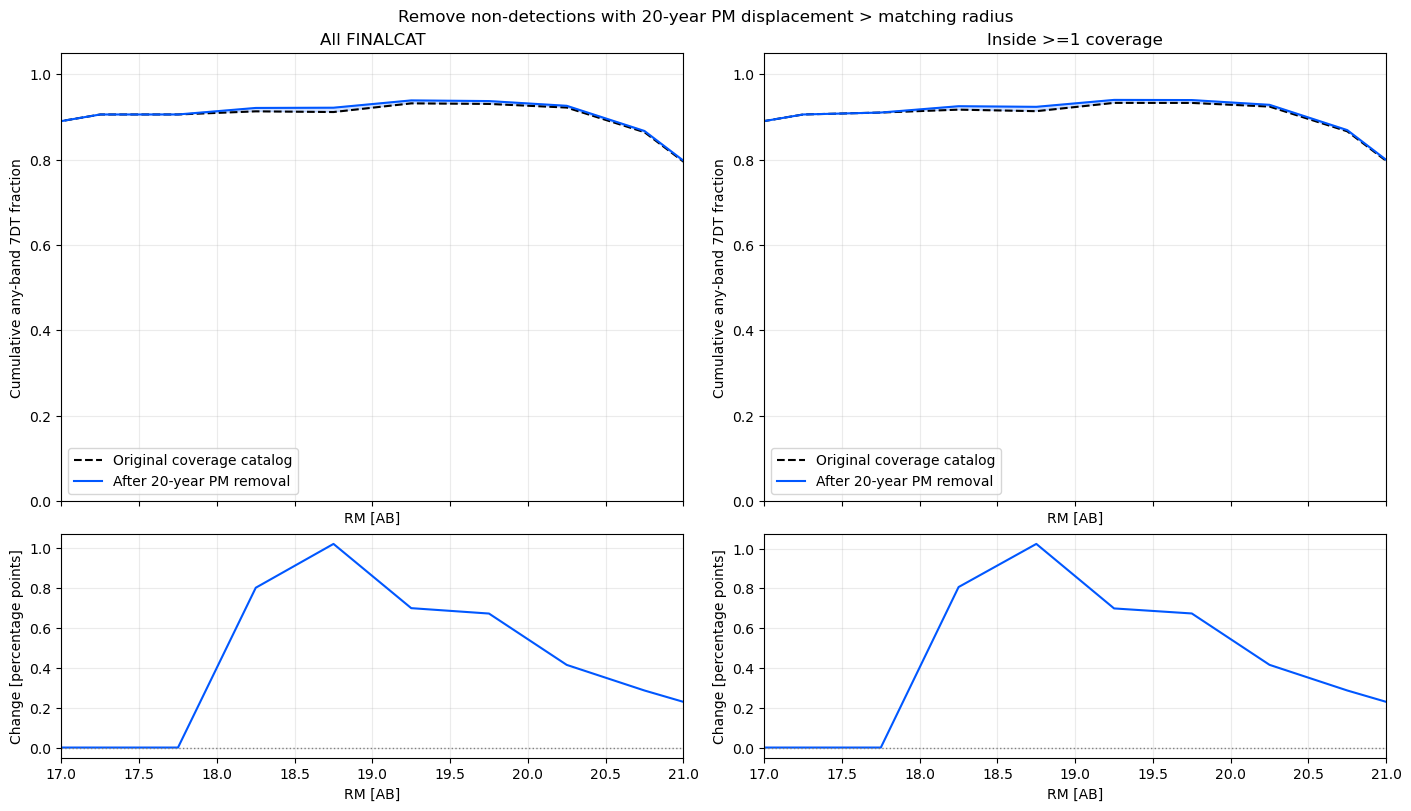

In [5]:
# Recompute fractions from this test's original coverage table and PM-only cut.
pm_rm = np.asarray(np.ma.asarray(PM_ORIGINAL['RM'], dtype=float).filled(np.nan))
pm_valid_rm = np.isfinite(pm_rm) & (pm_rm > 0) & (pm_rm < 50)
if 'CUM_THRESHOLDS' in globals():
    PM_THRESHOLDS = np.asarray(CUM_THRESHOLDS).copy()
else:
    pm_values = pm_rm[pm_valid_rm]
    PM_THRESHOLDS = np.arange(np.floor(pm_values.min()*2)/2,
                             np.ceil(pm_values.max()*2)/2+.5, .5)
PM_BIN_CENTERS = (PM_THRESHOLDS[:-1]+PM_THRESHOLDS[1:])/2


def pm_cumulative_counts(selection):
    """Count RM <= threshold from the original PM-only experiment population."""
    return np.searchsorted(np.sort(pm_rm[selection & pm_valid_rm]), PM_THRESHOLDS, side='right')


PM_FRACTION_CURVES = {}
pm_summary_rows = []
for population, population_mask in (
        ('All FINALCAT', np.ones(len(PM_ORIGINAL), dtype=bool)),
        ('Inside >=1 coverage', pm_in_coverage)):
    before_n = pm_cumulative_counts(population_mask)
    after_n = pm_cumulative_counts(population_mask & ~PM_REMOVE)
    detected_n = pm_cumulative_counts(population_mask & pm_detected)
    before = np.divide(detected_n, before_n, out=np.full(len(before_n), np.nan), where=before_n>0)
    after = np.divide(detected_n, after_n, out=np.full(len(after_n), np.nan), where=after_n>0)
    PM_FRACTION_CURVES[population] = (before, after)
    for limit in (18.,19.,20.,21.,np.inf):
        selected = population_mask & pm_valid_rm & (pm_rm < limit)
        n_before = int(selected.sum()); n_removed = int((selected & PM_REMOVE).sum())
        n_after = n_before-n_removed; n_detected = int((selected & pm_detected).sum())
        f_before = n_detected/n_before if n_before else np.nan
        f_after = n_detected/n_after if n_after else np.nan
        pm_summary_rows.append((population,limit,n_before,n_removed,n_after,n_detected,
                                f_before,f_after,100*(f_after-f_before)))
PM_FRACTION_CHANGE = Table(rows=pm_summary_rows,names=[
    'population','RM_upper_exclusive','N_before','N_removed','N_after','N_detected',
    'fraction_before','fraction_after','change_percentage_points'])
for name in ('fraction_before','fraction_after','change_percentage_points'):
    PM_FRACTION_CHANGE[name].format = '.6f'
print('PM-only fraction change; inf includes all valid RM (0 < RM < 50):')
print('\n'.join(PM_FRACTION_CHANGE.pformat(max_lines=-1,max_width=-1)))
fig, axes = plt.subplots(2,2,figsize=(14,8),layout='constrained', sharex='col',
                         gridspec_kw={'height_ratios': [2, 1]})
for col,(population,(before,after)) in enumerate(PM_FRACTION_CURVES.items()):
    ax = axes[0, col]
    ax.plot(PM_BIN_CENTERS,before[1:],color='black',ls='--',label='Original coverage catalog')
    ax.plot(PM_BIN_CENTERS,after[1:],color='#0057FF',label='After 20-year PM removal')
    ax.fill_between(PM_BIN_CENTERS,before[1:],after[1:],color='#0057FF',alpha=.18)
    ax.set(xlim=(17,21),ylim=(0,1.05),xlabel='RM [AB]',
           ylabel='Cumulative any-band 7DT fraction',title=population)
    ax.set_xticks(np.arange(17,21.1,.5));ax.grid(alpha=.25);ax.legend(loc='lower left')
    delta_ax = axes[1, col]
    delta_ax.plot(PM_BIN_CENTERS, 100*(after[1:]-before[1:]), color='#0057FF')
    delta_ax.axhline(0, color='gray', ls=':', lw=1)
    delta_ax.set(xlim=(17,21), xlabel='RM [AB]', ylabel='Change [percentage points]')
    delta_ax.grid(alpha=.25)
fig.suptitle('Remove non-detections with 20-year PM displacement > matching radius')
plt.show()
plt.close(fig)


## fraction change test : remove binary or proper motion sources

Start from the **original coverage catalog** and remove the **union of the two exclusion sets**: a non-detection with another **7DT-detected** FINALCAT row at separation **< 1.843 arcsec**, **or** a non-detection passing the independent Gaia **20-year** proper-motion displacement cut. This is the union of removed rows, not the union of the retained test catalogs. Count overlapping exclusions once. Align both tests by unique `finalcat_idx`, not catalog ID strings or assumed row order.

`UNION_TEST_CATALOG`, `UNION_REMOVED_CATALOG`, `UNION_EXCLUSION_COUNTS`, and `UNION_FRACTION_CHANGE` are in-memory products only. Retain all detected sources and the existing valid-RM selection. Compare original, binary-only, PM-only, and union fractions using both the full FINALCAT denominator and the in-coverage denominator. The numerator stays unchanged; each test recomputes its own denominator. Summary limits are strict RM < limit; curves retain the preceding cumulative-threshold/bin-center convention. Run the preceding binary and PM selection cells first. Export no catalog or figure files.


In [6]:
# Combine independent exclusion sets by the stable reference-row key.
# The PM sample must still be the fixed-20-year experiment requested above.
assert PM_BASELINE_YEARS == 20.0
union_reference_idx = np.asarray(BINARY_COVERAGE['finalcat_idx'], dtype=int)
union_pm_idx = np.asarray(PM_ORIGINAL['finalcat_idx'], dtype=int)
assert len(np.unique(union_reference_idx)) == len(union_reference_idx)
assert len(np.unique(union_pm_idx)) == len(union_pm_idx)
assert np.array_equal(np.sort(union_reference_idx), np.sort(union_pm_idx))
# Align the PM table and flags explicitly; source IDs can repeat and row order
# need not match if either preceding experiment is reordered in a later edit.
union_pm_order = np.argsort(union_pm_idx)
union_pm_positions = union_pm_order[np.searchsorted(union_pm_idx[union_pm_order], union_reference_idx)]
assert np.array_equal(union_pm_idx[union_pm_positions], union_reference_idx)
union_binary_remove = np.asarray(BINARY_REMOVE, dtype=bool).copy()
union_pm_remove = np.asarray(PM_REMOVE, dtype=bool)[union_pm_positions]
union_detected = np.asarray(BINARY_COVERAGE['has_7dt_any'], dtype=bool)
assert np.array_equal(union_detected,
                      np.asarray(PM_ORIGINAL['has_7dt_any'], dtype=bool)[union_pm_positions])
union_rm = np.asarray(np.ma.asarray(BINARY_COVERAGE['RM'], dtype=float).filled(np.nan))
np.testing.assert_allclose(union_rm, pm_rm[union_pm_positions], equal_nan=True)
UNION_REMOVE = union_binary_remove | union_pm_remove
union_overlap = union_binary_remove & union_pm_remove
assert not np.any(UNION_REMOVE & union_detected)
assert UNION_REMOVE.sum() == union_binary_remove.sum()+union_pm_remove.sum()-union_overlap.sum()
# Reuse diagnostic annotations without altering either independent test catalog.
UNION_ANNOTATED = BINARY_ANNOTATED.copy()
UNION_ANNOTATED['binary_remove'] = union_binary_remove
UNION_ANNOTATED['pm_remove'] = union_pm_remove
UNION_ANNOTATED['binary_or_pm_remove'] = UNION_REMOVE
for name in ('pm_gaia_source_id', 'pm_total_mas_yr', 'pm_displacement_20yr_arcsec'):
    UNION_ANNOTATED[name] = PM_ANNOTATED[name][union_pm_positions]
UNION_TEST_CATALOG = UNION_ANNOTATED[~UNION_REMOVE].copy()
UNION_REMOVED_CATALOG = UNION_ANNOTATED[UNION_REMOVE].copy()
assert len(UNION_TEST_CATALOG)+len(UNION_REMOVED_CATALOG) == len(BINARY_COVERAGE)
union_valid_rm = np.isfinite(union_rm) & (union_rm > 0) & (union_rm < 50)
union_in_coverage = np.asarray(BINARY_COVERAGE['n_COSMOS_coverage'], dtype=int)>0
union_count_rows = []
for population, mask in (
        ('All catalog rows', np.ones(len(union_rm), dtype=bool)),
        ('All valid RM', union_valid_rm),
        ('RM < 21', union_valid_rm & (union_rm < 21))):
    union_count_rows.append((population, int((mask & union_binary_remove).sum()),
        int((mask & union_pm_remove).sum()), int((mask & union_overlap).sum()),
        int((mask & UNION_REMOVE).sum()), int((mask & ~UNION_REMOVE).sum())))
UNION_EXCLUSION_COUNTS = Table(rows=union_count_rows, names=[
    'population', 'N_binary', 'N_PM', 'N_overlap', 'N_union_removed', 'N_remaining'])
print('Union = binary exclusions OR PM exclusions; overlapping rows removed once:')
print('\n'.join(UNION_EXCLUSION_COUNTS.pformat(max_lines=-1, max_width=-1)))

# Compare all three experiments against the same original numerator.
UNION_THRESHOLDS = np.asarray(PM_THRESHOLDS).copy()
UNION_BIN_CENTERS = (UNION_THRESHOLDS[:-1]+UNION_THRESHOLDS[1:])/2
UNION_SELECTIONS = {
    'Original': np.zeros(len(union_rm), dtype=bool),
    'Binary only': union_binary_remove,
    'PM only (20 yr)': union_pm_remove,
    'Binary OR PM': UNION_REMOVE,
}


def union_cumulative_counts(selection):
    """Count unique reference rows at each original cumulative RM threshold."""
    return np.searchsorted(np.sort(union_rm[selection & union_valid_rm]),
                           UNION_THRESHOLDS, side='right')


UNION_FRACTION_CURVES = {}
union_summary_rows = []
for population, population_mask in (
        ('All FINALCAT', np.ones(len(union_rm), dtype=bool)),
        ('Inside >=1 coverage', union_in_coverage)):
    detected_n = union_cumulative_counts(population_mask & union_detected)
    curves = {}
    for experiment, removal in UNION_SELECTIONS.items():
        denominator = union_cumulative_counts(population_mask & ~removal)
        curves[experiment] = np.divide(detected_n, denominator,
            out=np.full(len(denominator), np.nan), where=denominator>0)
    UNION_FRACTION_CURVES[population] = curves
    for limit in (18., 19., 20., 21., np.inf):
        selected = population_mask & union_valid_rm & (union_rm < limit)
        n_before = int(selected.sum()); n_detected = int((selected & union_detected).sum())
        f_before = n_detected/n_before if n_before else np.nan
        fractions = []
        for removal in (union_binary_remove, union_pm_remove, UNION_REMOVE):
            denominator = int((selected & ~removal).sum())
            fractions.append(n_detected/denominator if denominator else np.nan)
        union_summary_rows.append((population, limit, n_before,
            int((selected & union_binary_remove).sum()), int((selected & union_pm_remove).sum()),
            int((selected & union_overlap).sum()), int((selected & UNION_REMOVE).sum()),
            int((selected & ~UNION_REMOVE).sum()), n_detected, f_before, *fractions,
            100*(fractions[-1]-f_before)))
UNION_FRACTION_CHANGE = Table(rows=union_summary_rows, names=[
    'population', 'RM_upper_exclusive', 'N_before', 'N_binary', 'N_PM', 'N_overlap',
    'N_union_removed', 'N_after_union', 'N_detected', 'fraction_original',
    'fraction_binary', 'fraction_PM', 'fraction_union', 'union_change_percentage_points'])
for name in UNION_FRACTION_CHANGE.colnames:
    if name.startswith('fraction_') or name.endswith('percentage_points'):
        UNION_FRACTION_CHANGE[name].format = '.6f'
print('Fraction comparison; inf includes all valid RM values (0 < RM < 50):')
print('\n'.join(UNION_FRACTION_CHANGE.pformat(max_lines=-1, max_width=-1)))


Union = binary exclusions OR PM exclusions; overlapping rows removed once:
   population    N_binary N_PM N_overlap N_union_removed N_remaining
---------------- -------- ---- --------- --------------- -----------
All catalog rows      584   42         0             626      125654
    All valid RM      383   25         0             408      123273
         RM < 21      183   23         0             206        6785
Fraction comparison; inf includes all valid RM values (0 < RM < 50):
     population     RM_upper_exclusive N_before N_binary N_PM N_overlap N_union_removed N_after_union N_detected fraction_original fraction_binary fraction_PM fraction_union union_change_percentage_points
------------------- ------------------ -------- -------- ---- --------- --------------- ------------- ---------- ----------------- --------------- ----------- -------------- ------------------------------
       All FINALCAT               18.0      202       13    0         0              13           189

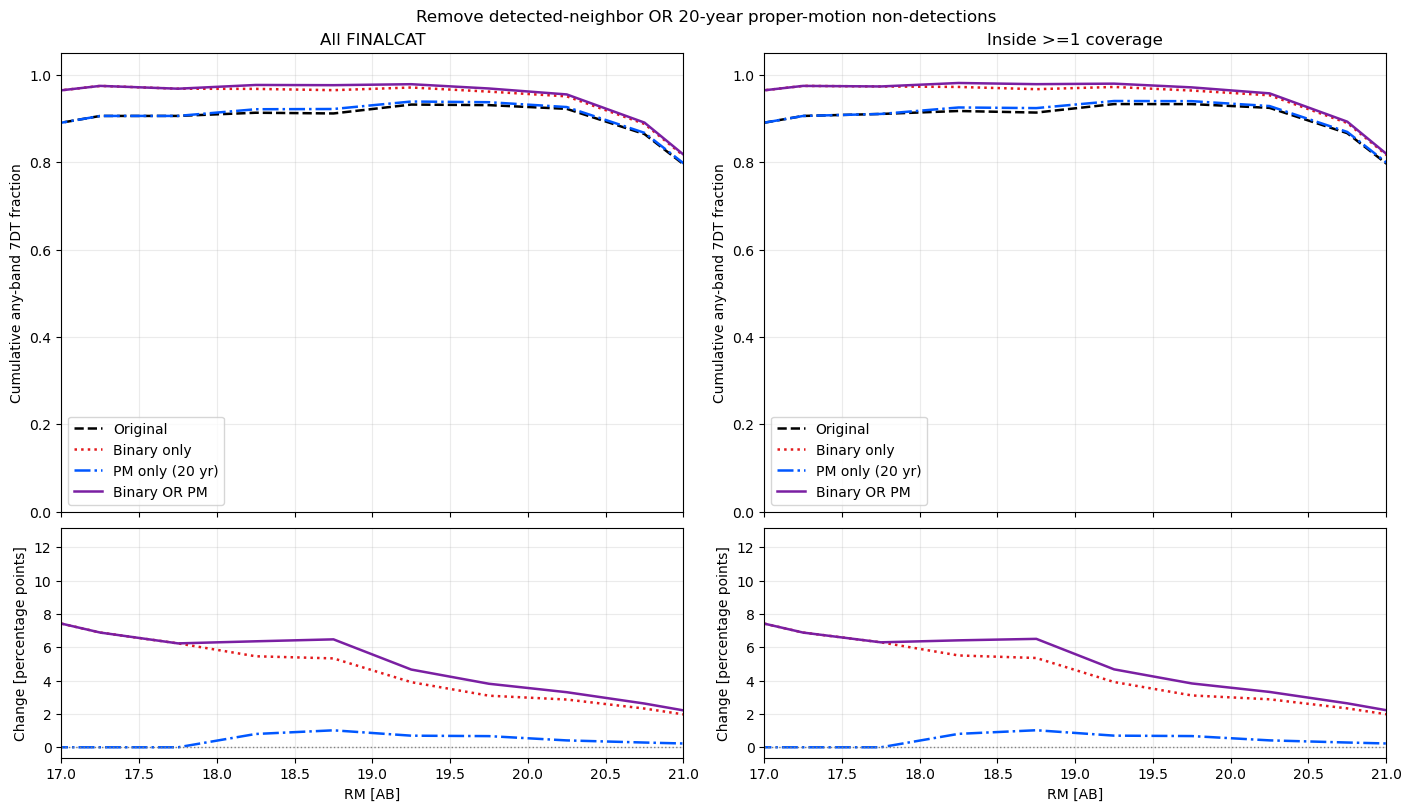

In [7]:
# Display fractions and changes, including both independent cuts for context.
union_styles = {
    'Original': ('black', '--'),
    'Binary only': ('#E31A1C', ':'),
    'PM only (20 yr)': ('#0057FF', '-.'),
    'Binary OR PM': ('#7A1FA2', '-'),
}
fig, axes = plt.subplots(2, 2, figsize=(14, 8), layout='constrained',
                         sharex='col', gridspec_kw={'height_ratios': [2, 1]})
for col, (population, curves) in enumerate(UNION_FRACTION_CURVES.items()):
    ax, delta_ax = axes[:, col]
    for experiment, (color, linestyle) in union_styles.items():
        values = curves[experiment]
        ax.plot(UNION_BIN_CENTERS, values[1:], color=color, ls=linestyle,
                lw=1.8, label=experiment)
        if experiment != 'Original':
            delta_ax.plot(UNION_BIN_CENTERS, 100*(values[1:]-curves['Original'][1:]),
                          color=color, ls=linestyle, lw=1.8)
    ax.set(xlim=(17, 21), ylim=(0, 1.05), ylabel='Cumulative any-band 7DT fraction',
           title=population)
    ax.legend(loc='lower left', fontsize=10)
    delta_ax.axhline(0, color='gray', ls=':', lw=1)
    delta_ax.set(xlim=(17, 21), xlabel='RM [AB]', ylabel='Change [percentage points]')
    for panel in (ax, delta_ax):
        panel.set_xticks(np.arange(17, 21.1, .5))
        panel.grid(alpha=.25)
fig.suptitle('Remove detected-neighbor OR 20-year proper-motion non-detections')
plt.show()
plt.close(fig)


## Unfinished task: apply the current criteria to the existing catalog

Apply the current detected-neighbor and 20-year proper-motion criteria to the existing catalog and evaluate the resulting sample consistently.

The current tests may be perceived as artificial measures to increase the detection fraction because they selectively remove non-detections from the denominator. The resulting increase should be interpreted as a sensitivity test, not as an improvement in the underlying detection performance.
